# RACF-Net: development and experimental engineering assessment

In [1]:
from pathlib import Path
import ast, copy, gc, hashlib, itertools, json, platform, re, threading, time, warnings
import numpy as np
import pandas as pd
import yaml, joblib, psutil
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeClassifier, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from catboost import CatBoostClassifier
from scipy.stats import norm
from threadpoolctl import threadpool_limits
from aeon.transformations.collection.convolution_based import HydraTransformer, MultiRocket
import tabm
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, Image

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / "dataset").is_dir() and (path / "notebooks").is_dir())
OUTPUT_ROOT = REPO_ROOT / "artifacts"  # generated tables, models, predictions and figures
(OUTPUT_ROOT / "Configs").mkdir(parents=True, exist_ok=True)
SHARED_DATASET_ROOT = REPO_ROOT / "dataset"
for folder in ["Processed", "Interim", "Features", "Splits"]:
    (SHARED_DATASET_ROOT / folder).mkdir(parents=True, exist_ok=True)
RUN_ID = "racf_20261012"
REFERENCE_RUN = "racf_20261011"
TABLES = OUTPUT_ROOT / "Tables" / RUN_ID
MODEL_ROOT = OUTPUT_ROOT / "Models" / RUN_ID / "proposed"
PRED_ROOT = OUTPUT_ROOT / "Predictions" / RUN_ID / "proposed"
SPLITS_ROOT = SHARED_DATASET_ROOT / "Splits"
FEATURES_ROOT = SHARED_DATASET_ROOT / "Features"
PNG = OUTPUT_ROOT / "Figures/PNG/publication_20261012"
PDF = OUTPUT_ROOT / "Figures/PDF/publication_20261012"
FREEZE_PATH = OUTPUT_ROOT / "Manifests" / RUN_ID / "confirmation_freeze.json"
CONFIRMATION_MARKER = OUTPUT_ROOT / "Manifests" / f"{RUN_ID}_confirmation_started.json"
REPLAY_EXISTING = True
SEEDS = [42, 137, 2026]
N_JOBS = 4
thread_limiter = threadpool_limits(limits=N_JOBS)
torch.set_num_threads(N_JOBS)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [ ]:
# Naming compatibility: historical identifiers are used only for frozen artifact verification.
import sys, zipfile
RACF_NAMING_ROOT = OUTPUT_ROOT/"Manifests/racf_naming_cleanup_20261014"
RACF_NAMING_MANIFEST = RACF_NAMING_ROOT/"migration.json"
assert hashlib.sha256(RACF_NAMING_MANIFEST.read_bytes()).hexdigest() == "5b59b1e0ceab3dfb901ab257c5da7a7c155e771a90c3648f0fb0cdad2aa28c56"
RACF_NAMING = json.loads(RACF_NAMING_MANIFEST.read_text())

def racf_serialization_identity(cls):
    """Keep established pickle identities while exposing a version-neutral source name."""
    serialized_name = RACF_NAMING["serialization_names"].get(cls.__name__)
    if serialized_name is not None:
        setattr(sys.modules[cls.__module__], serialized_name, cls)
        cls.__name__ = serialized_name
        cls.__qualname__ = serialized_name
    return cls

def racf_compatibility_notebook(path):
    """Verify renamed source, then supply its bound reference for historical fingerprints only."""
    path = Path(path).resolve()
    record = RACF_NAMING["notebooks"][path.name]
    assert path.parent == (REPO_ROOT / "notebooks").resolve()
    current = json.loads(path.read_text())
    scientific_cells = [cell for cell in current["cells"] if cell["cell_type"]=="code" and cell.get("id")!="racf-naming-compatibility"]
    observed = {cell["id"]:hashlib.sha256(ast.dump(ast.parse("".join(cell["source"])),include_attributes=False).encode()).hexdigest() for cell in scientific_cells}
    assert observed == record["renamed_code_ast_sha256"], "Source changed beyond the verified naming migration."
    archive = OUTPUT_ROOT/RACF_NAMING["archive"]
    assert hashlib.sha256(archive.read_bytes()).hexdigest()==RACF_NAMING["archive_sha256"]
    with zipfile.ZipFile(archive) as bundle:
        reference = bundle.read(path.name)
    assert hashlib.sha256(reference).hexdigest()==record["original_notebook_sha256"]
    return json.loads(reference)

display(Markdown("**Naming compatibility verified.** RACF-Net and its working function names use no version labels. Historical serialization identifiers, schemas and artifact paths are retained solely to load unchanged checkpoints and verify their provenance."))


In [2]:
def require_unfrozen_development():
    """Prevent refitting or new prediction generation for this frozen run."""
    if REPLAY_EXISTING or FREEZE_PATH.exists() or CONFIRMATION_MARKER.exists():
        raise RuntimeError("This run is frozen. Training requires a separately registered development run.")

def register_result(path):
    require_unfrozen_development()
    raise RuntimeError("Use the archived persistence workflow for a separately registered run.")

protocol = yaml.safe_load((OUTPUT_ROOT / "Configs/experiment.yaml").read_text())
assert not protocol["test_opened_for_model_selection"]
assert REPLAY_EXISTING and FREEZE_PATH.is_file()
freeze = json.loads(FREEZE_PATH.read_text())
artifact_catalog = json.loads((OUTPUT_ROOT / "Artifacts/Runs" / RUN_ID /
    "nb05_replay_audit.json").read_text())["replay_artifact_catalog"]
verified_artifacts = set()

def verified_path(path):
    path = Path(path)
    relative = str(path.relative_to(OUTPUT_ROOT))
    if not path.is_file():
        raise FileNotFoundError(f"Required frozen artifact is missing: {relative}; refitting is disabled.")
    expected = artifact_catalog[relative]["sha256"]
    if relative not in verified_artifacts:
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, relative
        verified_artifacts.add(relative)
    return path

for relative, expected in freeze["artifact_sha256"].items():
    assert hashlib.sha256((OUTPUT_ROOT / relative).read_bytes()).hexdigest() == expected, relative
assert hashlib.sha256((SHARED_DATASET_ROOT / "External/NRC2026/source_manifest.json").read_bytes()).hexdigest() == freeze["source_manifest_sha256"]

RESULT_TABLES = {}
def retain_table(frame, name, caption):
    """Keep a computed result in memory; never overwrite scientific artifacts."""
    assert not frame.isna().any().any(), name
    RESULT_TABLES[name] = frame.copy()

def display_table(frame):
    assert not frame.isna().any().any()
    display(frame.style.format(precision=4).hide(axis="index"))

def saved_table(name):
    return pd.read_csv(verified_path(TABLES / f"{name}.csv"))

In [3]:
FEATURES_ROOT = SHARED_DATASET_ROOT / "Features"
SPLITS_ROOT = SHARED_DATASET_ROOT / "Splits"
features = pd.read_parquet(FEATURES_ROOT / "features_raw.parquet")
metadata = pd.read_parquet(FEATURES_ROOT / "observation_metadata.parquet")
schema = json.loads((FEATURES_ROOT / "feature_schema.json").read_text())
assert features.columns.tolist() == schema["feature_names"]
manifest = json.loads((OUTPUT_ROOT / "Manifests/feature_manifest.json").read_text())
for relative, expected in manifest["files"].items():
    assert hashlib.sha256((OUTPUT_ROOT / relative).read_bytes()).hexdigest() == expected
assert hashlib.sha256("\n".join(metadata.observation_id).encode()).hexdigest() == manifest["observation_ids_sha256"]
splits = {name:{role:np.load(SPLITS_ROOT / f"{name}_{role}.npy") for role in ["train","evaluation"]}
          for name in ["forward_2020","forward_2021","forward_2022","development","site_transfer"]}
assert len(features) == len(metadata) and len(features.columns) == 51
assert metadata.iloc[splits["development"]["train"]].date.max().year == 2022
assert metadata.iloc[splits["development"]["evaluation"]].date.max().year == 2023
transfer_sites = set(metadata.iloc[splits["site_transfer"]["evaluation"]].plant_id)
# The full predeclared assignment also excludes held sites absent from 2023 evaluation.
site_assignment = pd.read_csv(SPLITS_ROOT / "site_holdout_assignment.csv")
sequences = np.load(FEATURES_ROOT / "sequences_raw.npy",mmap_mode="r")

# Inspect the predeclared site flag by its fixed schema, without consulting outcomes.
assert site_assignment.columns.tolist() == ["plant_id", "held_out"]
held_sites = set(site_assignment.loc[site_assignment.held_out, "plant_id"])
assert transfer_sites <= held_sites
forward_names = ["forward_2020", "forward_2021", "forward_2022"]
search_splits = {"temporal":{name:splits[name] for name in forward_names},
    "transfer":{name:{role:idx[~metadata.iloc[idx].plant_id.isin(held_sites).to_numpy()]
                      for role,idx in splits[name].items()} for name in forward_names}}
for scope, partitions in search_splits.items():
    for fold, part in partitions.items():
        train_meta, eval_meta = metadata.iloc[part["train"]], metadata.iloc[part["evaluation"]]
        assert (eval_meta.date.min() - train_meta.date.max()).days > 30
        assert set(train_meta.episode_id).isdisjoint(set(eval_meta.episode_id))
        if scope == "transfer":
            assert set(train_meta.plant_id).isdisjoint(held_sites)
            assert set(eval_meta.plant_id).isdisjoint(held_sites)

## Registered development and immutable parent

In [4]:
EXECUTION_MODE = "focused"
# This is the only configuration authority for the registered development run.
RACF_RUN_ID = "racf_20261013_102931"
RACF_SCHEMA_VERSION = "racf-dual-observation-2"
RACF_CONFIG = {
    "run_id": RACF_RUN_ID, "parent_run": "racf_20261012", "schema_version": RACF_SCHEMA_VERSION,
    "task": "retrospective previous-day SCRAM recognition",
    "train_years": [2019, 2020, 2021, 2022], "development_year": 2023,
    "calibration_year": 2024, "disclosed_historical_years": [2025, 2026],
    "screening_fold": "forward_2022", "screening_seed": 42,
    "model_seeds": [42, 137, 2026], "evaluation_noise_seeds": [2026, 137, 42],
    "training_stream_base": 910000, "embargo_days": 30,
    "scenarios": ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"],
    "challenge_scenarios": ["power_block_2", "power_block_5", "power_block_10", "power_tail_1", "power_tail_3"],
    "block_period_days": 60,
    "tail_anchor_rule": "Calendar month ends within each evaluation period; use only windows ending at each registered anchor and report this subset separately.",
    "scenario_weights": [1/6]*6, "primary": "mean per-seed AP over six equally weighted scenarios",
    "practical_mean_ap_gain": 0.02, "maximum_clean_ap_loss": 0.01,
    "maximum_f1_loss": 0.03, "maximum_event_recall_loss_count": 1,
    "tie_ap_tolerance": 0.005, "alarm_budget_per_1000": 1.0,
    "finalists_per_family": 2,
    "screening_rule": "Retain the two highest mean-AP candidates per family; clean AP breaks ties within0.005, then neural parameter count, then measured fit time. Engineering admissibility is assessed against matched controls after the full development comparison, not assumed at screening.", "maximum_trials_per_family": 12,
    "selection": "Development-2023 mean AP; report admissibility versus strongest matched control; ties prefer fewer parameters then measured latency. No new trials after historical reassessment.",
    "inner_validation_days": 90, "inner_patience": 8, "maximum_epochs": 40,
    "epoch_fallback": 8, "minimum_inner_observed_windows": 128,
    "gate_minimum_event_clusters": 40, "gate_minimum_event_sites": 10,
    "gate_fallback_weight": 0.5, "gate_width": 8,
    "gate_epochs": 100, "gate_learning_rate": 0.001, "gate_l2": 0.1, "gate_reliability_penalty": 0.05,
    "bootstrap_replicates": 20000, "familywise_alpha": 0.05,
    "cpu_score_tolerance": 1e-6, "accelerator_score_tolerance": 2e-5,
    "benchmark_batches": [1, 32, 256, 1024], "benchmark_warmups": 10, "benchmark_repeats": 30,
    "future_period": ["2027-01-01", "2029-12-31"], "label_maturity_days": 90,
    "future_rule": "Calendar-fixed period; no outcome acquisition before new freeze; no significance-based stopping or retrospective extension.",
    "novel_independence_claim": False,
    "head_event_separation": "For staged event candidates, fine-tune the encoder only on the earliest 70 percent of training calendar dates; fit the tree head on the later 30 percent after a 30-day gap and episode purge. This deliberate reduction is reported.",
    "head_training_views": "Clean plus one corrupted view per training observation, assigned uniformly among five independently generated scenario streams; clean mass 0.75, remaining mass normalized equally across scenarios. No event oversampling.",
    "training_weight_rule": "Inverse square-root site and episode counts, each factor clipped to [0.25,4] then normalized; same rule for all families.",

}
RACF_BASE = {
    "window": 30, "width": 16, "kernel": 3, "dilations": [1, 2, 4, 8],
    "dropout": 0.1, "context_width": 32, "pooling": "last_and_masked_mean",
    "messages": 24, "rounds": 1, "peer_count": 3, "ridge_alpha": 10.0,
    "verifier": False, "verifier_width": 4, "repair": True, "peer_exchange": True,
    "dynamic": True, "agents_enabled": True, "dual_view": True, "original_masks": True,
    "action_state": True, "reliability": True, "representation_augmentation": False,
    "expert_augmentation": True, "event_finetune": False, "event_weight": 0.1, "event_epochs": 5,
    "learning_rate": 0.001, "weight_decay": 0.001, "batch_size": 512,
    "clean_mass": 0.75, "positive_weight": 1.0, "head": "CatBoost",
    "trees": 800, "depth": 4, "head_learning_rate": 0.04, "l2": 10.0,
    "leaves": 15, "min_child_samples": 50,
}
RACF_CANDIDATES = []
for candidate_id, change in enumerate([
    {}, {"head":"LightGBM", "head_learning_rate":0.03},
    {"messages":36}, {"messages":36,"head":"LightGBM","head_learning_rate":0.03},
    {"messages":36,"representation_augmentation":True},
    {"messages":36,"representation_augmentation":True,"head":"LightGBM","head_learning_rate":0.03},
    {"messages":36,"representation_augmentation":True,"verifier":True},
    {"messages":36,"representation_augmentation":True,"verifier":True,"head":"LightGBM","head_learning_rate":0.03},
    {"messages":36,"representation_augmentation":True,"event_finetune":True},
    {"messages":36,"representation_augmentation":True,"event_finetune":True,"head":"LightGBM","head_learning_rate":0.03},
], 1):
    RACF_CANDIDATES.append({**RACF_BASE, **change, "candidate_id": candidate_id, "family":"RACF-Net"})
RACF_CONDITIONAL_CANDIDATES = [
    {"candidate_id":11,"family":"RACF-Net","gate":"fixed","condition":"A/B mean AP improves but clean AP loss exceeds 0.01", "weight":0.5},
    {"candidate_id":12,"family":"RACF-Net","gate":"quality","condition":"Same as candidate 11; train-only chronological OOF", "width":8},
]
# Every control trial changes an effective parameter; no decorative duplicate trials.
RACF_TREE_CONTROL_CHANGES = [
    {"repair":False,"dual_view":False,"expert_augmentation":False},
    {"repair":False,"dual_view":False}, {},
    {"repair":False}, {"clean_mass":0.5}, {"positive_weight":4.0},
    {"positive_weight":8.0}, {"l2":20.0}, {"trees":1200},
    {"depth":6,"leaves":31}, {"depth":6,"leaves":31,"l2":20.0},
    {"trees":1200,"head_learning_rate":0.02},
]
RACF_TCN_CONTROL_CHANGES = [
    {"repair":False,"dual_view":False,"expert_augmentation":False},
    {"repair":False,"dual_view":False}, {}, {"pooling":"last"},
    {"clean_mass":0.5}, {"positive_weight":4.0}, {"positive_weight":8.0},
    {"weight_decay":0.01}, {"width":32}, {"context_width":16},
    {"dropout":0.2}, {"learning_rate":0.0005},
]
RACF_CONTROL_CANDIDATES = {}
for family in ["CatBoost","LightGBM","TCN"]:
    changes = RACF_TCN_CONTROL_CHANGES if family=="TCN" else RACF_TREE_CONTROL_CHANGES
    RACF_CONTROL_CANDIDATES[family] = [
        {**RACF_BASE,"family":family,"head":family if family!="TCN" else "neural",
         "head_learning_rate":0.03 if family=="LightGBM" else 0.04,
         "peer_exchange":False,**change,"candidate_id":i}
        for i,change in enumerate(changes,1)]
RACF_ABLATIONS = {
    "No temporal repair": {"repair":False},
    "No peer exchange": {"peer_exchange":False},
    "No numerical agents": {"agents_enabled":False},
    "Compact messages": {"messages":24},
    "No learned verifier": {"verifier":False},
    "Clean representation training": {"representation_augmentation":False},
    "No event fine-tuning": {"event_finetune":False},
    "Single original view": {"dual_view":False},
    "Last-state pooling": {"pooling":"last"},
    "No added provenance channels": {"original_masks":False},
    "No exported action state": {"action_state":False},
    "No exported reliability state": {"reliability":False},
    "Fixed agent population": {"dynamic":False},
}
RACF_CONFIG.update(ablations=RACF_ABLATIONS, base=RACF_BASE, candidates=RACF_CANDIDATES,
    conditional_candidates=RACF_CONDITIONAL_CANDIDATES, controls=RACF_CONTROL_CANDIDATES,
    simple_controls=["Raw CatBoost + robust LightGBM fixed mixture", "Non-agent quality gate"])
RACF_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / RACF_RUN_ID
RACF_TABLES = OUTPUT_ROOT / "Tables" / RACF_RUN_ID
RACF_MANIFESTS = OUTPUT_ROOT / "Manifests" / RACF_RUN_ID
for folder in [RACF_ROOT, RACF_TABLES, RACF_MANIFESTS]:
    folder.mkdir(parents=True, exist_ok=True)


In [5]:
from datetime import datetime, timezone
import importlib.metadata as package_metadata

def racf_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(2**20), b""):
            digest.update(block)
    return digest.hexdigest()

def racf_write_json(value, path):
    path = Path(path)
    assert RACF_RUN_ID in path.parts, "Writing outside the new run is prohibited"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False))
    return path

def racf_register(path):
    path = Path(path)
    assert RACF_RUN_ID in path.parts
    registry_path = RACF_MANIFESTS / "result_registry.json"
    rows = json.loads(registry_path.read_text()) if registry_path.exists() else []
    source = get_ipython().history_manager.input_hist_raw[-1]
    record = {"artifact":str(path.relative_to(OUTPUT_ROOT)), "sha256":racf_hash(path),
              "created_utc":datetime.now(timezone.utc).isoformat(),
              "cell_source_sha256":hashlib.sha256(source.encode()).hexdigest(),
              "execution_count":get_ipython().execution_count, "run_id":RACF_RUN_ID}
    rows = [r for r in rows if r["artifact"] != record["artifact"]] + [record]
    racf_write_json(rows, registry_path)

def racf_table(frame, name, caption, comparison_context=None):
    """Save original values and emphasize only explicitly comparable metrics."""
    path = RACF_TABLES / (name + ".csv")
    frame.to_csv(path, index=False)
    racf_register(path)
    display(Markdown("**" + caption + "**"))
    emphasis = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for column in ("Model", "model", "Family", "family", "Proposed", "Comparator"):
        if column in frame:
            emphasis.loc[frame[column].eq("RACF-Net"), column] = "font-weight: bold"
    contexts = {
        "development_quality_temporal":{"Period":2023,"Scope":"temporal","Aggregation":"registered six-scenario and clean metrics, three seeds"},
        "development_quality_transfer":{"Period":2023,"Scope":"transfer","Aggregation":"registered six-scenario and clean metrics, three seeds"},
        "development_budget_support":{"Period":2023,"Scope":"temporal","Scenario":"clean","Policy":"budget"},
    }
    context = dict(comparison_context or contexts.get(name, {}))
    comparable = all(key in frame or key in context for key in ("Period", "Scope"))
    comparable &= any(key in frame or key in context for key in ("Scenario", "Aggregation"))
    higher = {"AP","ROC_AUC","Precision","Recall","F1","MCC","Balanced_accuracy","Event_recall","Mean_AP","Clean_AP","Clean_F1"}
    lower = {"Brier","Log_loss","False_alarms_per_1000","Actual_false_alarms_per_1000","FPR"}
    identity = ["Period","Scope","Scenario","Aggregation","Policy","Seed","Model seed","Noise seed","Seed ids","Cohort","Fold"]
    group_columns = [column for column in identity if column in frame]
    if comparable and "Model" in frame and frame.index.is_unique:
        groups = frame.groupby(group_columns,dropna=False,sort=False) if group_columns else [(None,frame)]
        for _,group in groups:
            if group.Model.isna().any() or group.Model.nunique()<2 or group.Model.duplicated().any():
                continue
            for metric in (higher|lower).intersection(frame.columns):
                values = pd.to_numeric(group[metric],errors="coerce")
                observed = values.loc[np.isfinite(values.to_numpy(float))]
                if len(observed)<2:
                    continue
                best = observed.max() if metric in higher else observed.min()
                emphasis.loc[observed.index[observed.eq(best)],metric] = "font-weight: bold"
    display(frame.style.apply(lambda _:emphasis,axis=None).format(
        precision=5,na_rep="Not estimable; see accompanying explanation").hide(axis="index"))


plan_path = RACF_MANIFESTS / "preregistered_protocol.json"
plan_hash = hashlib.sha256(json.dumps(RACF_CONFIG, sort_keys=True).encode()).hexdigest()
if plan_path.exists():
    registration = json.loads(plan_path.read_text())
    assert registration["configuration_sha256"] == plan_hash, "Register a reasoned amendment before new trials"
else:
    registration = {"created_utc":datetime.now(timezone.utc).isoformat(),
        "configuration_sha256":plan_hash, "configuration":RACF_CONFIG,
        "task_sha256":racf_hash(OUTPUT_ROOT/"RACFNet_v2_task.md"),
        "parent_freeze_sha256":racf_hash(FREEZE_PATH),
        "status":"registered_before_first_v2_fit", "historical_outcomes_already_disclosed":True}
    racf_write_json(registration, plan_path)
if EXECUTION_MODE == "comprehensive":
    racf_register(plan_path)
    racf_register(protection_path)
versions = {name:package_metadata.version(name) for name in ["numpy","pandas","scikit-learn","torch","catboost","lightgbm"]}


In [6]:
DISPLAY_NAMES = {
    "RACF-Net": "RACF-Net",
    "Without noise-action communication": "No action/reliability state",
    "RACF-Net without adaptive power tool": "No adaptive power tool",
    "TCN + context + shared repair": "TCN + shared repair",
    "TCN + context + adaptive tools": "TCN + adaptive tools",
    "Logistic Regression + shared repair": "Logistic + shared repair",
    "Logistic Regression + adaptive tools": "Logistic + adaptive tools",
}

def label(name):
    return DISPLAY_NAMES.get(name, name)

def wrap_label(name):
    import textwrap
    return "\n".join(textwrap.wrap(label(name), width=24, break_long_words=False))

def configure_figures():
    font_manager.findfont("Times New Roman", fallback_to_default=False)
    plt.rcParams.update({"font.family":"Times New Roman", "font.size":18,
        "axes.titlesize":20, "axes.labelsize":19, "xtick.labelsize":18,
        "ytick.labelsize":18, "legend.fontsize":18, "figure.titlesize":20,
        "figure.dpi":350, "savefig.dpi":350, "axes.unicode_minus":True,
        "pdf.fonttype":42, "ps.fonttype":42})
    plt.ioff()

def publication_figure(fig, name):
    """Write only publication figures; numerical source artifacts remain immutable."""
    assert name.startswith("nb05_")
    fig.canvas.draw()
    for item in fig.findobj(matplotlib.text.Text):
        if item.get_visible() and item.get_text().strip():
            assert 18 <= item.get_fontsize() <= 20
            font_path=font_manager.findfont(item.get_fontproperties(),fallback_to_default=False)
            assert "Times New Roman" in font_manager.FontProperties(fname=font_path).get_name()
    for folder,extension in [(PNG,"png"),(PDF,"pdf")]:
        folder.mkdir(parents=True,exist_ok=True)
        fig.savefig(folder/f"{name}.{extension}",dpi=350,bbox_inches="tight",pad_inches=.12)
    plt.close(fig)
    display(Image(filename=str(PNG/f"{name}.png"),width=1100))

def plot_comparison_intervals(temporal, transfer):
    assert temporal.Control.is_unique and transfer.Control.is_unique
    controls = temporal.Control.tolist()
    assert set(controls) == set(transfer.Control)
    transfer = transfer.set_index("Control").loc[controls].reset_index()
    fig,axes=plt.subplots(2,1,figsize=(9,13.8),sharey=True)
    for ax,frame,title in zip(axes,[temporal,transfer],["Temporal development","Held-site development"]):
        positions=np.arange(len(frame))
        ax.hlines(positions,frame["Familywise 95% lower"],frame["Familywise 95% upper"],color="#B4B8BD",linewidth=2,label="Familywise 95% interval")
        ax.hlines(positions,frame["95% lower"],frame["95% upper"],color="#26547C",linewidth=4,label="Pointwise 95% interval")
        ax.scatter(frame["Delta mean AP"],positions,s=55,color="#D17A22",zorder=3)
        ax.axvline(0,color=".35",linestyle="--",linewidth=1.2)
        ax.set_title(title);ax.set_xlabel("RACF-Net minus control: mean AP difference")
        ax.set_yticks(np.arange(len(controls)), [wrap_label(x) for x in controls])
        ax.grid(axis="x",alpha=.2)
    axes[0].set_ylim(len(controls)-.5,-.5)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.63,.005),ncol=1,frameon=False)
    fig.subplots_adjust(left=.34,right=.98,top=.96,bottom=.13,hspace=.36)
    return fig

def plot_robustness(availability, noise, title, palette):
    values=availability.merge(noise,on="Model",validate="one_to_one")
    order=["RACF-Net","Without noise-action communication","RACF-Net without adaptive power tool",
        "TCN + context + shared repair","TCN + context + adaptive tools",
        "CatBoost + shared repair","CatBoost + adaptive tools",
        "LightGBM + shared repair","LightGBM + adaptive tools",
        "Logistic Regression + shared repair","Logistic Regression + adaptive tools"]
    values=values.set_index("Model").loc[order]
    columns=["Clean","No weather","MCAR 10%","MCAR 30%","Noise 1 pp","Noise 2 pp"]
    matrix=values[columns].to_numpy(float)
    fig,ax=plt.subplots(figsize=(9,11.5),layout="constrained")
    image=ax.imshow(matrix,aspect="auto",vmin=0,vmax=1,cmap=palette)
    ax.set_yticks(np.arange(len(values)),[wrap_label(x) for x in values.index])
    ax.set_xticks(np.arange(6),["Clean","No\nweather","MCAR\n10%","MCAR\n30%","Noise\n1 pp","Noise\n2 pp"])
    ax.set_title(title+"\nModel seed 42",pad=16)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col,row,f"{matrix[row,col]:.3f}",ha="center",va="center",fontsize=18,
                color="white" if matrix[row,col]>.65 else "black")
    fig.colorbar(image,ax=ax,fraction=.035,pad=.035,label="Average precision")
    return fig

def plot_forward_evidence(frames):
    models=["RACF-Net","Without adaptive observation tool","TCN + shared repair","TCN + adaptive tools"]
    colors=["#26547C","#D17A22","#4F8B62","#8A6BA8"]
    fig,ax=plt.subplots(figsize=(9,9.4))
    offsets=np.linspace(-.3,.3,4)
    for index,(model,color) in enumerate(zip(models,colors)):
        values=[frame.set_index("Model").loc[model,"AP"] for frame in frames]
        bars=ax.barh(np.arange(3)+offsets[index],values,height=.17,color=color,label=("No adaptive tool" if model=="Without adaptive observation tool" else model))
        ax.bar_label(bars,labels=[f"{value:.4f}" for value in values],padding=5,fontsize=18)
    ax.set_yticks(range(3),["2020","2021","2022"]);ax.invert_yaxis()
    ax.set_xlim(0,.91);ax.set_xlabel("Mean AP across six scenarios");ax.set_ylabel("Forward evaluation year")
    ax.set_title("Earlier periods retain both gains and losses",pad=14);ax.grid(axis="x",alpha=.2)
    ax.set_axisbelow(True)
    ax.legend(loc="upper center",bbox_to_anchor=(.50,-.17),ncol=2,frameon=False)
    fig.subplots_adjust(left=.10,right=.99,top=.90,bottom=.24)
    return fig

def plot_inference_resources(frame):
    scenarios=["clean","power_mcar_30","power_noise_2"]
    models=["Dynamic RACF-Net","Fixed population control"]
    fig,axes=plt.subplots(2,1,figsize=(9,11.2))
    for ax,column,title in zip(axes,["Active mean","Median batch seconds"],["Active numerical agents","Inference latency (batch 256)"]):
        for j,(model,color) in enumerate(zip(models,["#26547C","#D17A22"])):
            values=frame.loc[frame.Model.eq(model)].set_index("Scenario").loc[scenarios,column].to_numpy(float)
            bars=ax.bar(np.arange(3)+(j-.5)*.34,values,width=.32,color=color,label=model)
            ax.bar_label(bars,labels=[f"{v:.2f}" if column=="Active mean" else f"{v:.4f}" for v in values],padding=4,fontsize=18)
        ax.set_xticks(range(3),["Clean","MCAR 30%","Noise 2 pp"]);ax.set_title(title,pad=16)
        ax.set_ylabel("Agents per window" if column=="Active mean" else "Seconds per batch")
        ax.set_ylim(0,180 if column=="Active mean" else .102);ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.52,.005),ncol=2,frameon=False)
    fig.subplots_adjust(left=.14,right=.99,top=.94,bottom=.13,hspace=.42)
    return fig

configure_figures()

## Legacy compatibility definitions

In [7]:
class AgentVerifierBank(nn.Module):
    """Vectorized training of separate small neural tools; no shared feature-agent weights."""

    def __init__(self, p, hidden=4):
        super().__init__()
        self.weight1 = nn.Parameter(torch.randn(p, 3, hidden) / np.sqrt(3))
        self.bias1 = nn.Parameter(torch.zeros(p, hidden))
        self.weight2 = nn.Parameter(torch.randn(p, hidden) / np.sqrt(hidden))
        self.bias2 = nn.Parameter(torch.zeros(p))

    def forward(self, neighbors):
        hidden = torch.tanh(torch.einsum('bpi,pih->bph', neighbors, self.weight1) + self.bias1)
        return torch.einsum('bph,ph->bp', hidden, self.weight2) + self.bias2

class NeuralVerificationTool:
    """A local nonlinear tool called only for a recruited verification agent."""

    def __init__(self, weight1, bias1, weight2, bias2):
        self.weight1 = weight1
        self.bias1 = bias1
        self.weight2 = weight2
        self.bias2 = bias2
        self.parameter_count = int(weight1.size + bias1.size + weight2.size + bias2.size)

    def predict(self, values):
        return np.tanh(values @ self.weight1 + self.bias1) @ self.weight2 + self.bias2

In [8]:
class PredictorAgents:
    """Bounded reactive agents; train-only tools and inference-time message state."""

    @staticmethod
    def design(values, neighbors, kind='joint'):
        local = values[:, neighbors]
        if local.shape[1] == 0:
            return np.zeros((len(values), 1))
        if kind == 'linear':
            return local
        if kind == 'quadratic':
            return local ** 2
        return np.concatenate([local, local ** 2], axis=1)

    def fit(self, frame, threshold=2.5, seed=42, train_verifiers=True):
        self.columns = frame.columns.tolist()
        self.p = len(self.columns)
        self.threshold = float(threshold)
        raw = frame.to_numpy(dtype=np.float64, na_value=np.nan)
        observed = np.isfinite(raw)
        self.center = np.array([np.median(raw[observed[:, j], j]) if observed[:, j].any() else 0.0 for j in range(self.p)])
        self.scale = np.array([max(np.std(raw[observed[:, j], j]), 0.0001) if observed[:, j].any() else 1.0 for j in range(self.p)])
        z = np.clip(np.where(observed, (raw - self.center) / self.scale, 0), -12, 12)

        def cross_correlation(left, right):
            a = left - left.mean(0)
            b = right - right.mean(0)
            den = np.sqrt(np.sum(a * a, 0)[:, None] * np.sum(b * b, 0)[None, :])
            return (np.divide(a.T @ b, den, out=np.zeros((self.p, self.p)), where=den > 1e-12), den > 1e-12)
        linear, linear_defined = cross_correlation(z, z)
        curved, curved_defined = cross_correlation(z * z, z)
        linear = np.abs(linear)
        curved = np.abs(curved)
        np.fill_diagonal(linear_defined, False)
        np.fill_diagonal(curved_defined, False)
        np.fill_diagonal(linear, -np.inf)
        np.fill_diagonal(curved, -np.inf)
        self.neighbors = []
        self.tools = []
        self.repair_tools = []
        self.check_tools = []
        self.residual_scale = []
        edge_rows = []
        coverage = []
        for j in range(self.p):
            available = np.flatnonzero(linear_defined[:, j])
            strong = available[np.argsort(-linear[available, j], kind='stable')[:2]]
            candidates = np.flatnonzero(curved_defined[:, j] & ~np.isin(np.arange(self.p), strong))
            extra = candidates[np.argsort(-curved[candidates, j], kind='stable')[:1]]
            neighbors = np.r_[strong, extra].astype(int)
            design = self.design(z, neighbors)
            valid = observed[:, j]
            tool = Ridge(alpha=10.0).fit(design[valid], z[valid, j]) if valid.any() else Ridge(alpha=10.0).fit(design, np.zeros(len(z)))
            residual = z[valid, j] - tool.predict(design[valid]) if valid.any() else np.zeros(1)
            self.neighbors.append(neighbors)
            self.tools.append(tool)
            fit_rows = valid if valid.any() else np.ones(len(z), dtype=bool)
            local_target = z[fit_rows, j] if valid.any() else np.zeros(len(z))
            self.repair_tools.append(Ridge(alpha=10.0).fit(self.design(z[fit_rows], neighbors, 'linear'), local_target))
            self.check_tools.append(None if len(neighbors) else Ridge(alpha=10.0).fit(self.design(z[fit_rows], neighbors, 'linear'), local_target))
            self.residual_scale.append(max(float(np.sqrt(np.mean(residual ** 2))), 0.1))
            coverage.append({'Agent': self.columns[j], 'Observed training values': int(valid.sum()), 'Peers': len(neighbors), 'Tool status': 'Learned peer model' if len(neighbors) else 'Intercept-only reference; no defined peer association'})
            for k, neighbor in enumerate(neighbors):
                edge_rows.append({'Receiving agent': self.columns[j], 'Sending agent': self.columns[neighbor], 'Tool term': 'linear' if k < len(strong) else 'quadratic candidate', 'Training association': float(linear[neighbor, j] if k < len(strong) else curved[neighbor, j])})
        self.residual_scale = np.asarray(self.residual_scale)
        self.edges = pd.DataFrame(edge_rows)
        self.coverage = pd.DataFrame(coverage)
        if train_verifiers:
            self.fit_neural_verifiers(z, observed, seed)
        else:
            self.check_tools = [None] * self.p
        self.groups = [np.array([self.columns.index(c) for c in columns]) for columns in schema['feature_groups'].values()]
        return self

    def fit_neural_verifiers(self, z, observed, seed):
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        neighbors = np.zeros((self.p, 3), dtype=int)
        present = np.zeros((self.p, 3), dtype=np.float32)
        for j, peers in enumerate(self.neighbors):
            neighbors[j, :len(peers)] = peers
            present[j, :len(peers)] = 1
        inputs = (z[:, neighbors] * present[None]).astype(np.float32)
        bank = AgentVerifierBank(self.p).to(DEVICE)
        optimizer = torch.optim.AdamW(bank.parameters(), lr=0.01, weight_decay=0.001)
        self.verifier_learning = []
        for epoch in range(6):
            order = rng.permutation(len(z))
            total = 0.0
            count = 0
            for start in range(0, len(z), 1024):
                rows = order[start:start + 1024]
                xb = torch.from_numpy(inputs[rows]).to(DEVICE)
                target = torch.from_numpy(z[rows].astype(np.float32)).to(DEVICE)
                mask = torch.from_numpy(observed[rows].astype(np.float32)).to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                error = (bank(xb) - target).square() * mask
                loss = error.sum() / mask.sum().clamp(min=1)
                assert torch.isfinite(loss)
                loss.backward()
                nn.utils.clip_grad_norm_(bank.parameters(), 5.0)
                optimizer.step()
                total += float(error.detach().sum().cpu())
                count += int(mask.sum().cpu())
            self.verifier_learning.append({'Epoch': epoch + 1, 'Observed reconstruction MSE': total / max(count, 1)})
        arrays = {name: value.detach().cpu().numpy().copy() for name, value in bank.state_dict().items()}
        for j, peers in enumerate(self.neighbors):
            if len(peers):
                self.check_tools[j] = NeuralVerificationTool(arrays['weight1'][j, :len(peers)], arrays['bias1'][j], arrays['weight2'][j], arrays['bias2'][j])
        with torch.inference_mode():
            reference = bank(torch.from_numpy(inputs[:64]).to(DEVICE)).cpu().numpy()
        errors = [np.max(np.abs(tool.predict(z[:64, peers]) - reference[:, j])) for j, (peers, tool) in enumerate(zip(self.neighbors, self.check_tools)) if len(peers)]
        self.verifier_export_error = float(max(errors, default=0.0))
        assert self.verifier_export_error < 0.0001
        del bank, inputs
        gc.collect()
        if DEVICE.type == 'mps':
            torch.mps.empty_cache()

    def reliability(self, frame):
        raw = frame.to_numpy(dtype=np.float64, na_value=np.nan)
        quality = np.isfinite(raw).astype(np.float64)
        names = self.columns
        power_q = np.clip(frame.power_window_fraction.fillna(0).to_numpy(dtype=float), 0, 1)
        for j in self.groups[0]:
            if names[j] != 'power_window_fraction':
                quality[:, j] *= power_q
        for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
            age = frame[variable + '_age_days'].fillna(365).to_numpy(dtype=float)
            weather_q = np.exp(-np.maximum(age - 3, 0) / 7)
            for column in [variable, variable + '_mean7d']:
                quality[:, names.index(column)] *= weather_q
        return quality

    def transform(self, frame, mode='full', return_trace=False, external_repairs=None):
        assert frame.columns.tolist() == self.columns
        raw = frame.to_numpy(dtype=np.float64, na_value=np.nan)
        observed = np.isfinite(raw)
        z = np.clip(np.where(observed, (raw - self.center) / self.scale, 0), -12, 12)
        quality = self.reliability(frame) if mode != 'no_reliability' else np.ones_like(z)
        belief = z.copy()
        expected = np.zeros_like(z)
        repair_message = np.zeros_like(z)
        check_message = np.zeros_like(z)
        repair_used = np.zeros_like(z, dtype=bool)
        check_used = np.zeros_like(z, dtype=bool)
        for round_index in range(2):
            if mode == 'no_communication':
                expected[:] = 0
                residual = np.clip(z, -12, 12)
            else:
                for j, (neighbors, tool) in enumerate(zip(self.neighbors, self.tools)):
                    expected[:, j] = np.clip(tool.predict(self.design(belief, neighbors)), -12, 12)
                residual = np.where(observed, np.clip((z - expected) / self.residual_scale, -12, 12), 0.0)
            request_repair = quality < 0.5
            if external_repairs is not None:
                request_repair |= external_repairs
            request_check = observed & (quality * np.abs(residual) > self.threshold) | request_repair
            if mode == 'fixed_agents':
                request_repair[:] = True
                request_check[:] = True
            if mode == 'no_communication':
                request_repair[:] = False
                request_check[:] = False
            if mode == 'no_verifier':
                request_check[:] = False
            if mode == 'no_repair':
                request_repair[:] = False
            repair_used |= request_repair
            check_used |= request_check
            repair_message[:] = 0
            check_message[:] = 0
            for j, neighbors in enumerate(self.neighbors):
                repair_rows = np.flatnonzero(request_repair[:, j])
                check_rows = np.flatnonzero(request_check[:, j])
                if len(repair_rows):
                    repaired = self.repair_tools[j].predict(self.design(belief[repair_rows], neighbors, 'linear'))
                    repair_message[repair_rows, j] = np.clip(repaired, -12, 12)
                if len(check_rows):
                    alternate = self.check_tools[j].predict(self.design(belief[check_rows], neighbors, 'linear'))
                    check_message[check_rows, j] = np.clip((alternate - expected[check_rows, j]) / self.residual_scale[j], -12, 12)
            agreement = 1 / (1 + np.abs(check_message))
            peer_weight = (1 - quality) * request_repair * agreement
            if mode == 'no_communication':
                peer_weight[:] = 0
            belief = (1 - peer_weight) * z + peer_weight * repair_message
        blocks = []
        for group in self.groups:
            q = quality[:, group]
            denominator = np.maximum(q.sum(1), 1)
            blocks.extend([(belief[:, group] * q).sum(1) / denominator, np.abs(residual[:, group]).mean(1), np.abs(residual[:, group]).max(1), q.mean(1), request_repair[:, group].mean(1), request_check[:, group].mean(1), np.abs(check_message[:, group]).mean(1), (repair_message[:, group] * request_repair[:, group]).mean(1)])
        summaries = np.stack(blocks, axis=1).astype(np.float32)
        active = self.p + repair_used.sum(1) + check_used.sum(1)
        assert np.isfinite(summaries).all() and ((active >= self.p) & (active <= 3 * self.p)).all()
        if return_trace:
            return (summaries, {'belief': belief, 'residual': residual, 'quality': quality, 'repair': repair_used, 'check': check_used, 'repair_message': repair_message, 'check_message': check_message, 'active': active})
        return summaries

    def repair_context(self, raw, frame, mode='full'):
        """Each affected power agent requests a within-window statistic tool; no future values."""
        repaired = frame.copy()
        actions = np.zeros((len(frame), self.p), dtype=bool)
        if mode in ['no_repair', 'no_agents', 'concatenation', 'temporal_only', 'tabular_only']:
            return (repaired, actions)
        power = np.asarray(raw[:, 0, :], dtype=float)
        for window in [7, 14, 30]:
            if power.shape[1] < window:
                continue
            values = power[:, -window:]
            valid = np.isfinite(values)
            count = valid.sum(1)
            permitted = count >= max(2, int(np.ceil(window / 2)))
            safe = np.where(valid, values, 0)
            mean = safe.sum(1) / np.maximum(count, 1)
            variance = np.where(valid, (values - mean[:, None]) ** 2, 0).sum(1) / np.maximum(count - 1, 1)
            low = np.min(np.where(valid, values, np.inf), axis=1)
            high = np.max(np.where(valid, values, -np.inf), axis=1)
            estimates = {'mean': mean, 'std': np.sqrt(variance), 'min': low, 'max': high, 'range': high - low}
            for statistic, estimate in estimates.items():
                column = f'power_{statistic}_{window}d'
                if column not in self.columns:
                    continue
                j = self.columns.index(column)
                request = ~np.isfinite(frame[column].to_numpy(float)) & permitted & np.isfinite(estimate)
                repaired.loc[request, column] = estimate[request]
                actions[request, j] = True
        return (repaired, actions)

In [9]:
class FoldRepresentation:
    """Train-only preprocessing for raw sequence and common context."""

    def fit(self, indices, window):
        self.window = window
        raw = np.asarray(sequences[indices, :, -window:], dtype=np.float32)
        self.sequence_median = np.array([np.nanmedian(raw[:, j]) if np.isfinite(raw[:, j]).any() else 0 for j in range(raw.shape[1])], dtype=np.float32)
        filled = np.where(np.isfinite(raw), raw, self.sequence_median[None, :, None])
        self.sequence_mean = filled.mean(axis=(0, 2))
        self.sequence_scale = np.maximum(filled.std(axis=(0, 2)), 0.0001)
        self.table = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)), ('scale', StandardScaler())])
        self.table.fit(features.iloc[indices])
        return self

    def transform(self, indices):
        return self.transform_arrays(sequences[indices, :, -self.window:], features.iloc[indices])

    def transform_arrays(self, raw, context_frame):
        raw = np.asarray(raw, dtype=np.float32)
        assert raw.shape[2] == self.window
        observed = np.isfinite(raw)
        filled = np.where(observed, raw, self.sequence_median[None, :, None])
        normalized = np.clip((filled - self.sequence_mean[None, :, None]) / self.sequence_scale[None, :, None], -20, 20)
        temporal = np.concatenate([normalized, observed.astype(np.float32)], axis=1)
        context = np.clip(self.table.transform(context_frame), -20, 20).astype(np.float32)
        assert np.isfinite(temporal).all() and np.isfinite(context).all()
        return (temporal, context)

In [10]:
class CausalResidual(nn.Module):

    def __init__(self, incoming, width, dilation):
        super().__init__()
        self.padding = 2 * dilation
        self.first = nn.Conv1d(incoming, width, 3, dilation=dilation, padding=self.padding)
        self.second = nn.Conv1d(width, width, 3, dilation=dilation, padding=self.padding)
        self.shortcut = nn.Conv1d(incoming, width, 1) if incoming != width else nn.Identity()
        self.dropout = nn.Dropout(0.1)

    def forward(self, x):
        h = self.dropout(F.relu(self.first(x)[:, :, :-self.padding]))
        h = self.dropout(F.relu(self.second(h)[:, :, :-self.padding]))
        return F.relu(h + self.shortcut(x))

class RACFRepresentation(nn.Module):

    def __init__(self, channels, context_dim, output_dim, agent_dim=24, width=16, mode='full', supervised_event=False):
        super().__init__()
        self.mode = mode
        self.input_channels = channels
        self.context_dim = context_dim
        self.temporal = nn.Sequential(*[CausalResidual(channels if j == 0 else width, width, 2 ** j) for j in range(3)]) if mode != 'tabular_only' else None
        self.context = nn.Sequential(nn.Linear(context_dim, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU()) if mode != 'temporal_only' else None
        self.gate = nn.Sequential(nn.Linear(2 * width + agent_dim, width), nn.Tanh(), nn.Linear(width, 2)) if mode not in ['temporal_only', 'tabular_only', 'concatenation', 'fixed_fusion'] else None
        self.concat = nn.Sequential(nn.Linear(2 * width, 19), nn.ReLU(), nn.Linear(19, width)) if mode == 'concatenation' else None
        self.reconstruction = nn.Linear(width, output_dim)
        self.change = nn.Linear(width, 1) if mode != 'no_change' else None
        self.event = nn.Linear(width, 1) if supervised_event else None

    def encode(self, x, z, messages):
        if self.mode == 'temporal_only':
            return (self.temporal(x)[:, :, -1], z.new_tensor([1.0, 0.0]).expand(len(z), 2))
        if self.mode == 'tabular_only':
            return (self.context(z), z.new_tensor([0.0, 1.0]).expand(len(z), 2))
        ht = self.temporal(x)[:, :, -1]
        hs = self.context(z)
        if self.mode == 'fixed_fusion':
            return (0.5 * (ht + hs), z.new_full((len(z), 2), 0.5))
        if self.mode == 'concatenation':
            return (self.concat(torch.cat([ht, hs], dim=1)), z.new_full((len(z), 2), 0.5))
        q = torch.stack([messages[:, 3], 0.5 * (messages[:, 11] + messages[:, 19])], dim=1).clamp(0.02, 1)
        if self.mode == 'no_reliability':
            q = torch.ones_like(q)
        gate_logits = self.gate(torch.cat([ht, hs, messages], dim=1)) + torch.log(q)
        weights = torch.softmax(gate_logits, dim=1)
        latent = weights[:, :1] * ht + weights[:, 1:] * hs
        return (latent, weights)

    def forward(self, x, z, messages):
        latent, weights = self.encode(x, z, messages)
        change = self.change(latent).squeeze(-1) if self.change is not None else latent.new_zeros(len(latent))
        return (self.reconstruction(latent), change, latent, weights)

In [11]:
def representation_outputs(network, x, z, messages, batch_size=1024):
    network.eval()
    latent_rows = []
    change_rows = []
    weight_rows = []
    with torch.inference_mode():
        for start in range(0, len(z), batch_size):
            sl = slice(start, start + batch_size)
            latent, weights = network.encode(torch.from_numpy(x[sl]).to(DEVICE), torch.from_numpy(z[sl]).to(DEVICE), torch.from_numpy(messages[sl]).to(DEVICE))
            change = network.change(latent).squeeze(-1) if network.change is not None else latent.new_zeros(len(latent))
            latent_rows.append(latent.cpu().numpy())
            change_rows.append(torch.sigmoid(change).cpu().numpy())
            weight_rows.append(weights.cpu().numpy())
    return (np.concatenate(latent_rows), np.concatenate(change_rows), np.concatenate(weight_rows))

In [12]:
def expert_inputs(z, messages, latent, change, mode):
    if mode == 'temporal_only':
        return np.column_stack([latent, change]).astype(np.float32)
    if mode == 'tabular_only':
        return np.column_stack([z, latent]).astype(np.float32)
    if mode == 'no_change':
        change = np.zeros_like(change)
    if mode in ['no_agents', 'concatenation']:
        messages = np.zeros_like(messages)
    return np.column_stack([z, messages, latent, change]).astype(np.float32)

class RACFNet:
    """One saved model: observation agents, learned representation, independent event expert."""

    def __init__(self, representation, agents, network, expert, configuration, mode, seed):
        self.representation = representation
        self.agents = agents
        self.expert = expert
        self.configuration = dict(configuration)
        self.mode = mode
        self.seed = int(seed)
        self.channels = network.input_channels
        self.context_dim = network.context_dim
        self.state_dict = {k: v.detach().cpu() for k, v in network.state_dict().items()}

    def restore_network(self):
        network = RACFRepresentation(self.channels, self.context_dim, len(self.agents.columns), width=self.configuration['width'], mode=self.mode, supervised_event=self.configuration.get('event_supervision', False)).to(DEVICE)
        network.load_state_dict(self.state_dict)
        return network.eval()

    def predict_arrays(self, raw_sequence, frame, return_trace=False):
        external_repairs = None
        if self.configuration.get('temporal_repair', False):
            frame, external_repairs = self.agents.repair_context(raw_sequence, frame, mode=self.mode)
        x, z = self.representation.transform_arrays(raw_sequence, frame)
        if self.mode in ['no_agents', 'concatenation', 'temporal_only', 'tabular_only']:
            messages = np.zeros((len(frame), 24), dtype=np.float32)
            trace = {'active': np.zeros(len(frame), dtype=int)}
        else:
            messages, trace = self.agents.transform(frame, mode=self.mode, return_trace=True, external_repairs=external_repairs)
        network = self.restore_network()
        latent, change, weights = representation_outputs(network, x, z, messages)
        raw_context = frame.to_numpy(dtype=np.float32, na_value=np.nan) if self.configuration.get('expert_native_missing', False) else self.representation.table.named_steps['imputer'].transform(frame)
        inputs = expert_inputs(raw_context, messages, latent, change, self.mode)
        scores = self.expert.predict_proba(inputs)[:, 1]
        assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
        del network
        if DEVICE.type == 'mps':
            torch.mps.empty_cache()
        if return_trace:
            return (scores, {**trace, 'fusion_weights': weights, 'change_probability': change})
        return scores

    def predict_indices(self, indices, return_trace=False):
        return self.predict_arrays(sequences[indices, :, -self.configuration['window']:], features.iloc[indices], return_trace)

In [13]:
class AdaptivePowerTool:
    """Train-only reference; the current input window supplies inference-time evidence."""

    @staticmethod
    def noise_evidence(raw):
        second = np.diff(np.asarray(raw[:, 0, :], dtype=float), n=2, axis=1)
        count = np.isfinite(second).sum(1)
        sigma = pd.DataFrame(np.abs(second)).median(axis=1).fillna(0).to_numpy() / (np.sqrt(6) * norm.ppf(0.75))
        return (sigma, count)

    def fit(self, raw, columns):
        self.columns = list(columns)
        self.power_columns = [name for name in schema['feature_groups']['Power level and temporal dynamics'] if name != 'power_window_fraction']
        self.power_positions = [self.columns.index(name) for name in self.power_columns]
        observed = np.asarray(raw[:, 0, :], dtype=float)
        observed = observed[np.isfinite(observed)]
        self.grid = next((q for q in [1.0, 0.1] if np.all(np.abs(observed / q - np.round(observed / q)) < 1e-05)), 0.0)
        sigma, count = self.noise_evidence(raw)
        eligible = count >= 15
        assert eligible.any()
        self.threshold = max(float(np.quantile(sigma[eligible], 0.9)), self.grid / np.sqrt(12), 0.001)
        self.reference = {'Training windows': len(raw), 'Eligible windows': int(eligible.sum()), 'Grid pp': self.grid, 'Reference threshold pp': self.threshold, 'Training activation fraction': float((eligible & (sigma > self.threshold)).mean())}
        return self

In [14]:
def restore_power_observations(tool, raw, frame):
    """Restore model-side estimates only; source values and their missingness are retained on disk."""
    original_mask = np.isfinite(raw[:, 0, :])
    raw = np.array(raw, copy=True)
    frame = frame.copy()
    sigma, count = tool.noise_evidence(raw)
    triggered = (count >= 15) & (sigma > tool.threshold)
    actions = np.zeros((len(frame), len(tool.columns)), dtype=bool)
    quality = np.ones_like(actions, dtype=float)
    selected = np.flatnonzero(triggered)
    restored = np.zeros(len(frame), dtype=int)
    for row in selected:
        values = raw[row, 0].copy()
        finite = np.isfinite(values)
        boundary = max(2.0, 3 * np.sqrt(2) * sigma[row])
        start = 0
        while start < len(values):
            if not finite[start]:
                start += 1
                continue
            end = start + 1
            while end < len(values) and finite[end] and (abs(values[end] - values[end - 1]) <= boundary):
                end += 1
            level = float(np.median(values[start:end]))
            if tool.grid:
                level = float(np.round(level / tool.grid) * tool.grid)
            raw[row, 0, start:end] = max(0.0, level)
            start = end
        restored[row] = int(np.sum(finite & (np.abs(raw[row, 0] - values) > 1e-06)))
        raw[row, 1, 0] = np.nan
        raw[row, 1, 1:] = np.diff(raw[row, 0])
    if len(selected):
        values = raw[selected, 0]
        valid = np.isfinite(values)
        estimates = {'power_pct': values[:, -1]}
        for lag in [1, 2, 3, 7, 14]:
            estimates[f'delta_{lag}d'] = values[:, -1] - values[:, -lag - 1]
        for window in [7, 14, 30]:
            block = values[:, -window:]
            known = np.isfinite(block)
            n = known.sum(1)
            mean = np.where(known, block, 0).sum(1) / np.maximum(n, 1)
            variance = np.where(known, (block - mean[:, None]) ** 2, 0).sum(1) / np.maximum(n - 1, 1)
            low = np.min(np.where(known, block, np.inf), axis=1)
            high = np.max(np.where(known, block, -np.inf), axis=1)
            for label, value in [('mean', mean), ('std', np.sqrt(variance)), ('min', low), ('max', high), ('range', high - low)]:
                estimates[f'power_{label}_{window}d'] = np.where(n == window, value, np.nan)
        zero_run = np.full(len(selected), np.nan)
        since_change = np.full(len(selected), np.nan)
        for j, row in enumerate(values):
            if not np.isfinite(row[-1]):
                continue
            if row[-1] != 0:
                zero_run[j] = 0
            else:
                for k in range(len(row) - 2, -1, -1):
                    if not np.isfinite(row[k]):
                        break
                    if row[k] != 0:
                        zero_run[j] = len(row) - k - 1
                        break
            for k in range(len(row) - 1, 0, -1):
                if not np.isfinite(row[k - 1:k + 1]).all():
                    break
                if abs(row[k] - row[k - 1]) > 2:
                    since_change[j] = len(row) - k - 1
                    break
        estimates.update(zero_run_days=zero_run, days_since_change=since_change)
        for name, value in estimates.items():
            if name in frame.columns:
                frame.iloc[selected, frame.columns.get_loc(name)] = value
        actions[np.ix_(selected, tool.power_positions)] = True
        quality[np.ix_(selected, tool.power_positions)] = np.clip(tool.threshold / sigma[selected], 0.25, 1)[:, None]
    report = {'power_sigma': sigma, 'power_sigma_observations': count, 'power_tool_active': triggered, 'restored_power_values': restored}
    assert np.array_equal(np.isfinite(raw[:, 0, :]), original_mask)
    return (raw, frame, actions, quality, report)

In [15]:
def adaptive_agent_messages(agents, frame, mode='full', return_trace=False, external_repairs=None, quality_modifier=None):
    assert frame.columns.tolist() == agents.columns
    raw = frame.to_numpy(dtype=np.float64, na_value=np.nan)
    observed = np.isfinite(raw)
    z = np.clip(np.where(observed, (raw - agents.center) / agents.scale, 0), -12, 12)
    quality = agents.reliability(frame) if mode != 'no_reliability' else np.ones_like(z)
    if quality_modifier is not None and mode != 'no_reliability':
        assert quality_modifier.shape == quality.shape and np.isfinite(quality_modifier).all()
        quality = quality * quality_modifier
    belief = z.copy()
    expected = np.zeros_like(z)
    repair_message = np.zeros_like(z)
    check_message = np.zeros_like(z)
    repair_used = np.zeros_like(z, dtype=bool)
    check_used = np.zeros_like(z, dtype=bool)
    for round_index in range(2):
        if mode == 'no_communication':
            expected[:] = 0
            residual = np.clip(z, -12, 12)
        else:
            for j, (neighbors, tool) in enumerate(zip(agents.neighbors, agents.tools)):
                expected[:, j] = np.clip(tool.predict(agents.design(belief, neighbors)), -12, 12)
            residual = np.where(observed, np.clip((z - expected) / agents.residual_scale, -12, 12), 0.0)
        request_repair = quality < 0.5
        if external_repairs is not None:
            request_repair |= external_repairs
        request_check = observed & (quality * np.abs(residual) > agents.threshold) | request_repair
        if mode == 'fixed_agents':
            request_repair[:] = True
            request_check[:] = True
        if mode == 'no_communication':
            request_repair[:] = False
            request_check[:] = False
        if mode == 'no_verifier':
            request_check[:] = False
        if mode == 'no_repair':
            request_repair[:] = False
        repair_used |= request_repair
        check_used |= request_check
        repair_message[:] = 0
        check_message[:] = 0
        for j, neighbors in enumerate(agents.neighbors):
            repair_rows = np.flatnonzero(request_repair[:, j])
            check_rows = np.flatnonzero(request_check[:, j])
            if len(repair_rows):
                repaired = agents.repair_tools[j].predict(agents.design(belief[repair_rows], neighbors, 'linear'))
                repair_message[repair_rows, j] = np.clip(repaired, -12, 12)
            if len(check_rows):
                alternate = agents.check_tools[j].predict(agents.design(belief[check_rows], neighbors, 'linear'))
                check_message[check_rows, j] = np.clip((alternate - expected[check_rows, j]) / agents.residual_scale[j], -12, 12)
        agreement = 1 / (1 + np.abs(check_message))
        peer_weight = (1 - quality) * request_repair * agreement
        if mode == 'no_communication':
            peer_weight[:] = 0
        belief = (1 - peer_weight) * z + peer_weight * repair_message
    blocks = []
    for group in agents.groups:
        q = quality[:, group]
        denominator = np.maximum(q.sum(1), 1)
        blocks.extend([(belief[:, group] * q).sum(1) / denominator, np.abs(residual[:, group]).mean(1), np.abs(residual[:, group]).max(1), q.mean(1), request_repair[:, group].mean(1), request_check[:, group].mean(1), np.abs(check_message[:, group]).mean(1), (repair_message[:, group] * request_repair[:, group]).mean(1)])
    summaries = np.stack(blocks, axis=1).astype(np.float32)
    active = agents.p + repair_used.sum(1) + check_used.sum(1)
    assert np.isfinite(summaries).all() and ((active >= agents.p) & (active <= 3 * agents.p)).all()
    if return_trace:
        return (summaries, {'belief': belief, 'residual': residual, 'quality': quality, 'repair': repair_used, 'check': check_used, 'repair_message': repair_message, 'check_message': check_message, 'active': active})
    return summaries

In [16]:
class AdaptivePowerRACF:
    """One RACF-Net inference package with a train-referenced, bounded observation tool."""

    def __init__(self, core, power_tool, communicate=True):
        self.core = core
        self.power_tool = power_tool
        self.communicate = communicate
        self.configuration = {**core.configuration, 'adaptive_power_tool': True, 'communicate_power_tool': communicate}

    def predict_arrays(self, raw, frame, return_trace=False):
        assert raw.shape[-1] == 30
        return self.predict_prepared(restore_power_observations(self.power_tool, raw, frame), return_trace)

    def predict_prepared(self, prepared, return_trace=False):
        raw, frame, actions, quality, report = prepared
        window = self.core.configuration['window']
        if not self.communicate or self.core.mode in ['no_agents', 'concatenation', 'temporal_only', 'tabular_only']:
            score, trace = self.core.predict_arrays(raw[:, :, -window:], frame, return_trace=True)
        else:
            frame, partial = self.core.agents.repair_context(raw[:, :, -window:], frame, mode=self.core.mode)
            x, z = self.core.representation.transform_arrays(raw[:, :, -window:], frame)
            messages, trace = adaptive_agent_messages(self.core.agents, frame, mode=self.core.mode, return_trace=True, external_repairs=actions | partial, quality_modifier=None if self.core.mode == 'no_reliability' else quality)
            network = self.core.restore_network()
            latent, change, fusion = representation_outputs(network, x, z, messages)
            context = self.core.representation.table.named_steps['imputer'].transform(frame)
            score = self.core.expert.predict_proba(expert_inputs(context, messages, latent, change, self.core.mode))[:, 1]
            trace.update(fusion_weights=fusion, change_probability=change)
            del network
            if DEVICE.type == 'mps':
                torch.mps.empty_cache()
        assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        return (score, {**trace, **report}) if return_trace else score

    def predict_indices(self, indices, return_trace=False):
        return self.predict_arrays(sequences[indices], features.iloc[indices], return_trace)

## Protected parent implementation

In [17]:
class PeakMemory:
    """Sample process resident memory every 50 ms; not total unified GPU memory."""

    def __enter__(self):
        self.process = psutil.Process()
        self.peak = self.process.memory_info().rss
        self.stop = threading.Event()

        def sample_loop():
            while not self.stop.wait(0.05):
                self.sample()
        self.thread = threading.Thread(target=sample_loop, daemon=True)
        self.thread.start()
        return self

    def sample(self):
        self.peak = max(self.peak, self.process.memory_info().rss)

    def __exit__(self, *exception):
        self.sample()
        self.stop.set()
        self.thread.join()

def make_predictions(indices, raw, family, seed, fold, scope, config_id):
    keep = ['observation_id', 'reactor_id', 'plant_id', 'date', 'episode_id', 'event_episode_id', 'event_id', 'target', 'control_kind', 'label_source', 'scram_type']
    out = metadata.iloc[indices][keep].copy()
    out['row_index'], out['raw_score'] = (indices, np.asarray(raw, float))
    out['model'], out['seed'], out['fold'], out['scope'], out['configuration'] = (family, seed, fold, scope, config_id)
    assert out.observation_id.is_unique and np.isfinite(out.raw_score).all()
    return out.reset_index(drop=True)

In [18]:
STRESS_SCENARIOS = ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"]

def power_stress_inputs(indices, scenario, seed=2026, partitions=('train', 'development')):
    """Perturb source dates once; rebuild dependent features and shared overlapping windows."""
    frame = features.iloc[indices].copy()
    raw = np.array(sequences[indices], copy=True)
    if scenario == 'weather_unavailable':
        raw[:, 2:, :] = np.nan
        for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
            frame[variable] = np.nan
            frame[variable + '_mean7d'] = np.nan
            frame[variable + '_age_days'] = np.nan
            frame[variable + '_missing'] = 1
        frame['weather_missing_fraction'] = 1.0
        return (raw, frame)
    history = pd.concat([pd.read_parquet(OUTPUT_ROOT / f'Data/Interim/{part}_observations.parquet', columns=['observation_id', 'reactor_id', 'date', 'power_pct']) for part in partitions], ignore_index=True)
    history = history.sort_values(['reactor_id', 'date']).reset_index(drop=True)
    history['segment_index'] = history.groupby('reactor_id').date.transform(lambda s: s.diff().dt.days.ne(1).cumsum())
    evaluation_year = int(metadata.iloc[indices].date.dt.year.iloc[0])
    assert metadata.iloc[indices].date.dt.year.nunique() == 1
    eligible_history = history.date.dt.year.eq(evaluation_year).to_numpy()
    rng = np.random.default_rng(seed)
    if scenario.startswith('power_mcar_'):
        rate = int(scenario.rsplit('_', 1)[-1]) / 100
        history.loc[eligible_history & (rng.random(len(history)) < rate), 'power_pct'] = np.nan
    elif scenario.startswith('power_noise_'):
        sigma = float(scenario.rsplit('_', 1)[-1])
        noise = rng.normal(0, sigma, len(history))
        history.loc[eligible_history, 'power_pct'] = np.maximum(0, history.loc[eligible_history, 'power_pct'].to_numpy() + noise[eligible_history])
    else:
        assert scenario == 'clean'
    group = history.groupby(['reactor_id', 'segment_index'], sort=False).power_pct
    rebuilt = pd.DataFrame({'power_pct': history.power_pct, 'delta_1d': group.diff()})
    for lag in [2, 3, 7, 14]:
        rebuilt[f'delta_{lag}d'] = history.power_pct - group.shift(lag)
    for window in [7, 14, 30]:
        for name, method in [('mean', 'mean'), ('std', 'std'), ('min', 'min'), ('max', 'max')]:
            rebuilt[f'power_{name}_{window}d'] = group.transform(lambda s: getattr(s.rolling(window, min_periods=window), method)())
        rebuilt[f'power_range_{window}d'] = rebuilt[f'power_max_{window}d'] - rebuilt[f'power_min_{window}d']
    rebuilt['zero_run_days'] = group.transform(lambda s: s.eq(0).groupby(s.ne(0).cumsum()).cumsum()).astype(float)
    rebuilt['days_since_change'] = group.transform(lambda s: s.groupby(s.diff().abs().gt(2).cumsum()).cumcount()).astype(float)
    rebuilt['power_window_fraction'] = group.transform(lambda s: s.rolling(30, min_periods=1).count()) / 30
    if scenario.startswith('power_mcar_'):
        uncertain = rebuilt.power_window_fraction.lt(1)
        rebuilt.loc[uncertain, ['zero_run_days', 'days_since_change']] = np.nan
    position = pd.Series(history.index.to_numpy(), index=history.observation_id).loc[metadata.iloc[indices].observation_id].to_numpy()
    windows = position[:, None] - np.arange(29, -1, -1)[None, :]
    assert (windows >= 0).all()
    segment = history.reactor_id.astype(str) + '/' + history.segment_index.astype(str)
    assert (segment.to_numpy()[windows] == segment.to_numpy()[position, None]).all()
    raw[:, 0, :] = history.power_pct.to_numpy()[windows]
    raw[:, 1, :] = rebuilt.delta_1d.to_numpy()[windows]
    power_columns = schema['feature_groups']['Power level and temporal dynamics']
    frame.loc[:, power_columns] = rebuilt.iloc[position][power_columns].to_numpy()
    return (raw, frame)

In [19]:
learning_rows, agent_learning_rows, resource_rows = [], [], []

def fit_representation(config, seed, x, z, messages, raw_frame, run_label, mode='full', validation=None, event_target=None):
    """Optional event supervision uses only the supplied training labels."""
    require_unfrozen_development()
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    network = RACFRepresentation(x.shape[1], z.shape[1], len(schema['feature_names']), width=config['width'], mode=mode, supervised_event=config.get('event_supervision', False)).to(DEVICE)
    optimizer = torch.optim.AdamW(network.parameters(), lr=0.001, weight_decay=0.001)
    observed = np.isfinite(raw_frame.to_numpy(dtype=np.float32, na_value=np.nan)).astype(np.float32)
    target = z[:, :len(schema['feature_names'])]
    delta = raw_frame.delta_1d.to_numpy()
    change_target = (np.abs(delta) >= 20).astype(np.float32)
    change_known = np.isfinite(delta).astype(np.float32)
    n_positive = float((change_target * change_known).sum())
    n_negative = float(((1 - change_target) * change_known).sum())
    positive_weight = np.sqrt(n_negative / max(n_positive, 1))
    change_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, dtype=torch.float32, device=DEVICE), reduction='none')
    auxiliary_weight = 0.0 if mode == 'no_change' else config['change_weight']
    use_event = bool(config.get('event_supervision', False))
    if use_event:
        event_target = np.asarray(event_target, dtype=np.float32)
        assert len(event_target) == len(z) and set(np.unique(event_target)) == {0.0, 1.0}
        event_positive_weight = torch.tensor(np.sqrt((len(event_target) - event_target.sum()) / event_target.sum()), dtype=torch.float32, device=DEVICE)
    for epoch in range(config['epochs']):
        network.train()
        order = rng.permutation(len(z))
        totals = np.zeros(4)
        for start in range(0, len(z), 512):
            rows = order[start:start + 512]
            xb = torch.from_numpy(x[rows]).to(DEVICE)
            zb = torch.from_numpy(z[rows]).to(DEVICE)
            ab = torch.from_numpy(messages[rows]).to(DEVICE)
            truth = torch.from_numpy(target[rows]).to(DEVICE)
            mask = torch.from_numpy(observed[rows]).to(DEVICE)
            transition = torch.from_numpy(change_target[rows]).to(DEVICE)
            known = torch.from_numpy(change_known[rows]).to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            reconstruction, change, latent, _ = network(xb, zb, ab)
            reconstruction_loss = ((reconstruction - truth).square() * mask).sum() / mask.sum().clamp(min=1)
            transition_loss = (change_loss(change, transition) * known).sum() / known.sum().clamp(min=1)
            event_loss = F.binary_cross_entropy_with_logits(network.event(latent).squeeze(-1), torch.as_tensor(event_target[rows], dtype=torch.float32, device=DEVICE), pos_weight=event_positive_weight) if use_event else reconstruction_loss.new_zeros(())
            loss = reconstruction_loss + auxiliary_weight * transition_loss + config.get('event_weight', 1.0) * event_loss
            assert torch.isfinite(loss), run_label
            loss.backward()
            gradient = nn.utils.clip_grad_norm_(network.parameters(), 5.0)
            assert torch.isfinite(gradient), run_label
            optimizer.step()
            totals += np.array([float(loss.detach().cpu()), float(reconstruction_loss.detach().cpu()), float(transition_loss.detach().cpu()), float(event_loss.detach().cpu())]) * len(rows)
        validation_mse = 'Not requested'
        validation_change = 'Not requested'
        if validation is not None:
            vx, vz, va, vframe = validation
            network.eval()
            square_error = 0.0
            observed_count = 0.0
            change_sum = 0.0
            change_count = 0
            with torch.inference_mode():
                for offset in range(0, len(vz), 1024):
                    sl = slice(offset, offset + 1024)
                    reconstruction, logits, _, _ = network(torch.from_numpy(vx[sl]).to(DEVICE), torch.from_numpy(vz[sl]).to(DEVICE), torch.from_numpy(va[sl]).to(DEVICE))
                    mask = torch.from_numpy(np.isfinite(vframe.iloc[sl].to_numpy(dtype=np.float32, na_value=np.nan)).astype(np.float32)).to(DEVICE)
                    truth = torch.from_numpy(vz[sl, :len(schema['feature_names'])]).to(DEVICE)
                    square_error += float(((reconstruction - truth).square() * mask).sum().cpu())
                    observed_count += float(mask.sum().cpu())
                    delta = vframe.iloc[sl].delta_1d.to_numpy()
                    known = np.isfinite(delta)
                    if known.any():
                        labels = torch.from_numpy((np.abs(delta) >= 20).astype(np.float32)).to(DEVICE)
                        known_tensor = torch.from_numpy(known).to(DEVICE)
                        change_sum += float(change_loss(logits, labels)[known_tensor].sum().cpu())
                        change_count += int(known.sum())
            validation_mse = square_error / max(observed_count, 1)
            validation_change = change_sum / change_count if change_count else 'No observed power differences'
        learning_rows.append({'Event BCE': totals[3] / len(z) if use_event else 'Not used', 'Validation reconstruction MSE': validation_mse, 'Validation change BCE': validation_change if mode != 'no_change' else 'Head removed', 'Run': run_label, 'Epoch': epoch + 1, 'Total loss': totals[0] / len(z), 'Reconstruction MSE': totals[1] / len(z), 'Change BCE': totals[2] / len(z) if mode != 'no_change' else 'Head removed', 'Change weight': auxiliary_weight})
    return network

In [20]:
def fit_racf(configuration, seed, scope, fold, partition, mode='full', save_model=False, configuration_id=1):
    require_unfrozen_development()
    tr, ev = (partition['train'], partition['evaluation'])
    assert metadata.iloc[tr].date.max() < metadata.iloc[ev].date.min()
    with PeakMemory() as memory:
        start = time.perf_counter()
        rep = FoldRepresentation().fit(tr, configuration['window'])
        uses_agents = mode not in ['no_agents', 'concatenation', 'temporal_only', 'tabular_only']
        if uses_agents:
            agents = PredictorAgents().fit(features.iloc[tr], configuration['agent_threshold'], seed=seed, train_verifiers=mode != 'no_verifier')
        else:
            agents = PredictorAgents()
            agents.columns = features.columns.tolist()
            agents.p = len(agents.columns)
            agents.tools = []
            agents.repair_tools = []
            agents.check_tools = []
        x, z = rep.transform(tr)
        messages = agents.transform(features.iloc[tr], mode=mode) if uses_agents else np.zeros((len(tr), 24), dtype=np.float32)
        label = f'{scope}_{fold}_{mode}_c{configuration_id}_s{seed}'
        agent_learning_rows.extend(({'Run': label, **row} for row in getattr(agents, 'verifier_learning', [])))
        vx, vz = rep.transform(ev)
        va = agents.transform(features.iloc[ev], mode=mode) if uses_agents else np.zeros((len(ev), 24), dtype=np.float32)
        network = fit_representation(configuration, seed, x, z, messages, features.iloc[tr], label, mode, validation=(vx, vz, va, features.iloc[ev]), event_target=metadata.iloc[tr].target.to_numpy(int))
        del vx, vz, va
        latent, change, _ = representation_outputs(network, x, z, messages)
        raw_context = rep.table.named_steps['imputer'].transform(features.iloc[tr])
        inputs = expert_inputs(raw_context, messages, latent, change, mode)
        expert = CatBoostClassifier(iterations=800, depth=configuration['depth'], learning_rate=0.04, l2_leaf_reg=configuration['l2'], random_seed=seed, thread_count=4, verbose=False, allow_writing_files=False, loss_function='Logloss')
        training_inputs = [inputs]
        training_targets = [metadata.iloc[tr].target.to_numpy(int)]
        augmentation = configuration.get('augmentation', 'none')
        scenarios = [] if augmentation == 'none' else ['power_noise_1', 'power_noise_2']
        if augmentation == 'power_noise_and_missing':
            scenarios += ['power_mcar_10', 'power_mcar_30']
        for scenario in scenarios:
            for year in sorted(metadata.iloc[tr].date.dt.year.unique()):
                subset = tr[metadata.iloc[tr].date.dt.year.eq(year).to_numpy()]
                raw_aug, frame_aug = power_stress_inputs(subset, scenario, seed=seed, partitions=('train',))
                external_repairs = None
                if configuration.get('temporal_repair', False):
                    frame_aug, external_repairs = agents.repair_context(raw_aug[:, :, -configuration['window']:], frame_aug, mode=mode)
                ax, az = rep.transform_arrays(raw_aug[:, :, -configuration['window']:], frame_aug)
                am = agents.transform(frame_aug, mode=mode, external_repairs=external_repairs) if uses_agents else np.zeros((len(subset), 24), dtype=np.float32)
                al, ac, _ = representation_outputs(network, ax, az, am)
                context_aug = rep.table.named_steps['imputer'].transform(frame_aug)
                training_inputs.append(expert_inputs(context_aug, am, al, ac, mode))
                training_targets.append(metadata.iloc[subset].target.to_numpy(int))
                del raw_aug, frame_aug, ax, az, am, al, ac, context_aug
        augmented_inputs = np.concatenate(training_inputs)
        augmented_targets = np.concatenate(training_targets)
        assert np.isfinite(augmented_inputs).all()
        clean_mass = float(configuration.get('clean_mass', 1 / (1 + len(scenarios))))
        weights = [np.full(len(tr), clean_mass, dtype=np.float64)]
        if scenarios:
            weights.extend((np.full(len(target), (1 - clean_mass) / len(scenarios), dtype=np.float64) for target in training_targets[1:]))
        fit_weights = np.concatenate(weights)
        assert len(fit_weights) == len(augmented_targets)
        fit_weights *= len(tr) / fit_weights.sum()
        expert.fit(augmented_inputs, augmented_targets, sample_weight=fit_weights)
        augmented_n = len(augmented_targets)
        del augmented_inputs, augmented_targets, training_inputs, training_targets
        package = RACFNet(rep, agents, network, expert, configuration, mode, seed)
        fit_seconds = time.perf_counter() - start
        del x, z, messages, latent, change, inputs, raw_context, network
        gc.collect()
        start = time.perf_counter()
        scores = package.predict_indices(ev)
        predict_seconds = time.perf_counter() - start
        pred = make_predictions(ev, scores, 'RACF-Net', seed, fold, scope, configuration_id)
        pred['variant'] = mode
        record = {'model': 'RACF-Net', 'variant': mode, 'seed': seed, 'scope': scope, 'fold': fold, 'configuration': configuration_id, 'training_n': len(tr), 'augmented_training_n': augmented_n, 'evaluation_n': len(ev), 'fit_seconds': fit_seconds, 'batch_predict_seconds': predict_seconds, 'neural_parameters': int(sum((v.numel() for v in package.state_dict.values()))), 'agent_parameters': int(sum((tool.parameter_count if isinstance(tool, NeuralVerificationTool) else tool.coef_.size + 1 for tool in [*agents.tools, *agents.repair_tools, *agents.check_tools] if tool is not None))), 'expert_features': int(expert.n_features_in_), 'trees': int(expert.tree_count_)}
        if save_model:
            destination = MODEL_ROOT / f'racf_{scope}_{fold}_{mode}_c{configuration_id}_seed{seed}.joblib'
            joblib.dump(package, destination, compress=3)
            register_result(destination)
            record['model_bytes'] = destination.stat().st_size
            if mode == 'full' and seed == 42:
                for tag, table in [('agent_coverage', agents.coverage), ('agent_edges', agents.edges)]:
                    artifact = TABLES / f'nb05_{tag}_{scope}.csv'
                    table.to_csv(artifact, index=False)
                    register_result(artifact)
        record.setdefault('model_bytes', 0)
        memory.sample()
        record['Peak process RSS MiB'] = memory.peak / 2 ** 20
        resource_rows.append(record)
        pd.DataFrame(resource_rows).to_csv(TABLES / 'nb05_fit_resources.csv', index=False)
        for row in learning_rows:
            row.setdefault('Event BCE', 'Not used')
        pd.DataFrame(learning_rows).to_csv(TABLES / 'nb05_learning_curves.csv', index=False)
        pd.DataFrame(agent_learning_rows).to_csv(TABLES / 'nb05_agent_learning_curves.csv', index=False)
    return (pred, package)

In [21]:
def build_final_adaptive_package(core, training_indices):
    require_unfrozen_development()
    assert metadata.iloc[training_indices].date.dt.year.le(2022).all()
    core.configuration["temporal_repair"] = True
    tool = AdaptivePowerTool().fit(sequences[training_indices], features.columns)
    return AdaptivePowerRACF(core, tool, communicate=True)

final_checkpoints = {
    (scope, seed): MODEL_ROOT / f"racf_adaptive_power_{scope}_seed{seed}.joblib"
    for scope in ["temporal", "transfer"] for seed in SEEDS
}
for path in final_checkpoints.values():
    verified_path(path)

## Matched comparator implementations

In [22]:
class InceptionModule(nn.Module):

    def __init__(self, incoming, width):
        super().__init__()
        self.bottleneck = nn.Conv1d(incoming, width, 1, bias=False)
        self.convolutions = nn.ModuleList([nn.Conv1d(width, width, k, padding=k // 2, bias=False) for k in [3, 5, 9]])
        self.pool = nn.Sequential(nn.MaxPool1d(3, stride=1, padding=1), nn.Conv1d(incoming, width, 1, bias=False))
        self.norm = nn.BatchNorm1d(4 * width)

    def forward(self, x):
        b = self.bottleneck(x)
        return F.relu(self.norm(torch.cat([conv(b) for conv in self.convolutions] + [self.pool(x)], dim=1)))

class TemporalComparator(nn.Module):

    def __init__(self, family, channels, context_dim, width):
        super().__init__()
        self.family = family
        if family == 'TCN + context':
            self.encoder = nn.Sequential(*[CausalResidual(channels if j == 0 else width, width, 2 ** j) for j in range(3)])
            hidden = width
        else:
            self.encoder = nn.ModuleList([InceptionModule(channels if j == 0 else 4 * width, width) for j in range(6)])
            self.residuals = nn.ModuleList([nn.Sequential(nn.Conv1d(channels, 4 * width, 1, bias=False), nn.BatchNorm1d(4 * width)), nn.Sequential(nn.Conv1d(4 * width, 4 * width, 1, bias=False), nn.BatchNorm1d(4 * width))])
            hidden = 4 * width
        self.context = nn.Sequential(nn.Linear(context_dim, 32), nn.ReLU(), nn.Dropout(0.1))
        self.head = nn.Sequential(nn.Linear(hidden + 32, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x, z):
        if self.family == 'TCN + context':
            h = self.encoder(x)[:, :, -1]
        else:
            h = x
            shortcut = x
            for j, block in enumerate(self.encoder):
                h = block(h)
                if (j + 1) % 3 == 0:
                    h = F.relu(h + self.residuals[j // 3](shortcut))
                    shortcut = h
            h = h.mean(dim=2)
        return self.head(torch.cat([h, self.context(z)], dim=1)).squeeze(-1)

def neural_scores(model, temporal, context, batch=1024):
    model.eval()
    values = []
    with torch.inference_mode():
        for start in range(0, len(context), batch):
            x = torch.from_numpy(temporal[start:start + batch]).to(DEVICE)
            z = torch.from_numpy(context[start:start + batch]).to(DEVICE)
            values.append(torch.sigmoid(model(x, z)).cpu().numpy())
    return np.concatenate(values)

In [23]:
learned_baselines = ["Logistic Regression", "Random Forest", "CatBoost", "LightGBM"]
COMPARATOR_SLUGS = {"Logistic Regression":"logistic", "CatBoost":"catboost", "LightGBM":"lightgbm", "TCN + context":"tcn"}

def predict_comparator_arrays(package, family, raw, frame):
    if family == 'LightGBM':
        import subprocess, sys, tempfile
        with tempfile.TemporaryDirectory(prefix='racf_lgb_') as directory:
            folder = Path(directory)
            checkpoint = Path(package)
            frame.to_parquet(folder / 'inputs.parquet', index=False)
            worker = "import sys, joblib, numpy as np, pandas as pd\nfrom pathlib import Path\nfrom threadpoolctl import threadpool_limits\np=Path(sys.argv[1])\nmodel=joblib.load(Path(sys.argv[2]))\nx=pd.read_parquet(p/'inputs.parquet')\nwith threadpool_limits(limits=1):\n    score=model.predict_proba(x,num_threads=1)[:,1]\nassert np.isfinite(score).all()\nnp.save(p/'scores.npy',score)\n"
            subprocess.run([sys.executable, '-c', worker, str(folder), str(checkpoint)], check=True, capture_output=True, text=True, timeout=300)
            return np.load(folder / 'scores.npy')
    if family in learned_baselines:
        return package.predict_proba(frame)[:, 1]
    rep = package['representation']
    config = package['configuration']
    if family == 'TabM':
        z = np.clip(rep.table.transform(frame), -20, 20).astype(np.float32)
        network = tabm_network(config, package['context_dim'])
        network.load_state_dict(package['state_dict'])
        scores = tabm_scores(network, z)
        del network
    else:
        x, z = rep.transform_arrays(raw[:, :, -config['window']:], frame)
        if 'transform' in package:
            design = np.concatenate([package['scale'].transform(convolution_features(package['transform'], x)), z], axis=1)
            scores = 1 / (1 + np.exp(-np.clip(package['classifier'].decision_function(design), -25, 25)))
        else:
            network = TemporalComparator(family, package['channels'], package['context_dim'], config['width']).to(DEVICE)
            network.load_state_dict(package['state_dict'])
            scores = neural_scores(network, x, z)
            del network
    assert np.isfinite(scores).all()
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()
    return scores

In [24]:
class SparseHydraScaler:
    """Hydra sparse scaling: sqrt counts and zero-frequency regularization."""

    def fit(self, x):
        z = np.sqrt(np.maximum(x, 0))
        self.mean = z.mean(axis=0)
        self.scale = z.std(axis=0, ddof=1) + (z == 0).mean(axis=0) ** 4 + 1e-08
        return self

    def transform(self, x):
        z = np.sqrt(np.maximum(x, 0))
        return (z - self.mean) * (z != 0) / self.scale

    def fit_transform(self, x):
        return self.fit(x).transform(x)

def convolution_features(transform, values, batch=512):
    """Bound Hydra temporary tensors; filters and per-row calculations are unchanged."""
    if isinstance(transform, HydraTransformer):
        return np.concatenate([transform.transform(values[start:start + batch]) for start in range(0, len(values), batch)], axis=0)
    return transform.transform(values)

def tabm_network(config, context_dim):
    return tabm.TabM.make(n_num_features=context_dim, d_out=1, n_blocks=3, d_block=config['width'], dropout=config['dropout'], k=config['k']).to(DEVICE)

def tabm_scores(model, context, batch=1024):
    model.eval()
    scores = []
    with torch.inference_mode():
        for start in range(0, len(context), batch):
            logits = model(torch.from_numpy(context[start:start + batch]).to(DEVICE)).squeeze(-1)
            scores.append(torch.sigmoid(logits).mean(1).cpu().numpy())
    return np.concatenate(scores)

def raw_logit(values):
    p = np.clip(np.asarray(values, float), 1e-08, 1 - 1e-08)
    return np.log(p / (1 - p)).reshape(-1, 1)

In [26]:
class ClusterAPPlan:
    """Exact site-weighted AP using only thresholds containing positive observations."""

    def __init__(self, truth, score, site_codes, site_count):
        truth, score = (np.asarray(truth, int), np.asarray(score, float))
        assert np.isfinite(score).all() and set(np.unique(truth)) == {0, 1}
        order = np.argsort(-score, kind='stable')
        sorted_truth, sorted_score = (truth[order], score[order])
        ends = np.r_[np.flatnonzero(sorted_score[:-1] != sorted_score[1:]), len(score) - 1]
        positive_steps = np.diff(np.r_[0, np.cumsum(sorted_truth)[ends]])
        positive_ends = ends[positive_steps > 0]
        indicators = np.zeros((len(score), site_count), dtype=np.float64)
        indicators[np.arange(len(score)), np.asarray(site_codes)[order]] = 1
        self.total_counts = np.cumsum(indicators, axis=0)[positive_ends]
        self.positive_counts = np.cumsum(indicators * sorted_truth[:, None], axis=0)[positive_ends]
        self.positive_steps = np.diff(np.vstack([np.zeros((1, site_count)), self.positive_counts]), axis=0)
        self.positive_total = self.positive_counts[-1]

    def evaluate(self, counts):
        counts = np.atleast_2d(np.asarray(counts, float))
        denominator = counts @ self.total_counts.T
        numerator = counts @ self.positive_counts.T
        steps = counts @ self.positive_steps.T
        positive_total = counts @ self.positive_total
        assert (positive_total > 0).all()
        precision = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
        result = (steps * precision).sum(axis=1) / positive_total
        assert np.isfinite(result).all()
        return result

### Calendar-coherent observation challenges

In [27]:
def _racf_corruption_hash64(values):
    """Stateless unsigned mixer; output does not depend on row order or batch size."""
    values = np.asarray(values, dtype=np.uint64)
    with np.errstate(over="ignore"):
        values = values + np.uint64(0x9E3779B97F4A7C15)
        values = (values ^ (values >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        values = (values ^ (values >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
    return values ^ (values >> np.uint64(31))


def _racf_corruption_unit_keys(reactor_ids, seed, stream):
    unique = {str(value) for value in reactor_ids}
    keys = {value: np.uint64(int.from_bytes(hashlib.sha256(
        f"racf-observation-v2|{int(seed)}|{stream}|{value}".encode()).digest()[:8], "little"))
        for value in unique}
    return np.asarray([keys[str(value)] for value in reactor_ids], dtype=np.uint64)


def _racf_corruption_uniform(unit_keys, calendar_days, salt=0):
    with np.errstate(over="ignore"):
        values = (np.asarray(calendar_days, dtype=np.int64).astype(np.uint64)
                  * np.uint64(0xD6E8FEB86659FD93))
        values = values ^ np.asarray(unit_keys, dtype=np.uint64) ^ np.uint64(salt)
    mixed = _racf_corruption_hash64(values)
    return ((mixed >> np.uint64(11)).astype(np.float64) + 0.5) * (1.0 / 9007199254740992.0)


def racf_audit_corruption_streams(training_seeds, evaluation_seeds):
    training_set, evaluation_set = set(map(int, training_seeds)), set(map(int, evaluation_seeds))
    if not training_set or not evaluation_set or not training_set.isdisjoint(evaluation_set):
        raise ValueError("Training and evaluation corruption streams must be nonempty and disjoint.")
    return {"training_seeds": sorted(training_set), "evaluation_seeds": sorted(evaluation_set),
            "disjoint": True, "key": "reactor identifier, calendar date, stream and seed"}


In [28]:
def racf_rebuild_power_features(raw, frame):
    """Rebuild dependent predictors without recovering hidden values from old features."""
    rebuilt = frame.copy()
    power = np.asarray(raw[:, 0, :], dtype=np.float64)
    n, window_length = power.shape
    observed = np.isfinite(power)
    estimates = {"power_pct": power[:, -1],
                 "power_window_fraction": observed.sum(1) / float(window_length)}
    for lag in [1, 2, 3, 7, 14]:
        estimates[f"delta_{lag}d"] = power[:, -1] - power[:, -lag - 1]
    for window in [7, 14, 30]:
        values, known = power[:, -window:], observed[:, -window:]
        count = known.sum(1)
        average = np.where(known, values, 0).sum(1) / np.maximum(count, 1)
        squared = np.square(np.where(known, values - average[:, None], 0))
        deviation = np.sqrt(squared.sum(1) / np.maximum(count - 1, 1))
        minimum = np.min(np.where(known, values, np.inf), axis=1)
        maximum = np.max(np.where(known, values, -np.inf), axis=1)
        for name, values in [("mean", average), ("std", deviation), ("min", minimum),
                             ("max", maximum), ("range", maximum - minimum)]:
            estimates[f"power_{name}_{window}d"] = np.where(count == window, values, np.nan)
    # A preceding missing value censors duration; no row loop or gap bridging.
    observed_to_current = np.logical_and.accumulate(observed[:, ::-1], axis=1)
    preceding_nonzero = observed_to_current & (power[:, ::-1] != 0)
    zero_supported = preceding_nonzero.any(axis=1)
    zero_duration = np.where(zero_supported, preceding_nonzero.argmax(axis=1), np.nan)
    recent_changes = (np.abs(np.diff(power, axis=1)) > 2)[:, ::-1]
    supported_changes = recent_changes & observed_to_current[:, 1:]
    change_supported = supported_changes.any(axis=1)
    change_duration = np.where(change_supported, supported_changes.argmax(axis=1), np.nan)
    estimates.update(zero_run_days=zero_duration, days_since_change=change_duration)
    for name, values in estimates.items():
        if name in rebuilt.columns:
            rebuilt.loc[:, name] = values
    return rebuilt


In [29]:
def racf_corrupt(raw, frame, metadata, scenario, seed, as_of_anchor=None):
    """Apply source-date perturbations; audit-only fields never enter the model contract."""
    permitted = {"clean", "weather_unavailable", "power_mcar_10", "power_mcar_30",
                 "power_noise_1", "power_noise_2", "power_block_2", "power_block_5",
                 "power_block_10", "power_tail_1", "power_tail_3"}
    if scenario not in permitted:
        raise ValueError(f"Unregistered corruption scenario: {scenario}")
    if np.asarray(raw).ndim != 3 or raw.shape[1:] != (7, 30):
        raise ValueError("Corruption requires the original seven-channel 30-day windows.")
    if len(raw) != len(frame) or len(raw) != len(metadata):
        raise ValueError("Raw windows, feature rows and metadata must align.")
    if not {"reactor_id", "date"}.issubset(metadata.columns):
        raise ValueError("Calendar coherence requires reactor_id and date.")
    if metadata["reactor_id"].isna().any():
        raise ValueError("Missing reactor identifier in corruption metadata.")
    report_dates = pd.to_datetime(metadata["date"], errors="raise")
    if report_dates.isna().any():
        raise ValueError("Missing reporting date in corruption metadata.")
    report_days = report_dates.to_numpy(dtype="datetime64[D]").astype(np.int64)
    corrupted = np.array(raw, dtype=np.float32, copy=True)
    corrupted_frame = frame.copy()
    original_observed = np.isfinite(raw)
    directly_hidden = np.zeros(raw.shape, dtype=bool)
    modified_power = np.zeros((len(raw), 30), dtype=bool)
    anchor_day = None
    if scenario.startswith("power_tail_"):
        if as_of_anchor is None:
            raise ValueError("Tail challenges require a preregistered calendar month-end anchor.")
        anchor = pd.Timestamp(as_of_anchor).normalize()
        if not anchor.is_month_end:
            raise ValueError("The registered tail anchor must be a calendar month end.")
        anchor_day = np.datetime64(anchor.date(), "D").astype(np.int64)
        if not np.all(report_days == anchor_day):
            raise ValueError("Tail challenges use only windows ending at the stated anchor.")
    if scenario == "weather_unavailable":
        directly_hidden[:, 2:, :] = original_observed[:, 2:, :]
        corrupted[:, 2:, :] = np.nan
        for variable in ["temp_c", "dewpoint_c", "pressure_hpa", "wind_ms", "precip_mm"]:
            for suffix in ["", "_mean7d"]:
                corrupted_frame.loc[:, variable + suffix] = np.nan
            corrupted_frame.loc[:, variable + "_missing"] = 1.0
            corrupted_frame.loc[:, variable + "_age_days"] = 365.0
        corrupted_frame.loc[:, "weather_missing_fraction"] = 1.0
    elif scenario != "clean":
        family = "mcar" if "mcar" in scenario else "noise" if "noise" in scenario else "outage"
        keys = _racf_corruption_unit_keys(metadata["reactor_id"].to_numpy(), seed, family)
        magnitude = float(scenario.rsplit("_", 1)[-1])
        block_period = int(RACF_CONFIG.get("block_period_days", 60))
        if block_period < 30:
            raise ValueError("Registered block epoch must be at least one full window.")
        for start in range(0, len(raw), 1024):
            rows = slice(start, min(start + 1024, len(raw)))
            calendar = report_days[rows, None] - np.arange(29, -1, -1)[None, :]
            row_keys = keys[rows, None]
            observed = original_observed[rows, 0, :]
            values = corrupted[rows, 0, :]
            if family == "noise":
                first = _racf_corruption_uniform(row_keys, calendar, 0x12345678)
                second = _racf_corruption_uniform(row_keys, calendar, 0xA9F314BC)
                gaussian = np.sqrt(-2.0 * np.log(first)) * np.cos(2.0 * np.pi * second)
                changed = np.maximum(0.0, values.astype(float) + magnitude * gaussian)
                values[:] = np.where(observed, changed, np.nan)
                modified_power[rows] = observed & (np.abs(values - np.asarray(raw[rows, 0, :])) > 0)
            else:
                if family == "mcar":
                    hidden = _racf_corruption_uniform(row_keys, calendar) < magnitude / 100.0
                elif scenario.startswith("power_block_"):
                    length = int(magnitude)
                    epoch = np.floor_divide(calendar, block_period)
                    phase = np.mod(calendar, block_period)
                    offset = np.floor(_racf_corruption_uniform(row_keys, epoch, 0xB10CCAFE)
                                      * (block_period - length + 1)).astype(int)
                    hidden = (phase >= offset) & (phase < offset + length)
                else:
                    hidden = (calendar >= anchor_day - int(magnitude) + 1) & (calendar <= anchor_day)
                directly_hidden[rows, 0, :] = observed & hidden
                values[hidden] = np.nan
        # The first difference has no observable predecessor outside this window.
        corrupted[:, 1, 0] = np.nan
        corrupted[:, 1, 1:] = np.where(original_observed[:, 1, 1:],
                                      np.diff(corrupted[:, 0, :], axis=1), np.nan)
        corrupted_frame = racf_rebuild_power_features(corrupted, corrupted_frame)
    observed_after = np.isfinite(corrupted)
    if np.any(observed_after & ~original_observed):
        raise AssertionError("Corruption created an observation where the source was unavailable.")
    audit = {"original_observed": original_observed,
             "artificially_hidden": directly_hidden,
             "derived_unavailable": original_observed & ~observed_after & ~directly_hidden,
             "observed_after_corruption": observed_after,
             "power_modified": modified_power,
             "scenario": scenario, "seed": int(seed), "audit_only": True,
             "source_date_key": "reactor_id and calendar day",
             "as_of_anchor": None if anchor_day is None else str(pd.Timestamp(as_of_anchor).date()),
             "scope": "month-end anchor subset" if anchor_day is not None else "entire supplied cohort",
             "noise_bounds": "lower zero; no upper bound",
             "block_period_days": int(RACF_CONFIG.get("block_period_days", 60)),
             "window_boundary_policy": "Unknown prior history is not reconstructed as an observation."}
    return corrupted, corrupted_frame, audit


In [30]:
def racf_audit_date_coherence(raw, metadata, tolerance=1e-6):
    """Check repeated physical power observations; derivative edge masks are separate."""
    if len(raw) != len(metadata):
        raise ValueError("Date-coherence rows do not align.")
    if len(raw) == 0:
        return {"comparisons": 0, "conflicts": 0, "status": "empty cohort"}
    unit = _racf_corruption_unit_keys(metadata["reactor_id"].to_numpy(), 0, "identity")
    days = pd.to_datetime(metadata["date"]).to_numpy(dtype="datetime64[D]").astype(np.int64)
    calendar = (days[:, None] - np.arange(29, -1, -1)[None, :]).reshape(-1)
    unit = np.repeat(unit, 30)
    power = np.asarray(raw[:, 0, :]).reshape(-1)
    order = np.lexsort((calendar, unit))
    calendar, unit, power = calendar[order], unit[order], power[order]
    same = (calendar[1:] == calendar[:-1]) & (unit[1:] == unit[:-1])
    known = np.isfinite(power)
    mismatch = (known[1:] != known[:-1]) | (known[1:] & known[:-1] &
                (np.abs(power[1:] - power[:-1]) > float(tolerance)))
    conflicts = int(np.sum(same & mismatch))
    if conflicts:
        raise AssertionError(f"Conflicting repeated calendar-day power observations: {conflicts}")
    return {"comparisons": int(same.sum()), "conflicts": conflicts, "status": "passed"}


def racf_assert_corruption_invariants(raw, frame, metadata, scenario, seed,
                                  as_of_anchor=None, probe_limit=128):
    """Executable real-window audit; does not fit models or use outcome labels."""
    n = min(len(raw), int(probe_limit))
    if n == 0:
        raise ValueError("A real-window corruption audit needs at least one observation.")
    rows = np.arange(n)
    source = np.array(raw[rows], copy=True)
    source_frame = frame.iloc[rows].copy()
    source_metadata = metadata.iloc[rows].copy()
    result, rebuilt, audit = racf_corrupt(source, source_frame, source_metadata,
                                      scenario, seed, as_of_anchor=as_of_anchor)
    np.testing.assert_equal(source, raw[rows])
    pd.testing.assert_frame_equal(source_frame, frame.iloc[rows])
    coherence = racf_audit_date_coherence(result, source_metadata)
    reverse = rows[::-1]
    shuffled, shuffled_frame, _ = racf_corrupt(source[reverse], source_frame.iloc[reverse],
        source_metadata.iloc[reverse], scenario, seed, as_of_anchor=as_of_anchor)
    np.testing.assert_allclose(shuffled[::-1], result, rtol=0, atol=0, equal_nan=True)
    pd.testing.assert_frame_equal(shuffled_frame.iloc[::-1], rebuilt)
    probes = np.unique(np.linspace(0, n - 1, min(n, 8), dtype=int))
    for row in probes:
        single, single_frame, _ = racf_corrupt(source[row:row+1], source_frame.iloc[row:row+1],
            source_metadata.iloc[row:row+1], scenario, seed, as_of_anchor=as_of_anchor)
        np.testing.assert_allclose(single[0], result[row], rtol=0, atol=0, equal_nan=True)
        pd.testing.assert_frame_equal(single_frame, rebuilt.iloc[row:row+1])
    if "target" in source_metadata:
        changed_labels = source_metadata.copy()
        changed_labels["target"] = 1 - pd.to_numeric(changed_labels["target"])
        without_target, without_target_frame, _ = racf_corrupt(source, source_frame,
            changed_labels, scenario, seed, as_of_anchor=as_of_anchor)
        np.testing.assert_allclose(without_target, result, rtol=0, atol=0, equal_nan=True)
        pd.testing.assert_frame_equal(without_target_frame, rebuilt)
    if scenario.startswith("power_"):
        np.testing.assert_equal(result[:, 2:, :], source[:, 2:, :])
        expected_change = np.where(np.isfinite(source[:, 1, 1:]),
                                   np.diff(result[:, 0, :], axis=1), np.nan)
        np.testing.assert_allclose(result[:, 1, 1:], expected_change,
                                   rtol=0, atol=0, equal_nan=True)
        np.testing.assert_allclose(rebuilt["power_pct"], result[:, 0, -1], equal_nan=True)
    if scenario == "clean":
        np.testing.assert_equal(result, source)
        pd.testing.assert_frame_equal(rebuilt, source_frame)
    if scenario.startswith("power_tail_"):
        length = int(scenario.rsplit("_", 1)[-1])
        if np.isfinite(result[:, 0, -length:]).any():
            raise AssertionError("The registered last-observation block is not fully unavailable.")
    return {"scenario": scenario, "seed": int(seed), "rows": n,
            "batch_invariant": True, "permutation_invariant": True, "target_independent": True,
            "source_preserved": True, "calendar_coherence": coherence,
            "audit_masks_excluded_from_model": bool(audit["audit_only"])}


### Shared preparation and observation provenance

In [31]:
def racf_input_location_scale(values):
    center, scale = [], []
    for column in np.asarray(values).T:
        known = column[np.isfinite(column)]
        median = float(np.median(known)) if len(known) else 0.0
        deviation = float(1.4826*np.median(np.abs(known-median))) if len(known) else 0.0
        spread = deviation if deviation > 1e-4 else (float(np.std(known)) if len(known) else 1.0)
        center.append(median)
        scale.append(max(spread, 1e-4))
    return np.asarray(center), np.asarray(scale)


def racf_input_noise_evidence(raw):
    second = np.diff(np.asarray(raw[:, 0], dtype=float), n=2, axis=1)
    support = np.isfinite(second).sum(1)
    known = support >= 15
    median = pd.DataFrame(np.abs(second)).median(axis=1).to_numpy(dtype=float)
    sigma = np.where(known, median/(np.sqrt(6)*norm.ppf(0.75)), np.nan)
    return sigma, known, support


def racf_input_time_information(observed):
    n, channels, window = observed.shape
    ages, gaps = np.zeros((n, channels, window)), np.zeros((n, channels, window))
    source_lag = np.asarray([1, 1, 3, 3, 3, 3, 3], dtype=float)[None, :]
    seen = np.zeros((n, channels), dtype=bool)
    age = np.full((n, channels), 365.0)
    gap = np.zeros((n, channels))
    for day in range(window):
        present = observed[:, :, day]
        gap = np.where(present, 0, gap+1)
        age = np.where(present, source_lag, np.where(seen, np.minimum(age+1, 365), 365))
        seen |= present
        ages[:, :, day], gaps[:, :, day] = age/365.0, gap/window
    return ages.astype(np.float32), gaps.astype(np.float32)


In [32]:
def racf_restore_power_view(raw, sigma, known, threshold, grid, enabled=True):
    restored = np.array(raw, dtype=np.float32, copy=True)
    observation_mask = np.isfinite(raw)
    triggered = known & (sigma > threshold) & bool(enabled)
    protected = np.zeros(raw.shape[0:1]+raw.shape[2:3], dtype=bool)
    protected[:, -1] = True
    for row in np.flatnonzero(triggered):
        values = np.asarray(raw[row, 0], dtype=float)
        finite = np.isfinite(values)
        support = np.flatnonzero(finite)
        if not len(support):
            continue
        protected[row, support[-1]] = True  # Also retain the endpoint before a trailing gap.
        boundary = max(2.0, 3.0*np.sqrt(2)*float(sigma[row]))
        jumps = np.flatnonzero(finite[1:] & finite[:-1] & (np.abs(np.diff(values)) > boundary))+1
        for edge in jumps:
            protected[row, max(0, edge-1):min(len(values), edge+2)] = True
        # Protect persistent level transitions without using dates later than the current window.
        for edge in range(3, len(values)-2):
            before, after = values[edge-3:edge], values[edge:edge+3]
            if np.isfinite(before).all() and np.isfinite(after).all():
                difference = abs(float(np.median(after)-np.median(before)))
                if difference > max(2.0, 2.5*float(sigma[row])):
                    protected[row, edge-1:edge+2] = True
        start = 0
        while start < len(values):
            if not finite[start]:
                start += 1
                continue
            end = start+1
            while end < len(values) and finite[end] and abs(values[end]-values[end-1]) <= boundary:
                end += 1
            if end-start >= 5:
                level = float(np.median(values[start:end]))
                level = float(np.round(level/grid)*grid) if grid else level
                positions = np.arange(start+1, end-1)
                selected = positions[~protected[row, positions]]
                restored[row, 0, selected] = level
            start = end
        differences = np.diff(restored[row, 0])
        original_difference_known = observation_mask[row, 1, 1:]
        restored[row, 1, 1:] = np.where(original_difference_known & np.isfinite(differences), differences, np.nan)
    power_changed = np.isfinite(raw[:, 0]) & (np.abs(restored[:, 0]-raw[:, 0]) > 1e-6)
    assert np.array_equal(np.isfinite(restored[:, 0]), observation_mask[:, 0])
    assert np.allclose(restored[:, 0, -1], raw[:, 0, -1], equal_nan=True)
    return restored, power_changed, protected, triggered


In [33]:
def racf_rebuild_power_context(raw, original_frame, power_changed, enabled=True):
    frame = original_frame.copy()
    n, p = len(frame), frame.shape[1]
    actions = np.zeros((n, p), dtype=bool)
    support_quality = np.ones((n, p), dtype=float)
    power = np.asarray(raw[:, 0], dtype=float)
    changed_rows = power_changed.any(1)
    estimates = {'power_pct':power[:, -1]}
    for lag in [1, 2, 3, 7, 14]:
        estimates[f'delta_{lag}d'] = power[:, -1]-power[:, -lag-1]
    for window in [7, 14, 30]:
        values = power[:, -window:]
        observed = np.isfinite(values)
        count = observed.sum(1)
        mean = np.where(observed, values, 0).sum(1)/np.maximum(count, 1)
        variance = np.where(observed, (values-mean[:, None])**2, 0).sum(1)/np.maximum(count-1, 1)
        low = np.min(np.where(observed, values, np.inf), axis=1)
        high = np.max(np.where(observed, values, -np.inf), axis=1)
        low, high = np.where(count > 0, low, 0), np.where(count > 0, high, 0)
        permitted = count >= max(2, int(np.ceil(window/2)))
        statistics = {'mean':mean, 'std':np.sqrt(variance), 'min':low, 'range':high-low}
        for statistic, estimate in statistics.items():
            name = f'power_{statistic}_{window}d'
            if name not in frame:
                continue
            original = original_frame[name].to_numpy(dtype=float)
            selected = permitted & bool(enabled) & (changed_rows | ~np.isfinite(original))
            frame.loc[selected, name] = estimate[selected]
            actions[:, frame.columns.get_loc(name)] = selected
            support_quality[:, frame.columns.get_loc(name)] = np.where(selected, count/window, 1)
    for name, estimate in estimates.items():
        if name in frame:
            selected = changed_rows & bool(enabled)
            frame.loc[selected, name] = estimate[selected]
            actions[:, frame.columns.get_loc(name)] = selected
    for name in ['zero_run_days', 'days_since_change']:
        if name not in frame:
            continue
        for row in np.flatnonzero(changed_rows & bool(enabled)):
            values = power[row]
            estimate = np.nan
            if np.isfinite(values[-1]):
                if name == 'zero_run_days' and values[-1] != 0:
                    estimate = 0.0
                else:
                    for day in range(len(values)-2, -1, -1):
                        if not np.isfinite(values[day:day+2]).all():
                            break
                        boundary = values[day] != 0 if name == 'zero_run_days' else abs(values[day+1]-values[day]) > 2
                        if boundary:
                            estimate = float(len(values)-day-1) if name == 'zero_run_days' else float(len(values)-day-2)
                            break
            frame.iloc[row, frame.columns.get_loc(name)] = estimate
            actions[row, frame.columns.get_loc(name)] = True
    return frame, actions, support_quality


In [34]:
@racf_serialization_identity
class RACFInputAdapter:
    schema_version = 'dual-observation-adapter-2'

    def __init__(self, config):
        self.config = dict(config)

    def fit(self, raw, frame, train_metadata):
        raw = np.asarray(raw, dtype=np.float32)
        assert raw.shape == (len(frame), 7, 30) and len(train_metadata) == len(frame)
        assert frame.columns.tolist() == schema['feature_names']
        dates = pd.to_datetime(train_metadata.date)
        assert dates.dt.year.between(2019, 2022).all(), 'Adapter fit is limited to permitted training years'
        self.columns = frame.columns.tolist()
        self.sequence_center, self.sequence_scale = racf_input_location_scale(raw.transpose(0, 2, 1).reshape(-1, 7))
        self.context_center, self.context_scale = racf_input_location_scale(frame.to_numpy(dtype=float, na_value=np.nan))
        observed = raw[:, 0][np.isfinite(raw[:, 0])].astype(float)
        self.grid = next((grid for grid in [1.0, 0.1] if len(observed) and
            np.all(np.abs(observed/grid-np.round(observed/grid)) < 1e-5)), 0.0)
        sigma, known, support = racf_input_noise_evidence(raw)
        reference = float(np.quantile(sigma[known], 0.9)) if known.any() else 0.0
        self.noise_threshold = max(reference, self.grid/np.sqrt(12), 0.001)
        self.noise_reference_available = bool(known.any())
        self.power_positions = [self.columns.index(name) for name in schema['feature_groups']['Power level and temporal dynamics']
                                if name != 'power_window_fraction']
        self.channel_names = [kind+'_'+name for kind in ['value', 'original_observed', 'source_age', 'current_gap']
                              for name in schema['sequence_channels']]
        self.context_names = (['value_'+name for name in self.columns]
            + ['original_observed_'+name for name in self.columns]
            + ['quality_'+name for name in self.columns]
            + ['power_noise_sigma', 'power_noise_known', 'power_noise_support_fraction'])
        assert len(self.context_names) == 156
        self.fit_audit = {'rows':len(frame), 'start':str(dates.min().date()), 'end':str(dates.max().date()),
            'noise_eligible_windows':int(known.sum()), 'noise_threshold_pp':self.noise_threshold,
            'observed_power_grid_pp':self.grid, 'source_age_unknown_days':365,
            'feature_order_sha256':hashlib.sha256('\n'.join(self.columns).encode()).hexdigest(),
            'labels_used':False, 'original_observations_preserved':True}
        return self

    def prepare(self, raw, frame, metadata=None):
        return racf_prepare_inputs(self, raw, frame, metadata)


In [35]:
def racf_input_quality(adapter, frame, repaired_frame, actions, support_quality, sigma, known):
    original = np.isfinite(frame.to_numpy(dtype=float, na_value=np.nan))
    estimated = np.isfinite(repaired_frame.to_numpy(dtype=float, na_value=np.nan))
    quality = original.astype(float)
    fraction = np.clip(frame.power_window_fraction.fillna(0).to_numpy(dtype=float), 0, 1)
    noise_quality = np.where(known,
        np.minimum(1, adapter.noise_threshold/np.maximum(np.nan_to_num(sigma, nan=1.0), 1e-6)), 0.25)
    quality[:, adapter.power_positions] *= (fraction*noise_quality)[:, None]
    for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
        age = frame[variable+'_age_days'].fillna(365).to_numpy(dtype=float)
        freshness = np.exp(-np.maximum(age-3, 0)/7)
        for name in [variable, variable+'_mean7d']:
            quality[:, adapter.columns.index(name)] *= freshness
    substituted = ~original & actions & estimated
    quality[substituted] = support_quality[substituted]
    quality[actions & ~estimated] = 0
    return np.clip(quality, 0, 1)


def racf_encode_input_view(adapter, raw, original_observed, ages, gaps):
    center, scale = adapter.sequence_center[None, :, None], adapter.sequence_scale[None, :, None]
    values = np.clip((np.where(np.isfinite(raw), raw, center)-center)/scale, -20, 20)
    masks = original_observed.astype(np.float32) if adapter.config.get('original_masks', True) else np.zeros_like(values)
    if not adapter.config.get('original_masks', True):
        ages, gaps = np.zeros_like(ages), np.zeros_like(gaps)
    return np.concatenate([values, masks, ages, gaps], axis=1).astype(np.float32)


In [36]:
def racf_prepare_inputs(adapter, raw, frame, metadata=None):
    raw = np.asarray(raw, dtype=np.float32)
    assert raw.shape == (len(frame), 7, 30) and frame.columns.tolist() == adapter.columns
    if metadata is not None:
        assert len(metadata) == len(frame)
        if 'observation_id' in metadata:
            assert metadata.observation_id.is_unique
    original_frame = frame.copy()
    original_mask = np.isfinite(original_frame.to_numpy(dtype=float, na_value=np.nan))
    original_sequence_mask = np.isfinite(raw)
    sigma, known, support = racf_input_noise_evidence(raw)
    enabled = bool(adapter.config.get('repair', True)) and adapter.noise_reference_available
    repaired, changed, protected, triggered = racf_restore_power_view(
        raw, sigma, known, adapter.noise_threshold, adapter.grid, enabled)
    repaired_frame, actions, support_quality = racf_rebuild_power_context(
        repaired, original_frame, changed, bool(adapter.config.get('repair', True)))
    quality = racf_input_quality(adapter, original_frame, repaired_frame, actions, support_quality, sigma, known)
    ages, gaps = racf_input_time_information(original_sequence_mask)
    x_raw = racf_encode_input_view(adapter, raw, original_sequence_mask, ages, gaps)
    x_repaired = racf_encode_input_view(adapter, repaired, original_sequence_mask, ages, gaps)
    values = original_frame.to_numpy(dtype=float, na_value=np.nan)
    normalized = np.clip((np.where(original_mask, values, adapter.context_center)-adapter.context_center)/adapter.context_scale, -20, 20)
    context_mask = original_mask.astype(np.float32) if adapter.config.get('original_masks', True) else np.zeros_like(normalized)
    # Unknown noise uses a neutral numeric placeholder plus an explicit known bit.
    noise_export = np.column_stack([np.where(known & np.isfinite(sigma), sigma, 0.0),
                                    known.astype(float), np.asarray(support, dtype=float)/30.0])
    quality_export = np.concatenate([quality, noise_export], axis=1)
    if not adapter.config.get('reliability', True):
        quality_export = np.zeros_like(quality_export)
    context = np.concatenate([normalized, context_mask, quality_export], axis=1).astype(np.float32)
    target = x_raw[:, :7].copy()
    assert x_raw.shape == x_repaired.shape == (len(frame), 28, 30)
    assert context.shape == (len(frame), 156)
    assert all(np.isfinite(value).all() for value in [x_raw, x_repaired, context, quality])
    result = {'raw_sequence':raw, 'raw_frame':original_frame,
        'repaired_sequence':repaired, 'repaired_frame':repaired_frame,
        'original_mask':original_mask, 'repair_mask':actions, 'quality':quality,
        'noise_sigma':sigma, 'noise_known':known, 'noise_support':support,
        'x_raw':x_raw, 'x_repaired':x_repaired, 'context':context,
        'target_sequence':target, 'target_observed':original_sequence_mask,
        'sequence_original_mask':original_sequence_mask, 'power_repair_mask':changed,
        'power_protected_mask':protected, 'power_tool_active':triggered,
        'restored_power_values':changed.sum(1), 'adapter_schema':adapter.schema_version}
    if metadata is not None and 'observation_id' in metadata:
        result['observation_id'] = metadata.observation_id.to_numpy(copy=True)
    return result


In [37]:
def racf_input_contract_audit(adapter, raw, frame, metadata=None):
    """Deterministic transformation checks; synthetic probes are not performance evidence."""
    raw = np.asarray(raw, dtype=np.float32)
    n = min(len(raw), 8)
    if not n:
        raise ValueError('At least one real window is required for the adapter audit.')
    selected = None if metadata is None else metadata.iloc[:n]
    source, context = raw[:n].copy(), frame.iloc[:n].copy()
    prepared = adapter.prepare(source, context, selected)
    assert np.array_equal(source, raw[:n], equal_nan=True)
    pd.testing.assert_frame_equal(context, frame.iloc[:n])
    reverse = np.arange(n-1, -1, -1)
    permuted = adapter.prepare(source[reverse], context.iloc[reverse], None if selected is None else selected.iloc[reverse])
    for key in ['x_raw', 'x_repaired', 'context', 'quality', 'repair_mask', 'noise_known', 'noise_support']:
        assert np.allclose(prepared[key][reverse], permuted[key], rtol=0, atol=0, equal_nan=True), key
    for row in range(n):
        singleton = adapter.prepare(source[row:row+1], context.iloc[row:row+1], None if selected is None else selected.iloc[row:row+1])
        for key in ['x_raw', 'x_repaired', 'context', 'quality', 'repair_mask', 'noise_sigma']:
            assert np.allclose(singleton[key], prepared[key][row:row+1], rtol=0, atol=0, equal_nan=True), key
    missing = source.copy()
    missing[:, 2:] = np.nan
    missing[:, :2, -3:] = np.nan
    missing_frame = context.copy()
    missing_frame.loc[:, schema['feature_groups']['Power level and temporal dynamics']] = np.nan
    missing_frame['power_window_fraction'] = np.isfinite(missing[:, 0]).mean(1)
    for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
        missing_frame[[variable, variable+'_mean7d']] = np.nan
        missing_frame[variable+'_missing'] = 1
        missing_frame[variable+'_age_days'] = 365
    missing_frame['weather_missing_fraction'] = 1
    challenging = adapter.prepare(missing, missing_frame, selected)
    assert np.array_equal(np.isfinite(challenging['raw_sequence'][:, 0]),
                          np.isfinite(challenging['repaired_sequence'][:, 0]))
    assert np.isfinite(challenging['x_repaired']).all()
    probe = np.full((5, 7, 30), 100.0, dtype=np.float32)
    probe[1, 0, 15:] = 80
    probe[2, 0, 15:16] = 80
    probe[3, 0, 15:18] = 80
    probe[4, 0, -1] = 0
    probe[:, 1, 1:] = np.diff(probe[:, 0], axis=1)
    sigma, known, _ = racf_input_noise_evidence(probe)
    restored, _, _, _ = racf_restore_power_view(probe, sigma, known, adapter.noise_threshold, adapter.grid)
    assert np.array_equal(restored[:, 0], probe[:, 0]), 'Clean steps, dips and endpoints must remain unchanged'
    return pd.DataFrame([{'check':name, 'passed':True, 'scope':'Input transformation; no model-quality claim'}
        for name in ['Source immutability', 'Batch and permutation invariance', 'Missing support provenance',
                     'Clean step and short-dip preservation', 'Final endpoint preservation']])


### Bounded numerical agents with held-out tool assessment

In [38]:
def racf_agent_origin(name):
    if name.startswith(('power_', 'delta_')) or name in ('zero_run_days', 'days_since_change'):
        return 'power_source'
    for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
        if name.startswith(variable):
            return variable + '_source'
    if name in ('dayofyear_sin', 'dayofyear_cos'):
        return 'calendar'
    if name in ('plant_lat', 'plant_lon', 'station_distance_km'):
        return 'location'
    if name.startswith('site_'):
        return 'annual_site_registry'
    return name


def racf_agent_standardize(raw, center=None, scale=None):
    known = np.isfinite(raw)
    if center is None:
        center, scale = [], []
        for column, mask in zip(raw.T, known.T):
            observed = column[mask]
            median = float(np.median(observed)) if len(observed) else 0.0
            mad = float(1.4826 * np.median(np.abs(observed - median))) if len(observed) else 0.0
            spread = mad if mad > 1e-4 else (float(np.std(observed)) if len(observed) else 1.0)
            center.append(median)
            scale.append(max(spread, 1e-4))
        center, scale = np.asarray(center), np.asarray(scale)
    z = np.clip(np.where(known, (raw - center) / scale, 0.0), -12.0, 12.0)
    return z, known, center, scale


def racf_agent_design(z, known, peers, quadratic=True):
    if len(peers) == 0:
        return np.zeros((len(z), 1), dtype=np.float64)
    local = np.where(known[:, peers], z[:, peers], 0.0)
    blocks = [local, known[:, peers].astype(float)]
    if quadratic:
        blocks.append(local ** 2)
    return np.concatenate(blocks, axis=1)


def racf_fit_peer_tools(z, known, peers, alpha):
    tools = []
    for j, neighbors in enumerate(peers):
        selected = known[:, j]
        design = racf_agent_design(z, known, neighbors)
        if selected.sum() >= 2:
            tool = Ridge(alpha=alpha).fit(design[selected], z[selected, j])
        else:
            tool = Ridge(alpha=alpha).fit(np.zeros((2, design.shape[1])), np.zeros(2))
        tools.append(tool)
    return tools


In [39]:
def racf_select_agent_peers(z, known, columns, maximum=3):
    assert 0 <= maximum <= 3
    origins = [racf_agent_origin(name) for name in columns]
    peers, records = [], []
    minimum_pairs = min(128, max(32, len(z) // 20))
    for target in range(len(columns)):
        candidates = []
        for source in range(len(columns)):
            pair = known[:, source] & known[:, target]
            support = int(pair.sum())
            if source == target or support < minimum_pairs:
                continue
            x, y = z[pair, source], z[pair, target]
            if np.std(x) < 1e-8 or np.std(y) < 1e-8:
                continue
            linear = float(np.corrcoef(x, y)[0, 1])
            if abs(linear) > 1.0 - 1e-10:
                continue  # Exact affine duplicates do not provide independent evidence.
            curved = float(np.corrcoef(x*x, y)[0, 1]) if np.std(x*x) > 1e-8 else 0.0
            score = max(abs(linear), abs(curved))
            if np.isfinite(score) and score >= 0.10:
                candidates.append((score, source, support, linear, curved))
        candidates.sort(key=lambda item: (-item[0], item[1]))
        selected, origin_counts = [], {}
        for candidate in candidates:
            source = candidate[1]
            origin = origins[source]
            limit = 2 if origin == origins[target] else 1
            if origin_counts.get(origin, 0) >= limit:
                continue
            selected.append(candidate)
            origin_counts[origin] = origin_counts.get(origin, 0) + 1
            if len(selected) == maximum:
                break
        if maximum == 0:
            selected = []
        peers.append(np.asarray([item[1] for item in selected], dtype=int))
        for score, source, support, linear, curved in selected:
            records.append({'receiving_feature': columns[target], 'sending_feature': columns[source],
                'pairwise_observed_n': support, 'linear_association': linear,
                'quadratic_association': curved, 'selection_score': score,
                'shared_origin': origins[source] == origins[target],
                'origin': origins[source], 'interpretation': 'Predictive association; no sensor independence claim'})
    return peers, pd.DataFrame(records), origins


In [40]:
@racf_serialization_identity
class RACFAgentVerifierBank(nn.Module):
    def __init__(self, count, hidden=4):
        super().__init__()
        self.weight1 = nn.Parameter(torch.randn(count, 6, hidden) / np.sqrt(6))
        self.bias1 = nn.Parameter(torch.zeros(count, hidden))
        self.weight2 = nn.Parameter(torch.randn(count, hidden) / np.sqrt(hidden))
        self.bias2 = nn.Parameter(torch.zeros(count))

    def forward(self, values):
        hidden = torch.tanh(torch.einsum('bpi,pih->bph', values, self.weight1) + self.bias1)
        return torch.einsum('bph,ph->bp', hidden, self.weight2) + self.bias2


def racf_verifier_inputs(z, known, peers):
    values = np.zeros((len(z), len(peers), 6), dtype=np.float32)
    for j, neighbors in enumerate(peers):
        width = len(neighbors)
        values[:, j, :width] = np.where(known[:, neighbors], z[:, neighbors], 0)
        values[:, j, 3:3+width] = known[:, neighbors]
    return values


def racf_fit_agent_verifiers(z, known, peers, seed, hidden=4):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    bank = RACFAgentVerifierBank(len(peers), hidden).to(DEVICE)
    optimizer = torch.optim.AdamW(bank.parameters(), lr=0.01, weight_decay=0.001)
    losses = []
    for epoch in range(6):
        total, count = 0.0, 0
        for rows in np.array_split(rng.permutation(len(z)), max(1, int(np.ceil(len(z)/1024)))):
            inputs = torch.as_tensor(racf_verifier_inputs(z[rows], known[rows], peers), device=DEVICE)
            target = torch.as_tensor(z[rows], dtype=torch.float32, device=DEVICE)
            mask = torch.as_tensor(known[rows], dtype=torch.float32, device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            error = (bank(inputs)-target).square()*mask
            loss = error.sum()/mask.sum().clamp(min=1)
            assert torch.isfinite(loss)
            loss.backward()
            nn.utils.clip_grad_norm_(bank.parameters(), 5.0)
            optimizer.step()
            total += float(error.detach().sum().cpu())
            count += int(mask.sum().cpu())
        losses.append(total/max(count, 1))
    arrays = {name:value.detach().cpu().numpy().copy() for name,value in bank.state_dict().items()}
    del bank
    return arrays, losses


def racf_verifier_predict(arrays, j, z, known, peers):
    inputs = np.zeros((len(z), 6), dtype=np.float32)
    width = len(peers)
    inputs[:, :width] = np.where(known[:, peers], z[:, peers], 0)
    inputs[:, 3:3+width] = known[:, peers]
    return np.tanh(inputs@arrays['weight1'][j]+arrays['bias1'][j])@arrays['weight2'][j]+arrays['bias2'][j]


In [41]:
def racf_audit_agent_tools(z, known, peers, origins, tools, verifier, seed):
    rng = np.random.default_rng(seed + 37001)
    residual_scale = np.ones(z.shape[1])
    repair_allowed = np.zeros(z.shape[1], dtype=bool)
    verification_allowed = np.zeros(z.shape[1], dtype=bool)
    rows = []
    for j, neighbors in enumerate(peers):
        observed = known[:, j]
        count = int(observed.sum())
        expected = tools[j].predict(racf_agent_design(z, known, neighbors))
        if count:
            residual = z[observed, j] - expected[observed]
            residual_scale[j] = max(float(np.sqrt(np.mean(residual**2))), 0.1)
        damaged = known.copy()
        shared = np.flatnonzero(np.asarray(origins) == origins[j])
        damaged[:, shared] = False  # Avoid recovery through the target's own derived duplicates.
        damaged &= rng.random(known.shape) >= 0.10
        damaged[:, j] = False
        estimate = tools[j].predict(racf_agent_design(z, damaged, neighbors))
        baseline = float(np.mean(z[observed, j]**2)) if count else None
        error = float(np.mean((z[observed, j]-estimate[observed])**2)) if count else None
        useful = bool(count >= 64 and len(neighbors) and baseline > 1e-8 and error < 0.99*baseline)
        repair_allowed[j] = useful
        verifier_error = None
        if verifier is not None and count:
            alternative = racf_verifier_predict(verifier, j, z, damaged, neighbors)
            verifier_error = float(np.mean((z[observed, j]-alternative[observed])**2))
            verification_allowed[j] = bool(count >= 64 and len(neighbors) and verifier_error < baseline)
        rows.append({'feature_index': j, 'heldout_observed_n': count,
            'training_median_mse': baseline, 'masked_peer_mse': error,
            'masked_verifier_mse': verifier_error, 'repair_permitted': useful,
            'verification_supported': bool(verification_allowed[j]),
            'validation': 'Chronological holdout; origin-group masking and 10% additional missingness'})
    return residual_scale, repair_allowed, verification_allowed, pd.DataFrame(rows)


In [42]:
@racf_serialization_identity
class RACFPredictorAgents:
    schema_version = 'numerical-agent-team-2'

    def __init__(self, config):
        self.config = dict(config)
        assert self.config.get('messages', 24) in (24, 36)
        assert self.config.get('rounds', 1) in (1, 2)

    def fit(self, frame, train_metadata, seed=42):
        assert len(frame) == len(train_metadata) and frame.shape[1] == 51
        self.columns = frame.columns.tolist()
        self.p = len(self.columns)
        self.groups = [np.array([self.columns.index(c) for c in names], dtype=int)
                       for names in schema['feature_groups'].values()]
        dates = pd.to_datetime(train_metadata.date).reset_index(drop=True)
        cutoff = dates.max().normalize() - pd.Timedelta(days=RACF_CONFIG['inner_validation_days']-1)
        validation = (dates >= cutoff).to_numpy()
        fitting = (dates < cutoff-pd.Timedelta(days=RACF_CONFIG['embargo_days'])).to_numpy()
        if 'episode_id' in train_metadata:
            episodes = train_metadata.episode_id.reset_index(drop=True)
            fitting &= ~episodes.isin(set(episodes[validation].dropna())).to_numpy()
        supported = fitting.sum() >= 128 and validation.sum() >= 64
        raw = frame.to_numpy(dtype=float, na_value=np.nan)
        reference = raw[fitting] if supported else raw
        _, _, self.center, self.scale = racf_agent_standardize(reference)
        z, known, _, _ = racf_agent_standardize(raw, self.center, self.scale)
        count = self.config.get('peer_count', 3) if self.config.get('peer_exchange', True) else 0
        self.neighbors, self.edges, self.origins = racf_select_agent_peers(
            z[fitting] if supported else z, known[fitting] if supported else known, self.columns, count)
        self.residual_scale = np.ones(self.p)
        self.repair_allowed = np.zeros(self.p, dtype=bool)
        self.verification_allowed = np.zeros(self.p, dtype=bool)
        self.tool_audit = pd.DataFrame()
        alpha = float(self.config.get('ridge_alpha', 10.0))
        enabled = bool(self.config.get('verifier', False))
        if supported:
            inner_tools = racf_fit_peer_tools(z[fitting], known[fitting], self.neighbors, alpha)
            inner_verifier = racf_fit_agent_verifiers(z[fitting], known[fitting], self.neighbors, seed,
                self.config.get('verifier_width', 4))[0] if enabled else None
            result = racf_audit_agent_tools(z[validation], known[validation], self.neighbors,
                self.origins, inner_tools, inner_verifier, seed)
            self.residual_scale, self.repair_allowed, self.verification_allowed, self.tool_audit = result
            self.tool_audit.insert(0, 'feature', self.columns)
        self.tools = racf_fit_peer_tools(z, known, self.neighbors, alpha)
        self.verifier, self.verifier_learning = racf_fit_agent_verifiers(z, known, self.neighbors,
            seed, self.config.get('verifier_width', 4)) if enabled else (None, [])
        self.fit_audit = {'rows':len(frame), 'inner_train_rows':int(fitting.sum()),
            'inner_validation_rows':int(validation.sum()), 'inner_validation_start':str(cutoff.date()),
            'inner_train_end':str(dates[fitting].max().date()) if fitting.any() else None,
            'chronological_support':bool(supported), 'labels_used':False,
            'unsupported_fallback':'No peer repair or verification; training median reference',
            'feature_order_sha256':hashlib.sha256('\n'.join(self.columns).encode()).hexdigest()}
        self.message_names = racf_agent_message_names(self.config.get('messages', 24))
        return self

    def transform(self, prepared, return_trace=True):
        messages, trace = racf_agent_transform(self, prepared)
        return (messages, trace) if return_trace else messages


In [43]:
def racf_agent_transform(team, prepared):
    frame = prepared['raw_frame']
    assert frame.columns.tolist() == team.columns
    raw = frame.to_numpy(dtype=float, na_value=np.nan)
    z, observed, _, _ = racf_agent_standardize(raw, team.center, team.scale)
    original = np.asarray(prepared['original_mask'], dtype=bool)
    actions = np.asarray(prepared['repair_mask'], dtype=bool)
    quality = np.asarray(prepared['quality'], dtype=float).copy()
    assert original.shape == actions.shape == quality.shape == raw.shape
    assert np.array_equal(original, observed) and np.isfinite(quality).all()
    quality = np.clip(quality, 0, 1)*np.where(original, 1.0, np.where(actions, 0.5, 0.0))
    repaired, repaired_known, _, _ = racf_agent_standardize(
        prepared['repaired_frame'].to_numpy(dtype=float, na_value=np.nan), team.center, team.scale)
    belief = np.where(actions & repaired_known, repaired, z)
    belief_known = original | (actions & repaired_known)
    state = {'expected':np.zeros_like(z), 'residual':np.zeros_like(z),
        'repair_message':np.zeros_like(z), 'check_message':np.zeros_like(z),
        'repair':actions.copy(), 'check':np.zeros_like(original),
        'repair_executed':np.zeros_like(original), 'check_executed':np.zeros_like(original),
        'repair_calls':np.zeros(len(raw), dtype=int), 'verification_calls':np.zeros(len(raw), dtype=int),
        'peer_calls':np.zeros(len(raw), dtype=int)}
    if team.config.get('peer_exchange', True):
        for round_index in range(team.config.get('rounds', 1)):
            for j, neighbors in enumerate(team.neighbors):
                state['expected'][:, j] = np.clip(team.tools[j].predict(
                    racf_agent_design(belief, belief_known, neighbors)), -12, 12)
                state['peer_calls'] += 1
            state['residual'] = np.where(original,
                np.clip((z-state['expected'])/team.residual_scale, -12, 12), 0.0)
            request_repair = ((~original) | (quality < 0.5)) & team.repair_allowed[None, :]
            if not team.config.get('repair', True):
                request_repair[:] = False
            request_check = (original & (np.abs(state['residual']) > 3.0) | request_repair | actions)
            request_check &= team.verification_allowed[None, :]
            if team.verifier is None:
                request_check[:] = False
            for j, neighbors in enumerate(team.neighbors):
                compute_repair = request_repair[:, j] if team.config.get('dynamic', True) else np.full(len(raw), team.config.get('repair', True))
                compute_check = request_check[:, j] if team.config.get('dynamic', True) else np.full(len(raw), team.verifier is not None)
                for selected, key in [(compute_repair, 'repair'), (compute_check, 'check')]:
                    state[key+'_executed'][:, j] |= selected
                state['repair_calls'] += compute_repair
                state['verification_calls'] += compute_check
                if compute_repair.any():
                    estimate = team.tools[j].predict(racf_agent_design(belief[compute_repair], belief_known[compute_repair], neighbors))
                    state['repair_message'][compute_repair, j] = np.clip(estimate, -12, 12)
                if compute_check.any():
                    alternate = racf_verifier_predict(team.verifier, j, belief[compute_check], belief_known[compute_check], neighbors)
                    state['check_message'][compute_check, j] = np.clip(
                        (alternate-state['expected'][compute_check, j])/team.residual_scale[j], -12, 12)
            state['repair'] |= request_repair
            state['check'] |= request_check
            state['repair_message'] *= request_repair
            state['check_message'] *= request_check
            agreement = 1/(1+np.abs(state['check_message']))
            weight = (1-quality)*request_repair*agreement
            belief = (1-weight)*belief + weight*state['repair_message']
            belief_known |= request_repair
    state.update(belief=belief, quality=quality, original_mask=original,
        active=team.p+(state['repair_executed'] | actions).sum(1)+state['check_executed'].sum(1))
    assert ((state['active'] >= team.p) & (state['active'] <= 3*team.p)).all()
    messages = racf_pack_agent_messages(team, prepared, state)
    return messages, state


In [44]:
def racf_agent_message_names(count):
    groups = ['power', 'weather', 'context']
    statistics = ['quality_weighted_belief', 'absolute_residual_mean', 'absolute_residual_max',
        'quality_mean', 'repair_fraction', 'verification_fraction', 'verification_disagreement', 'repair_value_mean']
    names = [group+'_'+statistic for group in groups for statistic in statistics]
    extra = ['power_signed_residual_mean', 'power_last_observation_residual',
        'power_last_change_residual', 'power_signed_verifier_disagreement',
        'power_signed_repair_change', 'power_original_missing_fraction',
        'power_repaired_fraction', 'power_noise_sigma', 'power_noise_unknown',
        'power_noise_support_fraction', 'power_last_observation_missing', 'power_current_gap_fraction']
    return names if count == 24 else names+extra


def racf_pack_agent_messages(team, prepared, state):
    blocks = []
    action = bool(team.config.get('action_state', True))
    reliability = bool(team.config.get('reliability', True))
    masks = bool(team.config.get('original_masks', True))
    for group in team.groups:
        q = state['quality'][:, group] if reliability else np.ones((len(state['belief']), len(group)))
        denominator = np.maximum(q.sum(1), 1)
        repair = state['repair'][:, group]
        check = state['check'][:, group]
        blocks.extend([(state['belief'][:, group]*q).sum(1)/denominator,
            np.abs(state['residual'][:, group]).mean(1), np.abs(state['residual'][:, group]).max(1),
            q.mean(1) if reliability else np.zeros(len(q)),
            repair.mean(1)*action, check.mean(1)*action,
            np.abs(state['check_message'][:, group]).mean(1),
            (state['repair_message'][:, group]*repair).mean(1)*action])
    if team.config.get('messages', 24) == 36:
        group = team.groups[0]
        power = np.asarray(prepared['raw_sequence'][:, 0], dtype=float)
        power_known = np.isfinite(power)
        gap = np.zeros(len(power))
        for offset in range(power.shape[1]):
            gap += (~power_known[:, -(offset+1):]).all(1)
        pindex, dindex = team.columns.index('power_pct'), team.columns.index('delta_1d')
        repaired = prepared['repaired_frame'].to_numpy(dtype=float, na_value=np.nan)
        original = prepared['raw_frame'].to_numpy(dtype=float, na_value=np.nan)
        paired = np.isfinite(repaired[:, group]) & np.isfinite(original[:, group])
        change = np.where(paired, (repaired[:, group]-original[:, group])/team.scale[group], 0)
        sigma = np.asarray(prepared['noise_sigma'], dtype=float)
        noise_known = np.asarray(prepared['noise_known'], dtype=bool)
        blocks.extend([state['residual'][:, group].mean(1), state['residual'][:, pindex],
            state['residual'][:, dindex], state['check_message'][:, group].mean(1),
            np.clip(change, -12, 12).sum(1)/np.maximum(paired.sum(1), 1)*action,
            (~state['original_mask'][:, group]).mean(1)*masks,
            np.asarray(prepared['repair_mask'])[:, group].mean(1)*action,
            np.where(noise_known & np.isfinite(sigma), np.clip(sigma, 0, 100), 0)*reliability,
            (~noise_known).astype(float)*reliability,
            np.clip(np.asarray(prepared['noise_support'], dtype=float)/28, 0, 1)*reliability,
            (~power_known[:, -1]).astype(float)*masks, gap/power.shape[1]*masks])
    messages = np.stack(blocks, axis=1).astype(np.float32)
    assert messages.shape == (len(state['belief']), len(team.message_names))
    assert np.isfinite(messages).all()
    return messages


In [45]:
@racf_serialization_identity
class RACFNoAgents:
    """Matched representation ablation with no agent construction or tool calls."""
    def __init__(self, count):
        self.count = int(count)
        self.message_names = racf_agent_message_names(self.count)

    def transform(self, prepared, return_trace=True):
        n = len(prepared["raw_frame"])
        messages = np.zeros((n,self.count),dtype=np.float32)
        trace = {"active":np.zeros(n),"repair_calls":np.zeros(n),
                 "verification_calls":np.zeros(n),"peer_calls":np.zeros(n),"agents_enabled":False}
        return (messages,trace) if return_trace else messages


## Shared temporal representation

In [46]:
@racf_serialization_identity
class RACFCausalResidual(nn.Module):
    """Two causal convolutions with normalization within each row and time point."""
    def __init__(self, incoming, width, kernel=3, dilation=1, dropout=0.1):
        super().__init__()
        self.left_padding = (kernel - 1) * dilation
        self.conv1 = nn.Conv1d(incoming, width, kernel, dilation=dilation)
        self.conv2 = nn.Conv1d(width, width, kernel, dilation=dilation)
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Identity() if incoming == width else nn.Conv1d(incoming, width, 1)

    def forward(self, values):
        first = self.conv1(F.pad(values, (self.left_padding, 0)))
        first = self.norm1(first.transpose(1, 2)).transpose(1, 2)
        second = self.conv2(F.pad(self.dropout(F.gelu(first)), (self.left_padding, 0)))
        second = self.norm2(second.transpose(1, 2)).transpose(1, 2)
        return F.gelu(self.skip(values) + self.dropout(second))


@racf_serialization_identity
class RACFTemporalRepresentation(nn.Module):
    """Compact shared encoder; the original branch is never overwritten by repair."""
    def __init__(self, incoming, context_dim, message_dim, config):
        super().__init__()
        if incoming != 28:
            raise ValueError("Expected 7 values, 7 original masks, 7 ages and 7 gap lengths.")
        self.window = int(config.get("window", 30))
        self.incoming = int(incoming)
        self.context_dim, self.message_dim = int(context_dim), int(message_dim)
        self.dual_view = bool(config.get("dual_view", True))
        self.original_masks = bool(config.get("original_masks", True))
        self.pooling = config.get("pooling", "last_and_masked_mean")
        if self.pooling not in {"last", "last_only", "last_and_masked_mean"}:
            raise ValueError("Unknown temporal pooling configuration.")
        width, kernel = int(config.get("width", 16)), int(config.get("kernel", 3))
        dilations = tuple(int(value) for value in config.get("dilations", [1, 2, 4, 8]))
        self.receptive_field = 1 + 2 * (kernel - 1) * sum(dilations)
        if self.receptive_field < self.window:
            raise ValueError("The registered temporal encoder must cover the full window.")
        dropout = float(config.get("dropout", 0.1))
        blocks, previous = [], incoming
        for dilation in dilations:
            blocks.append(RACFCausalResidual(previous, width, kernel, dilation, dropout))
            previous = width
        self.encoder = nn.Sequential(*blocks)
        context_width = int(config.get("context_width", 32))
        self.context_encoder = nn.Sequential(
            nn.Linear(context_dim, context_width), nn.LayerNorm(context_width), nn.GELU(),
            nn.Linear(context_width, context_width), nn.LayerNorm(context_width), nn.GELU())
        self.message_encoder = nn.Sequential(nn.Linear(message_dim, 16), nn.LayerNorm(16), nn.GELU())
        pooled_width = width * (2 if self.pooling == "last_and_masked_mean" else 1)
        combined_width = pooled_width * (2 if self.dual_view else 1) + context_width + 16
        self.fusion = nn.Sequential(nn.Linear(combined_width, 32), nn.LayerNorm(32), nn.GELU())
        self.decoder = nn.Linear(32, 7 * self.window)
        self.event_head = nn.Linear(32, 1)
        self.architecture_schema = "racf-dual-observation-2"

    def _pool(self, encoded, source):
        last = encoded[:, :, -1]
        if self.pooling in {"last", "last_only"}:
            return last
        if not self.original_masks:
            # The mask ablation also removes availability-aware pooling.
            mean = encoded.mean(-1)
        else:
            # Channel 7 is original power availability, even in the repaired view.
            observed = source[:, 7:8, :].clamp(0, 1)
            mean = (encoded * observed).sum(-1) / observed.sum(-1).clamp_min(1)
        return torch.cat((last, mean), dim=1)

    def forward(self, x_raw, x_repaired, context, messages):
        temporal = [self._pool(self.encoder(x_raw), x_raw)]
        if self.dual_view:
            temporal.append(self._pool(self.encoder(x_repaired), x_repaired))
        latent = self.fusion(torch.cat([
            *temporal, self.context_encoder(context), self.message_encoder(messages)], dim=1))
        return {"latent": latent,
                "reconstruction": self.decoder(latent).reshape(-1, 7, self.window),
                "event_logit": self.event_head(latent).squeeze(-1)}


In [47]:
def _racf_neural_shape_audit(arrays, require_targets=False):
    """Inspect shapes without materializing memory-mapped training arrays."""
    required = ["x_raw", "x_repaired", "context", "messages"]
    if require_targets:
        required += ["target_sequence", "target_observed", "target_event", "row_weight"]
    missing = [name for name in required if name not in arrays]
    if missing:
        raise ValueError(f"Missing representation arrays: {missing}")
    n = len(arrays["x_raw"])
    if n == 0:
        raise ValueError("Empty representation cohort.")
    if any(len(arrays[name]) != n for name in required):
        raise ValueError("Representation row counts disagree.")
    if arrays["x_raw"].shape[1:] != (28, 30) or arrays["x_repaired"].shape != arrays["x_raw"].shape:
        raise ValueError("Expected aligned (n, 28, 30) original and repaired inputs.")
    if arrays["context"].shape != (n, 156) or arrays["messages"].shape[1] not in (24, 36):
        raise ValueError("The context/message dimensions do not match the registered adapter.")
    if require_targets:
        if arrays["target_sequence"].shape != (n, 7, 30) or arrays["target_observed"].shape != (n, 7, 30):
            raise ValueError("Denoising targets and observed-truth masks disagree.")
        if arrays["target_event"].shape != (n,) or arrays["row_weight"].shape != (n,):
            raise ValueError("Event labels and row weights must be one-dimensional.")
    return n


def _racf_neural_tensor_batch(arrays, rows, device, require_targets=False):
    """Transfer at most one minibatch; retain the original arrays on the host."""
    batch = {}
    for name in ["x_raw", "x_repaired", "context", "messages"]:
        values = np.asarray(arrays[name][rows], dtype=np.float32)
        if not np.isfinite(values).all():
            raise ValueError(f"Nonfinite prepared model inputs in {name}.")
        batch[name] = torch.as_tensor(values, dtype=torch.float32, device=device)
    if require_targets:
        observed = np.asarray(arrays["target_observed"][rows], dtype=bool)
        target = np.asarray(arrays["target_sequence"][rows], dtype=np.float32)
        if not np.isfinite(target[observed]).all():
            raise ValueError("Observed denoising truth must be finite.")
        # Unobserved targets have zero loss; this does not create measured observations.
        batch["target_sequence"] = torch.as_tensor(np.where(observed, target, 0), dtype=torch.float32, device=device)
        batch["target_observed"] = torch.as_tensor(observed, dtype=torch.bool, device=device)
        for name in ["target_event", "row_weight"]:
            values = np.asarray(arrays[name][rows], dtype=np.float32)
            if not np.isfinite(values).all():
                raise ValueError(f"Nonfinite training values in {name}.")
            batch[name] = torch.as_tensor(values, dtype=torch.float32, device=device)
        if not torch.all((batch["target_event"] == 0) | (batch["target_event"] == 1)).item():
            raise ValueError("Training event labels must use the existing binary target.")
        if torch.any(batch["row_weight"] < 0).item() or batch["row_weight"].sum().item() <= 0:
            raise ValueError("Each training batch requires positive, nonnegative total weight.")
    return batch


def _racf_neural_loss(output, batch, event_weight=0.0, positive_weight=1.0, reconstruction_weight=1.0):
    observed = batch["target_observed"]
    known = observed.sum(dim=(1, 2))
    squared = (output["reconstruction"] - batch["target_sequence"]).square()
    row_mse = (squared * observed).sum(dim=(1, 2)) / known.clamp_min(1)
    repair_weight = batch["row_weight"] * (known > 0)
    mse_numerator = (row_mse * repair_weight).sum()
    mse_denominator = repair_weight.sum()
    reconstruction = mse_numerator / mse_denominator.clamp_min(1e-12)
    event_numerator = reconstruction.new_zeros(())
    event_denominator = reconstruction.new_zeros(())
    event_loss = reconstruction.new_zeros(())
    if event_weight > 0:
        per_row = F.binary_cross_entropy_with_logits(
            output["event_logit"], batch["target_event"], reduction="none",
            pos_weight=reconstruction.new_tensor(float(positive_weight)))
        event_numerator = (per_row * batch["row_weight"]).sum()
        event_denominator = batch["row_weight"].sum()
        event_loss = event_numerator / event_denominator.clamp_min(1e-12)
    total = float(reconstruction_weight) * reconstruction + float(event_weight) * event_loss
    if not torch.isfinite(total).item():
        raise FloatingPointError("Nonfinite representation loss.")
    totals = torch.stack((mse_numerator, mse_denominator, event_numerator, event_denominator))
    return total, totals.detach().cpu().numpy().astype(float)


def _racf_neural_epoch_loss(totals, event_weight, reconstruction_weight=1.0):
    if totals[1] <= 0:
        raise ValueError("No observed denoising targets in this training-time cohort.")
    reconstruction = float(totals[0] / totals[1])
    event = float(totals[2] / totals[3]) if totals[3] > 0 else 0.0
    return reconstruction_weight * reconstruction + event_weight * event, reconstruction, event


def _racf_neural_synchronize(device):
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize(device)


In [48]:
def fit_v2_representation(config, seed, training, validation=None, epochs=None,
                          stage="denoising", label=""):
    """Fit only supplied training arrays; an explicit inner split selects epochs.

    Pass a fixed epoch count for the final refit. Event fine-tuning requires
    config['initial_state_dict'] or config['initial_network'] from denoising.
    These transient objects are not exported as configuration metadata.
    """
    if stage not in {"denoising", "event", "classification"}:
        raise ValueError("Stage must be denoising, event or classification.")
    n = _racf_neural_shape_audit(training, require_targets=True)
    if validation is not None:
        n_validation = _racf_neural_shape_audit(validation, require_targets=True)
    selecting_epochs = epochs is None
    if selecting_epochs and validation is None:
        raise ValueError("Epoch selection requires an explicit inner training-time validation cohort.")
    maximum = int(epochs if epochs is not None else config.get("maximum_epochs", RACF_CONFIG["maximum_epochs"]))
    if stage == "event":
        maximum = min(maximum, int(config.get("event_epochs", 5)), 5)
    if maximum < 1 or maximum > 40:
        raise ValueError("The registered stage permits between 1 and 40 epochs.")
    batch_size = min(int(config.get("batch_size", 512)), 1024)
    if batch_size < 1:
        raise ValueError("Invalid representation batch size.")
    device = torch.device(config.get("device", str(DEVICE)))
    torch.manual_seed(int(seed))
    rng = np.random.default_rng(int(seed))
    network = RACFTemporalRepresentation(training["x_raw"].shape[1],
        training["context"].shape[1], training["messages"].shape[1], config).to(device)
    if stage == "event":
        initial_state = config.get("initial_state_dict")
        if initial_state is None and config.get("initial_network") is not None:
            initial_state = config["initial_network"].state_dict()
        if initial_state is None:
            raise ValueError("Event fine-tuning must start from the denoising representation.")
        network.load_state_dict(initial_state, strict=True)
    learning_rate = float(config.get("event_learning_rate", 1e-4) if stage == "event"
                          else config.get("learning_rate", 1e-3))
    event_weight = float(config.get("event_weight", 0.1)) if stage == "event" else 0.0
    if stage == "classification":
        event_weight = 1.0
    reconstruction_weight = 0.0 if stage == "classification" else 1.0
    positive_weight = float(config.get("positive_weight", 1.0))
    optimizer = torch.optim.AdamW(network.parameters(), lr=learning_rate,
                                  weight_decay=float(config.get("weight_decay", 1e-3)))
    patience = int(config.get("patience", RACF_CONFIG["inner_patience"]))
    minimum_delta = float(config.get("minimum_delta", 1e-6))
    best_loss, best_epoch, best_state, stale = float("inf"), 0, None, 0
    history = []
    for epoch in range(1, maximum + 1):
        _racf_neural_synchronize(device)
        started = time.perf_counter()
        network.train()
        train_totals = np.zeros(4, dtype=float)
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch = _racf_neural_tensor_batch(training, order[start:start + batch_size], device, True)
            optimizer.zero_grad(set_to_none=True)
            output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
            loss, totals = _racf_neural_loss(output, batch, event_weight, positive_weight, reconstruction_weight)
            loss.backward()
            gradient_norm = torch.nn.utils.clip_grad_norm_(network.parameters(), 5.0)
            if not torch.isfinite(gradient_norm).item():
                raise FloatingPointError("Nonfinite representation gradient.")
            optimizer.step()
            train_totals += totals
        train_loss, train_mse, train_event = _racf_neural_epoch_loss(train_totals, event_weight, reconstruction_weight)
        record = {"label": label, "stage": stage, "seed": int(seed), "epoch": epoch,
                  "training_loss": train_loss, "training_reconstruction": train_mse,
                  "training_event_loss": train_event, "event_weight": event_weight,
                  "positive_weight": positive_weight, "learning_rate": learning_rate,
                  "epoch_policy": "inner validation" if selecting_epochs else "fixed refit"}
        if validation is not None:
            network.eval()
            validation_totals = np.zeros(4, dtype=float)
            with torch.inference_mode():
                for start in range(0, n_validation, batch_size):
                    rows = slice(start, min(start + batch_size, n_validation))
                    batch = _racf_neural_tensor_batch(validation, rows, device, True)
                    output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
                    _, totals = _racf_neural_loss(output, batch, event_weight, positive_weight, reconstruction_weight)
                    validation_totals += totals
            validation_loss, validation_mse, validation_event = _racf_neural_epoch_loss(validation_totals, event_weight, reconstruction_weight)
            record.update(validation_loss=validation_loss, validation_reconstruction=validation_mse,
                          validation_event_loss=validation_event)
            if selecting_epochs:
                if validation_loss < best_loss - minimum_delta:
                    best_loss, best_epoch, stale = validation_loss, epoch, 0
                    best_state = {name: value.detach().cpu().clone() for name, value in network.state_dict().items()}
                else:
                    stale += 1
        _racf_neural_synchronize(device)
        record["epoch_seconds"] = time.perf_counter() - started
        history.append(record)
        progress_text = (f"{label} | {stage} | epoch {epoch}/{maximum} | train {train_loss:.5f}"
            + (f" | inner {validation_loss:.5f}" if validation is not None else "")
            + f" | {record['epoch_seconds']:.1f}s")
        if globals().get('RACF_TRAINING_PROGRESS') is not None:
            RACF_TRAINING_PROGRESS.update(Markdown(progress_text))
        else:
            print(progress_text,flush=True)
        if selecting_epochs and stale >= patience:
            break
    if selecting_epochs:
        if best_state is None:
            raise RuntimeError("No finite inner-validation state was selected.")
        network.load_state_dict(best_state, strict=True)
    else:
        best_epoch = maximum
    network.eval()
    history_frame = pd.DataFrame(history)
    numeric = history_frame.select_dtypes(include=[np.number])
    if not np.isfinite(numeric.to_numpy()).all():
        raise FloatingPointError("Nonfinite representation training history.")
    return network, history_frame, int(best_epoch)


In [49]:
def racf_representation_outputs(network, prepared_arrays, batch_size=1024):
    """Resident-network latent inference; no model recreation or allocator reset."""
    n = _racf_neural_shape_audit(prepared_arrays)
    batch_size = min(int(batch_size), 1024)
    if batch_size < 1:
        raise ValueError("Invalid inference batch size.")
    device = next(network.parameters()).device
    network.eval()
    latent = np.empty((n, 32), dtype=np.float32)
    with torch.inference_mode():
        for start in range(0, n, batch_size):
            rows = slice(start, min(start + batch_size, n))
            batch = _racf_neural_tensor_batch(prepared_arrays, rows, device)
            output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
            values = output["latent"].detach().cpu().numpy()
            if not np.isfinite(values).all():
                raise FloatingPointError("Nonfinite representation output.")
            latent[rows] = values
    return latent


## Shared inference contract and resident runtime

In [50]:
def racf_neural_inputs(prepared, config, messages=None):
    """The same explicit-information ablation is used at fit and inference."""
    n = len(prepared["raw_frame"])
    family = config.get("family", "RACF-Net")
    message_count = int(config.get("messages", 24)) if family == "RACF-Net" else 24
    if family != "RACF-Net":
        messages = np.zeros((n, 24), dtype=np.float32)
    if messages is None or np.shape(messages) != (n, message_count):
        raise ValueError("Missing or misaligned named agent messages.")
    arrays = {key: np.asarray(prepared[key], dtype=np.float32)
              for key in ("x_raw", "x_repaired", "context")}
    provenance_enabled = bool(config.get("original_masks", True))
    reliability_enabled = bool(config.get("reliability", True))
    if not provenance_enabled or not reliability_enabled:
        arrays = {key: value.copy() for key, value in arrays.items()}
    if not provenance_enabled:
        arrays["x_raw"][:, 7:28, :] = 0
        arrays["x_repaired"][:, 7:28, :] = 0
        arrays["context"][:, 51:102] = 0
    if not reliability_enabled:
        arrays["context"][:, 102:156] = 0
    arrays["messages"] = np.asarray(messages, dtype=np.float32)
    _racf_neural_shape_audit(arrays)
    if any(not np.isfinite(value).all() for value in arrays.values()):
        raise ValueError("Nonfinite neural preparation; raw tree missingness is handled separately.")
    return arrays


def racf_network_outputs(network, arrays, batch_size=1024):
    """Read a resident network without changing its weights or allocator state."""
    n = _racf_neural_shape_audit(arrays)
    batch_size = int(batch_size)
    if not 1 <= batch_size <= 1024:
        raise ValueError("Inference batch size must be between 1 and 1024.")
    device = next(network.parameters()).device
    network.eval()
    latent = np.empty((n, 32), dtype=np.float32)
    logits = np.empty(n, dtype=np.float32)
    with torch.inference_mode():
        for start in range(0, n, batch_size):
            rows = slice(start, min(start + batch_size, n))
            batch = _racf_neural_tensor_batch(arrays, rows, device)
            output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
            latent[rows] = output["latent"].detach().cpu().numpy()
            logits[rows] = output["event_logit"].detach().cpu().numpy()
    if not np.isfinite(latent).all() or not np.isfinite(logits).all():
        raise FloatingPointError("Nonfinite neural inference output.")
    return {"latent": latent, "event_logit": logits}


In [51]:
def racf_expert_inputs(prepared, config, latent=None, messages=None, message_names=None):
    """Return an ordered native-missing tree matrix with explicit feature names."""
    raw_frame, repaired_frame = prepared["raw_frame"], prepared["repaired_frame"]
    names = raw_frame.columns.tolist()
    if names != schema["feature_names"] or repaired_frame.columns.tolist() != names:
        raise ValueError("The expert requires the registered original 51-feature order.")
    raw = raw_frame.to_numpy(dtype=np.float32, na_value=np.nan)
    repaired = repaired_frame.to_numpy(dtype=np.float32, na_value=np.nan)
    n, p = raw.shape
    if p != 51 or repaired.shape != raw.shape or np.isinf(raw).any() or np.isinf(repaired).any():
        raise ValueError("Invalid original or repaired tree observations.")
    original = np.asarray(prepared["original_mask"], dtype=bool)
    action = np.asarray(prepared["repair_mask"], dtype=bool)
    quality = np.asarray(prepared["quality"], dtype=np.float32)
    if original.shape != raw.shape or action.shape != raw.shape or quality.shape != raw.shape:
        raise ValueError("Observation, action and quality arrays must retain all 51 features.")
    if not np.array_equal(original, np.isfinite(raw)) or not np.isfinite(quality).all():
        raise ValueError("Original observation provenance is inconsistent.")
    blocks, columns = [raw], ["raw__" + name for name in names]
    if config.get("dual_view", True):
        blocks.append(repaired)
        columns += ["repaired__" + name for name in names]
        if config.get("action_state", True):
            paired = np.isfinite(raw) & np.isfinite(repaired)
            blocks.append(np.where(paired, repaired - raw, np.nan))
            columns += ["repair_change__" + name for name in names]
    for enabled, prefix, values in [
        (config.get("original_masks", True), "observed__", original),
        (config.get("action_state", True), "repair_action__", action),
        (config.get("reliability", True), "quality__", quality),
    ]:
        if enabled:
            blocks.append(np.asarray(values, dtype=np.float32))
            columns += [prefix + name for name in names]
    if config.get("reliability", True):
        sigma = np.asarray(prepared["noise_sigma"], dtype=np.float32)
        known = np.asarray(prepared["noise_known"], dtype=bool)
        support = np.asarray(prepared["noise_support"], dtype=np.float32)
        if any(value.shape != (n,) for value in (sigma, known, support)):
            raise ValueError("Noise evidence must be row-local and aligned.")
        if not np.isfinite(sigma[known]).all() or not np.isfinite(support).all():
            raise ValueError("Known noise evidence must be finite.")
        blocks.append(np.column_stack([np.where(known, sigma, np.nan), known, support]))
        columns += ["quality__power_noise_sigma", "quality__power_noise_known", "quality__power_noise_support"]
    if config.get("family", "RACF-Net") == "RACF-Net":
        message_count = int(config.get("messages", 24))
        expected_names = racf_agent_message_names(message_count)
        if message_names is None:
            message_names = expected_names
        if list(message_names) != expected_names or np.shape(messages) != (n, message_count):
            raise ValueError("The tree head requires the registered named message contract.")
        if np.shape(latent) != (n, 32):
            raise ValueError("A RACF tree head requires its own 32-dimensional representation.")
        for values, prefix, labels in [
            (messages, "agent__", message_names),
            (latent, "latent__", [f"coordinate_{index:02d}" for index in range(32)]),
        ]:
            if not np.isfinite(values).all():
                raise ValueError("Messages and latent coordinates must be finite.")
            blocks.append(np.asarray(values, dtype=np.float32))
            columns += [prefix + name for name in labels]
    elif latent is not None or messages is not None:
        raise ValueError("Matched tree controls cannot receive latent coordinates or agent messages.")
    values = np.concatenate(blocks, axis=1).astype(np.float32)
    if len(columns) != len(set(columns)) or values.shape != (n, len(columns)):
        raise ValueError("Duplicate or inconsistent expert feature names.")
    return pd.DataFrame(values, columns=columns, index=raw_frame.index)


### Persistent LightGBM runtime isolation

In [52]:
RACF_LIGHTGBM_WORKER_SOURCE = r"""
import os, sys, struct, pickle, time, traceback, hashlib, resource
import psutil
from collections import OrderedDict
protocol = os.fdopen(os.dup(sys.stdout.fileno()), 'wb', buffering=0)
os.dup2(sys.stderr.fileno(), sys.stdout.fileno())
import numpy as np
import pandas as pd
import lightgbm as lgb
CACHE = OrderedDict()
def read_exact(stream, count):
    blocks, remaining = [], count
    while remaining:
        block = stream.read(remaining)
        if not block:
            raise EOFError('Framed request ended unexpectedly')
        blocks.append(block); remaining -= len(block)
    return b''.join(blocks)
def send(value):
    value['worker_peak_rss_bytes'] = int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss*(1 if sys.platform == 'darwin' else 1024))
    value['worker_current_rss_bytes'] = int(psutil.Process().memory_info().rss)
    payload = pickle.dumps(value, protocol=5)
    packet = memoryview(struct.pack('!Q', len(payload))+payload)
    while packet:
        written = protocol.write(packet)
        if not written:
            raise BrokenPipeError('Response stream stopped accepting data')
        packet = packet[written:]
    protocol.flush()
def remember(key, booster):
    CACHE[key] = booster; CACHE.move_to_end(key)
    while len(CACHE) > 2:
        CACHE.popitem(last=False)
def get_model(request):
    key = request['model_key']; started = time.perf_counter()
    if key not in CACHE:
        source = request.get('model_string')
        if source is None or hashlib.sha256(source.encode()).hexdigest() != key:
            raise ValueError('Missing or invalid portable model for worker cache')
        remember(key, lgb.Booster(model_str=source))
        elapsed = time.perf_counter()-started
    else:
        CACHE.move_to_end(key); elapsed = 0.0
    return CACHE[key], elapsed

def execute(request):
    operation = request['type']
    if operation == 'fit':
        model = lgb.LGBMClassifier(**request['params'])
        frame = pd.DataFrame(request['inputs'], columns=request['feature_names'])
        started = time.perf_counter()
        model.fit(frame, request['labels'], sample_weight=request['sample_weight'])
        compute = time.perf_counter()-started
        started = time.perf_counter(); source = model.booster_.model_to_string()
        serialization = time.perf_counter()-started
        key = hashlib.sha256(source.encode()).hexdigest()
        booster = model.booster_; booster.free_dataset(); remember(key, booster)
        return {'model_string':source, 'model_key':key, 'params':model.get_params(),
            'feature_names':model.feature_name_, 'classes':model.classes_,
            'feature_importances':model.feature_importances_, 'tree_count':booster.num_trees(),
            'worker_compute_seconds':compute, 'model_load_seconds':0.0,
            'worker_model_serialization_seconds':serialization}
    if operation in ('load', 'predict'):
        model, loading = get_model(request)
        if operation == 'load':
            return {'worker_compute_seconds':0.0, 'model_load_seconds':loading}
        started = time.perf_counter()
        score = np.asarray(model.predict(request['inputs'], num_threads=int(request['num_threads'])), dtype=float)
        compute = time.perf_counter()-started
        if score.shape != (len(request['inputs']),) or not np.isfinite(score).all():
            raise ValueError('Invalid binary LightGBM scores')
        return {'score':score, 'worker_compute_seconds':compute, 'model_load_seconds':loading}
    raise ValueError('Unsupported worker operation: '+str(operation))
send({'id':0, 'ok':True, 'ready':True, 'version':lgb.__version__, 'pid':os.getpid(), 'cache_keys':[]})
while True:
    try:
        header = sys.stdin.buffer.read(8)
        if not header:
            break
        if len(header) != 8:
            header += read_exact(sys.stdin.buffer, 8-len(header))
        request = pickle.loads(read_exact(sys.stdin.buffer, struct.unpack('!Q', header)[0]))
        try:
            result = execute(request)
            send({'id':request['id'], 'ok':True, 'result':result, 'cache_keys':list(CACHE)})
        except Exception:
            send({'id':request['id'], 'ok':False, 'error':traceback.format_exc(), 'cache_keys':list(CACHE)})
    except EOFError:
        break
"""


In [53]:
import atexit, os, pickle, queue, struct, subprocess, sys
from collections import deque


def racf_lightgbm_read_exact(stream, count):
    blocks, remaining = [], count
    while remaining:
        block = stream.read(remaining)
        if not block:
            raise EOFError('LightGBM worker closed its response stream')
        blocks.append(block)
        remaining -= len(block)
    return b''.join(blocks)


@racf_serialization_identity
class RACFLightGBMRuntime:
    def __init__(self):
        self.source_sha256 = hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
        self.lock, self.responses, self.stderr_tail = threading.RLock(), queue.Queue(), deque(maxlen=100)
        self.cache_keys, self.request_id, self.last_timing = [], 0, {}
        environment = dict(os.environ)
        environment.update(OMP_NUM_THREADS=str(N_JOBS), OPENBLAS_NUM_THREADS=str(N_JOBS), MKL_NUM_THREADS=str(N_JOBS))
        started = time.perf_counter()
        self.process = subprocess.Popen([sys.executable, '-u', '-c', RACF_LIGHTGBM_WORKER_SOURCE],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE, env=environment, bufsize=0)
        threading.Thread(target=self._read_responses, daemon=True).start()
        threading.Thread(target=self._read_stderr, daemon=True).start()
        try:
            ready = self._response(timeout=90)
            if ready.get('id') != 0 or not ready.get('ready'):
                raise RuntimeError('Invalid LightGBM startup handshake')
        except Exception:
            self.close()
            raise
        self.startup_seconds = time.perf_counter()-started
        self.worker_version, self.worker_pid = ready['version'], ready['pid']
        atexit.register(self.close)

    def _read_responses(self):
        try:
            while True:
                length = struct.unpack('!Q', racf_lightgbm_read_exact(self.process.stdout, 8))[0]
                if length > 4*2**30:
                    raise ValueError('Oversized LightGBM response')
                value = pickle.loads(racf_lightgbm_read_exact(self.process.stdout, length))
                self.responses.put(value)
        except Exception as error:
            self.responses.put(error)

    def _read_stderr(self):
        try:
            for line in iter(self.process.stderr.readline, b''):
                self.stderr_tail.append(line.decode('utf-8', errors='replace').rstrip())
        except (OSError, ValueError):
            pass

    def _response(self, timeout):
        try:
            value = self.responses.get(timeout=timeout)
        except queue.Empty as error:
            raise TimeoutError('LightGBM response timed out; exit='+str(self.process.poll())+'; stderr='+
                               '\n'.join(self.stderr_tail)) from error
        if isinstance(value, Exception):
            raise RuntimeError('LightGBM worker failed; exit='+str(self.process.poll())+'; stderr='+
                               '\n'.join(self.stderr_tail)) from value
        return value

    def close(self):
        process = getattr(self, 'process', None)
        if process is None:
            return
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill(); process.wait(timeout=5)
        for stream in [process.stdin, process.stdout, process.stderr]:
            if stream is not None:
                try:
                    stream.close()
                except OSError:
                    pass


In [54]:
def racf_lightgbm_request(runtime, operation, payload, model_key=None, model_string=None, timeout=3600):
    with runtime.lock:
        if runtime.process.poll() is not None:
            raise RuntimeError('LightGBM process is no longer live: '+'\n'.join(runtime.stderr_tail))
        started = time.perf_counter()
        runtime.request_id += 1
        request = {'id':runtime.request_id, 'type':operation, **payload}
        if model_key is not None:
            request['model_key'] = model_key
            if model_key not in runtime.cache_keys:
                request['model_string'] = model_string
        serial_start = time.perf_counter()
        body = pickle.dumps(request, protocol=5)
        serialization = time.perf_counter()-serial_start
        try:
            # Unbuffered pipes can perform partial writes; finish every byte explicitly.
            packet = memoryview(struct.pack('!Q', len(body))+body)
            while packet:
                sent = runtime.process.stdin.write(packet)
                if not sent:
                    raise BrokenPipeError('LightGBM request stream stopped accepting data')
                packet = packet[sent:]
            response = runtime._response(timeout)
        except Exception:
            runtime.close()
            raise
        if response.get('id') != request['id']:
            runtime.close()
            raise RuntimeError('LightGBM request/response identifiers disagree')
        runtime.cache_keys = response.get('cache_keys', [])
        if not response.get('ok'):
            raise RuntimeError('LightGBM worker operation failed:\n'+response.get('error', '')+
                               '\nRecent stderr:\n'+'\n'.join(runtime.stderr_tail))
        result = response['result']
        elapsed = time.perf_counter()-started
        compute, loading = result.get('worker_compute_seconds', 0.0), result.get('model_load_seconds', 0.0)
        runtime.last_timing = {'operation':operation, 'request_seconds':elapsed,
            'serialization_seconds':serialization, 'worker_compute_seconds':compute,
            'model_load_seconds':loading, 'ipc_and_other_seconds':max(elapsed-compute-loading-serialization, 0.0),
            'worker_model_serialization_seconds':result.get('worker_model_serialization_seconds', 0.0),
            'payload_bytes':len(body), 'worker_pid':runtime.worker_pid,
            'process_startup_seconds':runtime.startup_seconds,
            'worker_peak_rss_bytes':response['worker_peak_rss_bytes'],
            'worker_current_rss_bytes':response['worker_current_rss_bytes']}
        return result


if '_RACF_LIGHTGBM_RUNTIME' not in globals():
    _RACF_LIGHTGBM_RUNTIME = None


def racf_lightgbm_runtime():
    global _RACF_LIGHTGBM_RUNTIME
    source_hash = hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
    if _RACF_LIGHTGBM_RUNTIME is not None and _RACF_LIGHTGBM_RUNTIME.source_sha256 != source_hash:
        _RACF_LIGHTGBM_RUNTIME.close()
        _RACF_LIGHTGBM_RUNTIME = None
    if _RACF_LIGHTGBM_RUNTIME is None:
        _RACF_LIGHTGBM_RUNTIME = RACFLightGBMRuntime()
    if _RACF_LIGHTGBM_RUNTIME.process.poll() is not None:
        raise RuntimeError('Persistent LightGBM worker exited; inspect its stderr before explicitly restarting')
    return _RACF_LIGHTGBM_RUNTIME


In [55]:
@racf_serialization_identity
class RACFIsolatedLightGBM:
    checkpoint_version = 'portable-isolated-lightgbm-2'

    def __init__(self, **params):
        self.params, self.classes_ = dict(params), np.array([0, 1])
        self.model_string_, self.model_key_, self.last_timing = None, None, {}

    def fit(self, inputs, y, sample_weight=None):
        if not isinstance(inputs, pd.DataFrame) or not inputs.columns.is_unique:
            raise TypeError('LightGBM requires a named input DataFrame')
        values, labels = inputs.to_numpy(dtype=np.float32), np.asarray(y, dtype=int)
        assert labels.shape == (len(inputs),) and set(np.unique(labels)) == {0, 1}
        assert not np.isinf(values).any()
        weights = np.ones(len(labels)) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        assert weights.shape == labels.shape and np.isfinite(weights).all() and (weights >= 0).all()
        assert weights.sum() > 0
        runtime = racf_lightgbm_runtime()
        result = racf_lightgbm_request(runtime, 'fit', {'params':self.params, 'inputs':values,
            'feature_names':inputs.columns.tolist(), 'labels':labels, 'sample_weight':weights})
        self.model_string_, self.model_key_ = result['model_string'], result['model_key']
        self.classes_ = np.asarray(result['classes'])
        assert self.classes_.tolist() == [0, 1]
        self.v2_feature_names_, self.feature_names_in_ = inputs.columns.tolist(), np.asarray(inputs.columns)
        self.n_features_in_, self.tree_count_ = len(inputs.columns), int(result['tree_count'])
        self.feature_importances_ = np.asarray(result['feature_importances'])
        self.fitted_params_, self.last_timing = result['params'], dict(runtime.last_timing)
        self.runtime_version_ = runtime.worker_version
        return self

    def predict_proba(self, inputs, num_threads=None):
        if self.model_string_ is None:
            raise ValueError('LightGBM is not fitted')
        if not isinstance(inputs, pd.DataFrame) or inputs.columns.tolist() != self.v2_feature_names_:
            raise ValueError('LightGBM inference feature order differs from fitting')
        values = inputs.to_numpy(dtype=np.float32)
        assert not np.isinf(values).any()
        runtime = racf_lightgbm_runtime()
        result = racf_lightgbm_request(runtime, 'predict', {'inputs':values,
            'num_threads':int(num_threads or self.params.get('n_jobs', N_JOBS))},
            self.model_key_, self.model_string_, timeout=600)
        score = np.asarray(result['score'], dtype=float)
        assert ((score >= 0) & (score <= 1)).all()
        self.last_timing = dict(runtime.last_timing)
        return np.column_stack([1-score, score])

    def get_params(self, deep=True):
        return dict(self.params)

    def __getstate__(self):
        return {**self.__dict__, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        assert hashlib.sha256(state['model_string_'].encode()).hexdigest() == state['model_key_']
        self.__dict__.update(state)


In [56]:
def racf_fit_expert_head(config, inputs, labels, seed, sample_weight=None):
    """Fit one registered resident tree head on caller-supplied training rows."""
    if not isinstance(inputs, pd.DataFrame) or not inputs.columns.is_unique:
        raise TypeError("Tree fitting requires the named expert-input DataFrame.")
    y = np.asarray(labels, dtype=int)
    if y.shape != (len(inputs),) or set(np.unique(y)) != {0, 1}:
        raise ValueError("A tree head requires aligned binary training labels with both classes.")
    weight = np.ones(len(y), dtype=float) if sample_weight is None else np.asarray(sample_weight, dtype=float).copy()
    if weight.shape != y.shape or not np.isfinite(weight).all() or (weight < 0).any() or weight.sum() <= 0:
        raise ValueError("Invalid training row weights.")
    positive_weight = float(config.get("positive_weight", 1.0))
    if not np.isfinite(positive_weight) or positive_weight <= 0:
        raise ValueError("The positive-class multiplier must be finite and positive.")
    weight *= np.where(y == 1, positive_weight, 1.0)
    kind = config.get("head", "CatBoost")
    if kind == "CatBoost":
        head = CatBoostClassifier(iterations=int(config.get("trees", 800)),
            depth=int(config.get("depth", 4)), learning_rate=float(config.get("head_learning_rate", 0.04)),
            l2_leaf_reg=float(config.get("l2", 10.0)), loss_function="Logloss", nan_mode="Min",
            random_seed=int(seed), thread_count=N_JOBS, verbose=False, allow_writing_files=False)
    elif kind == "LightGBM":
        # Keep the registered estimator in a persistent isolated CPU process.
        head = RACFIsolatedLightGBM(n_estimators=int(config.get("trees", 800)),
            num_leaves=int(config.get("leaves", 15)), learning_rate=float(config.get("head_learning_rate", 0.03)),
            min_child_samples=int(config.get("min_child_samples", 50)), reg_lambda=float(config.get("l2", 10.0)),
            random_state=int(seed), n_jobs=N_JOBS, deterministic=True, force_col_wise=True,
            verbosity=-1, importance_type="gain")
    else:
        raise ValueError("The neural TCN control uses its direct event head; no tree is fitted.")
    head.fit(inputs, y, sample_weight=weight)
    head.v2_feature_names_ = inputs.columns.tolist()
    head.v2_training_contract_ = {"schema_version": RACF_SCHEMA_VERSION, "training_rows": len(y),
        "positive_rows": int(y.sum()), "positive_weight": positive_weight,
        "weighted_positive_mass": float(weight[y == 1].sum()),
        "weighted_negative_mass": float(weight[y == 0].sum()), "seed": int(seed),
        "feature_order_sha256": hashlib.sha256("\n".join(inputs.columns).encode()).hexdigest()}
    return head


In [57]:
@racf_serialization_identity
class RACFModelPipeline:
    """Versioned raw-input predictor with a portable core and resident network."""
    checkpoint_version = "racf-pipeline-2"

    def __init__(self, adapter, agents, config, network=None, head=None):
        self.adapter, self.config, self.head = adapter, dict(config), head
        self.family = self.config.get("family", "RACF-Net")
        if self.family not in {"RACF-Net", "TCN", "CatBoost", "LightGBM"}:
            raise ValueError("Unsupported registered model family.")
        if self.family == "RACF-Net" and agents is None:
            raise ValueError("RACF-Net requires its fitted numerical-agent team.")
        if self.family != "RACF-Net" and agents is not None:
            raise ValueError("Matched controls must not construct or execute agents.")
        self.agents = agents
        self.message_names = racf_agent_message_names(self.config.get("messages", 24)) if agents is not None else []
        self.expert_feature_names = list(getattr(head, "v2_feature_names_", [])) if head is not None else []
        self.core = {"checkpoint_version": self.checkpoint_version, "schema_version": RACF_SCHEMA_VERSION,
                     "network_config": dict(self.config), "state_dict": None, "network_dimensions": None}
        self._network_cache, self._runtime_device = None, str(self.config.get("device", DEVICE))
        if network is not None:
            self.set_network(network)
        elif self.family in {"TCN", "RACF-Net"}:
            raise ValueError("A neural family requires a fitted representation/event network.")

    def set_network(self, network):
        if self.family not in {"TCN", "RACF-Net"}:
            raise ValueError("Matched tree controls do not execute a neural representation.")
        expected_messages = int(self.config.get("messages", 24)) if self.family == "RACF-Net" else 24
        if network.message_dim != expected_messages:
            raise ValueError("TCN messages are neutral with fixed width 24; RACF messages follow registration.")
        self.core["network_dimensions"] = (network.incoming, network.context_dim, network.message_dim)
        self.core["state_dict"] = {key: value.detach().cpu().clone() for key, value in network.state_dict().items()}
        self._network_cache = network.eval()
        self._runtime_device = str(next(network.parameters()).device)
        return self

    def restore_network(self, device=None):
        if self.core["state_dict"] is None:
            raise ValueError("This family has no neural network.")
        requested = str(torch.device(device or self._runtime_device))
        if requested.startswith("mps") and not torch.backends.mps.is_available():
            requested = "cpu"
        if requested.startswith("cuda") and not torch.cuda.is_available():
            requested = "cpu"
        if self._network_cache is None or str(next(self._network_cache.parameters()).device) != requested:
            with torch.random.fork_rng(devices=[]):
                network = RACFTemporalRepresentation(*self.core["network_dimensions"], self.core["network_config"])
            network.load_state_dict(self.core["state_dict"], strict=True)
            self._network_cache = network.to(requested).eval()
            self._runtime_device = requested
        return self._network_cache

    def prepare(self, raw, frame, metadata=None):
        prepared = dict(self.adapter.prepare(raw, frame, metadata=metadata))
        if self.agents is not None:
            messages, trace = self.agents.transform(prepared, return_trace=True)
        else:
            messages, trace = np.zeros((len(frame), 24), dtype=np.float32), None
        if self.family in {"RACF-Net", "TCN"}:
            prepared.update(racf_neural_inputs(prepared, self.config, messages))
        prepared["agent_trace"] = trace
        prepared["message_names"] = list(self.message_names)
        return prepared

    def neural_outputs(self, prepared, batch_size=1024):
        return racf_network_outputs(self.restore_network(), prepared, batch_size=batch_size)

    def expert_inputs(self, prepared, latent=None):
        if self.family == "TCN":
            raise ValueError("TCN uses its direct event head.")
        if self.family == "RACF-Net":
            if latent is None:
                latent = self.neural_outputs(prepared)["latent"]
            return racf_expert_inputs(prepared, self.config, latent, prepared["messages"], self.message_names)
        return racf_expert_inputs(prepared, self.config)

    def bind_head(self, head, feature_names=None):
        if self.family == "TCN":
            raise ValueError("TCN cannot attach an additional tree head.")
        names = list(feature_names if feature_names is not None else getattr(head, "v2_feature_names_", []))
        if not names or len(names) != len(set(names)):
            raise ValueError("A fitted tree head requires an explicit ordered feature contract.")
        self.head, self.expert_feature_names = head, names
        return self

    def predict_prepared(self, prepared):
        if self.family == "TCN":
            logits = self.neural_outputs(prepared)["event_logit"]
            scores = torch.sigmoid(torch.as_tensor(logits, dtype=torch.float64)).numpy()
        else:
            if self.head is None:
                raise ValueError("The tree head has not been fitted and bound.")
            inputs = self.expert_inputs(prepared)
            expected = self.expert_feature_names or list(getattr(self.head, "v2_feature_names_", []))
            if inputs.columns.tolist() != expected:
                raise ValueError("Inference feature order does not match the fitted expert.")
            classes = np.asarray(self.head.classes_)
            if classes.tolist() != [0, 1]:
                raise ValueError("The fitted expert must preserve the binary class order [0, 1].")
            kind = self.config.get("head", self.family)
            options = {"thread_count": N_JOBS} if kind == "CatBoost" else {"num_threads": N_JOBS}
            scores = np.asarray(self.head.predict_proba(inputs, **options))[:, 1]
        scores = np.asarray(scores, dtype=float)
        if scores.shape != (len(prepared["raw_frame"]),) or not np.isfinite(scores).all():
            raise FloatingPointError("Invalid uncalibrated event scores.")
        if ((scores < 0) | (scores > 1)).any():
            raise FloatingPointError("Raw event probabilities must lie in [0, 1].")
        return scores

    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, metadata))

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_network_cache"] = None
        state["_checkpoint_version"] = self.checkpoint_version
        return state

    def __setstate__(self, state):
        if state.pop("_checkpoint_version", None) != self.checkpoint_version:
            raise ValueError("Unsupported pipeline checkpoint version.")
        if state["core"]["schema_version"] != RACF_SCHEMA_VERSION:
            raise ValueError("Checkpoint and notebook observation schemas disagree.")
        self.__dict__.update(state)
        self._network_cache = None


In [58]:
def racf_pipeline_serialization_audit(pipeline, raw, frame, metadata=None, atol=None):
    """Round-trip the actual supplied model; do not retrain or replace its inputs."""
    from io import BytesIO
    device = next(pipeline.restore_network().parameters()).device.type if pipeline.core["state_dict"] is not None else "cpu"
    tolerance = float(atol if atol is not None else RACF_CONFIG[
        "cpu_score_tolerance" if device == "cpu" else "accelerator_score_tolerance"])
    before = pipeline.predict(raw, frame, metadata)
    resident = pipeline._network_cache
    repeated = pipeline.predict(raw, frame, metadata)
    if resident is not pipeline._network_cache:
        raise AssertionError("Repeated predictions rebuilt the resident network.")
    buffer = BytesIO()
    joblib.dump(pipeline, buffer, compress=0)
    size = buffer.tell()
    buffer.seek(0)
    restored = joblib.load(buffer)
    if restored._network_cache is not None:
        raise AssertionError("A device network was serialized into the portable checkpoint.")
    after = restored.predict(raw, frame, metadata)
    serial_error = float(np.max(np.abs(before - after)))
    repeat_error = float(np.max(np.abs(before - repeated)))
    if serial_error > tolerance or repeat_error > tolerance:
        raise AssertionError("Checkpoint or resident-cache score invariance failed.")
    return {"checkpoint_version": pipeline.checkpoint_version, "rows": len(frame),
            "device": device, "checkpoint_bytes": size, "absolute_tolerance": tolerance,
            "serialization_max_absolute_error": serial_error,
            "resident_repeat_max_absolute_error": repeat_error,
            "resident_cache_reused": True, "portable_cache_excluded": True}


### Retained score-mixture definitions

In [59]:
RACF_GATE_FEATURE_NAMES = [
    'power_observed_fraction', 'weather_observed_fraction', 'power_quality_mean',
    'power_repair_fraction', 'power_noise_sigma', 'power_noise_unknown',
    'power_last_observed', 'score_logit_difference',
]


def racf_gate_features(prepared, raw_score, robust_score):
    raw_score, robust_score = np.asarray(raw_score, dtype=float), np.asarray(robust_score, dtype=float)
    n = len(prepared['raw_frame'])
    assert raw_score.shape == robust_score.shape == (n,)
    assert np.isfinite(raw_score).all() and np.isfinite(robust_score).all()
    assert ((raw_score >= 0) & (raw_score <= 1) & (robust_score >= 0) & (robust_score <= 1)).all()
    observed = np.isfinite(np.asarray(prepared['raw_sequence']))
    columns = prepared['raw_frame'].columns.tolist()
    power = [columns.index(name) for name in schema['feature_groups']['Power level and temporal dynamics']]
    sigma, known = np.asarray(prepared['noise_sigma'], dtype=float), np.asarray(prepared['noise_known'], dtype=bool)
    def logit(score):
        clipped = np.clip(score, 1e-6, 1-1e-6)
        return np.log(clipped/(1-clipped))
    values = np.column_stack([
        observed[:, 0].mean(1), observed[:, 2:].mean((1, 2)),
        np.asarray(prepared['quality'])[:, power].mean(1),
        np.asarray(prepared['repair_mask'])[:, power].mean(1),
        np.where(known & np.isfinite(sigma), np.clip(sigma, 0, 100), 0),
        (~known).astype(float), observed[:, 0, -1].astype(float),
        np.clip(logit(robust_score)-logit(raw_score), -20, 20)])
    assert values.shape == (n, 8) and np.isfinite(values).all()
    return pd.DataFrame(values, columns=RACF_GATE_FEATURE_NAMES, index=prepared['raw_frame'].index)


def racf_gate_view_weights(frame):
    if frame.empty:
        return np.empty(0)
    # Equal observation mass; seeds and damage replicates are not independent examples.
    counts = frame.groupby(['observation_id', 'seed', 'scenario'], dropna=False).raw_score.transform('size')
    scenarios = frame.groupby(['observation_id', 'seed'], dropna=False).scenario.transform('nunique')
    seeds = frame.groupby('observation_id', dropna=False).seed.transform('nunique')
    weight = 1/(counts.to_numpy(float)*scenarios.to_numpy(float)*seeds.to_numpy(float))
    return weight/weight.sum()


In [60]:
def racf_validate_gate_oof(frame, manifest):
    required = {'observation_id', 'plant_id', 'episode_id', 'event_episode_id', 'target',
        'date', 'seed', 'scenario', 'fold_id', 'max_train_date', 'raw_score', 'robust_score', *RACF_GATE_FEATURE_NAMES}
    if not required.issubset(frame.columns):
        raise ValueError('Missing OOF fields: '+str(sorted(required-set(frame.columns))))
    if frame.empty:
        return {'observations':0, 'event_clusters':0, 'event_sites':0, 'folds':0, 'verified_oof':True}
    assert set(frame.target.unique()) <= {0, 1}
    assert frame[['observation_id', 'plant_id', 'episode_id', 'date', 'fold_id']].notna().all().all()
    dates = pd.to_datetime(frame.date)
    assert dates.dt.year.between(2019, 2022).all(), 'Only training-period OOF is permitted for gate learning'
    feature_values = frame[RACF_GATE_FEATURE_NAMES+['raw_score', 'robust_score']].to_numpy(float)
    assert np.isfinite(feature_values).all()
    assert ((frame[['raw_score', 'robust_score']] >= 0) & (frame[['raw_score', 'robust_score']] <= 1)).all().all()
    assert frame.groupby('observation_id').target.nunique().eq(1).all()
    raw = np.clip(frame.raw_score.to_numpy(float), 1e-6, 1-1e-6)
    robust = np.clip(frame.robust_score.to_numpy(float), 1e-6, 1-1e-6)
    difference = np.clip(np.log(robust/(1-robust))-np.log(raw/(1-raw)), -20, 20)
    assert np.allclose(difference, frame.score_logit_difference.to_numpy(float), atol=1e-6, rtol=1e-6), 'Score and gate-feature provenance differ'
    provenance = manifest.get('folds', {})
    for fold_id, block in frame.groupby('fold_id', sort=False):
        if str(fold_id) not in provenance:
            raise ValueError('Missing fold provenance: '+str(fold_id))
        entry = provenance[str(fold_id)]
        mandatory = ['train_end', 'train_observation_ids', 'train_episode_ids', 'train_site_ids',
                     'held_out_sites', 'scope', 'raw_checkpoint_sha256', 'robust_checkpoint_sha256']
        assert all(key in entry for key in mandatory), 'Incomplete documented OOF ancestry'
        cutoff = pd.Timestamp(entry['train_end'])
        assert pd.to_datetime(block.max_train_date).eq(cutoff).all()
        assert ((pd.to_datetime(block.date)-cutoff).dt.days > RACF_CONFIG['embargo_days']).all()
        assert set(block.observation_id.astype(str)).isdisjoint(map(str, entry['train_observation_ids']))
        assert set(block.episode_id.astype(str)).isdisjoint(map(str, entry['train_episode_ids']))
        training_sites = set(map(str, entry['train_site_ids']))
        held_sites = set(map(str, entry['held_out_sites']))
        assert training_sites.isdisjoint(held_sites), 'Held sites entered an expert training stage'
        if entry['scope'] == 'transfer':
            assert set(block.plant_id.astype(str)).isdisjoint(held_sites), 'Gate learning cannot use held-site labels'
        else:
            assert entry['scope'] == 'temporal'
        for key in ['raw_checkpoint_sha256', 'robust_checkpoint_sha256']:
            assert re.fullmatch(r'[0-9a-f]{64}', entry[key]), key
    positive = frame.loc[frame.target.eq(1)]
    assert positive.event_episode_id.notna().all()
    return {'observations':int(frame.observation_id.nunique()),
        'event_clusters':int(positive.event_episode_id.nunique()),
        'event_sites':int(positive.plant_id.nunique()), 'folds':int(frame.fold_id.nunique()),
        'verified_oof':True, 'provenance_sha256':hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()}


In [61]:
@racf_serialization_identity
class RACFQualityGateNetwork(nn.Module):
    def __init__(self, input_dim=8, width=8):
        super().__init__()
        self.hidden = nn.Linear(input_dim, width)
        self.output = nn.Linear(width, 1)
        with torch.no_grad():
            self.output.weight.zero_()
            self.output.bias.fill_(float(np.log(0.1/0.9)))

    def forward(self, values):
        return torch.sigmoid(self.output(torch.tanh(self.hidden(values)))).squeeze(-1)


def racf_fit_score_gate_network(frame, config, center, scale):
    epochs = int(config.get('gate_epochs', 100))
    assert 1 <= epochs <= 100
    device = torch.device(config.get('device', str(DEVICE)))
    torch.manual_seed(int(config.get('gate_seed', 42)))
    network = RACFQualityGateNetwork(8, int(config.get('gate_width', 8))).to(device)
    optimizer = torch.optim.Adam(network.parameters(), lr=float(config.get('gate_learning_rate', 0.001)))
    values = np.clip((frame[RACF_GATE_FEATURE_NAMES].to_numpy(float)-center)/scale, -8, 8)
    inputs = torch.as_tensor(values, dtype=torch.float32, device=device)
    raw = torch.as_tensor(frame.raw_score.to_numpy(), dtype=torch.float32, device=device)
    robust = torch.as_tensor(frame.robust_score.to_numpy(), dtype=torch.float32, device=device)
    target = torch.as_tensor(frame.target.to_numpy(), dtype=torch.float32, device=device)
    weight = torch.as_tensor(racf_gate_view_weights(frame), dtype=torch.float32, device=device)
    reliable = np.clip(frame.power_quality_mean.to_numpy(float)*frame.power_last_observed.to_numpy(float), 0, 1)
    reliable = torch.as_tensor(reliable, dtype=torch.float32, device=device)
    initial = {name:value.detach().clone() for name,value in network.named_parameters()}
    ridge = float(config.get('gate_l2', 0.1))
    reliable_penalty = float(config.get('gate_reliability_penalty', 0.05))
    history = []
    for epoch in range(epochs):
        optimizer.zero_grad(set_to_none=True)
        alpha = network(inputs)
        score = ((1-alpha)*raw+alpha*robust).clamp(1e-6, 1-1e-6)
        classification = (F.binary_cross_entropy(score, target, reduction='none')*weight).sum()
        anchoring = torch.stack([(value-initial[name]).square().mean() for name,value in network.named_parameters()]).mean()
        reliability_loss = (alpha.square()*reliable*weight).sum()
        loss = classification+ridge*anchoring+reliable_penalty*reliability_loss
        assert torch.isfinite(loss)
        loss.backward()
        nn.utils.clip_grad_norm_(network.parameters(), 5.0)
        optimizer.step()
        history.append({'epoch':epoch+1, 'objective':float(loss.detach().cpu()),
            'oof_binary_loss':float(classification.detach().cpu()), 'raw_preference_penalty':float(reliability_loss.detach().cpu())})
    return network.eval(), pd.DataFrame(history)


In [62]:
@racf_serialization_identity
class RACFScoreGate:
    checkpoint_version = 'semantic-score-gate-2'

    def __init__(self, config, mode='quality'):
        assert mode in ('fixed', 'quality')
        self.config, self.requested_mode, self.mode = dict(config), mode, mode
        self.fixed_weight = float(self.config.get('gate_fallback_weight', RACF_CONFIG['gate_fallback_weight']))
        assert 0 <= self.fixed_weight <= 1
        self.state_dict, self._network_cache = None, None
        self.history = pd.DataFrame()
        self.fit_audit = {'status':'Registered fixed mixture' if mode == 'fixed' else 'Not fitted'}
        self.center, self.scale = np.zeros(8), np.ones(8)

    def fit(self, frame, provenance_manifest):
        self.fit_audit = racf_validate_gate_oof(frame, provenance_manifest)
        self.state_dict, self._network_cache, self.history = None, None, pd.DataFrame()
        supported = self.fit_audit['event_clusters'] >= RACF_CONFIG['gate_minimum_event_clusters']
        supported &= self.fit_audit['event_sites'] >= RACF_CONFIG['gate_minimum_event_sites']
        if self.requested_mode == 'fixed' or not supported:
            self.mode = 'fixed'
            self.fit_audit.update(status='Fixed mixture' if supported else 'Fixed fallback: insufficient independent event support',
                                  learned=False, fixed_weight=self.fixed_weight)
            return self
        self.center, self.scale = racf_input_location_scale(frame[RACF_GATE_FEATURE_NAMES].to_numpy(float))
        network, self.history = racf_fit_score_gate_network(frame, self.config, self.center, self.scale)
        self.state_dict = {name:value.detach().cpu().clone() for name,value in network.state_dict().items()}
        self._network_cache = network
        self.mode = 'quality'
        self.fit_audit.update(status='Fitted on chronological OOF only', learned=True,
            schedule='Fixed epochs; no development or historical-result adaptation', epochs=len(self.history))
        return self

    def restore_network(self):
        if self.state_dict is None:
            raise ValueError('The quality gate has no fitted state.')
        device = str(self.config.get('device', DEVICE))
        if device.startswith('mps') and not torch.backends.mps.is_available():
            device = 'cpu'
        if device.startswith('cuda') and not torch.cuda.is_available():
            device = 'cpu'
        if self._network_cache is None or str(next(self._network_cache.parameters()).device) != device:
            with torch.random.fork_rng(devices=[]):
                network = RACFQualityGateNetwork(8, int(self.config.get('gate_width', 8)))
            network.load_state_dict(self.state_dict, strict=True)
            self._network_cache = network.to(device).eval()
        return self._network_cache

    def predict(self, raw_score, robust_score, qualities, return_weight=False):
        raw, robust = np.asarray(raw_score, dtype=float), np.asarray(robust_score, dtype=float)
        assert qualities.columns.tolist() == RACF_GATE_FEATURE_NAMES and raw.shape == robust.shape == (len(qualities),)
        assert np.isfinite(raw).all() and np.isfinite(robust).all()
        assert ((raw >= 0) & (raw <= 1) & (robust >= 0) & (robust <= 1)).all()
        values = qualities.to_numpy(float)
        assert np.isfinite(values).all()
        if self.mode == 'fixed':
            alpha = np.full(len(raw), self.fixed_weight)
        else:
            network = self.restore_network()
            inputs = np.clip((values-self.center)/self.scale, -8, 8)
            with torch.inference_mode():
                alpha = network(torch.as_tensor(inputs, dtype=torch.float32, device=next(network.parameters()).device)).cpu().numpy()
        score = (1-alpha)*raw+alpha*robust
        assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        return (score, alpha) if return_weight else score

    def __getstate__(self):
        return {**self.__dict__, '_network_cache':None, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        self.__dict__.update(state)
        self._network_cache = None


In [63]:
@racf_serialization_identity
class RACFMixturePipeline:
    checkpoint_version = 'score-mixture-pipeline-2'

    def __init__(self, raw_pipeline, robust_pipeline, gate, role='simple_control'):
        assert role in ('simple_control', 'conditional_racf')
        if role == 'simple_control':
            assert raw_pipeline.family == 'CatBoost' and robust_pipeline.family == 'LightGBM'
            assert raw_pipeline.agents is None and robust_pipeline.agents is None
        else:
            assert robust_pipeline.family == 'RACF-Net'
        assert not raw_pipeline.config.get('repair', True), 'The raw expert must retain an unmodified input path'
        assert not raw_pipeline.config.get('dual_view', True), 'The raw expert must not consume repaired features'
        self.raw_pipeline, self.robust_pipeline, self.gate = raw_pipeline, robust_pipeline, gate
        self.role, self.family = role, 'Score mixture'
        self.config = {'role':role, 'gate':gate.requested_mode, 'schema_version':RACF_SCHEMA_VERSION,
                       'raw_configuration':dict(raw_pipeline.config), 'robust_configuration':dict(robust_pipeline.config)}

    def prepare(self, raw, frame, metadata=None):
        return {'raw':self.raw_pipeline.prepare(raw, frame, metadata),
                'robust':self.robust_pipeline.prepare(raw, frame, metadata)}

    def predict_prepared(self, prepared, return_trace=False):
        raw_score = self.raw_pipeline.predict_prepared(prepared['raw'])
        robust_score = self.robust_pipeline.predict_prepared(prepared['robust'])
        qualities = racf_gate_features(prepared['robust'], raw_score, robust_score)
        score, alpha = self.gate.predict(raw_score, robust_score, qualities, return_weight=True)
        trace = {'raw_score':raw_score, 'robust_score':robust_score, 'robust_weight':alpha,
                 'quality_features':qualities, 'both_experts_executed':True,
                 'agent_trace':prepared['robust'].get('agent_trace')}
        return (score, trace) if return_trace else score

    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, metadata))

    def predict_arrays(self, raw, frame, return_trace=False):
        return self.predict_prepared(self.prepare(raw, frame), return_trace=return_trace)

    def __getstate__(self):
        return {**self.__dict__, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        self.__dict__.update(state)


## Training, chronology and matched computational budgets

In [64]:
def racf_partition(scope, fold):
    if fold == "development":
        return splits["development" if scope=="temporal" else "site_transfer"]
    return search_splits[scope][fold]


def racf_validate_training(indices, evaluation=None, scope="temporal"):
    selected = metadata.iloc[np.asarray(indices)]
    assert selected.date.dt.year.between(2019, 2022).all()
    assert selected.observation_id.is_unique and selected.target.isin([0,1]).all()
    if scope == "transfer":
        assert set(selected.plant_id).isdisjoint(held_sites)
    if evaluation is not None:
        other = metadata.iloc[np.asarray(evaluation)]
        assert (other.date.min()-selected.date.max()).days > RACF_CONFIG["embargo_days"]
        assert set(selected.episode_id).isdisjoint(other.episode_id)
    return selected


def racf_inner_split(indices):
    selected = metadata.iloc[indices]
    first_validation = selected.date.max()-pd.Timedelta(days=RACF_CONFIG["inner_validation_days"]-1)
    validation = np.asarray(indices)[selected.date.ge(first_validation)]
    validation_episodes = set(metadata.iloc[validation].episode_id)
    train = np.asarray(indices)[selected.date.lt(first_validation-pd.Timedelta(days=30))
                               & ~selected.episode_id.isin(validation_episodes)]
    if not len(train) or not len(validation):
        return train,validation
    assert set(metadata.iloc[train].episode_id).isdisjoint(validation_episodes)
    assert (metadata.iloc[validation].date.min()-metadata.iloc[train].date.max()).days > 30
    return train, validation


def racf_training_weights(indices):
    selected = metadata.iloc[indices]
    site_counts = selected.groupby("plant_id").plant_id.transform("size").to_numpy(float)
    episode_counts = selected.groupby("episode_id").episode_id.transform("size").to_numpy(float)
    def factor(counts):
        base = np.sqrt(np.median(counts)/counts)
        return np.clip(base,0.25,4.0)
    weight = factor(site_counts)*factor(episode_counts)
    return weight/weight.mean()


def racf_event_head_split(indices):
    selected = metadata.iloc[indices]
    calendar = np.sort(selected.date.unique())
    boundary = pd.Timestamp(calendar[int(0.7*(len(calendar)-1))])
    encoder = np.asarray(indices)[selected.date.le(boundary)]
    encoder_episodes = set(metadata.iloc[encoder].episode_id)
    head = np.asarray(indices)[selected.date.gt(boundary+pd.Timedelta(days=30))
                              & ~selected.episode_id.isin(encoder_episodes)]
    assert set(metadata.iloc[encoder].episode_id).isdisjoint(metadata.iloc[head].episode_id)
    if metadata.iloc[encoder].target.nunique()!=2 or metadata.iloc[head].target.nunique()!=2:
        raise ValueError("Insufficient distinct event support for separated event fine-tuning and tree head.")
    return encoder, head

In [65]:
@racf_serialization_identity
class RACFTrainingArrays(dict):
    """Disposable model-side inputs; scientific outcomes are stored separately."""
    def __init__(self, directory):
        super().__init__()
        self.directory = Path(directory)
        self.directory.mkdir(parents=True,exist_ok=False)

    def allocate(self, key, shape, dtype=np.float32):
        self[key] = np.lib.format.open_memmap(self.directory/(key+".npy"),mode="w+",dtype=dtype,shape=shape)
        return self[key]

    def close(self):
        for key in list(self):
            value = self.pop(key)
            if hasattr(value,"flush"):
                value.flush()
            if hasattr(value,"_mmap"):
                value._mmap.close()
        for path in self.directory.glob("*.npy"):
            path.unlink()
        self.directory.rmdir()


def racf_prepare_training_arrays(adapter, agents, indices, config, seed, label, augment=True):
    indices = np.asarray(indices)
    n = len(indices)
    storage = RACFTrainingArrays(RACF_ROOT/"WorkCache"/(label+"_"+str(time.time_ns())))
    count = n*(2 if augment else 1)
    shapes = {"x_raw":(count,28,30),"x_repaired":(count,28,30),"context":(count,156),
              "messages":(count,int(config["messages"]) if agents is not None else 24),
              "target_sequence":(count,7,30),"target_observed":(count,7,30),
              "target_event":(count,),"row_weight":(count,)}
    for key, shape in shapes.items():
        storage.allocate(key,shape,bool if key=="target_observed" else np.float32)
    weights = racf_training_weights(indices)
    rng = np.random.default_rng(RACF_CONFIG["training_stream_base"]+int(seed))
    assignment = rng.integers(0,5,n)
    views = [("clean",np.arange(n),float(config["clean_mass"]) if augment else 1.0)]
    if augment:
        for j,scenario in enumerate(RACF_CONFIG["scenarios"][1:]):
            selected = np.flatnonzero(assignment==j)
            views.append((scenario,selected,(1-float(config["clean_mass"]))/5))
    offset = 0
    for scenario, selected, mass in views:
        if not len(selected):
            continue
        view_weights = weights[selected]*mass*n/weights[selected].sum()
        for start in range(0,len(selected),1024):
            local = selected[start:start+1024]
            rows = indices[local]
            raw, frame, meta = sequences[rows], features.iloc[rows], metadata.iloc[rows]
            truth = adapter.prepare(raw,frame,meta)
            corrupted_raw, corrupted_frame, audit = racf_corrupt(raw,frame,meta,scenario,
                RACF_CONFIG["training_stream_base"]+int(seed))
            prepared = adapter.prepare(corrupted_raw,corrupted_frame,meta)
            messages = agents.transform(prepared,return_trace=True)[0] if agents is not None else None
            neural = racf_neural_inputs(prepared,config,messages)
            destination = slice(offset+start,offset+start+len(rows))
            for key in ["x_raw","x_repaired","context","messages"]:
                storage[key][destination] = neural[key]
            storage["target_sequence"][destination] = truth["target_sequence"]
            storage["target_observed"][destination] = truth["target_observed"]
            storage["target_event"][destination] = meta.target.to_numpy(np.float32)
            storage["row_weight"][destination] = view_weights[start:start+len(rows)]
        offset += len(selected)
    assert offset==count
    for value in storage.values():
        value.flush()
    return storage

In [66]:
def racf_fit_preprocessors(config, seed, indices):
    raw, frame, meta = sequences[indices], features.iloc[indices], metadata.iloc[indices]
    adapter = RACFInputAdapter(config).fit(raw,frame,meta)
    agents = (RACFPredictorAgents(config).fit(frame,meta,seed=seed)
              if config["family"]=="RACF-Net" and config.get("agents_enabled",True) else None)
    if config["family"]=="RACF-Net" and not config.get("agents_enabled",True):
        agents = RACFNoAgents(config["messages"])
    return adapter, agents


def racf_select_epochs(config, seed, indices, label):
    inner_train, inner_validation = racf_inner_split(indices)
    if min(len(inner_train),len(inner_validation)) < RACF_CONFIG["minimum_inner_observed_windows"]:
        return RACF_CONFIG["epoch_fallback"], pd.DataFrame([{"Status":"Insufficient chronological support; registered fixed fallback","Epochs":RACF_CONFIG["epoch_fallback"]}])
    adapter, agents = racf_fit_preprocessors(config,seed,inner_train)
    augmented = config.get("expert_augmentation",True) if config["family"]=="TCN" else config.get("representation_augmentation",False)
    training = racf_prepare_training_arrays(adapter,agents,inner_train,config,seed,label+"_inner_train",augmented)
    validation = racf_prepare_training_arrays(adapter,agents,inner_validation,config,seed+10000,label+"_inner_validation",augmented)
    try:
        network, history, epochs = fit_v2_representation(config,seed,training,validation=validation,
            stage="classification" if config["family"]=="TCN" else "denoising",label=label+"/inner")
        del network
    finally:
        training.close(); validation.close()
    history["training_first"] = metadata.iloc[inner_train].date.min()
    history["training_last"] = metadata.iloc[inner_train].date.max()
    history["validation_first"] = metadata.iloc[inner_validation].date.min()
    history["validation_last"] = metadata.iloc[inner_validation].date.max()
    gc.collect()
    return epochs, history

In [67]:
def racf_definition_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    entries = {"persistent_lightgbm_worker":hashlib.sha256(ast.dump(ast.parse(RACF_LIGHTGBM_WORKER_SOURCE),include_attributes=False).encode()).hexdigest()}
    for cell in notebook["cells"]:
        if cell["cell_type"]!="code" or not cell.get("id","").startswith(("v2-agent-","v2-input-","v2-neural-","v2-pipeline-","v2-corruption-","v2-training-","v2-lightgbm-")):
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)):
                if node.name in entries:
                    raise AssertionError("Duplicate active definition: "+node.name)
                entries[node.name] = hashlib.sha256(ast.dump(node,include_attributes=False).encode()).hexdigest()
    return hashlib.sha256(json.dumps(entries,sort_keys=True).encode()).hexdigest()


def racf_fit_key(config,seed,indices,purpose):
    payload = {"config":config,"seed":int(seed),"purpose":purpose,
        "training_ids_sha256":hashlib.sha256("\n".join(metadata.iloc[indices].observation_id).encode()).hexdigest(),
        "definition_sha256":racf_definition_fingerprint(),"protocol_sha256":plan_hash}
    return hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest(),payload


def racf_require_open_development():
    if (RACF_MANIFESTS/"model_freeze.json").exists():
        raise RuntimeError("New development is frozen; only verified existing artifacts may be replayed.")


def racf_checkpoint_save(model,path,provenance):
    path = Path(path)
    assert RACF_RUN_ID in path.parts
    path.parent.mkdir(parents=True,exist_ok=True)
    joblib.dump(model,path,compress=3)
    racf_register(path)
    record = {**provenance,"checkpoint_sha256":racf_hash(path),"created_utc":datetime.now(timezone.utc).isoformat()}
    racf_write_json(record,path.with_suffix(".json")); racf_register(path.with_suffix(".json"))
    return record


def racf_checkpoint_load(path,expected_key):
    record = json.loads(Path(path).with_suffix(".json").read_text())
    assert record["key"]==expected_key and record["checkpoint_sha256"]==racf_hash(path)
    return joblib.load(path),record


In [68]:
def racf_fit_neural_core(config, seed, indices, label):
    # Exclude tree-only parameters from a mathematically identical representation cache.
    relevant = ["family","window","width","kernel","dilations","dropout","context_width","pooling",
        "messages","rounds","peer_count","ridge_alpha","verifier","verifier_width","repair","peer_exchange",
        "dynamic","agents_enabled","dual_view","original_masks","action_state","reliability","representation_augmentation",
        "event_finetune","event_weight","event_epochs","learning_rate","weight_decay","batch_size"]
    if config["family"]=="TCN" or config.get("representation_augmentation",False):
        relevant += ["clean_mass","expert_augmentation"]
    if config["family"]=="TCN" or config.get("event_finetune",False):
        relevant += ["positive_weight"]
    effective = {key:config[key] for key in relevant}
    key, provenance = racf_fit_key(effective,seed,indices,"representation")
    path = RACF_ROOT/"Representations"/(key+".joblib")
    if path.exists():
        package, record = racf_checkpoint_load(path,key)
        return package.adapter,package.agents,package.restore_network(),record
    racf_require_open_development()
    epochs, history = racf_select_epochs(config,seed,indices,label)
    history_path = RACF_TABLES/(label+"_inner_learning.csv")
    history.to_csv(history_path,index=False); racf_register(history_path)
    adapter, agents = racf_fit_preprocessors(config,seed,indices)
    augment = config.get("expert_augmentation",True) if config["family"]=="TCN" else config.get("representation_augmentation",False)
    arrays = racf_prepare_training_arrays(adapter,agents,indices,config,seed,label+"_refit",augment)
    try:
        network, refit_history, _ = fit_v2_representation(config,seed,arrays,epochs=epochs,
            stage="classification" if config["family"]=="TCN" else "denoising",label=label+"/refit")
    finally:
        arrays.close()
    if config.get("event_finetune",False):
        encoder_rows, head_rows = racf_event_head_split(indices)
        event_arrays = racf_prepare_training_arrays(adapter,agents,encoder_rows,config,seed,label+"_event",True)
        try:
            event_config = {**config,"initial_network":network}
            network,event_history,_ = fit_v2_representation(event_config,seed,event_arrays,
                epochs=config["event_epochs"],stage="event",label=label+"/separated_event")
            refit_history = pd.concat([refit_history,event_history],ignore_index=True)
        finally:
            event_arrays.close()
        provenance["event_encoder_training_rows"] = len(encoder_rows)
        provenance["independent_head_training_rows"] = len(head_rows)
    history_path = RACF_TABLES/(label+"_refit_learning.csv")
    refit_history.to_csv(history_path,index=False);racf_register(history_path)
    package = RACFModelPipeline(adapter,agents,config,network=network)
    record = racf_checkpoint_save(package,path,{**provenance,"key":key,"selected_epochs":int(epochs),
        "neural_parameters":sum(value.numel() for value in network.parameters())})
    return adapter,agents,network,record


In [69]:
def racf_fit_pipeline_head(pipeline, indices, config, seed, label):
    indices = np.asarray(indices)
    if config.get("event_finetune",False):
        _,indices = racf_event_head_split(indices)
    augment = config.get("expert_augmentation",True)
    n = len(indices)
    assignment = np.random.default_rng(RACF_CONFIG["training_stream_base"]+int(seed)).integers(0,5,n)
    base_weights = racf_training_weights(indices)
    views = [("clean",np.arange(n),float(config["clean_mass"]) if augment else 1.0)]
    if augment:
        views += [(scenario,np.flatnonzero(assignment==j),(1-float(config["clean_mass"]))/5)
                  for j,scenario in enumerate(RACF_CONFIG["scenarios"][1:])]
    storage = RACFTrainingArrays(RACF_ROOT/"WorkCache"/(label+"_expert_"+str(time.time_ns())))
    count = n*(2 if augment else 1)
    y = np.empty(count,dtype=np.int8); weights = np.empty(count,dtype=np.float64)
    offset, names = 0,None
    try:
        for scenario,selected,mass in views:
            if not len(selected):
                continue
            view_weight = base_weights[selected]*mass*n/base_weights[selected].sum()
            for start in range(0,len(selected),1024):
                local = selected[start:start+1024]; rows = indices[local]
                raw,frame,_ = racf_corrupt(sequences[rows],features.iloc[rows],metadata.iloc[rows],
                    scenario,RACF_CONFIG["training_stream_base"]+int(seed))
                prepared = pipeline.prepare(raw,frame,metadata.iloc[rows])
                inputs = pipeline.expert_inputs(prepared)
                if names is None:
                    names = inputs.columns.tolist()
                    storage.allocate("expert_inputs",(count,len(names)))
                assert inputs.columns.tolist()==names
                destination = slice(offset+start,offset+start+len(rows))
                storage["expert_inputs"][destination] = inputs.to_numpy(np.float32)
                y[destination] = metadata.iloc[rows].target.to_numpy(np.int8)
                weights[destination] = view_weight[start:start+len(rows)]
            offset += len(selected)
        assert offset==count
        head = racf_fit_expert_head(config,pd.DataFrame(storage["expert_inputs"],columns=names,copy=False),
                                  y,seed,sample_weight=weights)
        pipeline.bind_head(head)
    finally:
        storage.close()
    return pipeline


In [70]:
def racf_fit_pipeline(config, seed, indices, scope, fold):
    config = dict(config)
    racf_validate_training(indices,scope=scope)
    key, provenance = racf_fit_key(config,seed,indices,"complete_pipeline")
    label = f"{config['family'].replace('-','')}_c{config['candidate_id']}_{scope}_{fold}_s{seed}"
    path = RACF_ROOT/"Models"/(label+"_"+key[:12]+".joblib")
    if path.exists():
        package, record = racf_checkpoint_load(path,key)
        print(label+" | verified checkpoint replay",flush=True)
        return package,record,path
    racf_require_open_development()
    started = time.perf_counter()
    with PeakMemory() as memory:
        if config["family"] in {"RACF-Net","TCN"}:
            adapter,agents,network,representation_record = racf_fit_neural_core(config,seed,indices,label)
            package = RACFModelPipeline(adapter,agents,config,network=network)
        else:
            adapter,agents = racf_fit_preprocessors(config,seed,indices)
            representation_record = {"selected_epochs":0,"neural_parameters":0}
            package = RACFModelPipeline(adapter,None,config)
        if config["family"]!="TCN":
            print(label+" | fitting native-missing expert",flush=True)
            package = racf_fit_pipeline_head(package,indices,config,seed,label)
        memory.sample()
    selected = metadata.iloc[indices]
    record = {**provenance,"key":key,"label":label,"scope":scope,"fold":fold,
        "training_n":len(indices),"training_events":int(selected.target.sum()),
        "training_sites":int(selected.plant_id.nunique()),"training_first":str(selected.date.min()),
        "training_last":str(selected.date.max()),"training_episodes_sha256":hashlib.sha256("\n".join(sorted(set(selected.episode_id.astype(str)))).encode()).hexdigest(),
        "fit_seconds":time.perf_counter()-started,"peak_rss_mib":memory.peak/2**20,
        "selected_epochs":representation_record["selected_epochs"],
        "neural_parameters":representation_record["neural_parameters"],
        "expert_features":len(package.expert_feature_names),
        "isolated_child_peak_rss_mib":getattr(package.head,"last_timing",{}).get("worker_peak_rss_bytes",0)/2**20,
        "lightgbm_fit_runtime":getattr(package.head,"last_timing",{})}
    record = racf_checkpoint_save(package,path,record)
    print(label+f" | fitted {record['fit_seconds']:.1f}s | peak RSS {record['peak_rss_mib']:.0f} MiB",flush=True)
    return package,record,path


In [71]:
def racf_score_partition(package, checkpoint_path, indices, scope, fold, noise_seeds=None):
    noise_seeds = RACF_CONFIG["evaluation_noise_seeds"] if noise_seeds is None else list(noise_seeds)
    selected = metadata.iloc[indices]
    assert selected.date.dt.year.le(2023).all(), "Historical reassessment belongs exclusively to NB06"
    cohort_hash = hashlib.sha256("\n".join(selected.observation_id).encode()).hexdigest()
    source_notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    producer_source = next("".join(cell["source"]) for cell in source_notebook["cells"] if cell.get("id")=="v2-development-score-partition")
    producer_hash = hashlib.sha256(ast.dump(ast.parse(producer_source),include_attributes=False).encode()).hexdigest()
    stem = Path(checkpoint_path).stem+"_"+cohort_hash[:10]+"_"+producer_hash[:10]
    rows = []
    for scenario in RACF_CONFIG["scenarios"]:
        for noise_seed in (noise_seeds[:1] if scenario in ["clean","weather_unavailable"] else noise_seeds):
            destination = RACF_ROOT/"Predictions"/(stem+f"_{scenario}_n{noise_seed}.parquet")
            destination.parent.mkdir(parents=True,exist_ok=True)
            if destination.exists():
                registry = {item["artifact"]:item for item in json.loads((RACF_MANIFESTS/"result_registry.json").read_text())}
                relative = str(destination.relative_to(OUTPUT_ROOT))
                assert registry[relative]["sha256"]==racf_hash(destination), "Prediction cache checksum changed"
                pred = pd.read_parquet(destination)
                assert pred.observation_id.tolist()==selected.observation_id.tolist()
                assert np.array_equal(pred.target.to_numpy(),selected.target.to_numpy())
                assert pred.producer_sha256.eq(producer_hash).all()
                assert pred.checkpoint_sha256.eq(racf_hash(checkpoint_path)).all()
            else:
                scores = np.empty(len(indices),dtype=float)
                for start in range(0,len(indices),1024):
                    batch = indices[start:start+1024]
                    raw,frame,_ = racf_corrupt(sequences[batch],features.iloc[batch],metadata.iloc[batch],scenario,noise_seed)
                    scores[start:start+len(batch)] = package.predict(raw,frame,metadata.iloc[batch])
                pred = selected[["observation_id","date","target","plant_id","episode_id"]].copy()
                pred["raw_score"] = scores
                pred["producer_sha256"] = producer_hash
                pred["cohort_sha256"] = cohort_hash
                pred["family"],pred["candidate_id"] = package.family,package.config["candidate_id"]
                pred["model_seed"] = json.loads(Path(checkpoint_path).with_suffix(".json").read_text())["seed"]
                pred["scenario"],pred["noise_seed"],pred["scope"],pred["fold"] = scenario,noise_seed,scope,fold
                pred["checkpoint_sha256"] = racf_hash(checkpoint_path)
                pred.to_parquet(destination,index=False);racf_register(destination)
            y,scores = pred.target.to_numpy(),pred.raw_score.to_numpy()
            both = len(np.unique(y))==2
            rows.append({"family":package.family,"candidate_id":package.config["candidate_id"],
                "scope":scope,"fold":fold,"seed":int(pred.model_seed.iloc[0]),"scenario":scenario,
                "noise_seed":noise_seed,"AP":average_precision_score(y,scores) if y.sum() else np.nan,
                "ROC_AUC":roc_auc_score(y,scores) if both else np.nan,
                "n":len(y),"events":int(y.sum()),"event_clusters":pred.loc[pred.target.eq(1),"episode_id"].nunique(),
                "event_sites":pred.loc[pred.target.eq(1),"plant_id"].nunique(),"prediction_file":str(destination.relative_to(OUTPUT_ROOT))})
    return pd.DataFrame(rows)


## Preflight evidence and executable input checks

In [72]:
def racf_preflight_table():
    """Read fitted parent state and immutable inputs; preserve the original frozen snapshot."""
    if (RACF_MANIFESTS/"model_freeze.json").exists():
        frozen_files = json.loads((RACF_MANIFESTS/"model_freeze.json").read_text())["artifact_sha256"]
        path = RACF_TABLES/"preflight_state.csv"
        assert frozen_files[str(path.relative_to(OUTPUT_ROOT))]==racf_hash(path)
        display(Markdown("Verified environment snapshot from the original training run; not a new hardware measurement."))
        return pd.read_csv(path,float_precision="round_trip")
    entries = []
    def row(category,item,value,evidence):
        entries.append({"Category":category,"Item":item,"Observed value":str(value),"Evidence":str(evidence)})
    row("Environment","Python",platform.python_version(),platform.python_implementation())
    for package in ["numpy","pandas","scikit-learn","torch","catboost","lightgbm"]:
        row("Environment",package,package_metadata.version(package),"Installed distribution metadata")
    row("Environment","Device and CPU threads",f"{DEVICE}; torch threads={torch.get_num_threads()}",f"Configured threads={N_JOBS}")
    row("Environment","Available host memory",f"{psutil.virtual_memory().available/2**30:.2f} GiB","Runtime measurement")
    checkpoint_evidence = {}
    parent_lock_path = OUTPUT_ROOT/"Manifests/racf_20261012/architecture_lock.json"
    parent_lock = json.loads(parent_lock_path.read_text())
    for scope in ["temporal","transfer"]:
        relative = f"Models/racf_20261012/proposed/racf_adaptive_power_{scope}_seed42.joblib"
        checkpoint_path = OUTPUT_ROOT/relative
        actual_hash = racf_hash(checkpoint_path)
        assert actual_hash==parent_lock["checkpoint_sha256"][relative]
        package = joblib.load(checkpoint_path);core = package.core
        saved = dict(package.configuration)
        assert core.seed==42 and core.configuration["window"]==core.representation.window
        expert_parameters = core.expert.get_all_params()
        positions = core.representation.table.named_steps["imputer"].indicator_.features_.tolist()
        indicators = [schema["feature_names"][position] for position in positions]
        checkpoint_evidence[scope] = {"path":relative,"sha256":actual_hash,"configuration":saved,
            "core_configuration":dict(core.configuration),"expert_parameters":expert_parameters,
            "trained_tree_count":int(core.expert.tree_count_),"input_channels":int(core.channels),
            "context_dimension":int(core.context_dim),"missing_indicator_features":indicators,
            "state_shapes":{name:list(value.shape) for name,value in core.state_dict.items()}}
        selected = {name:saved[name] for name in ["window","width","epochs","depth","l2"] if name in saved}
        row("Parent checkpoint",scope+" saved architecture",json.dumps(selected,sort_keys=True),
            f"Saved channels={core.channels}; context={core.context_dim}; seed={core.seed}")
        row("Parent checkpoint",scope+" fitted expert",f"{core.expert.tree_count_} trees; depth={expert_parameters['depth']}; l2={expert_parameters['l2_leaf_reg']}","Fitted CatBoost parameters")
        row("Parent checkpoint",scope+" missing-indicator coverage",len(indicators),"Exact names saved in preflight evidence")
        row("Parent checkpoint",scope+" SHA-256",actual_hash,checkpoint_path.name)
        del package,core
    split_evidence = {}
    for name in ["forward_2020","forward_2021","forward_2022","development","site_transfer"]:
        for role in ["train","evaluation"]:
            selected = metadata.iloc[splits[name][role]]
            path = SPLITS_ROOT/f"{name}_{role}.npy"
            row("Preserved split",name+": "+role,f"{selected.date.min().date()} to {selected.date.max().date()}; n={len(selected):,}",path.name)
            split_evidence[name+"/"+role] = {"path":str(path.relative_to(OUTPUT_ROOT)),"sha256":racf_hash(path),
                "rows":int(len(selected)),"first_date":str(selected.date.min().date()),"last_date":str(selected.date.max().date())}
    row("Input contract","Feature order",f"{len(schema['feature_names'])} predictors; 7 channels x 30 days",
        hashlib.sha256("\n".join(schema["feature_names"]).encode()).hexdigest())
    row("Freeze boundary","Parent run",parent_lock["run_id"],racf_hash(parent_lock_path))
    report = {"run_id":RACF_RUN_ID,"checked_utc":datetime.now(timezone.utc).isoformat(),
        "environment":{"python":platform.python_version(),"libraries":versions,"device":str(DEVICE),"torch_threads":torch.get_num_threads()},
        "parent_checkpoints":checkpoint_evidence,"split_files":split_evidence,
        "feature_manifest":manifest,"parent_lock_sha256":racf_hash(parent_lock_path)}
    report_path = RACF_MANIFESTS/"preflight_evidence.json"
    racf_write_json(report,report_path);racf_register(report_path)
    return pd.DataFrame(entries)


def racf_prior_failure_table():
    source = OUTPUT_ROOT/"Tables/racf_20261012/nb05_h7_h9_decision.csv"
    prior = pd.read_csv(source)
    names = {7:"Partial-repair reference",13:"Joint event supervision",14:"Wider jointly supervised representation",
        15:"Paired consistency representation",16:"Fixed temporal/agent mixture",17:"Agent-state router",18:"Disagreement-only router"}
    assert set(names).issubset(set(prior.Configuration))
    prior = prior.loc[prior.Configuration.isin(names)].copy()
    prior.insert(1,"Prior hypothesis",prior.Configuration.map(names))
    reference = float(prior.loc[prior.Configuration.eq(7),"Mean six-scenario AP"].iloc[0])
    prior["Mean AP difference from reference"] = prior["Mean six-scenario AP"]-reference
    prior["Interpretation"] = np.where(prior.Configuration.eq(7),"Historical screening reference","Did not improve the registered aggregate criterion")
    return prior

In [73]:
def racf_adapter_validation_table(adapter, source, frame, probe_metadata):
    """Assert transformation invariants on real training windows; no classifier fitting."""
    records = []
    def require(name, condition, expected, actual):
        assert bool(condition), f"{name}: invariant failed; expected {expected}"
        records.append({"Check":name, "Expected":str(expected), "Observed":str(actual), "Status":"Passed"})
    prepared = adapter.prepare(source, frame, probe_metadata)
    mask = np.isfinite(source)
    frame_mask = np.isfinite(frame.to_numpy(dtype=float, na_value=np.nan))
    require("Original temporal observations retained", np.array_equal(prepared["raw_sequence"], source, equal_nan=True),
            "Source values unchanged", "Unchanged")
    require("Original temporal masks in both branches",
            np.array_equal(prepared["x_raw"][:, 7:14], mask.astype(np.float32)) and
            np.array_equal(prepared["x_repaired"][:, 7:14], mask.astype(np.float32)),
            "Both branches retain source masks", "Both retain source masks")
    require("All 51 original context masks retained",
            np.array_equal(prepared["original_mask"], frame_mask) and
            np.array_equal(prepared["context"][:, 51:102], frame_mask.astype(np.float32)),
            "One mask per predictor", 51)
    reverse = np.arange(len(source)-1, -1, -1)
    reordered = adapter.prepare(source[reverse], frame.iloc[reverse], probe_metadata.iloc[reverse])
    keys = ["x_raw", "x_repaired", "context", "quality", "repair_mask", "noise_known", "noise_support"]
    require("Adapter row-order invariance",
            all(np.allclose(reordered[key][reverse], prepared[key], rtol=0, atol=0, equal_nan=True) for key in keys),
            "Exact agreement for seven prepared outputs", "Exact agreement")
    first = adapter.prepare(source[:8], frame.iloc[:8], probe_metadata.iloc[:8])
    require("Later rows do not alter earlier inputs",
            all(np.allclose(first[key], prepared[key][:8], rtol=0, atol=0, equal_nan=True) for key in keys),
            "Exact agreement after appending later rows", "Exact agreement")
    singleton_agreement = True
    for row in [0, len(source)//2, len(source)-1]:
        single = adapter.prepare(source[row:row+1], frame.iloc[row:row+1], probe_metadata.iloc[row:row+1])
        singleton_agreement &= all(np.allclose(single[key], prepared[key][row:row+1],
                                               rtol=0, atol=0, equal_nan=True) for key in keys)
    require("Singleton and batch preparation agree", singleton_agreement,
            "Three rows; seven named outputs; exact agreement", "Exact agreement")
    changed_labels = probe_metadata.copy()
    changed_labels["target"] = 1 - changed_labels["target"]
    unlabelled = adapter.prepare(source, frame, changed_labels)
    require("Preparation does not use evaluation labels",
            all(np.array_equal(prepared[key], unlabelled[key], equal_nan=True) for key in keys),
            "Unchanged prepared arrays", "Unchanged")
    noisy, noisy_frame, _ = racf_corrupt(source, frame, probe_metadata, "power_noise_2", RACF_CONFIG["training_stream_base"])
    denoised = adapter.prepare(noisy, noisy_frame, probe_metadata)
    require("Last reported power is protected", np.array_equal(denoised["repaired_sequence"][:, 0, -1], noisy[:, 0, -1], equal_nan=True),
            "Original last value retained", "Retained")
    missing_weather, weather_frame, _ = racf_corrupt(source, frame, probe_metadata, "weather_unavailable", RACF_CONFIG["training_stream_base"])
    weather_prepared = adapter.prepare(missing_weather, weather_frame, probe_metadata)
    require("Absent weather remains explicitly unavailable", not weather_prepared["sequence_original_mask"][:, 2:].any(),
            "No observed weather values", int(weather_prepared["sequence_original_mask"][:, 2:].sum()))
    require("Absent weather has unknown source age", np.all(weather_prepared["x_raw"][:, 16:21] == 1.0),
            "365 days / 365 encoding", "365 days / 365 encoding")
    unavailable = missing_weather.copy()
    unavailable[:, :2] = np.nan
    unavailable_frame = racf_rebuild_power_features(unavailable, weather_frame)
    unknown = adapter.prepare(unavailable, unavailable_frame, probe_metadata)
    require("Insufficient noise support is unknown", not unknown["noise_known"].any() and np.isnan(unknown["noise_sigma"]).all(),
            "Unknown sigma; known flag false", "Unknown sigma; known flag false")
    require("Unavailable power is never relabelled as observed",
            not np.isfinite(unknown["repaired_sequence"][:, 0]).any() and not unknown["sequence_original_mask"][:, 0].any(),
            "No observed or restored measurement", "None")
    require("All-modalities-missing network inputs remain finite",
            all(np.isfinite(unknown[key]).all() for key in ["x_raw", "x_repaired", "context", "quality"]),
            "Finite encodings with explicit missing masks", "Finite")
    sparse = source.copy()
    sparse[:, :2, :-7] = np.nan
    sparse[:, 1, 23] = np.nan
    sparse_frame = racf_rebuild_power_features(sparse, frame)
    sparse_prepared = adapter.prepare(sparse, sparse_frame, probe_metadata)
    require("Short observation history does not imply zero noise",
            np.all(sparse_prepared["noise_support"] < 15) and
            not sparse_prepared["noise_known"].any() and np.isnan(sparse_prepared["noise_sigma"]).all(),
            "Unknown noise when fewer than 15 second differences", int(sparse_prepared["noise_support"].max()))
    trailing = noisy.copy()
    trailing[:, :2, -3:] = np.nan
    trailing_frame = racf_rebuild_power_features(trailing, noisy_frame)
    trailing_prepared = adapter.prepare(trailing, trailing_frame, probe_metadata)
    last_observed = np.isfinite(trailing[:, 0])
    rows_with_support = np.flatnonzero(last_observed.any(axis=1))
    final_positions = 29 - last_observed[rows_with_support, ::-1].argmax(axis=1)
    require("Last observed point before a gap is protected",
            np.array_equal(trailing_prepared["repaired_sequence"][rows_with_support, 0, final_positions],
                           trailing[rows_with_support, 0, final_positions], equal_nan=True),
            "Original observed endpoints retained", "Retained")
    require("Trailing gaps retain measurement masks",
            not np.isfinite(trailing_prepared["repaired_sequence"][:, 0, -3:]).any(),
            "Three unobserved final power days", "Three unobserved days")
    return pd.DataFrame(records)


In [74]:
def racf_transient_engineering_table():
    """Constructed control-flow probes, not additional data or predictive experiments."""
    names = ["Constant plateau", "Persistent 20 pp step", "One-day 20 pp dip",
             "Three-day 20 pp dip", "Final-day shutdown", "Plateau above 100 percent",
             "Ambiguous one-day 2 pp dip"]
    probe = np.full((len(names), 7, 30), np.nan, dtype=np.float32)
    probe[:, 0] = 100.0
    probe[1, 0, 15:] = 80
    probe[2, 0, 15] = 80
    probe[3, 0, 15:18] = 80
    probe[4, 0, -1] = 0
    probe[5, 0] = 105
    probe[6, 0, 15] = 98
    probe[:, 1, 1:] = np.diff(probe[:, 0], axis=1)
    # Force the restoration branch to test its guards independently of noise detection.
    restored, changed, protected, triggered = racf_restore_power_view(
        probe, np.full(len(names), 2.0), np.ones(len(names), dtype=bool), threshold=0.1, grid=0.0)
    maximum_change = np.max(np.abs(restored[:, 0] - probe[:, 0]), axis=1)
    assert np.all(triggered), "The engineering test must exercise the restoration branch."
    assert np.array_equal(restored[:6, 0], probe[:6, 0]), "A protected engineering transient changed."
    assert np.array_equal(restored[:, 0, -1], probe[:, 0, -1]), "A final observation changed."
    assert np.array_equal(np.isfinite(restored), np.isfinite(probe)), "Restoration created observations."
    rows = []
    for index, name in enumerate(names):
        rows.append({"Constructed probe":name, "Expected behavior":
            "Preserve the specified transient or level" if index < 6 else "Measure ambiguity; original model branch remains available",
            "Maximum power change (pp)":float(maximum_change[index]),
            "Last observation change (pp)":float(abs(restored[index, 0, -1]-probe[index, 0, -1])),
            "Interpretation":"Engineering invariant passed" if index < 6 else "Sensitivity diagnostic; not a preservation guarantee",
            "Scope":"Transformation test only; no predictive-performance claim"})
    return pd.DataFrame(rows)


## Finite development search

In [75]:
def racf_trial_summary(frame):
    key = ["family","candidate_id","scope","fold","seed"]
    by_scenario = frame.groupby(key+["scenario"],as_index=False).AP.mean()
    mean = by_scenario.groupby(key,as_index=False).AP.mean().rename(columns={"AP":"mean_AP"})
    clean = by_scenario.loc[by_scenario.scenario.eq("clean"),key+["AP"]].rename(columns={"AP":"clean_AP"})
    return mean.merge(clean,on=key,validate="one_to_one")


def racf_run_screening():
    global RACF_TRAINING_PROGRESS
    RACF_TRAINING_PROGRESS = display(Markdown("Preparing registered screening."),display_id=True)
    fold,seed,scope = RACF_CONFIG["screening_fold"],RACF_CONFIG["screening_seed"],"temporal"
    partition = racf_partition(scope,fold)
    racf_validate_training(partition["train"],partition["evaluation"],scope)
    pools = {**RACF_CONTROL_CANDIDATES,"RACF-Net":RACF_CANDIDATES}
    records,resources = [],[]
    for candidate_index in range(max(map(len,pools.values()))):
        for family in ["CatBoost","LightGBM","TCN","RACF-Net"]:
            if candidate_index>=len(pools[family]):
                continue
            config = pools[family][candidate_index]
            package,resource,path = racf_fit_pipeline(config,seed,partition["train"],scope,fold)
            scores = racf_score_partition(package,path,partition["evaluation"],scope,fold,noise_seeds=[2026])
            records.append(scores);resources.append(resource)
            ledger = pd.concat(records,ignore_index=True)
            summary = racf_trial_summary(ledger)
            summary.to_csv(RACF_TABLES/"screening_summary.csv",index=False)
            racf_register(RACF_TABLES/"screening_summary.csv")
            ledger.to_csv(RACF_TABLES/"screening_scenario_metrics.csv",index=False)
            racf_register(RACF_TABLES/"screening_scenario_metrics.csv")
            racf_write_json(resources,RACF_MANIFESTS/"screening_resources.json")
            print(racf_trial_summary(scores).to_string(index=False),flush=True)
            del package
            gc.collect()
    return pd.concat(records,ignore_index=True),resources


## Bounded finalist comparison

In [76]:
def racf_finalist_candidate_pool():
    return {**RACF_CONTROL_CANDIDATES, "RACF-Net": RACF_CANDIDATES}


def racf_finalist_choose_rows(frame, count):
    """Apply one deterministic AP-band rule without inspecting historical outcomes."""
    remaining = frame.copy()
    selected = []
    for rank in range(1, int(count) + 1):
        if remaining.empty:
            raise ValueError("Fewer supported candidates than the registered finalist count.")
        best = float(remaining.mean_AP.max())
        band = remaining.loc[remaining.mean_AP.ge(best - RACF_CONFIG["tie_ap_tolerance"])]
        winner = band.sort_values(["clean_AP", "neural_parameters", "fit_seconds", "candidate_id"],
            ascending=[False, True, True, True], kind="stable").iloc[0].to_dict()
        winner.update(selection_rank=rank, best_remaining_mean_AP=best,
                      AP_tie_band=float(RACF_CONFIG["tie_ap_tolerance"]))
        selected.append(winner)
        remaining = remaining.loc[remaining.candidate_id.ne(winner["candidate_id"])]
    return pd.DataFrame(selected)


def racf_select_finalists(summary, resources):
    """Return the two supported screening candidates per family; do not fit models."""
    source = summary.copy()
    required = {"family", "candidate_id", "scope", "fold", "seed", "mean_AP", "clean_AP"}
    if not required.issubset(source):
        raise ValueError("The screening summary is missing its registered selection fields.")
    if not (source.scope.eq("temporal") & source.fold.eq(RACF_CONFIG["screening_fold"])
            & source.seed.eq(RACF_CONFIG["screening_seed"])).all():
        raise ValueError("Screening selection is restricted to its preregistered temporal fold and seed.")
    if source.duplicated(["family", "candidate_id"]).any():
        raise ValueError("Duplicate screening candidates cannot be silently averaged.")
    evidence = []
    for record in resources:
        config = record["config"]
        if (record["scope"] == "temporal" and record["fold"] == RACF_CONFIG["screening_fold"]
                and record["seed"] == RACF_CONFIG["screening_seed"]):
            evidence.append({"family": config["family"], "candidate_id": config["candidate_id"],
                "neural_parameters": int(record["neural_parameters"]),
                "fit_seconds": float(record["fit_seconds"]),
                "checkpoint_sha256": record["checkpoint_sha256"], "fit_key": record["key"]})
    evidence = pd.DataFrame(evidence)
    if evidence.empty or evidence.duplicated(["family", "candidate_id"]).any():
        raise ValueError("Each screening candidate requires exactly one measured resource record.")
    ranked = source.merge(evidence, on=["family", "candidate_id"], validate="one_to_one")
    pools = racf_finalist_candidate_pool()
    if set(source.family) != set(pools) or len(ranked) != len(source):
        raise ValueError("Complete registered screening is required before finalist selection.")
    selected, configurations = [], {}
    for family, candidates in pools.items():
        part = ranked.loc[ranked.family.eq(family)]
        if set(part.candidate_id) != {config["candidate_id"] for config in candidates}:
            raise ValueError("A registered screening candidate is missing: " + family)
        if not np.isfinite(part[["mean_AP", "clean_AP", "neural_parameters", "fit_seconds"]].to_numpy()).all():
            raise ValueError("Unsupported or nonfinite screening evidence requires an explicit scientific disposition.")
        chosen = racf_finalist_choose_rows(part, RACF_CONFIG["finalists_per_family"])
        selected.append(chosen)
        identifiers = set(chosen.candidate_id.astype(int))
        configurations[family] = [dict(config) for config in candidates if config["candidate_id"] in identifiers]
    chosen = pd.concat(selected, ignore_index=True)
    return {"schema_version": "racf-finalist-selection-1", "run_id": RACF_RUN_ID,
        "protocol_sha256": plan_hash, "definition_sha256": racf_definition_fingerprint(),
        "producer_sha256": racf_finalist_producer_fingerprint(),
        "source_scope": "temporal", "source_fold": RACF_CONFIG["screening_fold"],
        "source_seed": int(RACF_CONFIG["screening_seed"]), "configurations": configurations,
        "selection_rule": "Within 0.005 AP of the remaining best: higher clean AP, fewer neural parameters, lower measured fit time, then candidate identifier.",
        "ranking_evidence": json.loads(chosen.to_json(orient="records", double_precision=15)),
        "final_selection_source": "temporal_development_2023",
        "transfer_role": "Diagnostic comparison using the same globally selected architecture; no separate tuning on held sites."}


In [77]:
def racf_finalist_producer_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    definitions = {}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code" or not cell.get("id", "").startswith(
                ("v2-finalists-", "v2-development-score-partition", "v2-search-screening-function")):
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
                definitions[node.name] = ast.dump(node, include_attributes=False)
    return hashlib.sha256(json.dumps(definitions, sort_keys=True).encode()).hexdigest()


def racf_finalist_verify_file(path, expected=None, registry=None):
    path = Path(path)
    if not path.is_absolute():
        path = OUTPUT_ROOT / path
    if RACF_RUN_ID not in path.parts or not path.is_file():
        raise FileNotFoundError("Missing current-run artifact: " + str(path))
    relative = str(path.relative_to(OUTPUT_ROOT))
    if registry is None:
        registry = {item["artifact"]: item for item in json.loads((RACF_MANIFESTS / "result_registry.json").read_text())}
    observed = racf_hash(path)
    if relative not in registry or registry[relative]["sha256"] != observed:
        raise AssertionError("Registered artifact checksum changed: " + relative)
    if expected is not None and expected != observed:
        raise AssertionError("Finalist-ledger artifact checksum changed: " + relative)
    return path, observed


def racf_finalist_validate_metrics(frame, family, candidate_id, scope, fold, seed):
    fixed = {"family": family, "candidate_id": candidate_id, "scope": scope, "fold": fold, "seed": seed}
    if frame.empty or any(not frame[key].eq(value).all() for key, value in fixed.items()):
        raise ValueError("Finalist metric rows do not match their trial identity.")
    streams = RACF_CONFIG["evaluation_noise_seeds"]
    expected = {(scenario, int(noise_seed)) for scenario in RACF_CONFIG["scenarios"]
                for noise_seed in (streams[:1] if scenario in ["clean", "weather_unavailable"] else streams)}
    observed = list(zip(frame.scenario, frame.noise_seed.astype(int)))
    if len(observed) != len(set(observed)) or set(observed) != expected:
        raise ValueError("Each finalist trial requires all registered scenarios and corruption streams.")
    if frame[["n", "events", "event_clusters", "event_sites"]].nunique().max() != 1:
        raise ValueError("A finalist trial must evaluate identical observations in every scenario.")
    for metric in ["AP", "ROC_AUC"]:
        finite = frame[metric].dropna().to_numpy(float)
        if not np.isfinite(finite).all() or ((finite < 0) | (finite > 1)).any():
            raise ValueError("Invalid bounded ranking metric in finalist evidence.")
    return frame


def racf_finalist_trial_grid(selection):
    if selection["run_id"] != RACF_RUN_ID or selection["protocol_sha256"] != plan_hash:
        raise ValueError("Finalist selection belongs to another run or protocol.")
    if selection["definition_sha256"] != racf_definition_fingerprint():
        raise ValueError("Scientific definitions changed after finalist selection.")
    if selection["producer_sha256"] != racf_finalist_producer_fingerprint():
        raise ValueError("Finalist producer definitions changed after selection.")
    pools, grid = racf_finalist_candidate_pool(), []
    if set(selection["configurations"]) != set(pools):
        raise ValueError("The finalist selection must contain all four model families.")
    for family in ["CatBoost", "LightGBM", "TCN", "RACF-Net"]:
        choices = selection["configurations"][family]
        if len(choices) != RACF_CONFIG["finalists_per_family"] or len({c["candidate_id"] for c in choices}) != len(choices):
            raise ValueError("Each family requires exactly two distinct registered finalists.")
        registered = {c["candidate_id"]: c for c in pools[family]}
        for config in choices:
            if config != registered.get(config["candidate_id"]):
                raise ValueError("An unregistered configuration was nominated as a finalist.")
            for scope in ["temporal", "transfer"]:
                for fold in ["forward_2020", "forward_2021", "forward_2022", "development"]:
                    for seed in RACF_CONFIG["model_seeds"]:
                        grid.append({"family": family, "config": dict(config), "scope": scope,
                                     "fold": fold, "seed": int(seed)})
    return grid


In [78]:
def racf_finalist_trial_id(trial):
    return "|".join(map(str, [trial["family"], trial["config"]["candidate_id"],
                             trial["scope"], trial["fold"], trial["seed"]]))


def racf_finalist_resume_entry(entry, trial, partition):
    registry = {item["artifact"]: item for item in json.loads((RACF_MANIFESTS / "result_registry.json").read_text())}
    key, _ = racf_fit_key(trial["config"], trial["seed"], partition["train"], "complete_pipeline")
    if entry["fit_key"] != key or entry["producer_sha256"] != racf_finalist_producer_fingerprint():
        raise AssertionError("Finalist replay has a different fit or scoring producer.")
    checkpoint, _ = racf_finalist_verify_file(entry["checkpoint"], entry["checkpoint_sha256"], registry)
    sidecar, _ = racf_finalist_verify_file(checkpoint.with_suffix(".json"), entry["sidecar_sha256"], registry)
    saved = json.loads(sidecar.read_text())
    if saved["key"] != key or saved["checkpoint_sha256"] != entry["checkpoint_sha256"]:
        raise AssertionError("Finalist checkpoint provenance disagrees with its trial ledger.")
    metric_path, _ = racf_finalist_verify_file(entry["metrics_file"], entry["metrics_sha256"], registry)
    metrics = pd.read_csv(metric_path)
    racf_finalist_validate_metrics(metrics, trial["family"], trial["config"]["candidate_id"],
                                trial["scope"], trial["fold"], trial["seed"])
    if set(metrics.prediction_file) != set(entry["prediction_sha256"]):
        raise AssertionError("Prediction paths changed in the finalist trial.")
    for path, expected in entry["prediction_sha256"].items():
        racf_finalist_verify_file(path, expected, registry)
    return metrics, dict(entry["resource"])


def racf_finalist_store_entry(trial, resource, checkpoint, metrics, new_fit, invocation_seconds):
    label = Path(checkpoint).stem
    metrics_path = RACF_TABLES / "FinalistTrials" / (label + "_metrics.csv")
    metrics_path.parent.mkdir(parents=True, exist_ok=True)
    metrics.to_csv(metrics_path, index=False)
    racf_register(metrics_path)
    registry = {item["artifact"]: item for item in json.loads((RACF_MANIFESTS / "result_registry.json").read_text())}
    checkpoint, checkpoint_hash = racf_finalist_verify_file(checkpoint, resource["checkpoint_sha256"], registry)
    _, sidecar_hash = racf_finalist_verify_file(checkpoint.with_suffix(".json"), registry=registry)
    prediction_hashes = {}
    for path in metrics.prediction_file:
        _, observed = racf_finalist_verify_file(path, registry=registry)
        prediction_hashes[path] = observed
    return {"trial_id": racf_finalist_trial_id(trial), "family": trial["family"],
        "candidate_id": int(trial["config"]["candidate_id"]), "scope": trial["scope"],
        "fold": trial["fold"], "seed": trial["seed"], "config": dict(trial["config"]),
        "fit_key": resource["key"], "definition_sha256": resource["definition_sha256"],
        "producer_sha256": racf_finalist_producer_fingerprint(),
        "checkpoint": str(checkpoint.relative_to(OUTPUT_ROOT)), "checkpoint_sha256": checkpoint_hash,
        "sidecar_sha256": sidecar_hash, "metrics_file": str(metrics_path.relative_to(OUTPUT_ROOT)),
        "metrics_sha256": racf_hash(metrics_path), "prediction_sha256": prediction_hashes,
        "actual_new_fit": bool(new_fit), "new_fit_seconds": float(resource["fit_seconds"]) if new_fit else 0.0,
        "invocation_seconds": float(invocation_seconds), "resource": dict(resource), "complete": True}


In [79]:
def racf_run_finalists(selection):
    """Run every nominated candidate, scope, fold and seed; resume only verified trials."""
    global RACF_TRAINING_PROGRESS
    RACF_TRAINING_PROGRESS = display(Markdown("Preparing bounded finalist comparison."),display_id=True)
    grid = racf_finalist_trial_grid(selection)
    selection_digest = hashlib.sha256(json.dumps(selection, sort_keys=True).encode()).hexdigest()
    selection_path = RACF_MANIFESTS / "finalists_selection.json"
    if selection_path.exists():
        racf_finalist_verify_file(selection_path)
        if json.loads(selection_path.read_text()) != selection:
            raise AssertionError("The saved finalist nomination is immutable within this run.")
    else:
        racf_write_json(selection, selection_path)
        racf_register(selection_path)
    ledger_path = RACF_MANIFESTS / "finalists_trial_ledger.json"
    if ledger_path.exists():
        racf_finalist_verify_file(ledger_path)
        ledger = json.loads(ledger_path.read_text())
        if ledger["selection_sha256"] != selection_digest or ledger["expected_trials"] != len(grid):
            raise AssertionError("Finalist resume grid differs from its registered selection.")
    else:
        ledger = {"run_id": RACF_RUN_ID, "selection_sha256": selection_digest,
                  "protocol_sha256": plan_hash, "expected_trials": len(grid), "trials": [], "complete": False}
    existing = {entry["trial_id"]: entry for entry in ledger["trials"]}
    if len(existing) != len(ledger["trials"]) or not set(existing).issubset({racf_finalist_trial_id(t) for t in grid}):
        raise AssertionError("Duplicate or unexpected finalist ledger trials.")
    metric_frames, resource_records = [], []
    for position, trial in enumerate(grid, 1):
        trial_id = racf_finalist_trial_id(trial)
        partition = racf_partition(trial["scope"], trial["fold"])
        racf_validate_training(partition["train"], partition["evaluation"], trial["scope"])
        if trial_id in existing:
            metrics, resource = racf_finalist_resume_entry(existing[trial_id], trial, partition)
        else:
            config = trial["config"]
            label = f"{trial['family'].replace('-', '')}_c{config['candidate_id']}_{trial['scope']}_{trial['fold']}_s{trial['seed']}"
            fit_key, _ = racf_fit_key(config,trial["seed"],partition["train"],"complete_pipeline")
            checkpoint = RACF_ROOT / "Models" / (label + "_"+fit_key[:12]+".joblib")
            new_fit = not checkpoint.exists()
            started = time.perf_counter()
            package, resource, checkpoint = racf_fit_pipeline(config, trial["seed"], partition["train"],
                                                            trial["scope"], trial["fold"])
            try:
                metrics = racf_score_partition(package, checkpoint, partition["evaluation"], trial["scope"],
                                             trial["fold"], noise_seeds=RACF_CONFIG["evaluation_noise_seeds"])
                racf_finalist_validate_metrics(metrics, trial["family"], config["candidate_id"],
                                             trial["scope"], trial["fold"], trial["seed"])
                entry = racf_finalist_store_entry(trial, resource, checkpoint, metrics, new_fit,
                                                time.perf_counter() - started)
            finally:
                del package
                gc.collect()
            existing[trial_id] = entry
            ledger["trials"] = list(existing.values())
            ledger["completed_trials"] = len(existing)
            ledger["complete"] = len(existing) == len(grid)
            racf_write_json(ledger, ledger_path)
            racf_register(ledger_path)
        metric_frames.append(metrics)
        resource_records.append(existing[trial_id])
        score = racf_trial_summary(metrics).iloc[0]
        print(f"Finalist {position}/{len(grid)} | {trial_id} | mean AP {score.mean_AP:.5f} | clean AP {score.clean_AP:.5f}", flush=True)
    metrics = pd.concat(metric_frames, ignore_index=True)
    if len(existing) != len(grid) or len(resource_records) != len(grid):
        raise AssertionError("Incomplete bounded finalist comparison.")
    summaries = racf_finalist_summaries(metrics, resource_records)
    for name, frame in {"finalists_scenario_metrics": metrics, **summaries}.items():
        path = RACF_TABLES / (name + ".csv")
        frame.to_csv(path, index=False)
        racf_register(path)
    ledger["complete"] = True
    ledger["completed_trials"] = len(grid)
    ledger["completed_utc"] = datetime.now(timezone.utc).isoformat()
    racf_write_json(ledger, ledger_path)
    racf_register(ledger_path)
    display(Markdown("**Finalist development comparison: three model seeds; ranking metrics only**"))
    display(summaries["finalists_development_summary"].style.format(precision=5,
        na_rep="Not estimable: insufficient event support").hide(axis="index"))
    display(Markdown("**Finalist compute: new fits and verified checkpoint reuse**"))
    display(summaries["finalists_resource_summary"].style.format(precision=2).hide(axis="index"))
    return metrics, resource_records, summaries


In [80]:
def racf_finalist_summaries(metrics, resources):
    per_trial = racf_trial_summary(metrics)
    keys = ["family", "candidate_id", "scope", "fold"]
    summary = per_trial.groupby(keys, as_index=False).agg(
        mean_AP=("mean_AP", "mean"), mean_AP_seed_sd=("mean_AP", "std"),
        clean_AP=("clean_AP", "mean"), model_seeds=("seed", "nunique"))
    if not summary.model_seeds.eq(len(RACF_CONFIG["model_seeds"])).all():
        raise AssertionError("Every finalist fold requires all registered model seeds.")
    development = summary.loc[summary.fold.eq("development")].drop(columns="fold").reset_index(drop=True)
    forward = summary.loc[summary.fold.ne("development")].groupby(
        ["family", "candidate_id", "scope"], as_index=False).agg(
            mean_forward_AP=("mean_AP", "mean"), clean_forward_AP=("clean_AP", "mean"),
            forward_folds=("fold", "nunique"))
    if not forward.forward_folds.eq(3).all():
        raise AssertionError("Every finalist requires all three forward folds.")
    resource_rows = [{"family": entry["family"], "candidate_id": entry["candidate_id"],
        "actual_new_fit": int(entry["actual_new_fit"]), "verified_reuse": int(not entry["actual_new_fit"]),
        "new_fit_seconds": entry["new_fit_seconds"], "invocation_seconds": entry["invocation_seconds"],
        "peak_rss_mib": entry["resource"]["peak_rss_mib"]} for entry in resources]
    resource_summary = pd.DataFrame(resource_rows).groupby(["family", "candidate_id"], as_index=False).agg(
        new_fits=("actual_new_fit", "sum"), existing_checkpoints=("verified_reuse", "sum"),
        new_fit_seconds=("new_fit_seconds", "sum"), original_invocation_seconds=("invocation_seconds", "sum"),
        maximum_process_rss_mib=("peak_rss_mib", "max"))
    return {"finalists_trial_summary": per_trial, "finalists_fold_summary": summary,
            "finalists_development_summary": development, "finalists_forward_summary": forward,
            "finalists_resource_summary": resource_summary}


In [81]:
def racf_provisional_family_selection(metrics, resources, selection):
    """Return family choices only; mandatory mixtures/gates precede the root-authored lock."""
    grid = racf_finalist_trial_grid(selection)
    expected = {racf_finalist_trial_id(trial) for trial in grid}
    supplied = {entry["trial_id"] for entry in resources if entry.get("complete")}
    if supplied != expected or len(resources) != len(expected):
        raise AssertionError("Provisional choices require the entire verified finalist grid.")
    summaries = racf_finalist_summaries(metrics, resources)
    temporal = summaries["finalists_development_summary"].query("scope == 'temporal'").copy()
    measured = []
    for family, configurations in selection["configurations"].items():
        for config in configurations:
            records = [entry["resource"] for entry in resources if entry["family"] == family
                and entry["candidate_id"] == config["candidate_id"] and entry["scope"] == "temporal"
                and entry["fold"] == "development"]
            if len(records) != len(RACF_CONFIG["model_seeds"]):
                raise AssertionError("Missing temporal development resource measurements.")
            measured.append({"family": family, "candidate_id": config["candidate_id"],
                "neural_parameters": max(r["neural_parameters"] for r in records),
                "fit_seconds": float(np.mean([r["fit_seconds"] for r in records]))})
    temporal = temporal.merge(pd.DataFrame(measured), on=["family", "candidate_id"], validate="one_to_one")
    choices, evidence, eligible = {}, [], []
    for family, configurations in selection["configurations"].items():
        part = temporal.loc[temporal.family.eq(family)]
        if not np.isfinite(part[["mean_AP", "clean_AP"]].to_numpy()).all():
            raise ValueError("Undefined temporal development metrics cannot select a family architecture.")
        winner = racf_finalist_choose_rows(part, 1).iloc[0]
        candidate_id = int(winner.candidate_id)
        choices[family] = next(dict(config) for config in configurations if config["candidate_id"] == candidate_id)
        evidence.append(winner.to_dict())
        for entry in resources:
            if entry["family"] == family and entry["candidate_id"] == candidate_id and entry["fold"] == "development":
                checkpoint, observed = racf_finalist_verify_file(entry["checkpoint"], entry["checkpoint_sha256"])
                eligible.append({"family": family, "scope": entry["scope"], "seed": int(entry["seed"]),
                    "candidate_id": candidate_id, "checkpoint": str(checkpoint.relative_to(OUTPUT_ROOT)),
                    "checkpoint_sha256": observed, "fit_key": entry["fit_key"]})
    return {"run_id": RACF_RUN_ID, "status": "provisional_family_choices", "selection_completed": False,
        "selection_source": "temporal_development_2023", "selected_configurations": choices,
        "eligible_modelpaths": eligible,
        "selection_evidence": json.loads(pd.DataFrame(evidence).to_json(orient="records", double_precision=15)),
        "remaining_requirement": "Resolve mandatory simple mixtures and registered conditional corrections before architecture_selection.json is written.",
        "transfer_interpretation": "One global family architecture is selected on temporal development; held-site evaluation is diagnostic and does not select another architecture.",
        "protocol_sha256": plan_hash, "definition_sha256": racf_definition_fingerprint(),
        "producer_sha256": racf_finalist_producer_fingerprint()}


## Calibration after architecture selection

In [82]:
@racf_serialization_identity
class RACFCalibration:
    """One fixed-strength monotonic sigmoid and two calibration-only decision rules."""
    schema_version = "monotonic-sigmoid-calibration-2"

    def __init__(self, alarm_budget_per_1000=1.0):
        self.alarm_budget_per_1000 = float(alarm_budget_per_1000)
        if self.alarm_budget_per_1000 < 0:
            raise ValueError("The alarm budget cannot be negative.")
        self.score_clip = 1e-8
        self.slope_penalty = 1.0
        self.fitted = False

    def _logit(self, scores):
        scores = np.asarray(scores, dtype=float)
        if scores.ndim != 1 or not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
            raise ValueError("Calibration requires finite one-dimensional scores in [0, 1].")
        clipped = np.clip(scores, self.score_clip, 1 - self.score_clip)
        return np.log(clipped) - np.log1p(-clipped)

    def fit(self, scores, targets, source=None):
        from scipy.optimize import minimize
        from scipy.special import expit
        x = self._logit(scores)
        y = np.asarray(targets, dtype=float)
        if y.shape != x.shape or not np.isfinite(y).all() or set(np.unique(y)) != {0.0, 1.0}:
            raise ValueError("A sigmoid calibration fit requires both observed classes.")
        def objective(parameters):
            slope, intercept = parameters
            linear = slope * x + intercept
            residual = expit(linear) - y
            loss = float(np.sum(np.logaddexp(0.0, linear) - y * linear) + 0.5 * slope**2)
            gradient = np.asarray([np.dot(residual, x) + slope, residual.sum()], dtype=float)
            return loss, gradient
        prevalence = float(y.mean())
        initial = np.asarray([1.0, np.log(prevalence / (1-prevalence)) - x.mean()])
        result = minimize(objective, initial, method="L-BFGS-B", jac=True,
            bounds=[(1e-8, None), (None, None)],
            options={"maxiter":2000, "ftol":1e-12, "gtol":1e-8, "maxls":50})
        if not result.success or not np.isfinite(result.x).all() or not np.isfinite(result.fun):
            raise RuntimeError(f"Monotonic sigmoid optimization failed: {result.message}")
        self.slope, self.intercept = map(float, result.x)
        assert self.slope >= 1e-8
        self.fitted = True
        probability = self.predict(scores)
        order = np.argsort(-probability, kind="mergesort")
        ranked, outcome = probability[order], y[order].astype(int)
        ends = np.r_[np.flatnonzero(ranked[:-1] != ranked[1:]), len(ranked)-1]
        thresholds = np.r_[np.nextafter(float(ranked[0]), np.inf), ranked[ends]]
        true_positive = np.r_[0, np.cumsum(outcome)[ends]].astype(int)
        false_positive = np.r_[0, ends+1-np.cumsum(outcome)[ends]].astype(int)
        positives, negatives = int(y.sum()), int(len(y)-y.sum())
        false_negative = positives - true_positive
        f1 = 2*true_positive / (2*true_positive + false_positive + false_negative)
        self.threshold_f1 = float(thresholds[f1 == np.max(f1)].max())
        allowed_false_positive = int(np.floor(negatives * self.alarm_budget_per_1000 / 1000.0 + 1e-12))
        allowed = false_positive <= allowed_false_positive
        best_recall_count = int(true_positive[allowed].max())
        self.threshold_budget = float(thresholds[allowed & (true_positive == best_recall_count)].max())
        self.fit_audit = {"rows":int(len(y)), "positive_days":positives, "negative_days":negatives,
            "objective":"sum binary negative log likelihood + 0.5 * slope squared; unpenalized intercept",
            "regularization_C":1.0, "optimizer":"L-BFGS-B", "optimizer_iterations":int(result.nit),
            "optimizer_objective":float(result.fun), "optimizer_message":str(result.message),
            "slope_constraint":"slope >= 1e-8", "score_clip":self.score_clip,
            "F1_tie_rule":"Higher threshold among exact F1 ties",
            "budget_tie_rule":"Highest recall satisfying the calibration FP budget; higher threshold on ties",
            "allowed_calibration_false_positives":allowed_false_positive,
            "source":{} if source is None else dict(source)}
        decisions = self.decisions(scores)
        for policy in ["f1", "budget"]:
            selected = decisions[policy]
            self.fit_audit[policy + "_calibration_TP"] = int(np.sum(selected & (y == 1)))
            self.fit_audit[policy + "_calibration_FP"] = int(np.sum(selected & (y == 0)))
        return self

    def predict(self, scores):
        from scipy.special import expit
        if not self.fitted:
            raise RuntimeError("Calibration parameters have not been fitted or restored.")
        probability = expit(self.slope * self._logit(scores) + self.intercept)
        if not np.isfinite(probability).all():
            raise FloatingPointError("Nonfinite calibrated probability.")
        return probability

    def decisions(self, scores):
        probability = self.predict(scores)
        return {"f1":probability >= self.threshold_f1, "budget":probability >= self.threshold_budget}

    def to_dict(self):
        if not self.fitted:
            raise RuntimeError("Cannot serialize an unfitted calibrator.")
        return {"schema_version":self.schema_version, "slope":self.slope, "intercept":self.intercept,
            "threshold_f1":self.threshold_f1, "threshold_budget":self.threshold_budget,
            "score_clip":self.score_clip, "slope_penalty":self.slope_penalty,
            "alarm_budget_per_1000":self.alarm_budget_per_1000, "fit_audit":self.fit_audit}

    @classmethod
    def from_dict(cls, record):
        if record.get("schema_version") != cls.schema_version:
            raise ValueError("Unsupported calibration schema.")
        restored = cls(record["alarm_budget_per_1000"])
        for name in ["slope", "intercept", "threshold_f1", "threshold_budget", "score_clip", "slope_penalty"]:
            setattr(restored, name, float(record[name]))
        if not np.isfinite([restored.slope, restored.intercept, restored.threshold_f1, restored.threshold_budget]).all():
            raise ValueError("Nonfinite serialized calibration parameters.")
        if restored.slope < 1e-8 or restored.score_clip != 1e-8 or restored.slope_penalty != 1.0:
            raise ValueError("The serialized calibrator changes the registered monotonic contract.")
        restored.fit_audit = dict(record["fit_audit"])
        restored.fitted = True
        return restored


In [83]:
def racf_metrics(pred, policy="f1"):
    """Raw-score discrimination and fixed-threshold metrics with explicit undefined cases.

    Event recall is exact-label-day recall of positive event-episode clusters:
    a cluster is detected when at least one of its positive days is flagged.
    """
    policy = policy.removeprefix("decision_")
    if policy not in {"f1", "budget"}:
        raise ValueError("Decision policy must be f1 or budget.")
    required = {"target", "raw_score", "probability", "decision_"+policy, "plant_id"}
    if not required.issubset(pred.columns):
        raise ValueError("Prediction columns are incomplete: " + str(sorted(required-set(pred.columns))))
    target_values = pred["target"].to_numpy(dtype=float)
    if not np.isfinite(target_values).all() or not set(np.unique(target_values)).issubset({0.0, 1.0}):
        raise ValueError("Metrics require observed binary labels, without coercing unknown outcomes.")
    if pred["decision_"+policy].isna().any() or not pred["decision_"+policy].isin([False, True, 0, 1]).all():
        raise ValueError("Decision columns must contain observed binary decisions.")
    y = target_values.astype(int)
    score = pred["raw_score"].to_numpy(dtype=float)
    probability = pred["probability"].to_numpy(dtype=float)
    decision = pred["decision_"+policy].to_numpy(dtype=bool)
    if not set(np.unique(y)).issubset({0,1}) or not np.isfinite(score).all() or not np.isfinite(probability).all():
        raise ValueError("Metrics require observed binary labels and finite saved predictions.")
    if ((score < 0) | (score > 1) | (probability < 0) | (probability > 1)).any():
        raise ValueError("Saved scores or probabilities lie outside [0,1].")
    n, positives, negatives = len(y), int(y.sum()), int(len(y)-y.sum())
    tp = int(np.sum((y == 1) & decision)); fp = int(np.sum((y == 0) & decision))
    fn = positives - tp; tn = negatives - fp
    explanations = []
    def ratio(numerator, denominator, name, reason):
        if denominator == 0:
            explanations.append(name + ": " + reason)
            return np.nan
        return float(numerator / denominator)
    precision = ratio(tp, tp+fp, "Precision", "no positive decisions")
    recall = ratio(tp, positives, "Recall", "no observed positive days")
    f1 = ratio(2*tp, 2*tp+fp+fn, "F1", "no positive outcomes or positive decisions")
    specificity = ratio(tn, negatives, "Specificity", "no observed negative days")
    false_positive_rate = ratio(fp, negatives, "FPR", "no observed negative days")
    denominator = np.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)))
    mcc = ratio(tp*tn-fp*fn, denominator, "MCC", "a contingency-table margin is zero")
    if positives:
        ap = float(average_precision_score(y, score))
    else:
        ap = np.nan; explanations.append("AP: no observed positive days")
    if positives and negatives:
        roc_auc = float(roc_auc_score(y, score))
        balanced_accuracy = (recall + specificity)/2
    else:
        roc_auc = balanced_accuracy = np.nan
        explanations.append("ROC-AUC and balanced accuracy: both observed classes are required")
    if n:
        clipped = np.clip(probability, 1e-15, 1-1e-15)
        brier = float(np.mean((probability-y)**2))
        logarithmic_loss = float(-np.mean(y*np.log(clipped)+(1-y)*np.log1p(-clipped)))
    else:
        brier = logarithmic_loss = np.nan
        explanations.append("Brier and log loss: empty cohort")
    positive_frame = pred.loc[pred.target.eq(1)].copy()
    event_column = "event_episode_id" if "event_episode_id" in pred else "episode_id"
    if event_column not in pred or positive_frame[event_column].isna().any():
        event_recall = np.nan
        positive_clusters = 0 if not positives else np.nan
        explanations.append("Event recall: positive event-cluster identifiers unavailable")
    else:
        positive_clusters = int(positive_frame[event_column].nunique())
        detected = positive_frame.groupby(event_column)["decision_"+policy].any()
        event_recall = ratio(int(detected.sum()), positive_clusters, "Event recall", "no positive event clusters")
    event_ids = set()
    if "event_id" in positive_frame:
        for value in positive_frame["event_id"].dropna().astype(str):
            event_ids.update(part.strip() for part in value.split(";") if part.strip())
        notification_count = len(event_ids)
    else:
        notification_count = np.nan
        explanations.append("Notification count: event identifiers unavailable")
    return {"Policy":policy, "Rows":int(n), "Positive days":positives, "Negative days":negatives,
        "Positive event clusters":positive_clusters, "Unique notification IDs":notification_count,
        "Physical sites":int(pred.plant_id.nunique()), "Event-bearing sites":int(positive_frame.plant_id.nunique()),
        "AP":ap, "ROC_AUC":roc_auc, "Precision":precision, "Recall":recall, "F1":f1,
        "MCC":mcc, "Balanced_accuracy":balanced_accuracy, "Brier":brier, "Log_loss":logarithmic_loss,
        "Event_recall":event_recall, "TP":tp, "FP":fp, "FN":fn, "TN":tn,
        "FPR":false_positive_rate, "False_alarms_per_1000":1000*false_positive_rate,
        "Event_recall_definition":"Any flagged positive day within the observed event-episode cluster",
        "Undefined_metrics":"; ".join(explanations) if explanations else "None"}


In [84]:
def racf_calibration_source_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    definitions = {}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code" or not cell.get("id", "").startswith("v2-calibration-"):
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
                if node.name in definitions:
                    raise AssertionError("Duplicate calibration definition: " + node.name)
                definitions[node.name] = hashlib.sha256(ast.dump(node, include_attributes=False).encode()).hexdigest()
    return hashlib.sha256(json.dumps(definitions, sort_keys=True).encode()).hexdigest()


def racf_selected_calibration_checkpoint(path, scope, seed):
    path = Path(path)
    path = (path if path.is_absolute() else OUTPUT_ROOT/path).resolve()
    if not path.is_relative_to(OUTPUT_ROOT.resolve()) or RACF_RUN_ID not in path.parts:
        raise ValueError("Calibration can write only for a selected checkpoint in the new run.")
    selection_path = RACF_MANIFESTS/"architecture_selection.json"
    if not selection_path.is_file():
        raise RuntimeError("Complete architecture_selection.json before reading calibration outcomes.")
    selection = json.loads(selection_path.read_text())
    if selection.get("run_id") != RACF_RUN_ID or selection.get("selection_completed") is not True:
        raise RuntimeError("The architecture-selection record is incomplete or belongs to another run.")
    relative = str(path.relative_to(OUTPUT_ROOT.resolve()))
    selected = [record for record in selection.get("selected_models", [])
                if record.get("checkpoint") == relative and record.get("scope") == scope
                and int(record.get("seed", -1)) == int(seed)]
    if len(selected) != 1:
        raise RuntimeError("Checkpoint, scope and seed are not uniquely selected in the final ledger.")
    checkpoint_hash = racf_hash(path)
    if selected[0].get("checkpoint_sha256") != checkpoint_hash:
        raise AssertionError("The selected checkpoint changed after architecture selection.")
    return path, selected[0], racf_hash(selection_path), checkpoint_hash


In [85]:
def racf_calibrate_final_model(package, path, scope, seed):
    """Calibrate a selected frozen architecture on clean 2024 only; never refit a pipeline.

    Returns a portable calibrator and its complete source/artifact record. Replays
    verify registered files; a completed model freeze prohibits new calibration.
    """
    if scope not in {"temporal", "transfer"}:
        raise ValueError("Calibration scope must be temporal or transfer.")
    checkpoint_path, selected, selection_hash, checkpoint_hash = racf_selected_calibration_checkpoint(path, scope, seed)
    stem = checkpoint_path.stem + f"_{scope}_seed{int(seed)}"
    folder = RACF_ROOT/"Calibration"
    parameters_path = folder/(stem + ".json")
    calibration_path = folder/(stem + ".joblib")
    prediction_path = RACF_ROOT/"Predictions"/(stem + "_calibration2024.parquet")
    metrics_path = RACF_TABLES/(stem + "_calibration2024_metrics.csv")
    definition_hash = racf_calibration_source_fingerprint()
    if parameters_path.exists():
        record = json.loads(parameters_path.read_text())
        expected = {"run_id":RACF_RUN_ID, "checkpoint_sha256":checkpoint_hash,
                    "architecture_selection_sha256":selection_hash, "calibration_definition_sha256":definition_hash}
        for key, value in expected.items():
            assert record[key] == value, "Calibration provenance mismatch: " + key
        for source_path, source_key in [
            (SPLITS_ROOT/"calibration_evaluation.npy", "indices_sha256"),
            (OUTPUT_ROOT/"Manifests/feature_manifest.json", "input_feature_manifest_sha256"),
            (SPLITS_ROOT/"site_holdout_assignment.csv", "held_site_assignment_sha256")]:
            assert racf_hash(source_path) == record[source_key], str(source_path)
        registry = {row["artifact"]:row["sha256"] for row in json.loads((RACF_MANIFESTS/"result_registry.json").read_text())}
        relative_parameters = str(parameters_path.relative_to(OUTPUT_ROOT))
        assert registry[relative_parameters] == racf_hash(parameters_path)
        for relative, digest in record["artifact_sha256"].items():
            artifact = OUTPUT_ROOT/relative
            assert racf_hash(artifact) == digest == registry[relative], relative
        return RACFCalibration.from_dict(record["calibrator"]), record
    if (RACF_MANIFESTS/"model_freeze.json").exists():
        raise RuntimeError("The new model run is frozen; an absent calibrator cannot be fitted now.")
    if any(artifact.exists() for artifact in [calibration_path, prediction_path, metrics_path]):
        raise RuntimeError("Partial calibration artifacts exist; inspect their provenance before resuming.")
    calibration_indices_path = SPLITS_ROOT/"calibration_evaluation.npy"
    indices = np.load(calibration_indices_path)
    if scope == "transfer":
        indices = indices[~metadata.iloc[indices].plant_id.isin(held_sites).to_numpy()]
    chosen = metadata.iloc[indices].copy()
    assert chosen.date.dt.year.eq(2024).all() and chosen.observation_id.is_unique
    assert set(chosen.target.astype(int)) == {0,1}
    assert chosen.date.min() >= pd.Timestamp("2024-01-31")
    if scope == "transfer":
        assert set(chosen.plant_id).isdisjoint(held_sites)
    family = getattr(package, "family", None)
    verified_package = joblib.load(checkpoint_path)
    if family is not None:
        assert getattr(verified_package, "family", None) == family, "Supplied package is not the selected model family."
    if not callable(getattr(verified_package, "predict", None)):
        raise TypeError("The selected versioned checkpoint has no raw-input predict method.")
    scores = np.empty(len(indices), dtype=float)
    for start in range(0, len(indices), 1024):
        batch = indices[start:start+1024]
        scores[start:start+len(batch)] = verified_package.predict(
            sequences[batch], features.iloc[batch], metadata.iloc[batch])
    source = {"run_id":RACF_RUN_ID, "checkpoint":str(checkpoint_path.relative_to(OUTPUT_ROOT)),
        "checkpoint_sha256":checkpoint_hash, "architecture_selection_sha256":selection_hash,
        "calibration_definition_sha256":definition_hash, "scope":scope, "seed":int(seed),
        "period":[str(chosen.date.min().date()),str(chosen.date.max().date())], "scenario":"clean",
        "indices_sha256":racf_hash(calibration_indices_path),
        "input_feature_manifest_sha256":racf_hash(OUTPUT_ROOT/"Manifests/feature_manifest.json"),
        "held_site_assignment_sha256":racf_hash(SPLITS_ROOT/"site_holdout_assignment.csv"),
        "observation_ids_sha256":hashlib.sha256("\n".join(chosen.observation_id).encode()).hexdigest(),
        "target_sha256":hashlib.sha256(chosen.target.to_numpy(dtype=np.int8).tobytes()).hexdigest(),
        "architecture_refitted":False, "transfer_sites_excluded":scope == "transfer"}
    calibrator = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(scores, chosen.target.to_numpy(dtype=int), source=source)
    prediction_columns = [name for name in ["observation_id", "reactor_id", "plant_id", "date", "episode_id",
        "event_episode_id", "event_id", "target", "control_kind", "label_source"] if name in chosen]
    predictions = chosen[prediction_columns].reset_index(drop=True)
    predictions["raw_score"], predictions["probability"] = scores, calibrator.predict(scores)
    decisions = calibrator.decisions(scores)
    predictions["decision_f1"], predictions["decision_budget"] = decisions["f1"], decisions["budget"]
    predictions["scope"], predictions["seed"], predictions["scenario"] = scope, int(seed), "clean"
    predictions["checkpoint_sha256"] = checkpoint_hash
    predictions["calibration_role"] = "Calibration fit and threshold selection; not independent evaluation"
    restored = RACFCalibration.from_dict(calibrator.to_dict())
    np.testing.assert_array_equal(restored.predict(scores), predictions.probability.to_numpy())
    metrics = pd.DataFrame([{**racf_metrics(predictions, policy), "Scope":scope, "Seed":int(seed),
        "Model":str(getattr(verified_package, "family", selected.get("family", "Selected model"))),
        "Threshold":float(getattr(calibrator, "threshold_"+policy)), "Checkpoint_SHA256":checkpoint_hash,
        "Evaluation_role":"Calibration diagnostics; thresholds selected on these labels"} for policy in ["f1", "budget"]])
    folder.mkdir(parents=True, exist_ok=True)
    prediction_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(calibrator, calibration_path, compress=3)
    calibration_hash = racf_hash(calibration_path)
    predictions["calibration_sha256"] = calibration_hash
    predictions["calibration_file"] = str(calibration_path.relative_to(OUTPUT_ROOT))
    predictions["calibration_cutoff"] = source["period"][-1]
    metrics["Calibration_SHA256"] = calibration_hash
    predictions.to_parquet(prediction_path, index=False)
    metrics.to_csv(metrics_path, index=False)
    for artifact in [calibration_path, prediction_path, metrics_path]:
        racf_register(artifact)
    record = {**source, "created_utc":datetime.now(timezone.utc).isoformat(),
        "calibrator":calibrator.to_dict(),
        "artifact_sha256":{str(artifact.relative_to(OUTPUT_ROOT)):racf_hash(artifact)
                           for artifact in [calibration_path, prediction_path, metrics_path]}}
    racf_write_json(record, parameters_path)
    racf_register(parameters_path)
    del verified_package
    return calibrator, record


## Simple score mixtures and nested temporal provenance

In [86]:
def racf_mixture_configuration(raw_config, robust_config, role, gate_mode):
    assert role in ("simple_control", "conditional_racf")
    assert gate_mode in ("fixed", "quality")
    candidate_id = (11 if gate_mode == "fixed" else 12) if role == "conditional_racf" else (1 if gate_mode == "fixed" else 2)
    return {"role":role, "gate":gate_mode, "candidate_id":candidate_id,
        "family":"RACF-Net" if role == "conditional_racf" else "Non-agent score mixture",
        "raw_configuration":dict(raw_config), "robust_configuration":dict(robust_config),
        "schema_version":RACF_SCHEMA_VERSION}


def racf_mixture_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    definitions = {"gate_feature_order":list(RACF_GATE_FEATURE_NAMES)}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and (
                    node.name.startswith(("v2_mixture_", "v2_nested_", "v2_gate_"))
                    or node.name in ("V2ScoreGate", "V2QualityGateNetwork", "V2MixturePipeline", "v2_fit_score_gate_network", "v2_validate_gate_oof")):
                assert node.name not in definitions, node.name
                definitions[node.name] = ast.dump(node,include_attributes=False)
    return hashlib.sha256(json.dumps(definitions,sort_keys=True).encode()).hexdigest()


def racf_nested_partitions(outer_indices, scope):
    allowed = np.asarray(outer_indices, dtype=int)
    for fold in ("forward_2020", "forward_2021", "forward_2022"):
        base = racf_partition(scope,fold)
        evaluation = np.intersect1d(base["evaluation"],allowed)
        train = np.intersect1d(base["train"],allowed)
        if not len(train) or not len(evaluation):
            continue
        future = metadata.iloc[evaluation]
        train = train[~metadata.iloc[train].episode_id.isin(set(future.episode_id)).to_numpy()]
        train = train[metadata.iloc[train].date.lt(future.date.min()-pd.Timedelta(days=30)).to_numpy()]
        if not len(train) or metadata.iloc[train].target.nunique()!=2:
            continue
        racf_validate_training(train,evaluation,scope)
        if scope == "transfer":
            assert set(future.plant_id).isdisjoint(held_sites)
        assert set(train).issubset(set(allowed)) and set(evaluation).issubset(set(allowed))
        yield fold, train, evaluation


In [87]:
def racf_nested_score_oof(outer_indices, scope, seed, raw_config, robust_config, outer_fold):
    required = ["observation_id","plant_id","episode_id","event_episode_id","target","date",
        "seed","scenario","fold_id","max_train_date","raw_score","robust_score",*RACF_GATE_FEATURE_NAMES]
    source = {"seed":int(seed),"scope":scope,"outer_fold":outer_fold,
        "outer_ids_sha256":hashlib.sha256("\n".join(metadata.iloc[outer_indices].observation_id).encode()).hexdigest(),
        "raw_configuration":raw_config,"robust_configuration":robust_config,
        "definition_sha256":racf_definition_fingerprint(),"mixture_sha256":racf_mixture_fingerprint(),
        "protocol_sha256":plan_hash}
    digest = hashlib.sha256(json.dumps(source,sort_keys=True).encode()).hexdigest()
    destination = RACF_ROOT/"OOF"/("score_gate_"+digest[:20]+".parquet")
    manifest_path = destination.with_suffix(".json")
    if destination.exists():
        racf_finalist_verify_file(destination); racf_finalist_verify_file(manifest_path)
        manifest = json.loads(manifest_path.read_text())
        assert manifest["source"]==source
        for entry in manifest["folds"].values():
            for kind in ("raw","robust"):
                racf_finalist_verify_file(entry[kind+"_checkpoint"],entry[kind+"_checkpoint_sha256"])
        frame = pd.read_parquet(destination)
        racf_validate_gate_oof(frame,manifest)
        return frame,manifest
    racf_require_open_development()
    records,folds = [],{}
    for fold, train, evaluation in racf_nested_partitions(outer_indices,scope):
        train_hash = hashlib.sha256("\n".join(metadata.iloc[train].observation_id).encode()).hexdigest()
        original_train = np.asarray(racf_partition(scope,fold)["train"])
        fit_fold = fold if np.array_equal(train,original_train) else "nested_"+fold+"_"+train_hash[:10]
        raw_model,raw_record,raw_path = racf_fit_pipeline(raw_config,seed,train,scope,fit_fold)
        robust_model,robust_record,robust_path = racf_fit_pipeline(robust_config,seed,train,scope,fit_fold)
        fold_id = scope+"_"+fold+"_"+train_hash[:10]
        selected = metadata.iloc[train]
        folds[fold_id] = {"train_end":str(selected.date.max()),
            "train_observation_ids":selected.observation_id.astype(str).tolist(),
            "train_episode_ids":sorted(set(selected.episode_id.astype(str))),
            "train_site_ids":sorted(set(selected.plant_id.astype(str))),
            "held_out_sites":sorted(map(str,held_sites)) if scope=="transfer" else [],
            "scope":scope,"raw_checkpoint":str(raw_path.relative_to(OUTPUT_ROOT)),
            "raw_checkpoint_sha256":raw_record["checkpoint_sha256"],
            "robust_checkpoint":str(robust_path.relative_to(OUTPUT_ROOT)),
            "robust_checkpoint_sha256":robust_record["checkpoint_sha256"]}
        for scenario in RACF_CONFIG["scenarios"]:
            for noise_seed in (RACF_CONFIG["evaluation_noise_seeds"][:1]
                    if scenario in ("clean","weather_unavailable") else RACF_CONFIG["evaluation_noise_seeds"]):
                for start in range(0,len(evaluation),1024):
                    indices = evaluation[start:start+1024]
                    meta = metadata.iloc[indices]
                    raw,frame,_ = racf_corrupt(sequences[indices],features.iloc[indices],meta,scenario,noise_seed)
                    original = raw_model.predict(raw,frame,meta)
                    prepared = robust_model.prepare(raw,frame,meta)
                    robust = robust_model.predict_prepared(prepared)
                    part = meta[["observation_id","plant_id","episode_id","event_episode_id","target","date"]].copy()
                    quality = racf_gate_features(prepared,original,robust)
                    for name in RACF_GATE_FEATURE_NAMES:
                        part[name] = quality[name].to_numpy()
                    part["raw_score"],part["robust_score"] = original,robust
                    part["seed"],part["scenario"],part["noise_seed"] = seed,scenario,noise_seed
                    part["fold_id"],part["max_train_date"] = fold_id,str(selected.date.max())
                    records.append(part)
        del raw_model,robust_model
        gc.collect()
    frame = pd.concat(records,ignore_index=True) if records else pd.DataFrame(columns=required+["noise_seed"])
    manifest = {"source":source,"folds":folds,"run_id":RACF_RUN_ID,
        "created_utc":datetime.now(timezone.utc).isoformat(),"outer_training_rows":len(outer_indices)}
    manifest["support"] = racf_validate_gate_oof(frame,manifest)
    destination.parent.mkdir(parents=True,exist_ok=True)
    frame.to_parquet(destination,index=False);racf_register(destination)
    racf_write_json(manifest,manifest_path);racf_register(manifest_path)
    return frame,manifest


In [88]:
def racf_mixture_fit(configuration, seed, indices, scope, fold):
    racf_validate_training(indices,scope=scope)
    key_config = {**configuration,"mixture_definition_sha256":racf_mixture_fingerprint()}
    key,provenance = racf_fit_key(key_config,seed,indices,"score_mixture")
    label = f"Mixture_{configuration['role']}_{configuration['gate']}_{scope}_{fold}_s{seed}"
    path = RACF_ROOT/"Models"/(label+"_"+key[:12]+".joblib")
    if path.exists():
        package,record = racf_checkpoint_load(path,key)
        return package,record,path
    racf_require_open_development()
    started = time.perf_counter()
    oof,manifest = racf_nested_score_oof(indices,scope,seed,configuration["raw_configuration"],
        configuration["robust_configuration"],fold)
    with PeakMemory() as memory:
        gate = RACFScoreGate({**RACF_CONFIG,"gate_seed":int(seed)},mode=configuration["gate"]).fit(oof,manifest)
        raw_model,raw_record,raw_path = racf_fit_pipeline(configuration["raw_configuration"],seed,indices,scope,fold)
        robust_model,robust_record,robust_path = racf_fit_pipeline(configuration["robust_configuration"],seed,indices,scope,fold)
        package = RACFMixturePipeline(raw_model,robust_model,gate,role=configuration["role"])
        package.config.update(configuration)
        package.family = configuration["family"]
        memory.sample()
    provenance.update({"key":key,"label":label,"scope":scope,"fold":fold,
        "seed":int(seed),"fit_seconds":time.perf_counter()-started,"peak_rss_mib":memory.peak/2**20,
        "memory_measurement_scope":"Parent process during final loading and gate fit; excludes OOF construction and isolated worker. See end-to-end benchmark.",
        "neural_parameters":int(raw_record["neural_parameters"]+robust_record["neural_parameters"]+
            (sum(value.numel() for value in gate.state_dict.values()) if gate.state_dict else 0)),
        "selected_epochs":robust_record["selected_epochs"],"gate_fit_audit":gate.fit_audit,
        "raw_checkpoint":str(raw_path.relative_to(OUTPUT_ROOT)),"raw_checkpoint_sha256":racf_hash(raw_path),
        "robust_checkpoint":str(robust_path.relative_to(OUTPUT_ROOT)),"robust_checkpoint_sha256":racf_hash(robust_path),
        "training_n":len(indices),"training_first":str(metadata.iloc[indices].date.min()),
        "training_last":str(metadata.iloc[indices].date.max()),"both_experts_execute":True,
        "oof_support":manifest["support"],"fit_time_includes_verified_loading_and_oof":True})
    if not gate.history.empty:
        history_path = RACF_TABLES/(label+"_gate_learning.csv")
        gate.history.to_csv(history_path,index=False);racf_register(history_path)
    record = racf_checkpoint_save(package,path,provenance)
    return package,record,path


In [89]:
def racf_mixture_run_grid(configurations, name):
    frames,resources = [],[]
    path = RACF_MANIFESTS/(name+"_ledger.json")
    for configuration in configurations:
        for scope in ("temporal","transfer"):
            for fold in ("forward_2020","forward_2021","forward_2022","development"):
                partition = racf_partition(scope,fold)
                racf_validate_training(partition["train"],partition["evaluation"],scope)
                for seed in RACF_CONFIG["model_seeds"]:
                    package,record,checkpoint = racf_mixture_fit(configuration,seed,partition["train"],scope,fold)
                    metrics = racf_score_partition(package,checkpoint,partition["evaluation"],scope,fold)
                    entry = {"family":configuration["family"],"candidate_id":configuration["candidate_id"],
                        "scope":scope,"fold":fold,"seed":int(seed),"resource":record,
                        "checkpoint":str(checkpoint.relative_to(OUTPUT_ROOT)),
                        "checkpoint_sha256":racf_hash(checkpoint),"fit_key":record["key"],
                        "complete":True,"prediction_files":metrics.prediction_file.tolist()}
                    resources.append(entry);frames.append(metrics)
                    racf_write_json({"run_id":RACF_RUN_ID,"configurations":configurations,
                        "trials":resources,"complete":False},path);racf_register(path)
                    pd.concat(frames,ignore_index=True).to_csv(RACF_TABLES/(name+"_scenario_metrics.csv"),index=False)
                    racf_register(RACF_TABLES/(name+"_scenario_metrics.csv"))
                    print(name+" | "+record["label"]+" | "+record["gate_fit_audit"]["status"],flush=True)
                    del package
                    gc.collect()
    metrics = pd.concat(frames,ignore_index=True)
    summary = racf_trial_summary(metrics).groupby(["family","candidate_id","scope","fold"],as_index=False).agg(
        mean_AP=("mean_AP","mean"),clean_AP=("clean_AP","mean"),model_seeds=("seed","nunique"))
    assert summary.model_seeds.eq(len(RACF_CONFIG["model_seeds"])).all()
    racf_table(summary,name+"_summary","Score-mixture comparison: seed means with six equally weighted scenarios")
    racf_write_json({"run_id":RACF_RUN_ID,"configurations":configurations,"trials":resources,"complete":True},path)
    racf_register(path)
    return metrics,resources,summary


def racf_mixture_conditional_plan(provisional, simple_summary):
    base = pd.DataFrame(provisional["selection_evidence"])
    controls = base.loc[base.family.ne("RACF-Net"),["family","candidate_id","mean_AP","clean_AP"]]
    mixture = simple_summary.query("scope == 'temporal' and fold == 'development'")[
        ["family","candidate_id","mean_AP","clean_AP"]]
    competitors = pd.concat([controls,mixture],ignore_index=True)
    strongest = competitors.sort_values(["mean_AP","clean_AP"],ascending=False).iloc[0]
    proposed = base.loc[base.family.eq("RACF-Net")].iloc[0]
    clean_reference = float(competitors.clean_AP.max())
    eligible = bool(proposed.mean_AP>strongest.mean_AP and
        clean_reference-proposed.clean_AP>RACF_CONFIG["maximum_clean_ap_loss"])
    audit = {"run_id":RACF_RUN_ID,"eligible":eligible,"evaluated_before_historical_reassessment":True,
        "proposed_mean_AP":float(proposed.mean_AP),"strongest_control_mean_AP":float(strongest.mean_AP),
        "proposed_clean_AP":float(proposed.clean_AP),"best_control_clean_AP":clean_reference,
        "rule":"Mean AP exceeds the strongest matched control while clean AP loss exceeds 0.01.",
        "maximum_additional_RACF_configurations":2,"status":"Execute registered candidates 11 and 12" if eligible else "Conditional candidates not activated"}
    racf_write_json(audit,RACF_MANIFESTS/"conditional_mixture_eligibility.json")
    racf_register(RACF_MANIFESTS/"conditional_mixture_eligibility.json")
    return audit


## Mechanism ablations and interpretation

In [90]:
def racf_nominate_proposed(provisional, finalist_resources, conditional_metrics, conditional_resources):
    base_config = dict(provisional["selected_configurations"]["RACF-Net"])
    base_id = base_config["candidate_id"]
    base = pd.DataFrame(provisional["selection_evidence"]).query("family == 'RACF-Net'").copy()
    configurations = {base_id:base_config}
    candidates = [base]
    if not conditional_metrics.empty:
        summary = racf_trial_summary(conditional_metrics).query("scope == 'temporal' and fold == 'development'")
        summary = summary.groupby(["family","candidate_id"],as_index=False).agg(
            mean_AP=("mean_AP","mean"),clean_AP=("clean_AP","mean"))
        costs = []
        for candidate_id, part in summary.groupby("candidate_id"):
            entries = [entry for entry in conditional_resources if entry["candidate_id"]==candidate_id
                and entry["scope"]=="temporal" and entry["fold"]=="development"]
            assert len(entries)==len(RACF_CONFIG["model_seeds"])
            configurations[int(candidate_id)] = {key:value for key,value in entries[0]["resource"]["config"].items()
                if key!="mixture_definition_sha256"}
            costs.append({"candidate_id":int(candidate_id),
                "neural_parameters":max(entry["resource"]["neural_parameters"] for entry in entries),
                "fit_seconds":float(np.mean([entry["resource"]["fit_seconds"] for entry in entries]))})
        candidates.append(summary.merge(pd.DataFrame(costs),on="candidate_id",validate="one_to_one"))
    evidence = pd.concat(candidates,ignore_index=True)
    winner = racf_finalist_choose_rows(evidence,1).iloc[0]
    configuration = configurations[int(winner.candidate_id)]
    all_resources = list(finalist_resources)+list(conditional_resources)
    paths = [{"family":"RACF-Net","model":"RACF-Net","scope":entry["scope"],"seed":int(entry["seed"]),
        "candidate_id":int(winner.candidate_id),"checkpoint":entry["checkpoint"],
        "checkpoint_sha256":entry["checkpoint_sha256"],"fit_key":entry["fit_key"]}
        for entry in all_resources if entry["family"]=="RACF-Net"
        and entry["candidate_id"]==int(winner.candidate_id) and entry["fold"]=="development"]
    expected = {(scope,seed) for scope in ("temporal","transfer") for seed in RACF_CONFIG["model_seeds"]}
    observed = [(entry["scope"],entry["seed"]) for entry in paths]
    assert len(observed)==len(expected) and set(observed)==expected
    result = {"run_id":RACF_RUN_ID,"status":"nominated_before_mechanism_analysis",
        "configuration":configuration,"models":paths,"selection_source":"temporal_development_2023",
        "evidence":json.loads(evidence.to_json(orient="records",double_precision=15)),
        "rule":provisional["selection_source"],"conditional_candidates_evaluated":not conditional_metrics.empty}
    racf_write_json(result,RACF_MANIFESTS/"proposed_nomination.json")
    racf_register(RACF_MANIFESTS/"proposed_nomination.json")
    return result








def racf_ablation_plan(nomination):
    full = nomination["configuration"]
    core = full["robust_configuration"] if "role" in full else full
    changes = dict(RACF_ABLATIONS)
    changes.update({"Alternative expert head": {"head":"LightGBM" if core["head"]=="CatBoost" else "CatBoost"},
        "Alternative message rounds":{"rounds":2 if core["rounds"]==1 else 1}})
    if core["messages"]==24:
        changes["Extended messages"] = {"messages":36}
    variants,skipped = [],[]
    for number,(label,change) in enumerate(changes.items(),101):
        if all(core[key]==value for key,value in change.items()):
            skipped.append({"Ablation":label,"Status":"Not applicable: component already inactive or identical"})
            continue
        configuration = {**core,**change,"candidate_id":number}
        if "role" in full:
            configuration = {**full,"robust_configuration":configuration,"candidate_id":number}
        display_label = {"No temporal repair":"No temporal or peer repair",
            "No peer exchange":"No peer exchange, repair or verifier"}.get(label,label)
        variants.append({"label":display_label,"registered_label":label,"configuration":configuration,"changed_parameters":change})
    if "role" in full:
        variants.append({"label":"Alternative gate rule","configuration":{**full,"candidate_id":150,
            "gate":"fixed" if full["gate"]=="quality" else "quality"},"changed_parameters":{"gate":"alternative"}})
    return {"run_id":RACF_RUN_ID,"nomination_sha256":racf_hash(RACF_MANIFESTS/"proposed_nomination.json"),
        "scope":"temporal","fold":"development","model_seeds":RACF_CONFIG["model_seeds"],
        "variants":variants,"skipped":skipped,"search_reopened":False,
        "interpretation":"Refitted mechanism diagnostics, with unchanged inputs and training years; no post-hoc winner replacement."}





In [91]:
def racf_run_ablations(nomination):
    plan = racf_ablation_plan(nomination)
    plan_path = RACF_MANIFESTS/"ablation_plan.json"
    if plan_path.exists():
        racf_finalist_verify_file(plan_path)
        assert json.loads(plan_path.read_text())["plan"]==plan
    else:
        racf_write_json({"registered_utc":datetime.now(timezone.utc).isoformat(),"plan":plan},plan_path)
        racf_register(plan_path)
    scope,fold = plan["scope"],plan["fold"]
    partition = racf_partition(scope,fold)
    frames,records = [],[]
    variants = [{"label":"Full RACF-Net","configuration":nomination["configuration"],"changed_parameters":{}}]+plan["variants"]
    for variant in variants:
        configuration = variant["configuration"]
        for seed in plan["model_seeds"]:
            fitter = racf_mixture_fit if "role" in configuration else racf_fit_pipeline
            model,resource,path = fitter(configuration,seed,partition["train"],scope,fold)
            metrics = racf_score_partition(model,path,partition["evaluation"],scope,fold)
            metrics["Ablation"] = variant["label"]
            frames.append(metrics)
            records.append({"Ablation":variant["label"],"scope":scope,"fold":fold,"seed":int(seed),
                "changed_parameters":variant["changed_parameters"],"resource":resource,
                "checkpoint":str(path.relative_to(OUTPUT_ROOT)),"checkpoint_sha256":racf_hash(path),
                "prediction_files":metrics.prediction_file.tolist()})
            ledger = {"run_id":RACF_RUN_ID,"plan_sha256":racf_hash(plan_path),"complete":False,"trials":records}
            racf_write_json(ledger,RACF_MANIFESTS/"ablation_ledger.json");racf_register(RACF_MANIFESTS/"ablation_ledger.json")
            print("Refitted ablation | "+variant["label"]+" | seed "+str(seed),flush=True)
            del model
            gc.collect()
    metrics = pd.concat(frames,ignore_index=True)
    per_scenario = metrics.groupby(["Ablation","seed","scenario"],as_index=False).AP.mean()
    per_seed = per_scenario.groupby(["Ablation","seed"],as_index=False).AP.mean().rename(columns={"AP":"Mean_AP"})
    clean = per_scenario.query("scenario == 'clean'")[["Ablation","seed","AP"]].rename(columns={"AP":"Clean_AP"})
    per_seed = per_seed.merge(clean,on=["Ablation","seed"],validate="one_to_one")
    reference = per_seed.query("Ablation == 'Full RACF-Net'")[["seed","Mean_AP","Clean_AP"]]
    per_seed = per_seed.merge(reference,on="seed",suffixes=("","_full"),validate="many_to_one")
    per_seed["Delta_mean_AP"] = per_seed.Mean_AP-per_seed.Mean_AP_full
    per_seed["Delta_clean_AP"] = per_seed.Clean_AP-per_seed.Clean_AP_full
    summary = per_seed.groupby("Ablation",as_index=False).agg(Mean_AP=("Mean_AP","mean"),
        Clean_AP=("Clean_AP","mean"),Delta_mean_AP=("Delta_mean_AP","mean"),
        Delta_clean_AP=("Delta_clean_AP","mean"),Seed_SD=("Mean_AP","std"),Seeds=("seed","nunique"))
    racf_table(summary,"refitted_ablation_summary","Refitted ablations: development-2023; seed variability is descriptive")
    for name,frame in [("refitted_ablation_scenarios",metrics),("refitted_ablation_seed_differences",per_seed),
            ("ablation_not_applicable",pd.DataFrame(plan["skipped"],columns=["Ablation","Status"]))]:
        frame.to_csv(RACF_TABLES/(name+".csv"),index=False);racf_register(RACF_TABLES/(name+".csv"))
    ledger.update(complete=True,trials=records)
    racf_write_json(ledger,RACF_MANIFESTS/"ablation_ledger.json");racf_register(RACF_MANIFESTS/"ablation_ledger.json")
    return metrics,records,summary


In [92]:
def racf_check_model_invariants(model, indices, device="cpu"):
    from io import BytesIO
    def set_device(item):
        if isinstance(item,RACFMixturePipeline):
            set_device(item.raw_pipeline);set_device(item.robust_pipeline)
            item.gate.config["device"] = device
            item.gate._network_cache = None
        elif item.core["state_dict"] is not None:
            item.restore_network(device)
    def caches(item):
        if isinstance(item,RACFMixturePipeline):
            return caches(item.raw_pipeline)+caches(item.robust_pipeline)+[item.gate._network_cache]
        return [item._network_cache]
    set_device(model)
    selected = np.asarray(indices,dtype=int)
    raw,frame,meta = sequences[selected],features.iloc[selected],metadata.iloc[selected]
    tolerance = RACF_CONFIG["cpu_score_tolerance" if device=="cpu" else "accelerator_score_tolerance"]
    before = model.predict(raw,frame,meta)
    resident = caches(model)
    repeat = model.predict(raw,frame,meta)
    assert all(a is b for a,b in zip(resident,caches(model))), "Resident networks were rebuilt"
    singleton = np.concatenate([model.predict(raw[i:i+1],frame.iloc[i:i+1],meta.iloc[i:i+1]) for i in range(len(frame))])
    permutation = np.random.default_rng(137).permutation(len(frame))
    permuted = model.predict(raw[permutation],frame.iloc[permutation],meta.iloc[permutation])[np.argsort(permutation)]
    changed_labels = meta.copy();changed_labels["target"] = 1-changed_labels.target
    label_independent = model.predict(raw,frame,changed_labels)
    buffer = BytesIO();joblib.dump(model,buffer,compress=0);buffer.seek(0)
    restored = joblib.load(buffer)
    assert all(value is None for value in caches(restored)), "Device caches entered portable state"
    roundtrip = restored.predict(raw,frame,meta)
    differences = {"repeat":float(np.max(np.abs(before-repeat))),
        "singleton":float(np.max(np.abs(before-singleton))),
        "permutation":float(np.max(np.abs(before-permuted))),
        "label_replacement":float(np.max(np.abs(before-label_independent))),
        "serialization":float(np.max(np.abs(before-roundtrip)))}
    assert max(differences.values())<=tolerance, differences
    return {"device":device,"rows":len(selected),"absolute_tolerance":tolerance,
        "maximum_errors":differences,"passed":True,"portable_cache_excluded":True}




def racf_selected_invariant_audit(records):
    destination = RACF_MANIFESTS/"selected_inference_invariants.json"
    signature = {"checkpoints":{row["checkpoint"]:row["checkpoint_sha256"] for row in records},
        "definitions":{name:racf_definition_hash_by_name(name) for name in ["v2_selected_invariant_audit","v2_check_model_invariants"]}}
    if destination.exists():
        racf_finalist_verify_file(destination)
        cached = json.loads(destination.read_text())
        assert cached and all(row["signature"]==signature and row["audit"]["passed"] for row in cached)
        path,_ = racf_finalist_verify_file(RACF_TABLES/"selected_inference_invariants.csv")
        display(pd.read_csv(path,float_precision="round_trip").style.format(precision=6).hide(axis="index"))
        return cached
    rows,details = [],[]
    for record in records:
        part = racf_partition(record["scope"],"development")["evaluation"]
        positive = part[metadata.iloc[part].target.eq(1).to_numpy()][:16]
        negative = part[metadata.iloc[part].target.eq(0).to_numpy()]
        negative = negative[np.linspace(0,len(negative)-1,16,dtype=int)]
        indices = np.unique(np.r_[positive,negative])
        path,_ = racf_finalist_verify_file(record["checkpoint"],record["checkpoint_sha256"])
        model = joblib.load(path)
        neural = racf_diagnostic_place(model,"cpu")
        for device in (["cpu","mps"] if neural and torch.backends.mps.is_available() else ["cpu"]):
            audit = racf_check_model_invariants(model,indices,device)
            details.append({**record,"signature":signature,"audit":audit})
            rows.append({"Model":record.get("model",record.get("family","RACF-Net")),
                "Scope":record["scope"],"Seed":record["seed"],"Device":device,"Rows":audit["rows"],
                "Maximum_score_error":max(audit["maximum_errors"].values()),"Tolerance":audit["absolute_tolerance"],"Passed":True})
        del model
        gc.collect()
    racf_write_json(details,RACF_MANIFESTS/"selected_inference_invariants.json")
    racf_register(RACF_MANIFESTS/"selected_inference_invariants.json")
    racf_table(pd.DataFrame(rows),"selected_inference_invariants","Real-window score invariance: batch, order, labels and serialization")
    return details



In [93]:
def racf_definition_hash_by_name(name):
    book = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    nodes = [node for cell in book["cells"] if cell["cell_type"]=="code"
        for node in ast.parse("".join(cell["source"])).body
        if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name==name]
    assert len(nodes)==1,name
    return hashlib.sha256(ast.dump(nodes[0],include_attributes=False).encode()).hexdigest()


def racf_final_candidate_records(nomination, provisional, simple_resources):
    records = list(nomination["models"])
    for entry in provisional["eligible_modelpaths"]:
        if entry["family"]!="RACF-Net":
            records.append({**entry,"model":entry["family"]+" (matched)"})
    for entry in simple_resources:
        if entry["fold"]!="development":
            continue
        label = "Fixed non-agent mixture" if entry["candidate_id"]==1 else "Non-agent quality gate"
        records.append({key:entry[key] for key in ["family","candidate_id","scope","seed","checkpoint","checkpoint_sha256","fit_key"]}|{"model":label})
    keys = [(entry["model"],entry["scope"],entry["seed"]) for entry in records]
    assert len(keys)==len(set(keys))
    models = {"RACF-Net","CatBoost (matched)","LightGBM (matched)","TCN (matched)",
        "Fixed non-agent mixture","Non-agent quality gate"}
    expected = {(name,scope,seed) for name in models for scope in ("temporal","transfer") for seed in RACF_CONFIG["model_seeds"]}
    assert set(keys)==expected
    for record in records:
        path,_ = racf_finalist_verify_file(record["checkpoint"],record["checkpoint_sha256"])
        package = joblib.load(path)
        if isinstance(package,RACFMixturePipeline):
            record["gate_requested"] = package.gate.requested_mode
            record["gate_actual"] = package.gate.mode
            record["gate_support"] = package.gate.fit_audit
        del package
    return records




def racf_development_threshold_diagnostics(records, metric_frames):
    metrics = pd.concat([frame for frame in metric_frames if not frame.empty],ignore_index=True)
    lookup = metadata.set_index("observation_id")
    rows,calibrators = [],[]
    for entry in records:
        trial = metrics.loc[metrics.family.eq(entry["family"]) & metrics.candidate_id.eq(entry["candidate_id"])
            & metrics.scope.eq(entry["scope"]) & metrics.seed.eq(entry["seed"])].copy()
        forward = trial.loc[trial.fold.ne("development") & trial.scenario.eq("clean")]
        assert len(forward)==3 and set(forward.fold)=={"forward_2020","forward_2021","forward_2022"}
        for fold,part in trial.groupby("fold"):
            racf_finalist_validate_metrics(part,entry["family"],entry["candidate_id"],entry["scope"],fold,entry["seed"])
        blocks = []
        allowed_ids = set(metadata.iloc[racf_partition(entry["scope"],"development")["train"]].observation_id)
        for relative in forward.prediction_file:
            path,_ = racf_finalist_verify_file(relative)
            block = pd.read_parquet(path)
            assert block.scope.eq(entry["scope"]).all() and block.model_seed.eq(entry["seed"]).all()
            np.testing.assert_array_equal(block.target,lookup.loc[block.observation_id,"target"])
            blocks.append(block.loc[block.observation_id.isin(allowed_ids)])
        oof = pd.concat(blocks,ignore_index=True)
        assert oof.observation_id.is_unique and pd.to_datetime(oof.date).dt.year.le(2022).all()
        calibrator = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(oof.raw_score,oof.target,
            source={"role":"Training-only chronological OOF diagnostic; not the deployment calibrator",
                "model":entry["model"],"scope":entry["scope"],"seed":entry["seed"]})
        calibrators.append({**entry,"calibrator":calibrator.to_dict(),"source_files":forward.prediction_file.tolist(),
            "source_sha256":{name:racf_hash(OUTPUT_ROOT/name) for name in forward.prediction_file},
            "producer_sha256":racf_definition_hash_by_name("v2_development_threshold_diagnostics")})
        for _,case in trial.loc[trial.fold.eq("development")].iterrows():
            path,_ = racf_finalist_verify_file(case.prediction_file)
            pred = pd.read_parquet(path)
            for name in ["event_episode_id","event_id"]:
                if name in lookup:
                    pred[name] = lookup.loc[pred.observation_id,name].to_numpy()
            pred["probability"] = calibrator.predict(pred.raw_score)
            decisions = calibrator.decisions(pred.raw_score)
            for policy in ("f1","budget"):
                pred["decision_"+policy] = decisions[policy]
                rows.append({"Model":entry["model"],"Scope":entry["scope"],"Seed":entry["seed"],
                    "Scenario":case.scenario,"Noise_seed":int(case.noise_seed),**racf_metrics(pred,policy)})
    result = pd.DataFrame(rows)
    racf_write_json(calibrators,RACF_MANIFESTS/"development_oof_threshold_diagnostics.json")
    racf_register(RACF_MANIFESTS/"development_oof_threshold_diagnostics.json")
    result.to_csv(RACF_TABLES/"development_fixed_threshold_metrics.csv",index=False)
    racf_register(RACF_TABLES/"development_fixed_threshold_metrics.csv")
    return result



In [94]:
def racf_action_diagnostics(model, indices, scenario, seed=2026):
    raw,frame,meta = sequences[indices],features.iloc[indices],metadata.iloc[indices]
    changed,changed_frame,audit = racf_corrupt(raw,frame,meta,scenario,seed)
    core = model.robust_pipeline if isinstance(model,RACFMixturePipeline) else model
    started = time.perf_counter()
    prepared = core.prepare(changed,changed_frame,meta)
    preparation_seconds = time.perf_counter()-started
    trace = prepared.get("agent_trace")
    row = {"Scenario":scenario,"Rows":len(indices),"Preparation_seconds":preparation_seconds,
        "Temporal_repairs":int(prepared["power_repair_mask"].sum()),
        "Unknown_noise_windows":int((~prepared["noise_known"]).sum()),
        "Power_values_hidden":int(audit["artificially_hidden"][:,0].sum())}
    if trace is not None and hasattr(core.agents,"center"):
        row.update({"Base_peer_calls":int(trace["peer_calls"].sum()),
            "Repair_tool_calls":int(trace["repair_calls"].sum()),
            "Verifier_calls":int(trace["verification_calls"].sum()),
            "Active_agents_mean":float(trace["active"].mean()),
            "Active_agents_max":int(trace["active"].max())})
        truth = frame.to_numpy(dtype=float,na_value=np.nan)
        corrupted_values = changed_frame.to_numpy(dtype=float,na_value=np.nan)
        all_hidden = np.isfinite(truth)&~np.isfinite(corrupted_values)
        hidden = all_hidden&trace["repair_executed"]
        row["All_known_hidden_context_values"] = int(all_hidden.sum())
        row["Repaired_known_hidden_context_values"] = int(hidden.sum())
        row["Known_hidden_repair_coverage"] = float(hidden.sum()/all_hidden.sum()) if all_hidden.any() else np.nan
        normalized_truth = (truth-core.agents.center)/core.agents.scale
        row["Known_hidden_context_values"] = int(hidden.sum())
        row["Agent_context_MAE_standardized"] = (float(np.abs(trace["belief"][hidden]-normalized_truth[hidden]).mean())
            if hidden.any() else np.nan)
        row["Train_median_context_MAE_standardized"] = (float(np.abs(normalized_truth[hidden]).mean())
            if hidden.any() else np.nan)
    modified = audit["power_modified"]&np.isfinite(raw[:,0])
    row["Known_noise_modified_values"] = int(modified.sum())
    row["Power_MAE_before_repair_pp"] = float(np.abs(changed[:,0][modified]-raw[:,0][modified]).mean()) if modified.any() else np.nan
    row["Power_MAE_after_repair_pp"] = float(np.abs(prepared["repaired_sequence"][:,0][modified]-raw[:,0][modified]).mean()) if modified.any() else np.nan
    score = model.predict(changed,changed_frame,meta)
    clean_score = model.predict(raw,frame,meta)
    row["Mean_absolute_score_change"] = float(np.abs(score-clean_score).mean())
    row["Raw_score_squared_error_change"] = float(np.mean((score-meta.target.to_numpy())**2-(clean_score-meta.target.to_numpy())**2))
    row["Interpretation"] = "Known truth exists only for deliberately hidden or perturbed observed inputs; raw-score squared error is uncalibrated."
    row["Undefined_metrics"] = "No eligible transformed values" if any(pd.isna(value) for value in row.values() if isinstance(value,(int,float))) else "None"
    return row








def racf_run_action_diagnostics(records):
    destination = RACF_MANIFESTS/"agent_action_diagnostics_manifest.json"
    signature = {"checkpoints":{row["checkpoint"]:row["checkpoint_sha256"] for row in records},
        "definitions":{name:racf_definition_hash_by_name(name) for name in ["v2_run_action_diagnostics","v2_action_diagnostics"]}}
    if destination.exists():
        racf_finalist_verify_file(destination)
        assert json.loads(destination.read_text())["signature"]==signature
        path,_ = racf_finalist_verify_file(RACF_TABLES/"agent_action_diagnostics.csv")
        result = pd.read_csv(path,float_precision="round_trip")
        for label in ("calls","coverage","errors"):
            path,_ = racf_finalist_verify_file(RACF_TABLES/("agent_diagnostics_"+label+".csv"))
            display(pd.read_csv(path,float_precision="round_trip").style.format(precision=5,na_rep="Not estimable: no eligible transformed values").hide(axis="index"))
        return result
    rows = []
    for record in records:
        if record.get("model")!="RACF-Net" or int(record["seed"])!=42:
            continue
        part = racf_partition(record["scope"],"development")["evaluation"]
        indices = part[np.linspace(0,len(part)-1,min(1024,len(part)),dtype=int)]
        path,_ = racf_finalist_verify_file(record["checkpoint"],record["checkpoint_sha256"])
        model = joblib.load(path)
        for scenario in RACF_CONFIG["scenarios"]:
            rows.append({"Scope":record["scope"],"Seed":42,**racf_action_diagnostics(model,indices,scenario)})
        del model
        gc.collect()
    result = pd.DataFrame(rows)
    result.to_csv(RACF_TABLES/"agent_action_diagnostics.csv",index=False)
    racf_register(RACF_TABLES/"agent_action_diagnostics.csv")
    groups = {"calls":["Base_peer_calls","Repair_tool_calls","Verifier_calls","Active_agents_mean","Active_agents_max"],
        "coverage":["Temporal_repairs","Unknown_noise_windows","Power_values_hidden","All_known_hidden_context_values","Repaired_known_hidden_context_values","Known_hidden_repair_coverage"],
        "errors":["Agent_context_MAE_standardized","Train_median_context_MAE_standardized","Power_MAE_before_repair_pp","Power_MAE_after_repair_pp","Mean_absolute_score_change"]}
    for label,names in groups.items():
        columns = [name for name in ["Scope","Scenario","Rows"]+names if name in result]
        racf_table(result[columns],"agent_diagnostics_"+label,
            "Development-2023 mechanism diagnostics: "+label+"; seed 42; at most 1024 evenly spaced rows per scope")
    racf_write_json({"run_id":RACF_RUN_ID,"signature":signature},destination);racf_register(destination)
    display(Markdown("Repair errors condition on executed repairs with known truth. Coverage is reported separately; absent eligible values are undefined."))
    return result





In [95]:
def racf_run_registered_challenges(records):
    diagnostic_path,_ = racf_finalist_verify_file(RACF_MANIFESTS/"development_oof_threshold_diagnostics.json")
    diagnostic = json.loads(diagnostic_path.read_text())
    producer_hash = racf_definition_hash_by_name("v2_run_registered_challenges")
    diagnostic_hash = racf_hash(diagnostic_path)
    for source in diagnostic:
        assert source["producer_sha256"]==racf_definition_hash_by_name("v2_development_threshold_diagnostics")
        for relative,digest in source["source_sha256"].items():
            racf_finalist_verify_file(relative,digest)
    calibration = {(entry["checkpoint"],entry["scope"],entry["seed"]):entry["calibrator"] for entry in diagnostic}
    rows = []
    for record in records:
        path,_ = racf_finalist_verify_file(record["checkpoint"],record["checkpoint_sha256"])
        model = joblib.load(path)
        calibrator = RACFCalibration.from_dict(calibration[(record["checkpoint"],record["scope"],record["seed"])])
        cohort = np.asarray(racf_partition(record["scope"],"development")["evaluation"])
        for scenario in RACF_CONFIG["challenge_scenarios"]:
            indices = cohort[metadata.iloc[cohort].date.dt.is_month_end.to_numpy()] if scenario.startswith("power_tail_") else cohort
            for noise_seed in (RACF_CONFIG["evaluation_noise_seeds"][:1] if scenario.startswith("power_tail_") else RACF_CONFIG["evaluation_noise_seeds"]):
                stem = Path(path).stem+"_challenge_"+scenario+"_n"+str(noise_seed)+"_"+producer_hash[:8]+"_"+diagnostic_hash[:8]
                destination = RACF_ROOT/"Predictions"/(stem+".parquet")
                if destination.exists():
                    racf_finalist_verify_file(destination)
                    pred = pd.read_parquet(destination)
                    assert pred.observation_id.tolist()==metadata.iloc[indices].observation_id.tolist()
                    assert pred.checkpoint_sha256.eq(record["checkpoint_sha256"]).all()
                    assert pred.producer_sha256.eq(producer_hash).all() and pred.diagnostic_sha256.eq(diagnostic_hash).all()
                    assert pred.scenario.eq(scenario).all() and pred.noise_seed.eq(noise_seed).all()
                    assert pred.scope.eq(record["scope"]).all() and pred.model_seed.eq(record["seed"]).all()
                    np.testing.assert_array_equal(pred.target,metadata.iloc[indices].target)
                    np.testing.assert_array_equal(pred.probability,calibrator.predict(pred.raw_score))
                    for policy,decision in calibrator.decisions(pred.raw_score).items():
                        np.testing.assert_array_equal(pred["decision_"+policy],decision)
                else:
                    pred = metadata.iloc[indices].copy()
                    scores = np.empty(len(indices),dtype=float)
                    groups = [(None,np.arange(len(indices)))]
                    if scenario.startswith("power_tail_"):
                        dates = metadata.iloc[indices].date.to_numpy()
                        groups = [(pd.Timestamp(date),np.flatnonzero(dates==date)) for date in np.unique(dates)]
                    for anchor,positions in groups:
                        for start in range(0,len(positions),1024):
                            locations = positions[start:start+1024];batch = indices[locations]
                            raw,frame,_ = racf_corrupt(sequences[batch],features.iloc[batch],metadata.iloc[batch],
                                scenario,noise_seed,as_of_anchor=anchor)
                            scores[locations] = model.predict(raw,frame,metadata.iloc[batch])
                    pred["raw_score"] = scores
                    pred["probability"] = calibrator.predict(scores)
                    for policy,decision in calibrator.decisions(scores).items():
                        pred["decision_"+policy] = decision
                    pred["checkpoint_sha256"] = record["checkpoint_sha256"]
                    pred["producer_sha256"],pred["diagnostic_sha256"] = producer_hash,diagnostic_hash
                    pred["threshold_source"] = "Training-only chronological OOF; development diagnostic"
                    pred["scope"],pred["model"],pred["model_seed"] = record["scope"],record["model"],record["seed"]
                    pred["scenario"],pred["noise_seed"] = scenario,noise_seed
                    pred.to_parquet(destination,index=False);racf_register(destination)
                for policy in ("f1","budget"):
                    rows.append({"Model":record["model"],"Scope":record["scope"],"Seed":record["seed"],
                        "Scenario":scenario,"Noise_seed":noise_seed,"Cohort":"Month-end anchors" if scenario.startswith("power_tail_") else "All development rows",
                        "Prediction_file":str(destination.relative_to(OUTPUT_ROOT)),**racf_metrics(pred,policy)})
        del model
        gc.collect()
    result = pd.DataFrame(rows)
    result.to_csv(RACF_TABLES/"registered_challenge_metrics.csv",index=False)
    racf_register(RACF_TABLES/"registered_challenge_metrics.csv")
    summary = result.query("Policy == 'f1'").groupby(["Model","Scope","Scenario","Cohort"],as_index=False).agg(
        AP=("AP","mean"),Rows=("Rows","first"),Positive_days=("Positive days","first"),Event_sites=("Event-bearing sites","first"))
    for scope in ("temporal","transfer"):
        racf_table(summary.loc[summary.Scope.eq(scope)].drop(columns="Scope"),"challenge_"+scope+"_summary",
            "Registered challenge scenarios: "+scope+"; tail support is a separate cohort")
    return result



In [96]:
def racf_development_assessment(decision_metrics):
    numeric = ["AP","ROC_AUC","F1","Event_recall","False_alarms_per_1000","Brier","Log_loss","Positive event clusters"]
    scenarios = decision_metrics.groupby(["Model","Scope","Seed","Scenario","Policy"],as_index=False)[numeric].mean()
    overall = scenarios.query("Policy == 'f1'").groupby(["Model","Scope","Seed"],as_index=False).AP.mean()
    summary = overall.groupby(["Model","Scope"],as_index=False).AP.mean().rename(columns={"AP":"Mean_AP"})
    clean = scenarios.query("Scenario == 'clean' and Policy == 'f1'").groupby(["Model","Scope"],as_index=False)[["AP","F1","Brier","Log_loss"]].mean()
    summary = summary.merge(clean.rename(columns={"AP":"Clean_AP","F1":"Clean_F1"}),on=["Model","Scope"],validate="one_to_one")
    temporal = summary.query("Scope == 'temporal'")
    strongest = temporal.loc[temporal.Model.ne("RACF-Net")].sort_values(["Mean_AP","Clean_AP"],ascending=False).iloc[0]
    proposed = temporal.loc[temporal.Model.eq("RACF-Net")].iloc[0]
    budget = scenarios.query("Scope == 'temporal' and Scenario == 'clean' and Policy == 'budget'").copy()
    budget["Detected_event_clusters"] = budget.Event_recall*budget["Positive event clusters"]
    budget = budget.groupby("Model",as_index=False).agg(Detected_event_clusters=("Detected_event_clusters","mean"),
        Actual_false_alarms_per_1000=("False_alarms_per_1000","mean"))
    event = budget.set_index("Model")
    gain = float(proposed.Mean_AP-strongest.Mean_AP)
    clean_loss = float(temporal.loc[temporal.Model.ne("RACF-Net"),"Clean_AP"].max()-proposed.Clean_AP)
    f1_loss = float(strongest.Clean_F1-proposed.Clean_F1)
    event_loss = float(event.loc[strongest.Model,"Detected_event_clusters"]-event.loc["RACF-Net","Detected_event_clusters"])
    assessment = {"run_id":RACF_RUN_ID,"reference_model":str(strongest.Model),
        "mean_AP_gain":gain,"clean_AP_loss_to_best_control":clean_loss,
        "clean_F1_loss_to_primary_control":f1_loss,"clean_budget_mean_event_count_loss":event_loss,
        "practical_mean_AP_gain_met":gain>=RACF_CONFIG["practical_mean_ap_gain"],
        "clean_AP_margin_met":clean_loss<=RACF_CONFIG["maximum_clean_ap_loss"],
        "clean_F1_margin_met":f1_loss<=RACF_CONFIG["maximum_f1_loss"],
        "clean_event_count_margin_met":event_loss<=RACF_CONFIG["maximum_event_recall_loss_count"],
        "statistical_superiority_claimed":False,"selection_source":"temporal_development_2023",
        "interpretation":"Engineering point-estimate margins; uncertainty and actual false-alarm rates must be reported separately."}
    assessment["engineering_targets_met"] = all(assessment[key] for key in ["practical_mean_AP_gain_met","clean_AP_margin_met","clean_F1_margin_met","clean_event_count_margin_met"])
    racf_write_json(assessment,RACF_MANIFESTS/"development_assessment.json");racf_register(RACF_MANIFESTS/"development_assessment.json")
    for scope in ("temporal","transfer"):
        racf_table(summary.loc[summary.Scope.eq(scope)].drop(columns="Scope"),"development_quality_"+scope,
            "Development-2023: equal scenario weights and mean metrics across model seeds; "+scope)
    racf_table(budget,"development_budget_support","Clean temporal development: thresholds fixed using training-only OOF")
    display(Markdown("**Engineering outcome:** "+("All registered point-estimate margins met." if assessment["engineering_targets_met"] else
        "At least one registered engineering margin was not met; universal superiority is unsupported.")))
    return assessment


def racf_plan_future_evaluation():
    eligible = np.unique(np.r_[splits["development"]["train"],splits["development"]["evaluation"]])
    selected = metadata.iloc[eligible].copy();selected["year"] = selected.date.dt.year
    positive = selected.loc[selected.target.eq(1)]
    annual = positive.groupby("year",as_index=False).agg(Event_clusters=("event_episode_id","nunique"),Event_sites=("plant_id","nunique"))
    transfer = metadata.iloc[splits["site_transfer"]["evaluation"]]
    transfer_events = transfer.loc[transfer.target.eq(1)]
    plan = {"run_id":RACF_RUN_ID,"period":RACF_CONFIG["future_period"],"label_maturity_days":90,
        "task":RACF_CONFIG["task"],"significance_based_stopping":False,
        "minimum_event_clusters":100,"minimum_event_sites":10,
        "historical_annual_support":json.loads(annual.to_json(orient="records")),
        "illustrative_three_year_temporal_event_count":float(3*annual.Event_clusters.mean()),
        "illustrative_three_year_held_site_event_count":int(3*transfer_events.event_episode_id.nunique()),
        "planning_source":"Temporal training/development2019–2023; held-site development2023 only",
        "interpretation":"Stationarity-based descriptive planning, not a power guarantee. A nominal 100 independent binary events gives roughly 0.10 worst-case 95% half-width; site dependence can require more support.",
        "stopping_rule":"Fixed calendar end followed by label maturity; no significance stopping or result-driven extension.",
        "status":"Awaiting future observations, mature labels and frozen-source evaluation manifest"}
    path = RACF_MANIFESTS/"future_evaluation_plan.json"
    if path.exists():
        racf_finalist_verify_file(path);assert json.loads(path.read_text())==plan
    else:
        racf_write_json(plan,path);racf_register(path)
    racf_table(annual,"future_planning_historical_support","Historical event support used for fixed prospective planning")
    return plan


In [97]:
def racf_save_development_figure(fig, name, source, caption):
    font = font_manager.findfont(font_manager.FontProperties(family="Times New Roman"),fallback_to_default=False)
    assert Path(font).is_file()
    source_path = RACF_TABLES/(name+"_source.csv")
    if source_path.exists():
        racf_finalist_verify_file(source_path)
        pd.testing.assert_frame_equal(pd.read_csv(source_path,float_precision="round_trip"),
            source.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-12,atol=1e-12)
    for category,extension in [("PNG","png"),("PDF","pdf")]:
        folder = OUTPUT_ROOT/"Figures"/category/RACF_RUN_ID/"Development"
        folder.mkdir(parents=True,exist_ok=True)
        path = folder/(name+"."+extension)
        if path.exists():
            racf_finalist_verify_file(path)
        else:
            fig.savefig(path,dpi=350,bbox_inches="tight",facecolor="white")
            racf_register(path)
    source.to_csv(RACF_TABLES/(name+"_source.csv"),index=False)
    racf_register(RACF_TABLES/(name+"_source.csv"))
    display(fig);plt.close(fig);display(Markdown(caption))








def racf_plot_development_evidence(ablation_summary, decision_metrics):
    import textwrap
    def support_text(scope):
        cohort = metadata.iloc[racf_partition(scope,"development")["evaluation"]]
        positive = cohort.loc[cohort.target.eq(1)]
        return (f"{len(cohort):,} reactor-days; {len(positive)} positive days; "
            f"{positive.event_episode_id.nunique()} event clusters at {positive.plant_id.nunique()} sites. ")
    style = {"font.family":"Times New Roman","font.size":18,"axes.labelsize":18,
        "axes.titlesize":20,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
        "figure.dpi":120,"savefig.dpi":350,"pdf.fonttype":42,"ps.fonttype":42}
    with plt.rc_context(style):
        for metric,title in [("Delta_mean_AP","Change in mean AP"),("Delta_clean_AP","Change in clean AP")]:
            data = ablation_summary.loc[ablation_summary.Ablation.ne("Full RACF-Net")].copy()
            fig,ax = plt.subplots(figsize=(9.2,max(4.0,0.55*len(data)+2.1)),layout="constrained")
            y = np.arange(len(data));values = data[metric].to_numpy()
            ax.barh(y,values,color=["#216778" if value>=0 else "#a4512b" for value in values])
            ax.axvline(0,color="black",linewidth=1)
            ax.set_yticks(y,[textwrap.fill(label,27) for label in data.Ablation]);ax.invert_yaxis()
            margin = max(float(np.max(np.abs(values)))*0.25,0.005)
            ax.set_xlim(min(values.min(),0)-2*margin,max(values.max(),0)+2*margin)
            for position,value in zip(y,values):
                ax.text(value+(margin/4 if value>=0 else -margin/4),position,f"{value:+.4f}",
                    ha="left" if value>=0 else "right",va="center",fontsize=18)
            ax.set_xlabel(title+" relative to full RACF-Net")
            ax.spines[["top","right"]].set_visible(False)
            racf_save_development_figure(fig,"ablation_"+metric.lower(),data,
                "Development-2023, temporal scope; "+support_text("temporal")+"Mean paired differences across seeds 42/137/2026. "
                "Each mean AP weights six scenarios equally. Bars are point estimates, not confidence intervals; "
                "bundled repair/peer removals do not isolate a single causal action.")
        data = decision_metrics.query("Policy == 'f1'").groupby(["Model","Scope","Seed","Scenario"],as_index=False).AP.mean()
        data = data.groupby(["Model","Scope","Scenario"],as_index=False).AP.mean()
        for scope in ("temporal","transfer"):
            part = data.loc[data.Scope.eq(scope)]
            fig,ax = plt.subplots(figsize=(10.4,6.2),layout="constrained")
            for number,(model,group) in enumerate(part.groupby("Model",sort=True)):
                series = group.set_index("Scenario").reindex(RACF_CONFIG["scenarios"])
                ax.plot(np.arange(6),series.AP,marker="o",label=model,linewidth=2)
            ax.set_xticks(np.arange(6),["Clean","No\nweather","MCAR\n10%","MCAR\n30%","Noise\n1 pp","Noise\n2 pp"])
            ax.set_ylabel("Average precision");ax.set_ylim(0,1.05)
            ax.legend(loc="upper center",bbox_to_anchor=(0.5,-0.22),ncol=2,frameon=False)
            ax.spines[["top","right"]].set_visible(False)
            racf_save_development_figure(fig,"development_stress_"+scope,part,
                "Development-2023; "+scope+". "+support_text(scope)+"Mean of per-seed AP after within-scenario corruption averaging; "
                "seeds are repeated fits, not independent cohorts. No interval is shown.")





In [98]:
def racf_lock_architecture(records, nomination, assessment):
    requirements = ["finalists_trial_ledger.json","simple_mixtures_ledger.json","ablation_ledger.json"]
    for name in requirements:
        path,_ = racf_finalist_verify_file(RACF_MANIFESTS/name)
        assert json.loads(path.read_text())["complete"] is True,name
    invariant_path,_ = racf_finalist_verify_file(RACF_MANIFESTS/"selected_inference_invariants.json")
    invariant = json.loads(invariant_path.read_text())
    assert invariant and all(entry["audit"]["passed"] for entry in invariant)
    for name in ["adverse_inference_invariants.json","dynamic_execution_comparison.json","future_evaluation_plan.json"]:
        racf_finalist_verify_file(RACF_MANIFESTS/name)
    adverse = json.loads((RACF_MANIFESTS/"adverse_inference_invariants.json").read_text())
    assert adverse["run_id"]==RACF_RUN_ID and adverse["rows"] and all(row["Passed"] is True for row in adverse["rows"])
    probes = {"weather_unavailable","power_mcar_30","power_noise_2","power_block_5","power_tail_3"}
    expected_probes = {(entry["model"],entry["scope"],int(entry["seed"]),scenario,entry["checkpoint_sha256"]) for entry in records for scenario in probes}
    actual_probes = [(row["Model"],row["Scope"],row["Seed"],row["Scenario"],row["Checkpoint_SHA256"]) for row in adverse["rows"] if row["Device"]=="cpu"]
    assert len(actual_probes)==len(expected_probes) and set(actual_probes)==expected_probes
    expected_models = {"RACF-Net","CatBoost (matched)","LightGBM (matched)","TCN (matched)",
        "Fixed non-agent mixture","Non-agent quality gate"}
    expected = {(model,scope,seed) for model in expected_models for scope in ("temporal","transfer") for seed in RACF_CONFIG["model_seeds"]}
    observed = [(record["model"],record["scope"],int(record["seed"])) for record in records]
    assert len(observed)==len(expected) and set(observed)==expected
    for entry in records:
        path,_ = racf_finalist_verify_file(entry["checkpoint"],entry["checkpoint_sha256"])
        ancestry = json.loads(path.with_suffix(".json").read_text())
        assert pd.Timestamp(ancestry["training_last"]).year<=2022
    evidence = {str(path.relative_to(OUTPUT_ROOT)):racf_hash(path) for path in [
        RACF_MANIFESTS/"proposed_nomination.json",RACF_MANIFESTS/"development_assessment.json",
        RACF_MANIFESTS/"ablation_plan.json",RACF_MANIFESTS/"ablation_ledger.json",
        RACF_MANIFESTS/"selected_inference_invariants.json",RACF_MANIFESTS/"adverse_inference_invariants.json",
        RACF_MANIFESTS/"dynamic_execution_comparison.json",RACF_MANIFESTS/"future_evaluation_plan.json"]}
    selection = {"run_id":RACF_RUN_ID,"selection_completed":True,"selected_models":records,
        "proposed_configuration":nomination["configuration"],"development_assessment":assessment,
        "selection_source":"temporal_development_2023","historical_outcomes_already_disclosed":True,
        "protocol_sha256":plan_hash,"definition_sha256":racf_definition_fingerprint(),"evidence_sha256":evidence}
    destination = RACF_MANIFESTS/"architecture_selection.json"
    if destination.exists():
        racf_finalist_verify_file(destination)
        assert json.loads(destination.read_text())==selection,"Architecture selection is immutable"
    else:
        racf_write_json(selection,destination);racf_register(destination)
    return selection




def racf_calibrate_selected_models(selection):
    bindings = []
    for selected in selection["selected_models"]:
        path,_ = racf_finalist_verify_file(selected["checkpoint"],selected["checkpoint_sha256"])
        model = joblib.load(path)
        calibrator,source = racf_calibrate_final_model(model,path,selected["scope"],selected["seed"])
        calibration_paths = [relative for relative in source["artifact_sha256"] if relative.endswith(".joblib")]
        assert len(calibration_paths)==1
        relative = calibration_paths[0]
        bindings.append({**selected,"kind":"v2","calibration":relative,
            "calibration_sha256":source["artifact_sha256"][relative],"calibration_cutoff":source["period"][-1]})
        print("Calibration fixed | "+selected["model"]+" | "+selected["scope"]+" | seed "+str(selected["seed"]),flush=True)
        del model,calibrator
        gc.collect()
    racf_write_json(bindings,RACF_MANIFESTS/"selected_calibration_bindings.json")
    racf_register(RACF_MANIFESTS/"selected_calibration_bindings.json")
    return bindings



In [99]:
def racf_verify_inference_sources():
    sync_path = RACF_MANIFESTS/"nb06_inference_definition_sync.json"
    sync = json.loads(sync_path.read_text())
    for relative in (sync["source_notebook"],sync["target_notebook"]):
        book = racf_compatibility_notebook(OUTPUT_ROOT/relative)
        nodes = [node for cell in book["cells"] if cell["cell_type"]=="code"
            for node in ast.parse("".join(cell["source"])).body]
        definitions = {}
        for node in nodes:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)):
                assert node.name not in definitions,"Duplicate definition: "+node.name
                definitions[node.name] = hashlib.sha256(ast.dump(node,include_attributes=False).encode()).hexdigest()
        for name,digest in sync["inference_ast_sha256"].items():
            assert definitions.get(name)==digest,(relative,name)
        for name,digest in sync["constant_ast_sha256"].items():
            matches = [node for node in nodes if isinstance(node,ast.Assign)
                and any(isinstance(target,ast.Name) and target.id==name for target in node.targets)]
            assert len(matches)==1
            assert hashlib.sha256(ast.dump(matches[0],include_attributes=False).encode()).hexdigest()==digest
        if relative==sync["target_notebook"]:
            for name,digest in sync["legacy_inference_ast_sha256"].items():
                assert definitions.get(name)==digest,(relative,name)
    assert hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()==sync["worker_source_sha256"]
    assert racf_hash(OUTPUT_ROOT/sync["legacy_archive"])==sync["legacy_archive_sha256"]
    return sync


def racf_frozen_input_artifacts():
    protected = json.loads((RACF_MANIFESTS/"protected_inputs.json").read_text())["files"]
    for relative,digest in protected.items():
        assert racf_hash(REPO_ROOT/relative)==digest,relative
    files = {}
    manifests = [OUTPUT_ROOT/"Manifests/feature_manifest.json",
        SHARED_DATASET_ROOT / "Features/racf_20261012/confirmation_2026/feature_manifest.json"]
    for manifest in manifests:
        files[str(manifest.relative_to(OUTPUT_ROOT))] = racf_hash(manifest)
        for relative,digest in json.loads(manifest.read_text())["files"].items():
            assert racf_hash(OUTPUT_ROOT/relative)==digest,relative
            files[relative] = digest
    for path in SPLITS_ROOT.iterdir():
        if path.is_file():
            files[str(path.relative_to(OUTPUT_ROOT))] = racf_hash(path)
    return files

In [100]:
def racf_finalize_freeze(selection, bindings):
    destination = RACF_MANIFESTS/"model_freeze.json"
    if destination.exists():
        frozen = json.loads(destination.read_text())
        assert frozen["architecture_selection_sha256"]==racf_hash(RACF_MANIFESTS/"architecture_selection.json")
        for relative,digest in frozen["artifact_sha256"].items():
            assert racf_hash(OUTPUT_ROOT/relative)==digest,relative
        sync = racf_verify_inference_sources()
        assert frozen["run_id"]==RACF_RUN_ID and frozen["protocol_sha256"]==plan_hash
        assert frozen["architecture_and_thresholds_frozen"] is True and frozen["historical_outcomes_already_disclosed"] is True
        assert frozen["inference_ast_sha256"]==sync["inference_ast_sha256"]
        assert frozen["worker_source_sha256"]==sync["worker_source_sha256"]
        assert {entry["checkpoint"] for entry in frozen["models"] if entry["kind"]=="v2"}=={entry["checkpoint"] for entry in selection["selected_models"]}
        return frozen
    assert selection["selection_completed"] is True
    assert {entry["checkpoint"] for entry in bindings}=={entry["checkpoint"] for entry in selection["selected_models"]}
    sync = racf_verify_inference_sources()
    files = racf_frozen_input_artifacts()
    parent_path = RACF_MANIFESTS/"legacy_comparison_bindings.json"
    parent = json.loads(parent_path.read_text())
    assert parent["run_id"]==RACF_RUN_ID and parent["parent_freeze_sha256"]==racf_hash(FREEZE_PATH)
    original = json.loads(FREEZE_PATH.read_text())
    assert {(entry["scope"],int(entry["seed"])) for entry in parent["models"]}=={(scope,seed) for scope in ("temporal","transfer") for seed in RACF_CONFIG["model_seeds"]}
    for entry in parent["models"]:
        matching = [old for old in original["models"] if all(old[key]==entry[key] for key in ("checkpoint","calibration","scope","seed"))]
        assert len(matching)==1
        for field in ("checkpoint","calibration"):
            assert original["artifact_sha256"][entry[field]]==entry[field+"_sha256"]
    models = bindings+parent["models"]
    keys = [(entry["model"],entry["scope"],int(entry["seed"])) for entry in models]
    assert len(keys)==42 and len(set(keys))==42
    for entry in models:
        for field in ("checkpoint","calibration"):
            relative,digest = entry[field],entry[field+"_sha256"]
            assert racf_hash(OUTPUT_ROOT/relative)==digest
            files[relative] = digest
    registry = json.loads((RACF_MANIFESTS/"result_registry.json").read_text())
    for entry in registry:
        relative = entry["artifact"]
        if relative.endswith(("result_registry.json","model_freeze.json")):
            continue
        assert racf_hash(OUTPUT_ROOT/relative)==entry["sha256"],relative
        files[relative] = entry["sha256"]
    for path in [parent_path,RACF_MANIFESTS/"nb06_inference_definition_sync.json",FREEZE_PATH,
                 RACF_MANIFESTS/"architecture_selection.json",RACF_MANIFESTS/"future_evaluation_plan.json"]:
        files[str(path.relative_to(OUTPUT_ROOT))] = racf_hash(path)
    frozen = {"run_id":RACF_RUN_ID,"frozen_utc":datetime.now(timezone.utc).isoformat(),
        "architecture_and_thresholds_frozen":True,"protocol_sha256":plan_hash,
        "historical_outcomes_already_disclosed":True,"task":RACF_CONFIG["task"],
        "architecture_selection_sha256":racf_hash(RACF_MANIFESTS/"architecture_selection.json"),
        "inference_ast_sha256":sync["inference_ast_sha256"],"worker_source_sha256":sync["worker_source_sha256"],
        "models":models,"artifact_sha256":files,
        "historical_role":"2025–2026 reassessment after disclosed outcomes; not independent confirmation",
        "future_role":"Fixed 2027–2029 acquisition followed by the registered 90-day label-maturity delay"}
    racf_write_json(frozen,destination)
    racf_register(destination)
    display(Markdown("Architecture, 2024 calibration and decision thresholds are frozen. NB06 may now perform historical reassessment."))
    return frozen

In [101]:
def racf_diagnostic_place(model, device):
    if isinstance(model,RACFMixturePipeline):
        count = sum(racf_diagnostic_place(part,device) for part in (model.raw_pipeline,model.robust_pipeline))
        if model.gate.mode=="quality":
            model.gate.config["device"] = str(device)
            model.gate.restore_network();count += 1
        return count
    if model.core["state_dict"] is not None:
        model.restore_network(device)
        return 1
    return 0




def racf_diagnostic_sync(device):
    if str(device).startswith("mps"):
        torch.mps.synchronize()
    elif str(device).startswith("cuda"):
        torch.cuda.synchronize(device)




def racf_diagnostic_caches(model):
    if isinstance(model,RACFMixturePipeline):
        return racf_diagnostic_caches(model.raw_pipeline)+racf_diagnostic_caches(model.robust_pipeline)+[model.gate._network_cache]
    return [model._network_cache]




def racf_probe_scores(model, restored, raw, frame, meta):
    raw_copy,frame_copy,meta_copy = raw.copy(),frame.copy(deep=True),meta.copy(deep=True)
    reference = model.predict(raw,frame,meta)
    caches = racf_diagnostic_caches(model)
    order = np.random.default_rng(137).permutation(len(meta))
    changed = meta.copy();changed["target"] = 1-changed.target
    alternatives = {"repeat":model.predict(raw,frame,meta),
        "singleton":np.concatenate([model.predict(raw[i:i+1],frame.iloc[i:i+1],meta.iloc[i:i+1]) for i in range(len(meta))]),
        "permutation":model.predict(raw[order],frame.iloc[order],meta.iloc[order])[np.argsort(order)],
        "label_replacement":model.predict(raw,frame,changed),"serialization":restored.predict(raw,frame,meta)}
    assert all(a is b for a,b in zip(caches,racf_diagnostic_caches(model)))
    assert np.array_equal(raw,raw_copy,equal_nan=True)
    pd.testing.assert_frame_equal(frame,frame_copy)
    pd.testing.assert_frame_equal(meta,meta_copy)
    return reference,{name:float(np.max(np.abs(reference-score))) for name,score in alternatives.items()}

In [102]:
def racf_adverse_inference_invariants(records, probe_rows=4):
    from io import BytesIO
    destination = RACF_MANIFESTS/"adverse_inference_invariants.json"
    signature = {"checkpoints":{row["checkpoint"]:row["checkpoint_sha256"] for row in records},"probe_rows":probe_rows,
        "definitions":{name:racf_definition_hash_by_name(name) for name in ["v2_adverse_inference_invariants","v2_probe_scores","v2_diagnostic_place","v2_diagnostic_caches"]}}
    if destination.exists():
        racf_finalist_verify_file(destination)
        cached = json.loads(destination.read_text())
        assert cached["signature"]==signature and all(row["Passed"] for row in cached["rows"])
        path,_ = racf_finalist_verify_file(RACF_TABLES/"adverse_invariants_summary.csv")
        display(pd.read_csv(path,float_precision="round_trip").style.format(precision=6).hide(axis="index"))
        return cached
    scenarios = ["weather_unavailable","power_mcar_30","power_noise_2","power_block_5","power_tail_3"]
    rows = []
    for record in records:
        path,digest = racf_finalist_verify_file(record["checkpoint"],record["checkpoint_sha256"])
        model = joblib.load(path)
        neural = racf_diagnostic_place(model,"cpu")
        devices = ["cpu"]+(["mps"] if neural and torch.backends.mps.is_available() else [])
        cohort = np.asarray(racf_partition(record["scope"],"development")["evaluation"])
        probes,cpu_scores = {},{}
        for scenario in scenarios:
            eligible,anchor = cohort,None
            if scenario.startswith("power_tail_"):
                eligible = cohort[metadata.iloc[cohort].date.dt.is_month_end.to_numpy()]
                assert len(eligible)
                anchor = pd.Timestamp(metadata.iloc[eligible].date.min())
                eligible = eligible[metadata.iloc[eligible].date.eq(anchor).to_numpy()]
            indices = eligible[np.linspace(0,len(eligible)-1,min(probe_rows,len(eligible)),dtype=int)]
            meta = metadata.iloc[indices].copy()
            raw,frame,audit = racf_corrupt(sequences[indices],features.iloc[indices],meta,scenario,2026,as_of_anchor=anchor)
            probes[scenario] = raw,frame,meta,audit
        for device in devices:
            racf_diagnostic_place(model,device)
            buffer = BytesIO();joblib.dump(model,buffer,compress=0);buffer.seek(0)
            restored = joblib.load(buffer)
            assert all(cache is None for cache in racf_diagnostic_caches(restored))
            racf_diagnostic_place(restored,device)
            tolerance = RACF_CONFIG["cpu_score_tolerance" if device=="cpu" else "accelerator_score_tolerance"]
            for scenario,(raw,frame,meta,audit) in probes.items():
                scores,errors = racf_probe_scores(model,restored,raw,frame,meta)
                if device=="cpu":
                    cpu_scores[scenario] = scores.copy()
                else:
                    errors["cpu_mps"] = float(np.max(np.abs(scores-cpu_scores[scenario])))
                rows.append({"Model":record["model"],"Scope":record["scope"],"Seed":int(record["seed"]),
                    "Device":device,"Scenario":scenario,"Rows":len(meta),"Checkpoint_SHA256":digest,
                    "Observation_IDs_SHA256":hashlib.sha256("\n".join(meta.observation_id.astype(str)).encode()).hexdigest(),
                    "Artificially_hidden_values":int(audit["artificially_hidden"].sum()),
                    "Noise_modified_values":int(audit["power_modified"].sum()),"Tolerance":float(tolerance),
                    "Errors":errors,"Maximum_error":max(errors.values()),"Passed":bool(max(errors.values())<=tolerance)})
            del restored,buffer
        del model
        gc.collect()
    assert rows
    report = {"run_id":RACF_RUN_ID,"signature":signature,"rows":rows,"mps_available":bool(torch.backends.mps.is_available()),
        "scope":"Engineering probes on real development windows; no predictive-quality claim",
        "cpu_only_models_skip_accelerator_comparison":True}
    path = RACF_MANIFESTS/"adverse_inference_invariants.json"
    racf_write_json(report,path);racf_register(path)
    summary = pd.DataFrame(rows).drop(columns="Errors")
    summary.to_csv(RACF_TABLES/"adverse_inference_invariants.csv",index=False)
    racf_register(RACF_TABLES/"adverse_inference_invariants.csv")
    compact = summary.groupby(["Model","Scope","Device"],as_index=False).agg(
        Checks=("Passed","size"),Maximum_error=("Maximum_error","max"),Tolerance=("Tolerance","min"),Passed=("Passed","all"))
    racf_table(compact,"adverse_invariants_summary","Damaged-input invariance: all seeds and five adverse scenarios")
    assert summary.Passed.all(),"An adverse-input invariant failed; inspect the saved report"
    return report

In [103]:
def racf_dynamic_measure_pair(models, cores, raw, frame, meta, device):
    labels = list(models)
    traces = {label:core.prepare(raw,frame,meta)["agent_trace"] for label,core in cores.items()}
    scores,elapsed = {},{label:[] for label in labels}
    for label,model in models.items():
        for _ in range(RACF_CONFIG["benchmark_warmups"]):
            scores[label] = model.predict(raw,frame,meta)
    for repetition in range(RACF_CONFIG["benchmark_repeats"]):
        for label in (labels if repetition%2==0 else labels[::-1]):
            racf_diagnostic_sync(device);started = time.perf_counter()
            observed = models[label].predict(raw,frame,meta)
            racf_diagnostic_sync(device);elapsed[label].append(time.perf_counter()-started)
            tolerance = RACF_CONFIG["cpu_score_tolerance" if device=="cpu" else "accelerator_score_tolerance"]
            assert np.max(np.abs(observed-scores[label]))<=tolerance
    rows = []
    for label in labels:
        trace,durations = traces[label],np.asarray(elapsed[label])
        rows.append({"Ablation":label,"Rows":len(meta),"Peer_evaluations":int(trace["peer_calls"].sum()),
            "Repair_evaluations":int(trace["repair_calls"].sum()),"Verifier_evaluations":int(trace["verification_calls"].sum()),
            "Active_agents_mean":float(trace["active"].mean()),"Median_seconds":float(np.median(durations)),
            "P95_seconds":float(np.quantile(durations,.95)),"Windows_per_second":float(len(meta)/np.median(durations)),
            "Refitted_pair_maximum_score_difference":float(np.max(np.abs(scores[labels[0]]-scores[labels[1]])))})
    return rows,elapsed




def racf_dynamic_execution_comparison(ablation_records, batch_size=256):
    destination = RACF_MANIFESTS/"dynamic_execution_comparison.json"
    signature = {"checkpoints":{row["checkpoint"]:row["checkpoint_sha256"] for row in ablation_records},
        "batch_size":batch_size,"definitions":{name:racf_definition_hash_by_name(name) for name in ["v2_dynamic_execution_comparison","v2_dynamic_measure_pair","v2_diagnostic_place","v2_diagnostic_sync"]}}
    if destination.exists():
        racf_finalist_verify_file(destination)
        cached = json.loads(destination.read_text())
        assert cached["signature"]==signature,"Changed dynamic-computation evidence"
        display(Markdown("Verified original dynamic-computation measurements; no new timing substituted."))
        path,_ = racf_finalist_verify_file(RACF_TABLES/"dynamic_execution_summary.csv")
        display(pd.read_csv(path,float_precision="round_trip").style.format(precision=5).hide(axis="index"))
        return cached
    labels = ("Full RACF-Net","Fixed agent population")
    groups = {}
    for record in ablation_records:
        if record["Ablation"] in labels:
            key = record["scope"],int(record["seed"])
            assert record["Ablation"] not in groups.setdefault(key,{})
            groups[key][record["Ablation"]] = record
    assert groups and all(set(pair)==set(labels) for pair in groups.values())
    assert {seed for _,seed in groups}==set(RACF_CONFIG["model_seeds"])
    rows,timings = [],[]
    for (scope,seed),pair in sorted(groups.items()):
        models = {label:joblib.load(racf_finalist_verify_file(pair[label]["checkpoint"],pair[label]["checkpoint_sha256"])[0]) for label in labels}
        cores = {label:model.robust_pipeline if isinstance(model,RACFMixturePipeline) else model for label,model in models.items()}
        assert cores[labels[0]].config["dynamic"] is True and cores[labels[1]].config["dynamic"] is False
        configurations = [{key:value for key,value in cores[label].config.items() if key not in {"candidate_id","dynamic"}} for label in labels]
        assert configurations[0]==configurations[1]
        for model in models.values():
            racf_diagnostic_place(model,"cpu")
        cohort = np.asarray(racf_partition(scope,"development")["evaluation"])
        assert len(cohort)>=batch_size
        indices = cohort[np.linspace(0,len(cohort)-1,batch_size,dtype=int)]
        assert len(np.unique(indices))==batch_size
        meta = metadata.iloc[indices]
        for scenario in RACF_CONFIG["scenarios"]:
            raw,frame,_ = racf_corrupt(sequences[indices],features.iloc[indices],meta,scenario,2026)
            measured,elapsed = racf_dynamic_measure_pair(models,cores,raw,frame,meta,"cpu")
            rows.extend({"Scope":scope,"Seed":seed,"Device":"cpu","Scenario":scenario,**row} for row in measured)
            timings.append({"Scope":scope,"Seed":seed,"Scenario":scenario,"Seconds":elapsed,
                "Checkpoint_SHA256":{label:pair[label]["checkpoint_sha256"] for label in labels},
                "Observation_IDs_SHA256":hashlib.sha256("\n".join(meta.observation_id.astype(str)).encode()).hexdigest()})
        del models,cores
        gc.collect()
    report = {"run_id":RACF_RUN_ID,"signature":signature,"rows":rows,"timings":timings,
        "warmups":RACF_CONFIG["benchmark_warmups"],"repetitions":RACF_CONFIG["benchmark_repeats"],
        "scope":"Raw inputs through uncalibrated score; CPU mechanism diagnostic, not final calibrated benchmark",
        "count_definition":"Actual predictor-row tool evaluations; two refitted models, alternating timing order",
        "interpretation":"Report measured cost and score differences without assuming improvement"}
    path = RACF_MANIFESTS/"dynamic_execution_comparison.json"
    racf_write_json(report,path);racf_register(path)
    result = pd.DataFrame(rows)
    result.to_csv(RACF_TABLES/"dynamic_execution_comparison.csv",index=False);racf_register(RACF_TABLES/"dynamic_execution_comparison.csv")
    compact = result.groupby(["Ablation","Scenario"],as_index=False).agg(
        Peer_calls=("Peer_evaluations","mean"),Repair_calls=("Repair_evaluations","mean"),Verifier_calls=("Verifier_evaluations","mean"),
        Active_agents=("Active_agents_mean","mean"),Median_seconds=("Median_seconds","median"))
    racf_table(compact,"dynamic_execution_summary","Dynamic and fixed population: CPU, 256 real windows, three seed fits")
    return report

## Focused improvement with a frozen agent team

In [104]:
FOCUS_RUN_ID = "racf_focus_20261013_170443"
FOCUS_ROOT = OUTPUT_ROOT/"Artifacts/Runs"/FOCUS_RUN_ID
FOCUS_MANIFESTS = OUTPUT_ROOT/"Manifests"/FOCUS_RUN_ID
FOCUS_TABLES = OUTPUT_ROOT/"Tables"/FOCUS_RUN_ID
FOCUS_CONFIG = {
    "run_id":FOCUS_RUN_ID,"parent_run":RACF_RUN_ID,"model_seed":42,
    "task":"Retrospective previous-day SCRAM recognition",
    "training_years":[2019,2020,2021],"selection_year":2022,
    "confirmation_year":2023,"calibration_year":2024,"historical_years":[2025,2026],
    "scope":"temporal","scenarios":list(RACF_CONFIG["scenarios"]),
    "selection_noise_seeds":[2026],"confirmation_noise_seeds":[2026,137,42],
    "maximum_clean_ap_loss":0.01,"tie_ap_tolerance":0.005,"target_mean_ap_gain":0.02,
    "selection_rule":"Highest six-scenario mean AP among candidates within 0.01 clean AP of the strongest completed control; a 0.005 mean-AP tie favours clean AP, then fewer trees and measured fit time. If none is admissible, retain the original RACF-Net and report failure.",
    "candidates":[
        {"id":"reference","changes":{}},
        {"id":"corruption_weight","changes":{"clean_mass":0.50}},
        {"id":"regularized_expert","changes":{"clean_mass":0.50,"l2":20.0}},
        {"id":"event_weight","changes":{"clean_mass":0.50,"positive_weight":4.0}},
        {"id":"alternative_expert","changes":{"clean_mass":0.50,"head":"CatBoost","head_learning_rate":0.04}},
    ],
    "omitted":"Remaining screening, 192-trial finalists, exhaustive nested mixtures, neural refits, full refitted ablation grid and new unseen-site evaluation",
    "reason":"Research-owner instruction to reuse existing fits and replace the long computation programme with focused model improvement",
    "historical_outcomes_already_disclosed":True,"new_trial_extension_allowed":False,
    "confirmation_thresholds":"Fit monotonic sigmoid and thresholds on selection-2022 after model choice; apply unchanged in 2023",
    "final_thresholds":"Refit only monotonic calibration on clean 2024 after architecture lock; apply unchanged in 2025–2026",
}
for folder in [FOCUS_ROOT,FOCUS_MANIFESTS,FOCUS_TABLES]:
    folder.mkdir(parents=True,exist_ok=True)


In [105]:
def focus_json(value,path):
    path=Path(path)
    assert FOCUS_RUN_ID in path.parts
    path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2,allow_nan=False))
    return path


def focus_register(path):
    path=Path(path);assert FOCUS_RUN_ID in path.parts
    registry_path=FOCUS_MANIFESTS/"result_registry.json"
    registry=json.loads(registry_path.read_text()) if registry_path.exists() else {}
    registry[str(path.relative_to(OUTPUT_ROOT))]=racf_hash(path)
    focus_json(registry,registry_path)


def focus_verify(path,expected=None):
    path=Path(path)
    if not path.is_absolute():path=OUTPUT_ROOT/path
    if expected is None:
        expected=json.loads((FOCUS_MANIFESTS/"result_registry.json").read_text())[str(path.relative_to(OUTPUT_ROOT))]
    assert racf_hash(path)==expected,str(path)
    return path


def focus_parent(prefix):
    registry=json.loads((RACF_MANIFESTS/"result_registry.json").read_text())
    rows=[r for r in registry if "/Models/" in r["artifact"] and Path(r["artifact"]).name.startswith(prefix) and r["artifact"].endswith(".joblib")]
    assert len(rows)==1,prefix
    path=focus_verify(rows[0]["artifact"],rows[0]["sha256"])
    meta=path.with_suffix(".json")
    record=next(r for r in registry if r["artifact"]==str(meta.relative_to(OUTPUT_ROOT)))
    focus_verify(meta,record["sha256"])
    resource=json.loads(meta.read_text())
    return {"checkpoint":str(path.relative_to(OUTPUT_ROOT)),"checkpoint_sha256":rows[0]["sha256"],"resource":resource}


def focus_source_hash(cell_ids):
    notebook=racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    definitions={}
    for cell in notebook["cells"]:
        if cell.get("id") in cell_ids:
            definitions[cell["id"]]=ast.dump(ast.parse("".join(cell["source"])),include_attributes=False)
    assert set(definitions)==set(cell_ids)
    return hashlib.sha256(json.dumps(definitions,sort_keys=True).encode()).hexdigest()


def focus_table(frame,name,caption):
    path=FOCUS_TABLES/(name+".csv");frame.to_csv(path,index=False);focus_register(path)
    display(Markdown("**"+caption+"**"))
    emphasis=pd.DataFrame("",index=frame.index,columns=frame.columns)
    for column in ["Model","Candidate"]:
        if column in frame:
            emphasis.loc[frame[column].eq("RACF-Net"),column]="font-weight: bold"
    comparable={"selection_candidates","selection_controls","confirmation_summary","compact_resources"}
    higher={"AP","Mean_AP","Clean_AP","ROC_AUC","Precision","Recall","F1","MCC","Event_recall"}
    lower={"Brier","Log_loss","False_alarms_per_1000","Median_ms","P95_ms","Checkpoint_MiB"}
    if name in comparable and frame.index.is_unique and len(frame)>1:
        for metric in (higher|lower).intersection(frame.columns):
            values=pd.to_numeric(frame[metric],errors="coerce")
            values=values.loc[np.isfinite(values.to_numpy(float))]
            if len(values)>1:
                best=values.min() if metric in lower else values.max()
                emphasis.loc[values.index[values.eq(best)],metric]="font-weight: bold"
    formats={column:"{:.2e}" for column in ["Maximum_error","Tolerance"] if column in frame}
    display(frame.style.apply(lambda _:emphasis,axis=None).format(
        formats,precision=5,na_rep="Not estimable").hide(axis="index"))


In [106]:
legacy_ledger_path = OUTPUT_ROOT/"Manifests/racf_targeted_20261014/protected_inputs.json"
legacy_ledger = json.loads(legacy_ledger_path.read_text())
LEGACY_REPLAY_HASHES = dict(legacy_ledger["files"])
for relative in ("Manifests/racf_targeted_20261014/protected_inputs.json",
    "Manifests/racf_20261013_102931/result_registry.json",
    "Manifests/racf_focus_20261013_170443/result_registry.json",
    "Manifests/racf_focus_20261013_170443/Evaluation/focused_completion.json",
    "Manifests/racf_components_20261014_002554/component_assessment_completion.json"):
    path = (OUTPUT_ROOT/relative).resolve()
    LEGACY_REPLAY_HASHES[str(path)] = racf_hash(path)

def legacy_saved(path):
    path = Path(path)
    path = (path if path.is_absolute() else OUTPUT_ROOT/path).resolve()
    assert str(path) in LEGACY_REPLAY_HASHES, "Unanchored replay artifact: "+str(path)
    assert path.is_file() and racf_hash(path) == LEGACY_REPLAY_HASHES[str(path)], str(path)
    return path

def legacy_frame(path):
    return pd.read_csv(legacy_saved(path), float_precision="round_trip", keep_default_na=False)

def legacy_show(frame, title):
    display(Markdown("**"+title+"**"))
    display(frame.style.format(precision=5, na_rep="Not estimable").hide(axis="index"))

legacy_frozen = json.loads(legacy_saved(OUTPUT_ROOT/"Manifests/racf_focus_20261013_170443/model_freeze.json").read_text())
for record in legacy_frozen["models"]:
    for path_key, hash_key in (("checkpoint","checkpoint_sha256"),("calibration_file","calibration_sha256")):
        bound_path = str((OUTPUT_ROOT/record[path_key]).resolve())
        expected = record[hash_key]
        assert bound_path not in LEGACY_REPLAY_HASHES or LEGACY_REPLAY_HASHES[bound_path] == expected
        LEGACY_REPLAY_HASHES[bound_path] = expected
for path in LEGACY_REPLAY_HASHES:
    legacy_saved(path)
assert (FOCUS_MANIFESTS/"focused_protocol.json").is_file(), "Missing frozen focused protocol"

focus_bindings={name:focus_parent(prefix) for name,prefix in {
    "RACF-Net":"RACFNet_c2_temporal_forward_2022_s42_",
    "CatBoost":"CatBoost_c5_temporal_forward_2022_s42_",
    "LightGBM":"LightGBM_c9_temporal_forward_2022_s42_",
    "TCN":"TCN_c7_temporal_forward_2022_s42_"}.items()}
focus_partition=racf_partition("temporal","forward_2022")
focus_train=np.asarray(focus_partition["train"])
focus_train_ids_sha256=hashlib.sha256("\n".join(metadata.iloc[focus_train].observation_id).encode()).hexdigest()
assert all(x["resource"]["training_ids_sha256"]==focus_train_ids_sha256 for x in focus_bindings.values())
assert metadata.iloc[focus_train].date.dt.year.le(2021).all()
focus_training_source_sha256=focus_source_hash(["focused-matrix","focused-head-fitting"])
focus_protocol_path=FOCUS_MANIFESTS/"focused_protocol.json"
focus_config_sha256=hashlib.sha256(json.dumps(FOCUS_CONFIG,sort_keys=True).encode()).hexdigest()
if focus_protocol_path.exists():
    focus_protocol=json.loads(focus_verify(focus_protocol_path).read_text())
    assert focus_protocol["configuration_sha256"]==focus_config_sha256
    assert focus_protocol["training_source_sha256"]==focus_training_source_sha256
    assert focus_protocol["shared_definition_sha256"]==racf_definition_fingerprint()
else:
    focus_protocol={"schema_version":"racf-focused-protocol-1","created_utc":datetime.now(timezone.utc).isoformat(),
        "configuration":FOCUS_CONFIG,"configuration_sha256":focus_config_sha256,
        "training_source_sha256":focus_training_source_sha256,"shared_definition_sha256":racf_definition_fingerprint(),
        "parent_protocol_sha256":racf_hash(RACF_MANIFESTS/"preregistered_protocol.json"),
        "parent_screening_sha256":racf_hash(RACF_TABLES/"screening_summary.csv"),
        "completed_parent_configurations":34,"interrupted_configuration":"TCN candidate 9, inner training; not a completed trial",
        "models":focus_bindings,"training_rows":len(focus_train),"training_ids_sha256":focus_train_ids_sha256}
    focus_json(focus_protocol,focus_protocol_path);focus_register(focus_protocol_path)
focus_protocol_sha256=racf_hash(focus_protocol_path)
display(Markdown(f"Focused run **{FOCUS_RUN_ID}**: four new expert heads; frozen agents and encoder; {len(focus_train):,} matched training observations."))


Focused run **racf_focus_20261013_170443**: four new expert heads; frozen agents and encoder; 87,425 matched training observations.

In [107]:
def focus_training_matrix(source,indices):
    n=len(indices);seed=FOCUS_CONFIG["model_seed"]
    assignment=np.random.default_rng(RACF_CONFIG["training_stream_base"]+seed).integers(0,5,n)
    base=racf_training_weights(indices)
    views=[("clean",np.arange(n))]+[(s,np.flatnonzero(assignment==j)) for j,s in enumerate(FOCUS_CONFIG["scenarios"][1:])]
    storage=RACFTrainingArrays(FOCUS_ROOT/"WorkCache"/("expert_"+str(time.time_ns())))
    labels=np.empty(2*n,dtype=np.int8);groups=np.empty(2*n,dtype=np.int8);unit=np.empty(2*n)
    offset=0;names=None
    try:
        for group,(scenario,selected) in enumerate(views):
            assert len(selected)>0
            view_weight=base[selected]*n/base[selected].sum()
            for start in range(0,len(selected),1024):
                local=selected[start:start+1024];rows=indices[local]
                raw,frame,_=racf_corrupt(sequences[rows],features.iloc[rows],metadata.iloc[rows],scenario,RACF_CONFIG["training_stream_base"]+seed)
                matrix=source.expert_inputs(source.prepare(raw,frame,metadata.iloc[rows]))
                if names is None:
                    names=matrix.columns.tolist();storage.allocate("expert_inputs",(2*n,len(names)))
                    assert names==source.expert_feature_names
                assert matrix.columns.tolist()==names
                target=slice(offset+start,offset+start+len(rows))
                storage["expert_inputs"][target]=matrix.to_numpy(np.float32)
                labels[target]=metadata.iloc[rows].target.to_numpy(np.int8)
                groups[target]=group;unit[target]=view_weight[start:start+len(rows)]
            offset+=len(selected)
        assert offset==2*n
        audit={"training_rows":n,"view_rows":2*n,"feature_names":names,
            "feature_order_sha256":hashlib.sha256("\n".join(names).encode()).hexdigest(),
            "assignment_sha256":hashlib.sha256(assignment.tobytes()).hexdigest(),
            "training_ids_sha256":focus_train_ids_sha256,"source_checkpoint_sha256":focus_bindings["RACF-Net"]["checkpoint_sha256"],
            "training_source_sha256":focus_training_source_sha256,"native_missing_values_preserved":True}
        return storage,labels,groups,unit,audit
    except BaseException:
        storage.close();raise


In [108]:
def focus_fit_heads():
    source=joblib.load(focus_verify(focus_bindings["RACF-Net"]["checkpoint"],focus_bindings["RACF-Net"]["checkpoint_sha256"]))
    result=[{"candidate":"reference","changes":{},"head_path":None,"config":dict(source.config),"fit_seconds":0.0,
        "lineage_sha256":focus_bindings["RACF-Net"]["checkpoint_sha256"]}]
    pending=[]
    for number,spec in enumerate(FOCUS_CONFIG["candidates"][1:],201):
        path=FOCUS_ROOT/"Models"/(spec["id"]+"_head.joblib")
        if path.exists():
            record=json.loads(focus_verify(path.with_suffix(".json")).read_text())
            focus_verify(path,record["head_sha256"])
            assert record["protocol_sha256"]==focus_protocol_sha256
            result.append(record)
        else:
            assert not (FOCUS_MANIFESTS/"architecture_selection.json").exists(),"Focused search is locked"
            pending.append((number,spec,path))
    if pending:
        print("Preparing one shared expert-feature matrix; encoder and agents are frozen.",flush=True)
        storage,labels,groups,unit,audit=focus_training_matrix(source,focus_train)
        try:
            for number,spec,path in pending:
                config={**source.config,**spec["changes"],"candidate_id":number}
                mass=float(config["clean_mass"])
                weights=unit*np.where(groups==0,mass,(1-mass)/5)
                started=time.perf_counter()
                head=racf_fit_expert_head(config,pd.DataFrame(storage["expert_inputs"],columns=audit["feature_names"],copy=False),labels,42,weights)
                elapsed=time.perf_counter()-started
                path.parent.mkdir(parents=True,exist_ok=True);joblib.dump(head,path,compress=3);focus_register(path)
                record={"candidate":spec["id"],"changes":spec["changes"],"config":config,"head_path":str(path.relative_to(OUTPUT_ROOT)),
                    "head_sha256":racf_hash(path),"lineage_sha256":racf_hash(path),"fit_seconds":elapsed,
                    "protocol_sha256":focus_protocol_sha256,"source":audit,"head_contract":head.v2_training_contract_}
                focus_json(record,path.with_suffix(".json"));focus_register(path.with_suffix(".json"));result.append(record)
                print(spec["id"]+f" | expert fitted in {elapsed:.1f} s",flush=True)
                del head;gc.collect()
        finally:
            storage.close()
    focus_json(result,FOCUS_MANIFESTS/"candidate_heads.json");focus_register(FOCUS_MANIFESTS/"candidate_heads.json")
    return result


def focus_load_candidate(record):
    binding=focus_bindings["RACF-Net"]
    source=joblib.load(focus_verify(binding["checkpoint"],binding["checkpoint_sha256"]))
    if record["candidate"]=="reference":return source
    head=joblib.load(focus_verify(record["head_path"],record["head_sha256"]))
    package=RACFModelPipeline(source.adapter,source.agents,record["config"],network=source.restore_network())
    package.bind_head(head)
    assert package.expert_feature_names==source.expert_feature_names
    return package


In [109]:
if REPLAY_EXISTING:
    focus_heads = json.loads(legacy_saved(FOCUS_MANIFESTS/"candidate_heads.json").read_text())
    assert {row["candidate"] for row in focus_heads} == {row["id"] for row in FOCUS_CONFIG["candidates"]}
    for row in focus_heads:
        if row["head_path"] is not None:
            assert racf_hash(legacy_saved(row["head_path"])) == row["head_sha256"]
    legacy_show(legacy_frame(FOCUS_TABLES/"head_training.csv"), "Saved focused expert training")
else:
    if _RACF_LIGHTGBM_RUNTIME is not None and _RACF_LIGHTGBM_RUNTIME.process.poll() is not None:
        recovery = {"exit_code":_RACF_LIGHTGBM_RUNTIME.process.poll(),"stderr":list(_RACF_LIGHTGBM_RUNTIME.stderr_tail),
            "reason":"Recover worker after the user-requested interruption of the comprehensive queue"}
        focus_json(recovery,FOCUS_MANIFESTS/"runtime_recovery.json")
        focus_register(FOCUS_MANIFESTS/"runtime_recovery.json")
        _RACF_LIGHTGBM_RUNTIME.close()
        _RACF_LIGHTGBM_RUNTIME = None
    racf_lightgbm_runtime()
    focus_heads=focus_fit_heads()
    focus_table(pd.DataFrame([{"Candidate":x["candidate"],"Expert":x["config"]["head"],"Clean_mass":x["config"]["clean_mass"],
        "Positive_weight":x["config"]["positive_weight"],"L2":x["config"]["l2"],"Fit_seconds":x["fit_seconds"]} for x in focus_heads]),
        "head_training","Focused expert training; the original representation and agent team are unchanged")


**Saved focused expert training**

Candidate,Expert,Clean_mass,Positive_weight,L2,Fit_seconds
reference,LightGBM,0.75000,1.00000,10.00000,0.00000
corruption_weight,LightGBM,0.50000,1.00000,10.00000,25.82911
regularized_expert,LightGBM,0.50000,1.00000,20.00000,26.53785
event_weight,LightGBM,0.50000,4.00000,10.00000,25.02137
alternative_expert,CatBoost,0.50000,1.00000,10.00000,26.09757


## Bounded head selection before temporal confirmation

In [110]:
def focus_score_source():
    return focus_source_hash(["focused-scoring-contract","focused-scoring-storage",
        "focused-scoring-generic","focused-scoring-parent","focused-selection-scoring",
        "focused-selection-choice","focused-selection-lock"])


def focus_score_contract(model_name,checkpoint_sha,indices,year,scenario,noise_seed):
    indices=np.asarray(indices,dtype=int)
    assert year in (2022,2023,2024),"Historical reassessment belongs in NB06"
    if year>2022:
        focus_verify(FOCUS_MANIFESTS/"architecture_selection.json")
    allowed=(FOCUS_CONFIG["selection_noise_seeds"] if year==2022
        else FOCUS_CONFIG["confirmation_noise_seeds"])
    assert scenario in FOCUS_CONFIG["scenarios"] and noise_seed in allowed
    cohort=metadata.iloc[indices]
    assert len(cohort)>0 and cohort.observation_id.is_unique
    assert cohort.date.dt.year.eq(year).all() and cohort.target.isin([0,1]).all()
    identity={"run_id":FOCUS_RUN_ID,"model":model_name,"checkpoint_sha256":checkpoint_sha,
        "year":int(year),"scenario":scenario,"noise_seed":int(noise_seed),
        "seed":42,"scope":"temporal","protocol_sha256":focus_protocol_sha256,
        "producer_sha256":focus_score_source(),
        "cohort_sha256":hashlib.sha256("\n".join(cohort.observation_id.astype(str)).encode()).hexdigest()}
    key=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
    path=FOCUS_ROOT/"Predictions"/(str(year)+"_"+key[:24]+".parquet")
    return cohort,identity,path


def focus_score_validate(pred,cohort,identity):
    assert pred.observation_id.tolist()==cohort.observation_id.tolist()
    for name in ["target","plant_id","episode_id","event_episode_id","event_id"]:
        if name in cohort:
            assert name in pred
            pd.testing.assert_series_equal(pred[name].reset_index(drop=True),
                cohort[name].reset_index(drop=True),check_names=False)
    np.testing.assert_array_equal(pd.to_datetime(pred.date),pd.to_datetime(cohort.date))
    for key,value in identity.items():
        assert key in pred and pred[key].eq(value).all(),key
    score=pred.raw_score.to_numpy(float)
    assert score.shape==(len(cohort),) and np.isfinite(score).all()
    assert ((score>=0)&(score<=1)).all()
    if "parent_prediction" in pred:
        paths=pred.parent_prediction.unique();hashes=pred.parent_prediction_sha256.unique()
        assert len(paths)==len(hashes)==1
        focus_verify(paths[0],hashes[0])
    return pred


In [111]:
def focus_score_cached(path,cohort,identity):
    if not path.exists():return None
    return focus_score_validate(pd.read_parquet(focus_verify(path)),cohort,identity)


def focus_score_save(scores,cohort,identity,path,parent=None):
    columns=[name for name in ["observation_id","reactor_id","plant_id","date",
        "episode_id","event_episode_id","event_id","target","control_kind",
        "label_source","scram_type"] if name in cohort]
    pred=cohort[columns].reset_index(drop=True).copy()
    pred["raw_score"]=np.asarray(scores,dtype=float)
    for key,value in identity.items():pred[key]=value
    pred["model_seed"]=42
    if parent is not None:
        pred["parent_prediction"],pred["parent_prediction_sha256"]=parent
    focus_score_validate(pred,cohort,identity)
    path.parent.mkdir(parents=True,exist_ok=True)
    pred.to_parquet(path,index=False);focus_register(path)
    return pred


def focus_score_metrics(pred,path,role,candidate):
    y=pred.target.to_numpy(dtype=int);score=pred.raw_score.to_numpy(float)
    assert set(np.unique(y))=={0,1}
    positive=pred.loc[pred.target.eq(1)]
    return {"Role":role,"Candidate":candidate,"Model":str(pred.model.iloc[0]),
        "Scenario":str(pred.scenario.iloc[0]),"Noise_seed":int(pred.noise_seed.iloc[0]),
        "AP":float(average_precision_score(y,score)),
        "ROC_AUC":float(roc_auc_score(y,score)),"Rows":len(pred),
        "Positive_days":int(y.sum()),"Event_sites":int(positive.plant_id.nunique()),
        "Prediction_file":str(path.relative_to(OUTPUT_ROOT))}


def focus_restore_head(record):
    head=joblib.load(focus_verify(record["head_path"],record["head_sha256"]))
    names=list(record["source"]["feature_names"])
    # CatBoost serializes its native feature contract, not arbitrary extra attributes.
    saved=list(head.feature_names_) if record["config"]["head"]=="CatBoost" else list(head.v2_feature_names_)
    assert saved==names and list(head.classes_)==[0,1]
    assert hashlib.sha256("\n".join(names).encode()).hexdigest()==record["source"]["feature_order_sha256"]
    return head,names


def focus_export_candidate(record):
    binding=focus_bindings["RACF-Net"]
    source=joblib.load(focus_verify(binding["checkpoint"],binding["checkpoint_sha256"]))
    if record["candidate"]=="reference":return source
    head,names=focus_restore_head(record)
    assert names==source.expert_feature_names
    package=RACFModelPipeline(source.adapter,source.agents,record["config"],network=source.restore_network())
    return package.bind_head(head,feature_names=names)


In [112]:
def focus_predict_saved(package,model_name,checkpoint_sha,indices,year,scenario,noise_seed):
    """Raw-score predictions for selection, confirmation or calibration years only."""
    cohort,identity,path=focus_score_contract(
        model_name,checkpoint_sha,indices,year,scenario,noise_seed)
    pred=focus_score_cached(path,cohort,identity)
    if pred is None:
        scores=np.empty(len(indices),dtype=float)
        for start in range(0,len(indices),1024):
            batch=np.asarray(indices)[start:start+1024]
            raw,frame,_=racf_corrupt(sequences[batch],features.iloc[batch],
                metadata.iloc[batch],scenario,noise_seed)
            scores[start:start+len(batch)]=package.predict(raw,frame,metadata.iloc[batch])
        pred=focus_score_save(scores,cohort,identity,path)
    return pred,path


In [113]:
def focus_saved_parent_prediction(model_name,binding,indices,scenario):
    cohort,identity,path=focus_score_contract(model_name,binding["checkpoint_sha256"],
        indices,2022,scenario,2026)
    pred=focus_score_cached(path,cohort,identity)
    if pred is not None:return pred,path
    metrics_path,_=racf_finalist_verify_file(RACF_TABLES/"screening_scenario_metrics.csv")
    metrics=pd.read_csv(metrics_path)
    config=binding["resource"]["config"]
    selected=metrics.loc[metrics.family.eq(config["family"])
        &metrics.candidate_id.eq(config["candidate_id"])&metrics.scope.eq("temporal")
        &metrics.fold.eq("forward_2022")&metrics.seed.eq(42)
        &metrics.scenario.eq(scenario)&metrics.noise_seed.eq(2026)]
    assert len(selected)==1
    parent_path,digest=racf_finalist_verify_file(selected.iloc[0].prediction_file)
    old=pd.read_parquet(parent_path)
    assert old.observation_id.tolist()==cohort.observation_id.tolist()
    np.testing.assert_array_equal(old.target,cohort.target)
    assert old.checkpoint_sha256.eq(binding["checkpoint_sha256"]).all()
    for key,value in {"scope":"temporal","fold":"forward_2022","model_seed":42,
            "scenario":scenario,"noise_seed":2026,"family":config["family"],
            "candidate_id":config["candidate_id"]}.items():
        assert old[key].eq(value).all()
    book=racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    code=next("".join(c["source"]) for c in book["cells"] if c.get("id")=="v2-development-score-partition")
    producer=hashlib.sha256(ast.dump(ast.parse(code),include_attributes=False).encode()).hexdigest()
    assert old.producer_sha256.eq(producer).all()
    pred=focus_score_save(old.raw_score.to_numpy(),cohort,identity,path,
        parent=(str(parent_path.relative_to(OUTPUT_ROOT)),digest))
    return pred,path


In [114]:
def focus_score_selection(head_records):
    indices=np.asarray(focus_partition["evaluation"]);rows=[]
    assert {x["candidate"] for x in head_records}=={x["id"] for x in FOCUS_CONFIG["candidates"]}
    source=focus_load_candidate(next(x for x in head_records if x["candidate"]=="reference"))
    for scenario in FOCUS_CONFIG["scenarios"]:
        for model,binding in focus_bindings.items():
            pred,path=focus_saved_parent_prediction(model,binding,indices,scenario)
            role="candidate" if model=="RACF-Net" else "control"
            rows.append(focus_score_metrics(pred,path,role,"reference" if role=="candidate" else model))
        pending=[]
        for record in head_records:
            if record["candidate"]=="reference":continue
            cohort,identity,path=focus_score_contract(
                "RACF-Net / "+record["candidate"],record["head_sha256"],
                indices,2022,scenario,2026)
            pred=focus_score_cached(path,cohort,identity)
            if pred is None:pending.append((record,cohort,identity,path))
            else:rows.append(focus_score_metrics(pred,path,"candidate",record["candidate"]))
        if pending:
            matrix=None
            for start in range(0,len(indices),1024):
                batch=indices[start:start+1024]
                raw,frame,_=racf_corrupt(sequences[batch],features.iloc[batch],
                    metadata.iloc[batch],scenario,2026)
                inputs=source.expert_inputs(source.prepare(raw,frame,metadata.iloc[batch]))
                assert inputs.columns.tolist()==source.expert_feature_names
                if matrix is None:matrix=np.empty((len(indices),len(inputs.columns)),dtype=np.float32)
                matrix[start:start+len(batch)]=inputs.to_numpy(np.float32)
            inputs=pd.DataFrame(matrix,columns=source.expert_feature_names,copy=False)
            for record,cohort,identity,path in pending:
                head,names=focus_restore_head(record)
                assert names==source.expert_feature_names
                options={"thread_count":N_JOBS} if record["config"]["head"]=="CatBoost" else {"num_threads":N_JOBS}
                scores=np.asarray(head.predict_proba(inputs,**options))[:,1]
                pred=focus_score_save(scores,cohort,identity,path)
                rows.append(focus_score_metrics(pred,path,"candidate",record["candidate"]))
                del head
            del inputs,matrix
        print("Focused selection predictions verified | "+scenario,flush=True)
    del source;gc.collect()
    result=pd.DataFrame(rows)
    expected={(role,candidate,scenario) for role,candidates in [
        ("candidate",[x["id"] for x in FOCUS_CONFIG["candidates"]]),
        ("control",["CatBoost","LightGBM","TCN"])] for candidate in candidates
        for scenario in FOCUS_CONFIG["scenarios"]}
    assert len(result)==len(expected)
    assert set(map(tuple,result[["Role","Candidate","Scenario"]].to_numpy()))==expected
    path=FOCUS_TABLES/"selection_scores.csv";result.to_csv(path,index=False);focus_register(path)
    return result


In [115]:
def focus_selection_choice(scores,head_records):
    summary=scores.groupby(["Role","Candidate"],as_index=False).agg(Mean_AP=("AP","mean"))
    clean=scores.loc[scores.Scenario.eq("clean"),["Role","Candidate","AP"]].rename(columns={"AP":"Clean_AP"})
    summary=summary.merge(clean,on=["Role","Candidate"],validate="one_to_one")
    controls=summary.loc[summary.Role.eq("control")]
    assert set(controls.Candidate)=={"CatBoost","LightGBM","TCN"}
    clean_reference=float(controls.Clean_AP.max())
    records={x["candidate"]:x for x in head_records}
    candidate=summary.loc[summary.Role.eq("candidate")].copy()
    candidate["Trees"]=[int(records[x]["config"]["trees"]) for x in candidate.Candidate]
    reference_fit=focus_bindings["RACF-Net"]["resource"]["lightgbm_fit_runtime"]["request_seconds"]
    candidate["Head_fit_seconds"]=[float(reference_fit if x=="reference" else records[x]["fit_seconds"]) for x in candidate.Candidate]
    candidate["Clean_admissible"]=candidate.Clean_AP.ge(clean_reference-FOCUS_CONFIG["maximum_clean_ap_loss"])
    eligible=candidate.loc[candidate.Clean_admissible]
    if eligible.empty:
        winner="reference";status="No candidate meets the clean-AP constraint; reference retained"
    else:
        near=eligible.loc[eligible.Mean_AP.ge(eligible.Mean_AP.max()-FOCUS_CONFIG["tie_ap_tolerance"])]
        winner=near.sort_values(["Clean_AP","Trees","Head_fit_seconds","Candidate"],
            ascending=[False,True,True,True]).iloc[0].Candidate
        status="Selected by the amended development-only rule"
    focus_table(candidate,"selection_candidates","Selection-2022: equal six-scenario AP; one corruption seed")
    focus_table(controls,"selection_controls","Fixed matched controls: identical training cohort")
    return winner,status,clean_reference,records[winner]


In [116]:
def focus_lock_selection(scores,head_records):
    source_path=focus_verify(FOCUS_TABLES/"selection_scores.csv")
    winner,status,clean_reference,selected=focus_selection_choice(scores,head_records)
    destination=FOCUS_MANIFESTS/"architecture_selection.json"
    if destination.exists():
        selection=json.loads(focus_verify(destination).read_text())
        assert selection["selected_candidate"]==winner and selection["protocol_sha256"]==focus_protocol_sha256
        assert selection["scoring_source_sha256"]==focus_score_source()
        assert selection["selection_scores_sha256"]==racf_hash(source_path)
        for item in selection["selected_models"]:focus_verify(item["checkpoint"],item["checkpoint_sha256"])
        return selection,selection["selected_models"]
    package=focus_export_candidate(selected)
    final_path=FOCUS_ROOT/"Models"/"RACF-Net.joblib"
    assert not final_path.exists(),"Inspect an incomplete focused export before resuming"
    joblib.dump(package,final_path,compress=3);focus_register(final_path)
    models=[{"model":"RACF-Net","checkpoint":str(final_path.relative_to(OUTPUT_ROOT)),
        "checkpoint_sha256":racf_hash(final_path),"scope":"temporal","seed":42}]
    models.extend({"model":name,"checkpoint":focus_bindings[name]["checkpoint"],
        "checkpoint_sha256":focus_bindings[name]["checkpoint_sha256"],"scope":"temporal","seed":42}
        for name in ["CatBoost","LightGBM","TCN"])
    selection={"run_id":FOCUS_RUN_ID,"selection_completed":True,"selected_candidate":winner,
        "configuration":selected["config"],"status":status,"selection_year":2022,
        "protocol_sha256":focus_protocol_sha256,"scoring_source_sha256":focus_score_source(),
        "selection_scores_sha256":racf_hash(source_path),"selected_models":models,
        "source_checkpoint":focus_bindings["RACF-Net"]["checkpoint"],
        "source_checkpoint_sha256":focus_bindings["RACF-Net"]["checkpoint_sha256"],
        "selected_head_lineage_sha256":selected["lineage_sha256"],
        "clean_reference_AP":clean_reference,"selection_rule":FOCUS_CONFIG["selection_rule"],
        "head_time_note":"Reference uses the saved head-fit request time; new heads use measured fit-call wall time.",
        "training_scope":"2019–2021, all sites, seed42; adapter, agents and encoder unchanged",
        "historical_outcomes_already_disclosed":True,"confirmation_accessed":False,
        "future_trial_extension_allowed":False}
    focus_json(selection,destination);focus_register(destination)
    del package;gc.collect()
    return selection,models


In [117]:
if REPLAY_EXISTING:
    focus_selection_scores = legacy_frame(FOCUS_TABLES/"selection_scores.csv")
    focus_architecture_selection = json.loads(legacy_saved(FOCUS_MANIFESTS/"architecture_selection.json").read_text())
    assert focus_architecture_selection["selection_completed"]
    assert focus_architecture_selection["protocol_sha256"] == focus_protocol_sha256
    assert focus_architecture_selection["scoring_source_sha256"] == focus_score_source()
    assert focus_architecture_selection["selection_scores_sha256"] == racf_hash(legacy_saved(FOCUS_TABLES/"selection_scores.csv"))
    focus_selected_models = focus_architecture_selection["selected_models"]
    for record in focus_selected_models:
        assert racf_hash(legacy_saved(record["checkpoint"])) == record["checkpoint_sha256"]
    for name in ("selection_candidates", "selection_controls"):
        legacy_show(legacy_frame(FOCUS_TABLES/(name+".csv")), "Saved "+name.replace("_", " "))
else:
    focus_selection_scores=focus_score_selection(focus_heads)
    focus_architecture_selection,focus_selected_models=focus_lock_selection(focus_selection_scores,focus_heads)
    display(Markdown("**Architecture locked before 2023 confirmation.** Selected head: "
        +focus_architecture_selection["selected_candidate"]+". "
        +focus_architecture_selection["status"]+". No superiority claim follows from selection alone."))


**Saved selection candidates**

Role,Candidate,Mean_AP,Clean_AP,Trees,Head_fit_seconds,Clean_admissible
candidate,alternative_expert,0.77727,0.81267,800,26.09757,False
candidate,corruption_weight,0.77460,0.81906,800,25.82911,False
candidate,event_weight,0.76741,0.80031,800,25.02137,False
candidate,reference,0.78621,0.83546,800,26.06101,True
candidate,regularized_expert,0.76887,0.82298,800,26.53785,False


**Saved selection controls**

Role,Candidate,Mean_AP,Clean_AP
control,CatBoost,0.79870,0.84492
control,LightGBM,0.77080,0.82054
control,TCN,0.75635,0.79634


## Fixed temporal confirmation and calibration

In [118]:
def focus_calibrate(record,year,indices):
    name=record["model"]
    folder=FOCUS_ROOT/"Calibration";folder.mkdir(parents=True,exist_ok=True)
    path=folder/(name.replace("-","")+f"_{year}.joblib")
    selection_path=FOCUS_MANIFESTS/"architecture_selection.json"
    selection_sha=racf_hash(focus_verify(selection_path))
    if path.exists():
        calibration=joblib.load(focus_verify(path))
        source=calibration.fit_audit["source"]
        assert source["checkpoint_sha256"]==record["checkpoint_sha256"]
        assert source["architecture_selection_sha256"]==selection_sha and source["year"]==year
        return calibration,path
    assert not (FOCUS_MANIFESTS/"model_freeze.json").exists(),"Calibration is frozen"
    package=joblib.load(focus_verify(record["checkpoint"],record["checkpoint_sha256"]))
    pred,pred_path=focus_predict_saved(package,name,record["checkpoint_sha256"],indices,year,"clean",2026)
    source={"run_id":FOCUS_RUN_ID,"scope":"temporal","seed":42,"year":int(year),
        "period":[str(pd.Timestamp(pred.date.min()).date()),str(pd.Timestamp(pred.date.max()).date())],
        "checkpoint_sha256":record["checkpoint_sha256"],"architecture_selection_sha256":selection_sha,
        "prediction_file":str(pred_path.relative_to(OUTPUT_ROOT)),"prediction_sha256":racf_hash(pred_path),
        "observation_ids_sha256":hashlib.sha256("\n".join(pred.observation_id).encode()).hexdigest(),
        "role":"Selection-year calibration for 2023 confirmation" if year==2022 else "Final 2024 calibration for historical reassessment"}
    calibration=RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(pred.raw_score.to_numpy(),pred.target.to_numpy(),source)
    joblib.dump(calibration,path,compress=3);focus_register(path)
    focus_json(calibration.to_dict(),path.with_suffix(".json"));focus_register(path.with_suffix(".json"))
    restored=joblib.load(focus_verify(path))
    np.testing.assert_array_equal(calibration.predict(pred.raw_score),restored.predict(pred.raw_score))
    del package;gc.collect()
    return calibration,path


def focus_decision_frame(pred,calibration):
    pred=pred.copy()
    pred["probability"]=calibration.predict(pred.raw_score.to_numpy())
    for policy,values in calibration.decisions(pred.raw_score.to_numpy()).items():
        pred["decision_"+policy]=values
    return pred


def focus_confirmation(models):
    indices=np.asarray(racf_partition("temporal","development")["evaluation"])
    assert metadata.iloc[indices].date.dt.year.eq(2023).all()
    rows=[]
    for record in models:
        calibration,_=focus_calibrate(record,2022,focus_partition["evaluation"])
        package=joblib.load(focus_verify(record["checkpoint"],record["checkpoint_sha256"]))
        for scenario in FOCUS_CONFIG["scenarios"]:
            noises=FOCUS_CONFIG["confirmation_noise_seeds"][:1] if scenario in ["clean","weather_unavailable"] else FOCUS_CONFIG["confirmation_noise_seeds"]
            for noise_seed in noises:
                pred,path=focus_predict_saved(package,record["model"],record["checkpoint_sha256"],indices,2023,scenario,noise_seed)
                decisions=focus_decision_frame(pred,calibration)
                for policy in ["f1","budget"]:
                    rows.append({"Model":record["model"],"Year":2023,"Scenario":scenario,"Noise_seed":noise_seed,
                        "Prediction_file":str(path.relative_to(OUTPUT_ROOT)),**racf_metrics(decisions,policy)})
        print(record["model"]+" | fixed 2023 confirmation complete",flush=True)
        del package;gc.collect()
    result=pd.DataFrame(rows)
    path=FOCUS_TABLES/"confirmation_metrics.csv";result.to_csv(path,index=False);focus_register(path)
    ranking=result.query("Policy == 'f1'").groupby(["Model","Scenario"],as_index=False).AP.mean()
    summary=ranking.groupby("Model",as_index=False).AP.mean().rename(columns={"AP":"Mean_AP"})
    clean=result.query("Policy == 'f1' and Scenario == 'clean'")[["Model","AP","F1","MCC","Event_recall","False_alarms_per_1000"]].rename(columns={"AP":"Clean_AP"})
    summary=summary.merge(clean,on="Model")
    focus_table(summary,"confirmation_summary","Fixed 2023 confirmation: six equally weighted scenarios; decisions calibrated in 2022")
    decision=result.query("Scenario == 'clean'")[["Model","Policy","TP","FP","FN","TN","Event_recall","False_alarms_per_1000"]]
    focus_table(decision,"confirmation_decisions","Clean 2023: event detection and false alarms under both fixed decision policies")
    return result,summary


In [119]:
if REPLAY_EXISTING:
    focus_confirmation_metrics = legacy_frame(FOCUS_TABLES/"confirmation_metrics.csv")
    focus_confirmation_summary = legacy_frame(FOCUS_TABLES/"confirmation_summary.csv")
    legacy_show(focus_confirmation_summary, "Saved 2023 six-condition comparison")
    legacy_show(legacy_frame(FOCUS_TABLES/"confirmation_decisions.csv"), "Saved clean 2023 decisions")
else:
    focus_confirmation_metrics,focus_confirmation_summary=focus_confirmation(focus_selected_models)


**Saved 2023 six-condition comparison**

Model,Mean_AP,Clean_AP,F1,MCC,Event_recall,False_alarms_per_1000
CatBoost,0.83663,0.87554,0.90698,0.90703,0.92857,0.24641
LightGBM,0.88476,0.92893,0.90476,0.90456,0.90476,0.19713
RACF-Net,0.88254,0.93068,0.93182,0.93264,0.97619,0.24641
TCN,0.88675,0.94642,0.88889,0.88928,0.85714,0.14785


**Saved clean 2023 decisions**

Model,Policy,TP,FP,FN,TN,Event_recall,False_alarms_per_1000
RACF-Net,f1,41,5,1,20286,0.97619,0.24641
RACF-Net,budget,41,5,1,20286,0.97619,0.24641
CatBoost,f1,39,5,3,20286,0.92857,0.24641
CatBoost,budget,39,5,3,20286,0.92857,0.24641
LightGBM,f1,38,4,4,20287,0.90476,0.19713
LightGBM,budget,38,4,4,20287,0.90476,0.19713
TCN,f1,36,3,6,20288,0.85714,0.14785
TCN,budget,40,7,2,20284,0.95238,0.34498


## Engineering checks and measured inference cost

In [120]:
def focus_efficiency(models):
    path=FOCUS_MANIFESTS/"compact_engineering_checks.json"
    signature={"models":{r["model"]:r["checkpoint_sha256"] for r in models},
        "source_sha256":focus_source_hash(["focused-efficiency-helper"]),"rows":128,"warmups":2,"repetitions":5}
    if path.exists():
        saved=json.loads(focus_verify(path).read_text());assert saved["signature"]==signature
        assert all(r["Passed"] for r in saved["checks"])
        focus_table(pd.DataFrame(saved["resources"]),"compact_resources","Measured CPU batch inference; 128 windows, five repetitions, one fitted seed")
        return saved
    idx=np.asarray(racf_partition("temporal","development")["evaluation"])
    idx=idx[np.linspace(0,len(idx)-1,128,dtype=int)]
    raw=np.array(sequences[idx]);frame=features.iloc[idx];meta=metadata.iloc[idx]
    loaded={r["model"]:joblib.load(focus_verify(r["checkpoint"],r["checkpoint_sha256"])) for r in models}
    for package in loaded.values():
        if package.core["state_dict"] is not None:package.restore_network("cpu")
    checks=[];resources=[];times={name:[] for name in loaded};reference={}
    from io import BytesIO
    for name,package in loaded.items():
        reference[name]=package.predict(raw,frame,meta)
        for _ in range(2):package.predict(raw,frame,meta)
        order=np.random.default_rng(137).permutation(len(idx))
        changed=meta.copy();changed["target"]=1-changed.target
        buffer=BytesIO();joblib.dump(package,buffer,compress=0);buffer.seek(0)
        restored=joblib.load(buffer)
        if restored.core["state_dict"] is not None:restored.restore_network("cpu")
        alternatives={"repeat":package.predict(raw,frame,meta),
            "permutation":package.predict(raw[order],frame.iloc[order],meta.iloc[order])[np.argsort(order)],
            "target_independence":package.predict(raw,frame,changed),
            "serialization":restored.predict(raw,frame,meta)}
        for test,score in alternatives.items():
            error=float(np.max(np.abs(score-reference[name])))
            checks.append({"Model":name,"Check":test,"Maximum_error":error,"Tolerance":RACF_CONFIG["cpu_score_tolerance"],
                "Passed":bool(error<=RACF_CONFIG["cpu_score_tolerance"])})
        del restored,buffer
    for repetition in range(5):
        for name in (list(loaded) if repetition%2==0 else list(loaded)[::-1]):
            started=time.perf_counter();score=loaded[name].predict(raw,frame,meta)
            times[name].append(time.perf_counter()-started)
            np.testing.assert_allclose(score,reference[name],atol=RACF_CONFIG["cpu_score_tolerance"],rtol=0)
    for record in models:
        name=record["model"]
        resources.append({"Model":name,"Batch_rows":len(idx),"Median_ms":float(np.median(times[name])*1000),
            "P95_ms":float(np.quantile(times[name],.95)*1000),"Checkpoint_MiB":(OUTPUT_ROOT/record["checkpoint"]).stat().st_size/2**20,
            "Device":"CPU","Execution":"Raw inputs through uncalibrated score; excludes calibration"})
    assert all(r["Passed"] for r in checks)
    report={"signature":signature,"checks":checks,"resources":resources,"times_seconds":times}
    focus_json(report,path);focus_register(path)
    focus_table(pd.DataFrame(resources),"compact_resources","Measured CPU batch inference; 128 windows, five repetitions, one fitted seed")
    focus_table(pd.DataFrame(checks),"compact_invariants","Determinism, target independence and checkpoint serialization")
    del loaded;gc.collect()
    return report


In [121]:
if REPLAY_EXISTING:
    focus_engineering = json.loads(legacy_saved(FOCUS_MANIFESTS/"compact_engineering_checks.json").read_text())
    assert focus_engineering["signature"]["source_sha256"] == focus_source_hash(["focused-efficiency-helper"])
    assert focus_engineering["signature"]["models"] == {row["model"]: row["checkpoint_sha256"] for row in focus_selected_models}
    assert all(row["Passed"] for row in focus_engineering["checks"])
    legacy_show(legacy_frame(FOCUS_TABLES/"compact_resources.csv"), "Saved CPU inference measurements")
    legacy_show(legacy_frame(FOCUS_TABLES/"compact_invariants.csv"), "Saved reproducibility checks")
else:
    focus_engineering=focus_efficiency(focus_selected_models)
    focus_table(pd.DataFrame(focus_engineering["checks"]), "compact_invariants",
        "Verified saved CPU invariants: determinism, target independence and serialization")


**Saved CPU inference measurements**

Model,Batch_rows,Median_ms,P95_ms,Checkpoint_MiB,Device,Execution
RACF-Net,128,102.51183,107.69423,0.64495,CPU,Raw inputs through uncalibrated score; excludes calibration
CatBoost,128,8.81867,10.35510,0.15746,CPU,Raw inputs through uncalibrated score; excludes calibration
LightGBM,128,7.22712,7.96308,0.78101,CPU,Raw inputs through uncalibrated score; excludes calibration
TCN,128,98.10892,133.49788,0.09450,CPU,Raw inputs through uncalibrated score; excludes calibration


**Saved reproducibility checks**

Model,Check,Maximum_error,Tolerance,Passed
RACF-Net,repeat,0.00000,0.00000,True
RACF-Net,permutation,0.00000,0.00000,True
RACF-Net,target_independence,0.00000,0.00000,True
RACF-Net,serialization,0.00000,0.00000,True
CatBoost,repeat,0.00000,0.00000,True
CatBoost,permutation,0.00000,0.00000,True
CatBoost,target_independence,0.00000,0.00000,True
CatBoost,serialization,0.00000,0.00000,True
LightGBM,repeat,0.00000,0.00000,True
LightGBM,permutation,0.00000,0.00000,True


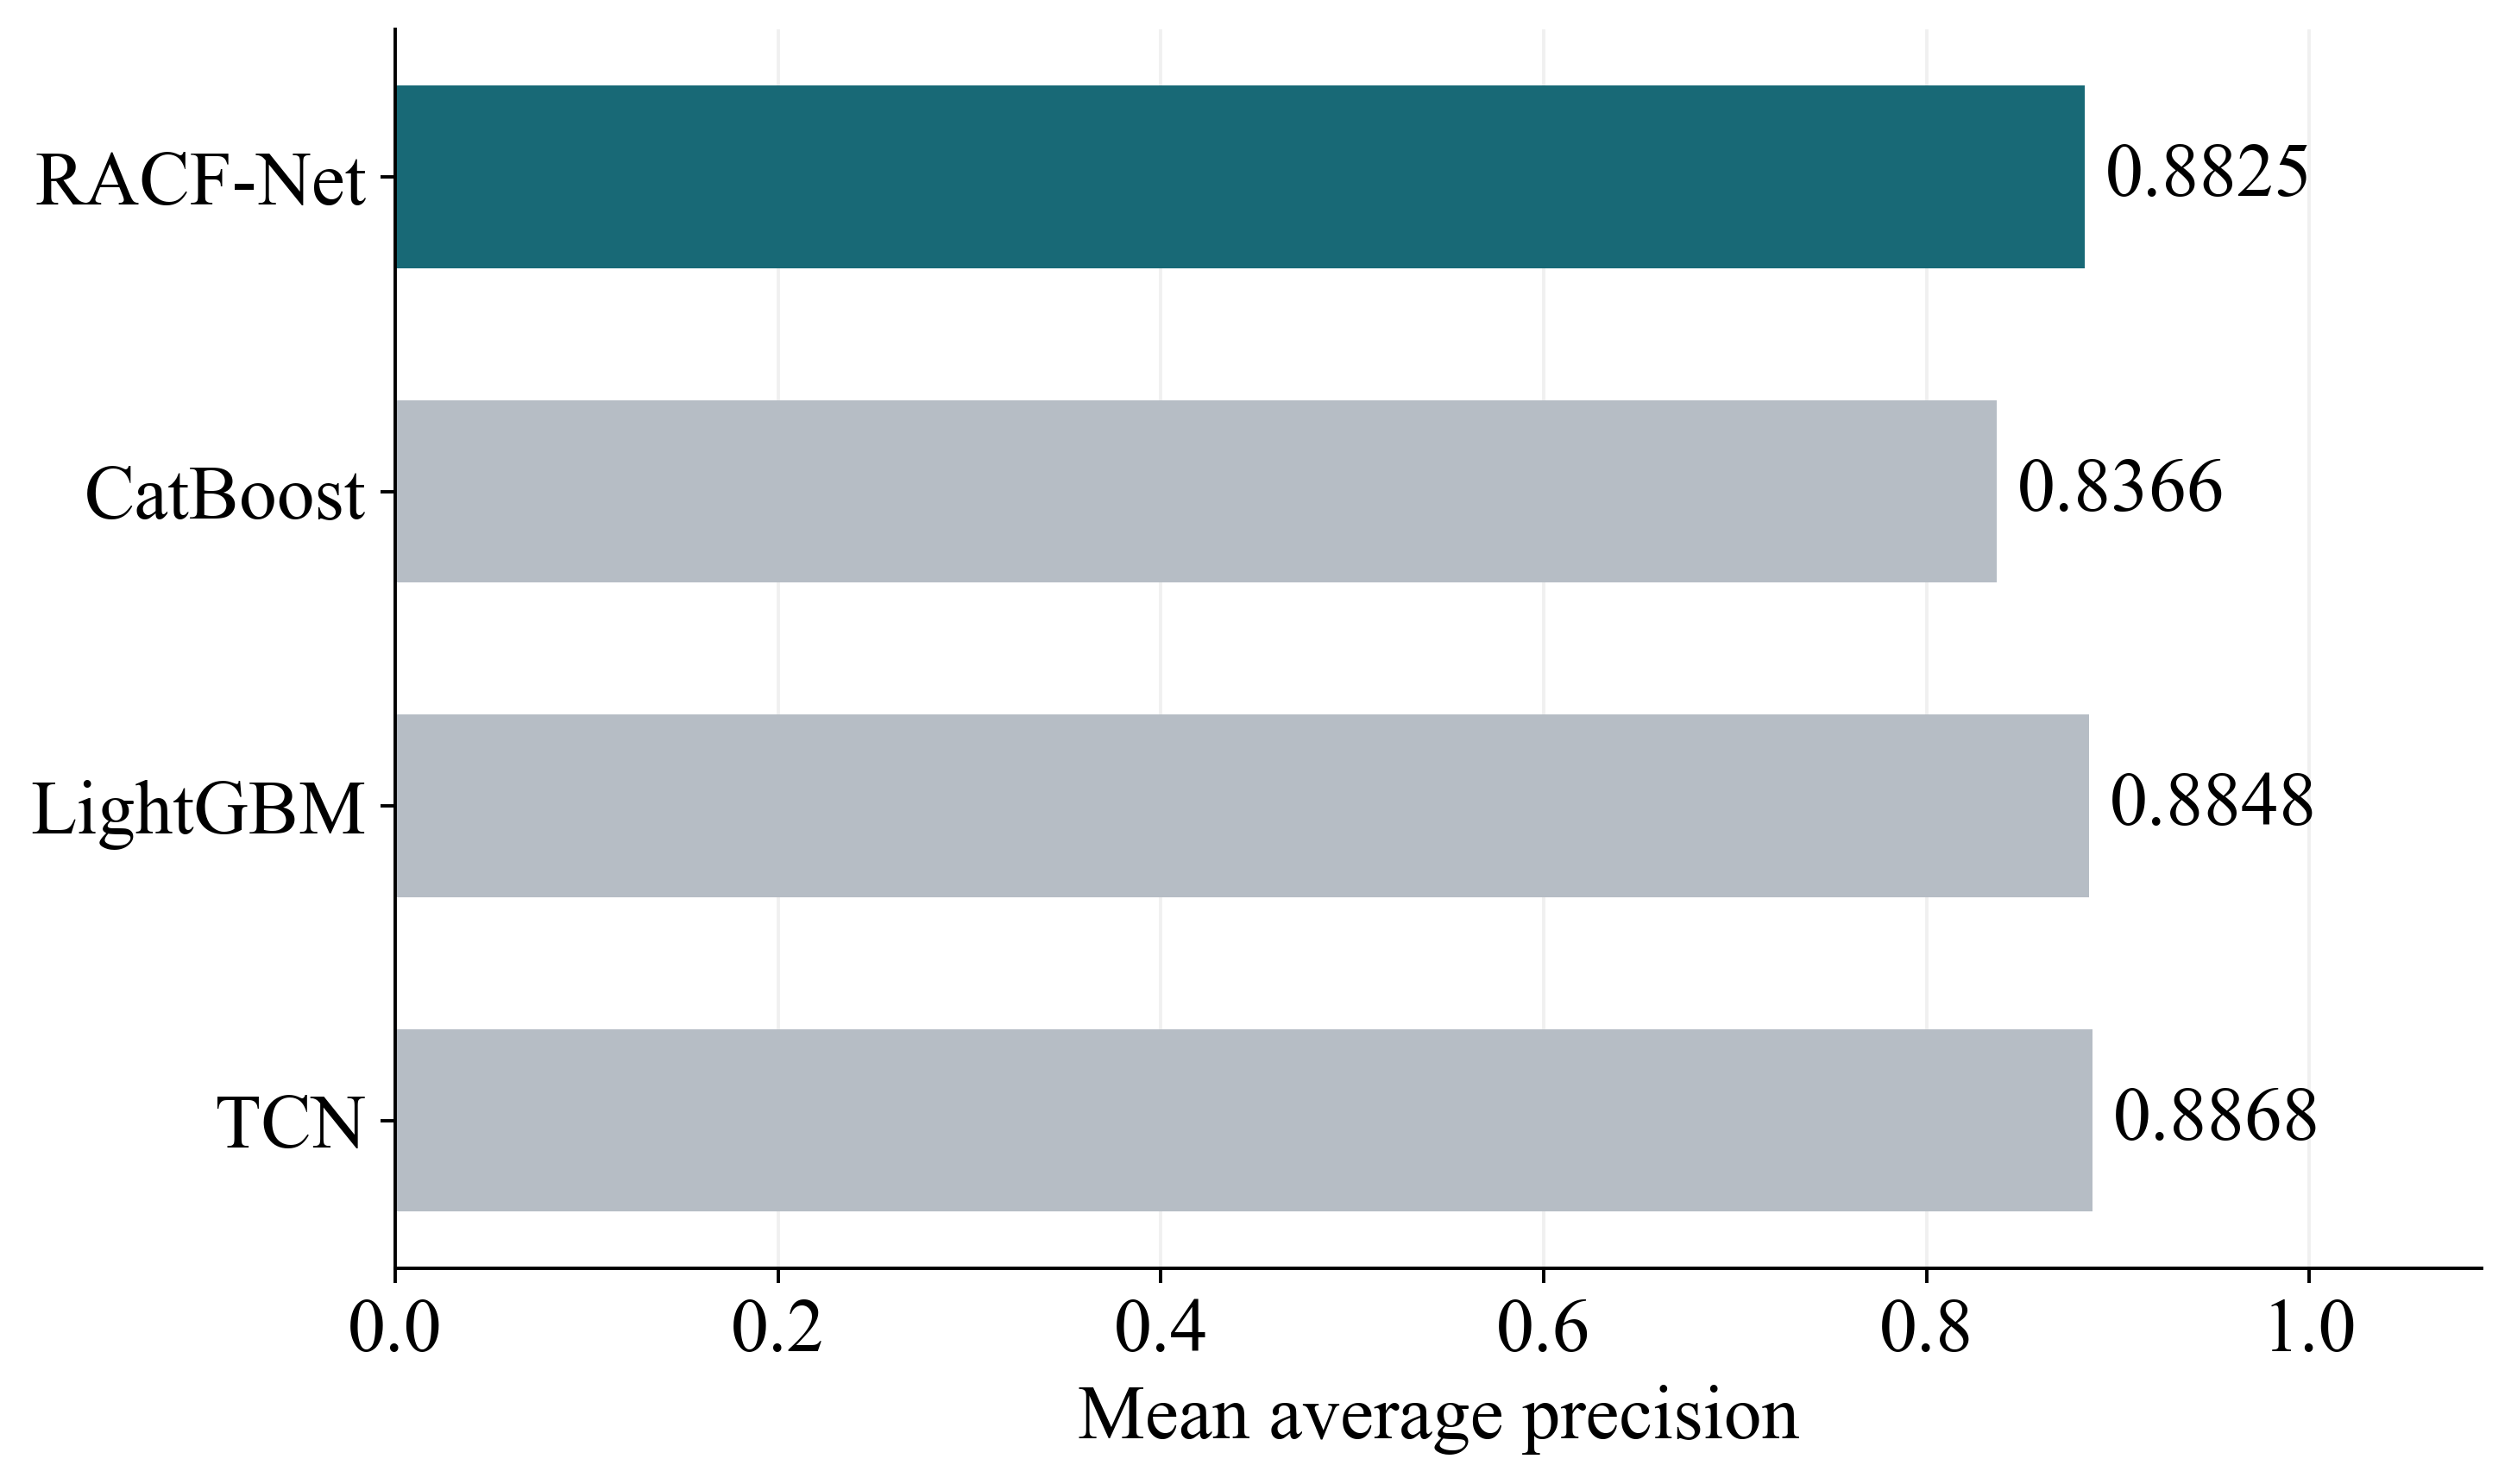

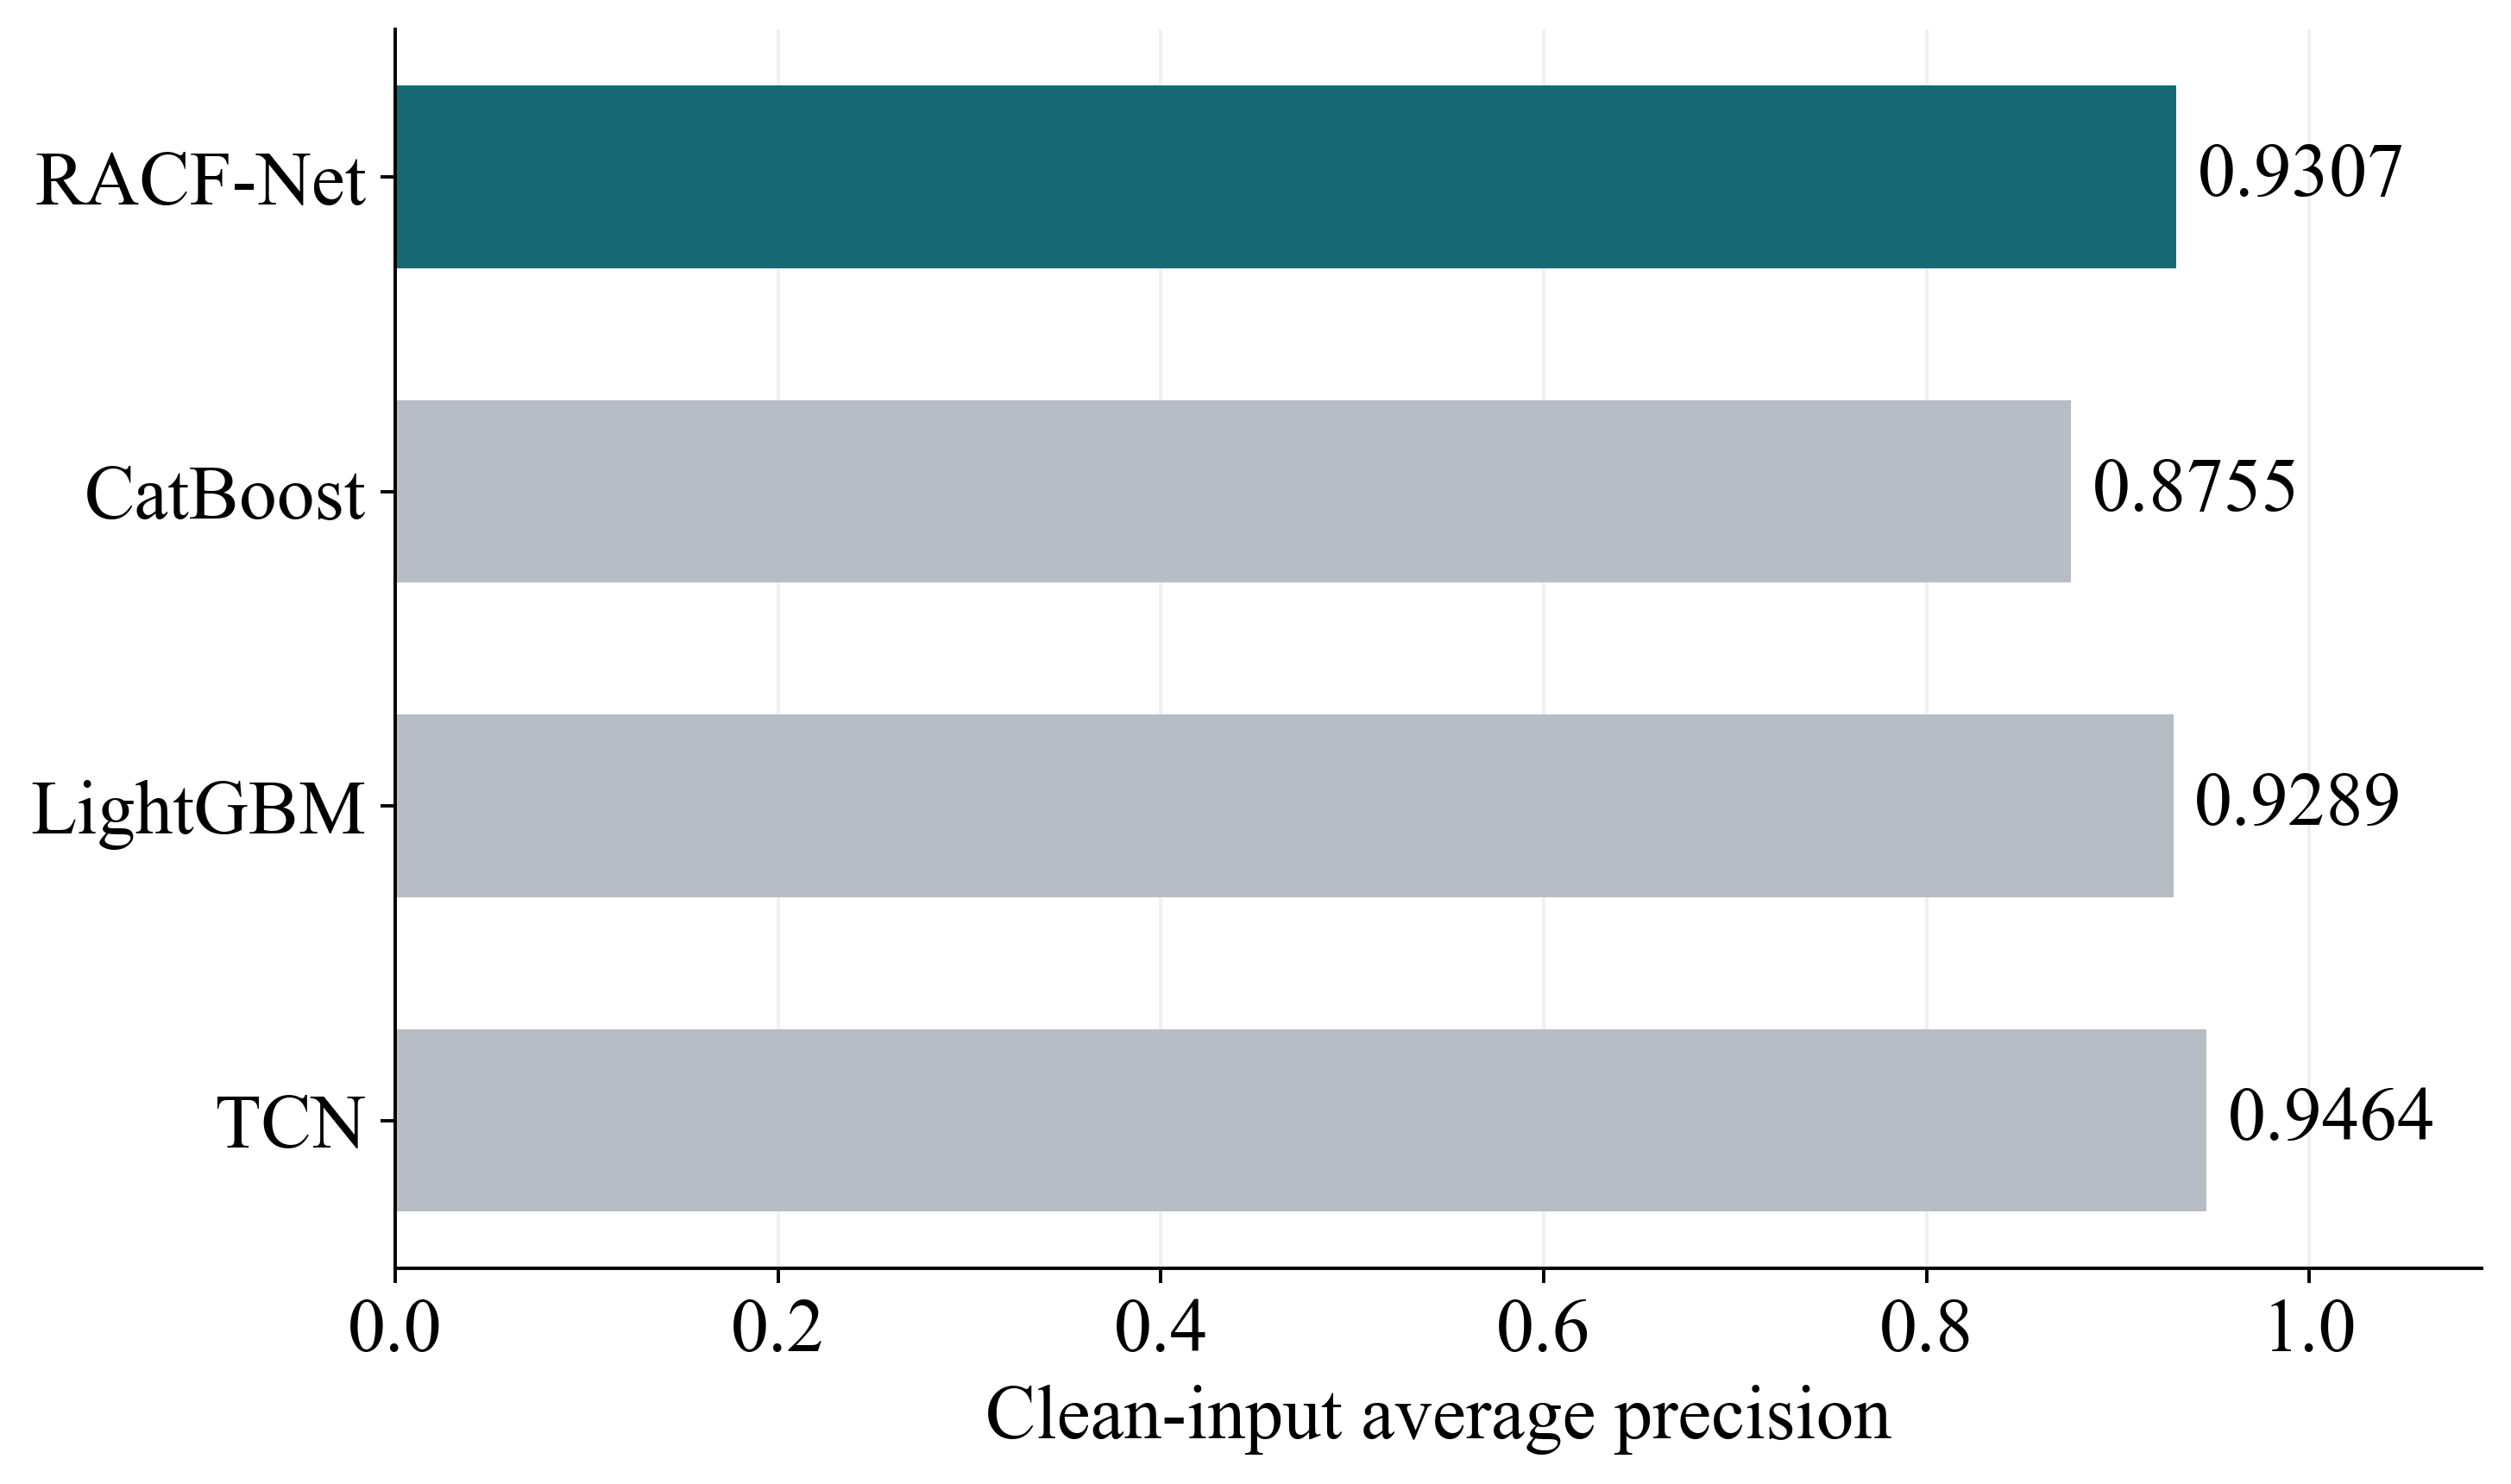

In [122]:
def focus_confirmation_figures(summary):
    import matplotlib.pyplot as plt
    folder=OUTPUT_ROOT/"Figures"/FOCUS_RUN_ID;folder.mkdir(parents=True,exist_ok=True)
    shown=summary.set_index("Model").loc[["RACF-Net","CatBoost","LightGBM","TCN"]]
    with plt.rc_context({"font.family":"Times New Roman","font.size":18,"axes.labelsize":18,
        "xtick.labelsize":18,"ytick.labelsize":18,"figure.dpi":350,"savefig.dpi":350}):
        for column,title in [("Mean_AP","Mean average precision"),("Clean_AP","Clean-input average precision")]:
            fig,ax=plt.subplots(figsize=(8.2,4.8),layout="constrained")
            values=shown[column].to_numpy()
            bars=ax.barh(shown.index,values,color=["#186976","#b6bdc5","#b6bdc5","#b6bdc5"],height=.58)
            ax.bar_label(bars,labels=[f"{value:.4f}" for value in values],padding=5,fontsize=18)
            ax.invert_yaxis();ax.set_xlim(0,1.09);ax.set_xticks(np.linspace(0,1,6))
            ax.set_xlabel(title);ax.spines[["top","right"]].set_visible(False);ax.grid(axis="x",alpha=.18)
            ax.set_axisbelow(True)
            for suffix in ["png","pdf"]:
                destination=folder/("confirmation_2023_"+column+"."+suffix)
                fig.savefig(destination,dpi=350,bbox_inches="tight");focus_register(destination)
            display(fig);plt.close(fig)
            display(Markdown("2023 temporal confirmation; one fitted seed (42). Clean and weather-unavailable conditions are deterministic; the other four conditions average three corruption streams. The mean gives each of the six scenarios equal weight. No confidence interval is represented."))
    proposed=shown.loc["RACF-Net"]
    controls=shown.drop(index="RACF-Net")
    display(Markdown(f"At the fixed 2023 confirmation, RACF-Net has mean AP **{proposed.Mean_AP:.4f}** "
        f"(difference from the strongest control: **{proposed.Mean_AP-controls.Mean_AP.max():+.4f}**) "
        f"and clean AP **{proposed.Clean_AP:.4f}** "
        f"(difference: **{proposed.Clean_AP-controls.Clean_AP.max():+.4f}**). "
        "These measurements are reported without further configuration changes. Full-component superiority and universal dominance are not established by head-only sensitivity experiments."))

if REPLAY_EXISTING:
    for metric in ("Mean_AP", "Clean_AP"):
        stem = OUTPUT_ROOT/"Figures"/FOCUS_RUN_ID/("confirmation_2023_"+metric)
        for suffix in (".png", ".pdf"):
            legacy_saved(stem.with_suffix(suffix))
        display(Image(filename=str(stem.with_suffix(".png"))))
else:
    focus_confirmation_figures(focus_confirmation_summary)


In [123]:
def focus_finalize(models):
    path=FOCUS_MANIFESTS/"model_freeze.json"
    if path.exists():
        frozen=json.loads(focus_verify(path).read_text())
        for record in frozen["models"]:
            for key in ["checkpoint","calibration_file"]:
                digest=record["checkpoint_sha256" if key=="checkpoint" else "calibration_sha256"]
                focus_verify(record[key],digest)
        for relative,digest in frozen["input_files"].items():focus_verify(relative,digest)
        return frozen
    assert all(r["Passed"] for r in focus_engineering["checks"])
    indices=np.load(SPLITS_ROOT/"calibration_evaluation.npy")
    assert metadata.iloc[indices].date.dt.year.eq(2024).all()
    final=[]
    for record in models:
        calibration,calpath=focus_calibrate(record,2024,indices)
        final.append({**record,"scope":"temporal","seed":42,
            "calibration_file":str(calpath.relative_to(OUTPUT_ROOT)),"calibration_sha256":racf_hash(calpath)})
    sync=json.loads((RACF_MANIFESTS/"nb06_inference_definition_sync.json").read_text())
    source=FOCUS_MANIFESTS/"architecture_selection.json"
    confirmation=SHARED_DATASET_ROOT / "Features/racf_20261012/confirmation_2026"
    inputs=["Manifests/feature_manifest.json","Data/Processed/features_raw.parquet",
        "Data/Processed/observation_metadata.parquet","Data/Processed/sequences_raw.npy",
        "Data/Processed/feature_schema.json","Data/Splits/locked_test_evaluation.npy",
        "Data/Splits/calibration_evaluation.npy"]
    inputs += [str((confirmation/name).relative_to(OUTPUT_ROOT)) for name in
        ["feature_manifest.json","features_raw.parquet","observation_metadata.parquet","sequences_raw.npy",
         "feature_schema.json","confirmation_temporal_evaluation.npy"]]
    for manifest_path in [OUTPUT_ROOT/"Manifests/feature_manifest.json",confirmation/"feature_manifest.json"]:
        inputs+=list(json.loads(manifest_path.read_text())["files"])
    files={relative:racf_hash(OUTPUT_ROOT/relative) for relative in sorted(set(inputs))}
    frozen={"schema_version":"racf-focused-freeze-1","run_id":FOCUS_RUN_ID,"created_utc":datetime.now(timezone.utc).isoformat(),
        "protocol_file":str(focus_protocol_path.relative_to(OUTPUT_ROOT)),"protocol_sha256":focus_protocol_sha256,
        "architecture_selection_file":str(source.relative_to(OUTPUT_ROOT)),"architecture_selection_sha256":racf_hash(focus_verify(source)),
        "models":final,"input_files":files,"shared_definition_sha256":sync["inference_ast_sha256"],
        "worker_source_sha256":sync["worker_source_sha256"],"training_years":[2019,2020,2021],
        "scope":"temporal","seed":42,"scenarios":FOCUS_CONFIG["scenarios"],
        "evaluation_noise_seeds":[2026,137,42],"historical_outcomes_already_disclosed":True,
        "architecture_and_thresholds_frozen":True,"full_refitted_ablation_performed":False,
        "independent_future_evaluation_performed":False,
        "claim_scope":"Temporal historical reassessment of a focused expert update; single training seed and shared 2019–2021 fitted cohort"}
    assert hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()==frozen["worker_source_sha256"]
    focus_json(frozen,path);focus_register(path)
    return frozen


In [124]:
def focus_batch_contract(frozen):
    """Audit frozen CPU inference across batch partitions; never fit or select a model."""
    path = FOCUS_MANIFESTS / "batch_contract_audit.json"
    evaluation = np.asarray(racf_partition("temporal", "development")["evaluation"])
    indices = evaluation[np.linspace(0, len(evaluation) - 1, 12, dtype=int)]
    raw = np.asarray(sequences[indices], dtype=np.float32)
    frame, meta = features.iloc[indices], metadata.iloc[indices]
    signature = {
        "model_freeze_sha256": racf_hash(focus_verify(FOCUS_MANIFESTS / "model_freeze.json")),
        "source_sha256": focus_source_hash(["focused-batch-contract-helper"]),
        "observation_ids": meta.observation_id.tolist(), "batch_sizes": [1, 3, 12],
        "device": "cpu", "absolute_tolerance": 1e-6,
    }
    if path.exists():
        audit = json.loads(focus_verify(path).read_text())
        assert audit["signature"] == signature
    else:
        rows = []
        for record in frozen["models"]:
            package = joblib.load(focus_verify(record["checkpoint"], record["checkpoint_sha256"]))
            calibration = joblib.load(focus_verify(record["calibration_file"], record["calibration_sha256"]))
            package._runtime_device = "cpu"
            if package.core["state_dict"] is not None:
                package.restore_network("cpu")
            baseline = package.predict(raw, frame, meta)
            assert baseline.shape == (len(indices),) and np.isfinite(baseline).all()
            probability = calibration.predict(baseline)
            decisions = calibration.decisions(baseline)
            for size in (1, 3):
                scores = np.concatenate([
                    package.predict(raw[start:start + size], frame.iloc[start:start + size], meta.iloc[start:start + size])
                    for start in range(0, len(indices), size)
                ])
                raw_error = float(np.max(np.abs(scores - baseline)))
                probability_error = float(np.max(np.abs(calibration.predict(scores) - probability)))
                decision_equal = all(np.array_equal(calibration.decisions(scores)[policy], decisions[policy])
                                     for policy in ("f1", "budget"))
                rows.append({"Model": record["model"], "Batch_size": size,
                    "Maximum_error": max(raw_error, probability_error),
                    "Tolerance": 1e-6, "Decisions_equal": bool(decision_equal),
                    "Passed": bool(np.isfinite(scores).all() and max(raw_error, probability_error) <= 1e-6 and decision_equal)})
            del package, calibration
            gc.collect()
        audit = {"signature": signature, "checks": rows,
            "interpretation": "Numerical batch-partition equivalence on 12 development windows; no performance or deployment claim."}
        focus_json(audit, path)
        focus_register(path)
    focus_table(pd.DataFrame(audit["checks"]), "batch_contract_checks",
        "Frozen CPU batch-partition checks: maximum raw-score or calibrated-probability difference against batch 12")
    assert all(row["Passed"] for row in audit["checks"]), "Frozen batch contract failed; inspect saved evidence"
    return audit


In [125]:
if REPLAY_EXISTING:
    focus_freeze = json.loads(legacy_saved(FOCUS_MANIFESTS/"model_freeze.json").read_text())
    assert focus_freeze["architecture_and_thresholds_frozen"]
    for row in focus_freeze["models"]:
        for path_key, hash_key in (("checkpoint", "checkpoint_sha256"), ("calibration_file", "calibration_sha256")):
            assert racf_hash(legacy_saved(row[path_key])) == row[hash_key]
    focus_batch_audit = json.loads(legacy_saved(FOCUS_MANIFESTS/"batch_contract_audit.json").read_text())
    assert focus_batch_audit["signature"]["model_freeze_sha256"] == racf_hash(legacy_saved(FOCUS_MANIFESTS/"model_freeze.json"))
    assert focus_batch_audit["signature"]["source_sha256"] == focus_source_hash(["focused-batch-contract-helper"])
    assert all(row["Passed"] for row in focus_batch_audit["checks"])
    legacy_show(legacy_frame(FOCUS_TABLES/"frozen_model_manifest.csv"), "Verified frozen handoff")
    legacy_show(legacy_frame(FOCUS_TABLES/"batch_contract_checks.csv"), "Saved batch-partition checks")
else:
    focus_freeze=focus_finalize(focus_selected_models)
    focus_table(pd.DataFrame([{"Model":r["model"],"Training_years":"2019–2021","Calibration_year":2024,
        "Scope":"Temporal","Model_seed":42,"Checkpoint_SHA256":r["checkpoint_sha256"][:16]} for r in focus_freeze["models"]]),
        "frozen_model_manifest","Frozen checkpoint and calibration handoff to NB06")
    display(Markdown("Four checkpoints and their 2024 calibration artifacts are frozen. NB06 may now assess the already disclosed 2025–2026 cohorts. No independent future validation, unseen-site transfer, full refitted ablation, or training-seed stability is claimed by this focused amendment."))
    
    focus_batch_audit = focus_batch_contract(focus_freeze)


**Verified frozen handoff**

Model,Training_years,Calibration_year,Scope,Model_seed,Checkpoint_SHA256
RACF-Net,2019–2021,2024,Temporal,42,057af1406077938e
CatBoost,2019–2021,2024,Temporal,42,e8f62dfee18a7df3
LightGBM,2019–2021,2024,Temporal,42,2ce16b31aa87a610
TCN,2019–2021,2024,Temporal,42,6d73f32182646f84


**Saved batch-partition checks**

Model,Batch_size,Maximum_error,Tolerance,Decisions_equal,Passed
RACF-Net,1,0.00000,0.00000,True,True
RACF-Net,3,0.00000,0.00000,True,True
CatBoost,1,0.00000,0.00000,True,True
CatBoost,3,0.00000,0.00000,True,True
LightGBM,1,0.00000,0.00000,True,True
LightGBM,3,0.00000,0.00000,True,True
TCN,1,0.00000,0.00000,True,True
TCN,3,0.00000,0.00000,True,True


## Post hoc component and mechanism assessment

In [126]:
from contextlib import contextmanager
COMPONENT_RUN_ID = "racf_components_20261014_002554"
COMPONENT_ROOT = OUTPUT_ROOT/"Artifacts/Runs"/COMPONENT_RUN_ID
COMPONENT_TABLES = OUTPUT_ROOT/"Tables"/COMPONENT_RUN_ID
COMPONENT_MANIFESTS = OUTPUT_ROOT/"Manifests"/COMPONENT_RUN_ID
for directory in [COMPONENT_ROOT, COMPONENT_TABLES, COMPONENT_MANIFESTS]:
    directory.mkdir(parents=True, exist_ok=True)
COMPONENT_VARIANTS = [
    {"id":"full", "label":"Full RACF-Net", "kind":"frozen_reference", "changes":{}, "drop":[]},
    {"id":"no_agents", "label":"No numerical agents", "kind":"full_refit", "changes":{"agents_enabled":False}, "drop":[]},
    {"id":"no_peer", "label":"No peer exchange", "kind":"full_refit", "changes":{"peer_exchange":False}, "drop":[]},
    {"id":"no_repair", "label":"No restoration", "kind":"full_refit", "changes":{"repair":False}, "drop":[]},
    {"id":"no_latent", "label":"No temporal latent", "kind":"readout_refit", "changes":{}, "drop":["latent__"]},
    {"id":"no_quality_export", "label":"No direct quality inputs", "kind":"readout_refit", "changes":{}, "drop":["quality__"]},
    {"id":"no_action_export", "label":"No direct action inputs", "kind":"readout_refit", "changes":{}, "drop":["repair_action__","repair_change__"]},
]
COMPONENT_PLAN = {"run_id":COMPONENT_RUN_ID, "parent_run":FOCUS_RUN_ID,
    "training_years":[2019,2020,2021], "calibration_year":2022, "evaluation_year":2023,
    "seed":42, "fixed_epochs":40, "noise_seed":2026, "scenarios":list(FOCUS_CONFIG["scenarios"]),
    "variants":COMPONENT_VARIANTS, "bootstrap_replicates":2000, "bootstrap_seed":137,
    "bootstrap_unit":"physical site", "confidence":0.95, "multiplicity":"Holm across six removals and AP/F1/MCC",
    "primary_policy":"f1", "secondary_policy":"budget", "selection_reopened":False,
    "analysis_status":"Post hoc development mechanism assessment; previously observed development outcomes",
    "training_ids_sha256":focus_train_ids_sha256, "parent_freeze_sha256":racf_hash(FOCUS_MANIFESTS/"model_freeze.json"),
    "reference_checkpoint_sha256":next(r["checkpoint_sha256"] for r in focus_selected_models if r["model"]=="RACF-Net"),
    "scope_notes":"No-agents retains shared input-adapter repair; no-peer removes learned peer exchange and peer-assisted repair; no-restoration removes temporal and peer repair. Direct export removals retain upstream information. Dynamic eager execution is tested for equivalence and cost, not expected accuracy gain."}
COMPONENT_RESULTS = {}


In [127]:
def component_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def component_save_json(record, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix+".tmp")
    temporary.write_text(json.dumps(record, indent=2, allow_nan=False)+"\n")
    temporary.replace(path)
    return path


def component_source_hash():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    ids = {"component-storage","component-context","component-readout","component-fitting","component-model-storage","component-predictions","component-evaluation"}
    sources = {c["id"]:ast.dump(ast.parse("".join(c["source"])),include_attributes=False)
        for c in notebook["cells"] if c.get("id") in ids}
    assert set(sources)==ids
    return hashlib.sha256(json.dumps(sources,sort_keys=True).encode()).hexdigest()


def component_table(frame, title):
    display(Markdown("**"+title+"**"))
    display(frame.style.format(precision=5, na_rep="Not applicable").hide(axis="index"))


def component_verify(path, expected):
    path=Path(path);path=path if path.is_absolute() else OUTPUT_ROOT/path
    assert path.is_file() and component_hash(path)==expected, str(path)
    return path


In [128]:
@contextmanager
def component_context():
    configuration=dict(RACF_CONFIG, run_id=COMPONENT_RUN_ID, model_seeds=[42], evaluation_noise_seeds=[2026])
    changes={'RACF_RUN_ID':COMPONENT_RUN_ID,'RACF_ROOT':COMPONENT_ROOT,
        'RACF_MANIFESTS':COMPONENT_MANIFESTS,'RACF_TABLES':COMPONENT_TABLES,'RACF_CONFIG':configuration}
    previous={key:globals()[key] for key in changes}
    globals().update(changes)
    try:
        yield
    finally:
        globals().update(previous)


In [129]:
class ComponentReadout(RACFModelPipeline):
    """Diagnostic readout removal; upstream channels are retained explicitly."""
    def expert_inputs(self, prepared, latent=None):
        prefixes=tuple(self.config.get("diagnostic_drop",[]))
        if "latent__" in prefixes:
            latent=np.zeros((len(prepared["raw_frame"]),32),dtype=np.float32)
        elif latent is None:
            latent=self.neural_outputs(prepared)["latent"]
        matrix=racf_expert_inputs(prepared,self.config,latent,prepared["messages"],self.message_names)
        keep=[name for name in matrix.columns if not name.startswith(prefixes)]
        assert len(keep)<len(matrix.columns), "The registered readout removal must change actual inputs"
        return matrix[keep]


In [130]:
def component_fit_variant(variant):
    reference=next(r for r in focus_selected_models if r["model"]=="RACF-Net")
    original=joblib.load(focus_verify(reference["checkpoint"],reference["checkpoint_sha256"]))
    config=dict(original.config,**variant["changes"])
    label="component_"+variant["id"]
    if variant["kind"]=="readout_refit":
        config["diagnostic_drop"]=variant["drop"]
        model=ComponentReadout(original.adapter,original.agents,config,network=original.restore_network())
        history=pd.DataFrame(columns=["epoch","training_loss","epoch_seconds"])
    else:
        adapter,agents=racf_fit_preprocessors(config,42,focus_train)
        arrays=racf_prepare_training_arrays(adapter,agents,focus_train,config,42,label,augment=False)
        try:
            network,history,epochs=fit_v2_representation(config,42,arrays,
                epochs=COMPONENT_PLAN["fixed_epochs"],stage="denoising",label=variant["label"])
            assert epochs==40 and len(history)==40
        finally:
            arrays.close()
        model=RACFModelPipeline(adapter,agents,config,network=network)
    model=racf_fit_pipeline_head(model,focus_train,config,42,label)
    if not history.empty:
        history.to_csv(COMPONENT_TABLES/(variant["id"]+"_learning.csv"),index=False)
    del original
    return model,config,history


In [131]:
def component_model(variant):
    if variant["kind"]=="frozen_reference":
        record=next(r for r in focus_selected_models if r["model"]=="RACF-Net")
        return joblib.load(focus_verify(record["checkpoint"],record["checkpoint_sha256"])),dict(record,fit_seconds=0.0)
    path=COMPONENT_ROOT/"Models"/(variant["id"]+".joblib")
    manifest=path.with_suffix(".json")
    signature={"variant":variant,"plan_sha256":COMPONENT_PLAN_SHA,"source_sha256":COMPONENT_SOURCE_SHA}
    if manifest.exists():
        record=json.loads(manifest.read_text());assert record["signature"]==signature
        return joblib.load(component_verify(path,record["checkpoint_sha256"])),record
    assert not path.exists(), "Uncommitted diagnostic checkpoint requires inspection"
    started=time.perf_counter()
    with component_context():
        model,config,history=component_fit_variant(variant)
    path.parent.mkdir(parents=True,exist_ok=True);joblib.dump(model,path,compress=3)
    record={"model":variant["label"],"checkpoint":str(path.relative_to(OUTPUT_ROOT)),
        "checkpoint_sha256":component_hash(path),"signature":signature,"configuration":config,
        "fit_seconds":time.perf_counter()-started,"training_rows":len(focus_train),
        "expert_features":len(model.expert_feature_names),"epochs":40 if variant["kind"]=="full_refit" else 0}
    component_save_json(record,manifest)
    return model,record


In [132]:
def component_raw_predictions(model,record,variant,year,scenario):
    assert year in (2022,2023), "Historical outcomes are excluded from mechanism development"
    indices=np.asarray(focus_partition["evaluation"] if year==2022 else racf_partition("temporal","development")["evaluation"])
    cohort=metadata.iloc[indices].copy()
    assert cohort.date.dt.year.eq(year).all()
    if variant["id"]=="full":
        if year==2022:
            calibration=joblib.load(focus_verify(FOCUS_ROOT/"Calibration/RACFNet_2022.joblib"))
            source=calibration.fit_audit["source"]
            path=focus_verify(source["prediction_file"],source["prediction_sha256"])
        else:
            saved=pd.read_csv(focus_verify(FOCUS_TABLES/"confirmation_metrics.csv"))
            match=saved.query("Model=='RACF-Net' and Policy=='f1' and Noise_seed==2026")
            path=focus_verify(match.loc[match.Scenario.eq(scenario),"Prediction_file"].item())
        result=pd.read_parquet(path)
        assert result.observation_id.tolist()==cohort.observation_id.tolist()
        np.testing.assert_array_equal(result.target,cohort.target)
        return result,path
    folder=COMPONENT_ROOT/"Predictions";folder.mkdir(parents=True,exist_ok=True)
    path=folder/(variant["id"]+f"_{year}_{scenario}.parquet");lineage=path.with_suffix(".json")
    signature={"checkpoint_sha256":record["checkpoint_sha256"],"source_sha256":COMPONENT_SOURCE_SHA,
        "plan_sha256":COMPONENT_PLAN_SHA,"year":year,"scenario":scenario,"noise_seed":2026,
        "ids_sha256":hashlib.sha256("\n".join(cohort.observation_id).encode()).hexdigest()}
    if lineage.exists():
        old=json.loads(lineage.read_text());assert old["signature"]==signature
        result=pd.read_parquet(component_verify(path,old["sha256"]))
    else:
        assert not path.exists(), "Inspect uncommitted diagnostic predictions"
        scores=np.empty(len(indices),dtype=float)
        for start in range(0,len(indices),1024):
            rows=indices[start:start+1024]
            raw,frame,_=racf_corrupt(sequences[rows],features.iloc[rows],metadata.iloc[rows],scenario,2026)
            scores[start:start+len(rows)]=model.predict(raw,frame,metadata.iloc[rows])
        assert np.isfinite(scores).all()
        names=[c for c in ["observation_id","date","target","plant_id","reactor_id","episode_id","event_episode_id","event_id"] if c in cohort]
        result=cohort[names].copy();result["raw_score"]=scores
        result.to_parquet(path,index=False)
        component_save_json({"signature":signature,"sha256":component_hash(path)},lineage)
    assert result.observation_id.tolist()==cohort.observation_id.tolist()
    np.testing.assert_array_equal(result.target,cohort.target)
    return result,path


In [133]:
def component_evaluate_variant(variant):
    model,record=component_model(variant)
    calibration_predictions,source_path=component_raw_predictions(model,record,variant,2022,"clean")
    if variant["id"]=="full":
        calibration=joblib.load(focus_verify(FOCUS_ROOT/"Calibration/RACFNet_2022.joblib"))
    else:
        calpath=COMPONENT_ROOT/"Calibration"/(variant["id"]+".json")
        if calpath.exists():
            calibration=RACFCalibration.from_dict(json.loads(calpath.read_text()))
            assert calibration.fit_audit["source"]["checkpoint_sha256"]==record["checkpoint_sha256"]
        else:
            source={"year":2022,"checkpoint_sha256":record["checkpoint_sha256"],
                "prediction_sha256":component_hash(source_path),"plan_sha256":COMPONENT_PLAN_SHA}
            calibration=RACFCalibration(1.0).fit(calibration_predictions.raw_score,calibration_predictions.target,source)
            component_save_json(calibration.to_dict(),calpath)
    rows=[];files={}
    for scenario in COMPONENT_PLAN["scenarios"]:
        raw,path=component_raw_predictions(model,record,variant,2023,scenario)
        pred=focus_decision_frame(raw,calibration)
        for policy in ["f1","budget"]:
            metric=racf_metrics(pred,policy)
            assert all(np.isfinite(metric[key]) for key in ["AP","F1","MCC","Brier","Event_recall","False_alarms_per_1000"])
            rows.append({"Variant":variant["label"],"Variant_id":variant["id"],"Scenario":scenario,
                "Year":2023,"Noise_seed":2026,**metric})
        files[scenario]={"path":str(path.relative_to(OUTPUT_ROOT)),"sha256":component_hash(path)}
    frame=pd.DataFrame(rows);frame.to_csv(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"),index=False)
    report={"variant":variant,"model":record,"predictions":files,"calibration":calibration.to_dict(),
        "plan_sha256":COMPONENT_PLAN_SHA,"source_sha256":COMPONENT_SOURCE_SHA}
    component_save_json(report,COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json"))
    component_table(frame.query("Policy=='f1'")[["Scenario","AP","F1","MCC","Event_recall","False_alarms_per_1000"]],
        variant["label"]+": 2023; six conditions; fixed 2022 F1 policy")
    del model;gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return report


In [134]:
COMPONENT_SOURCE_SHA=component_source_hash()
COMPONENT_PLAN["scientific_source_sha256"]=COMPONENT_SOURCE_SHA
COMPONENT_PLAN["shared_definition_sha256"]=racf_definition_fingerprint()
COMPONENT_PLAN_PATH=COMPONENT_MANIFESTS/"diagnostic_protocol.json"
if REPLAY_EXISTING:
    legacy_saved(COMPONENT_PLAN_PATH)
if COMPONENT_PLAN_PATH.exists():
    assert json.loads(COMPONENT_PLAN_PATH.read_text())["plan"]==COMPONENT_PLAN
else:
    component_save_json({"registered_utc":datetime.now(timezone.utc).isoformat(),"plan":COMPONENT_PLAN},COMPONENT_PLAN_PATH)
COMPONENT_PLAN_SHA=component_hash(COMPONENT_PLAN_PATH)
component_table(pd.DataFrame([{"Variant":v["label"],"Refit":v["kind"],
    "Intervention":str(v["changes"] or v["drop"] or "Preserved reference")} for v in COMPONENT_VARIANTS]),
    "Registered component interventions; no new architecture selection")


**Registered component interventions; no new architecture selection**

Variant,Refit,Intervention
Full RACF-Net,frozen_reference,Preserved reference
No numerical agents,full_refit,{'agents_enabled': False}
No peer exchange,full_refit,{'peer_exchange': False}
No restoration,full_refit,{'repair': False}
No temporal latent,readout_refit,['latent__']
No direct quality inputs,readout_refit,['quality__']
No direct action inputs,readout_refit,"['repair_action__', 'repair_change__']"


In [135]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[0]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[0]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["full"]=component_evaluate_variant(COMPONENT_VARIANTS[0])
    finally:
        RACF_TRAINING_PROGRESS=None


**Full RACF-Net: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.93068,0.93182,0.93264,0.97619,0.24641
weather_unavailable,0.91789,0.93182,0.93264,0.97619,0.24641
power_mcar_10,0.81818,0.86047,0.86040,0.88095,0.34498
power_mcar_30,0.68559,0.71429,0.72858,0.59524,0.14785
power_noise_1,0.92945,0.93182,0.93264,0.97619,0.24641
power_noise_2,0.93502,0.91954,0.91992,0.95238,0.24641


In [136]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[1]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[1]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_agents"]=component_evaluate_variant(COMPONENT_VARIANTS[1])
    finally:
        RACF_TRAINING_PROGRESS=None


**No numerical agents: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.95582,0.89888,0.90008,0.95238,0.34498
weather_unavailable,0.92905,0.89888,0.90008,0.95238,0.34498
power_mcar_10,0.83605,0.85057,0.85076,0.88095,0.39426
power_mcar_30,0.68354,0.70270,0.70869,0.61905,0.29570
power_noise_1,0.94815,0.90909,0.90984,0.95238,0.29570
power_noise_2,0.94714,0.89888,0.90008,0.95238,0.34498


In [137]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[2]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[2]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_peer"]=component_evaluate_variant(COMPONENT_VARIANTS[2])
    finally:
        RACF_TRAINING_PROGRESS=None


**No peer exchange: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.93963,0.90110,0.90357,0.97619,0.39426
weather_unavailable,0.93499,0.90110,0.90357,0.97619,0.39426
power_mcar_10,0.83072,0.83516,0.83729,0.90476,0.54211
power_mcar_30,0.71775,0.72941,0.72890,0.73810,0.59140
power_noise_1,0.92866,0.91111,0.91295,0.97619,0.34498
power_noise_2,0.91924,0.86316,0.86871,0.97619,0.59140


In [138]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[3]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[3]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_repair"]=component_evaluate_variant(COMPONENT_VARIANTS[3])
    finally:
        RACF_TRAINING_PROGRESS=None


**No restoration: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.91670,0.90698,0.90703,0.92857,0.24641
weather_unavailable,0.93510,0.89157,0.89141,0.88095,0.19713
power_mcar_10,0.77670,0.82051,0.82262,0.76190,0.19713
power_mcar_30,0.61428,0.62500,0.65749,0.47619,0.09857
power_noise_1,0.90586,0.90698,0.90703,0.92857,0.24641
power_noise_2,0.91150,0.89412,0.89396,0.90476,0.24641


In [139]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[4]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[4]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_latent"]=component_evaluate_variant(COMPONENT_VARIANTS[4])
    finally:
        RACF_TRAINING_PROGRESS=None


**No temporal latent: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.91421,0.92857,0.92842,0.92857,0.14785
weather_unavailable,0.87848,0.90476,0.90456,0.90476,0.19713
power_mcar_10,0.85507,0.85000,0.85077,0.80952,0.19713
power_mcar_30,0.71842,0.71642,0.74028,0.57143,0.04928
power_noise_1,0.91027,0.91566,0.91556,0.90476,0.14785
power_noise_2,0.90447,0.89412,0.89396,0.90476,0.24641


In [140]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[5]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[5]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_quality_export"]=component_evaluate_variant(COMPONENT_VARIANTS[5])
    finally:
        RACF_TRAINING_PROGRESS=None


**No direct quality inputs: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.93066,0.94253,0.94297,0.97619,0.19713
weather_unavailable,0.90718,0.93182,0.93264,0.97619,0.24641
power_mcar_10,0.81700,0.86047,0.86040,0.88095,0.34498
power_mcar_30,0.68362,0.71429,0.72858,0.59524,0.14785
power_noise_1,0.93086,0.94253,0.94297,0.97619,0.19713
power_noise_2,0.93602,0.91954,0.91992,0.95238,0.24641


In [141]:
if REPLAY_EXISTING:
    variant = COMPONENT_VARIANTS[6]
    report = json.loads(legacy_saved(COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")).read_text())
    assert report["variant"] == variant and report["plan_sha256"] == COMPONENT_PLAN_SHA
    assert report["source_sha256"] == COMPONENT_SOURCE_SHA
    assert racf_hash(legacy_saved(report["model"]["checkpoint"])) == report["model"]["checkpoint_sha256"]
    COMPONENT_RESULTS[variant["id"]] = report
    saved_metrics = legacy_frame(COMPONENT_TABLES/(variant["id"]+"_metrics.csv"))
    component_table(saved_metrics.loc[saved_metrics.Policy.eq("f1"), ["Scenario", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]], variant["label"]+": saved 2023 results")
    RACF_TRAINING_PROGRESS = None
else:
    RACF_TRAINING_PROGRESS=display(Markdown("Component assessment: "+COMPONENT_VARIANTS[6]["label"]),display_id=True)
    try:
        COMPONENT_RESULTS["no_action_export"]=component_evaluate_variant(COMPONENT_VARIANTS[6])
    finally:
        RACF_TRAINING_PROGRESS=None


**No direct action inputs: saved 2023 results**

Scenario,AP,F1,MCC,Event_recall,False_alarms_per_1000
clean,0.93429,0.93182,0.93264,0.97619,0.24641
weather_unavailable,0.89523,0.93182,0.93264,0.97619,0.24641
power_mcar_10,0.81888,0.86047,0.86040,0.88095,0.34498
power_mcar_30,0.69136,0.72222,0.73202,0.61905,0.19713
power_noise_1,0.93213,0.93182,0.93264,0.97619,0.24641
power_noise_2,0.93570,0.93182,0.93264,0.97619,0.24641


In [142]:
@racf_serialization_identity
class RACFClusterAPPlan:
    """Exact tie-aware AP with site multiplicities; storage scales with positive thresholds."""
    def __init__(self, truth, score, site_codes, site_count):
        truth, score, codes = np.asarray(truth, int), np.asarray(score, float), np.asarray(site_codes, int)
        assert len(truth) and truth.shape == score.shape == codes.shape
        assert set(np.unique(truth)).issubset({0, 1}) and np.isfinite(score).all()
        assert codes.min() >= 0 and codes.max() < int(site_count)
        order = np.argsort(-score, kind="stable")
        y, value, site = truth[order], score[order], codes[order]
        ends = np.r_[np.flatnonzero(value[:-1] != value[1:]), len(value)-1]
        positive_cumulative = np.cumsum(y)[ends]
        positive_ends = ends[np.diff(np.r_[0, positive_cumulative]) > 0]
        self.total = np.empty((int(site_count), len(positive_ends)), dtype=float)
        self.positive = np.empty_like(self.total)
        for code in range(int(site_count)):
            self.total[code] = np.searchsorted(np.flatnonzero(site == code), positive_ends, side="right")
            self.positive[code] = np.searchsorted(np.flatnonzero((site == code) & (y == 1)), positive_ends, side="right")
        self.steps = np.diff(self.positive, axis=1, prepend=np.zeros((int(site_count), 1)))
        self.positive_total = np.bincount(codes, weights=truth, minlength=int(site_count)).astype(float)
        self.negative_total = np.bincount(codes, weights=1-truth, minlength=int(site_count)).astype(float)

    def evaluate(self, multiplicities, memory_mb=32):
        counts = np.atleast_2d(np.asarray(multiplicities))
        assert counts.shape[1] == len(self.positive_total) and np.all(counts >= 0)
        result = np.full(len(counts), np.nan, dtype=float)
        thresholds = max(1, self.total.shape[1])
        batch = max(1, min(2048, int(memory_mb*1024**2 / (8*(4*thresholds+counts.shape[1])))))
        for start in range(0, len(counts), batch):
            block = counts[start:start+batch].astype(float, copy=False)
            positives, negatives = block @ self.positive_total, block @ self.negative_total
            valid = (positives > 0) & (negatives > 0)
            if not valid.any():
                continue
            denominator, numerator = block @ self.total, block @ self.positive
            precision = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
            weighted_steps = block @ self.steps
            values = np.divide((weighted_steps*precision).sum(axis=1), positives,
                out=np.full(len(block), np.nan), where=positives > 0)
            result[start:start+len(block)] = np.where(valid, values, np.nan)
        return result


def racf_test_cluster_ap_plan():
    """Deterministic numerical unit checks; these are not scientific performance results."""
    y = np.asarray([1, 0, 1, 0, 0, 1, 0, 0])
    score = np.asarray([.9, .9, .6, .6, .4, .4, .1, .1])
    codes = np.asarray([0, 1, 1, 0, 2, 2, 0, 1])
    counts = np.asarray([[1, 1, 1], [2, 0, 1], [0, 1, 2], [1, 0, 0]])
    plan = RACFClusterAPPlan(y, score, codes, 3)
    expected = [average_precision_score(y, score, sample_weight=w[codes]) for w in counts]
    actual = plan.evaluate(counts)
    assert np.allclose(actual, expected, atol=1e-13, rtol=1e-13), "Tie-aware weighted AP mismatch."
    degenerate = RACFClusterAPPlan(np.asarray([1, 0]), np.asarray([.9, .1]), np.asarray([0, 1]), 2)
    assert np.isnan(degenerate.evaluate([[2, 0], [0, 2]])).all()
    return pd.DataFrame([{"Check":"Tie-aware weighted AP", "Expected":"scikit-learn parity", "Actual":"Passed"},
        {"Check":"Missing outcome class", "Expected":"Undefined, retained", "Actual":"Passed"}])


In [143]:
def component_saved_cases():
    cases, reports, frames = {}, {}, []
    for variant in COMPONENT_VARIANTS:
        path = COMPONENT_MANIFESTS/(variant["id"]+"_evaluation.json")
        report = json.loads(path.read_text())
        assert report["plan_sha256"] == COMPONENT_PLAN_SHA
        assert report["source_sha256"] == COMPONENT_SOURCE_SHA
        calibration = RACFCalibration.from_dict(report["calibration"])
        for scenario, item in report["predictions"].items():
            raw = pd.read_parquet(component_verify(item["path"], item["sha256"]))
            cases[(variant["label"], scenario)] = focus_decision_frame(raw, calibration)
        reports[variant["id"]] = report
        frames.append(pd.read_csv(COMPONENT_TABLES/(variant["id"]+"_metrics.csv")))
    return cases, reports, pd.concat(frames, ignore_index=True)


def component_site_uncertainty(cases):
    variants = [v["label"] for v in COMPONENT_VARIANTS]
    scenarios = COMPONENT_PLAN["scenarios"]
    base = cases[(variants[0], scenarios[0])].sort_values("observation_id")
    assert base.observation_id.is_unique and base.plant_id.notna().all()
    assert pd.to_datetime(base.date).dt.year.eq(2023).all()
    ids, y = base.observation_id.to_numpy(), base.target.to_numpy(int)
    sites, codes = np.unique(base.plant_id.astype(str), return_inverse=True)
    k, repeats = len(sites), COMPONENT_PLAN["bootstrap_replicates"]
    rng = np.random.default_rng(COMPONENT_PLAN["bootstrap_seed"])
    draws = rng.multinomial(k, np.full(k, 1/k), repeats)
    weights = np.vstack([np.ones(k), draws]).astype(float)
    positives = np.bincount(codes, weights=y, minlength=k)
    negatives = np.bincount(codes, weights=1-y, minlength=k)
    both = (weights@positives > 0) & (weights@negatives > 0)
    values = np.zeros((len(variants), 3, repeats+1))
    for vi, variant in enumerate(variants):
        for scenario in scenarios:
            case = cases[(variant, scenario)]
            assert case.observation_id.is_unique and len(case) == len(ids)
            case = case.set_index("observation_id").loc[ids]
            np.testing.assert_array_equal(case.target.to_numpy(int), y)
            np.testing.assert_array_equal(case.plant_id.astype(str), base.plant_id.astype(str))
            decision = case.decision_f1.to_numpy(int)
            assert set(np.unique(decision)).issubset({0, 1})
            cells = np.column_stack([np.bincount(codes, weights=(2*y+decision == j), minlength=k) for j in range(4)])
            tn, fp, fn, tp = (weights@cells).T
            fden = 2*tp+fp+fn
            mden = np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
            f1 = np.divide(2*tp, fden, out=np.full(len(weights), np.nan), where=fden > 0)
            mcc = np.divide(tp*tn-fp*fn, mden, out=np.full(len(weights), np.nan), where=mden > 0)
            ap = RACFClusterAPPlan(y, case.raw_score.to_numpy(float), codes, k).evaluate(weights)
            block = np.vstack([ap, f1, mcc]); block[:, ~both] = np.nan
            values[vi] += block/len(scenarios)
    return values, positives, both


In [144]:
def component_uncertainty_tables(values, positives, both):
    variants = [v["label"] for v in COMPONENT_VARIANTS]
    rows, support = [], []
    for mi, metric in enumerate(["AP", "F1", "MCC"]):
        valid = np.isfinite(values[:, mi, 1:]).all(axis=0)
        support.append({"Metric":metric, "Generated_draws":values.shape[2]-1,
            "Valid_draws":int(valid.sum()), "Class_degenerate":int((~both[1:]).sum()),
            "Other_undefined":int((both[1:] & ~valid).sum()),
            "Event_bearing_sites":int((positives > 0).sum())})
        assert valid.sum() >= 1000, "Insufficient common bootstrap support; inspect before inference"
        for vi, variant in enumerate(variants[1:], 1):
            estimate = float(values[0, mi, 0]-values[vi, mi, 0])
            delta = (values[0, mi, 1:]-values[vi, mi, 1:])[valid]
            lo, hi = np.quantile(delta, [.025, .975])
            p = (1+np.count_nonzero(np.abs(delta-estimate) >= abs(estimate)))/(1+len(delta))
            rows.append({"Metric":metric, "Comparator":variant, "Full_minus_ablation":estimate,
                "Lower_95":float(lo), "Upper_95":float(hi), "p_raw":float(p), "Valid_draws":int(valid.sum())})
    result = pd.DataFrame(rows); assert len(result) == 18
    p = result.p_raw.to_numpy(); order = np.argsort(p, kind="stable")
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))
    result["p_Holm"] = adjusted
    result["Positive_difference_supported"] = (adjusted <= .05) & result.Full_minus_ablation.gt(0)
    assert np.isfinite(result.select_dtypes(include=[np.number]).to_numpy()).all()
    return result, pd.DataFrame(support)


def component_statistical_signature():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    names = {"component_saved_cases","component_site_uncertainty","component_uncertainty_tables","V2ClusterAPPlan"}
    sources = {node.name:ast.dump(node, include_attributes=False)
        for cell in notebook["cells"] if cell["cell_type"] == "code"
        for node in ast.parse("".join(cell["source"])).body
        if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in names}
    assert set(sources) == names
    return hashlib.sha256(json.dumps(sources,sort_keys=True).encode()).hexdigest()


In [145]:
def component_statistics():
    cases, reports, metrics = component_saved_cases()
    metrics.to_csv(COMPONENT_TABLES/"component_case_metrics.csv", index=False)
    mean = metrics.query("Policy=='f1'").groupby("Variant",sort=False)[["AP","F1","MCC","Event_recall","False_alarms_per_1000"]].mean().reset_index()
    signature = {"plan_sha256":COMPONENT_PLAN_SHA,"source_sha256":component_statistical_signature(),
        "reports":{key:component_hash(COMPONENT_MANIFESTS/(key+"_evaluation.json")) for key in reports}}
    saved = COMPONENT_MANIFESTS/"paired_component_statistics.json"
    if saved.exists():
        record=json.loads(saved.read_text());assert record["signature"] == signature
        result, support = pd.DataFrame(record["contrasts"]), pd.DataFrame(record["support"])
    else:
        component_table(racf_test_cluster_ap_plan(),"Weighted AP numerical verification")
        values, positives, both = component_site_uncertainty(cases)
        expected = mean.set_index("Variant").loc[[v["label"] for v in COMPONENT_VARIANTS],["AP","F1","MCC"]].to_numpy()
        np.testing.assert_allclose(values[:,:,0],expected,atol=1e-12,rtol=0)
        result, support = component_uncertainty_tables(values,positives,both)
        component_save_json({"signature":signature,"contrasts":result.to_dict("records"),
            "support":support.to_dict("records"),"point_reconstruction_passed":True},saved)
    mean.to_csv(COMPONENT_TABLES/"component_mean_metrics.csv",index=False)
    result.to_csv(COMPONENT_TABLES/"component_paired_contrasts.csv",index=False)
    support.to_csv(COMPONENT_TABLES/"component_bootstrap_support.csv",index=False)
    display(Markdown("**2023 component assessment: equal mean over six input conditions**"))
    styled=mean.style.format(precision=5).hide(axis="index")
    styled=styled.highlight_max(subset=["AP","F1","MCC","Event_recall"],props="font-weight:bold;")
    styled=styled.highlight_min(subset=["False_alarms_per_1000"],props="font-weight:bold;")
    styled=styled.map(lambda value: "font-weight:bold;" if value=="Full RACF-Net" else "",subset=["Variant"])
    display(styled)
    for metric in ["AP","F1","MCC"]:
        component_table(result.loc[result.Metric.eq(metric),["Comparator","Full_minus_ablation","Lower_95","Upper_95","p_Holm","Positive_difference_supported"]],
            metric+": full minus ablation; paired physical-site uncertainty")
    component_table(support,"Common bootstrap support across all seven variants")
    display(Markdown("Intervals are marginal 95% site-bootstrap intervals; Holm covers all 18 contrasts. "
        "Two thousand resamples give exploratory precision. One training seed and previously observed 2023 outcomes limit generalization. "
        "Positive differences favour the full model; negative differences favour the corresponding removal."))
    return mean,result,support


In [146]:
def component_routing_diagnostic():
    import copy
    reference=next(r for r in focus_selected_models if r["model"]=="RACF-Net")
    full=joblib.load(focus_verify(reference["checkpoint"],reference["checkpoint_sha256"]))
    full.restore_network("cpu")
    eager=copy.deepcopy(full);eager.config["dynamic"]=False;eager.agents.config["dynamic"]=False
    eager.restore_network("cpu")
    pool=np.asarray(racf_partition("temporal","development")["evaluation"])
    rows=pool[np.linspace(0,len(pool)-1,128,dtype=int)]
    results=[]
    for scenario in COMPONENT_PLAN["scenarios"]:
        raw,frame,_=racf_corrupt(sequences[rows],features.iloc[rows],metadata.iloc[rows],scenario,2026)
        meta=metadata.iloc[rows]
        dynamic_prepared,eager_prepared=full.prepare(raw,frame,meta),eager.prepare(raw,frame,meta)
        message_error=float(np.max(np.abs(dynamic_prepared["messages"]-eager_prepared["messages"])))
        assert message_error <= 1e-6, "Float32 message equivalence failed"
        a,b=full.predict_prepared(dynamic_prepared),eager.predict_prepared(eager_prepared)
        error=float(np.max(np.abs(a-b)));assert error <= 1e-6
        timing={"dynamic":[],"eager":[]}
        for _ in range(2):full.predict(raw,frame,meta);eager.predict(raw,frame,meta)
        for repetition in range(5):
            order=[("dynamic",full),("eager",eager)]
            for name,model in (order if repetition%2==0 else order[::-1]):
                start=time.perf_counter();score=model.predict(raw,frame,meta)
                timing[name].append(1000*(time.perf_counter()-start))
                np.testing.assert_allclose(score,a,atol=1e-6,rtol=0)
        dt,et=dynamic_prepared["agent_trace"],eager_prepared["agent_trace"]
        results.append({"Scenario":scenario,"Rows":len(rows),"Maximum_score_error":error,"Maximum_message_error":message_error,
            "Peer_calls":int(dt["peer_calls"].sum()),"Dynamic_repair_calls":int(dt["repair_calls"].sum()),
            "Eager_repair_calls":int(et["repair_calls"].sum()),
            "Dynamic_active_roles":float(dt["active"].mean()),"Eager_active_roles":float(et["active"].mean()),
            "Dynamic_ms":float(np.median(timing["dynamic"])),"Eager_ms":float(np.median(timing["eager"])),
            "Prediction_equivalent":True})
    frame=pd.DataFrame(results)
    frame.to_csv(COMPONENT_TABLES/"dynamic_routing_diagnostic.csv",index=False)
    component_table(frame[["Scenario","Peer_calls","Dynamic_repair_calls","Eager_repair_calls","Prediction_equivalent"]],
        "Dynamic routing: executed operations with the same fitted parameters")
    component_table(frame[["Scenario","Dynamic_active_roles","Eager_active_roles","Dynamic_ms","Eager_ms"]],
        "Dynamic routing: 128 windows; CPU; two warmups and five alternating repetitions")
    del full,eager;gc.collect()
    return frame


In [147]:
def component_mechanism_checks(reports):
    pool=np.asarray(racf_partition("temporal","development")["evaluation"])
    rows=pool[np.linspace(0,len(pool)-1,128,dtype=int)]
    raw,frame,_=racf_corrupt(sequences[rows],features.iloc[rows],metadata.iloc[rows],"power_mcar_30",2026)
    checks=[]
    for name in ["no_agents","no_peer","no_repair","no_latent","no_quality_export","no_action_export"]:
        record=reports[name]["model"]
        model=joblib.load(component_verify(record["checkpoint"],record["checkpoint_sha256"]))
        prepared=model.prepare(raw,frame,metadata.iloc[rows]);trace=prepared["agent_trace"]
        if name=="no_agents":
            passed=bool(np.count_nonzero(prepared["messages"])==0 and trace["peer_calls"].sum()==0 and trace["repair_calls"].sum()==0)
        elif name=="no_peer":passed=bool(trace["peer_calls"].sum()==0)
        elif name=="no_repair":passed=bool(trace["repair_calls"].sum()==0 and prepared["power_repair_mask"].sum()==0)
        else:
            prefixes=tuple(next(v["drop"] for v in COMPONENT_VARIANTS if v["id"]==name))
            passed=not any(column.startswith(prefixes) for column in model.expert_feature_names)
            if name=="no_latent":
                def forbidden_network(*args,**kwargs):raise AssertionError("The latent-removal path called its encoder")
                model.neural_outputs=forbidden_network
                assert np.isfinite(model.predict_prepared(prepared)).all()
        assert passed,name
        checks.append({"Intervention":reports[name]["variant"]["label"],"Mechanism_check":"Passed"})
        del model;gc.collect()
    result=pd.DataFrame(checks);result.to_csv(COMPONENT_TABLES/"mechanism_checks.csv",index=False)
    component_table(result,"Verified interventions: changes reach the executed inference path")
    return result


In [148]:
def component_contrast_figures(contrasts):
    import textwrap
    plt.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
        "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
        "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True})
    folder=OUTPUT_ROOT/"Figures"/COMPONENT_RUN_ID;folder.mkdir(parents=True,exist_ok=True)
    for metric in ["AP","F1","MCC"]:
        data=contrasts.loc[contrasts.Metric.eq(metric)].reset_index(drop=True)
        fig,ax=plt.subplots(figsize=(11.2,7.0))
        positions=np.arange(len(data));x=data.Full_minus_ablation.to_numpy()
        for i,row in data.iterrows():
            ax.plot([row.Lower_95,row.Upper_95],[i,i],color="#547A89",linewidth=2)
            ax.scatter(row.Full_minus_ablation,i,color="#173B4A",s=50,zorder=3)
            ax.annotate(f"{row.Full_minus_ablation:+.4f}".replace("-","−"),
                (row.Full_minus_ablation,i),xytext=(0,10),textcoords="offset points",ha="center",fontsize=18,bbox={"facecolor":"white","edgecolor":"none","pad":0.2})
        ax.axvline(0,color="#626262",linestyle="--",linewidth=1.2)
        labels=["No joint latent" if v=="No temporal latent" else v for v in data.Comparator]
        ax.set_yticks(positions,[textwrap.fill(v,22) for v in labels]);ax.invert_yaxis()
        ax.set_xlabel("Full model minus component removal")
        ax.set_title(metric+": component assessment, 2023")
        ax.margins(x=.23,y=.16);ax.grid(axis="x",alpha=.18)
        fig.subplots_adjust(left=.30,right=.96,top=.88,bottom=.21)
        fig.text(.63,.04,"Marginal 95% physical-site bootstrap intervals",ha="center",fontsize=18)
        for extension in ["png","pdf"]:fig.savefig(folder/("component_"+metric.lower()+"_contrasts."+extension),dpi=350,bbox_inches="tight")
        plt.show();plt.close(fig)
    display(Markdown("Six conditions receive equal weight; all variants use seed 42 and the same 2023 observations. "
        "Intervals describe site-sampling uncertainty, not training-seed variability. Multiplicity decisions are reported in the accompanying tables."))


In [149]:
def component_close_assessment(mean, contrasts, support, checks, routing):
    report_paths={v["id"]:COMPONENT_MANIFESTS/(v["id"]+"_evaluation.json") for v in COMPONENT_VARIANTS}
    assert all(path.is_file() for path in report_paths.values())
    assert checks.Mechanism_check.eq("Passed").all() and routing.Prediction_equivalent.all()
    assert component_hash(FOCUS_MANIFESTS/"model_freeze.json")==COMPONENT_PLAN["parent_freeze_sha256"]
    notebook=racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    diagnostic_names={"component_routing_diagnostic","component_mechanism_checks","component_contrast_figures","component_close_assessment"}
    diagnostic_source={node.name:ast.dump(node,include_attributes=False)
        for cell in notebook["cells"] if cell["cell_type"]=="code"
        for node in ast.parse("".join(cell["source"])).body
        if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in diagnostic_names}
    assert set(diagnostic_source)==diagnostic_names
    diagnostic_sha=hashlib.sha256(json.dumps(diagnostic_source,sort_keys=True).encode()).hexdigest()
    findings=[]
    for variant in COMPONENT_VARIANTS[1:]:
        rows=contrasts.loc[contrasts.Comparator.eq(variant["label"])]
        favorable=rows.loc[rows.Full_minus_ablation.gt(0),"Metric"].tolist()
        supported=rows.loc[rows.Positive_difference_supported,"Metric"].tolist()
        unfavorable=rows.loc[rows.Full_minus_ablation.lt(0),"Metric"].tolist()
        findings.append({"Removal":variant["label"],"Assessment":variant["kind"],
            "Numerically_favours_full":", ".join(favorable) or "None",
            "Holm_supported_benefit":", ".join(supported) or "None",
            "Numerically_favours_removal":", ".join(unfavorable) or "None"})
    table=pd.DataFrame(findings);table.to_csv(COMPONENT_TABLES/"component_evidence_summary.csv",index=False)
    component_table(table,"Evidence for the implemented engineering components")
    files=list(COMPONENT_TABLES.glob("*.csv"))+list((COMPONENT_ROOT/"Models").glob("*"))+list((COMPONENT_ROOT/"Calibration").glob("*"))
    files+=list((COMPONENT_ROOT/"Predictions").glob("*"))+list((OUTPUT_ROOT/"Figures"/COMPONENT_RUN_ID).glob("*"))
    files+=list(report_paths.values())+[COMPONENT_PLAN_PATH,COMPONENT_MANIFESTS/"paired_component_statistics.json"]
    result={"run_id":COMPONENT_RUN_ID,"completed_utc":datetime.now(timezone.utc).isoformat(),
        "status":"Completed registered post hoc mechanism assessment", "plan_sha256":COMPONENT_PLAN_SHA,
        "training_source_sha256":COMPONENT_SOURCE_SHA,"mechanism_source_sha256":diagnostic_sha,"routing_absolute_tolerance":1e-6,"statistical_source_sha256":component_statistical_signature(),
        "full_refits":3,"readout_refits":3,"training_seeds":[42],"evaluation_year":2023,
        "new_historical_evaluation":False,"architecture_selection_reopened":False,
        "reference_freeze_preserved":True,"component_findings":findings,
        "artifact_sha256":{str(path.relative_to(OUTPUT_ROOT)):component_hash(path) for path in sorted(set(files))},
        "limitations":["Post hoc diagnostic hypotheses and previously observed development outcomes",
            "One fitted seed; intervals describe site resampling, not optimization variability",
            "Direct readout removals do not remove information from every upstream channel",
            "Dynamic execution is designed for prediction equivalence, not an accuracy improvement",
            "No new unseen-site or prospective validation and no guarantee of unique architectural priority"]}
    component_save_json(result,COMPONENT_MANIFESTS/"component_assessment_completion.json")
    display(Markdown("The registered diagnostic study is complete. The table reports both helpful and adverse component effects; "
        "the full model is not declared superior unless the corresponding evidence supports that claim. "
        "The defensible contribution is the tested engineering arrangement and its measured tradeoffs, not the invention of its constituent algorithms."))
    return result


In [150]:
if REPLAY_EXISTING:
    component_mean = legacy_frame(COMPONENT_TABLES/"component_mean_metrics.csv")
    component_contrasts = legacy_frame(COMPONENT_TABLES/"component_paired_contrasts.csv")
    component_support = legacy_frame(COMPONENT_TABLES/"component_bootstrap_support.csv")
    saved_statistics = json.loads(legacy_saved(COMPONENT_MANIFESTS/"paired_component_statistics.json").read_text())
    assert saved_statistics["signature"]["plan_sha256"] == COMPONENT_PLAN_SHA
    assert saved_statistics["signature"]["source_sha256"] == component_statistical_signature()
    assert saved_statistics["point_reconstruction_passed"]
    component_table(component_mean, "Saved component assessment: six equally weighted conditions")
    for metric in ("AP", "F1", "MCC"):
        component_table(component_contrasts.loc[component_contrasts.Metric.eq(metric), ["Comparator", "Full_minus_ablation", "Lower_95", "Upper_95", "p_Holm", "Positive_difference_supported"]], metric+": saved full-minus-removal contrasts")
    component_table(component_support, "Saved physical-site bootstrap support")
else:
    component_mean, component_contrasts, component_support = component_statistics()


**Saved component assessment: six equally weighted conditions**

Variant,AP,F1,MCC,Event_recall,False_alarms_per_1000
Full RACF-Net,0.86947,0.88162,0.88447,0.89286,0.24641
No numerical agents,0.88329,0.85983,0.86159,0.88492,0.33677
No peer exchange,0.87850,0.85684,0.85916,0.92460,0.47640
No restoration,0.84336,0.84086,0.84659,0.81349,0.20535
No temporal latent,0.86349,0.86826,0.87226,0.83730,0.16428
No direct quality inputs,0.86756,0.88519,0.88791,0.89286,0.22999
No direct action inputs,0.86793,0.88499,0.88716,0.90079,0.25463


**AP: saved full-minus-removal contrasts**

Comparator,Full_minus_ablation,Lower_95,Upper_95,p_Holm,Positive_difference_supported
No numerical agents,-0.01382,-0.04200,0.00131,1.00000,False
No peer exchange,-0.00903,-0.02573,0.01146,1.00000,False
No restoration,0.02611,-0.00382,0.05318,1.00000,False
No temporal latent,0.00598,-0.02172,0.04752,1.00000,False
No direct quality inputs,0.00191,-0.00071,0.00609,1.00000,False
No direct action inputs,0.00154,-0.00383,0.00768,1.00000,False


**F1: saved full-minus-removal contrasts**

Comparator,Full_minus_ablation,Lower_95,Upper_95,p_Holm,Positive_difference_supported
No numerical agents,0.02179,-0.00527,0.04540,1.00000,False
No peer exchange,0.02478,-0.00638,0.06259,1.00000,False
No restoration,0.04077,0.00419,0.07469,0.43178,False
No temporal latent,0.01337,-0.02673,0.05944,1.00000,False
No direct quality inputs,-0.00357,-0.01200,0.00000,1.00000,False
No direct action inputs,-0.00337,-0.01153,0.00370,1.00000,False


**MCC: saved full-minus-removal contrasts**

Comparator,Full_minus_ablation,Lower_95,Upper_95,p_Holm,Positive_difference_supported
No numerical agents,0.02288,-0.00343,0.04553,1.00000,False
No peer exchange,0.02531,-0.00373,0.06042,1.00000,False
No restoration,0.03788,0.00249,0.06945,0.47576,False
No temporal latent,0.01221,-0.02821,0.05573,1.00000,False
No direct quality inputs,-0.00344,-0.01150,0.00000,1.00000,False
No direct action inputs,-0.00269,-0.01009,0.00450,1.00000,False


**Saved physical-site bootstrap support**

Metric,Generated_draws,Valid_draws,Class_degenerate,Other_undefined,Event_bearing_sites
AP,2000,2000,0,0,27
F1,2000,2000,0,0,27
MCC,2000,2000,0,0,27


In [151]:
if REPLAY_EXISTING:
    component_cases, component_reports, component_metrics = component_saved_cases()
    component_checks = legacy_frame(COMPONENT_TABLES/"mechanism_checks.csv")
    component_routing = legacy_frame(COMPONENT_TABLES/"dynamic_routing_diagnostic.csv")
    assert component_checks.Mechanism_check.eq("Passed").all()
    assert component_routing.Prediction_equivalent.eq(True).all()
    component_table(component_checks, "Saved executed-intervention checks")
    component_table(component_routing[["Scenario", "Peer_calls", "Dynamic_repair_calls", "Eager_repair_calls", "Prediction_equivalent"]], "Saved routing operation counts")
    component_table(component_routing[["Scenario", "Dynamic_active_roles", "Eager_active_roles", "Dynamic_ms", "Eager_ms"]], "Saved routing timings; no repeated benchmark")
else:
    component_cases, component_reports, component_metrics = component_saved_cases()
    component_checks = component_mechanism_checks(component_reports)
    component_routing = component_routing_diagnostic()


**Saved executed-intervention checks**

Intervention,Mechanism_check
No numerical agents,Passed
No peer exchange,Passed
No restoration,Passed
No temporal latent,Passed
No direct quality inputs,Passed
No direct action inputs,Passed


**Saved routing operation counts**

Scenario,Peer_calls,Dynamic_repair_calls,Eager_repair_calls,Prediction_equivalent
clean,6528,161,6528,True
weather_unavailable,6528,1032,6528,True
power_mcar_10,6528,621,6528,True
power_mcar_30,6528,669,6528,True
power_noise_1,6528,644,6528,True
power_noise_2,6528,669,6528,True


**Saved routing timings; no repeated benchmark**

Scenario,Dynamic_active_roles,Eager_active_roles,Dynamic_ms,Eager_ms
clean,52.53906,102.00000,84.43992,88.09975
weather_unavailable,59.34375,102.00000,88.15362,96.05200
power_mcar_10,62.44531,102.00000,83.59304,83.28325
power_mcar_30,64.53906,102.00000,81.09563,81.08175
power_noise_1,72.22656,102.00000,148.34217,154.38975
power_noise_2,72.22656,102.00000,144.17612,146.79279


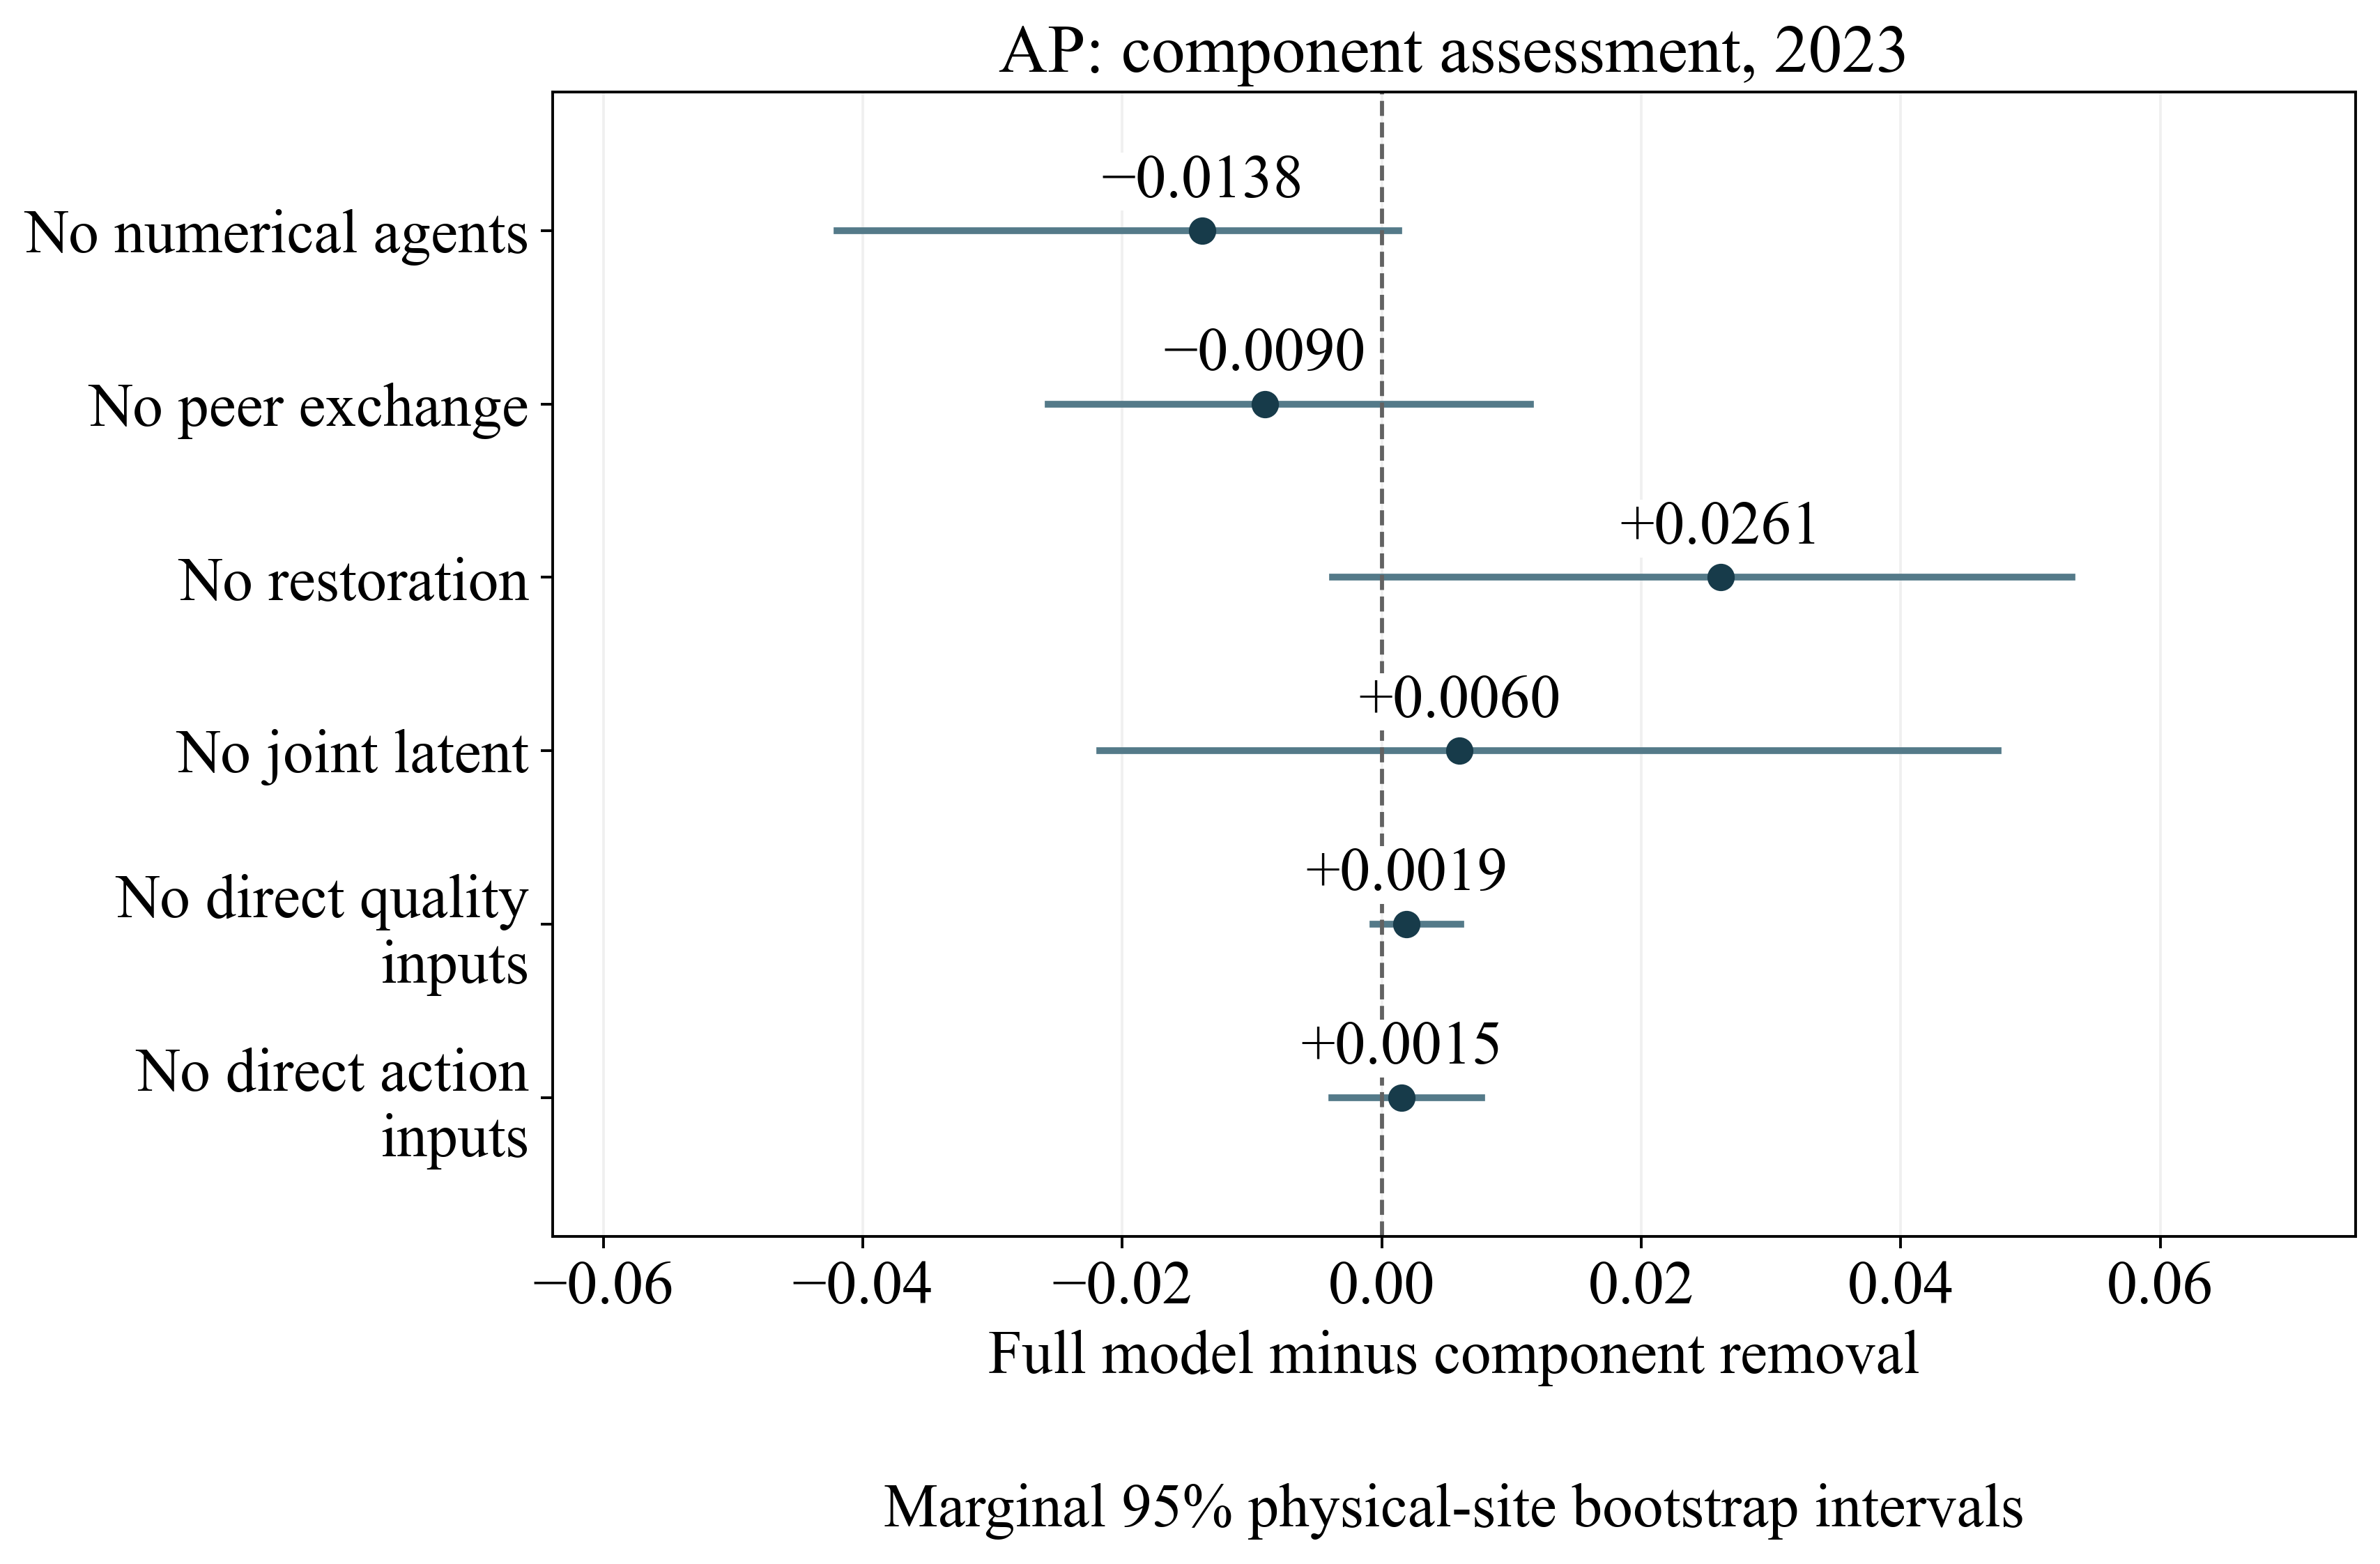

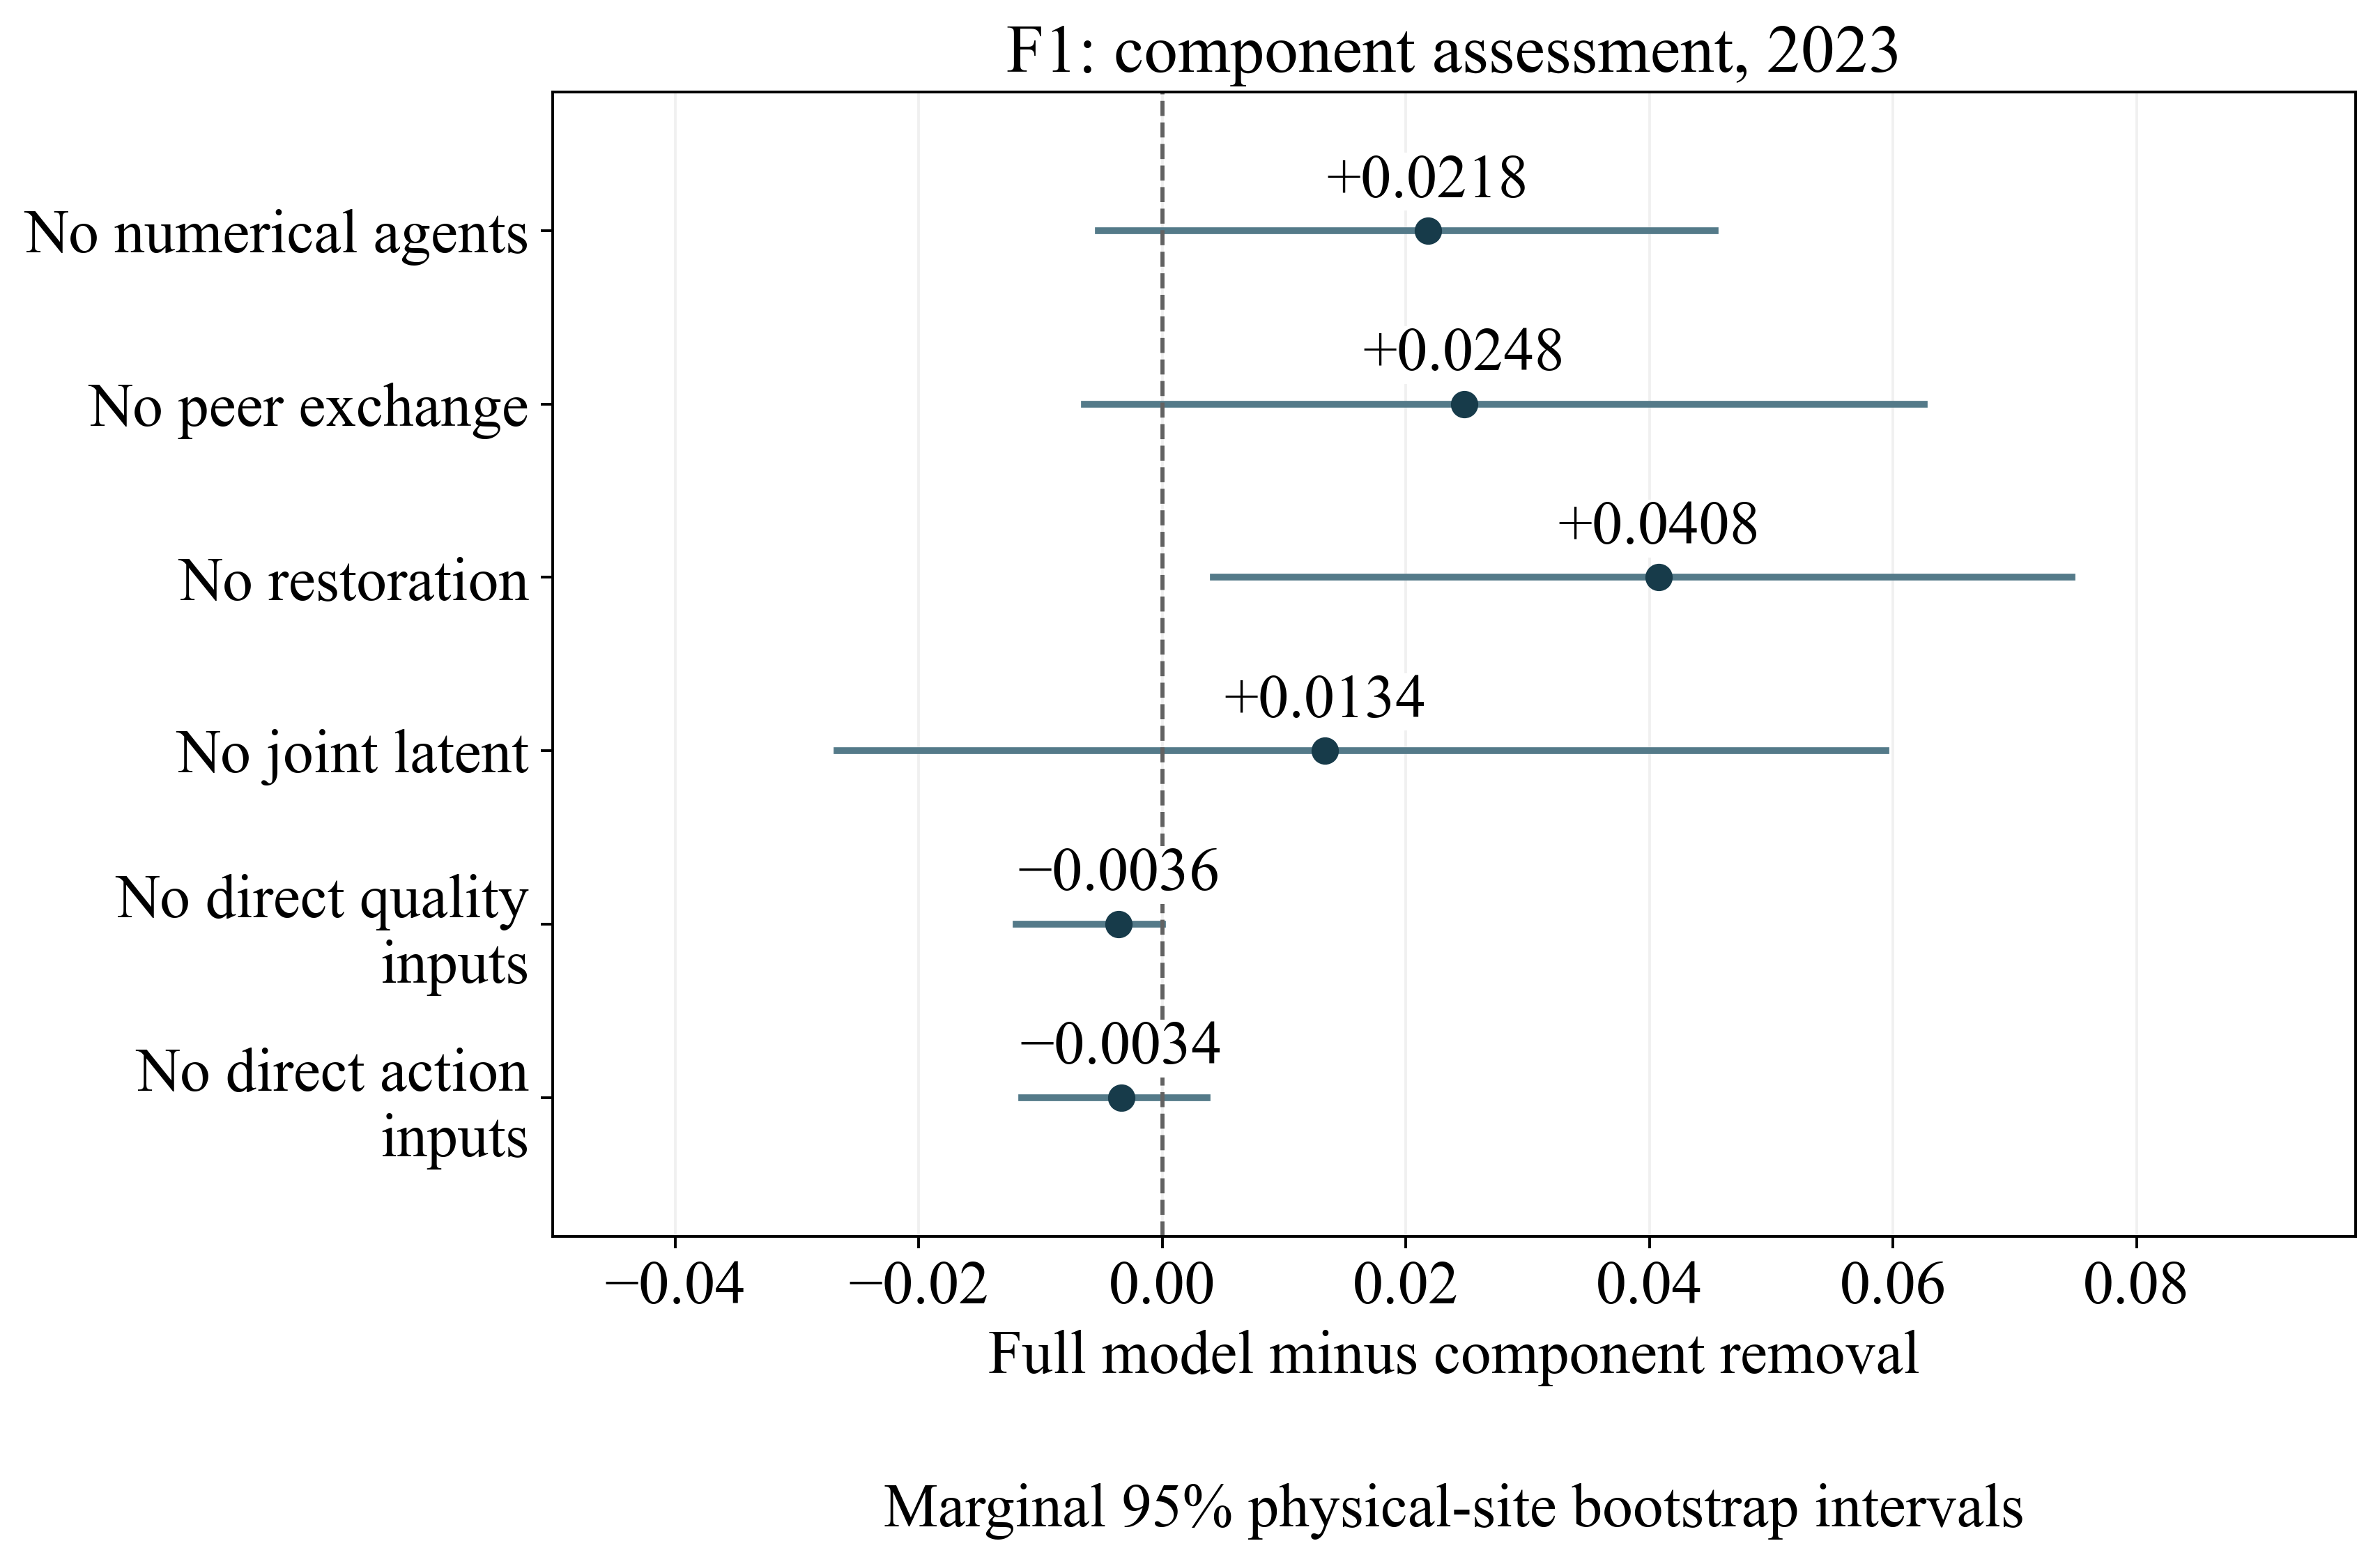

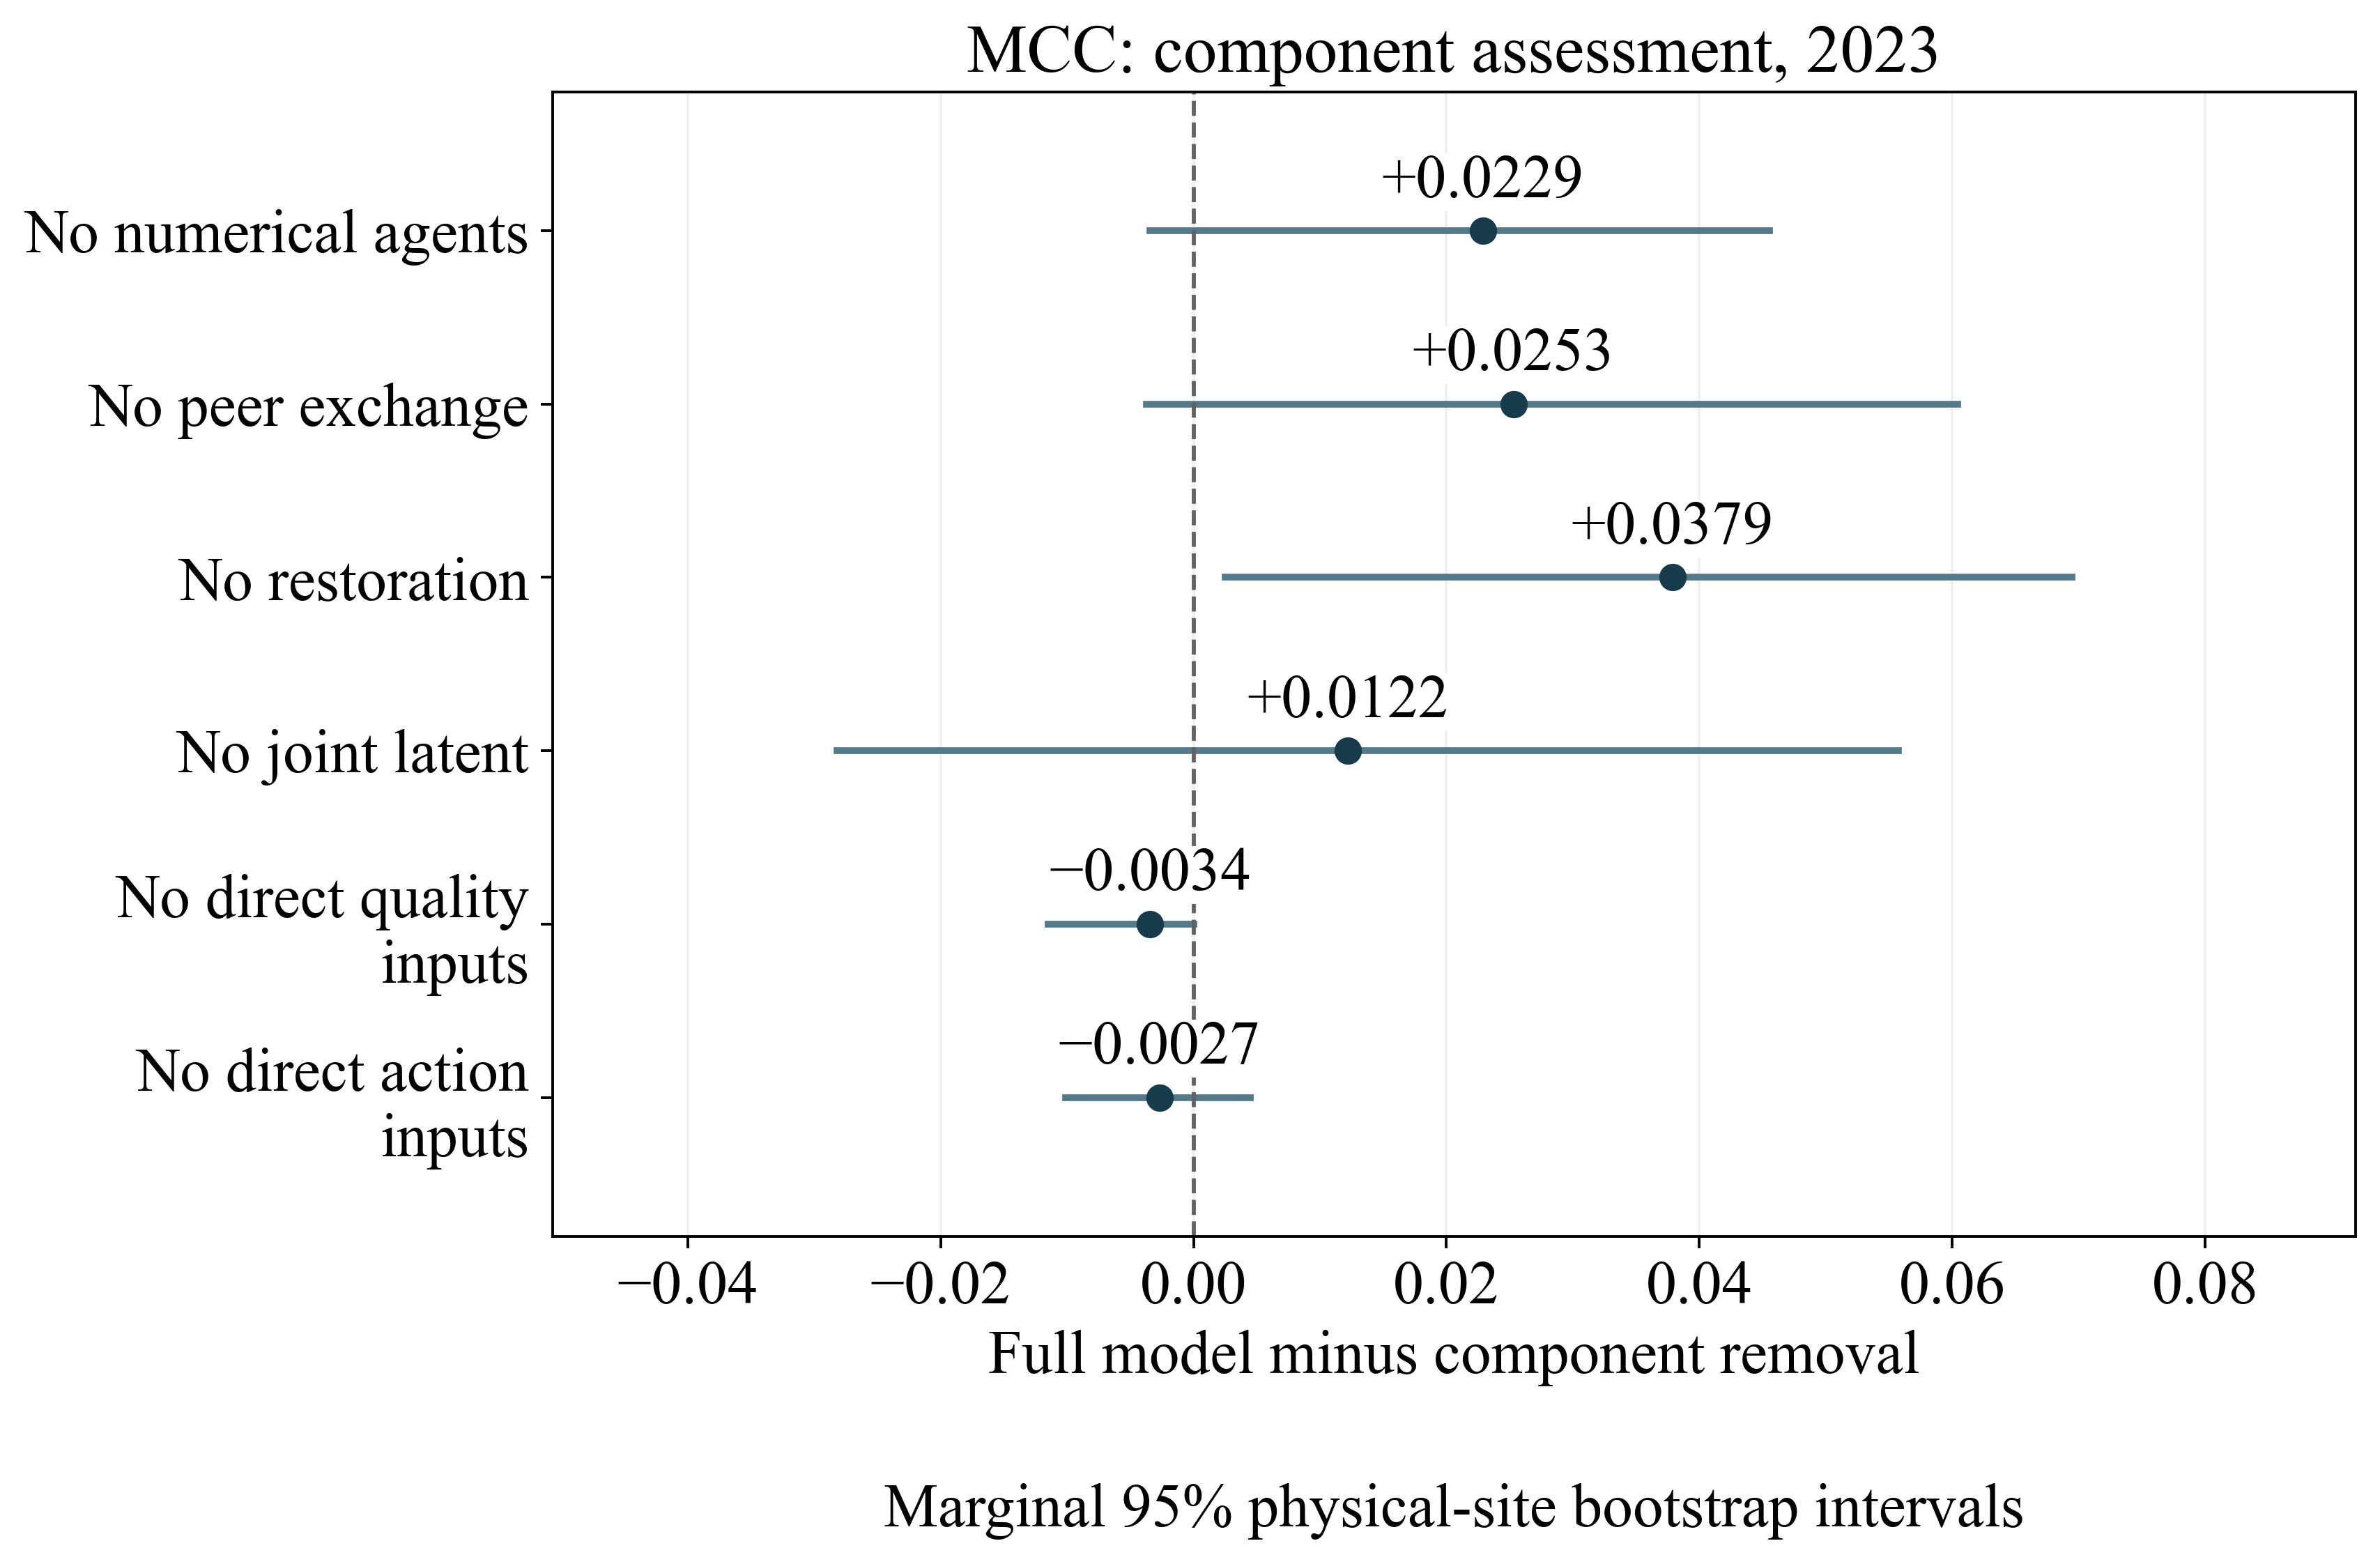

In [152]:
if REPLAY_EXISTING:
    for metric in ("ap", "f1", "mcc"):
        stem = OUTPUT_ROOT/"Figures"/COMPONENT_RUN_ID/("component_"+metric+"_contrasts")
        for suffix in (".png", ".pdf"):
            legacy_saved(stem.with_suffix(suffix))
        display(Image(filename=str(stem.with_suffix(".png"))))
else:
    component_contrast_figures(component_contrasts)


In [153]:
if REPLAY_EXISTING:
    component_completion = json.loads(legacy_saved(COMPONENT_MANIFESTS/"component_assessment_completion.json").read_text())
    for relative, digest in component_completion["artifact_sha256"].items():
        assert racf_hash(legacy_saved(relative)) == digest
    component_table(pd.DataFrame(component_completion["component_findings"]), "Preserved component evidence: benefits and limitations")
    display(Markdown("The saved component assessment was verified without artifact regeneration."))
else:
    component_completion = component_close_assessment(component_mean, component_contrasts, component_support, component_checks, component_routing)


**Preserved component evidence: benefits and limitations**

Removal,Assessment,Numerically_favours_full,Holm_supported_benefit,Numerically_favours_removal
No numerical agents,full_refit,"F1, MCC",None,AP
No peer exchange,full_refit,"F1, MCC",None,AP
No restoration,full_refit,"AP, F1, MCC",None,None
No temporal latent,readout_refit,"AP, F1, MCC",None,None
No direct quality inputs,readout_refit,AP,None,"F1, MCC"
No direct action inputs,readout_refit,AP,None,"F1, MCC"


## Three targeted configurations: registered extension

In [154]:
# Targeted study: immutable inputs and isolated output locations.
from pathlib import Path
import hashlib, json, zipfile
TARGETED_RUN_ID = "racf_targeted_20261014"
TARGETED_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / TARGETED_RUN_ID
TARGETED_MANIFESTS = OUTPUT_ROOT / "Manifests" / TARGETED_RUN_ID
TARGETED_TABLES = OUTPUT_ROOT / "Tables" / TARGETED_RUN_ID
TARGETED_FIGURES = OUTPUT_ROOT / "Figures" / TARGETED_RUN_ID
for directory in (TARGETED_ROOT, TARGETED_MANIFESTS, TARGETED_TABLES, TARGETED_FIGURES):
    directory.mkdir(parents=True, exist_ok=True)

def targeted_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(2**20), b""):
            digest.update(block)
    return digest.hexdigest()

def targeted_json(data, path):
    payload = json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False)
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".partial")
    temporary.write_text(payload + "\n")
    temporary.replace(path)
    return path

TARGETED_TASK = OUTPUT_ROOT / "RACFNet_three_targeted_configurations.md"
assert TARGETED_TASK.is_file()
parent_focus = OUTPUT_ROOT / "Manifests/racf_focus_20261013_170443"
parent_components = OUTPUT_ROOT / "Manifests/racf_components_20261014_002554"
protection_path = TARGETED_MANIFESTS/"protected_inputs.json"
protection = json.loads(legacy_saved(protection_path).read_text())
assert protection["task_sha256"] == targeted_hash(TARGETED_TASK)
targeted_protected = dict(protection["files"])
targeted_mismatches = [path for path, expected in targeted_protected.items()
    if not Path(path).is_file() or targeted_hash(path) != expected]
assert not targeted_mismatches, targeted_mismatches[:5]
for path in LEGACY_REPLAY_HASHES:
    legacy_saved(path)
editable_paths = {str((REPO_ROOT / "notebooks"/name).resolve()) for name in
    ["05_proposed_model_development_and_ablations.ipynb", "06_frozen_evaluation_statistics_and_publication_results.ipynb"]}
archive = REPO_ROOT / "notebooks/Archieves" / (TARGETED_RUN_ID + "_entry.zip")
if not archive.exists():
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as backup:
        for name in sorted(editable_paths):
            backup.write(name, Path(name).name)
display(Markdown("**Targeted-study preflight passed.** " + str(len(targeted_protected)) +
    " protected files verified; historical checkpoints and results are unchanged."))


In [155]:
# Registered design; no candidate outcomes have been inspected.
TARGETED_PROTOCOL = {
    "run_id": TARGETED_RUN_ID, "task_sha256": targeted_hash(TARGETED_TASK),
    "candidate_ids": ["RACF-E36", "RACF-PRank", "RACF-CGate"],
    "public_model_name": "RACF-Net", "initial_training_seed": 42,
    "replication_training_seeds": [137, 2026],
    "training_years": [2019, 2020, 2021], "selection_year": 2022,
    "posthoc_evaluation_year": 2023, "final_calibration_year": 2024,
    "historical_replay_years": [2025, 2026], "previously_disclosed_outcomes": True,
    "scenarios": ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30",
                  "power_noise_1", "power_noise_2"],
    "corruption_seeds": [2026, 137, 42],
    "deterministic_scenario_single_stream": ["clean", "weather_unavailable"],
    "aggregation": "stream mean within scenario; equal weights across six scenarios",
    "acceptance": {"tolerance": 1e-6, "primary_policy": "f1",
        "not_lower": ["mean_F1", "mean_MCC", "mean_Event_recall", "clean_AP"],
        "not_higher": ["mean_False_alarms_per_1000"], "reference": "frozen parent",
        "objective": "maximum mean AP among admissible candidates",
        "practical_AP_target_over_strongest_control": 0.01,
        "tie_AP_distance": 0.002, "tie_order": ["p95_latency", "checkpoint_bytes"],
        "no_admissible_candidate": "retain frozen parent; no additional search"},
    "agent_contract": {"predictors": 51, "neighbors_max": 3, "rounds": 1,
        "ridge_alpha": 10.0, "verifier": False, "evidence_channels": 36,
        "reliability": "clipped positive audit gain times available donor-origin coverage",
        "audit_unsupported": "zero model reliability with explicit availability"},
    "A_head": {"trees": 800, "leaves": 15, "learning_rate": 0.03,
        "min_child_samples": 50, "l2": 10.0, "positive_weight": 1,
        "clean_training_mass": 0.75, "maximum_threads": 4,
        "observation_encoder": "frozen compatible no-agents", "event_finetuning": False},
    "meta_head": {"B_hidden": 16, "C_hidden": 8, "activation": "GELU",
        "optimizer": "AdamW", "learning_rate": 0.0005, "weight_decay": 0.01,
        "maximum_epochs": 20, "gradient_clip": 1.0, "smooth_AP_weight": 0.2,
        "temperature_logits": 0.1, "positive_block_max": 4, "comparator_block_max": 8192,
        "BCE_normalization": "mean over all eligible observations in each OOF case",
        "AP_normalization": "mean over positive anchors against all same-case observations",
        "case_loss_aggregation": "stream mean within scenario; equal scenario and OOF-block weights",
        "epoch_selection": "fit 2020 OOF; exact full-cohort mean AP on 2021 OOF; earliest tie",
        "final_meta_refit": "2020 and 2021 OOF; fixed selected epoch count"},
    "B_score_map": {"maximum_local_logit_correction": 0.5,
        "correction": "0.5 * (2 * sigmoid(head) - 1)", "initial_output": 0.0,
        "policy": "inherit both parent boundaries and monotonic calibrator",
        "boundary_arithmetic": "float64; minimum accepting representable raw score",
        "endpoints": "exact boundaries unchanged; interior nextafter clamp",
        "historical_status": "calibration-year-dependent post-processing"},
    "C_mixture": {"initial_full_weight": 0.5, "mix_space": "probability",
        "bases": ["full parent", "matched no-agents"], "both_base_costs_included": True},
    "chronology": {"OOF": [[2019, 2020], [[2019, 2020], 2021]],
        "embargo_days": 30, "episode_purge": True,
        "B_2020_policy": "inner-2019 chronological calibration; disclose sparse event support",
        "B_2021_policy": "clean 2020 base OOF calibration",
        "selection_2022_policy": "clean 2021 past-only predictions; never in-sample full-model scores",
        "C_2021_calibration": "temporally prior but adapted by 2021 epoch selection",
        "calibration_transfer": "disclose OOF-to-refit shift",
        "no_fold_latent_pooling": True},
    "controls": {"A": ["same readout without evidence", "same evidence without peer exchange"],
        "B": ["parent", "raw-feature quality refiner", "no-peer refiner", "full no-agents"],
        "C": ["fixed parent/no-agents mixture", "quality-score gate without agent messages",
              "fully non-agent LightGBM/TCN gate", "fixed LightGBM/TCN mixture"]},
    "statistics": {"unit": "physical site", "paired": True, "replicates": 2000,
        "bootstrap_seed": 137, "confidence": 0.95, "multiplicity": "Holm",
        "primary_AP_comparators": ["parent", "no_agents", "LightGBM", "TCN", "CatBoost",
            "fixed_parent_no_agents", "fixed_LightGBM_TCN"],
        "secondary_quality_family": "F1 and MCC against all primary comparators",
        "secondary_component_family": "AP/F1/MCC for no agents, no exchange, new mechanism off",
        "periods": "joint equal-year historical 2025/2026 primary; per-year estimates descriptive",
        "development_inference": "exploratory; no independent confirmation claim",
        "degenerate_resamples": "record and exclude from undefined metric; report rate"},
    "benchmark": {"batches": [1, 128, 1024], "warmups": 2, "repeats": 10,
        "scope": "raw input to calibrated probability and both decisions; all bases and IPC",
        "modes": ["resident", "cold_start"], "report": ["median", "p95"],
        "p95_ratio_target": 1.5, "target_violation": "report tradeoff; do not conceal result"},
    "completion_requires": ["diagnostics", "A/B/C and controls", "seed assessment",
        "matched removals", "benchmark", "selection", "freeze", "NB06 replay", "clean-kernel audit"]
}
targeted_protocol_path = TARGETED_MANIFESTS / "registered_protocol.json"
if targeted_protocol_path.exists():
    assert json.loads(targeted_protocol_path.read_text()) == TARGETED_PROTOCOL
else:
    targeted_json(TARGETED_PROTOCOL, targeted_protocol_path)
assert TARGETED_PROTOCOL["candidate_ids"] == ["RACF-E36", "RACF-PRank", "RACF-CGate"]
display(Markdown("**Protocol registered before fitting.** Three fixed candidates; six scenarios; "
    "past-only selection thresholds; matched controls and explicit non-acceptance outcome."))

In [156]:
# Shared immutable bases and compact publication output.
def targeted_table(frame, title, filename):
    numeric = frame.select_dtypes(include=[np.number]).to_numpy(dtype=float)
    assert np.isfinite(numeric).all(), "Nonfinite values require an explicit scientific status"
    frame.to_csv(TARGETED_TABLES / (filename + ".csv"), index=False)
    display(Markdown("**" + title + "**"))
    display(frame.style.format(precision=5).hide(axis="index"))


targeted_freeze = json.loads((parent_focus / "model_freeze.json").read_text())
targeted_parent_record = next(row for row in targeted_freeze["models"] if row["model"] == "RACF-Net")
targeted_parent_path = OUTPUT_ROOT / targeted_parent_record["checkpoint"]
assert targeted_hash(targeted_parent_path) == targeted_parent_record["checkpoint_sha256"]
targeted_parent = joblib.load(targeted_parent_path)
targeted_no_agents_path = OUTPUT_ROOT / "Artifacts/Runs/racf_components_20261014_002554/Models/no_agents.joblib"
targeted_no_agents_record = json.loads(targeted_no_agents_path.with_suffix(".json").read_text())
assert targeted_hash(targeted_no_agents_path) == targeted_no_agents_record["checkpoint_sha256"]
targeted_no_agents = joblib.load(targeted_no_agents_path)
assert not targeted_no_agents.config["agents_enabled"]
assert targeted_parent.config["rounds"] == 1 and not targeted_parent.config["verifier"]
assert targeted_parent.config["messages"] == 24 and len(targeted_parent.expert_feature_names) == 365
assert len(targeted_no_agents.expert_feature_names) == 365
assert targeted_parent.adapter.columns == targeted_no_agents.adapter.columns == schema["feature_names"]
targeted_train = np.asarray(focus_train, dtype=int)
assert metadata.iloc[targeted_train].date.dt.year.isin([2019, 2020, 2021]).all()
targeted_training_ids_sha = hashlib.sha256(chr(10).join(metadata.iloc[targeted_train].observation_id).encode()).hexdigest()
assert targeted_training_ids_sha == COMPONENT_PLAN["training_ids_sha256"]
targeted_bindings = {
    "parent": {"path": str(targeted_parent_path.relative_to(OUTPUT_ROOT)),
        "sha256": targeted_hash(targeted_parent_path)},
    "no_agents": {"path": str(targeted_no_agents_path.relative_to(OUTPUT_ROOT)),
        "sha256": targeted_hash(targeted_no_agents_path)},
    "training_ids_sha256": targeted_training_ids_sha,
    "training_rows": len(targeted_train), "feature_names": list(schema["feature_names"]),
    "training_seed": 42, "shared_source_sha256": racf_definition_fingerprint()
}
targeted_json(targeted_bindings, TARGETED_MANIFESTS / "base_bindings.json")
targeted_table(pd.DataFrame([
    {"Base": "RACF-Net reference", "Predictors": 51, "Expert_inputs": 365, "Training_rows": len(targeted_train), "Frozen": True},
    {"Base": "Matched no-agents", "Predictors": 51, "Expert_inputs": 365, "Training_rows": len(targeted_train), "Frozen": True}
]), "Verified reusable bases; no new fitting", "base_contract")

**Verified reusable bases; no new fitting**

Base,Predictors,Expert_inputs,Training_rows,Frozen
RACF-Net reference,51,365,87425,True
Matched no-agents,51,365,87425,True


### Diagnostic reconstruction before new fitting

In [157]:
def targeted_verify_file(relative, digest):
    path = OUTPUT_ROOT / relative
    assert targeted_hash(path) == digest, relative
    return path


def targeted_read_prediction(relative, digest, year):
    pred = pd.read_parquet(targeted_verify_file(relative, digest)).reset_index(drop=True)
    split = "forward_2022" if year == 2022 else "development"
    indices = np.load(SHARED_DATASET_ROOT / f"Splits/{split}_evaluation.npy")
    cohort = metadata.iloc[indices].reset_index(drop=True)
    for name in ["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]:
        pd.testing.assert_series_equal(pred[name], cohort[name], check_names=False, check_dtype=False)
    assert pred.observation_id.is_unique and pd.to_datetime(pred.date).dt.year.eq(year).all()
    assert np.isfinite(pred.raw_score).all() and pred.raw_score.between(0, 1).all()
    return pred


def targeted_replay_metrics(pred, calibration_record, context):
    calibration = RACFCalibration.from_dict(calibration_record)
    evaluated = pred.copy()
    evaluated["probability"] = calibration.predict(pred.raw_score.to_numpy())
    for policy, values in calibration.decisions(pred.raw_score.to_numpy()).items():
        evaluated["decision_" + policy] = values
    rows = []
    for policy in ["f1", "budget"]:
        metrics = racf_metrics(evaluated, policy)
        assert metrics["Undefined_metrics"] == "None", metrics["Undefined_metrics"]
        rows.append({**context, **metrics,
            "Calibrated_AP": average_precision_score(evaluated.target, evaluated.probability),
            "Threshold": getattr(calibration, "threshold_" + policy)})
    return rows

In [158]:
targeted_focus_registry = json.loads((parent_focus / "result_registry.json").read_text())
targeted_selection = json.loads((parent_focus / "architecture_selection.json").read_text())
targeted_prior_protocol = json.loads((parent_focus / "focused_protocol.json").read_text())
targeted_selection_rel = "Tables/racf_focus_20261013_170443/selection_scores.csv"
targeted_saved_selection = pd.read_csv(targeted_verify_file(targeted_selection_rel,
    targeted_focus_registry[targeted_selection_rel]))
targeted_selected_bindings = {r["model"]: r for r in targeted_selection["selected_models"]}
targeted_focus_rows = []
for model, binding in targeted_selected_bindings.items():
    cal_rel = f"Artifacts/Runs/{FOCUS_RUN_ID}/Calibration/{model.replace('-', '')}_2022.json"
    cal_record = json.loads(targeted_verify_file(cal_rel, targeted_focus_registry[cal_rel]).read_text())
    source = cal_record["fit_audit"]["source"]
    assert source["year"] == 2022 and source["seed"] == 42
    assert source["checkpoint_sha256"] == binding["checkpoint_sha256"]
    targeted_verify_file(binding["checkpoint"], binding["checkpoint_sha256"])
    calibration_source = targeted_read_prediction(source["prediction_file"], source["prediction_sha256"], 2022)
    cases = targeted_saved_selection.loc[targeted_saved_selection.Model.eq(model)]
    assert len(cases) == 6
    for case in cases.itertuples():
        pred = targeted_read_prediction(case.Prediction_file,
            targeted_focus_registry[case.Prediction_file], 2022)
        parent_binding = targeted_prior_protocol["models"][model]
        expected = {"seed": 42, "model_seed": 42, "noise_seed": 2026, "year": 2022,
            "scenario": case.Scenario, "model": model, "scope": "temporal",
            "checkpoint_sha256": parent_binding["checkpoint_sha256"],
            "protocol_sha256": targeted_selection["protocol_sha256"],
            "producer_sha256": targeted_selection["scoring_source_sha256"]}
        for name, value in expected.items():
            assert pred[name].eq(value).all(), name
        cohort_hash = hashlib.sha256(chr(10).join(pred.observation_id.astype(str)).encode()).hexdigest()
        assert pred.cohort_sha256.eq(cohort_hash).all()
        if "parent_prediction" in pred:
            assert pred.parent_prediction.nunique() == 1
            targeted_verify_file(pred.parent_prediction.iloc[0], pred.parent_prediction_sha256.iloc[0])
        if case.Scenario == "clean":
            np.testing.assert_array_equal(pred.raw_score, calibration_source.raw_score)
        np.testing.assert_allclose(average_precision_score(pred.target, pred.raw_score), case.AP, rtol=0, atol=1e-14)
        targeted_focus_rows += targeted_replay_metrics(pred, cal_record, {
            "Assessment": "Calibration-year diagnostic; not candidate selection", "Year": 2022,
            "Model": model, "Scenario": case.Scenario, "Training_seed": 42, "Corruption_seed": 2026,
            "Prediction_file": case.Prediction_file, "Cohort_sha256": cohort_hash})
targeted_focus_metrics = pd.DataFrame(targeted_focus_rows)
assert len(targeted_focus_metrics) == 48
targeted_focus_metrics.to_csv(TARGETED_TABLES / "diagnostic_2022_metrics.csv", index=False)
display(Markdown("**2022 reconstruction passed:** 24 verified prediction files, both policies, "
    "ordered cohort identities, checkpoint ancestry and exact clean-score equivalence. "
    "These thresholds were calibrated on 2022 and will not be used for new candidate selection."))

In [159]:
targeted_component_completion = json.loads((parent_components / "component_assessment_completion.json").read_text())
targeted_component_registry = targeted_component_completion["artifact_sha256"]
targeted_component_rows = []
for variant in COMPONENT_VARIANTS:
    variant_id = variant["id"]
    report_rel = f"Manifests/{COMPONENT_RUN_ID}/{variant_id}_evaluation.json"
    report = json.loads(targeted_verify_file(report_rel, targeted_component_registry[report_rel]).read_text())
    assert report["plan_sha256"] == targeted_component_completion["plan_sha256"]
    assert report["source_sha256"] == targeted_component_completion["training_source_sha256"]
    cal_record = report["calibration"]
    assert cal_record["fit_audit"]["source"]["year"] == 2022
    checkpoint = report["model"]
    targeted_verify_file(checkpoint["checkpoint"], checkpoint["checkpoint_sha256"])
    for scenario, artifact in report["predictions"].items():
        pred = targeted_read_prediction(artifact["path"], artifact["sha256"], 2023)
        cohort_hash = hashlib.sha256(chr(10).join(pred.observation_id.astype(str)).encode()).hexdigest()
        if variant_id == "full":
            expected = {"model_seed": 42, "seed": 42, "noise_seed": 2026, "year": 2023,
                "scenario": scenario, "checkpoint_sha256": checkpoint["checkpoint_sha256"],
                "cohort_sha256": cohort_hash}
            for name, value in expected.items():
                assert pred[name].eq(value).all(), name
        else:
            lineage_rel = str(Path(artifact["path"]).with_suffix(".json"))
            lineage = json.loads(targeted_verify_file(lineage_rel, targeted_component_registry[lineage_rel]).read_text())
            assert lineage["sha256"] == artifact["sha256"]
            expected = {"checkpoint_sha256": checkpoint["checkpoint_sha256"],
                "source_sha256": targeted_component_completion["training_source_sha256"],
                "plan_sha256": targeted_component_completion["plan_sha256"],
                "year": 2023, "scenario": scenario, "noise_seed": 2026, "ids_sha256": cohort_hash}
            assert lineage["signature"] == expected
            assert checkpoint["signature"]["variant"] == variant
        targeted_component_rows += targeted_replay_metrics(pred, cal_record, {
            "Assessment": "Post hoc component diagnostic; prior-year calibration", "Year": 2023,
            "Model": variant["label"], "Scenario": scenario, "Training_seed": 42, "Corruption_seed": 2026,
            "Prediction_file": artifact["path"], "Cohort_sha256": cohort_hash})
targeted_component_metrics = pd.DataFrame(targeted_component_rows)
assert len(targeted_component_metrics) == 84
targeted_component_metrics.to_csv(TARGETED_TABLES / "diagnostic_2023_component_metrics.csv", index=False)
targeted_diagnostic_integrity = {"focus_cases": 24, "component_cases": 42,
    "policies": ["f1", "budget"], "ordered_cohorts_verified": True,
    "checkpoint_calibration_seed_lineage_verified": True,
    "component_year": 2023, "component_calibration_year": 2022}
targeted_json(targeted_diagnostic_integrity, TARGETED_MANIFESTS / "diagnostic_integrity.json")

In [160]:
# Mechanism probes use training observations only; no classification model is fitted.
targeted_probe_indices = targeted_train[np.linspace(0, len(targeted_train)-1, 128, dtype=int)]
targeted_mechanism_rows = []
targeted_probe_prepared = []
for scenario in TARGETED_PROTOCOL["scenarios"]:
    raw, frame, _ = racf_corrupt(sequences[targeted_probe_indices], features.iloc[targeted_probe_indices],
        metadata.iloc[targeted_probe_indices], scenario, 2026)
    prepared = targeted_parent.adapter.prepare(raw, frame, metadata.iloc[targeted_probe_indices])
    messages, trace = targeted_parent.agents.transform(prepared)
    selected = trace["repair_executed"]
    error = np.max(np.abs(trace["expected"][selected] - trace["repair_message"][selected]), initial=0.0)
    assert error < 1e-10
    verifier_columns = [j for j, name in enumerate(targeted_parent.message_names) if "verification" in name]
    assert len(verifier_columns) == 6 and np.all(messages[:, verifier_columns] == 0)
    zero_weight = selected & ~trace["original_mask"] & (trace["quality"] == 0)
    targeted_mechanism_rows.append({"Scenario": scenario,
        "Repair_roles": int(selected.sum()), "Maximum_reuse_difference": float(error),
        "Missing_repairs_with_zero_original_weight": int(zero_weight.sum()),
        "Positive_residuals": int((trace["residual"] > 0).sum()),
        "Negative_residuals": int((trace["residual"] < 0).sum())})
    targeted_probe_prepared.append(prepared)
targeted_mechanism_frame = pd.DataFrame(targeted_mechanism_rows)
targeted_table(targeted_mechanism_frame.drop(columns="Maximum_reuse_difference").rename(columns={
        "Repair_roles": "Repair roles", "Missing_repairs_with_zero_original_weight": "Zero-weight repairs",
        "Positive_residuals": "Positive residuals", "Negative_residuals": "Negative residuals"}),
    "Training-window mechanism diagnosis; 128 windows per condition", "mechanism_diagnosis")
targeted_json({"expectation_repair_maximum_difference": float(targeted_mechanism_frame.Maximum_reuse_difference.max()),
    "constant_verifier_channel_names": [targeted_parent.message_names[j] for j in verifier_columns],
    "interpretation": "Information-path observations, not causal explanations of AP changes",
    "probe_training_ids": metadata.iloc[targeted_probe_indices].observation_id.tolist()},
    TARGETED_MANIFESTS / "one_round_reuse_diagnostic.json");

**Training-window mechanism diagnosis; 128 windows per condition**

Scenario,Repair roles,Zero-weight repairs,Positive residuals,Negative residuals
clean,198,186,3454,2633
weather_unavailable,1078,1066,2887,1852
power_mcar_10,658,309,2459,2189
power_mcar_30,698,317,2143,1984
power_noise_1,686,189,3385,2698
power_noise_2,698,186,3379,2708


### Separate observation quality from reconstruction reliability

In [161]:
E36_GROUPS = ("power", "weather", "context")
E36_STATS = ("original_quality_weighted_mean", "reconstruction_reliability_weighted_mean",
    "signed_residual_mean", "absolute_residual_mean", "signed_maximum_absolute_residual",
    "original_observed_fraction", "observed_quality_mean", "applied_reconstruction_reliability_mean",
    "agent_reconstruction_fraction", "donor_origin_coverage")
E36_RESIDUALS = ("power_pct", "delta_1d", "delta_3d", "delta_7d")
E36_CORRECTIONS = ("delta_1d", "power_mean_7d")


def targeted_e36_weighted(values, weights):
    denominator = weights.sum(axis=1)
    result = np.zeros(len(values), dtype=np.float64)
    np.divide((values * weights).sum(axis=1), denominator, out=result, where=denominator > 0)
    return result


def targeted_e36_coverage(original, donor_groups):
    coverage = np.zeros((len(original), len(donor_groups)), dtype=np.float64)
    for j, groups in enumerate(donor_groups):
        if groups:
            coverage[:, j] = np.column_stack([original[:, group].any(axis=1) for group in groups]).mean(axis=1)
    return coverage


def targeted_e36_audit(team):
    supported, allowed = np.zeros(51, bool), np.zeros(51, bool)
    gain, reference = np.zeros(51), np.ones(51)
    audit = team.tool_audit.copy()
    if team.fit_audit.get("chronological_support", False) and len(audit):
        if "feature" in audit:
            assert not audit.feature.duplicated().any()
            audit = audit.set_index("feature").reindex(team.columns)
        else:
            assert audit.feature_index.tolist() == list(range(51))
        count, baseline, error = [pd.to_numeric(audit[name], errors="coerce").to_numpy(float)
            for name in ("heldout_observed_n", "training_median_mse", "masked_peer_mse")]
        scale = np.asarray(team.residual_scale, dtype=float)
        assert scale.shape == (51,)
        supported = (np.isfinite(count) & (count >= 64) & np.isfinite(baseline) & (baseline > 1e-8)
            & np.isfinite(error) & (error >= 0) & np.isfinite(scale) & (scale > 0)
            & np.array([len(group) > 0 for group in team.neighbors]))
        reference[supported] = scale[supported]
        gain[supported] = np.clip((baseline[supported] - error[supported]) / baseline[supported], 0, 1)
        allowed = (supported & audit.repair_permitted.fillna(False).to_numpy(bool)
            & np.asarray(team.repair_allowed, bool) & (gain > 0))
    return supported, gain, allowed, reference

In [162]:
class TargetedAgentEvidence36:
    """Training-audited evidence with unchanged original observation provenance."""
    schema_version = "targeted-agent-evidence36"

    def __init__(self, team, peer_exchange=True):
        assert team.p == 51 and int(team.config.get("rounds", 1)) == 1
        assert float(team.config.get("ridge_alpha", 10.0)) == 10.0 and team.verifier is None
        assert max(map(len, team.neighbors), default=0) <= 3 and not team.fit_audit.get("labels_used", True)
        self.team, self.peer_exchange = team, bool(peer_exchange)
        self.columns = list(team.columns)
        self.groups = [np.asarray(group, dtype=int).copy() for group in team.groups]
        assert len(self.groups) == 3 and all(len(group) for group in self.groups)
        assert sorted(np.concatenate(self.groups).tolist()) == list(range(51))
        assert self.columns.index("power_pct") in self.groups[0]
        self.message_names = [f"{group}_{stat}" for group in E36_GROUPS for stat in E36_STATS]
        self.message_names += [f"signed_residual__{x}" for x in E36_RESIDUALS]
        self.message_names += [f"signed_agent_correction__{x}" for x in E36_CORRECTIONS]
        self.availability_names = [f"{group}_{kind}" for group in E36_GROUPS for kind in
            ("original_weight_available", "reconstruction_weight_available", "residual_available", "supported_donor_available")]
        self.availability_names += [f"residual_available__{x}" for x in E36_RESIDUALS]
        self.availability_names += [f"correction_applied__{x}" for x in E36_CORRECTIONS]
        assert len(set(self.message_names)) == 36 and len(set(self.availability_names)) == 18
        self.audit_supported, self.audit_gain, self.repair_allowed, self.reference_scale = targeted_e36_audit(team)
        origins = np.asarray(team.origins, dtype=object)
        self.donor_groups = [[np.asarray([k for k in peers if origins[k] == origin], dtype=int)
            for origin in dict.fromkeys(origins[peers].tolist())] for peers in team.neighbors]
        self.reuse_verified, self.reuse_maximum_error = False, None
        self.contract = {"schema_version": self.schema_version, "predictors": self.columns,
            "messages": self.message_names, "availability": self.availability_names,
            "group_indices": [group.tolist() for group in self.groups],
            "audit_gain": "clip((median_mse - masked_peer_mse) / median_mse, 0, 1)",
            "model_reliability": "audit_gain times originally observed donor-origin coverage",
            "coverage": "unique donor origins per agent; average over group agents",
            "scale_source": "chronological holdout inside authorized training cohort",
            "correction": "post-agent minus pre-agent internal standardized estimate",
            "confidence_status": "heuristic tool suitability; not a calibrated probability",
            "blend_policy": "inherited routing-quality blend; reliability weights reconstruction summary",
            "labels_used": False}

    def verify_reuse(self, prepared):
        assert len(prepared["raw_frame"]), "A nonempty reuse probe is required"
        state = targeted_e36_state(self, prepared, verify_reuse=True)
        self.reuse_verified = True
        self.reuse_maximum_error = state["reuse_maximum_error"]
        return {"verified": True, "maximum_error": self.reuse_maximum_error}

    def transform(self, prepared):
        if self.peer_exchange and not self.reuse_verified:
            raise RuntimeError("Verify one-round expectation reuse before inference")
        state = targeted_e36_state(self, prepared)
        messages, availability = targeted_e36_pack(self, state)
        return messages, availability, state

In [163]:
def targeted_e36_state(model, prepared, verify_reuse=False):
    team = model.team
    assert prepared["raw_frame"].columns.tolist() == model.columns
    assert prepared["repaired_frame"].columns.tolist() == model.columns
    raw = prepared["raw_frame"].to_numpy(dtype=float, na_value=np.nan)
    z, known, _, _ = racf_agent_standardize(raw, team.center, team.scale)
    original = np.asarray(prepared["original_mask"], bool).copy()
    actions = np.asarray(prepared["repair_mask"], bool)
    quality = np.asarray(prepared["quality"], float)
    assert original.shape == actions.shape == quality.shape == z.shape
    assert np.array_equal(original, known) and np.isfinite(quality).all()
    quality = np.clip(quality, 0, 1)
    original_quality = quality * original
    restored, restored_known, _, _ = racf_agent_standardize(
        prepared["repaired_frame"].to_numpy(dtype=float, na_value=np.nan), team.center, team.scale)
    initial = np.where(actions & restored_known, restored, z)
    initial_known = original | (actions & restored_known)
    routing_quality = quality * np.where(original, 1.0, np.where(actions, 0.5, 0.0))
    expected, coverage = np.zeros_like(z), np.zeros_like(z)
    calls, probe_calls, reuse_error = 0, 0, 0.0
    if model.peer_exchange and len(z):
        coverage = targeted_e36_coverage(original, model.donor_groups)
        for j, peers in enumerate(team.neighbors):
            expected[:, j] = np.clip(team.tools[j].predict(racf_agent_design(initial, initial_known, peers)), -12, 12)
            calls += 1
        if verify_reuse:
            for j, peers in enumerate(team.neighbors):
                selected = ((~original[:, j]) | (routing_quality[:, j] < 0.5)) & model.repair_allowed[j]
                if not selected.any():
                    selected = np.ones(len(z), bool)
                reference = np.clip(team.tools[j].predict(racf_agent_design(
                    initial[selected], initial_known[selected], peers)), -12, 12)
                probe_calls += 1
                reuse_error = max(reuse_error, float(np.max(np.abs(reference - expected[selected, j]), initial=0.0)))
                np.testing.assert_allclose(reference, expected[selected, j], rtol=1e-10, atol=1e-10)
    supported = model.audit_supported[None, :] & (coverage > 0) & model.peer_exchange
    residual_available = original & supported
    residual = np.where(residual_available, np.clip((z - expected) / model.reference_scale, -12, 12), 0.0)
    reliability = coverage * model.audit_gain[None, :]
    reliability *= model.repair_allowed[None, :] & model.peer_exchange
    applied = (((~original) | (routing_quality < 0.5)) & model.repair_allowed[None, :]
        & (reliability > 0) & model.peer_exchange & bool(team.config.get("repair", True)))
    reconstruction = np.where(applied, expected, 0.0)
    applied_reliability = np.where(applied, reliability, 0.0)
    weight = (1 - routing_quality) * applied
    belief = (1 - weight) * initial + weight * reconstruction
    correction = np.where(applied, belief - initial, 0.0)
    assert np.array_equal(original, prepared["original_mask"])
    return {"original": z, "original_mask": original, "original_quality": original_quality,
        "initial_belief": initial, "belief": belief, "expected": expected,
        "residual": residual, "residual_available": residual_available,
        "reconstruction": reconstruction, "model_reliability": reliability,
        "applied_reliability": applied_reliability, "applied": applied, "correction": correction,
        "donor_coverage": coverage, "audit_supported": np.broadcast_to(model.audit_supported, z.shape).copy(),
        "support_available": supported, "python_predict_calls": calls,
        "reuse_probe_python_calls": probe_calls, "logical_expectation_rows": len(z)*51 if model.peer_exchange else 0,
        "logical_repair_roles": int(applied.sum()), "additional_reconstruction_predict_calls": 0,
        "active_roles": 51 + applied.sum(axis=1), "reuse_maximum_error": reuse_error}

In [164]:
def targeted_e36_pack(model, state):
    blocks, bits = [], []
    for group in model.groups:
        z, observed = state["original"][:, group], state["original_mask"][:, group]
        oq = state["original_quality"][:, group]
        reconstruction, reliability = state["reconstruction"][:, group], state["applied_reliability"][:, group]
        residual, valid = state["residual"][:, group], state["residual_available"][:, group]
        applied = state["applied"][:, group]
        index = np.argmax(np.abs(residual), axis=1)
        signed_max = residual[np.arange(len(residual)), index]
        signed_max = np.where(valid.any(axis=1), signed_max, 0.0)
        blocks.extend([targeted_e36_weighted(z, oq),
            targeted_e36_weighted(reconstruction, reliability),
            targeted_e36_weighted(residual, valid.astype(float)),
            targeted_e36_weighted(np.abs(residual), valid.astype(float)), signed_max,
            observed.mean(axis=1), targeted_e36_weighted(oq, observed.astype(float)),
            targeted_e36_weighted(reliability, applied.astype(float)), applied.mean(axis=1),
            state["donor_coverage"][:, group].mean(axis=1)])
        bits.extend([oq.sum(axis=1) > 0, reliability.sum(axis=1) > 0,
            valid.any(axis=1), state["support_available"][:, group].any(axis=1)])
    for feature in E36_RESIDUALS:
        j = model.columns.index(feature)
        blocks.append(state["residual"][:, j])
        bits.append(state["residual_available"][:, j])
    for feature in E36_CORRECTIONS:
        j = model.columns.index(feature)
        blocks.append(state["correction"][:, j])
        bits.append(state["applied"][:, j])
    messages, availability = np.column_stack(blocks).astype(np.float32), np.column_stack(bits).astype(np.float32)
    assert messages.shape == (len(state["original"]), 36)
    assert availability.shape == (len(state["original"]), 18)
    assert np.isfinite(messages).all() and np.isfinite(availability).all()
    assert np.isin(availability, [0, 1]).all()
    assert ((state["active_roles"] >= 51) & (state["active_roles"] <= 102)).all()
    return messages, availability


def targeted_e36_training_column_audit(model, training_messages, training_bits):
    values = np.column_stack([training_messages, training_bits])
    names = model.message_names + model.availability_names
    assert values.shape[1] == len(names) and np.isfinite(values).all()
    return pd.DataFrame({"Feature": names,
        "Unique values": [len(np.unique(values[:, j])) for j in range(values.shape[1])],
        "Variance": values.astype(float).var(axis=0), "Constant": np.ptp(values, axis=0) == 0})


def targeted_select_prepared(prepared, rows):
    n = len(prepared["raw_frame"])
    result = {}
    for key, value in prepared.items():
        if isinstance(value, pd.DataFrame) and len(value) == n:
            result[key] = value.iloc[rows].copy()
        elif isinstance(value, np.ndarray) and value.ndim and len(value) == n:
            result[key] = value[rows].copy()
        else:
            result[key] = value
    return result

In [165]:
def targeted_e36_runtime_checks(team, prepared_probe):
    import pickle
    before = hashlib.sha256(pickle.dumps(team)).hexdigest()
    n = len(prepared_probe["raw_frame"])
    assert n >= 2
    np.testing.assert_allclose(targeted_e36_weighted(np.array([[2., 4.], [2., 4.]]),
        np.array([[.1, .2], [0., 0.]])), [10 / 3, 0])
    coverage = targeted_e36_coverage(np.array([[1, 1, 0], [1, 0, 1]], bool),
        [[np.array([0, 1]), np.array([2])]])
    np.testing.assert_array_equal(coverage[:, 0], [.5, 1.])
    model = TargetedAgentEvidence36(team)
    reuse = model.verify_reuse(prepared_probe)
    messages, bits, trace = model.transform(prepared_probe)
    assert trace["reuse_probe_python_calls"] == trace["additional_reconstruction_predict_calls"] == 0
    np.testing.assert_array_equal(trace["original_mask"], prepared_probe["original_mask"])
    np.testing.assert_array_equal(trace["original_quality"],
        np.clip(prepared_probe["quality"], 0, 1) * prepared_probe["original_mask"])
    reverse = np.arange(n-1, -1, -1)
    reverse_messages, reverse_bits, _ = model.transform(targeted_select_prepared(prepared_probe, reverse))
    np.testing.assert_allclose(reverse_messages[::-1], messages, rtol=1e-6, atol=1e-6)
    np.testing.assert_array_equal(reverse_bits[::-1], bits)
    parts = [model.transform(targeted_select_prepared(prepared_probe, rows))
        for rows in np.array_split(np.arange(n), 2)]
    np.testing.assert_allclose(np.concatenate([part[0] for part in parts]), messages, rtol=1e-6, atol=1e-6)
    np.testing.assert_array_equal(np.concatenate([part[1] for part in parts]), bits)
    restored = pickle.loads(pickle.dumps(model))
    saved_messages, saved_bits, _ = restored.transform(prepared_probe)
    np.testing.assert_array_equal(saved_messages, messages)
    np.testing.assert_array_equal(saved_bits, bits)
    assert hashlib.sha256(pickle.dumps(team)).hexdigest() == before
    return model, {"exact_weight_denominator": True, "origin_collapsed_coverage": True,
        "batch_permutation_and_save_load": True, "original_team_unchanged": True,
        "reuse": reuse}


def targeted_e36_edge_checks(model, prepared_probe):
    import copy
    n = len(prepared_probe["raw_frame"])
    absent = targeted_select_prepared(prepared_probe, np.arange(n))
    for key in ("raw_frame", "repaired_frame"):
        absent[key] = pd.DataFrame(np.full((n, 51), np.nan),
            columns=prepared_probe[key].columns, index=prepared_probe[key].index)
    absent["original_mask"] = np.zeros((n, 51), bool)
    absent["repair_mask"] = np.zeros((n, 51), bool)
    absent["quality"] = np.zeros((n, 51))
    values, bits, trace = model.transform(absent)
    np.testing.assert_array_equal(values, np.zeros((n, 36)))
    np.testing.assert_array_equal(bits, np.zeros((n, 18)))
    assert not trace["applied"].any() and not trace["original_mask"].any()
    no_peer = TargetedAgentEvidence36(model.team, peer_exchange=False)
    _, _, state = no_peer.transform(prepared_probe)
    assert state["python_predict_calls"] == 0 and not state["applied"].any()
    assert not state["residual_available"].any()
    unsupported_team = copy.deepcopy(model.team)
    unsupported_team.fit_audit["chronological_support"] = False
    unsupported = TargetedAgentEvidence36(unsupported_team)
    unsupported.verify_reuse(prepared_probe)
    _, _, state = unsupported.transform(prepared_probe)
    assert not unsupported.audit_supported.any() and not state["model_reliability"].any()
    assert not state["applied"].any()
    _, _, signed = model.transform(prepared_probe)
    group = model.groups[0]
    signed["residual"][:, group] = 0
    signed["residual_available"][:, group] = False
    signed["residual"][:, group[0]], signed["residual"][:, group[1]] = -8, 2
    signed["residual_available"][:, group[:2]] = True
    values, _ = targeted_e36_pack(model, signed)
    np.testing.assert_array_equal(values[:, model.message_names.index("power_signed_maximum_absolute_residual")], -8*np.ones(n))
    np.testing.assert_array_equal(values[:, model.message_names.index("power_signed_residual_mean")], -3*np.ones(n))
    return {"all_missing": True, "no_peer": True, "unsupported_audit": True, "signed_residuals": True}

In [166]:
targeted_e36_checks = []
for prepared in targeted_probe_prepared:
    checked_model, runtime_checks = targeted_e36_runtime_checks(targeted_parent.agents, prepared)
    targeted_e36_checks.append({"runtime": runtime_checks,
        "edges": targeted_e36_edge_checks(checked_model, prepared)})
targeted_evidence = checked_model
targeted_evidence_no_peer = TargetedAgentEvidence36(targeted_parent.agents, peer_exchange=False)
targeted_e36_check_path = targeted_json({"cases": targeted_e36_checks,
    "parent_checkpoint_sha256": targeted_bindings["parent"]["sha256"],
    "training_ids_sha256": targeted_training_ids_sha}, TARGETED_MANIFESTS / "evidence36_invariants.json")
targeted_e36_contract_path = targeted_json(targeted_evidence.contract, TARGETED_MANIFESTS / "evidence36_contract.json")
targeted_train_messages = np.empty((len(targeted_train), 36), dtype=np.float32)
targeted_train_availability = np.empty((len(targeted_train), 18), dtype=np.float32)
for start in range(0, len(targeted_train), 1024):
    rows = targeted_train[start:start+1024]
    prepared = targeted_parent.adapter.prepare(sequences[rows], features.iloc[rows], metadata.iloc[rows])
    messages, bits, _ = targeted_evidence.transform(prepared)
    targeted_train_messages[start:start+len(rows)] = messages
    targeted_train_availability[start:start+len(rows)] = bits
targeted_e36_columns = targeted_e36_training_column_audit(
    targeted_evidence, targeted_train_messages, targeted_train_availability)
targeted_e36_columns.to_csv(TARGETED_TABLES / "evidence36_training_columns.csv", index=False)
targeted_e36_support = pd.DataFrame([{"Group": label, "Agents": len(group),
    "Audited tools": int(targeted_evidence.audit_supported[group].sum()),
    "Repair permitted": int(targeted_evidence.repair_allowed[group].sum()),
    "Evidence channels": 10, "Constant channels": int(targeted_e36_columns.iloc[10*j:10*j+10].Constant.sum())}
    for j, (label, group) in enumerate(zip(E36_GROUPS, targeted_evidence.groups))])
targeted_table(targeted_e36_support, "Training support for the evidence module", "evidence36_support")

**Training support for the evidence module**

Group,Agents,Audited tools,Repair permitted,Evidence channels,Constant channels
power,21,20,4,10,1
weather,22,22,18,10,0
context,8,8,5,10,1


### Episode ranking and isolated message intervention

In [167]:
def targeted_raw_boundary(calibration, threshold):
    threshold = float(threshold)
    assert np.isfinite(threshold)
    accepts = lambda x: bool(calibration.predict(np.asarray([x], dtype=np.float64))[0] >= threshold)
    if accepts(0.0):
        return 0.0
    if not accepts(1.0):
        return float(np.nextafter(1.0, np.inf))
    low, high = int(np.float64(0.0).view(np.uint64)), int(np.float64(1.0).view(np.uint64))
    while high-low > 1:
        mid = (low+high)//2
        if accepts(np.uint64(mid).view(np.float64).item()):
            high = mid
        else:
            low = mid
    boundary = float(np.uint64(high).view(np.float64))
    assert accepts(boundary) and not accepts(float(np.nextafter(boundary, -np.inf)))
    return boundary


def targeted_rank_days(prediction, reference=None, calibration=None, policy_source_end=None):
    d = prediction.reset_index(drop=True)
    y, score = d.target.to_numpy(int), d.raw_score.to_numpy(float)
    assert d.observation_id.is_unique and set(np.unique(y)) == {0, 1}
    assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
    assert d.loc[y == 1, "event_episode_id"].notna().all()
    if "control_kind" in d:
        assert set(d.loc[y == 0, "control_kind"]) <= {"Stable observed regime", "Documented non-SCRAM"}
    negative = np.flatnonzero(y == 0)
    bands = None
    if calibration is not None:
        assert pd.Timestamp(policy_source_end) < pd.to_datetime(d.date).min()
        boundaries = [targeted_raw_boundary(calibration, getattr(calibration, "threshold_"+policy))
            for policy in ("f1", "budget")]
        for policy, boundary in zip(("f1", "budget"), boundaries):
            np.testing.assert_array_equal(score >= boundary, calibration.decisions(score)[policy])
        bands = np.searchsorted(np.unique(boundaries), score, side="right")
    if reference is not None:
        reference = reference.reset_index(drop=True)
        np.testing.assert_array_equal(d.observation_id, reference.observation_id)
        np.testing.assert_array_equal(y, reference.target.to_numpy(int))
    rows = []
    for i in np.flatnonzero(y == 1):
        above = score[negative] > score[i]
        row = {"observation_id": d.at[i, "observation_id"], "event_episode_id": d.at[i, "event_episode_id"],
            "date": d.at[i, "date"], "plant_id": d.at[i, "plant_id"], "Score": score[i],
            "Rank first": int(1+(score > score[i]).sum()), "Rank last": int((score >= score[i]).sum()),
            "Controls above": int(above.sum()), "Controls tied": int((score[negative] == score[i]).sum())}
        if bands is not None:
            same = bands[negative] == bands[i]
            row.update({"Within interval": int((above & same).sum()), "Across intervals": int((above & ~same).sum())})
        if reference is not None:
            ref_above = reference.raw_score.to_numpy()[negative] > reference.raw_score.iloc[i]
            row.update({"Reference controls above": int(ref_above.sum()),
                "Introduced inversions": int((above & ~ref_above).sum()),
                "Removed inversions": int((~above & ref_above).sum())})
        rows.append(row)
    return pd.DataFrame(rows)

In [168]:
targeted_rank_context = metadata[["observation_id", "control_kind"]].copy()
assert metadata.index.equals(features.index) and metadata.observation_id.is_unique
complete = features[["power_mean_30d", "power_range_30d", "power_window_fraction"]].notna().all(axis=1)
complete &= features.power_window_fraction.eq(1.0)
targeted_rank_context["Near-zero window"] = complete & features.power_mean_30d.le(1.0) & features.power_range_30d.le(1.0)
targeted_rank_context["Original missingness"] = features.isna().any(axis=1)
targeted_rank_summaries, targeted_rank_records = [], {}
for year, metric_frame, label in [(2022, targeted_focus_metrics, "RACF-Net"),
                                  (2023, targeted_component_metrics, "Full RACF-Net")]:
    cases = metric_frame.loc[metric_frame.Model.eq(label) & metric_frame.Policy.eq("f1")]
    for case in cases.itertuples():
        relative = case.Prediction_file
        pred = targeted_read_prediction(relative, targeted_protected[str((OUTPUT_ROOT/relative).resolve())], year)
        reference, calibration = None, None
        if year == 2023:
            reference_case = targeted_component_metrics.loc[
                targeted_component_metrics.Model.eq("No numerical agents") & targeted_component_metrics.Policy.eq("f1")
                & targeted_component_metrics.Scenario.eq(case.Scenario)].iloc[0]
            ref_relative = reference_case.Prediction_file
            reference = targeted_read_prediction(ref_relative, targeted_protected[str((OUTPUT_ROOT/ref_relative).resolve())], year)
            calibration = RACFCalibration.from_dict(json.loads((parent_components/"full_evaluation.json").read_text())["calibration"])
        days = targeted_rank_days(pred, reference, calibration, "2022-12-31" if year == 2023 else None)
        episodes = days.groupby("event_episode_id", as_index=False).agg(
            Positive_days=("observation_id", "size"), Best_rank=("Rank first", "min"),
            Worst_rank=("Rank last", "max"), Controls_above=("Controls above", "mean"))
        key = f"{year}_{case.Scenario}"
        days.to_csv(TARGETED_TABLES/("rank_days_"+key+".csv"), index=False)
        episodes.to_csv(TARGETED_TABLES/("rank_episodes_"+key+".csv"), index=False)
        tagged = pred.drop(columns=["control_kind"], errors="ignore").merge(
            targeted_rank_context, on="observation_id", validate="1:1", how="left")
        tagged["Rank"] = tagged.raw_score.rank(method="first", ascending=False).astype(int)
        top = tagged.loc[tagged.Rank.le(20)].sort_values("Rank")
        top.to_csv(TARGETED_TABLES/("top20_"+key+".csv"), index=False)
        summary = {"Year": year, "Scenario": case.Scenario, "AP": float(case.AP),
            "Positive episodes": len(episodes), "Inversions": int(days["Controls above"].sum()),
            "Tied pairs": int(days["Controls tied"].sum())}
        if year == 2023:
            summary.update({"Within interval": int(days["Within interval"].sum()),
                "Across intervals": int(days["Across intervals"].sum()),
                "Introduced": int(days["Introduced inversions"].sum()),
                "Removed": int(days["Removed inversions"].sum())})
        targeted_rank_summaries.append(summary)
        targeted_rank_records[key] = {"days": days, "episodes": episodes, "top": top}
targeted_rank_2022 = pd.DataFrame(targeted_rank_summaries[:6])
targeted_rank_2023 = pd.DataFrame(targeted_rank_summaries[6:])
targeted_table(targeted_rank_2022, "Development ranking diagnosis; 2022, one corruption stream", "ranking_2022_summary")
targeted_table(targeted_rank_2023[["Scenario", "Within interval", "Across intervals", "Introduced", "Removed"]],
    "Post hoc ranking diagnosis; 2023, prior-year policy, comparison with no-agents", "ranking_2023_summary")

**Development ranking diagnosis; 2022, one corruption stream**

Year,Scenario,AP,Positive episodes,Inversions,Tied pairs
2022,clean,0.83546,35,1685,0
2022,weather_unavailable,0.82707,35,2498,0
2022,power_mcar_10,0.78511,35,5295,0
2022,power_mcar_30,0.60479,35,21855,0
2022,power_noise_1,0.83372,35,2016,0
2022,power_noise_2,0.83110,35,2499,0


**Post hoc ranking diagnosis; 2023, prior-year policy, comparison with no-agents**

Scenario,Within interval,Across intervals,Introduced,Removed
clean,811,5,147,537
weather_unavailable,731,5,309,91
power_mcar_10,8933,35,1947,3314
power_mcar_30,39248,51,13364,13796
power_noise_1,988,5,255,334
power_noise_2,657,10,82,571


In [169]:
# Intervene on messages while retaining the exact trained encoder and expert.
targeted_message_interventions = []
targeted_development = np.load(SHARED_DATASET_ROOT / "Splits/forward_2022_evaluation.npy")
for scenario in TARGETED_PROTOCOL["scenarios"]:
    case = targeted_focus_metrics.loc[targeted_focus_metrics.Model.eq("RACF-Net")
        & targeted_focus_metrics.Policy.eq("f1") & targeted_focus_metrics.Scenario.eq(scenario)].iloc[0]
    saved = pd.read_parquet(OUTPUT_ROOT / case.Prediction_file)
    np.testing.assert_array_equal(saved.observation_id, metadata.iloc[targeted_development].observation_id)
    scores = np.empty((len(saved), 3), dtype=float)
    for start in range(0, len(saved), 1024):
        rows = targeted_development[start:start+1024]
        raw, frame, _ = racf_corrupt(sequences[rows], features.iloc[rows], metadata.iloc[rows], scenario, 2026)
        prepared = targeted_parent.prepare(raw, frame, metadata.iloc[rows])
        latent = targeted_parent.neural_outputs(prepared)["latent"]
        full = targeted_parent.expert_inputs(prepared, latent=latent)
        direct = full.copy()
        direct.loc[:, direct.columns.str.startswith("agent__")] = 0.0
        neutral = dict(prepared, messages=np.zeros_like(prepared["messages"]))
        neutral_latent = targeted_parent.neural_outputs(neutral)["latent"]
        both = targeted_parent.expert_inputs(neutral, latent=neutral_latent)
        for column, matrix in enumerate((full, direct, both)):
            assert matrix.columns.tolist() == targeted_parent.expert_feature_names
            scores[start:start+len(rows), column] = targeted_parent.head.predict_proba(matrix, num_threads=N_JOBS)[:, 1]
    assert np.isfinite(scores).all()
    np.testing.assert_allclose(scores[:, 0], saved.raw_score, rtol=1e-5, atol=1e-6)
    outcome = saved.target.to_numpy(int)
    APs = [average_precision_score(outcome, scores[:, j]) for j in range(3)]
    targeted_message_interventions.append({"Scenario": scenario, "Reference AP": APs[0],
        "Direct messages neutral": APs[1], "All message inputs neutral": APs[2]})
    destination = TARGETED_ROOT / "Diagnostics" / ("message_intervention_2022_"+scenario+".parquet")
    destination.parent.mkdir(parents=True, exist_ok=True)
    result = saved[["observation_id", "date", "target", "event_episode_id", "plant_id"]].copy()
    result[["reference_score", "direct_neutral_score", "all_neutral_score"]] = scores
    result.to_parquet(destination, index=False)
    intervention_record = targeted_json({"checkpoint_sha256": targeted_bindings["parent"]["sha256"],
        "source_prediction": case.Prediction_file, "source_sha256": targeted_hash(OUTPUT_ROOT/case.Prediction_file),
        "scenario": scenario, "corruption_seed": 2026, "training_seed": 42,
        "maximum_replay_difference": float(np.max(np.abs(scores[:, 0]-saved.raw_score))),
        "prediction_sha256": targeted_hash(destination),
        "status": "Fixed-weight message intervention; not a refitted ablation or deployable candidate"},
        destination.with_suffix(".json"))
targeted_table(pd.DataFrame(targeted_message_interventions),
    "Message-path intervention on 2022; all learned weights fixed", "fixed_weight_message_intervention")

**Message-path intervention on 2022; all learned weights fixed**

Scenario,Reference AP,Direct messages neutral,All message inputs neutral
clean,0.83546,0.83052,0.83083
weather_unavailable,0.82707,0.81124,0.82285
power_mcar_10,0.78511,0.78666,0.79141
power_mcar_30,0.60479,0.59071,0.58513
power_noise_1,0.83372,0.83116,0.82845
power_noise_2,0.83110,0.82871,0.81428


### Candidate A: late evidence fusion

In [170]:
import copy








def targeted_source_fingerprint(names, constants=None):
    book = racf_compatibility_notebook(REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb")
    selected = {}
    for cell in book["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
                assert node.name not in selected, "Duplicated scientific definition"
                selected[node.name] = ast.dump(node, include_attributes=False)
    assert set(selected) == set(names), sorted(set(names)-set(selected))
    return hashlib.sha256(json.dumps({"definitions": selected, "constants": constants}, sort_keys=True).encode()).hexdigest()








def targeted_a_live_contract(core, evidence):
    network_hash = hashlib.sha256()
    for name, value in sorted(core.core["state_dict"].items()):
        network_hash.update(name.encode())
        network_hash.update(value.detach().cpu().numpy().tobytes())
    return {"network_sha256": network_hash.hexdigest(), "network_config": core.core["network_config"],
        "adapter_hash": joblib.hash(core.adapter), "team_hash": joblib.hash(evidence.team),
        "message_names": list(evidence.message_names), "feature_names": list(core.adapter.columns)}


def targeted_a_observation_matrix(core, prepared, latent=None):
    assert core.config["family"] == "RACF-Net" and not core.config["agents_enabled"]
    assert isinstance(core.agents, RACFNoAgents)
    assert prepared["messages"].shape == (len(prepared["raw_frame"]), 24)
    assert np.count_nonzero(prepared["messages"]) == 0
    base = racf_expert_inputs(prepared, {**core.config, "family": "LightGBM"})
    assert base.shape[1] == 309
    if latent is None:
        latent = core.neural_outputs(prepared)["latent"]
    assert latent.shape == (len(base), 32) and np.isfinite(latent).all()
    values = np.concatenate([base.to_numpy(np.float32), latent], axis=1)
    assert not np.isinf(values).any()
    names = base.columns.tolist() + [f"latent__coordinate_{j:02d}" for j in range(32)]
    return pd.DataFrame(values, columns=names, index=base.index)








class TargetedAReadout:
    """Late evidence readout over one unchanged agent-free observation encoder."""
    checkpoint_version = "targeted-a-readout-1"




    def __init__(self, observation_core, evidence=None, head=None):
        assert not observation_core.config["agents_enabled"] and isinstance(observation_core.agents, RACFNoAgents)
        self.observation_core = copy.copy(observation_core)
        self.observation_core.head, self.observation_core.expert_feature_names = None, []
        self.evidence, self.head = evidence, head
        self.message_names = [] if evidence is None else list(evidence.message_names)
        assert len(set(self.message_names)) == len(self.message_names) and len(self.message_names) in (0, 36)
        self.expert_feature_names = [] if head is None else list(head.v2_feature_names_)
        self.config = {**observation_core.config, "head": "LightGBM", "trees": 800, "leaves": 15,
            "head_learning_rate": 0.03, "min_child_samples": 50, "l2": 10.0,
            "positive_weight": 1.0, "clean_mass": 0.75, "event_finetune": False,
            "evidence_channels": len(self.message_names), "agent_evidence_enabled": evidence is not None,
            "observation_encoder_messages": 24,
            "observation_encoder_frozen": True, "targeted_family": "late_evidence_fusion"}




    def prepare(self, raw, frame, metadata=None):
        return self.observation_core.prepare(raw, frame, metadata)




    def expert_inputs(self, prepared):
        inputs = targeted_a_observation_matrix(self.observation_core, prepared)
        if self.evidence is not None:
            original = prepared["original_mask"].copy()
            messages, bits, _ = self.evidence.transform(prepared)
            assert np.isfinite(messages).all() and np.isfinite(bits).all()
            np.testing.assert_array_equal(prepared["original_mask"], original)
            messages = pd.DataFrame(messages, columns=["evidence__"+name for name in self.message_names], index=inputs.index)
            inputs = pd.concat([inputs, messages], axis=1)
        assert inputs.shape[1] == (341 if self.evidence is None else 377)
        assert inputs.columns.is_unique and not np.isinf(inputs.to_numpy()).any()
        return inputs




    def bind_head(self, head):
        self.head, self.expert_feature_names = head, list(head.v2_feature_names_)
        assert len(self.expert_feature_names) == (341 if self.evidence is None else 377)
        assert list(head.classes_) == [0, 1]
        return self




    def predict_prepared(self, prepared):
        assert self.head is not None
        inputs = self.expert_inputs(prepared)
        assert inputs.columns.tolist() == self.expert_feature_names
        score = np.asarray(self.head.predict_proba(inputs, num_threads=min(N_JOBS, 4))[:, 1], dtype=float)
        assert score.shape == (len(inputs),) and np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        return score




    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, metadata))




    def __getstate__(self):
        return {**self.__dict__, "_checkpoint_version": self.checkpoint_version}




    def __setstate__(self, state):
        assert state.pop("_checkpoint_version", None) == self.checkpoint_version
        self.__dict__.update(state)
        if self.head is not None:
            assert self.expert_feature_names == list(self.head.v2_feature_names_)

In [171]:
def targeted_a_training_store(core, evidence, no_peer, indices, seed, provenance):
    """One content-addressed training store for the candidate and both controls."""
    indices = np.asarray(indices, dtype=int)
    cohort = metadata.iloc[indices]
    assert cohort.date.dt.year.between(2019, 2021).all() and cohort.observation_id.is_unique
    ids_hash = hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest()
    assert provenance["training_ids_sha256"] == ids_hash
    assert evidence.message_names == no_peer.message_names and evidence.peer_exchange and not no_peer.peer_exchange
    assert joblib.hash(evidence.team) == joblib.hash(no_peer.team)
    assert int(seed) == provenance["base_training_seed"]
    assert provenance["live_base_contract"] == targeted_a_live_contract(core, evidence)
    assert provenance["source_sha256"] == targeted_source_fingerprint(targeted_e36_definitions+targeted_a_definitions, targeted_a_constants)
    assert provenance["shared_source_sha256"] == racf_definition_fingerprint()
    n, noise_seed = len(indices), RACF_CONFIG["training_stream_base"] + int(seed)
    assignment = np.random.default_rng(noise_seed).integers(0, 5, n)
    scenarios = list(TARGETED_PROTOCOL["scenarios"])
    identity = {**provenance, "training_seed": int(seed), "corruption_seed": int(noise_seed),
        "scenarios": scenarios, "clean_mass": 0.75,
        "assignment_sha256": hashlib.sha256(assignment.tobytes()).hexdigest()}
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    folder = TARGETED_ROOT/"TrainingCache"/key[:24]
    manifest = folder/"completed.json"
    if manifest.exists():
        audit = json.loads(manifest.read_text())
        assert audit["identity"] == identity
        for name, digest in audit["files"].items():
            assert targeted_hash(folder/name) == digest
        arrays = {name: np.load(folder/(name+".npy"), mmap_mode="r") for name in audit["array_names"]}
        return arrays, audit
    assert not (TARGETED_MANIFESTS/"model_freeze.json").exists(), "Frozen study requires a verified existing cache"
    folder.mkdir(parents=True, exist_ok=True)
    shapes = {"observation": ((2*n, 341), np.float32), "evidence": ((2*n, 36), np.float32),
        "no_peer": ((2*n, 36), np.float32), "labels": ((2*n,), np.int8),
        "weights": ((2*n,), np.float64), "groups": ((2*n,), np.int8)}
    arrays = {name: np.lib.format.open_memmap(folder/(name+".npy"), mode="w+", dtype=dtype, shape=shape)
        for name, (shape, dtype) in shapes.items()}
    base_weight = racf_training_weights(indices)
    views = [("clean", np.arange(n), .75)] + [(scenario, np.flatnonzero(assignment == j), .05)
        for j, scenario in enumerate(scenarios[1:])]
    names, offset = None, 0
    progress = display(Markdown("Preparing shared observation and evidence inputs."), display_id=True)
    for group, (scenario, selected, mass) in enumerate(views):
        assert len(selected) > 0
        view_weight = base_weight[selected] * mass*n / base_weight[selected].sum()
        for start in range(0, len(selected), 1024):
            local = selected[start:start+1024]
            rows = indices[local]
            raw, frame, _ = racf_corrupt(sequences[rows], features.iloc[rows], metadata.iloc[rows], scenario, noise_seed)
            prepared = core.prepare(raw, frame, metadata.iloc[rows])
            observed = targeted_a_observation_matrix(core, prepared)
            full_messages, full_bits, _ = evidence.transform(prepared)
            peerless_messages, peerless_bits, _ = no_peer.transform(prepared)
            assert all(np.isfinite(value).all() for value in (full_messages, full_bits, peerless_messages, peerless_bits))
            if names is None:
                names = observed.columns.tolist()
            assert observed.columns.tolist() == names
            dest = slice(offset+start, offset+start+len(rows))
            arrays["observation"][dest], arrays["evidence"][dest], arrays["no_peer"][dest] = observed.to_numpy(np.float32), full_messages, peerless_messages
            arrays["labels"][dest], arrays["groups"][dest] = metadata.iloc[rows].target.to_numpy(np.int8), group
            arrays["weights"][dest] = view_weight[start:start+len(rows)]
        offset += len(selected)
        progress.update(Markdown(f"Shared training inputs: {offset:,} / {2*n:,} observation views."))
    assert offset == 2*n and set(np.unique(arrays["labels"])) == {0, 1}
    assert np.isfinite(arrays["weights"]).all() and (arrays["weights"] > 0).all()
    masses = [float(arrays["weights"][arrays["groups"] == j].sum()/arrays["weights"].sum()) for j in range(6)]
    np.testing.assert_allclose(masses, [.75, .05, .05, .05, .05, .05], rtol=0, atol=1e-12)
    for value in arrays.values():
        value.flush()
    audit = {"identity": identity, "cache_key": key, "training_rows": n, "view_rows": 2*n,
        "base_feature_names": names, "message_names": list(evidence.message_names),
        "scenario_weight_mass": masses, "native_missing_values_preserved": True,
        "array_names": list(arrays), "files": {name+".npy": targeted_hash(folder/(name+".npy")) for name in arrays}}
    saved_manifest = targeted_json(audit, manifest)
    return arrays, audit

In [172]:
def targeted_a_fit_heads(core, evidence, no_peer, arrays, audit, seed):
    """Fit only the registered readouts; commit each result for safe resumption."""
    assert 1 <= N_JOBS <= 4
    assert int(seed) == audit["identity"]["training_seed"] == audit["identity"]["base_training_seed"]
    assert audit["identity"]["live_base_contract"] == targeted_a_live_contract(core, evidence)
    assert evidence.peer_exchange and not no_peer.peer_exchange and joblib.hash(evidence.team) == joblib.hash(no_peer.team)
    assert audit["identity"]["source_sha256"] == targeted_source_fingerprint(targeted_e36_definitions+targeted_a_definitions, targeted_a_constants)
    assert audit["identity"]["shared_source_sha256"] == racf_definition_fingerprint()
    definitions = [("A", evidence, "evidence"), ("A_without_messages", None, None),
        ("A_without_peer_exchange", no_peer, "no_peer")]
    result = {}
    progress = display(Markdown("Fitting the registered late-fusion readouts."), display_id=True)
    for variant, team, block in definitions:
        signature = {"variant": variant, "training_seed": int(seed), "training_store": audit["cache_key"],
            "protocol_sha256": targeted_hash(targeted_protocol_path), "source": audit["identity"]["source_sha256"]}
        key = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()[:16]
        path = TARGETED_ROOT/"Models"/(variant+"_s"+str(seed)+"_"+key+".joblib")
        record_path = path.with_suffix(".json")
        if record_path.exists():
            record = json.loads(record_path.read_text())
            assert record["signature"] == signature and targeted_hash(path) == record["checkpoint_sha256"]
            model = joblib.load(path)
        else:
            assert not (TARGETED_MANIFESTS/"model_freeze.json").exists(), "No new fit after freezing"
            assert not path.exists(), "Uncommitted model requires inspection"
            model = TargetedAReadout(core, team)
            names, values = list(audit["base_feature_names"]), arrays["observation"]
            if block is not None:
                values = np.concatenate([values, arrays[block]], axis=1)
                names += ["evidence__"+name for name in audit["message_names"]]
            assert len(names) == values.shape[1] == (341 if block is None else 377)
            assert len(names) == len(set(names)) and not np.isinf(values).any()
            matrix = pd.DataFrame(values, columns=names, copy=False)
            progress.update(Markdown(f"Fitting {variant}: {len(matrix):,} observation views, {len(names)} inputs."))
            started = time.perf_counter()
            head = racf_fit_expert_head(model.config, matrix, arrays["labels"], int(seed), sample_weight=arrays["weights"])
            elapsed = time.perf_counter()-started
            model.bind_head(head)
            path.parent.mkdir(parents=True, exist_ok=True)
            temporary = path.with_suffix(".partial")
            joblib.dump(model, temporary, compress=3)
            temporary.replace(path)
            record = {"signature": signature, "variant": variant, "seed": int(seed),
                "checkpoint": str(path.relative_to(OUTPUT_ROOT)), "checkpoint_sha256": targeted_hash(path),
                "fit_seconds": elapsed, "config": model.config, "feature_names": names,
                "feature_order_sha256": hashlib.sha256(chr(10).join(names).encode()).hexdigest(),
                "training_contract": head.v2_training_contract_, "training_rows": audit["training_rows"],
                "view_rows": audit["view_rows"], "status": "Fitted; selection not performed"}
            saved_record = targeted_json(record, record_path)
            del matrix, values
        result[variant] = {"pipeline": model, "record": record}
        progress.update(Markdown(f"Late-fusion readouts completed: {len(result)} / {len(definitions)}."))
    return result

In [173]:
targeted_top_profile = []
for scenario in TARGETED_PROTOCOL["scenarios"]:
    top = targeted_rank_records["2022_"+scenario]["top"]
    assert len(top) == 20
    targeted_top_profile.append({"Scenario": scenario, "SCRAM": int(top.target.sum()),
        "Documented non-SCRAM": int((top.target.eq(0) & top.control_kind.eq("Documented non-SCRAM")).sum()),
        "Stable controls": int((top.target.eq(0) & top.control_kind.eq("Stable observed regime")).sum()),
        "Near-zero windows": int(top["Near-zero window"].sum()),
        "Original missingness": int(top["Original missingness"].sum())})
targeted_table(pd.DataFrame(targeted_top_profile),
    "Composition of the 20 highest scores in 2022; original-observation context", "top20_composition")
targeted_top_clean = targeted_rank_records["2022_clean"]["top"]
targeted_table(targeted_top_clean[["Rank", "date", "plant_id", "target", "raw_score", "control_kind"]].rename(
    columns={"date": "Date", "plant_id": "Site", "target": "SCRAM", "raw_score": "Score", "control_kind": "Observed class"}),
    "Highest-ranked original observations in 2022; descriptive review only", "top20_clean_review")

**Composition of the 20 highest scores in 2022; original-observation context**

Scenario,SCRAM,Documented non-SCRAM,Stable controls,Near-zero windows,Original missingness
clean,18,2,0,0,7
weather_unavailable,19,1,0,0,8
power_mcar_10,17,3,0,0,7
power_mcar_30,17,3,0,0,8
power_noise_1,18,2,0,0,7
power_noise_2,17,3,0,0,9


**Highest-ranked original observations in 2022; descriptive review only**

Rank,Date,Site,SCRAM,Score,Observed class
1,2022-05-04 00:00:00,vogtle,1,0.99942,Confirmed SCRAM
2,2022-04-15 00:00:00,northanna,1,0.99760,Confirmed SCRAM
3,2022-08-29 00:00:00,dccook,1,0.99718,Confirmed SCRAM
4,2022-07-13 00:00:00,dresden,1,0.99618,Confirmed SCRAM
5,2022-06-25 00:00:00,fermi,1,0.99547,Confirmed SCRAM
6,2022-05-24 00:00:00,susquehanna,1,0.99401,Confirmed SCRAM
7,2022-12-20 00:00:00,grandgulf,1,0.99333,Confirmed SCRAM
8,2022-06-16 00:00:00,beavervalley,1,0.99272,Confirmed SCRAM
9,2022-02-05 00:00:00,fermi,1,0.99179,Confirmed SCRAM
10,2022-08-04 00:00:00,farley,1,0.99132,Confirmed SCRAM


In [174]:
targeted_adapter_keys = ["sequence_center", "sequence_scale", "context_center", "context_scale", "grid", "noise_threshold"]
for key in targeted_adapter_keys:
    np.testing.assert_array_equal(getattr(targeted_parent.adapter, key), getattr(targeted_no_agents.adapter, key))
assert targeted_parent.adapter.fit_audit == targeted_no_agents.adapter.fit_audit
assert racf_definition_fingerprint() == targeted_bindings["shared_source_sha256"]
targeted_e36_definitions = ["targeted_e36_weighted", "targeted_e36_coverage", "targeted_e36_audit",
    "TargetedAgentEvidence36", "targeted_e36_state", "targeted_e36_pack"]
targeted_a_definitions = ["targeted_a_live_contract", "targeted_a_observation_matrix", "TargetedAReadout",
    "targeted_a_training_store", "targeted_a_fit_heads"]
targeted_a_constants = {"contract": targeted_evidence.contract, "groups": E36_GROUPS, "statistics": E36_STATS,
    "residuals": E36_RESIDUALS, "corrections": E36_CORRECTIONS}
targeted_a_provenance = {
    "base_training_seed": 42, "live_base_contract": targeted_a_live_contract(targeted_no_agents, targeted_evidence),
    "source_sha256": targeted_source_fingerprint(targeted_e36_definitions+targeted_a_definitions,
        targeted_a_constants),
    "shared_source_sha256": targeted_bindings["shared_source_sha256"],
    "bases": {key: targeted_bindings[key] for key in ["parent", "no_agents"]},
    "training_ids_sha256": targeted_training_ids_sha,
    "protocol_sha256": targeted_hash(targeted_protocol_path),
    "schema_sha256": hashlib.sha256(json.dumps(schema, sort_keys=True).encode()).hexdigest(),
    "protected_inputs_manifest_sha256": targeted_hash(TARGETED_MANIFESTS/"protected_inputs.json")}
assert targeted_a_provenance["training_ids_sha256"] == targeted_bindings["training_ids_sha256"]
targeted_json(targeted_a_provenance, TARGETED_MANIFESTS/"A_training_provenance.json");

In [175]:
targeted_a_arrays, targeted_a_store = targeted_a_training_store(
    targeted_no_agents, targeted_evidence, targeted_evidence_no_peer,
    targeted_train, 42, targeted_a_provenance)
targeted_a_models = targeted_a_fit_heads(targeted_no_agents, targeted_evidence,
    targeted_evidence_no_peer, targeted_a_arrays, targeted_a_store, 42)
targeted_table(pd.DataFrame([{
    "Readout": name, "Original_training_rows": result["record"]["training_rows"],
    "Weighted_views": result["record"]["view_rows"],
    "Inputs": len(result["record"]["feature_names"]),
    "Head_fit_seconds": result["record"]["fit_seconds"]}
    for name, result in targeted_a_models.items()]),
    "Late-fusion candidate and matched controls; fitting only", "A_head_fits")

Late-fusion readouts completed: 3 / 3.

**Late-fusion candidate and matched controls; fitting only**

Readout,Original_training_rows,Weighted_views,Inputs,Head_fit_seconds
A,87425,174850,377,27.36526
A_without_messages,87425,174850,341,24.23172
A_without_peer_exchange,87425,174850,377,25.16251


### Past-only predictions for the ranking and coordination heads

In [176]:
from contextlib import contextmanager

TARGETED_OOF_IDS = {"full": 101, "no_agents": 102, "LightGBM": 103, "TCN": 104}
targeted_oof_configs = {"full": copy.deepcopy(targeted_parent.config),
    "no_agents": copy.deepcopy(targeted_no_agents.config)}
targeted_oof_lineage = {"full": targeted_bindings["parent"], "no_agents": targeted_bindings["no_agents"]}
for family in ("LightGBM", "TCN"):
    frozen = next(row for row in targeted_freeze["models"] if row["model"] == family)
    path = OUTPUT_ROOT/frozen["checkpoint"]
    assert targeted_hash(path) == frozen["checkpoint_sha256"]
    record = json.loads(path.with_suffix(".json").read_text())
    assert record["checkpoint_sha256"] == frozen["checkpoint_sha256"]
    targeted_oof_configs[family] = copy.deepcopy(record["config"])
    targeted_oof_lineage[family] = {"path": frozen["checkpoint"], "sha256": frozen["checkpoint_sha256"]}
for role, config in targeted_oof_configs.items():
    config.update(candidate_id=TARGETED_OOF_IDS[role], maximum_epochs=40, patience=8)
    assert not config.get("event_finetune", False)
assert targeted_oof_configs["full"]["agents_enabled"] and not targeted_oof_configs["no_agents"]["agents_enabled"]
assert targeted_oof_configs["LightGBM"]["trees"] == 1200 and targeted_oof_configs["TCN"]["positive_weight"] == 8.0


def targeted_oof_validate(train, evaluation):
    train, evaluation = np.asarray(train, int), np.asarray(evaluation, int)
    assert len(train) and len(evaluation) and not np.intersect1d(train, evaluation).size
    assert len(np.unique(train)) == len(train) and len(np.unique(evaluation)) == len(evaluation)
    t, e = metadata.iloc[train], metadata.iloc[evaluation]
    for frame in (t, e):
        assert frame.date.dt.year.between(2019, 2021).all()
        assert frame.observation_id.is_unique and frame.target.isin([0, 1]).all()
    assert t.target.nunique() == 2 and (e.date.min()-t.date.max()).days > 30
    for field in ("episode_id", "event_episode_id"):
        assert set(t[field].dropna()).isdisjoint(e[field].dropna())
    racf_validate_training(train, evaluation, scope="temporal")
    return train, evaluation


def targeted_oof_partitions():
    folds = []
    for name, train, evaluation in racf_nested_partitions(targeted_train, "temporal"):
        assert name in {"forward_2020", "forward_2021"}
        train, evaluation = targeted_oof_validate(train, evaluation)
        year = int(name.rsplit("_", 1)[1])
        assert metadata.iloc[train].date.dt.year.lt(year).all()
        assert metadata.iloc[evaluation].date.dt.year.eq(year).all()
        folds.append((name, train, evaluation))
    assert [name for name, _, _ in folds] == ["forward_2020", "forward_2021"]
    return folds

In [177]:
targeted_a_checks = []
for variant, result in targeted_a_models.items():
    model = result["pipeline"]
    loaded = joblib.load(OUTPUT_ROOT/result["record"]["checkpoint"])
    for scenario in TARGETED_PROTOCOL["scenarios"]:
        rows = targeted_probe_indices[:32]
        raw, frame, _ = racf_corrupt(sequences[rows], features.iloc[rows], metadata.iloc[rows], scenario, 2026)
        prepared = model.prepare(raw, frame, metadata.iloc[rows])
        reference = model.predict_prepared(prepared)
        replay = loaded.predict(raw, frame, metadata.iloc[rows])
        permutation = np.arange(len(rows))[::-1]
        reordered = model.predict(raw[permutation], frame.iloc[permutation], metadata.iloc[rows].iloc[permutation])[permutation]
        partitioned = np.concatenate([model.predict(raw[a:a+7], frame.iloc[a:a+7], metadata.iloc[rows].iloc[a:a+7]) for a in range(0, len(rows), 7)])
        for value in (reference, replay, reordered, partitioned):
            assert np.isfinite(value).all() and ((value >= 0) & (value <= 1)).all()
            np.testing.assert_allclose(value, reference, rtol=0, atol=1e-7)
        assert np.count_nonzero(prepared["messages"]) == 0
        targeted_a_checks.append({"variant": variant, "scenario": scenario,
            "batch_maximum_error": float(np.max(np.abs(partitioned-reference))),
            "permutation_maximum_error": float(np.max(np.abs(reordered-reference))),
            "reload_maximum_error": float(np.max(np.abs(replay-reference))),
            "encoder_neutral_messages": True})
targeted_json({"checks": targeted_a_checks}, TARGETED_MANIFESTS/"A_inference_contract.json");

In [178]:
@contextmanager
def targeted_oof_context():
    original = {name: globals()[name] for name in
        ('RACF_RUN_ID', 'RACF_ROOT', 'RACF_TABLES', 'RACF_MANIFESTS', 'RACF_CONFIG', "plan_hash")}
    code_hash = targeted_source_fingerprint(
        ["targeted_oof_validate", "targeted_oof_partitions", "targeted_oof_context", "targeted_oof_fit"],
        constants=TARGETED_OOF_IDS)
    config = copy.deepcopy(original['RACF_CONFIG'])
    config.update(run_id=TARGETED_RUN_ID, train_years=[2019, 2020, 2021],
        maximum_epochs=40, inner_patience=8, epoch_fallback=8, embargo_days=30)
    signature = {"protocol_sha256": targeted_hash(targeted_protocol_path),
        "protected_inputs_sha256": targeted_hash(TARGETED_MANIFESTS/"protected_inputs.json"),
        "base_definitions_sha256": racf_definition_fingerprint(), "oof_definitions_sha256": code_hash,
        "schema": schema, "runtime_config": config, "base_configurations": targeted_oof_configs,
        "configuration_lineage": targeted_oof_lineage,
        "epoch_rule": "original past-only inner validation for each neural base"}
    digest = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    registration = TARGETED_MANIFESTS/"registered_oof_recipe.json"
    if registration.exists():
        assert json.loads(registration.read_text()) == signature
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        targeted_json(signature, registration)
    locations = {'RACF_ROOT': TARGETED_ROOT/"OOF/Bases", 'RACF_TABLES': TARGETED_TABLES/"OOF",
        'RACF_MANIFESTS': TARGETED_MANIFESTS/"OOF"}
    try:
        globals().update(RACF_RUN_ID=TARGETED_RUN_ID, RACF_CONFIG=config, plan_hash=digest, **locations)
        for path in locations.values():
            assert TARGETED_RUN_ID in path.parts
            path.mkdir(parents=True, exist_ok=True)
        yield digest
    finally:
        globals().update(original)


def targeted_oof_fit(role, seed, train, evaluation, fold_name, scope_digest):
    assert RACF_RUN_ID == TARGETED_RUN_ID and RACF_ROOT == TARGETED_ROOT/"OOF/Bases"
    train, evaluation = targeted_oof_validate(train, evaluation)
    config = copy.deepcopy(targeted_oof_configs[role])
    source = {"scope_sha256": scope_digest, "role": role, "seed": int(seed), "fold": fold_name,
        "training_ids_sha256": hashlib.sha256(chr(10).join(metadata.iloc[train].observation_id.astype(str)).encode()).hexdigest(),
        "evaluation_ids_sha256": hashlib.sha256(chr(10).join(metadata.iloc[evaluation].observation_id.astype(str)).encode()).hexdigest()}
    output = RACF_MANIFESTS/(role+"_"+fold_name+"_s"+str(seed)+".json")
    if output.exists():
        audit = json.loads(output.read_text())
        assert all(audit[key] == value for key, value in source.items())
        path = OUTPUT_ROOT/audit["checkpoint"]
        assert targeted_hash(path) == audit["checkpoint_sha256"]
        expected, _ = racf_fit_key(config, int(seed), train, "complete_pipeline")
        model, record = racf_checkpoint_load(path, expected)
        return model, audit
    assert not (TARGETED_MANIFESTS/"model_freeze.json").exists(), "No new fit after freezing"
    model, record, path = racf_fit_pipeline(config, int(seed), train, "temporal", "target_"+fold_name)
    assert record["training_ids_sha256"] == source["training_ids_sha256"]
    assert pd.Timestamp(record["training_last"]).year <= 2021
    assert record["checkpoint_sha256"] == targeted_hash(path)
    assert role == "LightGBM" or 1 <= record["selected_epochs"] <= 40
    audit = {**source, "checkpoint": str(path.relative_to(OUTPUT_ROOT)),
        "checkpoint_sha256": record["checkpoint_sha256"], "selected_epochs": int(record["selected_epochs"]),
        "training_rows": len(train), "evaluation_rows": len(evaluation), "training_last": record["training_last"],
        "evaluation_first": str(metadata.iloc[evaluation].date.min()), "status": "Past-only base fitted or verified cache restored"}
    racf_write_json(audit, output)
    racf_register(output)
    return model, audit

In [179]:
targeted_oof_folds = targeted_oof_partitions()
targeted_oof_base_records = []
with targeted_oof_context() as scope_digest:
    for fold_name, train, evaluation in targeted_oof_folds:
        for role in ("full", "no_agents", "LightGBM", "TCN"):
            model, audit = targeted_oof_fit(role, 42, train, evaluation, fold_name, scope_digest)
            targeted_oof_base_records.append(audit)
            del model
            gc.collect()
targeted_table(pd.DataFrame(targeted_oof_base_records)[
    ["role", "fold", "training_rows", "evaluation_rows", "selected_epochs"]],
    "Shared past-only bases; independent inner epoch selection", "shared_oof_base_fits")

**Shared past-only bases; independent inner epoch selection**

role,fold,training_rows,evaluation_rows,selected_epochs
full,forward_2020,28287,20555,40
no_agents,forward_2020,28287,20555,40
LightGBM,forward_2020,28287,20555,0
TCN,forward_2020,28287,20555,11
full,forward_2021,57744,19351,40
no_agents,forward_2021,57744,19351,40
LightGBM,forward_2021,57744,19351,0
TCN,forward_2021,57744,19351,7


### Shared binary ranking objective

In [180]:
class TargetedSmoothAPFunction(torch.autograd.Function):
    """Binary Smooth-AP with O(N+P) saved tensors and bounded pairwise workspace."""
    @staticmethod
    def forward(ctx, scores, labels, temperature, positive_block, comparator_block):
        assert scores.ndim == 1 and labels.shape == scores.shape
        assert scores.dtype in (torch.float32, torch.float64) and bool(torch.isfinite(scores).all())
        assert bool(((labels == 0) | (labels == 1)).all()) and temperature == 0.1
        assert 1 <= positive_block <= 4 and 1 <= comparator_block <= 8192
        y = labels.to(device=scores.device, dtype=scores.dtype)
        pos = torch.nonzero(y == 1, as_tuple=False).flatten()
        if not 0 < pos.numel() < scores.numel():
            raise ValueError("Smooth-AP requires both observed classes")
        numerator = torch.empty(pos.numel(), device=scores.device, dtype=scores.dtype)
        denominator = torch.empty_like(numerator)
        for a in range(0, pos.numel(), positive_block):
            anchors = pos[a:a+positive_block]
            num, den = torch.ones_like(scores[anchors]), torch.ones_like(scores[anchors])
            for b in range(0, scores.numel(), comparator_block):
                comparison = torch.arange(b, min(b+comparator_block, scores.numel()), device=scores.device)
                rank = torch.sigmoid((scores[comparison][None, :]-scores[anchors][:, None])/temperature)
                rank = rank.masked_fill(anchors[:, None] == comparison[None, :], 0.0)
                num += (rank*y[comparison][None, :]).sum(1)
                den += rank.sum(1)
            numerator[a:a+anchors.numel()], denominator[a:a+anchors.numel()] = num, den
        ctx.save_for_backward(scores, y, pos, numerator, denominator)
        ctx.temperature, ctx.positive_block, ctx.comparator_block = temperature, positive_block, comparator_block
        return 1.0-(numerator/denominator).mean()

    @staticmethod
    @torch.autograd.function.once_differentiable
    def backward(ctx, upstream):
        scores, y, pos, numerator, denominator = ctx.saved_tensors
        gradient = torch.zeros_like(scores)
        for a in range(0, pos.numel(), ctx.positive_block):
            anchors = pos[a:a+ctx.positive_block]
            num, den = numerator[a:a+anchors.numel(), None], denominator[a:a+anchors.numel(), None]
            for b in range(0, scores.numel(), ctx.comparator_block):
                comparison = torch.arange(b, min(b+ctx.comparator_block, scores.numel()), device=scores.device)
                rank = torch.sigmoid((scores[comparison][None, :]-scores[anchors][:, None])/ctx.temperature)
                derivative = (rank*(1.0-rank)/ctx.temperature).masked_fill(anchors[:, None] == comparison[None, :], 0.0)
                pair = -(y[comparison][None, :]/den-num/den.square())*derivative*upstream/pos.numel()
                gradient.index_add_(0, comparison, pair.sum(0))
                gradient.index_add_(0, anchors, -pair.sum(1))
        return gradient, None, None, None, None


def targeted_smooth_ap(scores, labels, positive_block=4, comparator_block=8192):
    return TargetedSmoothAPFunction.apply(scores, labels, 0.1, positive_block, comparator_block)


def targeted_dense_smooth_ap(scores, labels):
    """Small numerical reference; never used for full-cohort training."""
    y = labels.to(device=scores.device, dtype=scores.dtype)
    positive = torch.nonzero(y == 1, as_tuple=False).flatten()
    assert 0 < positive.numel() < scores.numel()
    comparison = torch.arange(scores.numel(), device=scores.device)
    rank = torch.sigmoid((scores[None, :]-scores[positive, None])/0.1)
    rank = rank.masked_fill(positive[:, None] == comparison[None, :], 0.0)
    return 1.0-((1.0+(rank*y[None, :]).sum(1))/(1.0+rank.sum(1))).mean()

In [181]:
targeted_smooth_ap_checks = []
for n, positive_block, comparator_block, stride in [(29, 1, 7, 5), (37, 4, 9, 6), (8205, 4, 8192, 997)]:
    generator = torch.Generator().manual_seed(42)
    logits = (0.1*torch.randn(n, generator=generator, dtype=torch.float64)).requires_grad_()
    labels = torch.zeros(n, dtype=torch.float64)
    labels[::stride] = 1.0
    dense_loss = targeted_dense_smooth_ap(logits, labels)
    dense_gradient, = torch.autograd.grad(dense_loss, logits)
    block_loss = targeted_smooth_ap(logits, labels, positive_block, comparator_block)
    block_gradient, = torch.autograd.grad(block_loss, logits)
    torch.testing.assert_close(block_loss, dense_loss, rtol=2e-13, atol=2e-14)
    torch.testing.assert_close(block_gradient, dense_gradient, rtol=2e-13, atol=2e-14)
    assert bool((block_gradient[labels == 0] > 0).all())
    torch.testing.assert_close(block_gradient.sum(), torch.zeros((), dtype=torch.float64), rtol=0, atol=2e-13)
    targeted_smooth_ap_checks.append({"rows": n, "positive_anchors": int(labels.sum()),
        "positive_block": positive_block, "comparator_block": comparator_block,
        "loss_absolute_error": float((block_loss-dense_loss).detach().abs()),
        "gradient_maximum_error": float((block_gradient-dense_gradient).detach().abs().max()),
        "negative_gradients_nonzero": True})
for values in ([1., 0., 0., 1., 0., 0.], [1., 0., 0., 0., 0., 0.]):
    labels = torch.tensor(values, dtype=torch.float64)
    logits = torch.tensor([-0.04, 0., 0., 0.13, -0.2, 0.07], dtype=torch.float64, requires_grad=True)
    assert torch.autograd.gradcheck(lambda x: targeted_smooth_ap(x, labels, 2, 3), (logits,), eps=1e-6, atol=1e-6, rtol=1e-4)
logits = torch.tensor([-0.04, 0., 0.06, 0.13, -0.2, 0.07], dtype=torch.float64, requires_grad=True)
labels = torch.tensor([1., 0., 0., 1., 0., 0.], dtype=torch.float64)
gd, = torch.autograd.grad(0.2*targeted_dense_smooth_ap(logits, labels), logits)
gb, = torch.autograd.grad(0.2*targeted_smooth_ap(logits, labels, 2, 3), logits)
torch.testing.assert_close(gb, gd, rtol=2e-13, atol=2e-14)
for invalid in (torch.zeros(6), torch.ones(6)):
    try:
        targeted_smooth_ap(logits, invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Single-class cohorts require explicit failure status")
targeted_json({"synthetic_numerical_tests_only": True, "cases": targeted_smooth_ap_checks,
    "finite_difference_ties_and_single_anchor": True, "upstream_scaling": True},
    TARGETED_MANIFESTS/"smooth_ap_numerical_contract.json");

In [182]:
def targeted_interval_edges(boundaries):
    values = np.asarray(boundaries, dtype=np.float64)
    assert values.ndim == 1 and np.isfinite(values).all()
    return np.r_[0.0, np.unique(values[(values > 0) & (values < 1)]), 1.0]


def targeted_interval_position(score, edges):
    score = np.asarray(score, dtype=np.float64)
    assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
    index = np.searchsorted(edges[1:-1], score, side="right")
    lower, upper = edges[index], edges[index+1]
    return (score-lower)/(upper-lower)


def targeted_interval_score(parent_score, correction, edges):
    """Local logit shift; exact zero identity, fixed endpoints, one final score."""
    score, delta = parent_score.to(dtype=torch.float64), correction.to(dtype=torch.float64)
    edges = torch.as_tensor(edges, dtype=torch.float64, device=score.device)
    assert score.ndim == 1 and delta.shape == score.shape
    assert bool(torch.isfinite(score).all()) and bool(torch.isfinite(delta).all())
    assert bool(((score >= 0) & (score <= 1)).all()) and bool((delta.abs() <= 0.5).all())
    index = torch.bucketize(score.contiguous(), edges[1:-1], right=True)
    lower, upper = edges[index], edges[index+1]
    width, left, right = upper-lower, score-lower, upper-score
    change = torch.expm1(delta)
    transformed = score+left*((right/width)*change)/(1+(left/width)*change)
    interior = (left > 0) & (right > 0)
    bounded = torch.maximum(torch.nextafter(lower, upper),
        torch.minimum(torch.nextafter(upper, lower), transformed))
    return torch.where(interior, bounded, score)


class TargetedPRank(nn.Module):
    def __init__(self, inputs, seed):
        super().__init__()
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(int(seed))
            self.hidden, self.output = nn.Linear(int(inputs), 16), nn.Linear(16, 1)
            nn.init.zeros_(self.output.weight)
            nn.init.zeros_(self.output.bias)

    def forward(self, normalized_inputs, parent_score, edges):
        hidden = torch.nn.functional.gelu(self.hidden(normalized_inputs.to(dtype=torch.float32)))
        correction = 0.5*(2*torch.sigmoid(self.output(hidden).squeeze(-1))-1)
        return targeted_interval_score(parent_score, correction, edges)


class TargetedCGate(nn.Module):
    def __init__(self, inputs, seed):
        super().__init__()
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(int(seed))
            self.hidden, self.output = nn.Linear(int(inputs), 8), nn.Linear(8, 1)
            nn.init.zeros_(self.output.weight)
            nn.init.zeros_(self.output.bias)

    def forward(self, normalized_inputs, first_score, second_score):
        hidden = torch.nn.functional.gelu(self.hidden(normalized_inputs.to(dtype=torch.float32)))
        weight = torch.sigmoid(self.output(hidden).squeeze(-1)).to(torch.float64)
        first, second = first_score.to(torch.float64), second_score.to(torch.float64)
        midpoint = 0.5*(first+second)
        return midpoint+(weight-0.5)*(first-second), weight

In [183]:
def targeted_observation_block(prepared):
    columns = prepared["raw_frame"].columns.tolist()
    raw = prepared["raw_frame"].to_numpy(dtype=float, na_value=np.nan)
    observed = np.asarray(prepared["original_mask"], dtype=bool)
    quality = np.asarray(prepared["quality"], dtype=float)
    assert columns == schema["feature_names"] and np.array_equal(observed, np.isfinite(raw))
    assert quality.shape == raw.shape and np.isfinite(quality).all()
    known = np.asarray(prepared["noise_known"], dtype=bool)
    sigma = np.asarray(prepared["noise_sigma"], dtype=float)
    support = np.asarray(prepared["noise_support"], dtype=float)
    values = np.column_stack([np.where(observed, raw, 0.0), quality, observed.astype(float),
        np.where(known, sigma, 0.0), known.astype(float), support/28.0])
    names = [prefix+name for prefix in ("raw__", "quality__", "observed__") for name in columns]
    names += ["noise_sigma", "noise_known", "noise_support_fraction"]
    assert values.shape[1] == len(names) == 156 and np.isfinite(values).all()
    return values, names




def targeted_input_blocks(prepared, evidence, no_peer):
    original_mask = prepared["original_mask"].copy()
    messages, availability, _ = evidence.transform(prepared)
    isolated, isolated_bits, _ = no_peer.transform(prepared)
    observed, names = targeted_observation_block(prepared)
    np.testing.assert_array_equal(prepared["original_mask"], original_mask)
    blocks = {"agents": np.column_stack([messages, availability]),
        "no_peer": np.column_stack([isolated, isolated_bits]), "observations": observed}
    contracts = {"agents": evidence.message_names+evidence.availability_names,
        "no_peer": no_peer.message_names+no_peer.availability_names, "observations": names}
    for key, values in blocks.items():
        assert values.shape[1] == len(contracts[key]) == len(set(contracts[key]))
        assert np.isfinite(values).all()
    return blocks, contracts




def targeted_meta_matrix(blocks, contracts, first_score, second_score=None,
        kind="B", signal="agents", edges=None):
    assert kind in ("B", "C") and signal in ("agents", "no_peer", "observations")
    values, names = blocks[signal], list(contracts[signal])
    if kind == "C" and signal == "observations":
        values, names = values[:, 51:], names[51:]
    first = np.asarray(first_score, dtype=np.float64)
    assert first.shape == (len(values),) and np.isfinite(first).all()
    assert ((first >= 0) & (first <= 1)).all()
    if kind == "B":
        assert edges is not None
        scores = np.column_stack([first, targeted_interval_position(first, edges)])
        names += ["parent_raw_score", "local_interval_fraction"]
    else:
        second = np.asarray(second_score, dtype=np.float64)
        assert second.shape == first.shape and np.isfinite(second).all()
        assert ((second >= 0) & (second <= 1)).all()
        clipped = np.clip(np.column_stack([first, second]), 1e-8, 1-1e-8)
        scores = np.log(clipped)-np.log1p(-clipped)
        names += ["first_score_logit", "second_score_logit"]
    result = np.column_stack([values, scores])
    assert result.shape[1] == len(names) == len(set(names)) and np.isfinite(result).all()
    return result, names

In [184]:
class TargetedMetaNormalizer:
    """Training-only scaling with registered equal case mass, no class balancing."""
    def fit(self, parts):
        assert len(parts)
        self.names = list(parts[0][1])
        assert len(self.names) == len(set(self.names))
        total = sum(float(weight) for _, _, weight in parts)
        assert total > 0 and all(float(weight) > 0 for _, _, weight in parts)
        mean = np.zeros(len(self.names), dtype=np.float64)
        for values, names, mass in parts:
            assert list(names) == self.names and values.shape[1] == len(names) and len(values)
            for start in range(0, len(values), 8192):
                block = np.asarray(values[start:start+8192], dtype=np.float64)
                assert np.isfinite(block).all()
                mean += block.sum(0)*float(mass)/(len(values)*total)
        variance = np.zeros_like(mean)
        for values, names, mass in parts:
            for start in range(0, len(values), 8192):
                block = np.asarray(values[start:start+8192], dtype=np.float64)
                variance += ((block-mean)**2).sum(0)*float(mass)/(len(values)*total)
        self.mean, self.scale = mean, np.where(variance > 1e-12, np.sqrt(variance), 1.0)
        assert np.isfinite(self.mean).all() and np.isfinite(self.scale).all()
        return self


    def transform(self, values, names):
        assert list(names) == self.names
        result = ((np.asarray(values, dtype=np.float64)-self.mean)/self.scale).astype(np.float32)
        assert np.isfinite(result).all()
        return result




def targeted_case_weights(cases):
    keys = [(int(case["year"]), case["scenario"], int(case["corruption_seed"])) for case in cases]
    assert len(keys) == len(set(keys)), "Duplicate corruption realization"
    years = sorted({int(case["year"]) for case in cases})
    for year in years:
        for scenario in TARGETED_PROTOCOL["scenarios"]:
            expected = TARGETED_PROTOCOL["corruption_seeds"][:1] if scenario in TARGETED_PROTOCOL["deterministic_scenario_single_stream"] else TARGETED_PROTOCOL["corruption_seeds"]
            actual = [stream for period, name, stream in keys if period == year and name == scenario]
            assert sorted(actual) == sorted(expected)
    for year in years:
        observed_scenarios = {case["scenario"] for case in cases if int(case["year"]) == year}
        assert observed_scenarios == set(TARGETED_PROTOCOL["scenarios"])
    counts = {}
    for case in cases:
        key = (int(case["year"]), case["scenario"])
        counts[key] = counts.get(key, 0)+1
    weights = [1/(len(years)*6*counts[(int(case["year"]), case["scenario"])]) for case in cases]
    np.testing.assert_allclose(sum(weights), 1.0, rtol=0, atol=1e-12)
    return weights

In [185]:
def targeted_test_interval_contract(calibration):
    bounds = [targeted_raw_boundary(calibration, getattr(calibration, "threshold_"+policy)) for policy in ("f1", "budget")]
    edges = targeted_interval_edges(bounds)
    rng = np.random.default_rng(42)
    anchors = np.asarray([0.0, 1.0]+[value for value in bounds if 0 <= value <= 1], dtype=np.float64)
    probes = np.unique(np.r_[rng.random(10000), anchors,
        np.clip(np.nextafter(anchors, -np.inf), 0, 1), np.clip(np.nextafter(anchors, np.inf), 0, 1)])
    source = torch.as_tensor(probes, dtype=torch.float64)
    zero = torch.zeros_like(source, requires_grad=True)
    identity = targeted_interval_score(source, zero, edges)
    assert torch.equal(identity, source)
    identity.sum().backward()
    assert bool(torch.isfinite(zero.grad).all()) and float(zero.grad.sum()) > 0
    for delta in (np.full(len(probes), -0.5), np.full(len(probes), 0.5), rng.uniform(-0.5, 0.5, len(probes))):
        corrected = targeted_interval_score(source, torch.as_tensor(delta), edges).detach().numpy()
        assert np.isfinite(corrected).all()
        before, after = calibration.decisions(probes), calibration.decisions(corrected)
        for policy in ("f1", "budget"):
            np.testing.assert_array_equal(before[policy], after[policy])
        np.testing.assert_array_equal(np.searchsorted(edges[1:-1], probes, side="right"),
            np.searchsorted(edges[1:-1], corrected, side="right"))
        permutation = rng.permutation(len(probes))
        permuted = targeted_interval_score(source[permutation], torch.as_tensor(delta[permutation]), edges)
        np.testing.assert_array_equal(permuted.detach().numpy(), corrected[permutation])
        single = targeted_interval_score(source[:1], torch.as_tensor(delta[:1]), edges)
        np.testing.assert_array_equal(single.detach().numpy(), corrected[:1])
    return {"zero_identity": True, "zero_gradient_nonzero": True,
        "both_policies_preserved": True, "batch_permutation": True, "probes": len(probes)}


targeted_boundary_checks = []
for case in ("distinct", "coincident", "constant_decisions"):
    calibration = RACFCalibration()
    calibration.fitted, calibration.slope, calibration.intercept = True, 1.3, -2.0
    calibration.threshold_f1 = float(calibration.predict(np.asarray([0.25]))[0])
    calibration.threshold_budget = float(calibration.predict(np.asarray([0.73]))[0])
    if case == "coincident":
        calibration.threshold_budget = calibration.threshold_f1
    elif case == "constant_decisions":
        calibration.threshold_f1 = 0.0
        calibration.threshold_budget = float(np.nextafter(calibration.predict(np.asarray([1.0]))[0], np.inf))
    targeted_boundary_checks.append({"case": case, **targeted_test_interval_contract(calibration)})
targeted_json({"synthetic_numerical_tests_only": True, "cases": targeted_boundary_checks},
    TARGETED_MANIFESTS/"interval_numerical_contract.json");

# Zero coordination must exactly reproduce the registered fixed mixture.
targeted_gate_test = TargetedCGate(3, 42).cpu()
targeted_gate_inputs = torch.zeros((8, 3), dtype=torch.float32)
targeted_gate_first = torch.tensor([1.0, 0.0, np.nextafter(0.0, 1.0), 1e-300, 0.2, 0.7, 1.0, 0.0], dtype=torch.float64)
targeted_gate_second = torch.tensor([0.0, 1.0, np.nextafter(0.0, 1.0), 3e-300, 0.8, 0.7, 1.0, 0.0], dtype=torch.float64)
targeted_gate_score, targeted_gate_weight = targeted_gate_test(targeted_gate_inputs, targeted_gate_first, targeted_gate_second)
assert torch.equal(targeted_gate_score, 0.5*(targeted_gate_first+targeted_gate_second))
assert bool((targeted_gate_weight == 0.5).all())
assert bool(torch.isfinite(targeted_gate_score).all()) and bool(((targeted_gate_score >= 0) & (targeted_gate_score <= 1)).all())
targeted_gate_score[0].backward()
assert bool(torch.isfinite(targeted_gate_test.output.bias.grad).all()) and float(targeted_gate_test.output.bias.grad.abs().sum()) > 0
with torch.inference_mode():
    swapped, _ = targeted_gate_test(targeted_gate_inputs, targeted_gate_second, targeted_gate_first)
    assert torch.equal(swapped, targeted_gate_score.detach())
targeted_json({"synthetic_numerical_tests_only": True, "zero_head_exact_fixed_mixture": True,
    "subnormals_endpoints_equal_scores": True, "zero_head_gradient_nonzero": True},
    TARGETED_MANIFESTS/"gate_numerical_contract.json");

In [186]:
def targeted_oof_case(models, audits, indices, year, scenario, stream, source_hash):
    """One aligned inference cache shared by all registered small heads."""
    indices = np.asarray(indices, dtype=int)
    assert int(year) in (2020, 2021) and set(models) == set(audits) == {"full", "no_agents", "LightGBM", "TCN"}
    fold_name, training, expected_indices = next(fold for fold in targeted_oof_folds if fold[0] == "forward_"+str(year))
    np.testing.assert_array_equal(indices, expected_indices)
    targeted_oof_validate(training, indices)
    cohort = metadata.iloc[indices].reset_index(drop=True)
    assert cohort.date.dt.year.eq(year).all() and cohort.observation_id.is_unique
    signature = {"year": int(year), "scenario": scenario, "corruption_seed": int(stream), "training_seed": 42,
        "cohort_sha256": hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest(),
        "bases": {role: {key: audit[key] for key in ("checkpoint_sha256", "training_ids_sha256", "evaluation_ids_sha256")}
            for role, audit in audits.items()}, "source_sha256": source_hash,
        "protocol_sha256": targeted_hash(targeted_protocol_path),
        "schema_sha256": hashlib.sha256(json.dumps(schema, sort_keys=True).encode()).hexdigest()}
    assert all(audit["seed"] == 42 and pd.Timestamp(audit["training_last"]).year < year for audit in audits.values())
    for role, audit in audits.items():
        assert audit["evaluation_ids_sha256"] == signature["cohort_sha256"]
        assert (cohort.date.min()-pd.Timestamp(audit["training_last"])).days > 30
        assert models[role].adapter.fit_audit["rows"] == audit["training_rows"]
        assert pd.Timestamp(models[role].adapter.fit_audit["end"]) == pd.Timestamp(audit["training_last"])
    key = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()
    folder = TARGETED_ROOT/"OOF/Predictions"
    folder.mkdir(parents=True, exist_ok=True)
    stem = "oof_"+str(year)+"_"+scenario+"_c"+str(stream)+"_"+key[:16]
    record_path, prediction_path, block_path = [folder/(stem+suffix) for suffix in (".json", ".parquet", ".npz")]
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        assert targeted_hash(prediction_path) == record["prediction_sha256"]
        assert targeted_hash(block_path) == record["blocks_sha256"]
        return record
    assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
    raw, frame, _ = racf_corrupt(sequences[indices], features.iloc[indices], metadata.iloc[indices], scenario, int(stream))
    prediction = cohort[["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]].copy()
    evidence = TargetedAgentEvidence36(models["full"].agents)
    no_peer = TargetedAgentEvidence36(models["full"].agents, peer_exchange=False)
    probe = models["full"].adapter.prepare(raw[:32], frame.iloc[:32], metadata.iloc[indices].iloc[:32])
    evidence.verify_reuse(probe)
    prepared_bases = targeted_prepare_bases(models, raw, frame, metadata.iloc[indices])
    blocks, contracts = None, None
    for role in ("full", "no_agents", "LightGBM", "TCN"):
        prepared = prepared_bases.pop(role)
        score = models[role].predict_prepared(prepared)
        assert score.shape == (len(indices),) and np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        prediction["score__"+role] = score
        if role == "full":
            blocks, contracts = targeted_input_blocks(prepared, evidence, no_peer)
        del prepared
    prediction["score__fixed_parent_no_agents"] = 0.5*(prediction.score__full+prediction.score__no_agents)
    prediction["score__fixed_LightGBM_TCN"] = 0.5*(prediction.score__LightGBM+prediction.score__TCN)
    temporary_prediction = prediction_path.with_suffix(".partial")
    prediction.to_parquet(temporary_prediction, index=False)
    temporary_prediction.replace(prediction_path)
    with block_path.with_suffix(".partial").open("wb") as output:
        np.savez_compressed(output, **blocks)
    block_path.with_suffix(".partial").replace(block_path)
    record = {"signature": signature, "year": int(year), "scenario": scenario, "corruption_seed": int(stream),
        "training_seed": 42, "rows": len(indices), "positive_days": int(cohort.target.sum()),
        "prediction": str(prediction_path.relative_to(OUTPUT_ROOT)), "prediction_sha256": targeted_hash(prediction_path),
        "blocks": str(block_path.relative_to(OUTPUT_ROOT)), "blocks_sha256": targeted_hash(block_path),
        "contracts": contracts, "base_scores": list(models), "latent_coordinates_pooled": False,
        "labels_used_for_inputs": False}
    targeted_json(record, record_path)
    return record


def targeted_load_oof_case(record):
    prediction = pd.read_parquet(targeted_verify_file(record["prediction"], record["prediction_sha256"]))
    path = targeted_verify_file(record["blocks"], record["blocks_sha256"])
    with np.load(path, allow_pickle=False) as archive:
        blocks = {name: archive[name] for name in ("agents", "no_peer", "observations")}
    assert prediction.observation_id.is_unique and len(prediction) == record["rows"]
    assert hashlib.sha256(chr(10).join(prediction.observation_id.astype(str)).encode()).hexdigest() == record["signature"]["cohort_sha256"]
    assert prediction.date.dt.year.eq(record["year"]).all() and prediction.target.isin([0, 1]).all()
    for name, values in blocks.items():
        assert values.shape == (len(prediction), len(record["contracts"][name])) and np.isfinite(values).all()
    return {**record, "prediction_frame": prediction, "input_blocks": blocks}

In [187]:
TARGETED_META_VARIANTS = {
    "B": {"kind": "B", "signal": "agents", "bases": ["full"]},
    "B_raw_quality": {"kind": "B", "signal": "observations", "bases": ["full"]},
    "B_without_peer_exchange": {"kind": "B", "signal": "no_peer", "bases": ["full"]},
    "C": {"kind": "C", "signal": "agents", "bases": ["full", "no_agents"]},
    "C_without_peer_exchange": {"kind": "C", "signal": "no_peer", "bases": ["full", "no_agents"]},
    "C_quality": {"kind": "C", "signal": "observations", "bases": ["full", "no_agents"]},
    "C_nonagent_gate": {"kind": "C", "signal": "observations", "bases": ["LightGBM", "TCN"]}}




def targeted_meta_cases(cases, variant, policies):
    config = TARGETED_META_VARIANTS[variant]
    result = []
    for case, weight in zip(cases, targeted_case_weights(cases)):
        prediction = case["prediction_frame"]
        first = prediction["score__"+config["bases"][0]].to_numpy(dtype=np.float64)
        second = prediction["score__"+config["bases"][1]].to_numpy(dtype=np.float64) if config["kind"] == "C" else None
        edges = None
        if config["kind"] == "B":
            policy = policies[int(case["year"])]
            assert pd.Timestamp(policy.fit_audit["source"]["calibration_last"]).year < int(case["year"])
            edges = targeted_interval_edges([targeted_raw_boundary(policy, getattr(policy, "threshold_"+name)) for name in ("f1", "budget")])
        values, names = targeted_meta_matrix(case["input_blocks"], case["contracts"], first, second,
            config["kind"], config["signal"], edges)
        y = prediction.target.to_numpy(dtype=np.float64)
        assert set(np.unique(y)) == {0.0, 1.0}
        result.append({"values": values, "names": names, "first": first, "second": second,
            "edges": edges, "labels": y, "weight": weight, "year": int(case["year"]),
            "scenario": case["scenario"], "corruption_seed": case["corruption_seed"],
            "prediction_sha256": case["prediction_sha256"], "blocks_sha256": case["blocks_sha256"]})
    return result




def targeted_meta_tensors(cases, normalizer):
    result = []
    for case in cases:
        result.append({**case, "inputs": torch.as_tensor(normalizer.transform(case["values"], case["names"])),
            "first_tensor": torch.as_tensor(case["first"], dtype=torch.float64),
            "second_tensor": None if case["second"] is None else torch.as_tensor(case["second"], dtype=torch.float64),
            "label_tensor": torch.as_tensor(case["labels"], dtype=torch.float64)})
    return result




def targeted_meta_forward(head, case, kind):
    if kind == "B":
        return head(case["inputs"], case["first_tensor"], case["edges"])
    return head(case["inputs"], case["first_tensor"], case["second_tensor"])[0]




def targeted_meta_quality(head, cases, kind):
    head.eval()
    rows = []
    with torch.no_grad():
        for case in cases:
            score = targeted_meta_forward(head, case, kind).numpy()
            assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
            rows.append({"year": case["year"], "scenario": case["scenario"],
                "corruption_seed": case["corruption_seed"], "AP": average_precision_score(case["labels"], score),
                "weight": case["weight"]})
    return sum(row["weight"]*row["AP"] for row in rows), rows

In [188]:
def targeted_fit_small_head(variant, training, validation, seed, fixed_epochs=None):
    """One registered AdamW trajectory; exact past-only AP chooses its epoch."""
    config = TARGETED_META_VARIANTS[variant]
    assert training and (validation or fixed_epochs is not None)
    assert {case["year"] for case in training}.issubset({2020, 2021})
    if fixed_epochs is None:
        assert {case["year"] for case in training} == {2020}
        assert {case["year"] for case in validation} == {2021}
    else:
        assert 0 <= int(fixed_epochs) <= 20
    normalizer = TargetedMetaNormalizer().fit([(case["values"], case["names"], case["weight"]) for case in training])
    train_tensors = targeted_meta_tensors(training, normalizer)
    valid_tensors = targeted_meta_tensors(validation, normalizer) if validation else []
    constructor = TargetedPRank if config["kind"] == "B" else TargetedCGate
    head = constructor(len(normalizer.names), int(seed)).cpu().float()
    optimizer = torch.optim.AdamW(head.parameters(), lr=0.0005, weight_decay=0.01)
    total_epochs = 20 if fixed_epochs is None else int(fixed_epochs)
    initial_ap, initial_rows = targeted_meta_quality(head, valid_tensors, config["kind"]) if validation else (None, [])
    best_ap, best_epoch, best_state = initial_ap, 0, copy.deepcopy(head.state_dict())
    history = []
    progress = display(Markdown("Training "+variant+" on earlier out-of-fold observations."), display_id=True)
    for epoch in range(1, total_epochs+1):
        head.train()
        optimizer.zero_grad(set_to_none=True)
        objective, bce_total, rank_total = 0.0, 0.0, 0.0
        for case in train_tensors:
            score = targeted_meta_forward(head, case, config["kind"])
            clipped = score.clamp(1e-12, 1-1e-12)
            logits = torch.log(clipped)-torch.log1p(-clipped)
            bce = torch.nn.functional.binary_cross_entropy_with_logits(logits, case["label_tensor"], reduction="mean")
            rank = targeted_smooth_ap(logits, case["label_tensor"])
            loss = case["weight"]*(bce+0.2*rank)
            if not bool(torch.isfinite(loss)):
                raise FloatingPointError("Nonfinite registered loss; stop this candidate without changing its recipe")
            loss.backward()
            objective += float(loss.detach())
            bce_total += case["weight"]*float(bce.detach())
            rank_total += case["weight"]*float(rank.detach())
        gradient_norm = torch.nn.utils.clip_grad_norm_(head.parameters(), 1.0)
        if not bool(torch.isfinite(gradient_norm)):
            raise FloatingPointError("Nonfinite registered gradient; stop this candidate")
        optimizer.step()
        assert all(bool(torch.isfinite(value).all()) for value in head.parameters())
        row = {"epoch": epoch, "objective": objective, "mean_BCE": bce_total,
            "mean_smooth_AP_loss": rank_total, "gradient_norm_before_clipping": float(gradient_norm)}
        if validation:
            score_ap, _ = targeted_meta_quality(head, valid_tensors, config["kind"])
            row["validation_AP"] = score_ap
            if score_ap > best_ap:
                best_ap, best_epoch, best_state = score_ap, epoch, copy.deepcopy(head.state_dict())
        history.append(row)
        progress.update(Markdown(f"{variant}: epoch {epoch}/{total_epochs}; mean objective {objective:.6f}."))
    if fixed_epochs is None:
        head.load_state_dict(best_state, strict=True)
        selected_epochs = best_epoch
    else:
        selected_epochs = int(fixed_epochs)
    head.eval()
    return {"head": head, "normalizer": normalizer, "variant": variant, "seed": int(seed),
        "selected_epochs": selected_epochs, "initial_validation_AP": initial_ap,
        "selected_validation_AP": best_ap if validation else None, "history": history,
        "initial_validation_cases": initial_rows, "zero_initialized_epoch_eligible": True,
        "optimizer_step": "one accumulated equal-case gradient per epoch", "loss_probability_clip": 1e-12}

In [189]:
def targeted_meta_histories(selected, refitted, variant, seed, key):
    result = {}
    for phase, package in (("selection", selected), ("refit", refitted)):
        frame = pd.DataFrame(package["history"])
        if frame.empty:
            frame = pd.DataFrame([{"epoch": 0, "status": "Zero-initialized head; no optimization steps"}])
        path = TARGETED_TABLES/(variant+"_s"+str(seed)+"_"+key[:16]+"_"+phase+".csv")
        content = frame.to_csv(index=False)
        if path.exists():
            assert path.read_text() == content
        else:
            path.write_text(content)
        result[phase] = {"path": str(path.relative_to(OUTPUT_ROOT)), "sha256": targeted_hash(path)}
    return result


def targeted_fit_meta_registered(variant, cases, policies, seed=42):
    assert int(seed) == 42, "Additional training seeds require their own base and OOF provenance"
    assert {case["training_seed"] for case in cases} == {int(seed)}
    definitions = ["TargetedSmoothAPFunction", "targeted_smooth_ap", "targeted_interval_edges",
        "targeted_interval_position", "targeted_interval_score", "TargetedPRank", "TargetedCGate",
        "targeted_meta_matrix", "TargetedMetaNormalizer", "targeted_case_weights", "targeted_meta_cases",
        "targeted_meta_tensors", "targeted_meta_forward", "targeted_meta_quality", "V2Calibration",
        "targeted_raw_boundary", "targeted_meta_histories", "targeted_fit_small_head", "targeted_fit_meta_registered"]
    recipe = {"registered_head": TARGETED_PROTOCOL["meta_head"], "variants": TARGETED_META_VARIANTS,
        "zero_initialized_epoch_eligible": True, "optimizer_step": "one accumulated equal-case gradient per epoch",
        "loss_probability_clip": 1e-12, "normalization": "training-only equal year/scenario/stream mass"}
    source_hash = targeted_source_fingerprint(definitions, recipe)
    registration = {"source_sha256": source_hash, "recipe": recipe}
    registration_path = TARGETED_MANIFESTS/"registered_meta_recipe.json"
    if registration_path.exists():
        assert json.loads(registration_path.read_text()) == registration
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        targeted_json(registration, registration_path)
    signature = {"variant": variant, "training_seed": int(seed), "source_sha256": source_hash,
        "protocol_sha256": targeted_hash(targeted_protocol_path), "recipe": recipe,
        "cases": [{key: case[key] for key in ("year", "scenario", "corruption_seed", "training_seed",
            "prediction_sha256", "blocks_sha256", "contracts", "signature")} for case in cases],
        "past_policies": {str(year): policy.to_dict() for year, policy in policies.items()}}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"MetaHeads"
    folder.mkdir(parents=True, exist_ok=True)
    base = folder/(variant+"_s"+str(seed)+"_"+key[:16])
    record_path = base.with_suffix(".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        for field in ("selection", "refit"):
            assert targeted_hash(OUTPUT_ROOT/record[field+"_checkpoint"]) == record[field+"_sha256"]
        selected = joblib.load(OUTPUT_ROOT/record["selection_checkpoint"])
        refitted = joblib.load(OUTPUT_ROOT/record["refit_checkpoint"])
        assert targeted_meta_histories(selected, refitted, variant, seed, key) == record["history_tables"]
        return refitted, record
    assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
    selection_path = Path(str(base)+"_selection.joblib")
    selection_record = selection_path.with_suffix(".json")
    if selection_record.exists():
        document = json.loads(selection_record.read_text())
        assert document["signature"] == signature and targeted_hash(selection_path) == document["checkpoint_sha256"]
        selected = joblib.load(selection_path)
    else:
        training = targeted_meta_cases([case for case in cases if case["year"] == 2020], variant, policies)
        validation = targeted_meta_cases([case for case in cases if case["year"] == 2021], variant, policies)
        selected = targeted_fit_small_head(variant, training, validation, int(seed))
        temporary = selection_path.with_suffix(".partial")
        joblib.dump(selected, temporary, compress=3)
        temporary.replace(selection_path)
        targeted_json({"signature": signature, "checkpoint_sha256": targeted_hash(selection_path)}, selection_record)
        del training, validation
    refit_cases = targeted_meta_cases(cases, variant, policies)
    refitted = targeted_fit_small_head(variant, refit_cases, [], int(seed), fixed_epochs=selected["selected_epochs"])
    refit_path = Path(str(base)+"_refit.joblib")
    temporary = refit_path.with_suffix(".partial")
    joblib.dump(refitted, temporary, compress=3)
    temporary.replace(refit_path)
    history_tables = targeted_meta_histories(selected, refitted, variant, seed, key)
    record = {"signature": signature, "selected_epochs": int(selected["selected_epochs"]),
        "initial_2021_AP": selected["initial_validation_AP"], "selected_2021_AP": selected["selected_validation_AP"],
        "selection_checkpoint": str(selection_path.relative_to(OUTPUT_ROOT)), "selection_sha256": targeted_hash(selection_path),
        "refit_checkpoint": str(refit_path.relative_to(OUTPUT_ROOT)), "refit_sha256": targeted_hash(refit_path),
        "history_tables": history_tables, "feature_names": refitted["normalizer"].names,
        "selected_on_year": 2021, "refit_years": [2020, 2021], "independent_validation": False}
    targeted_json(record, record_path)
    return refitted, record

In [190]:
def targeted_fit_past_policy(prediction, score_column, reference, label):
    assert prediction.observation_id.is_unique and prediction.date.dt.year.between(2019, 2021).all()
    y, score = prediction.target.to_numpy(int), prediction[score_column].to_numpy(dtype=np.float64)
    assert set(np.unique(y)) == {0, 1} and np.isfinite(score).all()
    source = {"calibration_first": str(prediction.date.min()), "calibration_last": str(prediction.date.max()),
        "calibration_ids_sha256": hashlib.sha256(chr(10).join(prediction.observation_id.astype(str)).encode()).hexdigest(),
        "raw_score_sha256": hashlib.sha256(score.tobytes()).hexdigest(), "target_sha256": hashlib.sha256(y.tobytes()).hexdigest(),
        "score_column": score_column, "reference": reference, "role": label,
        "definition_sha256": racf_definition_fingerprint(),
        "calibration_source_sha256": targeted_source_fingerprint(["V2Calibration", "targeted_fit_past_policy"]),
        "protocol_sha256": targeted_hash(targeted_protocol_path)}
    key = hashlib.sha256(json.dumps(source, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"PastCalibration"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder/(label+"_"+key[:16]+".json")
    if path.exists():
        record = json.loads(path.read_text())
        assert record["source"] == source
        calibration = RACFCalibration.from_dict(record["calibration"])
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        calibration = RACFCalibration(alarm_budget_per_1000=1.0).fit(score, y, source=source)
        record = {"source": source, "calibration": calibration.to_dict()}
        targeted_json(record, path)
    assert np.isfinite(calibration.predict(score)).all()
    return calibration, {"path": str(path.relative_to(OUTPUT_ROOT)), "sha256": targeted_hash(path),
        "positive_days": int(y.sum()), "rows": len(y), "calibration_last": source["calibration_last"]}


def targeted_initial_policy_prediction(model, audit, indices):
    indices = np.asarray(indices, dtype=int)
    cohort = metadata.iloc[indices].reset_index(drop=True)
    assert cohort.date.dt.year.eq(2019).all() and cohort.observation_id.is_unique
    ids_hash = hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest()
    assert ids_hash == audit["evaluation_ids_sha256"]
    signature = {"checkpoint_sha256": audit["checkpoint_sha256"], "evaluation_ids_sha256": ids_hash,
        "training_ids_sha256": audit["training_ids_sha256"], "training_last": audit["training_last"],
        "source_sha256": targeted_source_fingerprint(["targeted_initial_policy_prediction"],
            {"shared_source_sha256": racf_definition_fingerprint()}),
        "protocol_sha256": targeted_hash(targeted_protocol_path)}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()
    path = TARGETED_ROOT/"OOF"/("initial_policy_2019_"+key[:16]+".parquet")
    record_path = path.with_suffix(".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature and targeted_hash(path) == record["prediction_sha256"]
        prediction = pd.read_parquet(path)
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        prediction = cohort[["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]].copy()
        prediction["raw_score"] = model.predict(sequences[indices], features.iloc[indices], metadata.iloc[indices])
        assert np.isfinite(prediction.raw_score).all() and prediction.raw_score.between(0, 1).all()
        temporary = path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(path)
        record = {"signature": signature, "prediction_sha256": targeted_hash(path)}
        targeted_json(record, record_path)
    np.testing.assert_array_equal(prediction.observation_id, cohort.observation_id)
    np.testing.assert_array_equal(prediction.target, cohort.target)
    assert np.isfinite(prediction.raw_score).all()
    return prediction, path


_, targeted_earliest_train, _ = targeted_oof_folds[0]
targeted_initial_train, targeted_initial_calibration = racf_inner_split(targeted_earliest_train)
targeted_initial_train, targeted_initial_calibration = targeted_oof_validate(targeted_initial_train, targeted_initial_calibration)
with targeted_oof_context() as scope_digest:
    targeted_initial_model, targeted_initial_record = targeted_oof_fit("full", 42,
        targeted_initial_train, targeted_initial_calibration, "initial_policy_2019", scope_digest)
targeted_initial_prediction, targeted_initial_prediction_path = targeted_initial_policy_prediction(
    targeted_initial_model, targeted_initial_record, targeted_initial_calibration)
targeted_initial_policy, targeted_initial_policy_record = targeted_fit_past_policy(targeted_initial_prediction,
    "raw_score", {"checkpoint_sha256": targeted_initial_record["checkpoint_sha256"],
        "prediction_sha256": targeted_hash(targeted_initial_prediction_path)}, "parent_inner_2019")
del targeted_initial_model
gc.collect();

In [191]:
def targeted_adapter_contract(adapter):
    state = dict(adapter.__dict__)
    state["config"] = {key: bool(adapter.config.get(key, True)) for key in ("repair", "original_masks", "reliability")}
    return joblib.hash({"schema": adapter.schema_version, "parameters": state,
        "source": targeted_bindings["shared_source_sha256"]})


def targeted_prepare_bases(models, raw, frame, frame_metadata=None):
    """Share identical adapters; each distinct fitted encoder still executes."""
    common, prepared_bases = {}, {}
    for role, model in models.items():
        contract = targeted_adapter_contract(model.adapter)
        if contract not in common:
            common[contract] = model.adapter.prepare(raw, frame, frame_metadata)
        prepared = dict(common[contract])
        if model.agents is not None:
            messages, trace = model.agents.transform(prepared, return_trace=True)
        else:
            messages, trace = np.zeros((len(frame), 24), dtype=np.float32), None
        if model.family in ("RACF-Net", "TCN"):
            prepared.update(racf_neural_inputs(prepared, model.config, messages))
        prepared.update(agent_trace=trace, message_names=list(model.message_names))
        prepared_bases[role] = prepared
    return prepared_bases


targeted_shared_preparation_checks = []
targeted_runtime_bases = {"full": targeted_parent, "no_agents": targeted_no_agents}
for role in ("LightGBM", "TCN"):
    binding = targeted_oof_lineage[role]
    targeted_runtime_bases[role] = joblib.load(targeted_verify_file(binding["path"], binding["sha256"]))
assert targeted_adapter_contract(targeted_runtime_bases["full"].adapter) == targeted_adapter_contract(targeted_runtime_bases["LightGBM"].adapter)
for scenario in TARGETED_PROTOCOL["scenarios"]:
    rows = targeted_probe_indices[:32]
    raw, frame, _ = racf_corrupt(sequences[rows], features.iloc[rows], metadata.iloc[rows], scenario, 2026)
    together = targeted_prepare_bases(targeted_runtime_bases, raw, frame, metadata.iloc[rows])
    for role, model in targeted_runtime_bases.items():
        direct = model.prepare(raw, frame, metadata.iloc[rows])
        keys = ("original_mask", "repair_mask", "quality", "x_raw", "x_repaired", "context")
        if model.family in ("RACF-Net", "TCN"):
            keys += ("messages",)
        for key in keys:
            np.testing.assert_array_equal(together[role][key], direct[key])
        np.testing.assert_array_equal(model.predict_prepared(together[role]), model.predict_prepared(direct))
        targeted_shared_preparation_checks.append({"scenario": scenario, "base": role, "exact_parity": True})
for fold_name, _, _ in targeted_oof_folds:
    audits = {r["role"]: r for r in targeted_oof_base_records if r["fold"] == fold_name and r["role"] in ("full", "LightGBM")}
    matched = {role: joblib.load(targeted_verify_file(r["checkpoint"], r["checkpoint_sha256"])) for role, r in audits.items()}
    assert targeted_adapter_contract(matched["full"].adapter) == targeted_adapter_contract(matched["LightGBM"].adapter)
    del matched
targeted_json({"cases": targeted_shared_preparation_checks, "distinct_encoders_preserved": True,
    "nonagent_observation_contract_verified_for_all_folds": True}, TARGETED_MANIFESTS/"shared_preparation_contract.json");

In [192]:
assert len(targeted_oof_base_records) == 8
targeted_oof_source = targeted_source_fingerprint(targeted_e36_definitions+
    ["targeted_observation_block", "targeted_input_blocks", "targeted_oof_case", "targeted_load_oof_case",
     "targeted_adapter_contract", "targeted_prepare_bases"],
    {"evidence_contract": targeted_evidence.contract, "noise_support_denominator": 28,
     "shared_source_sha256": racf_definition_fingerprint()})
targeted_oof_records = []
targeted_oof_progress = display(Markdown("Preparing shared chronological predictions."), display_id=True)
for fold_name, train, evaluation in targeted_oof_folds:
    year = int(fold_name.rsplit("_", 1)[1])
    audits = {row["role"]: row for row in targeted_oof_base_records if row["fold"] == fold_name}
    assert set(audits) == {"full", "no_agents", "LightGBM", "TCN"}
    models = {role: joblib.load(targeted_verify_file(audit["checkpoint"], audit["checkpoint_sha256"]))
        for role, audit in audits.items()}
    for scenario in TARGETED_PROTOCOL["scenarios"]:
        streams = TARGETED_PROTOCOL["corruption_seeds"][:1] if scenario in TARGETED_PROTOCOL["deterministic_scenario_single_stream"] else TARGETED_PROTOCOL["corruption_seeds"]
        for stream in streams:
            record = targeted_oof_case(models, audits, evaluation, year, scenario, stream, targeted_oof_source)
            targeted_oof_records.append(record)
            targeted_oof_progress.update(Markdown(f"Shared OOF cases completed: {len(targeted_oof_records)}/28."))
    del models
    gc.collect()
assert len(targeted_oof_records) == 28
_ = targeted_case_weights(targeted_oof_records)
targeted_oof_index = {"source_sha256": targeted_oof_source, "cases": targeted_oof_records}
targeted_oof_index_path = TARGETED_MANIFESTS/"shared_oof_index.json"
if targeted_oof_index_path.exists():
    assert json.loads(targeted_oof_index_path.read_text()) == targeted_oof_index
else:
    targeted_json(targeted_oof_index, targeted_oof_index_path)
targeted_oof_cases = [targeted_load_oof_case(record) for record in targeted_oof_records]
targeted_past_policies, targeted_past_policy_records = {2020: targeted_initial_policy}, {2020: targeted_initial_policy_record}
targeted_control_policies = {}
for case in targeted_oof_cases:
    if case["scenario"] != "clean":
        continue
    next_year = int(case["year"])+1
    for role in ("full", "no_agents", "LightGBM", "TCN", "fixed_parent_no_agents", "fixed_LightGBM_TCN"):
        policy, policy_record = targeted_fit_past_policy(case["prediction_frame"], "score__"+role,
            {"prediction_sha256": case["prediction_sha256"]}, role+"_"+str(case["year"]))
        targeted_control_policies[(next_year, role)] = (policy, policy_record)
        if role == "full":
            targeted_past_policies[next_year], targeted_past_policy_records[next_year] = policy, policy_record
targeted_table(pd.DataFrame([{"Prediction_year": year, "Policy_observations": record["rows"],
    "Positive_days": record["positive_days"], "Calibration_end": record["calibration_last"]}
    for year, record in sorted(targeted_past_policy_records.items())]),
    "Chronologically prior policy support; no same-period threshold selection", "past_policy_support")

Shared OOF cases completed: 28/28.

**Chronologically prior policy support; no same-period threshold selection**

Prediction_year,Policy_observations,Positive_days,Calibration_end
2020,7464,3,2019-12-31 00:00:00
2021,20555,46,2020-12-31 00:00:00
2022,19351,36,2021-12-31 00:00:00


In [193]:
def targeted_a_past_2021_policies(seed=42):
    """Train through 2020; use held-out 2021 to set the 2022 policies."""
    assert int(seed) == 42
    fold, train, calibration_rows = next(item for item in targeted_oof_folds if item[0] == "forward_2021")
    train, calibration_rows = targeted_oof_validate(train, calibration_rows)
    assert metadata.iloc[train].date.dt.year.lt(2021).all()
    assert metadata.iloc[calibration_rows].date.dt.year.eq(2021).all()
    audits = {row["role"]: row for row in targeted_oof_base_records
        if row["fold"] == fold and row["role"] in ("full", "no_agents")}
    assert set(audits) == {"full", "no_agents"} and all(row["seed"] == 42 for row in audits.values())
    training_hash = hashlib.sha256(chr(10).join(metadata.iloc[train].observation_id.astype(str)).encode()).hexdigest()
    cohort = metadata.iloc[calibration_rows].reset_index(drop=True)
    calibration_hash = hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest()
    for row in audits.values():
        assert row["training_ids_sha256"] == training_hash and row["evaluation_ids_sha256"] == calibration_hash
        assert row["training_rows"] == len(train) and pd.Timestamp(row["training_last"]) == metadata.iloc[train].date.max()
    bases = {role: joblib.load(targeted_verify_file(row["checkpoint"], row["checkpoint_sha256"])) for role, row in audits.items()}
    core, source_team = bases["no_agents"], bases["full"].agents
    assert isinstance(core.agents, RACFNoAgents) and not core.config["agents_enabled"]
    assert targeted_adapter_contract(core.adapter) == targeted_adapter_contract(bases["full"].adapter)
    assert core.adapter.fit_audit["rows"] == source_team.fit_audit["rows"] == len(train)
    evidence = TargetedAgentEvidence36(source_team)
    no_peer = TargetedAgentEvidence36(source_team, peer_exchange=False)
    evidence.verify_reuse(core.prepare(sequences[train[:32]], features.iloc[train[:32]], metadata.iloc[train[:32]]))
    assert evidence.contract == targeted_evidence.contract
    helper_hash = targeted_source_fingerprint(["targeted_a_past_2021_policies"])
    provenance = {**targeted_a_provenance, "purpose": "past_only_2021_policy_for_2022_selection",
        "base_training_seed": int(seed), "training_ids_sha256": training_hash,
        "live_base_contract": targeted_a_live_contract(core, evidence),
        "bases": {role: {key: audits[role][key] for key in ("checkpoint", "checkpoint_sha256",
            "training_ids_sha256", "evaluation_ids_sha256", "scope_sha256", "fold", "seed")}
            for role in ("full", "no_agents")}, "policy_helper_sha256": helper_hash}
    arrays, store = targeted_a_training_store(core, evidence, no_peer, train, int(seed), provenance)
    fitted = targeted_a_fit_heads(core, evidence, no_peer, arrays, store, int(seed))
    del arrays
    variants = ("A", "A_without_messages", "A_without_peer_exchange")
    assert set(fitted) == set(variants)
    signature = {"purpose": provenance["purpose"], "training_seed": int(seed), "training_store": store["cache_key"],
        "calibration_ids_sha256": calibration_hash,
        "target_sha256": hashlib.sha256(cohort.target.to_numpy(np.int8).tobytes()).hexdigest(),
        "readout_checkpoints": {name: fitted[name]["record"]["checkpoint_sha256"] for name in variants},
        "helper_sha256": helper_hash, "source_sha256": provenance["source_sha256"],
        "shared_source_sha256": racf_definition_fingerprint(), "protocol_sha256": targeted_hash(targeted_protocol_path), "scenario": "clean"}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"OOF/APolicies"
    prediction_path = folder/("clean_2021_"+key[:24]+".parquet")
    record_path = prediction_path.with_suffix(".json")
    if record_path.exists():
        prediction_record = json.loads(record_path.read_text())
        assert prediction_record["signature"] == signature and targeted_hash(prediction_path) == prediction_record["prediction_sha256"]
        prediction = pd.read_parquet(prediction_path)
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        prediction = cohort[["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]].copy()
        scores = {name: np.empty(len(cohort), dtype=np.float64) for name in variants}
        for start in range(0, len(calibration_rows), 1024):
            rows = calibration_rows[start:start+1024]
            prepared = core.prepare(sequences[rows], features.iloc[rows], metadata.iloc[rows])
            observation = targeted_a_observation_matrix(core, prepared)
            messages = {"A": evidence.transform(prepared)[0], "A_without_peer_exchange": no_peer.transform(prepared)[0]}
            for name in variants:
                inputs = observation
                if name != "A_without_messages":
                    extra = pd.DataFrame(messages[name], columns=["evidence__"+x for x in evidence.message_names], index=observation.index)
                    inputs = pd.concat([observation, extra], axis=1)
                model = fitted[name]["pipeline"]
                assert inputs.columns.tolist() == model.expert_feature_names
                score = np.asarray(model.head.predict_proba(inputs, num_threads=min(N_JOBS, 4))[:, 1], dtype=np.float64)
                assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
                scores[name][start:start+len(rows)] = score
        for name in variants:
            prediction["score__"+name] = scores[name]
        folder.mkdir(parents=True, exist_ok=True)
        temporary = prediction_path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(prediction_path)
        prediction_record = {"signature": signature, "prediction": str(prediction_path.relative_to(OUTPUT_ROOT)),
            "prediction_sha256": targeted_hash(prediction_path), "readouts": {name: fitted[name]["record"] for name in variants},
            "calibration_rows": len(cohort), "positive_days": int(cohort.target.sum()),
            "training_last": str(metadata.iloc[train].date.max()), "calibration_first": str(cohort.date.min()), "calibration_last": str(cohort.date.max())}
        targeted_json(prediction_record, record_path)
    for column in ("observation_id", "target", "date"):
        np.testing.assert_array_equal(prediction[column], cohort[column])
    assert prediction.observation_id.is_unique and prediction.date.dt.year.eq(2021).all()
    policies, policy_records = {}, {}
    for name in variants:
        reference = {"prediction_sha256": prediction_record["prediction_sha256"], "prediction_record_sha256": targeted_hash(record_path),
            "checkpoint_sha256": fitted[name]["record"]["checkpoint_sha256"], "training_ids_sha256": training_hash,
            "training_store": store["cache_key"], "policy_mode": "held_out_2021_for_2022_selection",
            "refit_shift": "Policy scores use 2019-2020 bases; 2022 scores use 2019-2021 bases."}
        policies[name], policy_records[name] = targeted_fit_past_policy(prediction, "score__"+name, reference, name+"_heldout_2021")
    return policies, policy_records, prediction_record

In [194]:
targeted_a_policies, targeted_a_policy_records, targeted_a_policy_prediction = targeted_a_past_2021_policies(seed=42)
for variant in ("A", "A_without_messages", "A_without_peer_exchange"):
    targeted_control_policies[(2022, variant)] = (targeted_a_policies[variant], targeted_a_policy_records[variant])
targeted_table(pd.DataFrame([{"Readout": name, "Policy_year": 2021, "Policy_rows": record["rows"],
    "Positive_days": record["positive_days"], "Calibration_end": record["calibration_last"]}
    for name, record in targeted_a_policy_records.items()]),
    "Prior-year policy support for late-fusion development selection", "A_past_policy_support")

Late-fusion readouts completed: 3 / 3.

**Prior-year policy support for late-fusion development selection**

Readout,Policy_year,Policy_rows,Positive_days,Calibration_end
A,2021,19351,36,2021-12-31 00:00:00
A_without_messages,2021,19351,36,2021-12-31 00:00:00
A_without_peer_exchange,2021,19351,36,2021-12-31 00:00:00


In [195]:
targeted_meta_packages, targeted_meta_records, targeted_meta_failures = {}, {}, {}
for variant in ("B", "B_raw_quality", "B_without_peer_exchange", "C", "C_quality", "C_nonagent_gate"):
    try:
        package, record = targeted_fit_meta_registered(variant, targeted_oof_cases, targeted_past_policies, seed=42)
        targeted_meta_packages[variant], targeted_meta_records[variant] = package, record
    except FloatingPointError as error:
        targeted_meta_failures[variant] = str(error)
        targeted_json({"variant": variant, "status": "Numerical failure; registered recipe unchanged",
            "reason": str(error)}, TARGETED_MANIFESTS/(variant+"_numerical_failure.json"))
    gc.collect()
targeted_table(pd.DataFrame([{"Head": name, "Selected_epochs": record["selected_epochs"],
    "Initial_prior_year_AP": record["initial_2021_AP"], "Selected_prior_year_AP": record["selected_2021_AP"],
    "Inputs": len(record["feature_names"])} for name, record in targeted_meta_records.items()]),
    "Small heads: epoch selection on 2021 OOF scores; development comparison remains separate", "meta_head_fits")

**Small heads: epoch selection on 2021 OOF scores; development comparison remains separate**

Head,Selected_epochs,Initial_prior_year_AP,Selected_prior_year_AP,Inputs
B,8,0.74848,0.74855,56
B_raw_quality,1,0.74848,0.74848,158
B_without_peer_exchange,9,0.74848,0.74848,56
C,19,0.74870,0.74909,56
C_quality,11,0.74870,0.74895,107
C_nonagent_gate,14,0.80091,0.80096,107


In [196]:
class TargetedMetaPipeline:
    """A portable raw-input predictor with one score and two fixed policies."""
    checkpoint_contract = "targeted-meta-pipeline"

    def __init__(self, variant, package, bases, calibration=None,
            evidence=None, observation_adapter_contract=None):
        assert package["variant"] == variant
        self.variant, self.spec = variant, copy.deepcopy(TARGETED_META_VARIANTS[variant])
        self.models = {role: bases[role] for role in self.spec["bases"]}
        self.head = copy.deepcopy(package["head"]).cpu().float().eval()
        self.normalizer, self.evidence = copy.deepcopy(package["normalizer"]), evidence
        self.feature_names = list(self.normalizer.names)
        assert self.head.hidden.in_features == len(self.feature_names)
        signal = self.spec["signal"]
        if signal in ("agents", "no_peer"):
            assert "full" in self.models and evidence is not None
            assert evidence.peer_exchange == (signal == "agents")
            assert not evidence.peer_exchange or evidence.reuse_verified
            assert joblib.hash(evidence.team) == joblib.hash(self.models["full"].agents)
        else:
            assert evidence is None
        self.observation_role = self.spec["bases"][0]
        if variant == "C_nonagent_gate":
            assert set(self.models) == {"LightGBM", "TCN"} and all(m.agents is None for m in self.models.values())
            assert observation_adapter_contract is not None
            assert targeted_adapter_contract(self.models["LightGBM"].adapter) == observation_adapter_contract
        self.calibration = None if calibration is None else RACFCalibration.from_dict(calibration.to_dict())
        self.edges = None
        if self.spec["kind"] == "B":
            assert self.calibration is not None
            self.edges = targeted_interval_edges([targeted_raw_boundary(self.calibration,
                getattr(self.calibration, "threshold_"+p)) for p in ("f1", "budget")])

    def prepare(self, raw, frame, metadata=None):
        assert len(frame) > 0
        return targeted_prepare_bases(self.models, raw, frame, None)

    def _score_prepared(self, prepared):
        roles = self.spec["bases"]
        first = self.models[roles[0]].predict_prepared(prepared[roles[0]])
        second = self.models[roles[1]].predict_prepared(prepared[roles[1]]) if self.spec["kind"] == "C" else None
        signal, source = self.spec["signal"], prepared[self.observation_role]
        if signal == "observations":
            values, names = targeted_observation_block(source)
        else:
            messages, availability, _ = self.evidence.transform(source)
            values = np.column_stack([messages, availability])
            names = self.evidence.message_names+self.evidence.availability_names
        matrix, names = targeted_meta_matrix({signal: values}, {signal: names}, first, second,
            self.spec["kind"], signal, self.edges)
        assert names == self.feature_names
        normalized = torch.as_tensor(self.normalizer.transform(matrix, names))
        first_tensor = torch.as_tensor(first, dtype=torch.float64)
        self.head.eval()
        with torch.inference_mode():
            if self.spec["kind"] == "B":
                result, gate_weight = self.head(normalized, first_tensor, self.edges), None
            else:
                result, gate_weight = self.head(normalized, first_tensor, torch.as_tensor(second, dtype=torch.float64))
        score = result.cpu().numpy()
        assert score.shape == first.shape and np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        trace = {"base_roles_executed": list(roles)}
        if gate_weight is not None:
            trace["first_base_weight"] = gate_weight.cpu().numpy()
        return score, trace

    def predict_prepared(self, prepared):
        return self._score_prepared(prepared)[0]

    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, None))

    def predict_details(self, raw, frame, metadata=None):
        assert self.calibration is not None
        score, trace = self._score_prepared(self.prepare(raw, frame, None))
        probability = self.calibration.predict(score)
        assert np.isfinite(probability).all()
        return {"raw_score": score, "probability": probability,
            "decision_f1": probability >= self.calibration.threshold_f1,
            "decision_budget": probability >= self.calibration.threshold_budget, **trace}

    def __getstate__(self):
        return {**self.__dict__, "_checkpoint_contract": self.checkpoint_contract}

    def __setstate__(self, state):
        assert state.pop("_checkpoint_contract", None) == self.checkpoint_contract
        self.__dict__.update(state)
        self.head = self.head.cpu().float().eval()
        assert self.feature_names == list(self.normalizer.names)
        if self.spec["kind"] == "B":
            expected = targeted_interval_edges([targeted_raw_boundary(self.calibration,
                getattr(self.calibration, "threshold_"+p)) for p in ("f1", "budget")])
            np.testing.assert_array_equal(self.edges, expected)

In [197]:
def targeted_meta_development_policies(packages, records):
    """Policies use 2021 OOF scores; C's epoch choice has already seen that period."""
    case = next(case for case in targeted_oof_cases if case["year"] == 2021 and case["scenario"] == "clean")
    policies, policy_records = {}, {}
    helper = targeted_source_fingerprint(["targeted_meta_development_policies", "targeted_meta_matrix",
        "TargetedMetaNormalizer", "TargetedCGate", "targeted_fit_past_policy", "V2Calibration"], TARGETED_META_VARIANTS)
    for variant in packages:
        specification = TARGETED_META_VARIANTS[variant]
        if specification["kind"] == "B":
            policies[variant], policy_records[variant] = targeted_past_policies[2022], targeted_past_policy_records[2022]
            continue
        record = records[variant]
        bundle = joblib.load(targeted_verify_file(record["selection_checkpoint"], record["selection_sha256"]))
        assert bundle["variant"] == variant and bundle["selected_epochs"] == record["selected_epochs"]
        prediction = case["prediction_frame"].copy()
        first, second = [prediction["score__"+role].to_numpy(np.float64) for role in specification["bases"]]
        matrix, names = targeted_meta_matrix(case["input_blocks"], case["contracts"], first, second,
            specification["kind"], specification["signal"])
        with torch.inference_mode():
            score, _ = bundle["head"](torch.as_tensor(bundle["normalizer"].transform(matrix, names)),
                torch.as_tensor(first), torch.as_tensor(second))
        prediction["raw_score"] = score.numpy()
        reference = {"selection_head_sha256": record["selection_sha256"], "base_prediction_sha256": case["prediction_sha256"],
            "blocks_sha256": case["blocks_sha256"], "helper_sha256": helper, "training_year": 2020,
            "calibration_status": "2021 held out of head fitting, but adapted by 2021 epoch selection",
            "refit_shift": "2022 uses the fixed-epoch refit head and bases fitted through 2021"}
        policies[variant], policy_records[variant] = targeted_fit_past_policy(
            prediction, "raw_score", reference, variant+"_2021_selected_head")
    return policies, policy_records


def targeted_export_development_meta(packages, records, policies, policy_records):
    exported = {}
    definition = targeted_source_fingerprint(targeted_e36_definitions+["TargetedMetaPipeline", "targeted_export_development_meta",
        "TargetedPRank", "TargetedCGate", "TargetedMetaNormalizer", "targeted_interval_edges", "targeted_interval_position",
        "targeted_interval_score", "targeted_raw_boundary", "V2Calibration", "targeted_adapter_contract", "targeted_prepare_bases",
        "targeted_observation_block", "targeted_meta_matrix"], {"variants": TARGETED_META_VARIANTS,
        "evidence_constants": targeted_a_constants, "schema": schema, "noise_support_denominator": 28, "shared_source": racf_definition_fingerprint()})
    for variant, package in packages.items():
        specification = TARGETED_META_VARIANTS[variant]
        signal = specification["signal"]
        policy_document = json.loads(targeted_verify_file(policy_records[variant]["path"], policy_records[variant]["sha256"]).read_text())
        assert policies[variant].to_dict() == policy_document["calibration"]
        evidence = None if signal == "observations" else (targeted_evidence if signal == "agents" else targeted_evidence_no_peer)
        signature = {"variant": variant, "head_sha256": records[variant]["refit_sha256"], "source_sha256": definition,
            "trained_head_source_sha256": records[variant]["signature"]["source_sha256"],
            "base_bindings": {role: targeted_oof_lineage[role] for role in specification["bases"]},
            "policy": policy_records[variant], "calibration": policies[variant].to_dict(), "feature_names": list(package["normalizer"].names),
            "phase": "2022 development; prior-year policy", "protocol_sha256": targeted_hash(targeted_protocol_path)}
        key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
        folder = TARGETED_ROOT/"DevelopmentPipelines"
        folder.mkdir(parents=True, exist_ok=True)
        path = folder/(variant+"_"+key[:16]+".joblib")
        record_path = path.with_suffix(".json")
        if record_path.exists():
            record = json.loads(record_path.read_text())
            assert record["signature"] == signature and targeted_hash(path) == record["checkpoint_sha256"]
            model = joblib.load(path)
        else:
            assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
            model = TargetedMetaPipeline(variant, package, targeted_runtime_bases, policies[variant], evidence,
                targeted_adapter_contract(targeted_parent.adapter))
            temporary = path.with_suffix(".partial")
            joblib.dump(model, temporary, compress=3)
            temporary.replace(path)
            record = {"signature": signature, "checkpoint": str(path.relative_to(OUTPUT_ROOT)),
                "checkpoint_sha256": targeted_hash(path), "checkpoint_bytes": path.stat().st_size}
            targeted_json(record, record_path)
        exported[variant] = {"pipeline": model, "record": record}
    return exported

In [198]:
targeted_meta_policies, targeted_meta_policy_records = targeted_meta_development_policies(targeted_meta_packages, targeted_meta_records)
targeted_meta_models = targeted_export_development_meta(targeted_meta_packages, targeted_meta_records,
    targeted_meta_policies, targeted_meta_policy_records)
for variant in targeted_meta_models:
    targeted_control_policies[(2022, variant)] = (targeted_meta_policies[variant], targeted_meta_policy_records[variant])
targeted_table(pd.DataFrame([{"Head": name, "Policy_rows": record["rows"], "Positive_days": record["positive_days"],
    "Policy": "Inherited parent policy" if name.startswith("B") else "OOF policy; epoch-selection adaptation disclosed"}
    for name, record in targeted_meta_policy_records.items()]), "Small-head policy provenance for 2022 selection", "meta_policy_support")

**Small-head policy provenance for 2022 selection**

Head,Policy_rows,Positive_days,Policy
B,19351,36,Inherited parent policy
B_raw_quality,19351,36,Inherited parent policy
B_without_peer_exchange,19351,36,Inherited parent policy
C,19351,36,OOF policy; epoch-selection adaptation disclosed
C_quality,19351,36,OOF policy; epoch-selection adaptation disclosed
C_nonagent_gate,19351,36,OOF policy; epoch-selection adaptation disclosed


In [199]:
def targeted_joint_scores(base_models, a_models, meta_models, evidence, no_peer, raw, frame):
    """Compute each fitted base representation once for a shared comparison batch."""
    assert {"full", "no_agents", "LightGBM", "TCN"}.issubset(base_models)
    prepared = targeted_prepare_bases(base_models, raw, frame, None)
    core = base_models["no_agents"]
    latent = core.neural_outputs(prepared["no_agents"])["latent"]
    scores = {}
    for role, model in base_models.items():
        if role == "no_agents":
            inputs = model.expert_inputs(prepared[role], latent=latent)
            assert inputs.columns.tolist() == model.expert_feature_names
            scores[role] = np.asarray(model.head.predict_proba(inputs, num_threads=N_JOBS)[:, 1], dtype=np.float64)
        else:
            scores[role] = model.predict_prepared(prepared[role])
    messages, availability, state = evidence.transform(prepared["full"])
    isolated, isolated_bits, _ = no_peer.transform(prepared["full"])
    observations, observation_names = targeted_observation_block(prepared["full"])
    blocks = {"agents": np.column_stack([messages, availability]), "no_peer": np.column_stack([isolated, isolated_bits]),
        "observations": observations}
    contracts = {"agents": evidence.message_names+evidence.availability_names,
        "no_peer": no_peer.message_names+no_peer.availability_names, "observations": observation_names}
    observation = targeted_a_observation_matrix(core, prepared["no_agents"], latent=latent)
    for name, result in a_models.items():
        model = result["pipeline"]
        inputs = observation
        if model.evidence is not None:
            extra = messages if model.evidence.peer_exchange else isolated
            inputs = pd.concat([observation, pd.DataFrame(extra, index=observation.index,
                columns=["evidence__"+x for x in model.message_names])], axis=1)
        assert inputs.columns.tolist() == model.expert_feature_names
        scores[name] = np.asarray(model.head.predict_proba(inputs, num_threads=min(N_JOBS, 4))[:, 1], dtype=np.float64)
    diagnostics = {"active_roles": state["active_roles"].astype(float),
        "mean_donor_coverage": state["donor_coverage"].mean(1), "agent_repairs": state["applied"].sum(1).astype(float)}
    for name, result in meta_models.items():
        model = result["pipeline"]
        roles, spec = model.spec["bases"], model.spec
        first = scores[roles[0]]
        second = scores[roles[1]] if spec["kind"] == "C" else None
        matrix, names = targeted_meta_matrix(blocks, contracts, first, second, spec["kind"], spec["signal"], model.edges)
        normalized = torch.as_tensor(model.normalizer.transform(matrix, names))
        with torch.inference_mode():
            if spec["kind"] == "B":
                score = model.head(normalized, torch.as_tensor(first), model.edges)
                for policy in ("f1", "budget"):
                    np.testing.assert_array_equal(model.calibration.decisions(score.numpy())[policy],
                        model.calibration.decisions(first)[policy])
            else:
                score, weight = model.head(normalized, torch.as_tensor(first), torch.as_tensor(second))
                diagnostics["full_weight__"+name] = weight.numpy()
        scores[name] = score.numpy()
    scores["fixed_parent_no_agents"] = 0.5*(scores["full"]+scores["no_agents"])
    scores["fixed_LightGBM_TCN"] = 0.5*(scores["LightGBM"]+scores["TCN"])
    for values in scores.values():
        assert values.shape == (len(frame),) and np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
    assert all(np.isfinite(values).all() for values in diagnostics.values())
    return scores, diagnostics

In [200]:
targeted_joint_checks = []
for scenario in TARGETED_PROTOCOL["scenarios"]:
    rows = targeted_probe_indices[:32]
    raw, frame, _ = racf_corrupt(sequences[rows], features.iloc[rows], metadata.iloc[rows], scenario, 2026)
    shared, _ = targeted_joint_scores(targeted_runtime_bases, targeted_a_models, targeted_meta_models,
        targeted_evidence, targeted_evidence_no_peer, raw, frame)
    for name, model in targeted_runtime_bases.items():
        np.testing.assert_array_equal(shared[name], model.predict(raw, frame, None))
    for name, result in {**targeted_a_models, **targeted_meta_models}.items():
        model = result["pipeline"]
        reference = model.predict(raw, frame, None)
        np.testing.assert_allclose(shared[name], reference, rtol=0, atol=1e-12)
        loaded = joblib.load(targeted_verify_file(result["record"]["checkpoint"], result["record"]["checkpoint_sha256"]))
        replay = loaded.predict(raw, frame, None)
        permutation = np.arange(len(rows))[::-1]
        permuted = model.predict(raw[permutation], frame.iloc[permutation], None)[permutation]
        batched = np.concatenate([model.predict(raw[a:a+7], frame.iloc[a:a+7], None) for a in range(0, len(rows), 7)])
        single = model.predict(raw[:1], frame.iloc[:1], None)
        for other in (replay, permuted, batched):
            np.testing.assert_allclose(other, reference, rtol=0, atol=1e-7)
        np.testing.assert_allclose(single, reference[:1], rtol=0, atol=1e-7)
        policy = targeted_control_policies[(2022, name)][0]
        for label in ("f1", "budget"):
            expected = policy.decisions(reference)[label]
            for other in (replay, permuted, batched):
                np.testing.assert_array_equal(policy.decisions(other)[label], expected)
        identity_error = 0.0
        if name.startswith("B"):
            zero = copy.copy(model)
            zero.head = copy.deepcopy(model.head)
            with torch.no_grad():
                zero.head.output.weight.zero_()
                zero.head.output.bias.zero_()
            identity = zero.predict(raw, frame, None)
            np.testing.assert_array_equal(identity, shared["full"])
            identity_error = float(np.max(np.abs(identity-shared["full"])))
            for label in ("f1", "budget"):
                np.testing.assert_array_equal(policy.decisions(reference)[label], policy.decisions(shared["full"])[label])
        targeted_joint_checks.append({"variant": name, "scenario": scenario,
            "shared_error": float(np.max(np.abs(shared[name]-reference))), "reload_error": float(np.max(np.abs(replay-reference))),
            "batch_error": float(np.max(np.abs(batched-reference))), "permutation_error": float(np.max(np.abs(permuted-reference))),
            "singleton_error": float(abs(single[0]-reference[0])), "identity_error": identity_error,
            "both_decision_policies_preserved": True})
        del loaded
    gc.collect()
targeted_json({"checks": targeted_joint_checks, "probe_training_ids": metadata.iloc[targeted_probe_indices[:32]].observation_id.tolist()},
    TARGETED_MANIFESTS/"joint_inference_contract.json");

In [201]:
def targeted_development_case(indices, scenario, stream):
    """One shared 2022 realization and one wide, replayable prediction file."""
    indices = np.asarray(indices, dtype=int)
    cohort = metadata.iloc[indices].reset_index(drop=True)
    assert cohort.date.dt.year.eq(2022).all() and cohort.observation_id.is_unique
    expected = np.load(SHARED_DATASET_ROOT / "Splits/forward_2022_evaluation.npy")
    np.testing.assert_array_equal(indices, expected)
    assert scenario in TARGETED_PROTOCOL["scenarios"]
    permitted = TARGETED_PROTOCOL["corruption_seeds"][:1] if scenario in TARGETED_PROTOCOL["deterministic_scenario_single_stream"] else TARGETED_PROTOCOL["corruption_seeds"]
    assert int(stream) in permitted
    exported = {**targeted_a_models, **targeted_meta_models}
    bindings = {name: targeted_oof_lineage[name] for name in targeted_runtime_bases}
    bindings.update({name: result["record"] for name, result in exported.items()})
    for binding in bindings.values():
        path = binding["path"] if "path" in binding else binding["checkpoint"]
        digest = binding["sha256"] if "sha256" in binding else binding["checkpoint_sha256"]
        targeted_verify_file(path, digest)
    names = list(targeted_runtime_bases)+list(exported)+["fixed_parent_no_agents", "fixed_LightGBM_TCN"]
    assert len(names) == len(set(names))
    policy_records = {}
    for name in names:
        policy, record = targeted_control_policies[(2022, name)]
        document = json.loads(targeted_verify_file(record["path"], record["sha256"]).read_text())
        assert document["calibration"] == policy.to_dict() and pd.Timestamp(record["calibration_last"]).year == 2021
        policy_records[name] = record
    columns = ["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]
    context = cohort[columns].copy()
    calendar = cohort[["reactor_id", "date"]].copy()
    calendar["date"] = calendar.date.dt.strftime("%Y-%m-%d")
    calendar_text = calendar.astype(str).agg("|".join, axis=1).str.cat(sep=chr(10))
    source = targeted_source_fingerprint(targeted_e36_definitions+[
        "targeted_development_case", "targeted_joint_scores", "targeted_prepare_bases", "targeted_adapter_contract",
        "targeted_observation_block", "targeted_a_observation_matrix", "targeted_meta_matrix", "TargetedMetaNormalizer",
        "TargetedPRank", "TargetedCGate", "targeted_interval_edges", "targeted_interval_position", "targeted_interval_score",
        "targeted_raw_boundary", "V2Calibration"],
        {"shared_source": racf_definition_fingerprint(), "schema": schema, "evidence_constants": targeted_a_constants})
    signature = {"year": 2022, "phase": "development selection", "training_seed": 42,
        "scenario": scenario, "corruption_seed": int(stream),
        "ordered_ids_sha256": hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest(),
        "calendar_sha256": hashlib.sha256(calendar_text.encode()).hexdigest(),
        "targets_sha256": hashlib.sha256(cohort.target.to_numpy(np.int8).tobytes()).hexdigest(),
        "original_inputs_hash": joblib.hash((sequences[indices], features.iloc[indices])),
        "base_and_candidate_bindings": bindings, "policies": policy_records, "score_names": names,
        "source_sha256": source, "protocol_sha256": targeted_hash(targeted_protocol_path),
        "joint_contract_sha256": targeted_hash(TARGETED_MANIFESTS/"joint_inference_contract.json"),
        "batch_size": 1024, "corruption_scope": "complete cohort before batching"}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"DevelopmentPredictions"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder/(f"2022_{scenario}_c{stream}_{key[:16]}.parquet")
    record_path = path.with_suffix(".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        prediction = pd.read_parquet(targeted_verify_file(record["prediction"], record["prediction_sha256"]))
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        raw, frame, audit = racf_corrupt(sequences[indices], features.iloc[indices], metadata.iloc[indices], scenario, int(stream))
        prediction = context.copy()
        score_arrays = {name: np.empty(len(cohort), dtype=np.float64) for name in names}
        diagnostic_arrays = {}
        for start in range(0, len(cohort), 1024):
            stop = min(start+1024, len(cohort))
            scores, diagnostics = targeted_joint_scores(targeted_runtime_bases, targeted_a_models, targeted_meta_models,
                targeted_evidence, targeted_evidence_no_peer, raw[start:stop], frame.iloc[start:stop])
            assert set(scores) == set(names)
            for name, values in scores.items():
                score_arrays[name][start:stop] = values
            for name, values in diagnostics.items():
                if name not in diagnostic_arrays:
                    diagnostic_arrays[name] = np.empty(len(cohort), dtype=np.float64)
                diagnostic_arrays[name][start:stop] = values
        for name, values in score_arrays.items():
            prediction["score__"+name] = values
        for name, values in diagnostic_arrays.items():
            assert np.isfinite(values).all()
            prediction["diagnostic__"+name] = values
        assert np.isfinite(prediction[["score__"+name for name in names]].to_numpy()).all()
        temporary = path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(path)
        record = {"signature": signature, "prediction": str(path.relative_to(OUTPUT_ROOT)),
            "prediction_sha256": targeted_hash(path), "corrupted_inputs_hash": joblib.hash((raw, frame)),
            "corruption_audit": {key: value for key, value in audit.items() if not isinstance(value, np.ndarray)},
            "rows": len(cohort), "positive_days": int(cohort.target.sum())}
        targeted_json(record, record_path)
    pd.testing.assert_frame_equal(prediction[columns], context, check_dtype=False)
    for name in names:
        values = prediction["score__"+name].to_numpy(np.float64)
        assert np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
    return prediction, record

In [202]:
def targeted_development_metrics(prediction, record):
    """Both policies; undefined metrics remain explicit and nonnumeric."""
    signature, rows = record["signature"], []
    for name in signature["score_names"]:
        policy, policy_record = targeted_control_policies[(2022, name)]
        assert policy_record == signature["policies"][name]
        assert pd.Timestamp(policy_record["calibration_last"]) < prediction.date.min()
        evaluated = prediction[["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]].copy()
        evaluated["raw_score"] = prediction["score__"+name]
        evaluated["probability"] = policy.predict(evaluated.raw_score.to_numpy())
        for label, decisions in policy.decisions(evaluated.raw_score.to_numpy()).items():
            evaluated["decision_"+label] = decisions
        for label in ("f1", "budget"):
            metrics = racf_metrics(evaluated, label)
            metrics = {key: ("Undefined" if isinstance(value, (float, np.floating)) and not np.isfinite(value) else value)
                for key, value in metrics.items()}
            rows.append({"Model": name, "Year": 2022, "Scenario": signature["scenario"], "Training_seed": 42,
                "Corruption_seed": signature["corruption_seed"], "Prediction_file": record["prediction"],
                "Prediction_sha256": record["prediction_sha256"], "Policy_file": policy_record["path"],
                "Policy_sha256": policy_record["sha256"], "Threshold": getattr(policy, "threshold_"+label),
                "Calibrated_AP": float(average_precision_score(evaluated.target, evaluated.probability)),
                "Unique_raw_scores": int(evaluated.raw_score.nunique()),
                "Unique_calibrated_scores": int(evaluated.probability.nunique()), **metrics})
    return rows


def targeted_development_admissibility(metric_frame):
    protocol = TARGETED_PROTOCOL
    frame = metric_frame.loc[metric_frame.Policy.eq("f1")].copy()
    expected = {(scenario, int(stream)) for scenario in protocol["scenarios"] for stream in
        (protocol["corruption_seeds"][:1] if scenario in protocol["deterministic_scenario_single_stream"] else protocol["corruption_seeds"])}
    names, summaries = sorted(set(frame.Model)|{"A", "B", "C"}), []
    measures = ["AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000", "Brier", "Log_loss", "ROC_AUC"]
    finite = lambda x: isinstance(x, (int, float, np.integer, np.floating)) and bool(np.isfinite(x))
    for name in names:
        part = frame.loc[frame.Model.eq(name)]
        keys = list(zip(part.Scenario, part.Corruption_seed.astype(int)))
        complete = len(keys) == len(set(keys)) and set(keys) == expected
        row = {"Model": name, "Complete_cases": complete}
        for metric in measures:
            if complete and all(finite(x) for x in part[metric]):
                row["mean_"+metric] = float(np.mean([float(np.mean(part.loc[part.Scenario.eq(scenario), metric].to_numpy(float)))
                    for scenario in protocol["scenarios"]]))
            else:
                row["mean_"+metric] = "Unavailable or undefined"
        clean = part.loc[part.Scenario.eq("clean"), "AP"].tolist()
        row["clean_AP"] = float(clean[0]) if len(clean) == 1 and finite(clean[0]) else "Unavailable or undefined"
        summaries.append(row)
    reference = next(row for row in summaries if row["Model"] == "full")
    rules = protocol["acceptance"]
    required = rules["not_lower"]+rules["not_higher"]+["mean_AP"]
    tolerance = rules["tolerance"]
    for row in summaries:
        row["Admissible"] = False
        if row["Model"] not in {"A", "B", "C"}:
            row["Status"] = "Reference or matched control"
            continue
        failures = []
        if not row["Complete_cases"]:
            failures.append("missing or duplicated required case")
        for key in required:
            if not finite(row[key]) or not finite(reference[key]):
                failures.append(key+": undefined candidate or reference")
        if not failures:
            failures += [key+": lower than parent" for key in rules["not_lower"] if row[key] < reference[key]-tolerance]
            failures += [key+": higher than parent" for key in rules["not_higher"] if row[key] > reference[key]+tolerance]
        row["Admissible"] = not failures
        row["Status"] = "; ".join(failures) if failures else "Admissible"
    eligible = [row for row in summaries if row["Admissible"]]
    if not eligible:
        decision = {"status": "Retain frozen parent; no admissible candidate", "shortlist": []}
    else:
        best_ap = max(row["mean_AP"] for row in eligible)
        shortlist = [row["Model"] for row in eligible if best_ap-row["mean_AP"] < rules["tie_AP_distance"]]
        decision = {"status": "Unique admissible AP leader" if len(shortlist) == 1 else "Resolve registered tie by p95 latency, then checkpoint bytes",
            "shortlist": shortlist, "best_mean_AP": best_ap}
    return pd.DataFrame(summaries), decision

In [203]:
targeted_development = np.load(SHARED_DATASET_ROOT / "Splits/forward_2022_evaluation.npy")
targeted_development_records, targeted_development_metric_rows = [], []
targeted_development_progress = display(Markdown("Evaluating the registered 2022 development conditions."), display_id=True)
for scenario in TARGETED_PROTOCOL["scenarios"]:
    streams = TARGETED_PROTOCOL["corruption_seeds"][:1] if scenario in TARGETED_PROTOCOL["deterministic_scenario_single_stream"] else TARGETED_PROTOCOL["corruption_seeds"]
    for stream in streams:
        prediction, record = targeted_development_case(targeted_development, scenario, stream)
        targeted_development_records.append(record)
        targeted_development_metric_rows.extend(targeted_development_metrics(prediction, record))
        targeted_development_progress.update(Markdown(f"Comparable development cases completed: {len(targeted_development_records)}/14."))
assert len(targeted_development_records) == 14
targeted_development_metrics_frame = pd.DataFrame(targeted_development_metric_rows)
assert not targeted_development_metrics_frame.isna().any().any()
targeted_development_metrics_path = TARGETED_TABLES/"development_metrics.csv"
targeted_development_metrics_frame.to_csv(targeted_development_metrics_path, index=False)
targeted_development_summary, targeted_development_decision = targeted_development_admissibility(targeted_development_metrics_frame)
targeted_development_summary_path = TARGETED_TABLES/"development_summary.csv"
targeted_development_summary.to_csv(targeted_development_summary_path, index=False)
targeted_json({"protocol_sha256": targeted_hash(targeted_protocol_path), "cases": targeted_development_records,
    "metrics": str(targeted_development_metrics_path.relative_to(OUTPUT_ROOT)), "metrics_sha256": targeted_hash(targeted_development_metrics_path),
    "summary": str(targeted_development_summary_path.relative_to(OUTPUT_ROOT)), "summary_sha256": targeted_hash(targeted_development_summary_path),
    "assessment_source_sha256": targeted_source_fingerprint(["targeted_development_metrics", "targeted_development_admissibility", "v2_metrics"]),
    "decision_pending_benchmark": targeted_development_decision, "independent_confirmation": False},
    TARGETED_MANIFESTS/"development_assessment.json")
for columns, title, stem in [
    (["Model", "mean_AP", "clean_AP", "mean_ROC_AUC"], "2022 discrimination: stream means within six equally weighted conditions", "development_discrimination"),
    (["Model", "mean_F1", "mean_MCC", "mean_Event_recall", "mean_False_alarms_per_1000"], "2022 decisions: fixed prior-year F1 policy", "development_decisions"),
    (["Model", "mean_Brier", "mean_Log_loss"], "2022 probability calibration: lower values are better", "development_calibration")]:
    targeted_table(targeted_development_summary[columns].rename(columns={name: name.replace("mean_", "Mean ").replace("clean_", "Clean ").replace("_", " ") for name in columns}), title, stem)
targeted_table(targeted_development_summary.loc[targeted_development_summary.Model.isin(["A", "B", "C"]),
    ["Model", "Complete_cases", "Admissible", "Status"]].rename(columns={"Complete_cases": "Complete cases"}),
    "Registered admission conditions; numeric gains do not establish statistical significance", "development_admissibility")

Comparable development cases completed: 14/14.

**2022 discrimination: stream means within six equally weighted conditions**

Model,Mean AP,Clean AP,Mean ROC AUC
A,0.76671,0.81280,0.98721
A_without_messages,0.76551,0.81981,0.98753
A_without_peer_exchange,0.77164,0.82278,0.98856
B,0.78935,0.83548,0.99022
B_raw_quality,0.78951,0.83546,0.99022
B_without_peer_exchange,0.78951,0.83546,0.99022
C,0.77772,0.82636,0.98966
C_nonagent_gate,0.77876,0.82626,0.98811
C_quality,0.77775,0.82637,0.98968
LightGBM,0.77357,0.82054,0.98973


**2022 decisions: fixed prior-year F1 policy**

Model,Mean F1,Mean MCC,Mean Event recall,Mean False alarms per 1000
A,0.77416,0.78150,0.71746,0.21947
A_without_messages,0.75111,0.76198,0.66508,0.16387
A_without_peer_exchange,0.77825,0.78377,0.73175,0.24873
B,0.69802,0.71708,0.58571,0.13754
B_raw_quality,0.69802,0.71708,0.58571,0.13754
B_without_peer_exchange,0.69802,0.71708,0.58571,0.13754
C,0.67952,0.70301,0.55873,0.11413
C_nonagent_gate,0.78383,0.78881,0.75079,0.27214
C_quality,0.67952,0.70301,0.55873,0.11413
LightGBM,0.78674,0.79093,0.74762,0.26044


**2022 probability calibration: lower values are better**

Model,Mean Brier,Mean Log loss
A,0.00064,0.00330
A_without_messages,0.00069,0.00341
A_without_peer_exchange,0.00066,0.00332
B,0.00066,0.00323
B_raw_quality,0.00066,0.00323
B_without_peer_exchange,0.00066,0.00323
C,0.00066,0.00328
C_nonagent_gate,0.00064,0.00354
C_quality,0.00066,0.00328
LightGBM,0.00063,0.00326


**Registered admission conditions; numeric gains do not establish statistical significance**

Model,Complete cases,Admissible,Status
A,True,False,clean_AP: lower than parent; mean_False_alarms_per_1000: higher than parent
B,True,True,Admissible
C,True,False,mean_F1: lower than parent; mean_MCC: lower than parent; mean_Event_recall: lower than parent; clean_AP: lower than parent


In [204]:
def targeted_matched_refiner_fit(variant, epochs):
    """Refit a scoped removal with the admissible refiner's exact training budget."""
    assert variant in ("B_raw_quality", "B_without_peer_exchange")
    assert epochs == targeted_meta_records["B"]["selected_epochs"]
    source = targeted_source_fingerprint(["targeted_matched_refiner_fit", "targeted_fit_small_head",
        "targeted_meta_cases", "targeted_meta_tensors", "targeted_meta_forward", "targeted_meta_quality",
        "targeted_case_weights", "TargetedMetaNormalizer", "TargetedPRank", "TargetedSmoothAPFunction",
        "targeted_smooth_ap", "targeted_meta_matrix", "targeted_interval_score", "targeted_interval_position"],
        {"recipe": TARGETED_PROTOCOL["meta_head"], "variants": TARGETED_META_VARIANTS})
    signature = {"variant": variant, "training_seed": 42, "fixed_epochs": int(epochs),
        "reference_head_sha256": targeted_meta_records["B"]["refit_sha256"],
        "oof_index_sha256": targeted_hash(TARGETED_MANIFESTS/"shared_oof_index.json"),
        "source_sha256": source, "protocol_sha256": targeted_hash(targeted_protocol_path),
        "policies": {str(year): policy.to_dict() for year, policy in targeted_past_policies.items()},
        "scope": "New refiner inputs only; frozen parent agents remain active"}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"MatchedRemovals"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder/(variant+"_"+key[:16]+".joblib")
    record_path = path.with_suffix(".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        package = joblib.load(targeted_verify_file(record["refit_checkpoint"], record["refit_sha256"]))
        targeted_verify_file(record["history"], record["history_sha256"])
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        cases = targeted_meta_cases(targeted_oof_cases, variant, targeted_past_policies)
        package = targeted_fit_small_head(variant, cases, [], 42, fixed_epochs=int(epochs))
        temporary = path.with_suffix(".partial")
        joblib.dump(package, temporary, compress=3)
        temporary.replace(path)
        history = TARGETED_TABLES/(variant+"_matched_"+key[:16]+".csv")
        pd.DataFrame(package["history"]).to_csv(history, index=False)
        record = {"signature": signature, "selected_epochs": int(epochs),
            "refit_checkpoint": str(path.relative_to(OUTPUT_ROOT)), "refit_sha256": targeted_hash(path),
            "history": str(history.relative_to(OUTPUT_ROOT)), "history_sha256": targeted_hash(history),
            "feature_names": package["normalizer"].names, "refit_years": [2020, 2021],
            "selection": "Budget inherited from B; no new epoch selection"}
        targeted_json(record, record_path)
    assert package["selected_epochs"] == epochs and package["seed"] == 42
    return package, record

In [205]:
targeted_matched_packages, targeted_matched_records = {}, {}
assert targeted_development_decision["shortlist"] == ["B"]
for variant in ("B_raw_quality", "B_without_peer_exchange"):
    package, record = targeted_matched_refiner_fit(variant, targeted_meta_records["B"]["selected_epochs"])
    targeted_matched_packages[variant], targeted_matched_records[variant] = package, record
targeted_matched_models = targeted_export_development_meta(targeted_matched_packages, targeted_matched_records,
    {name: targeted_past_policies[2022] for name in targeted_matched_packages},
    {name: targeted_past_policy_records[2022] for name in targeted_matched_packages})
targeted_table(pd.DataFrame([{ "Scoped removal": name, "Epochs": record["selected_epochs"],
    "Training seed": 42, "Inputs": len(record["feature_names"])} for name, record in targeted_matched_records.items()]),
    "Refiner component controls: identical epochs and inherited decision policies", "matched_refiner_budget")

**Refiner component controls: identical epochs and inherited decision policies**

Scoped removal,Epochs,Training seed,Inputs
B_raw_quality,8,42,158
B_without_peer_exchange,8,42,56


In [206]:
def targeted_benchmark_reset_worker():
    """Intentional teardown between lifecycle measurements only."""
    global _RACF_LIGHTGBM_RUNTIME
    runtime = _RACF_LIGHTGBM_RUNTIME
    if runtime is not None:
        with runtime.lock:
            runtime.close()
        assert runtime.process.poll() is not None
        atexit.unregister(runtime.close)
    _RACF_LIGHTGBM_RUNTIME = None


def targeted_benchmark_cores(model):
    if isinstance(model, RACFModelPipeline):
        return [model]
    if isinstance(model, TargetedMetaPipeline):
        return [core for base in model.models.values() for core in targeted_benchmark_cores(base)]
    raise TypeError("Unregistered benchmark model type")


def targeted_benchmark_load(specification):
    model = joblib.load(OUTPUT_ROOT/specification["checkpoint"])
    document = json.loads((OUTPUT_ROOT/specification["policy"]).read_text())
    calibration = RACFCalibration.from_dict(document["calibration"])
    for core in targeted_benchmark_cores(model):
        assert core._network_cache is None
        core._runtime_device = "cpu"
    if isinstance(model, TargetedMetaPipeline):
        assert model.calibration.to_dict() == calibration.to_dict()
    return model, calibration


def targeted_benchmark_full_path(model, calibration, raw, frame):
    score = model.predict(raw, frame, None)
    probability = calibration.predict(score)
    return {"raw_score": score, "probability": probability,
        "decision_f1": probability >= calibration.threshold_f1,
        "decision_budget": probability >= calibration.threshold_budget}


def targeted_benchmark_keys(model):
    return {core.head.model_key_ for core in targeted_benchmark_cores(model)
        if isinstance(core.head, RACFIsolatedLightGBM)}

In [207]:
def targeted_benchmark_one(specification, raw, frame):
    """Contiguous resident trials avoid the two-booster cache eviction confound."""
    rows, reference = [], None
    for mode in ("resident", "cold_start"):
        model = calibration = None
        if mode == "resident":
            targeted_benchmark_reset_worker()
            model, calibration = targeted_benchmark_load(specification)
            for _ in range(2):
                reference = {key: value.copy() for key, value in
                    targeted_benchmark_full_path(model, calibration, raw, frame).items()}
            required_keys = targeted_benchmark_keys(model)
            assert len(required_keys) <= 2
        for repetition in range(-2 if mode == "cold_start" else 0, 10):
            if mode == "cold_start":
                model = calibration = None
                gc.collect()
                targeted_benchmark_reset_worker()
            started = time.perf_counter()
            if mode == "cold_start":
                model, calibration = targeted_benchmark_load(specification)
            output = targeted_benchmark_full_path(model, calibration, raw, frame)
            elapsed = time.perf_counter()-started
            for key in ("raw_score", "probability"):
                assert np.isfinite(output[key]).all()
                np.testing.assert_allclose(output[key], reference[key], rtol=0, atol=1e-7)
            for key in ("decision_f1", "decision_budget"):
                np.testing.assert_array_equal(output[key], reference[key])
            if mode == "resident" and required_keys:
                runtime = racf_lightgbm_runtime()
                assert required_keys.issubset(set(runtime.cache_keys))
                assert runtime.last_timing["model_load_seconds"] == 0.0
            if repetition >= 0:
                rows.append({"Mode": mode, "Repetition": repetition, "Batch": len(frame), "Seconds": elapsed})
        model = calibration = None
        gc.collect()
    return rows


def targeted_benchmark_registered(specifications, indices):
    import platform
    definitions = ["targeted_benchmark_reset_worker", "targeted_benchmark_cores", "targeted_benchmark_load",
        "targeted_benchmark_full_path", "targeted_benchmark_keys", "targeted_benchmark_one", "targeted_benchmark_registered"]
    signature = {"specifications": specifications, "protocol_sha256": targeted_hash(targeted_protocol_path),
        "source_sha256": targeted_source_fingerprint(definitions), "device": "cpu", "scenario": "clean",
        "python": platform.python_version(), "platform": platform.platform(), "torch": str(torch.__version__),
        "threads": N_JOBS, "torch_threads": torch.get_num_threads(), "batches": [1, 128, 1024],
        "warmups": 2, "repetitions": 10, "percentile": "numpy linear interpolation",
        "ordered_ids_sha256": hashlib.sha256(chr(10).join(metadata.iloc[indices].observation_id.astype(str)).encode()).hexdigest(),
        "inputs_sha256": joblib.hash((sequences[indices], features.iloc[indices])),
        "cold_scope": "Checkpoint and worker cold start within an existing notebook process; OS caches retained"}
    registration = TARGETED_MANIFESTS/"registered_benchmark.json"
    if registration.exists():
        assert json.loads(registration.read_text()) == signature
    else:
        targeted_json(signature, registration)
    for specification in specifications.values():
        targeted_verify_file(specification["checkpoint"], specification["checkpoint_sha256"])
        targeted_verify_file(specification["policy"], specification["policy_sha256"])
    results, progress = [], display(Markdown("Measuring complete calibrated pipelines on CPU."), display_id=True)
    for name, specification in specifications.items():
        for batch in signature["batches"]:
            path = TARGETED_MANIFESTS/("benchmark_"+name+"_"+str(batch)+".json")
            if path.exists():
                record = json.loads(path.read_text())
                assert record["registration_sha256"] == targeted_hash(registration)
            else:
                selected = indices[np.linspace(0, len(indices)-1, batch, dtype=int)]
                rows = targeted_benchmark_one(specification, sequences[selected], features.iloc[selected])
                record = {"registration_sha256": targeted_hash(registration), "model": name, "rows": rows}
                targeted_json(record, path)
            assert len(record["rows"]) == 20
            results.extend({"Model": name, **row} for row in record["rows"])
            progress.update(Markdown(f"Completed {name}, batch {batch}: resident and checkpoint/worker cold start."))
    targeted_benchmark_reset_worker()
    return pd.DataFrame(results)

In [208]:
targeted_benchmark_specs = {}
for name in ("full", "no_agents", "LightGBM", "TCN", "B", "B_raw_quality", "B_without_peer_exchange"):
    if name in targeted_oof_lineage:
        binding = targeted_oof_lineage[name]
        checkpoint, checkpoint_sha = binding["path"], binding["sha256"]
    else:
        result = targeted_meta_models[name] if name == "B" else targeted_matched_models[name]
        checkpoint, checkpoint_sha = result["record"]["checkpoint"], result["record"]["checkpoint_sha256"]
    policy_record = targeted_control_policies[(2022, name)][1]
    targeted_benchmark_specs[name] = {"checkpoint": checkpoint, "checkpoint_sha256": checkpoint_sha,
        "policy": policy_record["path"], "policy_sha256": policy_record["sha256"]}
targeted_benchmark_trials = targeted_benchmark_registered(targeted_benchmark_specs, targeted_development)
targeted_benchmark_trials.to_csv(TARGETED_TABLES/"benchmark_trials.csv", index=False)
targeted_benchmark_summary = targeted_benchmark_trials.groupby(["Model", "Mode", "Batch"], as_index=False).agg(
    Median_ms=("Seconds", lambda x: 1000*float(np.median(x))),
    P95_ms=("Seconds", lambda x: 1000*float(np.quantile(x, .95, method="linear"))))
assert np.isfinite(targeted_benchmark_summary[["Median_ms", "P95_ms"]].to_numpy()).all()
targeted_benchmark_summary.to_csv(TARGETED_TABLES/"benchmark_summary.csv", index=False)
for mode in ("resident", "cold_start"):
    targeted_table(targeted_benchmark_summary.loc[targeted_benchmark_summary.Mode.eq(mode)].drop(columns="Mode"),
        "Complete pipeline latency on CPU: "+mode.replace("_", " ")+"; total milliseconds per batch", "benchmark_"+mode)

Completed B_without_peer_exchange, batch 1024: resident and checkpoint/worker cold start.

**Complete pipeline latency on CPU: resident; total milliseconds per batch**

Model,Batch,Median_ms,P95_ms
B,1,9.67231,10.38148
B,128,107.70165,126.39842
B,1024,659.38381,715.78771
B_raw_quality,1,8.13696,9.03454
B_raw_quality,128,87.98387,92.91873
B_raw_quality,1024,642.06015,674.91765
B_without_peer_exchange,1,8.20448,8.80667
B_without_peer_exchange,128,87.19625,96.12348
B_without_peer_exchange,1024,670.19285,892.50288
LightGBM,1,2.41017,2.54539


**Complete pipeline latency on CPU: cold start; total milliseconds per batch**

Model,Batch,Median_ms,P95_ms
B,1,1177.21173,1216.61674
B,128,1273.20242,1550.88620
B,1024,1842.16423,2005.11690
B_raw_quality,1,1151.72429,1249.62595
B_raw_quality,128,1230.76548,1251.05118
B_raw_quality,1024,1833.10860,2278.85076
B_without_peer_exchange,1,1157.97119,1248.83369
B_without_peer_exchange,128,1315.47096,1858.18726
B_without_peer_exchange,1024,1868.04046,2251.67820
LightGBM,1,1161.17896,1226.74324


In [209]:
def targeted_matched_development_case(base_record):
    """Reuse verified parent scores; compute only matched refiner inputs and heads."""
    base = pd.read_parquet(targeted_verify_file(base_record["prediction"], base_record["prediction_sha256"]))
    names = list(targeted_matched_models)
    signature = {"base_prediction_sha256": base_record["prediction_sha256"],
        "models": {name: result["record"] for name, result in targeted_matched_models.items()},
        "source_sha256": targeted_source_fingerprint(["targeted_matched_development_case",
            "targeted_meta_matrix", "targeted_observation_block", "targeted_interval_score",
            "targeted_interval_position", "TargetedPRank", "TargetedMetaNormalizer"]+targeted_e36_definitions),
        "scenario": base_record["signature"]["scenario"], "corruption_seed": base_record["signature"]["corruption_seed"],
        "score_names": names, "policies": {name: targeted_past_policy_records[2022] for name in names}}
    key = hashlib.sha256(json.dumps(signature, sort_keys=True, allow_nan=False).encode()).hexdigest()
    folder = TARGETED_ROOT/"MatchedPredictions"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder/("2022_"+key[:16]+".parquet")
    record_path = path.with_suffix(".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        prediction = pd.read_parquet(targeted_verify_file(record["prediction"], record["prediction_sha256"]))
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        indices = targeted_development
        np.testing.assert_array_equal(base.observation_id, metadata.iloc[indices].observation_id)
        raw, frame, _ = racf_corrupt(sequences[indices], features.iloc[indices], metadata.iloc[indices],
            signature["scenario"], signature["corruption_seed"])
        prediction = base[["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]].copy()
        values = {name: np.empty(len(base), dtype=float) for name in names}
        for start in range(0, len(base), 1024):
            stop = min(start+1024, len(base))
            prepared = targeted_parent.prepare(raw[start:stop], frame.iloc[start:stop], None)
            parent_score = base["score__full"].to_numpy()[start:stop]
            for name, result in targeted_matched_models.items():
                model = result["pipeline"]
                if model.spec["signal"] == "observations":
                    block, columns = targeted_observation_block(prepared)
                else:
                    messages, availability, _ = model.evidence.transform(prepared)
                    block, columns = np.column_stack([messages, availability]), model.evidence.message_names+model.evidence.availability_names
                matrix, columns = targeted_meta_matrix({model.spec["signal"]: block}, {model.spec["signal"]: columns},
                    parent_score, None, "B", model.spec["signal"], model.edges)
                with torch.inference_mode():
                    score = model.head(torch.as_tensor(model.normalizer.transform(matrix, columns)),
                        torch.as_tensor(parent_score, dtype=torch.float64), model.edges).numpy()
                assert np.isfinite(score).all()
                for policy in ("f1", "budget"):
                    np.testing.assert_array_equal(model.calibration.decisions(score)[policy],
                        model.calibration.decisions(parent_score)[policy])
                values[name][start:stop] = score
        for name in names:
            prediction["score__"+name] = values[name]
        temporary = path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(path)
        record = {"signature": signature, "prediction": str(path.relative_to(OUTPUT_ROOT)),
            "prediction_sha256": targeted_hash(path), "all_decisions_equal_parent": True,
            "fixed_epochs": int(targeted_meta_records["B"]["selected_epochs"])}
        targeted_json(record, record_path)
    np.testing.assert_array_equal(prediction.observation_id, base.observation_id)
    return prediction, record

In [210]:
targeted_matched_case_records, targeted_matched_rows = [], []
matched_progress = display(Markdown("Evaluating fixed-budget refiner removals."), display_id=True)
for base_record in targeted_development_records:
    prediction, record = targeted_matched_development_case(base_record)
    targeted_matched_case_records.append(record)
    targeted_matched_rows.extend(targeted_development_metrics(prediction, record))
    matched_progress.update(Markdown(f"Matched removal cases completed: {len(targeted_matched_case_records)}/14."))
targeted_matched_metrics = pd.DataFrame(targeted_matched_rows)
assert len(targeted_matched_metrics) == 56 and not targeted_matched_metrics.isna().any().any()
targeted_matched_metrics.to_csv(TARGETED_TABLES/"matched_refiner_metrics.csv", index=False)
targeted_component_metrics = pd.concat([targeted_matched_metrics, targeted_development_metrics_frame.loc[
    targeted_development_metrics_frame.Model.isin(["B", "full", "no_agents"])]], ignore_index=True)
component_measures = ["AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000", "Brier", "Log_loss"]
targeted_component_summary = targeted_component_metrics.loc[targeted_component_metrics.Policy.eq("f1")].groupby(
    ["Model", "Scenario"], as_index=False)[component_measures].mean().groupby("Model", as_index=False)[component_measures].mean()
assert np.isfinite(targeted_component_summary[component_measures].to_numpy()).all()
targeted_component_summary.to_csv(TARGETED_TABLES/"matched_refiner_summary.csv", index=False)
targeted_table(targeted_component_summary[["Model", "AP", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]],
    "2022 component assessment: equal condition weights; new refiner removals use eight epochs", "matched_component_decisions")
targeted_json({"cases": targeted_matched_case_records, "epochs": int(targeted_meta_records["B"]["selected_epochs"]),
    "whole_agent_control": "no_agents: independently refitted representation and expert",
    "no_peer_scope": "Exchange disabled only in the new evidence path; the frozen parent is unchanged",
    "mechanism_off": "full: exactly zero new refiner",
    "metrics_sha256": targeted_hash(TARGETED_TABLES/"matched_refiner_metrics.csv"),
    "summary_sha256": targeted_hash(TARGETED_TABLES/"matched_refiner_summary.csv")},
    TARGETED_MANIFESTS/"matched_refiner_assessment.json");


Matched removal cases completed: 14/14.

**2022 component assessment: equal condition weights; new refiner removals use eight epochs**

Model,AP,F1,MCC,Event_recall,False_alarms_per_1000
B,0.78935,0.69802,0.71708,0.58571,0.13754
B_raw_quality,0.78936,0.69802,0.71708,0.58571,0.13754
B_without_peer_exchange,0.78951,0.69802,0.71708,0.58571,0.13754
full,0.78951,0.69802,0.71708,0.58571,0.13754
no_agents,0.76551,0.75111,0.76198,0.66508,0.16387


In [211]:
def targeted_final_calibration_inputs():
    """Only clean 2024 calibration; all core weights remain frozen."""
    selection = json.loads((TARGETED_MANIFESTS/"architecture_selection.json").read_text())
    assert selection["final_model"] == "RACF-Net" and selection["adopted_candidate"] == "None"
    indices = np.load(SHARED_DATASET_ROOT / "Splits/calibration_evaluation.npy")
    cohort = metadata.iloc[indices].reset_index(drop=True)
    assert cohort.date.dt.year.eq(2024).all() and cohort.observation_id.is_unique
    columns = ["observation_id", "date", "target", "plant_id", "episode_id", "event_episode_id", "event_id"]
    prediction, provenance = cohort[columns].copy(), {}
    for role, public in (("full", "RACF-Net"), ("LightGBM", "LightGBM"), ("TCN", "TCN")):
        frozen = next(record for record in targeted_freeze["models"] if record["model"] == public)
        policy = joblib.load(targeted_verify_file(frozen["calibration_file"], frozen["calibration_sha256"]))
        source = policy.fit_audit["source"]
        assert source["year"] == 2024 and source["checkpoint_sha256"] == frozen["checkpoint_sha256"]
        saved = pd.read_parquet(targeted_verify_file(source["prediction_file"], source["prediction_sha256"]))
        pd.testing.assert_frame_equal(saved[columns].reset_index(drop=True), prediction[columns], check_dtype=False)
        prediction["score__"+role] = saved.raw_score.to_numpy()
        provenance[role] = source
    bindings = {"no_agents": dict(targeted_bindings["no_agents"])}
    peer_path = OUTPUT_ROOT/"Artifacts/Runs/racf_components_20261014_002554/Models/no_peer.json"
    peer = json.loads(peer_path.read_text())
    assert peer["epochs"] == 40 and peer["training_rows"] == len(targeted_train)
    assert not peer["configuration"]["peer_exchange"] and peer["configuration"]["agents_enabled"]
    bindings["no_peer"] = {"path": peer["checkpoint"], "sha256": peer["checkpoint_sha256"]}
    signature = {"selection_sha256": targeted_hash(TARGETED_MANIFESTS/"architecture_selection.json"),
        "source_sha256": targeted_source_fingerprint(["targeted_final_calibration_inputs", "v2_corrupt"],
            {"shared_source": racf_definition_fingerprint()}), "base_bindings": bindings, "saved_sources": provenance,
        "inputs_hash": joblib.hash((sequences[indices], features.iloc[indices])),
        "ordered_ids_sha256": hashlib.sha256(chr(10).join(cohort.observation_id.astype(str)).encode()).hexdigest()}
    folder = TARGETED_ROOT/"FinalCalibration"
    folder.mkdir(parents=True, exist_ok=True)
    path, record_path = folder/"clean_2024.parquet", folder/"clean_2024.json"
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        prediction = pd.read_parquet(targeted_verify_file(record["prediction"], record["prediction_sha256"]))
    else:
        assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
        for role, binding in bindings.items():
            model = joblib.load(targeted_verify_file(binding["path"], binding["sha256"]))
            score = np.empty(len(indices), dtype=float)
            for start in range(0, len(indices), 1024):
                batch = indices[start:start+1024]
                score[start:start+len(batch)] = model.predict(sequences[batch], features.iloc[batch], None)
            assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
            prediction["score__"+role] = score
        prediction["score__fixed_parent_no_agents"] = .5*(prediction.score__full+prediction.score__no_agents)
        prediction["score__fixed_LightGBM_TCN"] = .5*(prediction.score__LightGBM+prediction.score__TCN)
        temporary = path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(path)
        record = {"signature": signature, "prediction": str(path.relative_to(OUTPUT_ROOT)),
            "prediction_sha256": targeted_hash(path), "rows": len(prediction), "positive_days": int(prediction.target.sum())}
        targeted_json(record, record_path)
    pd.testing.assert_frame_equal(prediction[columns], cohort[columns], check_dtype=False)
    assert np.isfinite(prediction.filter(like="score__").to_numpy()).all()
    return prediction, record, bindings

In [212]:
def targeted_fit_final_control_policies(prediction, prediction_record):
    """Fit only the registered monotonic calibration and two rules on clean 2024."""
    assert prediction.date.dt.year.eq(2024).all() and prediction.target.nunique() == 2
    result = {}
    for role in ("no_agents", "no_peer", "fixed_parent_no_agents", "fixed_LightGBM_TCN"):
        source = {"role": role, "year": 2024, "phase": "Final calibration after adoption decision",
            "prediction_file": prediction_record["prediction"], "prediction_sha256": prediction_record["prediction_sha256"],
            "score_column": "score__"+role, "base_provenance": prediction_record["signature"],
            "calibration_source_sha256": targeted_source_fingerprint(["targeted_fit_final_control_policies", "V2Calibration"]),
            "selection_sha256": targeted_hash(TARGETED_MANIFESTS/"architecture_selection.json")}
        path = TARGETED_ROOT/"FinalCalibration"/(role+".json")
        if path.exists():
            document = json.loads(path.read_text())
            assert document["source"] == source
            policy = RACFCalibration.from_dict(document["calibration"])
        else:
            assert not (TARGETED_MANIFESTS/"model_freeze.json").exists()
            policy = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(
                prediction["score__"+role].to_numpy(), prediction.target.to_numpy(), source)
            targeted_json({"source": source, "calibration": policy.to_dict()}, path)
        assert policy.fit_audit["source"] == source
        probability = policy.predict(prediction["score__"+role].to_numpy())
        assert np.isfinite(probability).all()
        result[role] = {"calibration": policy, "record": {"path": str(path.relative_to(OUTPUT_ROOT)),
            "sha256": targeted_hash(path), "year": 2024, "rows": len(prediction),
            "positive_days": int(prediction.target.sum()), "format": "wrapped_json"}}
    return result

In [213]:
targeted_quality_by_model = targeted_development_summary.set_index("Model")
assert targeted_development_decision["shortlist"] == ["B"]
assert targeted_quality_by_model.loc["B", "Admissible"]
assert targeted_quality_by_model.loc["B", "mean_AP"] < targeted_quality_by_model.loc["full", "mean_AP"]
targeted_latency_comparison = targeted_benchmark_summary.loc[targeted_benchmark_summary.Model.isin(["full", "B"])].pivot(
    index=["Mode", "Batch"], columns="Model", values="P95_ms").reset_index()
targeted_latency_comparison["B to reference ratio"] = targeted_latency_comparison.B/targeted_latency_comparison.full
targeted_adoption = {"run_id": TARGETED_RUN_ID, "final_model": "RACF-Net",
    "eligible_candidate": "B", "adopted_candidate": "None", "status": "Retain the frozen parent",
    "screening_result": targeted_development_decision,
    "adoption_basis": "Task section 0 permits retention when measurements do not support a replacement",
    "reason": "The sole admissible candidate did not improve primary six-condition AP over the parent; no replacement adopted",
    "no_retrospective_change_to_admissibility": True,
    "candidate_minus_parent": {key: float(targeted_quality_by_model.loc["B", key]-targeted_quality_by_model.loc["full", key])
        for key in ["mean_AP", "clean_AP", "mean_F1", "mean_MCC", "mean_Event_recall",
            "mean_False_alarms_per_1000", "mean_Brier", "mean_Log_loss", "mean_ROC_AUC"]},
    "benchmark_p95": targeted_latency_comparison.to_dict("records"),
    "checkpoint_bytes": {role: (OUTPUT_ROOT/targeted_benchmark_specs[role]["checkpoint"]).stat().st_size for role in ("full", "B")},
    "selected_checkpoint": targeted_bindings["parent"],
    "training_seeds_evaluated": [42], "additional_training_replication": "Not performed; no new architecture adopted",
    "seed_stability_claim": False, "independent_confirmation": False,
    "protocol_sha256": targeted_hash(targeted_protocol_path),
    "development_sha256": targeted_hash(TARGETED_MANIFESTS/"development_assessment.json"),
    "matched_removals_sha256": targeted_hash(TARGETED_MANIFESTS/"matched_refiner_assessment.json"),
    "benchmark_sha256": targeted_hash(TARGETED_TABLES/"benchmark_summary.csv")}
targeted_selection_path = TARGETED_MANIFESTS/"architecture_selection.json"
if targeted_selection_path.exists():
    assert json.loads(targeted_selection_path.read_text()) == targeted_adoption
else:
    targeted_json(targeted_adoption, targeted_selection_path)
targeted_table(targeted_latency_comparison.rename(columns={"full": "Reference p95 ms", "B": "B p95 ms"}),
    "Measured refiner cost: total pipeline latency; ten repetitions per condition", "refiner_latency_comparison")
display(Markdown("**Final proposed model: RACF-Net.** B passed the registered screening, but its mean development AP "
    "was 0.789352 versus 0.789510 for the reference. Clean AP improved by 0.000022; both decision policies were unchanged. "
    "The final engineering review retains the frozen reference. This is an adoption judgment, not a new admission rule or "
    "a claim of statistical inferiority. No further architecture search is performed."))

**Measured refiner cost: total pipeline latency; ten repetitions per condition**

Mode,Batch,B p95 ms,Reference p95 ms,B to reference ratio
cold_start,1,1216.61674,1236.09138,0.98424
cold_start,128,1550.88620,1564.20748,0.99148
cold_start,1024,2005.11690,1807.06579,1.10960
resident,1,10.38148,8.22502,1.26218
resident,128,126.39842,102.25534,1.23611
resident,1024,715.78771,774.70796,0.92395


In [214]:
targeted_calibration_prediction, targeted_calibration_record, targeted_component_bindings = targeted_final_calibration_inputs()
targeted_final_control_policies = targeted_fit_final_control_policies(targeted_calibration_prediction, targeted_calibration_record)
targeted_table(pd.DataFrame([{"Control": name, "Calibration year": result["record"]["year"],
    "Observed days": result["record"]["rows"], "Positive days": result["record"]["positive_days"],
    "F1 threshold": result["calibration"].threshold_f1, "Budget threshold": result["calibration"].threshold_budget}
    for name, result in targeted_final_control_policies.items()]),
    "Final control calibration: clean 2024 only; no model-weight update", "final_control_calibration")

**Final control calibration: clean 2024 only; no model-weight update**

Control,Calibration year,Observed days,Positive days,F1 threshold,Budget threshold
no_agents,2024,20476,48,0.21327,0.21327
no_peer,2024,20476,48,0.27571,0.27571
fixed_parent_no_agents,2024,20476,48,0.49996,0.15726
fixed_LightGBM_TCN,2024,20476,48,0.26588,0.04219


In [215]:
targeted_final_models = []
for frozen in targeted_freeze["models"]:
    record = copy.deepcopy(frozen)
    record["calibration_format"] = "joblib"
    record["role"] = "Proposed model" if record["model"] == "RACF-Net" else "Matched control"
    targeted_final_models.append(record)
for role, binding in targeted_component_bindings.items():
    calibration = targeted_final_control_policies[role]["record"]
    targeted_final_models.append({"model": role, "role": "Component control",
        "checkpoint": binding["path"], "checkpoint_sha256": binding["sha256"],
        "calibration_file": calibration["path"], "calibration_sha256": calibration["sha256"],
        "calibration_format": "wrapped_json", "scope": "temporal", "seed": 42})
targeted_final_mixtures = []
for name, bases in (("fixed_parent_no_agents", ["RACF-Net", "no_agents"]),
                    ("fixed_LightGBM_TCN", ["LightGBM", "TCN"])):
    calibration = targeted_final_control_policies[name]["record"]
    targeted_final_mixtures.append({"model": name, "bases": bases, "weights": [.5, .5],
        "mix_space": "raw score before the mixture-specific calibration",
        "calibration_file": calibration["path"], "calibration_sha256": calibration["sha256"],
        "calibration_format": "wrapped_json"})
for record in targeted_final_models:
    targeted_verify_file(record["checkpoint"], record["checkpoint_sha256"])
    targeted_verify_file(record["calibration_file"], record["calibration_sha256"])
assert all(Path(path).is_file() and targeted_hash(path) == digest for path, digest in targeted_protected.items())
targeted_model_freeze = {"run_id": TARGETED_RUN_ID, "final_model": "RACF-Net", "adopted_candidate": "None",
    "architecture_and_thresholds_frozen": True, "training_years": [2019, 2020, 2021], "training_seed": 42,
    "historical_years": [2025, 2026], "historical_outcomes_already_disclosed": True,
    "parent_freeze_file": "Manifests/racf_focus_20261013_170443/model_freeze.json",
    "parent_freeze_sha256": targeted_hash(OUTPUT_ROOT/"Manifests/racf_focus_20261013_170443/model_freeze.json"),
    "selection_file": str(targeted_selection_path.relative_to(OUTPUT_ROOT)), "selection_sha256": targeted_hash(targeted_selection_path),
    "protocol_file": str(targeted_protocol_path.relative_to(OUTPUT_ROOT)), "protocol_sha256": targeted_hash(targeted_protocol_path),
    "models": targeted_final_models, "fixed_mixtures": targeted_final_mixtures,
    "identity_comparators": {"parent": "RACF-Net"},
    "shared_definition_sha256": targeted_freeze["shared_definition_sha256"],
    "input_files": targeted_freeze["input_files"], "calibration_year": 2024,
    "calibration_prediction_file": targeted_calibration_record["prediction"],
    "calibration_prediction_sha256": targeted_calibration_record["prediction_sha256"],
    "statistics": TARGETED_PROTOCOL["statistics"],
    "component_scope": {"no_agents": "Whole-agent removal with refitted representation and expert",
        "no_peer": "Whole peer-exchange removal with refitted representation and expert",
        "new_mechanism_off": "Not applicable: no new mechanism adopted; no causal contrast claimed"},
    "reproducibility_status": "Numerical contracts passed; clean-kernel replay pending",
    "independent_confirmation": False, "training_seed_stability_established": False}
targeted_model_freeze_path = TARGETED_MANIFESTS/"model_freeze.json"
if targeted_model_freeze_path.exists():
    assert json.loads(targeted_model_freeze_path.read_text()) == targeted_model_freeze
else:
    targeted_json(targeted_model_freeze, targeted_model_freeze_path)
display(Markdown("**Frozen handoff completed.** One proposed RACF-Net is retained. All additional controls have fixed 2024 "
    "calibration. NB06 may only verify, infer and evaluate the previously disclosed 2025–2026 outcomes; model selection is closed."))


In [216]:
prior = next(case for case in targeted_oof_cases if case["year"]==2021 and case["scenario"]=="clean")
oof = prior["prediction_frame"]
y = oof.target.to_numpy(int)
complementarity = []
for label in ("f1","budget"):
    decisions = {}
    for role in ("full","no_agents"):
        policy = targeted_control_policies[(2021,role)][0]
        assert pd.Timestamp(policy.fit_audit["source"]["calibration_last"]).year==2020
        decisions[role] = policy.decisions(oof["score__"+role].to_numpy())[label]
    a,b = decisions["full"]==y, decisions["no_agents"]==y
    complementarity.append({"Policy":label,"Rows":len(y),"Positive days":int(y.sum()),"Both correct":int((a&b).sum()),
        "Only full correct":int((a&~b).sum()),"Only no-agent correct":int((~a&b).sum()),"Both incorrect":int((~a&~b).sum())})
targeted_table(pd.DataFrame(complementarity),"Clean 2021 OOF error complementarity; policies from 2020","coordination_prior_year")
weights,clean_2022 = [],None
for record in targeted_development_records:
    pred = pd.read_parquet(targeted_verify_file(record["prediction"],record["prediction_sha256"]))
    w = pred["diagnostic__full_weight__C"].to_numpy(float)
    assert np.isfinite(w).all() and ((w>=0)&(w<=1)).all()
    weights.append({"Scenario":record["signature"]["scenario"],"Mean full weight":float(w.mean()),
        "10th percentile":float(np.quantile(w,.1)),"90th percentile":float(np.quantile(w,.9)),
        "Full preferred fraction":float((w>.5).mean()),"No-agent preferred fraction":float((w<.5).mean())})
    if record["signature"]["scenario"]=="clean":
        clean_2022=pred
weight_summary=pd.DataFrame(weights).groupby("Scenario",sort=False).mean().reset_index()
targeted_table(weight_summary,"C coordination in 2022: stream-mean weight summaries","coordination_weights")
display(Markdown("Complementary errors identify opportunities, not causal agent benefit. Gate weights describe allocation; they do not establish that the preferred expert is correct. Weight quantiles are averaged per-stream summaries, not pooled-observation quantiles."))


**Clean 2021 OOF error complementarity; policies from 2020**

Policy,Rows,Positive days,Both correct,Only full correct,Only no-agent correct,Both incorrect
f1,19351,36,19338,1,0,12
budget,19351,36,19331,2,3,15


**C coordination in 2022: stream-mean weight summaries**

Scenario,Mean full weight,10th percentile,90th percentile,Full preferred fraction,No-agent preferred fraction
clean,0.49876,0.49770,0.50000,0.09932,0.90063
weather_unavailable,0.50088,0.49918,0.50209,0.80952,0.19048
power_mcar_10,0.49578,0.49213,0.49851,0.01059,0.98941
power_mcar_30,0.49311,0.48976,0.49626,0.00053,0.99947
power_noise_1,0.49710,0.49527,0.49877,0.01085,0.98915
power_noise_2,0.49652,0.49408,0.49855,0.00736,0.99264


In [217]:
transfer = []
for year,source in ((2021,oof),(2022,clean_2022)):
    for role in ("full","no_agents"):
        policy=targeted_control_policies[(2022,role)][0]
        assert pd.Timestamp(policy.fit_audit["source"]["calibration_last"]).year==2021
        scored=source.copy()
        scored["raw_score"]=scored["score__"+role]
        scored["probability"]=policy.predict(scored.raw_score.to_numpy())
        scored["decision_f1"]=policy.decisions(scored.raw_score.to_numpy())["f1"]
        metric=racf_metrics(scored,"f1")
        transfer.append({"Base":role,"Score year":year,"Training through":year-1,
            "Assessment":"Calibration-period fit" if year==2021 else "Subsequent development",
            "Rows":len(scored),"Positive days":int(scored.target.sum()),"Prevalence":float(scored.target.mean()),
            "Mean raw score":float(scored.raw_score.mean()),"Raw-score 99th percentile":float(scored.raw_score.quantile(.99)),
            "Brier":metric["Brier"],"Log loss":metric["Log_loss"]})
targeted_table(pd.DataFrame(transfer),"Base-score transfer with the same 2021 calibration","base_calibration_transfer")
display(Markdown("The 2021 calibration scores are out of sample for base fitting, but their calibrator was fitted on that period. The 2022 bases use one additional training year. Differences combine refit, calendar and cohort changes; this diagnostic does not isolate a causal refit effect."))
columns=["Precision","Recall","F1","MCC","Event_recall","False_alarms_per_1000"]
for decision_policy in ("f1","budget"):
    decisions=targeted_development_metrics_frame.loc[targeted_development_metrics_frame.Policy.eq(decision_policy)].copy()
    decisions[columns]=decisions[columns].apply(pd.to_numeric,errors="raise")
    decisions=decisions.groupby(["Model","Scenario"],sort=False)[columns].agg(lambda value:value.mean(skipna=False))
    decisions=decisions.groupby("Model",sort=False)[columns].agg(lambda value:value.mean(skipna=False)).reset_index()
    decisions=decisions.astype(object).where(decisions.notna(),"Undefined; inspect per-case status")
    targeted_table(decisions,"2022 "+decision_policy+" policy: equal scenario means","development_complete_"+decision_policy)


**Base-score transfer with the same 2021 calibration**

Base,Score year,Training through,Assessment,Rows,Positive days,Prevalence,Mean raw score,Raw-score 99th percentile,Brier,Log loss
full,2021,2020,Calibration-period fit,19351,36,0.00186,0.00206,0.00037,0.00043,0.00196
no_agents,2021,2020,Calibration-period fit,19351,36,0.00186,0.00208,0.00047,0.00040,0.00204
full,2022,2021,Subsequent development,19020,35,0.00184,0.00170,0.00065,0.00056,0.00258
no_agents,2022,2021,Subsequent development,19020,35,0.00184,0.00167,0.00076,0.00059,0.00279


**2022 f1 policy: equal scenario means**

Model,Precision,Recall,F1,MCC,Event_recall,False_alarms_per_1000
full,0.89095,0.58571,0.69802,0.71708,0.58571,0.13754
no_agents,0.88308,0.66508,0.75111,0.76198,0.66508,0.16387
LightGBM,0.84433,0.74762,0.78674,0.79093,0.74762,0.26044
TCN,0.85565,0.71429,0.76650,0.77503,0.71429,0.22825
A,0.86240,0.71746,0.77416,0.78150,0.71746,0.21947
A_without_messages,0.88308,0.66508,0.75111,0.76198,0.66508,0.16387
A_without_peer_exchange,0.84873,0.73175,0.77825,0.78377,0.73175,0.24873
B,0.89095,0.58571,0.69802,0.71708,0.58571,0.13754
B_raw_quality,0.89095,0.58571,0.69802,0.71708,0.58571,0.13754
B_without_peer_exchange,0.89095,0.58571,0.69802,0.71708,0.58571,0.13754


**2022 budget policy: equal scenario means**

Model,Precision,Recall,F1,MCC,Event_recall,False_alarms_per_1000
full,0.83534,0.80000,0.81143,0.81417,0.80000,0.29848
no_agents,0.88308,0.66508,0.75111,0.76198,0.66508,0.16387
LightGBM,0.84433,0.74762,0.78674,0.79093,0.74762,0.26044
TCN,0.79580,0.82222,0.80548,0.80689,0.82222,0.38627
A,0.86240,0.71746,0.77416,0.78150,0.71746,0.21947
A_without_messages,0.88308,0.66508,0.75111,0.76198,0.66508,0.16387
A_without_peer_exchange,0.84873,0.73175,0.77825,0.78377,0.73175,0.24873
B,0.83534,0.80000,0.81143,0.81417,0.80000,0.29848
B_raw_quality,0.83534,0.80000,0.81143,0.81417,0.80000,0.29848
B_without_peer_exchange,0.83534,0.80000,0.81143,0.81417,0.80000,0.29848


## Supplementary analysis: training-seed replication and a common-protocol comparison

In [1]:
# Fresh-kernel setup: definitions are taken from the saved cells above without re-executing them.
import ast, contextlib, io, json, subprocess, sys, tempfile
from pathlib import Path

_REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "dataset").is_dir() and (p / "notebooks").is_dir())

def saved_code_cells(notebook_name):
    notebook = json.loads((_REPO / "notebooks" / notebook_name).read_text())
    return {cell.get("id"): "".join(cell["source"]) for cell in notebook["cells"] if cell["cell_type"] == "code"}

def load_saved_definitions(source, namespace, label, keep=None):
    """Execute top-level definitions and assignments of a saved cell; display and print calls are skipped."""
    def quiet(node):
        return (isinstance(node, ast.Expr) and isinstance(node.value, ast.Call)
                and isinstance(node.value.func, ast.Name) and node.value.func.id in {"display", "print"})
    nodes = [node for node in ast.parse(source).body if not quiet(node) and (keep is None or keep(node))]
    exec(compile(ast.Module(body=nodes, type_ignores=[]), f"<{label}>", "exec"), namespace)

_NB05_CELLS = saved_code_cells("05_proposed_model_development_and_ablations.ipynb")
_SETUP_CELLS = ["pub05-c001", "racf-naming-compatibility", "pub05-c003", "v2-configuration",
                "v2-registration", "pub05-c004", "pub05-c017"]
_EXCLUDED = ("v2-validation", "v2-search", "v2-finalists", "v2-calibration-provenance", "v2-calibration-final")
_DEFINITION_CELLS = [key for key in _NB05_CELLS if key and key.startswith("v2-") and not key.startswith(_EXCLUDED)]
for _cell in _SETUP_CELLS + _DEFINITION_CELLS:
    load_saved_definitions(_NB05_CELLS[_cell], globals(), "NB05:" + _cell)
assert registration["configuration_sha256"] == plan_hash
from sklearn.ensemble import RandomForestClassifier
from contextlib import contextmanager
import threading, os
configure_figures()
for option in ["display.max_rows", "display.max_columns", "display.max_colwidth", "display.width"]:
    pd.set_option(option, None)

In [2]:
REVISION_RUN_ID = "racf_revision_20261112"
REV_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / REVISION_RUN_ID
REV_TABLES = OUTPUT_ROOT / "Tables" / REVISION_RUN_ID
REV_MANIFESTS = OUTPUT_ROOT / "Manifests" / REVISION_RUN_ID
REV_PREDICTIONS = OUTPUT_ROOT / "Predictions" / REVISION_RUN_ID
REV_PNG = OUTPUT_ROOT / "Figures/PNG" / REVISION_RUN_ID
REV_PDF = OUTPUT_ROOT / "Figures/PDF" / REVISION_RUN_ID
for folder in [REV_ROOT, REV_TABLES, REV_MANIFESTS, REV_PREDICTIONS, REV_PNG, REV_PDF]:
    folder.mkdir(parents=True, exist_ok=True)
REVISION_SEEDS = [42, 137, 2026]
BOOTSTRAP_REPLICATES = 10000
BOOTSTRAP_SEED = 20261112


def rev_path(path):
    path = Path(path)
    assert REVISION_RUN_ID in path.parts, "Writing outside the supplementary run is prohibited: " + str(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def rev_register(path):
    path = rev_path(path)
    registry = REV_MANIFESTS / "supplementary_registry.json"
    rows = json.loads(registry.read_text()) if registry.exists() else {}
    rows[str(path.relative_to(OUTPUT_ROOT))] = racf_hash(path)
    registry.write_text(json.dumps(rows, indent=2, sort_keys=True))
    return path


def rev_csv(frame, name):
    path = rev_path(REV_TABLES / f"{name}.csv")
    frame.to_csv(path, index=False)
    return rev_register(path)


def slug(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def typographic(value, decimals=4):
    if isinstance(value, (bool, np.bool_)):
        return str(value)
    if isinstance(value, (int, np.integer)):
        return str(int(value)).replace("-", "−")
    if isinstance(value, (float, np.floating)):
        if not np.isfinite(value):
            raise ValueError("An undefined value requires an explicit label")
        text = f"{value:.{decimals}f}"
        if float(text) == 0:
            text = f"{0:.{decimals}f}"
        return text.replace("-", "−")
    return str(value)


def mean_sd(values, decimals=4):
    values = np.asarray(values, dtype=float)
    if len(values) == 1:
        return typographic(float(values[0]), decimals)
    return typographic(float(values.mean()), decimals) + " ± " + typographic(float(values.std(ddof=1)), decimals)


def show(frame, caption, decimals=4):
    assert not frame.isna().any().any(), caption
    shown = frame.copy()
    for column in shown.columns:
        shown[column] = [typographic(value, decimals) for value in shown[column]]
    shown.index = np.arange(1, len(shown) + 1)
    display(Markdown("**" + caption + "**"))
    display(shown)


@contextmanager
def revision_run():
    """Route the registered training functions to the supplementary run folders."""
    saved = {name: globals()[name] for name in ("RACF_RUN_ID", "RACF_ROOT", "RACF_TABLES", "RACF_MANIFESTS")}
    globals().update(RACF_RUN_ID=REVISION_RUN_ID, RACF_ROOT=REV_ROOT,
                     RACF_TABLES=REV_TABLES / "training", RACF_MANIFESTS=REV_MANIFESTS)
    (REV_TABLES / "training").mkdir(parents=True, exist_ok=True)
    try:
        yield
    finally:
        globals().update(saved)


COHORTS = {"Train 2019–2021": np.asarray(search_splits["temporal"]["forward_2022"]["train"]),
           "Validation 2022": np.asarray(search_splits["temporal"]["forward_2022"]["evaluation"]),
           "Test 2023": np.asarray(splits["development"]["evaluation"])}
TRAIN_IDX = COHORTS["Train 2019–2021"]
racf_validate_training(TRAIN_IDX, COHORTS["Validation 2022"])
racf_validate_training(TRAIN_IDX, COHORTS["Test 2023"])
for cohort, years in [("Train 2019–2021", {2019, 2020, 2021}), ("Validation 2022", {2022}), ("Test 2023", {2023})]:
    assert set(metadata.iloc[COHORTS[cohort]].date.dt.year) == years
test_digest = hashlib.sha256("\n".join(metadata.iloc[COHORTS["Test 2023"]].observation_id).encode()).hexdigest()
assert test_digest == "a90707a37122efb67158ad36c660b61a1f5a94f9a47fe82777907ae3fcfd95f9"
PRED_KEEP = ["observation_id", "reactor_id", "plant_id", "date", "episode_id", "event_episode_id",
             "event_id", "target", "control_kind"]

cohort_rows = []
for cohort, idx in COHORTS.items():
    part = metadata.iloc[idx]
    positive = part.loc[part.target.eq(1)]
    cohort_rows.append({"Cohort": cohort, "First date": str(part.date.min().date()), "Last date": str(part.date.max().date()),
        "Reactor-days": len(part), "SCRAM days": int(part.target.sum()),
        "SCRAM episodes": int(positive.event_episode_id.nunique()), "Physical sites": int(part.plant_id.nunique()),
        "Sites with SCRAM": int(positive.plant_id.nunique())})
cohort_table = pd.DataFrame(cohort_rows)
rev_csv(cohort_table, "protocol_cohorts")
show(cohort_table, "Common protocol: training, threshold-selection and assessment cohorts")

**Common protocol: training, threshold-selection and assessment cohorts**

,Cohort,First date,Last date,Reactor-days,SCRAM days,SCRAM episodes,Physical sites,Sites with SCRAM
1,Train 2019–2021,2019-01-30,2021-12-31,87425,133,130,57,48
2,Validation 2022,2022-01-31,2022-12-31,19020,35,35,51,23
3,Test 2023,2023-01-31,2023-12-31,20333,42,42,50,27


In [3]:
focus_freeze = json.loads((OUTPUT_ROOT / "Manifests/racf_focus_20261013_170443/model_freeze.json").read_text())
focus_selection = json.loads((OUTPUT_ROOT / "Manifests/racf_focus_20261013_170443/architecture_selection.json").read_text())
MATCHED = ["RACF-Net", "CatBoost", "LightGBM", "TCN"]
MATCHED_NAMES = {"RACF-Net": "RACF-Net", "CatBoost": "Matched CatBoost", "LightGBM": "Matched LightGBM", "TCN": "Matched TCN"}
matched_frozen = {record["model"]: record for record in focus_freeze["models"]}
assert set(matched_frozen) == set(MATCHED)
train_digest = hashlib.sha256("\n".join(metadata.iloc[TRAIN_IDX].observation_id).encode()).hexdigest()
matched_configs, configuration_rows = {}, []
for model in MATCHED:
    record = matched_frozen[model]
    assert racf_hash(OUTPUT_ROOT / record["checkpoint"]) == record["checkpoint_sha256"]
    if model == "RACF-Net":
        parent_json = next((OUTPUT_ROOT / "Artifacts/Runs/racf_20261013_102931/Models").glob("RACFNet_c2_temporal_forward_2022_s42_*.json"))
        provenance = json.loads(parent_json.read_text())
        assert provenance["config"] == focus_selection["configuration"]
    else:
        provenance = json.loads((OUTPUT_ROOT / record["checkpoint"]).with_suffix(".json").read_text())
    assert provenance["seed"] == 42 and provenance["training_ids_sha256"] == train_digest
    matched_configs[model] = dict(provenance["config"])
    config = matched_configs[model]
    configuration_rows.append({"Model": MATCHED_NAMES[model], "Registered candidate": int(config["candidate_id"]),
        "Input adapter repair": bool(config["repair"]), "Numerical agents": model == "RACF-Net",
        "Final estimator": {"RACF-Net": "LightGBM expert", "CatBoost": "CatBoost", "LightGBM": "LightGBM", "TCN": "Neural event head"}[model],
        "Trees": int(config["trees"]) if model != "TCN" else "n/a (neural)",
        "Clean-view mass": float(config["clean_mass"]), "Positive weight": float(config["positive_weight"])})
configuration_table = pd.DataFrame(configuration_rows)
rev_csv(configuration_table, "matched_configurations")
show(configuration_table, "Frozen matched configurations reused for every training seed", decimals=2)

**Frozen matched configurations reused for every training seed**

,Model,Registered candidate,Input adapter repair,Numerical agents,Final estimator,Trees,Clean-view mass,Positive weight
1,RACF-Net,2,True,True,LightGBM expert,800,0.75,1.00
2,Matched CatBoost,5,True,False,CatBoost,800,0.50,1.00
3,Matched LightGBM,9,True,False,LightGBM,1200,0.75,1.00
4,Matched TCN,7,True,False,Neural event head,n/a (neural),0.75,8.00


### Reference and modern methods under the common protocol

In [4]:
_NB03_CELLS = saved_code_cells("03_baseline_models_and_error_diagnostics.ipynb")
_NB04_CELLS = saved_code_cells("04_modern_models_and_comparative_diagnostics.ipynb")
baseline_search = json.loads((OUTPUT_ROOT / "Configs/baseline_search.json").read_text())


class LightGBMSpecification(dict):
    """Parameters produced by the saved NB03 constructor; fitting happens in an isolated process."""


NB03_NS = {"np": np, "pd": pd, "Pipeline": Pipeline, "SimpleImputer": SimpleImputer, "StandardScaler": StandardScaler,
           "LogisticRegression": LogisticRegression, "RandomForestClassifier": RandomForestClassifier,
           "CatBoostClassifier": CatBoostClassifier, "LGBMClassifier": lambda **params: LightGBMSpecification(params),
           "GRIDS": baseline_search["grids"], "BASE_SETTINGS": baseline_search["fixed"], "N_JOBS": N_JOBS}
load_saved_definitions(_NB03_CELLS["8cda1048"], NB03_NS, "NB03:8cda1048",
                       keep=lambda node: isinstance(node, ast.FunctionDef) and node.name == "make_model")

modern_search = json.loads((OUTPUT_ROOT / "Configs/modern_search.json").read_text())
tabm_extension = json.loads((OUTPUT_ROOT / "Configs/nb04_tabm_expansion.json").read_text())
import types
# A named module lets checkpoints of the NB04 classes be serialized and reloaded in this kernel.
_nb04_module = types.ModuleType("nb04_saved_definitions")
sys.modules["nb04_saved_definitions"] = _nb04_module
NB04_NS = _nb04_module.__dict__
NB04_NS.update({"np": np, "pd": pd, "torch": torch, "nn": nn, "F": F, "time": time, "gc": gc, "joblib": joblib, "json": json,
           "psutil": psutil, "threading": threading, "copy": copy, "os": os, "Pipeline": Pipeline,
           "SimpleImputer": SimpleImputer, "StandardScaler": StandardScaler, "RidgeClassifier": RidgeClassifier,
           "MultiRocket": MultiRocket, "HydraTransformer": HydraTransformer, "features": features,
           "metadata": metadata, "sequences": sequences, "DEVICE": DEVICE, "N_JOBS": N_JOBS,
           "MODERN_GRIDS": {**modern_search["grids"], "TabM": tabm_extension["configurations"]},
           "model_slugs": {"MultiRocket + context": "multirocket", "Hydra + context": "hydra",
                           "Inception + context": "inception", "TCN + context": "tcn", "TabM": "tabm"},
           "resource_rows": [], "learning_rows": [], "TABLES": rev_path(REV_TABLES / "comparators" / "x").parent,
           "MODEL_ROOT": rev_path(REV_ROOT / "Comparators" / "x").parent, "register_result": rev_register})
definitions = lambda node: isinstance(node, (ast.FunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom))
for cell_id in ["e5be0966", "f129cee7", "a0e96c07", "b5019d0b", "7bbb248b", "e987098a", "5f83f624"]:
    load_saved_definitions(_NB04_CELLS[cell_id], NB04_NS, "NB04:" + cell_id, keep=definitions)
load_saved_definitions(_NB04_CELLS["2f0b1fa3"], NB04_NS, "NB04:2f0b1fa3",
    keep=lambda node: definitions(node) or (isinstance(node, ast.Assign) and
        [target.id for target in node.targets if isinstance(target, ast.Name)] == ["fit_reference_and_predict"]))
# The TabM wrapper must replace the reference fitting function in the saved order.
assert NB04_NS["fit_reference_and_predict"] is not NB04_NS["fit_and_predict"]

SELECTED_BASELINES = {r["model"]: r for r in json.loads((OUTPUT_ROOT / "Configs/selected_baselines.json").read_text()) if r["scope"] == "temporal"}
SELECTED_MODERN = {r["model"]: r for r in json.loads((OUTPUT_ROOT / "Configs/selected_modern.json").read_text()) if r["scope"] == "temporal"}
for family, record in SELECTED_BASELINES.items():
    assert NB03_NS["GRIDS"][family][record["configuration"] - 1] == record["parameters"]
for family, record in SELECTED_MODERN.items():
    assert NB04_NS["MODERN_GRIDS"][family][record["configuration"] - 1] == record["parameters"]

COMPARATORS = [("Majority", "Reference"), ("Power-drop rule", "Reference"), ("Recent-level deviation", "Reference"),
               ("Logistic Regression", "Reference"), ("Random Forest", "Reference"), ("CatBoost", "Reference"),
               ("LightGBM", "Reference"), ("MultiRocket + context", "Modern"), ("Hydra + context", "Modern"),
               ("Inception + context", "Modern"), ("TCN + context", "Modern"), ("TabM", "Modern")]

LIGHTGBM_FIT_SOURCE = """
import sys, json, joblib, numpy as np, pandas as pd
from pathlib import Path
from lightgbm import LGBMClassifier
folder, checkpoint = Path(sys.argv[1]), Path(sys.argv[2])
model = LGBMClassifier(**json.loads((folder / "params.json").read_text()))
model.fit(pd.read_parquet(folder / "train.parquet"), np.load(folder / "target.npy"))
joblib.dump(model, checkpoint, compress=3)
for path in sorted(folder.glob("score_*.parquet")):
    np.save(folder / (path.stem + ".npy"), model.predict_proba(pd.read_parquet(path))[:, 1])
"""


def fit_lightgbm_isolated(params, checkpoint):
    names = {"Train 2019–2021": "train", "Validation 2022": "validation", "Test 2023": "test"}
    with tempfile.TemporaryDirectory(prefix="racf_revision_lightgbm_") as directory:
        folder = Path(directory)
        (folder / "params.json").write_text(json.dumps(params))
        features.iloc[TRAIN_IDX].to_parquet(folder / "train.parquet")
        np.save(folder / "target.npy", metadata.iloc[TRAIN_IDX].target.to_numpy(int))
        for cohort, name in names.items():
            features.iloc[COHORTS[cohort]].to_parquet(folder / f"score_{name}.parquet")
        subprocess.run([sys.executable, "-c", LIGHTGBM_FIT_SOURCE, str(folder), str(checkpoint)],
                       check=True, capture_output=True, text=True, timeout=3600)
        return {cohort: np.load(folder / f"score_{name}.npy") for cohort, name in names.items()}


def rule_scores(name, idx):
    view = features.iloc[idx]
    if name == "Power-drop rule":
        score = np.clip(-view.delta_1d.to_numpy() / 100, 0, 1)
    else:
        score = np.clip(((7 * view.power_mean_7d - view.power_pct) / 6 - view.power_pct).to_numpy() / 100, 0, 1)
    assert np.isfinite(score).all()
    return score


def comparator_frame(model, group, seed, scores):
    frames = []
    for cohort, value in scores.items():
        out = metadata.iloc[COHORTS[cohort]][PRED_KEEP].reset_index(drop=True)
        out["raw_score"], out["model"], out["group"], out["seed"] = np.asarray(value, dtype=float), model, group, seed
        out["cohort"], out["scenario"], out["noise_seed"] = cohort, "clean", 2026
        frames.append(out)
    return pd.concat(frames, ignore_index=True)

In [5]:
comparator_fit_rows, comparator_predictions = [], {}
progress = display(Markdown("Preparing comparator fits."), display_id=True)
for model, group in COMPARATORS:
    destination = rev_path(REV_PREDICTIONS / "comparators" / f"{slug(model)}.parquet")
    fits_path = rev_path(REV_TABLES / "comparators" / f"{slug(model)}_fits.csv")
    if destination.exists():
        comparator_predictions[model] = pd.read_parquet(destination)
        if fits_path.exists():
            comparator_fit_rows.extend(pd.read_csv(fits_path, keep_default_na=False).to_dict("records"))
        continue
    frames, rows = [], []
    if model in ("Majority", "Power-drop rule", "Recent-level deviation"):
        prevalence = float(metadata.iloc[TRAIN_IDX].target.mean())
        scores = {cohort: (np.full(len(idx), prevalence) if model == "Majority" else rule_scores(model, idx))
                  for cohort, idx in COHORTS.items()}
        frames.append(comparator_frame(model, group, 42, scores))
        rows.append({"Model": model, "Training seed": "Deterministic", "Fit time (s)": 0.0, "Fit warnings": "None"})
    else:
        for seed in REVISION_SEEDS:
            progress.update(Markdown(f"Fitting {model}, training seed {seed}."))
            started = time.perf_counter()
            warning_text = "None"
            if model in SELECTED_BASELINES:
                y = metadata.iloc[TRAIN_IDX].target.to_numpy(int)
                estimator = NB03_NS["make_model"](model, SELECTED_BASELINES[model]["parameters"], seed, y)
                checkpoint = rev_path(REV_ROOT / "Comparators" / f"{slug(model)}_temporal_seed{seed}.joblib")
                if isinstance(estimator, LightGBMSpecification):
                    scores = fit_lightgbm_isolated(dict(estimator), checkpoint)
                else:
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always")
                        estimator.fit(features.iloc[TRAIN_IDX], y)
                    warning_text = " | ".join(sorted(set(str(w.message) for w in caught))) or "None"
                    scores = {cohort: estimator.predict_proba(features.iloc[idx])[:, 1] for cohort, idx in COHORTS.items()}
                    joblib.dump(estimator, checkpoint, compress=3)
                rev_register(checkpoint)
            else:
                config_id = SELECTED_MODERN[model]["configuration"]
                partition = {"train": TRAIN_IDX, "evaluation": COHORTS["Validation 2022"]}
                with contextlib.redirect_stdout(io.StringIO()):
                    validation = NB04_NS["fit_and_predict"](model, config_id, seed, "temporal", "forward_2022", partition, save_model=True)
                checkpoint = NB04_NS["MODEL_ROOT"] / f"{NB04_NS['model_slugs'][model]}_temporal_seed{seed}.joblib"
                package = joblib.load(checkpoint)
                assert validation.observation_id.tolist() == metadata.iloc[COHORTS["Validation 2022"]].observation_id.tolist()
                scores = {"Train 2019–2021": NB04_NS["predict_package"](package, TRAIN_IDX),
                          "Validation 2022": validation.raw_score.to_numpy(),
                          "Test 2023": NB04_NS["predict_package"](package, COHORTS["Test 2023"])}
                del package
                if DEVICE.type == "mps":
                    torch.mps.empty_cache()
            frames.append(comparator_frame(model, group, seed, scores))
            rows.append({"Model": model, "Training seed": seed, "Fit time (s)": time.perf_counter() - started,
                         "Fit warnings": warning_text})
            gc.collect()
    prediction = pd.concat(frames, ignore_index=True)
    prediction.to_parquet(destination, index=False)
    rev_register(destination)
    pd.DataFrame(rows).to_csv(fits_path, index=False)
    rev_register(fits_path)
    comparator_predictions[model] = prediction
    comparator_fit_rows.extend(rows)
progress.update(Markdown("Comparator fitting completed: 12 methods; learned methods use three training seeds."))
comparator_fit_table = pd.DataFrame(comparator_fit_rows)
comparator_fit_table["Training seed"] = comparator_fit_table["Training seed"].astype(str)
rev_csv(comparator_fit_table, "comparator_fits")
show(comparator_fit_table.drop(columns="Fit warnings"), "Comparator fits on the 2019–2021 training cohort; time includes fitting and scoring of the three cohorts", decimals=1)
if comparator_fit_table["Fit warnings"].ne("None").any():
    show(comparator_fit_table.loc[comparator_fit_table["Fit warnings"].ne("None"), ["Model", "Training seed", "Fit warnings"]],
         "Optimizer warnings recorded during fitting")

Comparator fitting completed: 12 methods; learned methods use three training seeds.

**Comparator fits on the 2019–2021 training cohort; time includes fitting and scoring of the three cohorts**

,Model,Training seed,Fit time (s)
1,Majority,Deterministic,0.0
2,Power-drop rule,Deterministic,0.0
3,Recent-level deviation,Deterministic,0.0
4,Logistic Regression,42,0.7
5,Logistic Regression,137,0.6
6,Logistic Regression,2026,0.6
7,Random Forest,42,20.8
8,Random Forest,137,19.6
9,Random Forest,2026,20.4
10,CatBoost,42,6.8


In [6]:
REFERENCE_FILES = {"Logistic Regression": "baselines/oof_logistic_temporal.parquet",
    "Random Forest": "baselines/oof_random_forest_temporal.parquet", "CatBoost": "baselines/oof_catboost_temporal.parquet",
    "LightGBM": "baselines/oof_lightgbm_temporal.parquet", "MultiRocket + context": "modern/oof_multirocket_temporal.parquet",
    "Hydra + context": "modern/oof_hydra_temporal.parquet", "Inception + context": "modern/oof_inception_temporal.parquet",
    "TCN + context": "modern/oof_tcn_temporal.parquet", "TabM": "modern/oof_tabm_temporal.parquet",
    "Majority": "baselines/rules.parquet", "Power-drop rule": "baselines/rules.parquet",
    "Recent-level deviation": "baselines/rules.parquet"}
comparator_reproduction = []
for model, _ in COMPARATORS:
    saved = pd.read_parquet(OUTPUT_ROOT / "Predictions/racf_20261011" / REFERENCE_FILES[model])
    saved = saved.loc[saved.model.eq(model) & saved.fold.eq("forward_2022") & saved.scope.eq("temporal")]
    if model in SELECTED_BASELINES:
        saved = saved.loc[saved.configuration.eq(SELECTED_BASELINES[model]["configuration"])]
    if model in SELECTED_MODERN:
        saved = saved.loc[saved.configuration.eq(SELECTED_MODERN[model]["configuration"])]
    ours = comparator_predictions[model]
    for seed, reference in saved.groupby("seed"):
        case = ours.loc[ours.cohort.eq("Validation 2022") & ours.seed.eq(seed if model in SELECTED_BASELINES or model in SELECTED_MODERN else 42)]
        reference = reference.set_index("observation_id").loc[case.observation_id]
        difference = np.abs(case.raw_score.to_numpy() - reference.raw_score.to_numpy())
        y = case.target.to_numpy(int)
        comparator_reproduction.append({"Model": model, "Training seed": str(seed) if len(saved.seed.unique()) > 1 else "Deterministic",
            "Maximum absolute score difference": float(difference.max()),
            "Absolute AP difference": abs(average_precision_score(y, case.raw_score) - average_precision_score(y, reference.raw_score))})
comparator_reproduction = pd.DataFrame(comparator_reproduction)
rev_csv(comparator_reproduction, "comparator_2022_reproduction")
show(comparator_reproduction, "Agreement of 2022 scores with the saved forward-fold predictions (same configuration and seed)", decimals=8)

**Agreement of 2022 scores with the saved forward-fold predictions (same configuration and seed)**

,Model,Training seed,Maximum absolute score difference,Absolute AP difference
1,Majority,Deterministic,0.00000000,0.00000000
2,Power-drop rule,Deterministic,0.00000000,0.00000000
3,Recent-level deviation,Deterministic,0.00000000,0.00000000
4,Logistic Regression,42,0.00000000,0.00000000
5,Logistic Regression,137,0.00000000,0.00000000
6,Logistic Regression,2026,0.00000000,0.00000000
7,Random Forest,42,0.00000000,0.00000000
8,Random Forest,137,0.00000000,0.00000000
9,Random Forest,2026,0.00000000,0.00000000
10,CatBoost,42,0.00000000,0.00000000


### Training-seed replication of the matched models

In [7]:
def racf_definition_fingerprint():
    """Provenance key for the supplementary fits: AST digest of the definition cells loaded above.

    The registered function verifies the notebook against an archived pre-renaming copy that is
    not part of the present folder; the supplementary run therefore fingerprints the loaded source.
    """
    entries = {cell: hashlib.sha256(ast.dump(ast.parse(_NB05_CELLS[cell]), include_attributes=False).encode()).hexdigest()
               for cell in _DEFINITION_CELLS}
    entries["persistent_lightgbm_worker"] = hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
    return hashlib.sha256(json.dumps(entries, sort_keys=True).encode()).hexdigest()


matched_checkpoints = {(model, 42): OUTPUT_ROOT / matched_frozen[model]["checkpoint"] for model in MATCHED}
matched_fit_rows = []
RACF_TRAINING_PROGRESS = display(Markdown("Preparing training-seed replication."), display_id=True)
with revision_run():
    for seed in [137, 2026]:
        for model in ["CatBoost", "LightGBM", "TCN", "RACF-Net"]:
            RACF_TRAINING_PROGRESS.update(Markdown(f"Fitting {MATCHED_NAMES[model]}, training seed {seed}."))
            with contextlib.redirect_stdout(io.StringIO()):
                package, record, path = racf_fit_pipeline(matched_configs[model], seed, TRAIN_IDX, "temporal", "forward_2022")
            assert REVISION_RUN_ID in Path(path).parts and record["training_ids_sha256"] == train_digest
            matched_checkpoints[(model, seed)] = Path(path)
            matched_fit_rows.append({"Model": MATCHED_NAMES[model], "Training seed": seed,
                "Training reactor-days": int(record["training_n"]), "Training SCRAM days": int(record["training_events"]),
                "Selected epochs": int(record["selected_epochs"]), "Neural parameters": int(record["neural_parameters"]),
                "Fit time (min)": float(record["fit_seconds"]) / 60, "Peak RSS (MiB)": float(record["peak_rss_mib"])})
            del package
            gc.collect()
RACF_TRAINING_PROGRESS.update(Markdown("Training-seed replication completed."))
RACF_TRAINING_PROGRESS = None
matched_fit_table = pd.DataFrame(matched_fit_rows)
rev_csv(matched_fit_table, "matched_seed_fits")
show(matched_fit_table, "New matched fits; seed 42 is the frozen checkpoint", decimals=1)

Training-seed replication completed.

**New matched fits; seed 42 is the frozen checkpoint**

,Model,Training seed,Training reactor-days,Training SCRAM days,Selected epochs,Neural parameters,Fit time (min),Peak RSS (MiB)
1,Matched CatBoost,137,87425,133,0,0,0.8,1520.7
2,Matched LightGBM,137,87425,133,0,0,1.0,1391.2
3,Matched TCN,137,87425,133,16,24851,17.8,2236.6
4,RACF-Net,137,87425,133,40,24851,17.4,2046.9
5,Matched CatBoost,2026,87425,133,0,0,0.8,1537.7
6,Matched LightGBM,2026,87425,133,0,0,0.9,1492.3
7,Matched TCN,2026,87425,133,12,24851,14.5,2859.8
8,RACF-Net,2026,87425,133,40,24851,18.9,1528.7


### Matched-model scores

In [8]:
TEST_CONDITIONS = [(scenario, stream) for scenario in RACF_CONFIG["scenarios"]
                   for stream in ([2026] if scenario in ("clean", "weather_unavailable") else [2026, 137, 42])]
MATCHED_PLAN = [("Train 2019–2021", "clean", 2026), ("Validation 2022", "clean", 2026)] + \
               [("Test 2023", scenario, stream) for scenario, stream in TEST_CONDITIONS]


def score_matched(model, seed, progress):
    destination = rev_path(REV_PREDICTIONS / "matched" / f"{slug(MATCHED_NAMES[model])}_s{seed}.parquet")
    if destination.exists():
        return pd.read_parquet(destination)
    package = joblib.load(matched_checkpoints[(model, seed)])
    frames = []
    for cohort, scenario, stream in MATCHED_PLAN:
        progress.update(Markdown(f"Scoring {MATCHED_NAMES[model]}, seed {seed}: {cohort}, {scenario}, stream {stream}."))
        idx = COHORTS[cohort]
        scores = np.empty(len(idx), dtype=float)
        for start in range(0, len(idx), 1024):
            batch = idx[start:start + 1024]
            raw, frame, _ = racf_corrupt(sequences[batch], features.iloc[batch], metadata.iloc[batch], scenario, stream)
            scores[start:start + len(batch)] = package.predict(raw, frame, metadata.iloc[batch])
        out = metadata.iloc[idx][PRED_KEEP].reset_index(drop=True)
        out["raw_score"], out["model"], out["group"] = scores, MATCHED_NAMES[model], ("Proposed" if model == "RACF-Net" else "Matched control")
        out["seed"], out["cohort"], out["scenario"], out["noise_seed"] = seed, cohort, scenario, stream
        frames.append(out)
    prediction = pd.concat(frames, ignore_index=True)
    prediction.to_parquet(destination, index=False)
    rev_register(destination)
    del package
    gc.collect()
    return prediction


progress = display(Markdown("Preparing matched scoring."), display_id=True)
matched_predictions = {}
for model in MATCHED:
    for seed in REVISION_SEEDS:
        matched_predictions[(model, seed)] = score_matched(model, seed, progress)
progress.update(Markdown("Matched scoring completed: 4 models, 3 training seeds, 16 cohort-condition cases each."))

frozen_metrics = pd.read_csv(OUTPUT_ROOT / "Tables/racf_focus_20261013_170443/confirmation_metrics.csv")
frozen_files = frozen_metrics.loc[frozen_metrics.Year.eq(2023) & frozen_metrics.Policy.eq("f1")]
reproduction_rows = []
for model in MATCHED:
    ours = matched_predictions[(model, 42)]
    for _, row in frozen_files.loc[frozen_files.Model.eq(model)].iterrows():
        saved = pd.read_parquet(OUTPUT_ROOT / row.Prediction_file)
        case = ours.loc[ours.cohort.eq("Test 2023") & ours.scenario.eq(row.Scenario) & ours.noise_seed.eq(row.Noise_seed)]
        assert case.observation_id.tolist() == saved.observation_id.tolist()
        difference = float(np.max(np.abs(case.raw_score.to_numpy() - saved.raw_score.to_numpy())))
        reproduction_rows.append({"Model": MATCHED_NAMES[model], "Scenario": row.Scenario, "Stream": int(row.Noise_seed),
                                  "Maximum absolute score difference": difference})
matched_reproduction = pd.DataFrame(reproduction_rows)
assert len(matched_reproduction) == 4 * len(TEST_CONDITIONS)
assert matched_reproduction["Maximum absolute score difference"].max() <= RACF_CONFIG["accelerator_score_tolerance"]
rev_csv(matched_reproduction, "matched_seed42_reproduction")
summary = matched_reproduction.groupby("Model", as_index=False, sort=False).agg(
    Cases=("Scenario", "size"), Maximum_difference=("Maximum absolute score difference", "max"))
summary.columns = ["Model", "2023 cases", "Maximum absolute score difference"]
show(summary, "Seed 42: agreement of recomputed 2023 scores with the frozen predictions", decimals=8)

Matched scoring completed: 4 models, 3 training seeds, 16 cohort-condition cases each.

**Seed 42: agreement of recomputed 2023 scores with the frozen predictions**

,Model,2023 cases,Maximum absolute score difference
1,RACF-Net,14,0.00000000
2,Matched CatBoost,14,0.00000000
3,Matched LightGBM,14,0.00000000
4,Matched TCN,14,0.00000000


### Calibration, thresholds and metrics by cohort

In [9]:
MODEL_ORDER = ["RACF-Net", "Matched CatBoost", "Matched LightGBM", "Matched TCN"] + [model for model, _ in COMPARATORS]
GROUP = {"RACF-Net": "Proposed", **{MATCHED_NAMES[m]: "Matched control" for m in MATCHED[1:]}, **dict(COMPARATORS)}
all_predictions = {MATCHED_NAMES[m]: pd.concat([matched_predictions[(m, s)] for s in REVISION_SEEDS], ignore_index=True) for m in MATCHED}
all_predictions.update({model: comparator_predictions[model] for model, _ in COMPARATORS})
metric_rows, test_decisions = [], []
for model in MODEL_ORDER:
    for seed, part in all_predictions[model].groupby("seed", sort=True):
        validation = part.loc[part.cohort.eq("Validation 2022") & part.scenario.eq("clean")]
        calibration = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(
            validation.raw_score.to_numpy(), validation.target.to_numpy(),
            {"run_id": REVISION_RUN_ID, "model": model, "seed": int(seed), "year": 2022})
        calibration_path = rev_path(REV_ROOT / "Calibration" / f"{slug(model)}_s{seed}_2022.joblib")
        joblib.dump(calibration, calibration_path, compress=3)
        rev_register(calibration_path)
        part = part.copy()
        part["probability"] = calibration.predict(part.raw_score.to_numpy())
        decisions = calibration.decisions(part.raw_score.to_numpy())
        part["decision_f1"], part["decision_budget"] = decisions["f1"], decisions["budget"]
        if model == "Majority":
            part["decision_f1"], part["decision_budget"] = False, False
        for (cohort, scenario, stream), case in part.groupby(["cohort", "scenario", "noise_seed"], sort=False):
            metric_rows.append({"Model": model, "Group": GROUP[model], "Seed": int(seed), "Cohort": cohort,
                                "Scenario": scenario, "Stream": int(stream), "Threshold": float(calibration.threshold_f1),
                                **racf_metrics(case, "f1")})
        test_decisions.append(part.loc[part.cohort.eq("Test 2023") & part.scenario.eq("clean"),
            ["observation_id", "plant_id", "target", "raw_score", "probability", "decision_f1", "model", "seed"]])
metrics = pd.DataFrame(metric_rows)
rev_csv(metrics, "metrics_by_model_seed_cohort_condition")
test_decisions = pd.concat(test_decisions, ignore_index=True)
test_decision_path = rev_path(REV_PREDICTIONS / "test_2023_clean_decisions.parquet")
test_decisions.to_parquet(test_decision_path, index=False)
rev_register(test_decision_path)

frozen_clean = frozen_files.loc[frozen_files.Scenario.eq("clean")].set_index("Model")
ours_clean = metrics.loc[metrics.Cohort.eq("Test 2023") & metrics.Scenario.eq("clean") & metrics.Seed.eq(42)].set_index("Model")
agreement = []
for model in MATCHED:
    frozen, recomputed = frozen_clean.loc[model], ours_clean.loc[MATCHED_NAMES[model]]
    agreement.append({"Model": MATCHED_NAMES[model], "Frozen AP": frozen.AP, "Recomputed AP": recomputed.AP,
        "Frozen F1": frozen.F1, "Recomputed F1": recomputed.F1, "Frozen MCC": frozen.MCC, "Recomputed MCC": recomputed.MCC,
        "Same TP and FP": bool(frozen.TP == recomputed.TP and frozen.FP == recomputed.FP)})
agreement = pd.DataFrame(agreement)
assert agreement["Same TP and FP"].all()
assert np.allclose(agreement["Frozen AP"], agreement["Recomputed AP"], atol=1e-6)
rev_csv(agreement, "matched_seed42_metric_agreement")
show(agreement, "Seed 42 reproduces the frozen clean 2023 comparison exactly")

**Seed 42 reproduces the frozen clean 2023 comparison exactly**

,Model,Frozen AP,Recomputed AP,Frozen F1,Recomputed F1,Frozen MCC,Recomputed MCC,Same TP and FP
1,RACF-Net,0.9307,0.9307,0.9318,0.9318,0.9326,0.9326,True
2,Matched CatBoost,0.8755,0.8755,0.9070,0.9070,0.9070,0.9070,True
3,Matched LightGBM,0.9289,0.9289,0.9048,0.9048,0.9046,0.9046,True
4,Matched TCN,0.9464,0.9464,0.8889,0.8889,0.8893,0.8893,True


In [10]:
def seed_summary(frame, column, decimals=4):
    return {model: mean_sd(frame.loc[frame.Model.eq(model), column].to_numpy(), decimals) for model in frame.Model.unique()}

clean = metrics.loc[metrics.Scenario.eq("clean")]
test = clean.loc[clean.Cohort.eq("Test 2023")]
rows = []
for model in MODEL_ORDER:
    part = test.loc[test.Model.eq(model)]
    defined = model != "Majority"
    rows.append({"Model": model, "Group": GROUP[model], "Seeds": len(part),
        "AP": mean_sd(part.AP), "Precision": mean_sd(part.Precision) if defined else "n/a",
        "Recall": mean_sd(part.Recall), "F1": mean_sd(part.F1), "MCC": mean_sd(part.MCC) if defined else "n/a",
        "False alarms per 1000": mean_sd(part.False_alarms_per_1000, 3), "Missed SCRAM days": mean_sd(part.FN, 2)})
test_table = pd.DataFrame(rows)
rev_csv(test_table, "test_2023_clean_summary")
show(test_table, "Clean 2023 assessment under the common protocol: mean ± SD over training seeds (42 SCRAM days, 20,291 negative days)")

for metric in ["AP", "F1", "MCC"]:
    rows = []
    for model in MODEL_ORDER:
        if model == "Majority" and metric == "MCC":
            continue
        part = clean.loc[clean.Model.eq(model)]
        rows.append({"Model": model, **{cohort: mean_sd(part.loc[part.Cohort.eq(cohort), metric])
                                         for cohort in COHORTS}})
    cohort_table = pd.DataFrame(rows)
    rev_csv(cohort_table, f"train_validation_test_{metric.lower()}")
    show(cohort_table, f"{metric} on the training, validation and test cohorts; mean ± SD over training seeds; threshold from validation 2022")

seed_rows = test.loc[test.Model.isin([MATCHED_NAMES[m] for m in MATCHED]),
                     ["Model", "Seed", "AP", "F1", "MCC", "TP", "FN", "FP"]].reset_index(drop=True)
rev_csv(seed_rows, "matched_test_by_seed")
show(seed_rows, "Clean 2023 results of the matched models for each training seed")

scenario = metrics.loc[metrics.Cohort.eq("Test 2023") & metrics.Model.isin([MATCHED_NAMES[m] for m in MATCHED])]
stream_mean = scenario.groupby(["Model", "Seed", "Scenario"], as_index=False, sort=False)[["AP", "F1", "MCC"]].mean()
rows = []
for model in [MATCHED_NAMES[m] for m in MATCHED]:
    part = stream_mean.loc[stream_mean.Model.eq(model)]
    row = {"Model": model}
    for name in RACF_CONFIG["scenarios"]:
        row[name] = mean_sd(part.loc[part.Scenario.eq(name), "AP"])
    row["Six-condition mean"] = mean_sd(part.groupby("Seed").AP.mean())
    rows.append(row)
robustness = pd.DataFrame(rows)
rev_csv(robustness, "matched_test_ap_by_condition")
show(robustness, "2023 AP by input condition for the matched models: stream mean within seed, then mean ± SD over seeds")

**Clean 2023 assessment under the common protocol: mean ± SD over training seeds (42 SCRAM days, 20,291 negative days)**

,Model,Group,Seeds,AP,Precision,Recall,F1,MCC,False alarms per 1000,Missed SCRAM days
1,RACF-Net,Proposed,3,0.9103 ± 0.0411,0.8855 ± 0.0289,0.9762 ± 0.0000,0.9285 ± 0.0160,0.9295 ± 0.0152,0.263 ± 0.075,1.00 ± 0.00
2,Matched CatBoost,Matched control,3,0.8575 ± 0.0188,0.8779 ± 0.0124,0.9127 ± 0.0137,0.8949 ± 0.0116,0.8949 ± 0.0117,0.263 ± 0.028,3.67 ± 0.58
3,Matched LightGBM,Matched control,3,0.9278 ± 0.0066,0.9189 ± 0.0122,0.8968 ± 0.0137,0.9076 ± 0.0071,0.9075 ± 0.0070,0.164 ± 0.028,4.33 ± 0.58
4,Matched TCN,Matched control,3,0.9295 ± 0.0152,0.8508 ± 0.0653,0.9127 ± 0.0496,0.8783 ± 0.0183,0.8798 ± 0.0177,0.345 ± 0.178,3.67 ± 2.08
5,Majority,Reference,1,0.0021,n/a,0.0000,0.0000,n/a,0.000,42.00
6,Power-drop rule,Reference,1,0.7690,0.8250,0.7857,0.8049,0.8047,0.345,9.00
7,Recent-level deviation,Reference,1,0.9135,0.8293,0.8095,0.8193,0.8190,0.345,8.00
8,Logistic Regression,Reference,3,0.9298 ± 0.0000,0.7885 ± 0.0000,0.9762 ± 0.0000,0.8723 ± 0.0000,0.8770 ± 0.0000,0.542 ± 0.000,1.00 ± 0.00
9,Random Forest,Reference,3,0.8922 ± 0.0048,0.8889 ± 0.0000,0.9524 ± 0.0000,0.9195 ± 0.0000,0.9199 ± 0.0000,0.246 ± 0.000,2.00 ± 0.00
10,CatBoost,Reference,3,0.9259 ± 0.0137,0.9116 ± 0.0100,0.8968 ± 0.0364,0.9038 ± 0.0144,0.9038 ± 0.0141,0.181 ± 0.028,4.33 ± 1.53


**AP on the training, validation and test cohorts; mean ± SD over training seeds; threshold from validation 2022**

,Model,Train 2019–2021,Validation 2022,Test 2023
1,RACF-Net,1.0000 ± 0.0000,0.8193 ± 0.0190,0.9103 ± 0.0411
2,Matched CatBoost,0.9975 ± 0.0006,0.8208 ± 0.0378,0.8575 ± 0.0188
3,Matched LightGBM,1.0000 ± 0.0000,0.8243 ± 0.0078,0.9278 ± 0.0066
4,Matched TCN,0.9205 ± 0.0277,0.7716 ± 0.0214,0.9295 ± 0.0152
5,Majority,0.0015,0.0018,0.0021
6,Power-drop rule,0.7015,0.5755,0.7690
7,Recent-level deviation,0.7970,0.7994,0.9135
8,Logistic Regression,0.8903 ± 0.0000,0.8029 ± 0.0000,0.9298 ± 0.0000
9,Random Forest,0.9945 ± 0.0001,0.8684 ± 0.0064,0.8922 ± 0.0048
10,CatBoost,0.9778 ± 0.0034,0.8538 ± 0.0056,0.9259 ± 0.0137


**F1 on the training, validation and test cohorts; mean ± SD over training seeds; threshold from validation 2022**

,Model,Train 2019–2021,Validation 2022,Test 2023
1,RACF-Net,1.0000 ± 0.0000,0.8653 ± 0.0138,0.9285 ± 0.0160
2,Matched CatBoost,0.9809 ± 0.0039,0.8666 ± 0.0084,0.8949 ± 0.0116
3,Matched LightGBM,1.0000 ± 0.0000,0.8502 ± 0.0062,0.9076 ± 0.0071
4,Matched TCN,0.8900 ± 0.0069,0.8549 ± 0.0149,0.8783 ± 0.0183
5,Majority,0.0000,0.0000,0.0000
6,Power-drop rule,0.7968,0.7213,0.8049
7,Recent-level deviation,0.8106,0.7887,0.8193
8,Logistic Regression,0.8385 ± 0.0000,0.8267 ± 0.0000,0.8723 ± 0.0000
9,Random Forest,0.9486 ± 0.0109,0.8677 ± 0.0048,0.9195 ± 0.0000
10,CatBoost,0.9668 ± 0.0077,0.8477 ± 0.0045,0.9038 ± 0.0144


... (2 outputs left out)

**Clean 2023 results of the matched models for each training seed**

,Model,Seed,AP,F1,MCC,TP,FN,FP
1,RACF-Net,42,0.9307,0.9318,0.9326,41,1,5
2,RACF-Net,137,0.9371,0.9425,0.9430,41,1,4
3,RACF-Net,2026,0.8630,0.9111,0.9130,41,1,7
4,Matched CatBoost,42,0.8755,0.9070,0.9070,39,3,5
5,Matched CatBoost,137,0.8590,0.8941,0.8940,38,4,5
6,Matched CatBoost,2026,0.8380,0.8837,0.8837,38,4,6
7,Matched LightGBM,42,0.9289,0.9048,0.9046,38,4,4
8,Matched LightGBM,137,0.9207,0.9024,0.9025,37,5,3
9,Matched LightGBM,2026,0.9337,0.9157,0.9156,38,4,3
10,Matched TCN,42,0.9464,0.8889,0.8893,36,6,3


**2023 AP by input condition for the matched models: stream mean within seed, then mean ± SD over seeds**

,Model,clean,weather_unavailable,power_mcar_10,power_mcar_30,power_noise_1,power_noise_2,Six-condition mean
1,RACF-Net,0.9103 ± 0.0411,0.9231 ± 0.0180,0.8588 ± 0.0192,0.7019 ± 0.0187,0.9181 ± 0.0318,0.9186 ± 0.0321,0.8718 ± 0.0262
2,Matched CatBoost,0.8575 ± 0.0188,0.8605 ± 0.0098,0.8322 ± 0.0132,0.6805 ± 0.0238,0.8560 ± 0.0126,0.8706 ± 0.0167,0.8262 ± 0.0095
3,Matched LightGBM,0.9278 ± 0.0066,0.9286 ± 0.0059,0.8806 ± 0.0070,0.7194 ± 0.0071,0.9265 ± 0.0092,0.9191 ± 0.0079,0.8837 ± 0.0054
4,Matched TCN,0.9295 ± 0.0152,0.9417 ± 0.0123,0.8310 ± 0.0265,0.6505 ± 0.0316,0.9246 ± 0.0158,0.9198 ± 0.0134,0.8662 ± 0.0178


### Paired site-level uncertainty

In [11]:
sites = np.array(sorted(test_decisions.plant_id.unique()))
site_code = {site: i for i, site in enumerate(sites)}
rng = np.random.default_rng(BOOTSTRAP_SEED)
draws = rng.integers(0, len(sites), size=(BOOTSTRAP_REPLICATES, len(sites)))
site_weights = np.stack([np.bincount(row, minlength=len(sites)) for row in draws]).astype(float)


class SiteWeightedMetrics:
    """AP and fixed-threshold metrics under site multiplicity weights; ties follow the step AP definition."""
    def __init__(self, frame):
        frame = frame.sort_values("observation_id")
        self.ids = frame.observation_id.to_numpy()
        y, score = frame.target.to_numpy(float), frame.raw_score.to_numpy(float)
        code = frame.plant_id.map(site_code).to_numpy()
        order = np.argsort(-score, kind="mergesort")
        self.y, self.code = y[order], code[order]
        ordered = score[order]
        self.ends = np.r_[np.flatnonzero(ordered[:-1] != ordered[1:]), len(ordered) - 1]
        decision = frame.decision_f1.to_numpy(bool)
        self.counts = np.zeros((len(sites), 4))
        for k, mask in enumerate([decision & (y == 1), decision & (y == 0), ~decision & (y == 1), ~decision & (y == 0)]):
            self.counts[:, k] = np.bincount(code[mask], minlength=len(sites))
    def ap(self, weights):
        w = weights[:, self.code]
        tp = np.cumsum(w * self.y, axis=1)[:, self.ends]
        total = np.cumsum(w, axis=1)[:, self.ends]
        precision = np.divide(tp, total, out=np.zeros_like(tp), where=total > 0)
        gain = np.diff(np.concatenate([np.zeros((len(w), 1)), tp], axis=1), axis=1)
        positives = tp[:, -1]
        return np.where(positives > 0, (gain * precision).sum(axis=1) / np.where(positives > 0, positives, 1), np.nan)
    def threshold_metrics(self, weights):
        tp, fp, fn, tn = (weights @ self.counts).T
        with np.errstate(divide="ignore", invalid="ignore"):
            f1 = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
            denominator = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
            mcc = np.where(denominator > 0, (tp * tn - fp * fn) / denominator, np.nan)
        return f1, mcc


evaluators = {(model, seed): SiteWeightedMetrics(part) for (model, seed), part in test_decisions.groupby(["model", "seed"])}
check_weights = np.vstack([np.ones(len(sites)), site_weights[:3]])
for (model, seed), evaluator in evaluators.items():
    part = test_decisions.loc[test_decisions.model.eq(model) & test_decisions.seed.eq(seed)].sort_values("observation_id")
    row_weights = check_weights[:, part.plant_id.map(site_code).to_numpy()]
    expected = [average_precision_score(part.target, part.raw_score, sample_weight=w) for w in row_weights]
    assert np.allclose(evaluator.ap(check_weights), expected, rtol=0, atol=1e-10), model

model_draws = {}
for model in MODEL_ORDER:
    if model == "Majority":
        continue
    keys = [key for key in evaluators if key[0] == model]
    ap, f1, mcc = [], [], []
    for key in keys:
        values_ap, values_f1, values_mcc = [], [], []
        for start in range(0, BOOTSTRAP_REPLICATES, 500):
            block = site_weights[start:start + 500]
            values_ap.append(evaluators[key].ap(block))
            a, b = evaluators[key].threshold_metrics(block)
            values_f1.append(a); values_mcc.append(b)
        ap.append(np.concatenate(values_ap)); f1.append(np.concatenate(values_f1)); mcc.append(np.concatenate(values_mcc))
    observed = [evaluators[key].ap(np.ones((1, len(sites))))[0] for key in keys]
    observed_threshold = [evaluators[key].threshold_metrics(np.ones((1, len(sites)))) for key in keys]
    model_draws[model] = {"AP": np.mean(ap, axis=0), "F1": np.mean(f1, axis=0), "MCC": np.mean(mcc, axis=0),
        "observed": {"AP": float(np.mean(observed)), "F1": float(np.mean([v[0][0] for v in observed_threshold])),
                     "MCC": float(np.mean([v[1][0] for v in observed_threshold]))}}


def holm(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, min(1.0, (len(p_values) - rank) * p_values[index]))
        adjusted[index] = running
    return adjusted


def contrasts(comparators, family):
    rows = []
    for comparator in comparators:
        for metric in ["AP", "F1", "MCC"]:
            delta = model_draws["RACF-Net"][metric] - model_draws[comparator][metric]
            valid = delta[np.isfinite(delta)]
            p_value = min(1.0, 2 * min((np.sum(valid <= 0) + 1) / (len(valid) + 1), (np.sum(valid >= 0) + 1) / (len(valid) + 1)))
            rows.append({"Family": family, "Comparator": comparator, "Metric": metric,
                "RACF-Net": model_draws["RACF-Net"]["observed"][metric], "Comparator value": model_draws[comparator]["observed"][metric],
                "Difference": model_draws["RACF-Net"]["observed"][metric] - model_draws[comparator]["observed"][metric],
                "95% CI lower": float(np.quantile(valid, .025)), "95% CI upper": float(np.quantile(valid, .975)),
                "Bootstrap p": p_value, "Valid replicates": int(len(valid))})
    frame = pd.DataFrame(rows)
    frame["Holm p"] = holm(frame["Bootstrap p"])
    return frame


primary = contrasts([MATCHED_NAMES[m] for m in MATCHED[1:]], "Primary")
secondary = contrasts([m for m, _ in COMPARATORS if m != "Majority"], "Secondary")
rev_csv(pd.concat([primary, secondary], ignore_index=True), "paired_site_bootstrap_contrasts")
for frame, caption in [(primary, "Primary family: RACF-Net minus matched controls, clean 2023; paired site bootstrap, 10,000 replicates, Holm over 9 contrasts"),
                       (secondary, "Secondary family: RACF-Net minus reference and modern methods, clean 2023; Holm over 33 contrasts")]:
    shown = frame.drop(columns=["Family", "Valid replicates"]).copy()
    shown["Difference"] = [("+" if v > 0 else "") + typographic(v) for v in shown["Difference"]]
    shown["Bootstrap p"] = [("< 0.0001" if v < 1e-4 else typographic(v)) for v in shown["Bootstrap p"]]
    shown["Holm p"] = [("< 0.0001" if v < 1e-4 else typographic(v)) for v in shown["Holm p"]]
    show(shown, caption)
assert (primary["Valid replicates"] > 0.99 * BOOTSTRAP_REPLICATES).all()

**Primary family: RACF-Net minus matched controls, clean 2023; paired site bootstrap, 10,000 replicates, Holm over 9 contrasts**

,Comparator,Metric,RACF-Net,Comparator value,Difference,95% CI lower,95% CI upper,Bootstrap p,Holm p
1,Matched CatBoost,AP,0.9103,0.8575,+0.0528,−0.0089,0.1379,0.1412,0.7059
2,Matched CatBoost,F1,0.9285,0.8949,+0.0335,−0.0056,0.0679,0.0970,0.6481
3,Matched CatBoost,MCC,0.9295,0.8949,+0.0346,−0.0045,0.0689,0.0926,0.6481
4,Matched LightGBM,AP,0.9103,0.9278,−0.0175,−0.0602,0.0338,0.5489,1.0000
5,Matched LightGBM,F1,0.9285,0.9076,+0.0209,−0.0373,0.0734,0.5343,1.0000
6,Matched LightGBM,MCC,0.9295,0.9075,+0.0220,−0.0353,0.0725,0.5063,1.0000
7,Matched TCN,AP,0.9103,0.9295,−0.0193,−0.0707,0.0261,0.6561,1.0000
8,Matched TCN,F1,0.9285,0.8783,+0.0502,0.0155,0.0854,0.0032,0.0270
9,Matched TCN,MCC,0.9295,0.8798,+0.0498,0.0154,0.0837,0.0030,0.0270


**Secondary family: RACF-Net minus reference and modern methods, clean 2023; Holm over 33 contrasts**

,Comparator,Metric,RACF-Net,Comparator value,Difference,95% CI lower,95% CI upper,Bootstrap p,Holm p
1,Power-drop rule,AP,0.9103,0.7690,+0.1413,−0.0006,0.2813,0.0512,1.0000
2,Power-drop rule,F1,0.9285,0.8049,+0.1236,0.0530,0.2059,0.0002,0.0066
3,Power-drop rule,MCC,0.9295,0.8047,+0.1248,0.0533,0.2065,0.0004,0.0112
4,Recent-level deviation,AP,0.9103,0.9135,−0.0033,−0.0798,0.0701,0.9867,1.0000
5,Recent-level deviation,F1,0.9285,0.8193,+0.1092,0.0082,0.2349,0.0156,0.3750
6,Recent-level deviation,MCC,0.9295,0.8190,+0.1106,0.0079,0.2310,0.0150,0.3750
7,Logistic Regression,AP,0.9103,0.9298,−0.0196,−0.0796,0.0368,0.6015,1.0000
8,Logistic Regression,F1,0.9285,0.8723,+0.0561,0.0152,0.1064,0.0024,0.0648
9,Logistic Regression,MCC,0.9295,0.8770,+0.0525,0.0142,0.0980,0.0024,0.0648
10,Random Forest,AP,0.9103,0.8922,+0.0181,−0.0179,0.0709,0.3908,1.0000


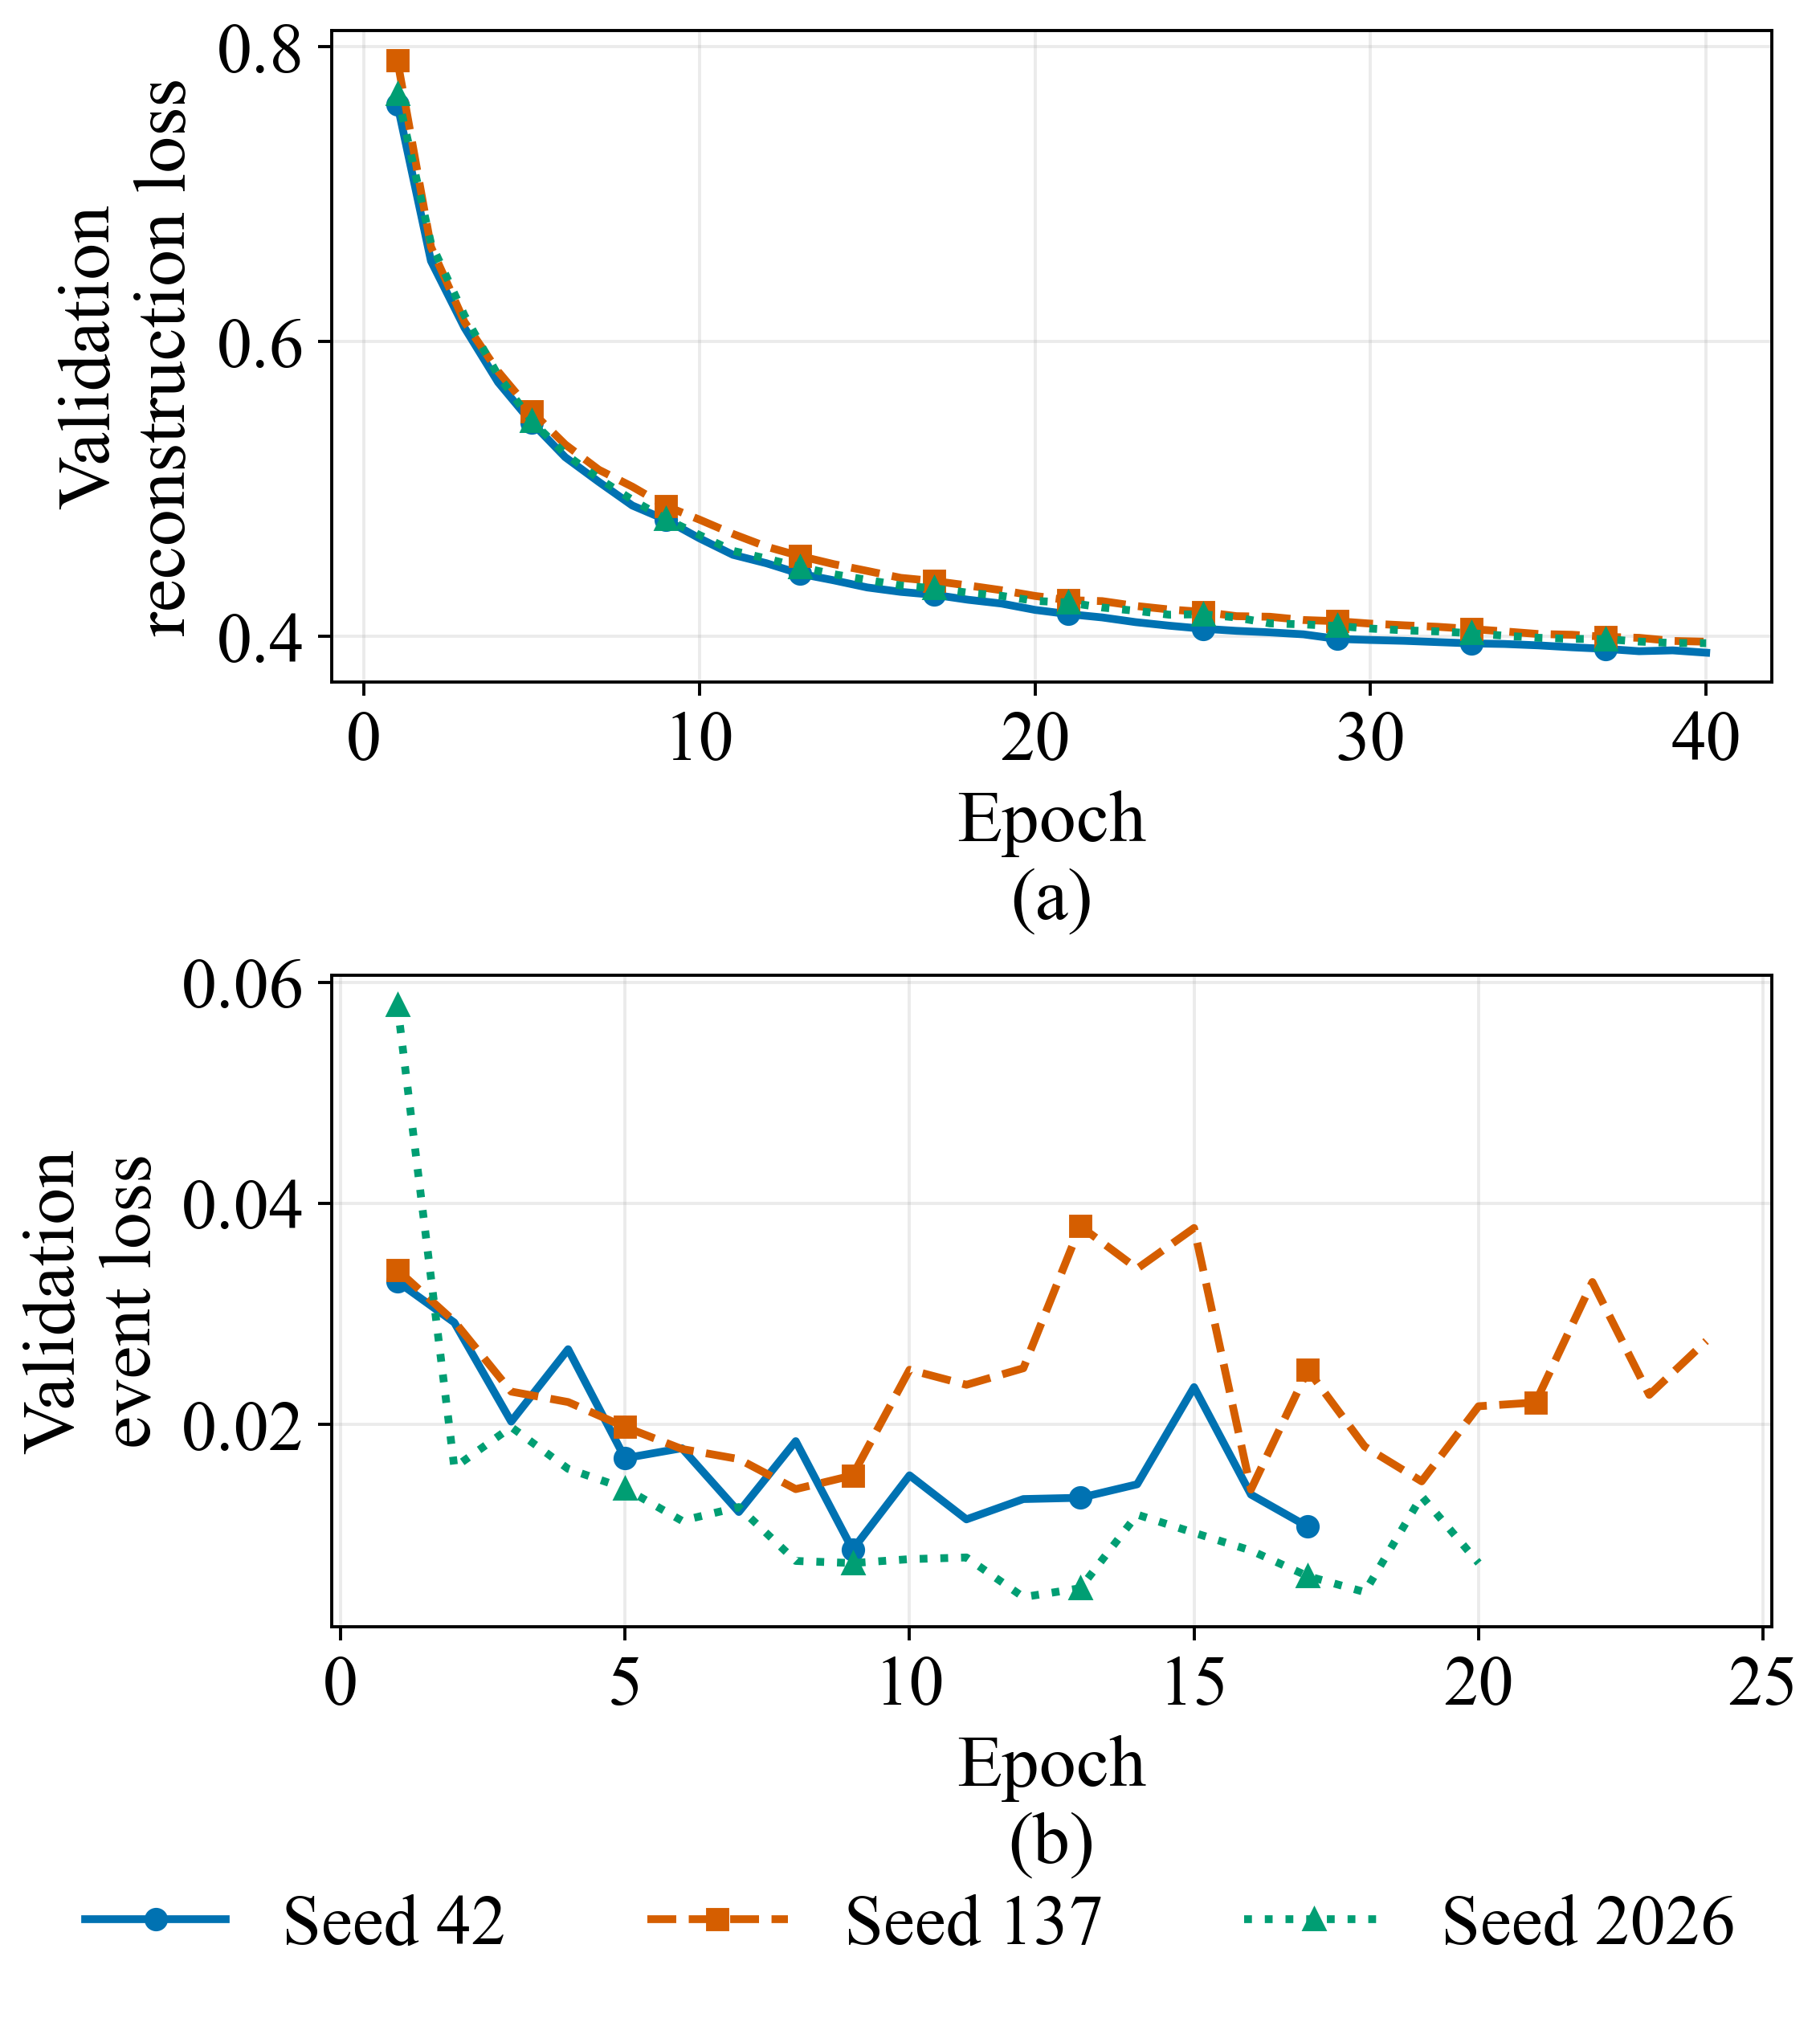

Inner validation uses the last 90 days of 2021 after a 30-day gap; the selected epoch minimizes this loss and is reused for the full 2019–2021 refit. (a) RACF-Net representation, reconstruction objective; (b) matched TCN, weighted event cross-entropy.

**Epoch selection on the inner validation window**

,Model,Seed,Epochs run,Selected epoch,Minimum inner validation loss,Training loss at selected epoch
1,RACF-Net,42,40,40,0.3890,0.4147
2,RACF-Net,137,40,40,0.3964,0.4233
3,RACF-Net,2026,40,40,0.3954,0.4211
4,Matched TCN,42,17,9,0.0087,0.0220
5,Matched TCN,137,24,16,0.0141,0.0098
6,Matched TCN,2026,20,12,0.0044,0.0177


In [12]:
def revision_figure(fig, name, width_in):
    fig.canvas.draw()
    for item in fig.findobj(matplotlib.text.Text):
        if item.get_visible() and item.get_text().strip():
            assert 18 <= item.get_fontsize() <= 20, item.get_text()
            font = font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)
            assert "Times New Roman" in font_manager.FontProperties(fname=font).get_name()
    for folder, extension in [(REV_PNG, "png"), (REV_PDF, "pdf")]:
        path = rev_path(folder / f"{name}.{extension}")
        fig.savefig(path, dpi=350, bbox_inches="tight", pad_inches=0.08)
        rev_register(path)
    plt.close(fig)
    display(Image(filename=str(REV_PNG / f"{name}.png"), width=int(width_in * 96)))


histories = {"RACF-Net": {42: OUTPUT_ROOT / "Tables/racf_20261013_102931/RACFNet_c1_temporal_forward_2022_s42_inner_learning.csv"},
             "Matched TCN": {42: OUTPUT_ROOT / "Tables/racf_20261013_102931/TCN_c7_temporal_forward_2022_s42_inner_learning.csv"}}
for seed in [137, 2026]:
    histories["RACF-Net"][seed] = REV_TABLES / "training" / f"RACFNet_c2_temporal_forward_2022_s{seed}_inner_learning.csv"
    histories["Matched TCN"][seed] = REV_TABLES / "training" / f"TCN_c7_temporal_forward_2022_s{seed}_inner_learning.csv"
styles = {42: ("#0072B2", "o", "-"), 137: ("#D55E00", "s", "--"), 2026: ("#009E73", "^", ":")}
fig, axes = plt.subplots(2, 1, figsize=(6.4, 7.2), layout="constrained")
learning_rows = []
for ax, (model, files), letter, ylabel in zip(axes, histories.items(), "ab",
        ["Inner validation reconstruction loss", "Inner validation event loss"]):
    for seed, path in files.items():
        history = pd.read_csv(path)
        ax.plot(history.epoch, history.validation_loss, color=styles[seed][0], marker=styles[seed][1],
                linestyle=styles[seed][2], markersize=5, markevery=4, linewidth=2, label=f"Seed {seed}")
        best = history.loc[history.validation_loss.idxmin()]
        learning_rows.append({"Model": model, "Seed": seed, "Epochs run": int(history.epoch.max()), "Selected epoch": int(best.epoch),
            "Minimum inner validation loss": float(best.validation_loss), "Training loss at selected epoch": float(best.training_loss)})
    ax.set_xlabel(f"Epoch\n({letter})")
    ax.set_ylabel(ylabel.replace("Inner validation ", "Validation\n"))
    ax.grid(alpha=0.25)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside lower center", ncol=3, frameon=False)
revision_figure(fig, "inner_validation_learning_curves", 6.4)
display(Markdown("Inner validation uses the last 90 days of 2021 after a 30-day gap; the selected epoch minimizes this loss and is reused for the full 2019–2021 refit. (a) RACF-Net representation, reconstruction objective; (b) matched TCN, weighted event cross-entropy."))
learning_table = pd.DataFrame(learning_rows)
rev_csv(learning_table, "inner_validation_learning_summary")
show(learning_table, "Epoch selection on the inner validation window")

## Second supplementary analysis: error structure, agent mechanism, statistical power, graded degradation, unseen sites and label provenance

In [1]:
# Fresh-kernel setup: definitions are taken from the saved cells above without re-executing them.
import ast, contextlib, copy, io, json, subprocess, sys, tempfile, threading, types, os
from pathlib import Path

_REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "dataset").is_dir() and (p / "notebooks").is_dir())


def saved_code_cells(notebook_name):
    notebook = json.loads((_REPO / "notebooks" / notebook_name).read_text())
    return {cell.get("id"): "".join(cell["source"]) for cell in notebook["cells"] if cell["cell_type"] == "code"}


def load_saved_definitions(source, namespace, label, keep=None):
    """Execute top-level definitions and assignments of a saved cell; display and print calls are skipped."""
    def quiet(node):
        return (isinstance(node, ast.Expr) and isinstance(node.value, ast.Call)
                and isinstance(node.value.func, ast.Name) and node.value.func.id in {"display", "print"})
    nodes = [node for node in ast.parse(source).body if not quiet(node) and (keep is None or keep(node))]
    exec(compile(ast.Module(body=nodes, type_ignores=[]), f"<{label}>", "exec"), namespace)


_NB05_CELLS = saved_code_cells("05_proposed_model_development_and_ablations.ipynb")
_SETUP_CELLS = ["pub05-c001", "racf-naming-compatibility", "pub05-c003", "v2-configuration",
                "v2-registration", "pub05-c004", "pub05-c017"]
_EXCLUDED = ("v2-validation", "v2-search", "v2-finalists", "v2-calibration-provenance", "v2-calibration-final")
_DEFINITION_CELLS = [key for key in _NB05_CELLS if key and key.startswith("v2-") and not key.startswith(_EXCLUDED)]
for _cell in _SETUP_CELLS + _DEFINITION_CELLS:
    load_saved_definitions(_NB05_CELLS[_cell], globals(), "NB05:" + _cell)
assert registration["configuration_sha256"] == plan_hash
from contextlib import contextmanager
from sklearn.ensemble import RandomForestClassifier
from scipy import stats
from scipy.special import expit
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
# Functions and classes of the first supplementary analysis; none of its statements is executed.
for _cell in ["rev-02", "rev-05", "rev-09", "rev-16"]:
    load_saved_definitions(_NB05_CELLS[_cell], globals(), "NB05:" + _cell,
                           keep=lambda node: isinstance(node, (ast.FunctionDef, ast.ClassDef)))
configure_figures()
for option in ["display.max_rows", "display.max_columns", "display.max_colwidth", "display.width"]:
    pd.set_option(option, None)

FIRST_RUN_ID = "racf_revision_20261112"
FIRST_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / FIRST_RUN_ID
FIRST_TABLES = OUTPUT_ROOT / "Tables" / FIRST_RUN_ID
FIRST_PREDICTIONS = OUTPUT_ROOT / "Predictions" / FIRST_RUN_ID
FIRST_REGISTRY = json.loads((OUTPUT_ROOT / "Manifests" / FIRST_RUN_ID / "supplementary_registry.json").read_text())
COMPONENT_DIR = OUTPUT_ROOT / "Artifacts/Runs/racf_components_20261014_002554"
DATASET_PROCESSED = REPO_ROOT / "dataset" / "Processed"
RV2_RUN_ID = "racf_revision2_20261125"
RV2_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / RV2_RUN_ID
RV2_TABLES = OUTPUT_ROOT / "Tables" / RV2_RUN_ID
RV2_MANIFESTS = OUTPUT_ROOT / "Manifests" / RV2_RUN_ID
RV2_PREDICTIONS = OUTPUT_ROOT / "Predictions" / RV2_RUN_ID
RV2_PNG = OUTPUT_ROOT / "Figures/PNG" / RV2_RUN_ID
RV2_PDF = OUTPUT_ROOT / "Figures/PDF" / RV2_RUN_ID
for folder in [RV2_ROOT, RV2_TABLES, RV2_MANIFESTS, RV2_PREDICTIONS, RV2_PNG, RV2_PDF]:
    folder.mkdir(parents=True, exist_ok=True)
SEEDS, STREAMS = [42, 137, 2026], [2026, 137, 42]
BOOTSTRAP_REPLICATES, BOOTSTRAP_SEED, RV2_SEED = 10000, 20261112, 20261125


def first_verified(path):
    """Read-only access to an output of the first supplementary analysis, checked against its registry."""
    path = Path(path)
    assert racf_hash(path) == FIRST_REGISTRY[str(path.relative_to(OUTPUT_ROOT))], path.name
    return path


def rv2_path(path):
    path = Path(path)
    assert RV2_RUN_ID in path.parts, "Writing outside the second supplementary run is prohibited: " + str(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def rv2_register(path):
    path = rv2_path(path)
    registry = RV2_MANIFESTS / "supplementary_registry.json"
    rows = json.loads(registry.read_text()) if registry.exists() else {}
    rows[str(path.relative_to(OUTPUT_ROOT))] = racf_hash(path)
    registry.write_text(json.dumps(rows, indent=2, sort_keys=True))
    return path


def rv2_save_frame(frame, path):
    path = rv2_path(path)
    if path.suffix == ".parquet":
        frame.to_parquet(path, index=False)
    else:
        frame.to_csv(path, index=False)
    return rv2_register(path)


def latex_cell(value):
    text = str(value)
    for old, new in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#")]:
        text = text.replace(old, new)
    for old, new in [("−", "$-$"), ("±", r"$\pm$"), ("×", r"$\times$"), ("Δ", r"$\Delta$"), ("≥", r"$\geq$"), ("α", r"$\alpha$")]:
        text = text.replace(old, new)
    return text


def rv2_table(frame, name, caption, shown=None, decimals=4, parts=None):
    """Save the numbers (CSV) and the displayed copy (LaTeX, booktabs); show every row, in parts if long."""
    rv2_save_frame(frame, RV2_TABLES / f"{name}.csv")
    shown = (frame if shown is None else shown).copy()
    for column in shown.columns:
        shown[column] = [typographic(value, decimals) for value in shown[column]]
    assert not shown.isna().any().any() and not shown.isin(["nan", "None", "", "inf"]).any().any(), caption
    lines = [r"\begin{tabular}{" + "l" * shown.shape[1] + "}", r"\toprule",
             " & ".join(latex_cell(column) for column in shown.columns) + r" \\", r"\midrule"]
    lines += [" & ".join(latex_cell(value) for value in row) + r" \\" for row in shown.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}", ""]
    rv2_path(RV2_TABLES / f"{name}.tex").write_text("\n".join(lines))
    rv2_register(RV2_TABLES / f"{name}.tex")
    for part_caption, rows in (parts or [(caption, slice(None))]):
        show(shown.iloc[rows].reset_index(drop=True), part_caption)


def rv2_figure(fig, name, width_in):
    fig.canvas.draw()
    for item in fig.findobj(matplotlib.text.Text):
        if item.get_visible() and item.get_text().strip():
            assert 18 <= item.get_fontsize() <= 20, item.get_text()
            font = font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)
            assert "Times New Roman" in font_manager.FontProperties(fname=font).get_name()
    for folder, extension in [(RV2_PNG, "png"), (RV2_PDF, "pdf")]:
        path = rv2_path(folder / f"{name}.{extension}")
        fig.savefig(path, dpi=350, bbox_inches="tight", pad_inches=0.08)
        rv2_register(path)
    plt.close(fig)
    display(Image(filename=str(RV2_PNG / f"{name}.png"), width=int(width_in * 96)))


@contextmanager
def revision2_run():
    """Route the registered training functions to the folders of this analysis."""
    saved = {name: globals()[name] for name in ("RACF_RUN_ID", "RACF_ROOT", "RACF_TABLES", "RACF_MANIFESTS")}
    globals().update(RACF_RUN_ID=RV2_RUN_ID, RACF_ROOT=RV2_ROOT, RACF_TABLES=RV2_TABLES / "training",
                     RACF_MANIFESTS=RV2_MANIFESTS)
    (RV2_TABLES / "training").mkdir(parents=True, exist_ok=True)
    try:
        yield
    finally:
        globals().update(saved)


def signed(value, decimals=2):
    text = typographic(float(value), decimals)
    return text if text.startswith("−") or float(text) == 0 else "+" + text


def interval(lower, upper, decimals=2):
    return "[" + typographic(float(lower), decimals) + ", " + typographic(float(upper), decimals) + "]"


def p_text(value):
    return "< 0.001" if value < 0.001 else typographic(float(value), 3)


def value_or_na(value, decimals=1):
    return "n/a" if value is None or not np.isfinite(value) else typographic(float(value), decimals)


def logit(probability):
    probability = np.clip(np.asarray(probability, dtype=float), 1e-12, 1 - 1e-12)
    return np.log(probability) - np.log1p(-probability)


TRAIN_IDX = np.asarray(search_splits["temporal"]["forward_2022"]["train"])
VALID_IDX = np.asarray(search_splits["temporal"]["forward_2022"]["evaluation"])
TEST_IDX = np.asarray(splits["development"]["evaluation"])
assert hashlib.sha256("\n".join(metadata.iloc[TEST_IDX].observation_id).encode()).hexdigest() == \
    "a90707a37122efb67158ad36c660b61a1f5a94f9a47fe82777907ae3fcfd95f9"
train_digest = hashlib.sha256("\n".join(metadata.iloc[TRAIN_IDX].observation_id).encode()).hexdigest()
test_meta = metadata.iloc[TEST_IDX].reset_index(drop=True)
test_features = features.iloc[TEST_IDX].reset_index(drop=True)
y_test = test_meta.target.to_numpy(int)

focus_freeze = json.loads((OUTPUT_ROOT / "Manifests/racf_focus_20261013_170443/model_freeze.json").read_text())
focus_selection = json.loads((OUTPUT_ROOT / "Manifests/racf_focus_20261013_170443/architecture_selection.json").read_text())
MATCHED = ["RACF-Net", "CatBoost", "LightGBM", "TCN"]
MATCHED_NAMES = {"RACF-Net": "RACF-Net", "CatBoost": "Matched CatBoost", "LightGBM": "Matched LightGBM", "TCN": "Matched TCN"}
matched_configs, matched_checkpoints = {}, {}
for record in focus_freeze["models"]:
    model = record["model"]
    assert racf_hash(OUTPUT_ROOT / record["checkpoint"]) == record["checkpoint_sha256"]
    if model == "RACF-Net":
        parent = next((OUTPUT_ROOT / "Artifacts/Runs/racf_20261013_102931/Models").glob("RACFNet_c2_temporal_forward_2022_s42_*.json"))
        provenance = json.loads(parent.read_text())
        assert provenance["config"] == focus_selection["configuration"]
    else:
        provenance = json.loads((OUTPUT_ROOT / record["checkpoint"]).with_suffix(".json").read_text())
    assert provenance["seed"] == 42 and provenance["training_ids_sha256"] == train_digest
    matched_configs[model] = dict(provenance["config"])
    matched_checkpoints[(model, 42)] = OUTPUT_ROOT / record["checkpoint"]
    for seed in [137, 2026]:
        stem = f"{model.replace('-', '')}_c{matched_configs[model]['candidate_id']}_temporal_forward_2022_s{seed}_"
        path, = (FIRST_ROOT / "Models").glob(stem + "*.joblib")
        fit_record = json.loads(path.with_suffix(".json").read_text())
        assert fit_record["checkpoint_sha256"] == racf_hash(path) and fit_record["training_ids_sha256"] == train_digest
        matched_checkpoints[(model, seed)] = path
assert set(matched_configs) == set(MATCHED)
GROUP_NAMES = dict(zip(schema["feature_groups"], ["Power", "Weather", "Context"]))

# Paired site bootstrap: the replicates of the first supplementary analysis (same sites, same generator seed).
sites = np.array(sorted(test_meta.plant_id.unique()))
site_code = {site: i for i, site in enumerate(sites)}
_draws = np.random.default_rng(BOOTSTRAP_SEED).integers(0, len(sites), size=(BOOTSTRAP_REPLICATES, len(sites)))
site_weights = np.stack([np.bincount(row, minlength=len(sites)) for row in _draws]).astype(float)


def bootstrap_metric_draws(frames):
    """Site-bootstrap AP, F1 and MCC averaged over the supplied per-seed frames (shared replicates)."""
    values = {"AP": [], "F1": [], "MCC": []}
    observed = {"AP": [], "F1": [], "MCC": []}
    for frame in frames:
        evaluator = SiteWeightedMetrics(frame)
        ap, f1, mcc = [], [], []
        for start in range(0, BOOTSTRAP_REPLICATES, 500):
            block = site_weights[start:start + 500]
            ap.append(evaluator.ap(block))
            a, b = evaluator.threshold_metrics(block)
            f1.append(a)
            mcc.append(b)
        for key, draws in [("AP", ap), ("F1", f1), ("MCC", mcc)]:
            values[key].append(np.concatenate(draws))
        unit = np.ones((1, len(sites)))
        observed["AP"].append(evaluator.ap(unit)[0])
        f1_unit, mcc_unit = evaluator.threshold_metrics(unit)
        observed["F1"].append(f1_unit[0])
        observed["MCC"].append(mcc_unit[0])
    return {key: np.mean(values[key], axis=0) for key in values}, {key: float(np.mean(observed[key])) for key in observed}


def paired_contrast(first, second, metric):
    """Difference first − second with percentile 95% CI and two-sided bootstrap p (+1 correction)."""
    delta = first[0][metric] - second[0][metric]
    valid = delta[np.isfinite(delta)]
    p_value = min(1.0, 2 * min((np.sum(valid <= 0) + 1) / (len(valid) + 1), (np.sum(valid >= 0) + 1) / (len(valid) + 1)))
    return {"Difference": first[1][metric] - second[1][metric], "95% CI lower": float(np.quantile(valid, .025)),
            "95% CI upper": float(np.quantile(valid, .975)), "Bootstrap SE": float(valid.std(ddof=1)),
            "Bootstrap p": p_value, "Valid replicates": int(len(valid))}

### 1. Relative differences between RACF-Net and each comparator

In [2]:
metrics_first = pd.read_csv(first_verified(FIRST_TABLES / "metrics_by_model_seed_cohort_condition.csv"))
contrasts_first = pd.read_csv(first_verified(FIRST_TABLES / "paired_site_bootstrap_contrasts.csv"))
clean_first = metrics_first.loc[metrics_first.Cohort.eq("Test 2023") & metrics_first.Scenario.eq("clean")]
seed_means = clean_first.groupby("Model")[["AP", "F1", "MCC"]].mean()
relative_rows = []
for _, row in contrasts_first.iterrows():
    racf, other = seed_means.loc["RACF-Net", row.Metric], seed_means.loc[row.Comparator, row.Metric]
    assert abs(racf - row["RACF-Net"]) < 1e-12 and abs(other - row["Comparator value"]) < 1e-12
    relative_rows.append({"Family": row.Family, "Comparator": row.Comparator, "Metric": row.Metric,
        "Comparator value": other, "RACF-Net": racf, "Difference (p.p.)": 100 * (racf - other),
        "95% CI lower (p.p.)": 100 * row["95% CI lower"], "95% CI upper (p.p.)": 100 * row["95% CI upper"],
        "Relative difference (%)": 100 * (racf - other) / other, "Holm p": row["Holm p"]})
relative = pd.DataFrame(relative_rows)
for metric in ["AP", "F1", "MCC"]:
    part = relative.loc[relative.Metric.eq(metric)].drop(columns="Metric").reset_index(drop=True)
    shown = pd.DataFrame({"Comparator": part.Comparator, "Family": part.Family,
        f"Comparator {metric}": [typographic(v, 3) for v in part["Comparator value"]],
        f"RACF-Net {metric}": [typographic(v, 3) for v in part["RACF-Net"]],
        "Δ (p.p.) [95% CI]": [signed(d) + " " + interval(l, u) for d, l, u in
                              zip(part["Difference (p.p.)"], part["95% CI lower (p.p.)"], part["95% CI upper (p.p.)"])],
        "Relative difference (%)": [signed(v) for v in part["Relative difference (%)"]],
        "Holm p": [p_text(v) for v in part["Holm p"]]})
    rv2_table(part, f"relative_differences_{metric.lower()}",
              f"{metric} of RACF-Net relative to each comparator on clean 2023 (means over three training seeds; "
              "Δ = RACF-Net − comparator in percentage points with the paired site-bootstrap 95% CI; "
              "relative difference = 100 × Δ / comparator)", shown=shown)

**AP of RACF-Net relative to each comparator on clean 2023 (means over three training seeds; Δ = RACF-Net − comparator in percentage points with the paired site-bootstrap 95% CI; relative difference = 100 × Δ / comparator)**

,Comparator,Family,Comparator AP,RACF-Net AP,Δ (p.p.) [95% CI],Relative difference (%),Holm p
1,Matched CatBoost,Primary,0.857,0.910,"+5.28 [−0.89, 13.79]",+6.15,0.706
2,Matched LightGBM,Primary,0.928,0.910,"−1.75 [−6.02, 3.38]",−1.89,1.000
3,Matched TCN,Primary,0.930,0.910,"−1.93 [−7.07, 2.61]",−2.07,1.000
4,Power-drop rule,Secondary,0.769,0.910,"+14.13 [−0.06, 28.13]",+18.37,1.000
5,Recent-level deviation,Secondary,0.914,0.910,"−0.33 [−7.98, 7.01]",−0.36,1.000
6,Logistic Regression,Secondary,0.930,0.910,"−1.96 [−7.96, 3.68]",−2.10,1.000
7,Random Forest,Secondary,0.892,0.910,"+1.81 [−1.79, 7.09]",+2.03,1.000
8,CatBoost,Secondary,0.926,0.910,"−1.56 [−4.85, 1.42]",−1.69,1.000
9,LightGBM,Secondary,0.957,0.910,"−4.65 [−11.36, 0.09]",−4.86,1.000
10,MultiRocket + context,Secondary,0.898,0.910,"+1.28 [−8.53, 9.92]",+1.42,1.000


**F1 of RACF-Net relative to each comparator on clean 2023 (means over three training seeds; Δ = RACF-Net − comparator in percentage points with the paired site-bootstrap 95% CI; relative difference = 100 × Δ / comparator)**

,Comparator,Family,Comparator F1,RACF-Net F1,Δ (p.p.) [95% CI],Relative difference (%),Holm p
1,Matched CatBoost,Primary,0.895,0.928,"+3.35 [−0.56, 6.79]",+3.75,0.648
2,Matched LightGBM,Primary,0.908,0.928,"+2.09 [−3.73, 7.34]",+2.30,1.000
3,Matched TCN,Primary,0.878,0.928,"+5.02 [1.55, 8.54]",+5.71,0.027
4,Power-drop rule,Secondary,0.805,0.928,"+12.36 [5.30, 20.59]",+15.36,0.007
5,Recent-level deviation,Secondary,0.819,0.928,"+10.92 [0.82, 23.49]",+13.33,0.375
6,Logistic Regression,Secondary,0.872,0.928,"+5.61 [1.52, 10.64]",+6.44,0.065
7,Random Forest,Secondary,0.920,0.928,"+0.89 [−3.09, 3.88]",+0.97,1.000
8,CatBoost,Secondary,0.904,0.928,"+2.47 [−2.67, 7.64]",+2.74,1.000
9,LightGBM,Secondary,0.914,0.928,"+1.49 [−5.73, 7.98]",+1.63,1.000
10,MultiRocket + context,Secondary,0.813,0.928,"+11.50 [4.91, 18.05]",+14.14,0.007


**MCC of RACF-Net relative to each comparator on clean 2023 (means over three training seeds; Δ = RACF-Net − comparator in percentage points with the paired site-bootstrap 95% CI; relative difference = 100 × Δ / comparator)**

,Comparator,Family,Comparator MCC,RACF-Net MCC,Δ (p.p.) [95% CI],Relative difference (%),Holm p
1,Matched CatBoost,Primary,0.895,0.930,"+3.46 [−0.45, 6.89]",+3.87,0.648
2,Matched LightGBM,Primary,0.908,0.930,"+2.20 [−3.53, 7.25]",+2.42,1.000
3,Matched TCN,Primary,0.880,0.930,"+4.98 [1.54, 8.37]",+5.66,0.027
4,Power-drop rule,Secondary,0.805,0.930,"+12.48 [5.33, 20.65]",+15.51,0.011
5,Recent-level deviation,Secondary,0.819,0.930,"+11.06 [0.79, 23.10]",+13.50,0.375
6,Logistic Regression,Secondary,0.877,0.930,"+5.25 [1.42, 9.80]",+5.98,0.065
7,Random Forest,Secondary,0.920,0.930,"+0.96 [−2.90, 3.94]",+1.04,1.000
8,CatBoost,Secondary,0.904,0.930,"+2.57 [−2.48, 7.62]",+2.85,1.000
9,LightGBM,Secondary,0.914,0.930,"+1.55 [−5.40, 7.77]",+1.69,1.000
10,MultiRocket + context,Secondary,0.817,0.930,"+11.25 [4.64, 17.54]",+13.77,0.007


### 2. Assessment boundary at 31 January

In [3]:
SPLIT_FILES = [("Forward 2020", "forward_2020"), ("Forward 2021", "forward_2021"), ("Forward 2022", "forward_2022"),
               ("Development 2023", "development"), ("Calibration 2024", "calibration"), ("Historical 2025", "locked_test")]
split_arrays = {name: (np.load(SHARED_DATASET_ROOT / "Splits" / f"{name}_train.npy"),
                       np.load(SHARED_DATASET_ROOT / "Splits" / f"{name}_evaluation.npy")) for _, name in SPLIT_FILES}
assert np.array_equal(split_arrays["forward_2022"][0], TRAIN_IDX) and np.array_equal(split_arrays["forward_2022"][1], VALID_IDX)
assert np.array_equal(split_arrays["development"][1], TEST_IDX)
labelled = metadata.target.notna().to_numpy()
boundary_rows = []
for label, name in SPLIT_FILES:
    train, evaluation = split_arrays[name]
    trained, assessed = metadata.iloc[train], metadata.iloc[evaluation]
    year = int(assessed.date.dt.year.iloc[0])
    assert assessed.date.dt.year.eq(year).all()
    first = assessed.date.min()
    window_start = first - pd.Timedelta(days=29)
    assert window_start.year == year and (first - trained.date.max()).days > RACF_CONFIG["embargo_days"]
    assert trained.date.min() == pd.Timestamp("2019-01-30")
    january = (metadata.date.dt.year.eq(year) & metadata.date.lt(pd.Timestamp(year, 1, 31))).to_numpy() & labelled
    boundary_rows.append({"Partition": label, "First training day": str(trained.date.min().date()),
        "Last training day": str(trained.date.max().date()), "First assessed day": str(first.date()),
        "Window of first assessed day starts": str(window_start.date()),
        "Labelled reactor-days, 1–30 January": int(january.sum()),
        "SCRAM days, 1–30 January": int(metadata.loc[january, "target"].sum()),
        "SCRAM days assessed": int(assessed.target.sum())})
boundary = pd.DataFrame(boundary_rows)
rv2_table(boundary, "assessment_boundary_january",
          "Assessment boundaries: the first assessed day follows the last training day by 31 days, so its 30-day input "
          "window lies entirely in the assessment year; reactor-days of 1–30 January are used only as input history")

**Assessment boundaries: the first assessed day follows the last training day by 31 days, so its 30-day input window lies entirely in the assessment year; reactor-days of 1–30 January are used only as input history**

,Partition,First training day,Last training day,First assessed day,Window of first assessed day starts,"Labelled reactor-days, 1–30 January","SCRAM days, 1–30 January",SCRAM days assessed
1,Forward 2020,2019-01-30,2019-12-31,2020-01-31,2020-01-02,2672,1,46
2,Forward 2021,2019-01-30,2020-12-31,2021-01-31,2021-01-02,2708,1,36
3,Forward 2022,2019-01-30,2021-12-31,2022-01-31,2022-01-02,2510,2,35
4,Development 2023,2019-01-30,2022-12-31,2023-01-31,2023-01-02,2504,1,42
5,Calibration 2024,2019-01-30,2023-12-31,2024-01-31,2024-01-02,2551,2,48
6,Historical 2025,2019-01-30,2023-12-31,2025-01-31,2025-01-02,2635,1,37


### 3. Event-aligned reactor power

**Event-aligned reported power, 2019–2023: concentration at the bounds explains why the mean can lie outside the interquartile range; recomputed values match the stored NB01 source exactly**

,Class,Events,"Power values, days −7 to +7",Values at 0% (%),Values at or above 99% (%),Days with the mean outside the IQR (of 15)
1,Confirmed SCRAM,215,3220,31.9,44.7,8
2,Documented non-SCRAM,997,14169,19.0,71.6,14


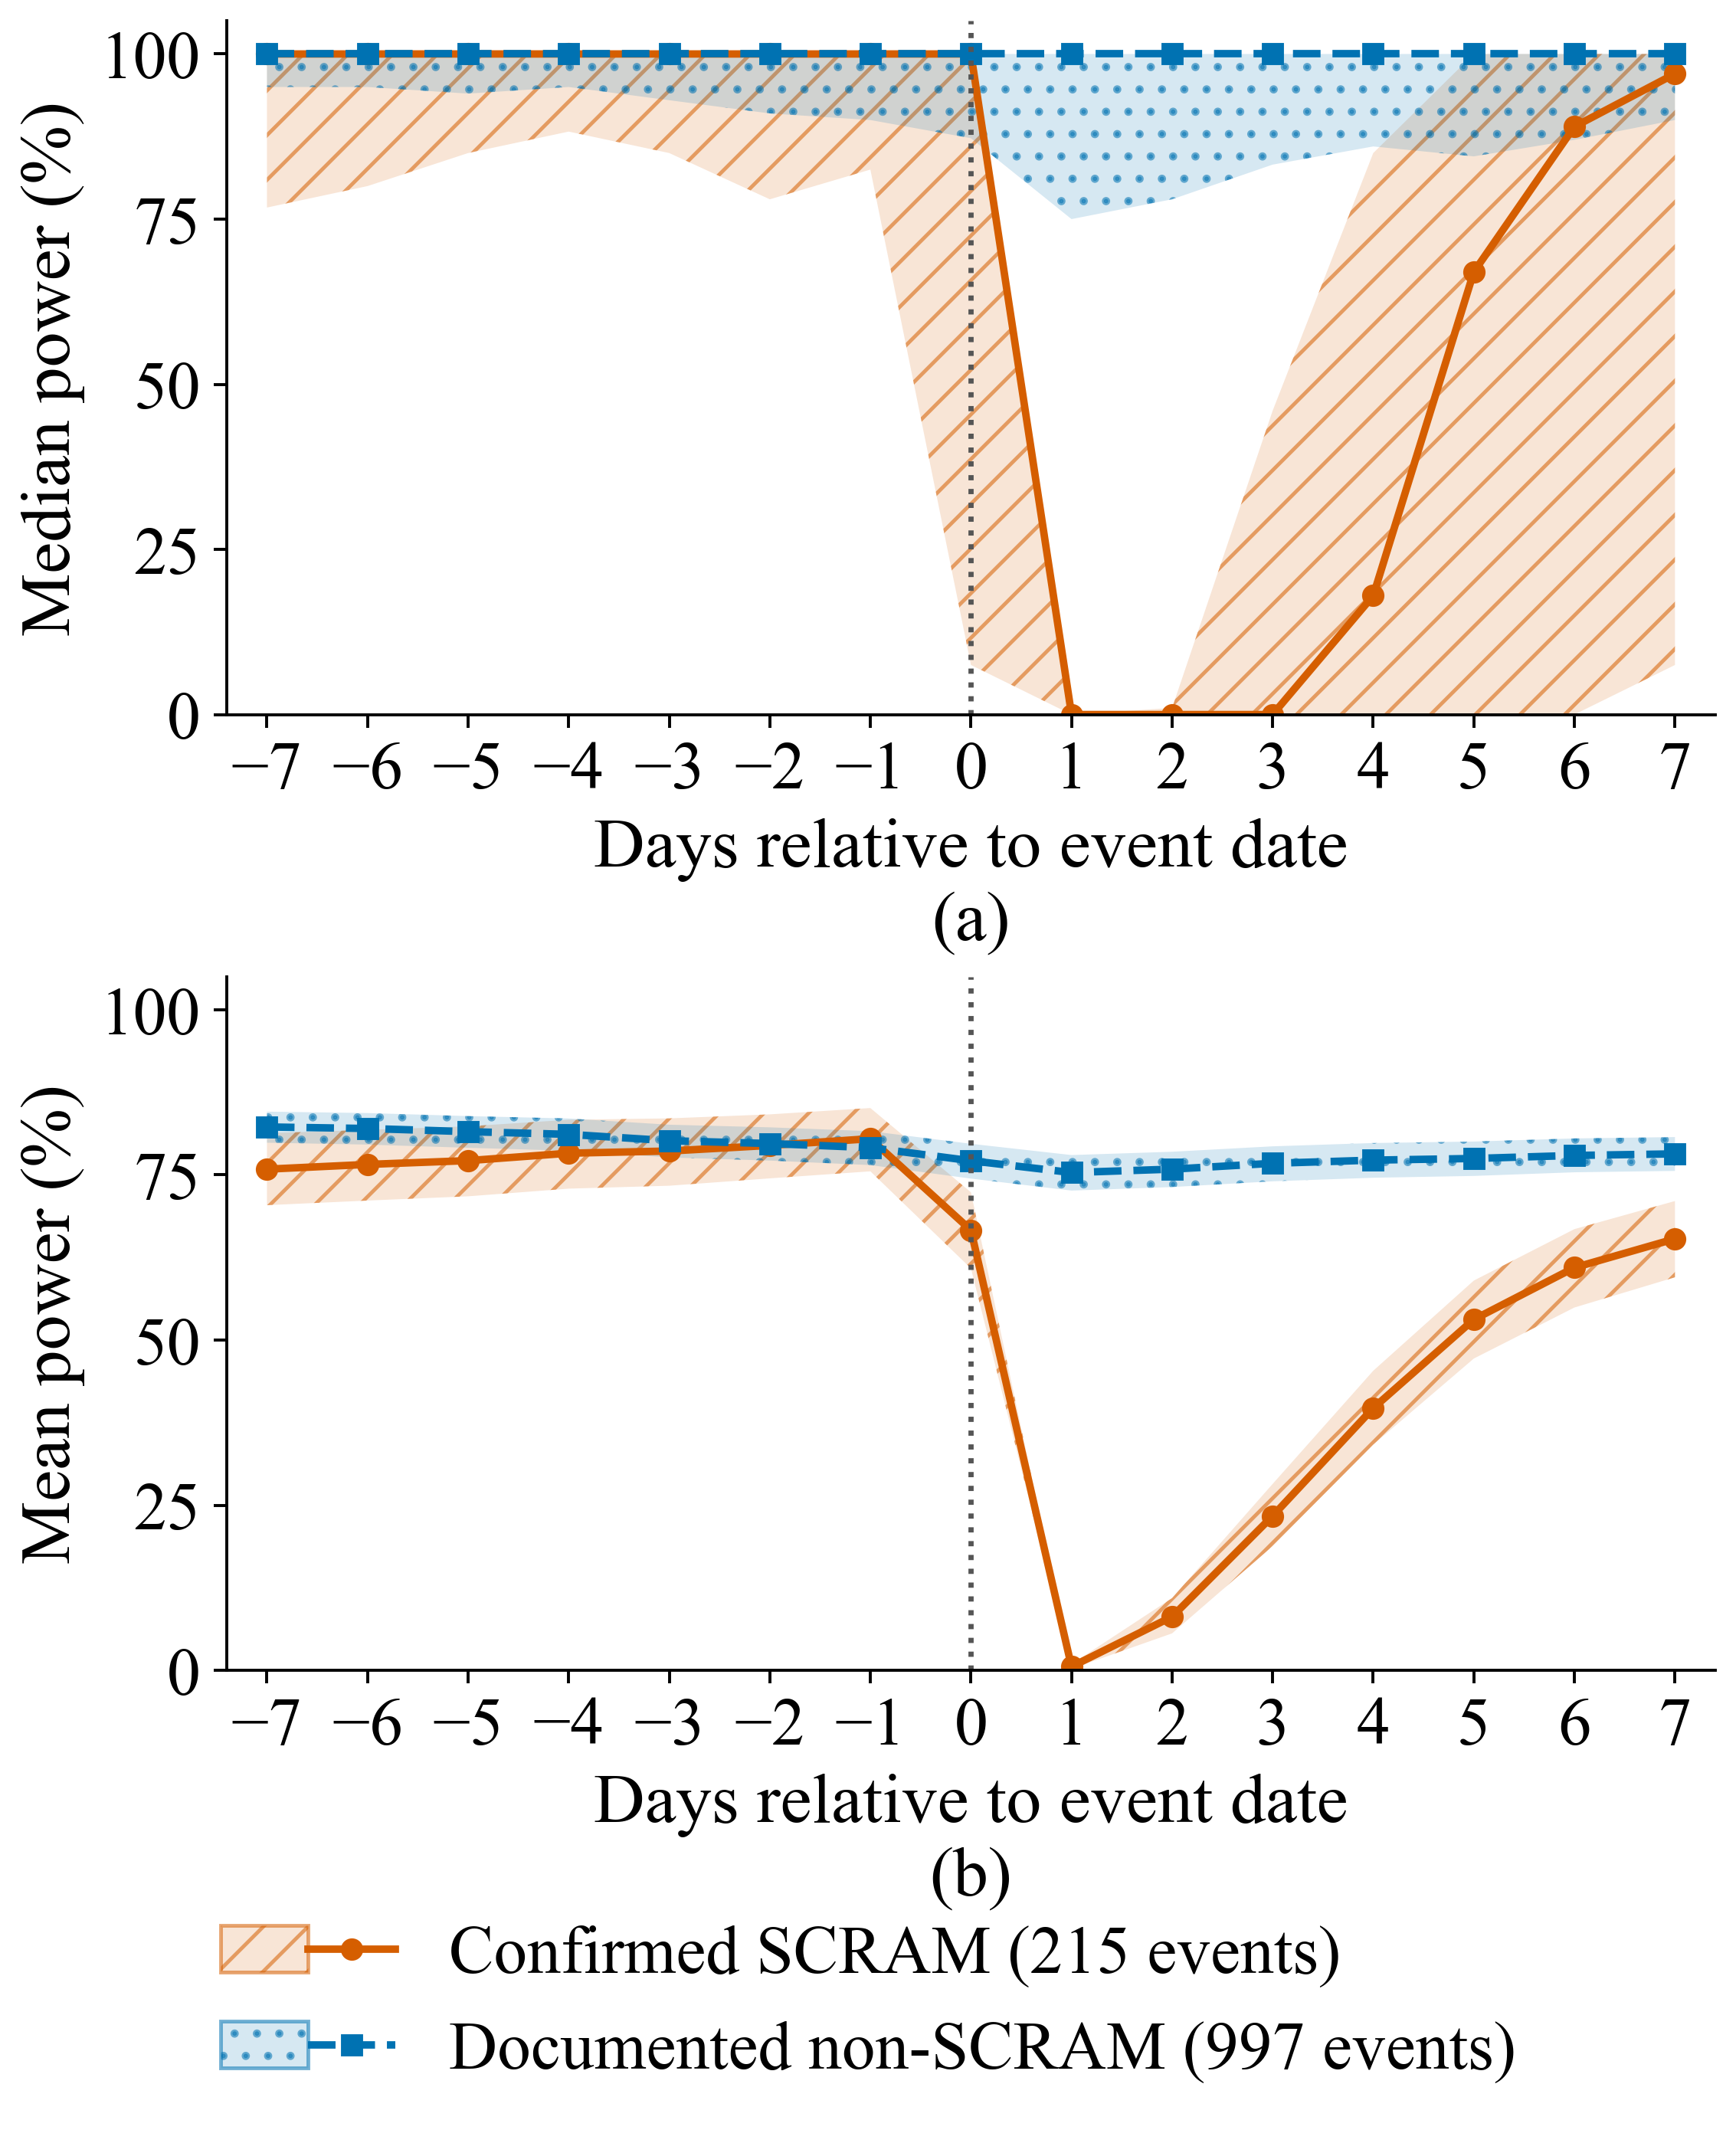

Reported reactor power aligned to the event date (day 0) for 215 confirmed SCRAM events and 997 documented non-SCRAM events, 2019–2023; the positive label day is day +1. (a) Median (line) and interquartile range (band); (b) mean (line) and 95% bootstrap confidence interval over events (band, 10,000 replicates). The figure is descriptive and does not use model outputs.

In [4]:
power_archive = pd.read_parquet(DATASET_PROCESSED / "nrc_power_weather.parquet", columns=["reactor_id", "date", "power_pct"])
assert not power_archive.duplicated(["reactor_id", "date"]).any()
profile_power = power_archive.loc[power_archive.date.lt("2024-01-01")]
confirmed_events = pd.read_parquet(DATASET_PROCESSED / "nrc_confirmed_reactor_events.parquet")
structured = pd.read_parquet(DATASET_PROCESSED / "nrc_structured_notifications.parquet")
event_sets = {
    "Confirmed SCRAM": confirmed_events.loc[confirmed_events.event_date.lt("2024-01-01"), ["reactor_id", "event_date"]],
    "Documented non-SCRAM": structured.loc[structured.scram_code.eq("N") & ~structured.code_conflict
                                           & structured.reactor_id.notna() & structured.event_date.lt("2024-01-01"),
                                           ["reactor_id", "event_date"]]}
LAGS = np.arange(-7, 8)
aligned = {}
for label, events in event_sets.items():
    events = events.drop_duplicates().reset_index(drop=True)
    matrix = np.full((len(events), len(LAGS)), np.nan)
    for column, lag in enumerate(LAGS):
        shifted = events.assign(date=events.event_date + pd.Timedelta(days=int(lag)))
        matrix[:, column] = shifted.merge(profile_power, on=["reactor_id", "date"], how="left",
                                          validate="many_to_one").power_pct.to_numpy(float)
    aligned[label] = matrix

stored_source = pd.read_csv(OUTPUT_ROOT / "Tables/racf_20261011/nb01_event_alignment_source.csv")
rng = np.random.default_rng(RV2_SEED)
profile_rows, diagnostic_rows = [], []
for label, matrix in aligned.items():
    frame = pd.DataFrame(matrix, columns=LAGS)
    reference = stored_source.loc[stored_source.Class.eq(label)].set_index("day_relative_to_event").loc[LAGS]
    assert np.array_equal(frame.notna().sum().to_numpy(), reference.n.to_numpy())
    assert np.allclose(frame.mean().to_numpy(), reference["mean"].to_numpy(), rtol=0, atol=1e-9)
    assert np.allclose(frame.quantile(.25).to_numpy(), reference.q25.to_numpy(), rtol=0, atol=1e-9)
    assert np.allclose(frame.quantile(.75).to_numpy(), reference.q75.to_numpy(), rtol=0, atol=1e-9)
    known = np.isfinite(matrix)
    values = np.where(known, matrix, 0.0)
    weights = np.empty((BOOTSTRAP_REPLICATES, len(matrix)))
    for start in range(0, BOOTSTRAP_REPLICATES, 1000):
        draws = rng.integers(0, len(matrix), size=(1000, len(matrix)))
        weights[start:start + 1000] = np.stack([np.bincount(row, minlength=len(matrix)) for row in draws])
    boot_means = (weights @ values) / (weights @ known)
    lower, upper = np.percentile(boot_means, [2.5, 97.5], axis=0)
    outside = 0
    for column, lag in enumerate(LAGS):
        observed = matrix[known[:, column], column]
        q1, median, q3 = np.quantile(observed, [.25, .5, .75])
        outside += int(not q1 <= observed.mean() <= q3)
        profile_rows.append({"Class": label, "Day": int(lag), "Events with a power record": int(known[:, column].sum()),
            "Median (%)": median, "Q1 (%)": q1, "Q3 (%)": q3, "Mean (%)": observed.mean(),
            "Mean 95% CI lower (%)": lower[column], "Mean 95% CI upper (%)": upper[column]})
    observed_all = matrix[known]
    diagnostic_rows.append({"Class": label, "Events": len(matrix), "Power values, days −7 to +7": int(known.sum()),
        "Values at 0% (%)": 100 * np.mean(observed_all == 0), "Values at or above 99% (%)": 100 * np.mean(observed_all >= 99),
        "Days with the mean outside the IQR (of 15)": outside})
profile = pd.DataFrame(profile_rows)
rv2_save_frame(profile, RV2_TABLES / "event_aligned_power_profile.csv")
diagnostics = pd.DataFrame(diagnostic_rows)
rv2_table(diagnostics, "event_aligned_power_distribution",
          "Event-aligned reported power, 2019–2023: concentration at the bounds explains why the mean can lie outside "
          "the interquartile range; recomputed values match the stored NB01 source exactly", decimals=1)

styles = {"Confirmed SCRAM": ("#D55E00", "-", "o", "//"), "Documented non-SCRAM": ("#0072B2", "--", "s", "..")}
fig, axes = plt.subplots(2, 1, figsize=(6.4, 8.0), layout="constrained")
for ax, (center, low, high), letter, ylabel in zip(
        axes, [("Median (%)", "Q1 (%)", "Q3 (%)"), ("Mean (%)", "Mean 95% CI lower (%)", "Mean 95% CI upper (%)")],
        "ab", ["Median power (%)", "Mean power (%)"]):
    for label, (color, line, marker, hatch) in styles.items():
        part = profile.loc[profile.Class.eq(label)]
        ax.fill_between(part.Day, part[low], part[high], facecolor=matplotlib.colors.to_rgba(color, 0.16),
                        edgecolor=matplotlib.colors.to_rgba(color, 0.55), hatch=hatch, linewidth=0)
        ax.plot(part.Day, part[center], color=color, linestyle=line, marker=marker, markersize=5, linewidth=2)
    ax.axvline(0, color="#555555", linestyle=":", linewidth=1.4)
    ax.set_xlim(-7.4, 7.4)
    ax.set_ylim(0, 105)
    ax.set_xticks(LAGS)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(f"Days relative to event date\n({letter})")
    ax.spines[["top", "right"]].set_visible(False)
handles = []
for label, (color, line, marker, hatch) in styles.items():
    patch = Patch(facecolor=matplotlib.colors.to_rgba(color, 0.16), edgecolor=matplotlib.colors.to_rgba(color, 0.55), hatch=hatch)
    handles.append((patch, Line2D([], [], color=color, linestyle=line, marker=marker, markersize=5, linewidth=2)))
labels = [f"{label} ({len(aligned[label])} events)" for label in styles]
fig.legend(handles, labels, handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, loc="outside lower center",
           ncol=1, frameon=False, handlelength=2.6)
rv2_figure(fig, "event_aligned_power_profile", 6.4)
counts = {label: len(matrix) for label, matrix in aligned.items()}
display(Markdown(f"Reported reactor power aligned to the event date (day 0) for {counts['Confirmed SCRAM']} confirmed SCRAM events "
                 f"and {counts['Documented non-SCRAM']} documented non-SCRAM events, 2019–2023; the positive label day is day +1. "
                 "(a) Median (line) and interquartile range (band); (b) mean (line) and 95% bootstrap confidence interval "
                 "over events (band, 10,000 replicates). The figure is descriptive and does not use model outputs."))

### 4. Error structure of the 2023 assessment

In [5]:
test_decisions = pd.read_parquet(first_verified(FIRST_PREDICTIONS / "test_2023_clean_decisions.parquet"))
COMPONENTS = {"no_agents": "No numerical agents", "no_peer": "No inter-agent exchange", "no_repair": "No data recovery"}
component_frames = []
for variant, name in COMPONENTS.items():
    scored = {}
    for year, idx in [(2022, VALID_IDX), (2023, TEST_IDX)]:
        path = COMPONENT_DIR / "Predictions" / f"{variant}_{year}_clean.parquet"
        assert racf_hash(path) == json.loads(path.with_suffix(".json").read_text())["sha256"]
        scored[year] = pd.read_parquet(path)
        assert scored[year].observation_id.tolist() == metadata.iloc[idx].observation_id.tolist()
    calibration = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(
        scored[2022].raw_score.to_numpy(), scored[2022].target.to_numpy(),
        {"run_id": RV2_RUN_ID, "model": name, "seed": 42, "year": 2022})
    joblib.dump(calibration, rv2_path(RV2_ROOT / "Calibration" / f"{variant}_s42_2022.joblib"), compress=3)
    rv2_register(RV2_ROOT / "Calibration" / f"{variant}_s42_2022.joblib")
    raw = scored[2023].raw_score.to_numpy()
    component_frames.append(pd.DataFrame({"observation_id": test_meta.observation_id, "plant_id": test_meta.plant_id,
        "target": y_test, "raw_score": raw, "probability": calibration.predict(raw),
        "decision_f1": calibration.decisions(raw)["f1"], "model": name, "seed": 42}))
decisions_all = pd.concat([test_decisions, *component_frames], ignore_index=True)
decisions_all["decision_f1"] = decisions_all.decision_f1.astype(bool)
assert decisions_all.groupby(["model", "seed"]).size().eq(len(TEST_IDX)).all()
rv2_save_frame(decisions_all, RV2_PREDICTIONS / "test_2023_clean_decisions_with_components.parquet")
descriptors = test_meta[["observation_id", "date", "plant_id", "reactor_id", "control_kind", "scram_type", "event_episode_id"]].join(
    test_features[["power_pct", "delta_1d", "zero_run_days", "power_window_fraction", "reactor_is_pwr"]])
cases = descriptors.loc[y_test == 1].sort_values(["date", "reactor_id"]).reset_index(drop=True)
cases.insert(0, "Case", [f"S{i:02d}" for i in range(1, len(cases) + 1)])
assert len(cases) == 42
OUTCOME_MODELS = ["RACF-Net", "Matched CatBoost", "Matched LightGBM", "Matched TCN", "LightGBM", "TCN + context",
                  "Power-drop rule", "No numerical agents", "No inter-agent exchange"]
SUMMARY_MODELS = ["RACF-Net", "Matched CatBoost", "Matched LightGBM", "Matched TCN", "Logistic Regression", "Random Forest",
                  "CatBoost", "LightGBM", "Inception + context", "TCN + context", "TabM", "Power-drop rule",
                  "Recent-level deviation", "No numerical agents", "No inter-agent exchange", "No data recovery"]
positives = decisions_all.loc[decisions_all.target.eq(1)]
hits = positives.groupby(["model", "observation_id"]).decision_f1.agg(["sum", "size"])
SCRAM_TYPE = {"A": "Automatic", "M": "Manual"}
descriptor_shown = pd.DataFrame({"Case": cases.Case, "Date": cases.date.dt.strftime("%Y-%m-%d"), "Site": cases.plant_id,
    "Reactor": np.where(cases.reactor_is_pwr.eq(1), "PWR", "BWR"),
    "SCRAM": ["; ".join(SCRAM_TYPE[part] for part in str(value).split(";")) for value in cases.scram_type],
    "Power (%)": [value_or_na(v, 0) for v in cases.power_pct],
    "ΔP, 1 day (p.p.)": [value_or_na(v, 0) for v in cases.delta_1d],
    "Zero-power run (days)": [value_or_na(v, 0) for v in cases.zero_run_days],
    "Power coverage, 30 days (%)": [value_or_na(100 * v, 0) for v in cases.power_window_fraction]})
caption = ("SCRAM days of the clean 2023 assessment: reported power on the label day, one-day change and current "
           "zero-power run; n/a marks an unavailable previous-day report or a run whose start precedes the window")
rv2_table(cases.drop(columns=["observation_id"]), "error_analysis_scram_day_descriptors", caption, shown=descriptor_shown,
          parts=[(caption + " (S01–S21)", slice(0, 21)), (caption + " (S22–S42)", slice(21, 42))])
outcome_numeric = cases[["Case", "observation_id"]].copy()
for model in OUTCOME_MODELS:
    outcome_numeric[model + " detections"] = [int(hits.loc[(model, o), "sum"]) for o in cases.observation_id]
    outcome_numeric[model + " seeds"] = [int(hits.loc[(model, o), "size"]) for o in cases.observation_id]
outcome_shown = pd.DataFrame({"Case": cases.Case, **{model: [f"{int(hits.loc[(model, o), 'sum'])}/{int(hits.loc[(model, o), 'size'])}"
                                                          for o in cases.observation_id] for model in OUTCOME_MODELS}})
caption = ("Detection of each 2023 SCRAM day at the F1 threshold fixed on 2022: detections over training seeds "
           "(three for learned methods, one for the rule and the seed-42 component variants)")
rv2_table(outcome_numeric.drop(columns="observation_id"), "error_analysis_scram_day_outcomes", caption, shown=outcome_shown,
          parts=[(caption + " (S01–S21)", slice(0, 21)), (caption + " (S22–S42)", slice(21, 42))])

case_delta = cases.set_index("observation_id").delta_1d
racf_missed = set(positives.loc[positives.model.eq("RACF-Net") & ~positives.decision_f1, "observation_id"])
miss_rows = []
for model in SUMMARY_MODELS:
    part = positives.loc[positives.model.eq(model)]
    seeds = part.seed.nunique()
    missed = set(part.loc[~part.decision_f1, "observation_id"])
    always = set(part.observation_id) - missed
    miss_rows.append({"Model": model, "Training seeds": seeds, "Missed SCRAM days per seed": (~part.decision_f1).sum() / seeds,
        "Cases missed in at least one seed": len(missed), "Shared with RACF-Net misses": len(missed & racf_missed),
        "Median ΔP of missed cases (p.p.)": case_delta.loc[sorted(missed)].median() if missed else np.nan,
        "Median ΔP of always detected cases (p.p.)": case_delta.loc[sorted(always)].median()})
missed_table = pd.DataFrame(miss_rows)
shown = missed_table.copy()
shown["Missed SCRAM days per seed"] = [typographic(v, 2) for v in shown["Missed SCRAM days per seed"]]
for column in ["Median ΔP of missed cases (p.p.)", "Median ΔP of always detected cases (p.p.)"]:
    shown[column] = [value_or_na(v, 1) for v in shown[column]]
rv2_table(missed_table, "error_analysis_missed_scram_days",
          "Missed SCRAM days by model, clean 2023 (n/a: no case missed); ΔP is the one-day power change of the label day",
          shown=shown)

alarms = decisions_all.loc[decisions_all.target.eq(0) & decisions_all.decision_f1].merge(
    descriptors[["observation_id", "control_kind", "delta_1d", "power_pct", "zero_run_days"]], on="observation_id")
alarm_days = {model: set(part.observation_id) for model, part in alarms.groupby("model")}
alarm_rows = []
for model in SUMMARY_MODELS:
    part = alarms.loc[alarms.model.eq(model)]
    seeds = decisions_all.loc[decisions_all.model.eq(model)].seed.nunique()
    days = part.drop_duplicates("observation_id")
    distinct = alarm_days.get(model, set())
    alarm_rows.append({"Model": model, "Training seeds": seeds, "False alarms per seed": len(part) / seeds,
        "Distinct alarm days": len(days),
        "Documented non-SCRAM (%)": 100 * days.control_kind.eq("Documented non-SCRAM").mean() if len(days) else np.nan,
        "Median ΔP (p.p.)": days.delta_1d.median() if len(days) else np.nan,
        "Median power (%)": days.power_pct.median() if len(days) else np.nan,
        "Shared with LightGBM (%)": 100 * len(distinct & alarm_days["LightGBM"]) / len(distinct) if distinct else np.nan,
        "Shared with RACF-Net (%)": 100 * len(distinct & alarm_days["RACF-Net"]) / len(distinct) if distinct else np.nan})
alarm_table = pd.DataFrame(alarm_rows)
shown = alarm_table.copy()
shown["False alarms per seed"] = [typographic(v, 2) for v in shown["False alarms per seed"]]
for column in ["Documented non-SCRAM (%)", "Median ΔP (p.p.)", "Median power (%)", "Shared with LightGBM (%)", "Shared with RACF-Net (%)"]:
    shown[column] = [value_or_na(v, 1) for v in shown[column]]
rv2_table(alarm_table, "error_analysis_false_alarms",
          "False alarms by model, clean 2023 (20,291 negative reactor-days): distinct alarm days pooled over seeds, their "
          "control type and power dynamics, and overlap with the alarm days of LightGBM and RACF-Net", shown=shown)

**SCRAM days of the clean 2023 assessment: reported power on the label day, one-day change and current zero-power run; n/a marks an unavailable previous-day report or a run whose start precedes the window (S01–S21)**

,Case,Date,Site,Reactor,SCRAM,Power (%),"ΔP, 1 day (p.p.)",Zero-power run (days),"Power coverage, 30 days (%)"
1,S01,2023-02-01,clinton,BWR,Automatic,0,−100,1,100
2,S02,2023-02-02,farley,PWR,Automatic,0,−100,1,100
3,S03,2023-02-15,arkansasnuclear,PWR,Automatic,0,−100,1,100
4,S04,2023-03-16,vogtle,PWR,Automatic,0,−18,1,100
5,S05,2023-04-01,hatch,BWR,Manual,0,−71,1,100
6,S06,2023-04-06,summer,PWR,Manual,0,−99,1,100
7,S07,2023-04-09,paloverde,PWR,Automatic,0,−100,1,100
8,S08,2023-04-11,vogtle,PWR,Automatic,0,0,3,100
9,S09,2023-04-21,brunswick,BWR,Automatic,0,0,2,100
10,S10,2023-05-03,vogtle,PWR,Manual,0,0,2,100


**SCRAM days of the clean 2023 assessment: reported power on the label day, one-day change and current zero-power run; n/a marks an unavailable previous-day report or a run whose start precedes the window (S22–S42)**

,Case,Date,Site,Reactor,SCRAM,Power (%),"ΔP, 1 day (p.p.)",Zero-power run (days),"Power coverage, 30 days (%)"
1,S22,2023-08-05,wattsbar,PWR,Automatic,0,−100,1,100
2,S23,2023-08-11,perry,BWR,Automatic,0,0,2,100
3,S24,2023-08-12,quadcities,BWR,Automatic,0,−100,1,100
4,S25,2023-08-23,vogtle,PWR,Manual,0,−100,1,100
5,S26,2023-09-03,ninemilepointfitzpatrick,BWR,Automatic,0,−100,1,100
6,S27,2023-09-10,ginna,PWR,Automatic,0,−100,1,100
7,S28,2023-09-23,turkeypoint,PWR,Automatic,0,−100,1,100
8,S29,2023-09-28,monticello,BWR,Automatic,0,−75,1,100
9,S30,2023-10-01,diablocanyon,PWR,Manual,0,−86,1,100
10,S31,2023-10-13,ginna,PWR,Manual,0,−100,1,100


**Detection of each 2023 SCRAM day at the F1 threshold fixed on 2022: detections over training seeds (three for learned methods, one for the rule and the seed-42 component variants) (S01–S21)**

,Case,RACF-Net,Matched CatBoost,Matched LightGBM,Matched TCN,LightGBM,TCN + context,Power-drop rule,No numerical agents,No inter-agent exchange
1,S01,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
2,S02,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
3,S03,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
4,S04,3/3,3/3,3/3,3/3,3/3,1/3,1/1,1/1,1/1
5,S05,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
6,S06,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
7,S07,3/3,3/3,3/3,3/3,3/3,3/3,1/1,1/1,1/1
8,S08,3/3,0/3,0/3,0/3,0/3,1/3,0/1,0/1,1/1
9,S09,3/3,2/3,3/3,3/3,3/3,3/3,0/1,1/1,1/1
10,S10,3/3,2/3,0/3,3/3,0/3,2/3,0/1,1/1,1/1


... (2 outputs left out)

**Missed SCRAM days by model, clean 2023 (n/a: no case missed); ΔP is the one-day power change of the label day**

,Model,Training seeds,Missed SCRAM days per seed,Cases missed in at least one seed,Shared with RACF-Net misses,Median ΔP of missed cases (p.p.),Median ΔP of always detected cases (p.p.)
1,RACF-Net,3,1.00,1,1,−1.0,−100.0
2,Matched CatBoost,3,3.67,5,1,0.0,−100.0
3,Matched LightGBM,3,4.33,5,1,−1.0,−100.0
4,Matched TCN,3,3.67,7,1,0.0,−100.0
5,Logistic Regression,3,1.00,1,1,−1.0,−100.0
6,Random Forest,3,2.00,2,1,−0.5,−100.0
7,CatBoost,3,4.33,6,1,0.0,−100.0
8,LightGBM,3,5.00,5,1,−1.0,−100.0
9,Inception + context,3,3.67,6,1,−0.5,−100.0
10,TCN + context,3,3.33,5,1,−1.0,−100.0


**False alarms by model, clean 2023 (20,291 negative reactor-days): distinct alarm days pooled over seeds, their control type and power dynamics, and overlap with the alarm days of LightGBM and RACF-Net**

,Model,Training seeds,False alarms per seed,Distinct alarm days,Documented non-SCRAM (%),Median ΔP (p.p.),Median power (%),Shared with LightGBM (%),Shared with RACF-Net (%)
1,RACF-Net,3,5.33,7,100.0,−27.0,0.0,28.6,100.0
2,Matched CatBoost,3,5.33,7,100.0,−23.0,0.0,28.6,85.7
3,Matched LightGBM,3,3.33,4,100.0,−51.5,0.0,50.0,100.0
4,Matched TCN,3,7.00,10,100.0,−21.5,0.0,20.0,70.0
5,Logistic Regression,3,11.00,11,100.0,0.0,0.0,18.2,45.5
6,Random Forest,3,5.00,5,100.0,−23.0,0.0,40.0,100.0
7,CatBoost,3,3.67,4,100.0,−51.5,0.0,50.0,100.0
8,LightGBM,3,2.00,2,100.0,−86.0,0.0,100.0,100.0
9,Inception + context,3,6.33,11,54.5,0.0,0.0,18.2,54.5
10,TCN + context,3,5.33,9,88.9,0.0,0.0,22.2,55.6


### 5. Mechanism of the agent components

In [6]:
def ap_terms(frame):
    """Per-SCRAM-day terms of the step AP; tied scores share the precision at the end of their score group."""
    score = frame.raw_score.to_numpy(float)
    order = np.argsort(-score, kind="mergesort")
    ordered, y = score[order], frame.target.to_numpy(int)[order]
    ends = np.r_[np.flatnonzero(ordered[:-1] != ordered[1:]), len(ordered) - 1]
    group = np.repeat(np.arange(len(ends)), np.diff(np.r_[-1, ends]))
    tp = np.cumsum(y)[ends]
    precision, negatives_above = (tp / (ends + 1))[group], (ends + 1 - tp)[group]
    keep = y == 1
    terms = pd.DataFrame({"observation_id": frame.observation_id.to_numpy()[order][keep],
                          "precision": precision[keep], "negatives_at_or_above": negatives_above[keep]})
    terms["contribution"] = terms.precision / keep.sum()
    assert abs(terms.contribution.sum() - average_precision_score(frame.target, frame.raw_score)) < 1e-12
    return terms.set_index("observation_id")


def high_ranked_negatives(frame, recall=0.9):
    """Negative days scored at or above the SCRAM day that completes the stated recall."""
    positive_scores = np.sort(frame.loc[frame.target.eq(1), "raw_score"].to_numpy())[::-1]
    cutoff = positive_scores[int(np.ceil(recall * len(positive_scores))) - 1]
    return set(frame.loc[frame.target.eq(0) & frame.raw_score.ge(cutoff), "observation_id"])


MECHANISM_MODELS = ["RACF-Net", "No inter-agent exchange", "No numerical agents", "No data recovery", "Matched LightGBM", "LightGBM"]
seed42 = {model: decisions_all.loc[decisions_all.model.eq(model) & decisions_all.seed.eq(42)].reset_index(drop=True)
          for model in MECHANISM_MODELS}
terms = {model: ap_terms(frame) for model, frame in seed42.items()}
high = {model: high_ranked_negatives(frame) for model, frame in seed42.items()}
control = descriptors.set_index("observation_id")
rank_rows = []
for model in MECHANISM_MODELS:
    term = terms[model]
    rank_rows.append({"Model (seed 42)": model, "AP": term.contribution.sum(),
        "SCRAM days above every negative": int(term.negatives_at_or_above.eq(0).sum()),
        "Median negatives at or above a SCRAM day": term.negatives_at_or_above.median(),
        "Negatives above the 90%-recall cut-off": len(high[model]),
        "Of which documented non-SCRAM": int(control.loc[sorted(high[model]), "control_kind"].eq("Documented non-SCRAM").sum())})
rank_table = pd.DataFrame(rank_rows)
shown = rank_table.copy()
shown["AP"] = [typographic(v, 4) for v in shown.AP]
shown["Median negatives at or above a SCRAM day"] = [typographic(v, 1) for v in shown["Median negatives at or above a SCRAM day"]]
rv2_table(rank_table, "ranking_structure_seed42",
          "Ranking structure on clean 2023 (seed 42): AP equals the mean precision at the 42 SCRAM days; the 90%-recall "
          "cut-off is the score of the 38th-ranked SCRAM day", shown=shown)

decomposition = cases.set_index("observation_id")[["Case", "delta_1d"]].copy()
for variant in ["No inter-agent exchange", "No numerical agents"]:
    decomposition["ΔAP term vs " + variant] = terms["RACF-Net"].contribution - terms[variant].contribution
    decomposition["Negatives above, " + variant] = terms[variant].negatives_at_or_above
decomposition["Negatives above, RACF-Net"] = terms["RACF-Net"].negatives_at_or_above
delta_columns = ["ΔAP term vs No inter-agent exchange", "ΔAP term vs No numerical agents"]
largest = decomposition[delta_columns].abs().max(axis=1).sort_values(ascending=False)
selected = decomposition.loc[largest.index[:10]].reset_index(drop=True)
remaining = decomposition.loc[largest.index[10:], delta_columns].sum()
totals = decomposition[delta_columns].sum()
shown = pd.DataFrame({"Case": list(selected.Case) + ["Other 32 SCRAM days", "Total (= ΔAP)"],
    "ΔP, 1 day (p.p.)": [value_or_na(v, 0) for v in selected.delta_1d] + ["—", "—"],
    "Negatives above, RACF-Net": [str(int(v)) for v in selected["Negatives above, RACF-Net"]] + ["—", "—"],
    "Negatives above, no exchange": [str(int(v)) for v in selected["Negatives above, No inter-agent exchange"]] + ["—", "—"],
    "Negatives above, no agents": [str(int(v)) for v in selected["Negatives above, No numerical agents"]] + ["—", "—"],
    "ΔAP term vs no exchange": [signed(v, 4) for v in list(selected[delta_columns[0]]) + [remaining[delta_columns[0]], totals[delta_columns[0]]]],
    "ΔAP term vs no agents": [signed(v, 4) for v in list(selected[delta_columns[1]]) + [remaining[delta_columns[1]], totals[delta_columns[1]]]]})
rv2_table(decomposition.reset_index(), "ap_decomposition_by_scram_day",
          "Per-SCRAM-day decomposition of the AP difference (seed 42, clean 2023): ten SCRAM days with the largest terms; "
          "a negative term means that the full RACF-Net places more negative days above that SCRAM day", shown=shown)
for column in delta_columns:
    share = decomposition[column].abs().sort_values(ascending=False)
    display(Markdown(f"{column}: the three largest SCRAM-day terms account for {100 * share.iloc[:3].sum() / share.sum():.1f}% of the summed absolute terms."))

set_rows = []
for variant in ["No inter-agent exchange", "No numerical agents"]:
    for label, members in [("RACF-Net only", high["RACF-Net"] - high[variant]), ("Both", high["RACF-Net"] & high[variant]),
                           (variant + " only", high[variant] - high["RACF-Net"])]:
        part = control.loc[sorted(members)]
        set_rows.append({"Comparison": "RACF-Net vs " + variant, "High-ranked negatives": label, "Days": len(part),
            "Documented non-SCRAM (%)": 100 * part.control_kind.eq("Documented non-SCRAM").mean() if len(part) else np.nan,
            "Median ΔP (p.p.)": part.delta_1d.median() if len(part) else np.nan,
            "Median power (%)": part.power_pct.median() if len(part) else np.nan,
            "Median zero-power run (days)": part.zero_run_days.median() if len(part) else np.nan,
            "Median 30-day power coverage (%)": 100 * part.power_window_fraction.median() if len(part) else np.nan})
set_table = pd.DataFrame(set_rows)
shown = set_table.copy()
for column in set_table.columns[3:]:
    shown[column] = [value_or_na(v, 1) for v in shown[column]]
rv2_table(set_table, "high_ranked_negative_sets",
          "Negative days above the 90%-recall cut-off (seed 42): days shared by the full model and the variant, and days "
          "promoted by only one of them (n/a: empty set or undefined median)", shown=shown)

**Ranking structure on clean 2023 (seed 42): AP equals the mean precision at the 42 SCRAM days; the 90%-recall cut-off is the score of the 38th-ranked SCRAM day**

,Model (seed 42),AP,SCRAM days above every negative,Median negatives at or above a SCRAM day,Negatives above the 90%-recall cut-off,Of which documented non-SCRAM
1,RACF-Net,0.9307,12,1.0,3,3
2,No inter-agent exchange,0.9396,17,1.5,2,2
3,No numerical agents,0.9558,23,0.0,3,3
4,No data recovery,0.9167,10,2.0,3,3
5,Matched LightGBM,0.9289,16,2.0,4,4
6,LightGBM,0.9567,25,0.0,3,3


**Per-SCRAM-day decomposition of the AP difference (seed 42, clean 2023): ten SCRAM days with the largest terms; a negative term means that the full RACF-Net places more negative days above that SCRAM day**

,Case,"ΔP, 1 day (p.p.)","Negatives above, RACF-Net","Negatives above, no exchange","Negatives above, no agents",ΔAP term vs no exchange,ΔAP term vs no agents
1,S15,−100,3,1,0,−0.0008,−0.0020
2,S31,−100,2,0,3,−0.0018,−0.0001
3,S08,0,4,5,8,+0.0005,+0.0018
4,S41,−70,1,2,0,+0.0001,−0.0017
5,S33,−100,2,0,1,−0.0017,−0.0010
6,S06,−99,1,0,0,−0.0016,−0.0016
7,S36,0,2,1,0,−0.0004,−0.0016
8,S01,−100,1,0,0,−0.0015,−0.0015
9,S26,−100,1,2,0,+0.0002,−0.0014
10,S30,−86,1,1,0,−0.0002,−0.0013


ΔAP term vs No inter-agent exchange: the three largest SCRAM-day terms account for 30.2% of the summed absolute terms.

ΔAP term vs No numerical agents: the three largest SCRAM-day terms account for 17.3% of the summed absolute terms.

**Negative days above the 90%-recall cut-off (seed 42): days shared by the full model and the variant, and days promoted by only one of them (n/a: empty set or undefined median)**

,Comparison,High-ranked negatives,Days,Documented non-SCRAM (%),Median ΔP (p.p.),Median power (%),Median zero-power run (days),Median 30-day power coverage (%)
1,RACF-Net vs No inter-agent exchange,RACF-Net only,1,100.0,−23.0,0.0,1.0,100.0
2,RACF-Net vs No inter-agent exchange,Both,2,100.0,−86.0,0.0,1.0,100.0
3,RACF-Net vs No inter-agent exchange,No inter-agent exchange only,0,n/a,n/a,n/a,n/a,n/a
4,RACF-Net vs No numerical agents,RACF-Net only,0,n/a,n/a,n/a,n/a,n/a
5,RACF-Net vs No numerical agents,Both,3,100.0,−80.0,0.0,1.0,100.0
6,RACF-Net vs No numerical agents,No numerical agents only,0,n/a,n/a,n/a,n/a,n/a


In [7]:
SHAP_WORKER = """
import sys, numpy as np, lightgbm as lgb
from pathlib import Path
folder = Path(sys.argv[1])
booster = lgb.Booster(model_str=(folder / "model.txt").read_text())
values = booster.predict(np.load(folder / "inputs.npy"), pred_contrib=True, num_threads=int(sys.argv[2]))
np.save(folder / "contribution.npy", np.asarray(values, dtype=np.float64))
"""


def tree_shap(head, inputs):
    """Exact TreeSHAP of the fitted LightGBM expert, computed in a separate process (OpenMP isolation from PyTorch)."""
    with tempfile.TemporaryDirectory(prefix="rv2_treeshap_") as directory:
        folder = Path(directory)
        (folder / "model.txt").write_text(head.model_string_)
        np.save(folder / "inputs.npy", inputs.to_numpy(dtype=np.float32))
        subprocess.run([sys.executable, "-c", SHAP_WORKER, str(folder), str(N_JOBS)],
                       check=True, capture_output=True, text=True, timeout=3600)
        return np.load(folder / "contribution.npy")


BLOCK_LABELS = {"raw": "Original features", "repaired": "Reconstructed features", "repair_change": "Reconstruction changes",
                "observed": "Observation masks", "repair_action": "Reconstruction actions", "quality": "Quality scores",
                "latent": "Temporal representation"}
BLOCK_ORDER = ["Original features", "Reconstructed features", "Reconstruction changes", "Observation masks",
               "Reconstruction actions", "Quality scores", "Agent messages: power", "Agent messages: weather",
               "Agent messages: context", "Temporal representation"]


def expert_block(column):
    prefix, name = column.split("__", 1)
    return "Agent messages: " + name.split("_", 1)[0] if prefix == "agent" else BLOCK_LABELS[prefix]


STATE_KEYS = ["expected", "residual", "repair_message", "check_message", "repair", "check", "belief"]


def spliced_state(full, neutral, columns):
    """Agent state with the selected agents set to their state without inter-agent exchange."""
    state = dict(full)
    for key in STATE_KEYS:
        state[key] = np.array(full[key], copy=True)
        state[key][:, columns] = np.asarray(neutral[key])[:, columns]
    return state


def mechanism_seed(seed, progress):
    """TreeSHAP of the expert and inference-time counterfactuals of the agent team for one training seed."""
    paths = [RV2_TABLES / "mechanism" / f"agent_counterfactuals_s{seed}.csv",
             RV2_TABLES / "mechanism" / f"expert_attribution_s{seed}.csv",
             RV2_PREDICTIONS / "mechanism" / f"counterfactual_scores_s{seed}.parquet"]
    if all(path.exists() for path in paths):
        return pd.read_csv(paths[0]), pd.read_csv(paths[1]), pd.read_parquet(paths[2])
    package = joblib.load(matched_checkpoints[("RACF-Net", seed)])
    team = package.agents
    chunks = []
    for start in range(0, len(TEST_IDX), 4096):
        progress.update(Markdown(f"Seed {seed}: preparing reactor-days {start + 1}–{min(start + 4096, len(TEST_IDX))} of {len(TEST_IDX)}."))
        rows = TEST_IDX[start:start + 4096]
        prepared = package.prepare(sequences[rows], features.iloc[rows], metadata.iloc[rows])
        state = prepared["agent_trace"]
        assert np.array_equal(racf_pack_agent_messages(team, prepared, state), prepared["messages"])
        fitted_config = team.config
        team.config = dict(fitted_config, peer_exchange=False)
        try:
            neutral = racf_agent_transform(team, prepared)[1]
        finally:
            team.config = fitted_config
        chunks.append((prepared, state, neutral, package.expert_inputs(prepared)))
    inputs = pd.concat([chunk[3] for chunk in chunks], ignore_index=True)
    score = package.head.predict_proba(inputs)[:, 1]
    saved = pd.read_parquet(first_verified(FIRST_PREDICTIONS / "matched" / f"racf_net_s{seed}.parquet"))
    saved = saved.loc[saved.cohort.eq("Test 2023") & saved.scenario.eq("clean")]
    assert saved.observation_id.tolist() == test_meta.observation_id.tolist()
    assert np.max(np.abs(score - saved.raw_score.to_numpy())) <= RACF_CONFIG["accelerator_score_tolerance"]
    progress.update(Markdown(f"Seed {seed}: exact TreeSHAP of the LightGBM expert."))
    contribution = tree_shap(package.head, inputs)
    assert contribution.shape == (len(inputs), inputs.shape[1] + 1)
    assert np.max(np.abs(expit(contribution.sum(axis=1)) - score)) < 1e-6
    frame = test_meta[["observation_id", "target"]].assign(raw_score=score)
    high_ids = high_ranked_negatives(frame)
    is_high = frame.observation_id.isin(high_ids).to_numpy()
    groups = {"SCRAM days": y_test == 1, "High-ranked negatives": is_high, "Other negatives": (y_test == 0) & ~is_high}
    blocks = np.array([expert_block(column) for column in inputs.columns])
    assert set(blocks) == set(BLOCK_ORDER)
    attribution_rows = []
    for group_name, mask in groups.items():
        absolute = np.abs(contribution[mask, :-1]).mean(axis=0)
        signed_mean = contribution[mask, :-1].mean(axis=0)
        for block in BLOCK_ORDER:
            attribution_rows.append({"Seed": seed, "Rows": group_name, "Block": block, "Reactor-days": int(mask.sum()),
                "Mean |SHAP| (log-odds)": float(absolute[blocks == block].sum()),
                "Share of mean |SHAP| (%)": float(100 * absolute[blocks == block].sum() / absolute.sum()),
                "Mean signed SHAP (log-odds)": float(signed_mean[blocks == block].sum())})
    calibration = joblib.load(first_verified(FIRST_ROOT / "Calibration" / f"racf_net_s{seed}_2022.joblib"))
    base_logit, base_decision = logit(score), calibration.decisions(score)["f1"]
    base_ap = average_precision_score(y_test, score)
    group_columns = {GROUP_NAMES[name]: np.asarray(columns) for name, columns in zip(schema["feature_groups"], team.groups)}
    group_of = {int(j): name for name, columns in group_columns.items() for j in columns}
    plan = [("All agents", "All", np.arange(team.p))]
    plan += [(f"{name} agents", name, columns) for name, columns in group_columns.items()]
    plan += [(team.columns[j], group_of[j], np.array([j])) for j in range(team.p)]
    plan += [("All messages removed", "All", None)]
    stored = {"observation_id": test_meta.observation_id.to_numpy(), "RACF-Net": score}
    counterfactual_rows = []
    for number, (label, group, columns) in enumerate(plan, 1):
        progress.update(Markdown(f"Seed {seed}: counterfactual {number} of {len(plan)} ({label})."))
        new = []
        for prepared, state, neutral, _ in chunks:
            if columns is None:
                messages = np.zeros_like(prepared["messages"])
            else:
                messages = racf_pack_agent_messages(team, prepared, spliced_state(state, neutral, columns))
            new.append(package.predict_prepared({**prepared, **racf_neural_inputs(prepared, package.config, messages)}))
        new = np.concatenate(new)
        shift = logit(new) - base_logit
        decision = calibration.decisions(new)["f1"]
        counterfactual_rows.append({"Seed": seed, "Counterfactual": label, "Group": group,
            "Kind": "Single agent" if columns is not None and len(columns) == 1 else "Agent set",
            "AP": average_precision_score(y_test, new), "AP change, full minus counterfactual": base_ap - average_precision_score(y_test, new),
            "Mean |Δ log-odds|, SCRAM days": float(np.abs(shift[groups["SCRAM days"]]).mean()),
            "Mean |Δ log-odds|, high-ranked negatives": float(np.abs(shift[groups["High-ranked negatives"]]).mean()),
            "Mean |Δ log-odds|, other negatives": float(np.abs(shift[groups["Other negatives"]]).mean()),
            "TP change": int((decision & (y_test == 1)).sum() - (base_decision & (y_test == 1)).sum()),
            "FP change": int((decision & (y_test == 0)).sum() - (base_decision & (y_test == 0)).sum())})
        if columns is None or len(columns) > 1:
            stored[label] = new
    del package, chunks, inputs, contribution
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    results = (pd.DataFrame(counterfactual_rows), pd.DataFrame(attribution_rows), pd.DataFrame(stored))
    for result, path in zip(results, paths):
        rv2_save_frame(result, path)
    return results


progress = display(Markdown("Preparing the mechanism analysis."), display_id=True)
mechanism = {seed: mechanism_seed(seed, progress) for seed in SEEDS}
progress.update(Markdown("Mechanism analysis completed: three training seeds; exact TreeSHAP of the expert and 56 inference-time counterfactuals per seed."))

Mechanism analysis completed: three training seeds; exact TreeSHAP of the expert and 56 inference-time counterfactuals per seed.

**Inference-time counterfactuals of the agent team on clean 2023 (no refit): AP change = full RACF-Net minus counterfactual, mean over three training seeds with the paired site-bootstrap 95% CI; a negative value means that the exchange-derived messages lower AP; TP and FP changes at the fixed 2022 F1 threshold, per seed**

,Counterfactual,AP change [95% CI],Bootstrap p,Seed SD,"|Δ log-odds|, SCRAM days","|Δ log-odds|, high-ranked negatives","|Δ log-odds|, other negatives",TP change,FP change
1,All agents,"+0.0044 [−0.0185, 0.0170]",0.635,0.0095,0.834,1.052,0.831,−0.33,+1.67
2,Power agents,"−0.0005 [−0.0065, 0.0037]",0.909,0.0040,0.404,0.346,0.035,−1.00,0.00
3,Weather agents,"−0.0024 [−0.0182, 0.0044]",0.518,0.0085,0.572,0.564,0.581,0.00,+1.33
4,Context agents,"+0.0054 [−0.0062, 0.0189]",0.446,0.0033,0.672,0.624,0.317,−0.67,+1.33
5,All messages removed,"+0.0066 [−0.0163, 0.0308]",0.500,0.0182,2.028,1.777,0.778,−3.00,−1.67


**Per-agent decomposition (inference only): the exchange-derived state of one agent is replaced by its state without exchange; AP change = full minus counterfactual over three training seeds (agents 1–26)**

,Agent (predictor),Group,"AP change, mean over seeds","AP change, SD over seeds",Seeds in which the exchange lowers AP,"Mean |Δ log-odds|, SCRAM days","Mean |Δ log-odds|, high-ranked negatives",FP change per seed
1,plant_lat,Context,+0.0034,0.0067,1/3,0.262,0.512,+0.67
2,plant_lon,Context,+0.0059,0.0105,1/3,0.175,0.448,0.00
3,site_nameplate_mw,Context,+0.0069,0.0052,0/3,0.143,0.296,0.00
4,site_generation_age_years,Context,+0.0082,0.0081,1/3,0.202,0.417,0.00
5,reactor_is_pwr,Context,+0.0090,0.0112,1/3,0.310,0.794,0.00
6,site_nuclear_generators,Context,+0.0106,0.0117,1/3,0.150,0.774,0.00
7,dayofyear_cos,Context,+0.0116,0.0143,1/3,0.157,0.842,0.00
8,dayofyear_sin,Context,+0.0120,0.0136,1/3,0.239,0.838,0.00
9,power_min_14d,Power,−0.0006,0.0011,2/3,0.030,0.070,0.00
10,days_since_change,Power,−0.0002,0.0004,2/3,0.004,0.000,0.00


**Per-agent decomposition (inference only): the exchange-derived state of one agent is replaced by its state without exchange; AP change = full minus counterfactual over three training seeds (agents 27–51)**

,Agent (predictor),Group,"AP change, mean over seeds","AP change, SD over seeds",Seeds in which the exchange lowers AP,"Mean |Δ log-odds|, SCRAM days","Mean |Δ log-odds|, high-ranked negatives",FP change per seed
1,delta_7d,Power,+0.0008,0.0014,2/3,0.004,0.042,0.00
2,delta_1d,Power,+0.0011,0.0009,0/3,0.028,0.059,0.00
3,delta_2d,Power,+0.0014,0.0013,1/3,0.006,0.042,0.00
4,precip_mm_mean7d,Weather,−0.0019,0.0008,3/3,0.050,0.039,0.00
5,precip_mm_age_days,Weather,−0.0013,0.0030,2/3,0.082,0.061,0.00
6,dewpoint_c_age_days,Weather,−0.0008,0.0007,3/3,0.003,0.040,0.00
7,dewpoint_c_missing,Weather,−0.0008,0.0007,2/3,0.003,0.040,0.00
8,temp_c_missing,Weather,−0.0008,0.0007,3/3,0.002,0.039,0.00
9,pressure_hpa_age_days,Weather,−0.0008,0.0007,2/3,0.004,0.040,0.00
10,pressure_hpa_missing,Weather,−0.0008,0.0007,2/3,0.008,0.040,0.00


**Mean signed TreeSHAP contribution of each input block to the expert log-odds, clean 2023 (mean ± SD over three training seeds); positive values raise the SCRAM score**

,Input block,SCRAM days,High-ranked negatives,Other negatives
1,Original features,+3.954 ± 0.551,+4.021 ± 0.396,−0.188 ± 0.052
2,Reconstructed features,+7.892 ± 0.780,+8.075 ± 0.927,−0.045 ± 0.014
3,Reconstruction changes,+0.034 ± 0.011,+0.034 ± 0.011,−0.002 ± 0.003
4,Observation masks,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,Reconstruction actions,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,Quality scores,+0.039 ± 0.038,+0.039 ± 0.033,+0.003 ± 0.002
7,Agent messages: power,+0.939 ± 0.235,+0.937 ± 0.257,−0.055 ± 0.029
8,Agent messages: weather,−0.005 ± 0.026,−0.060 ± 0.065,−0.011 ± 0.023
9,Agent messages: context,−0.061 ± 0.020,−0.235 ± 0.131,−0.056 ± 0.019
10,Temporal representation,+2.434 ± 0.337,+2.510 ± 0.073,−0.092 ± 0.061


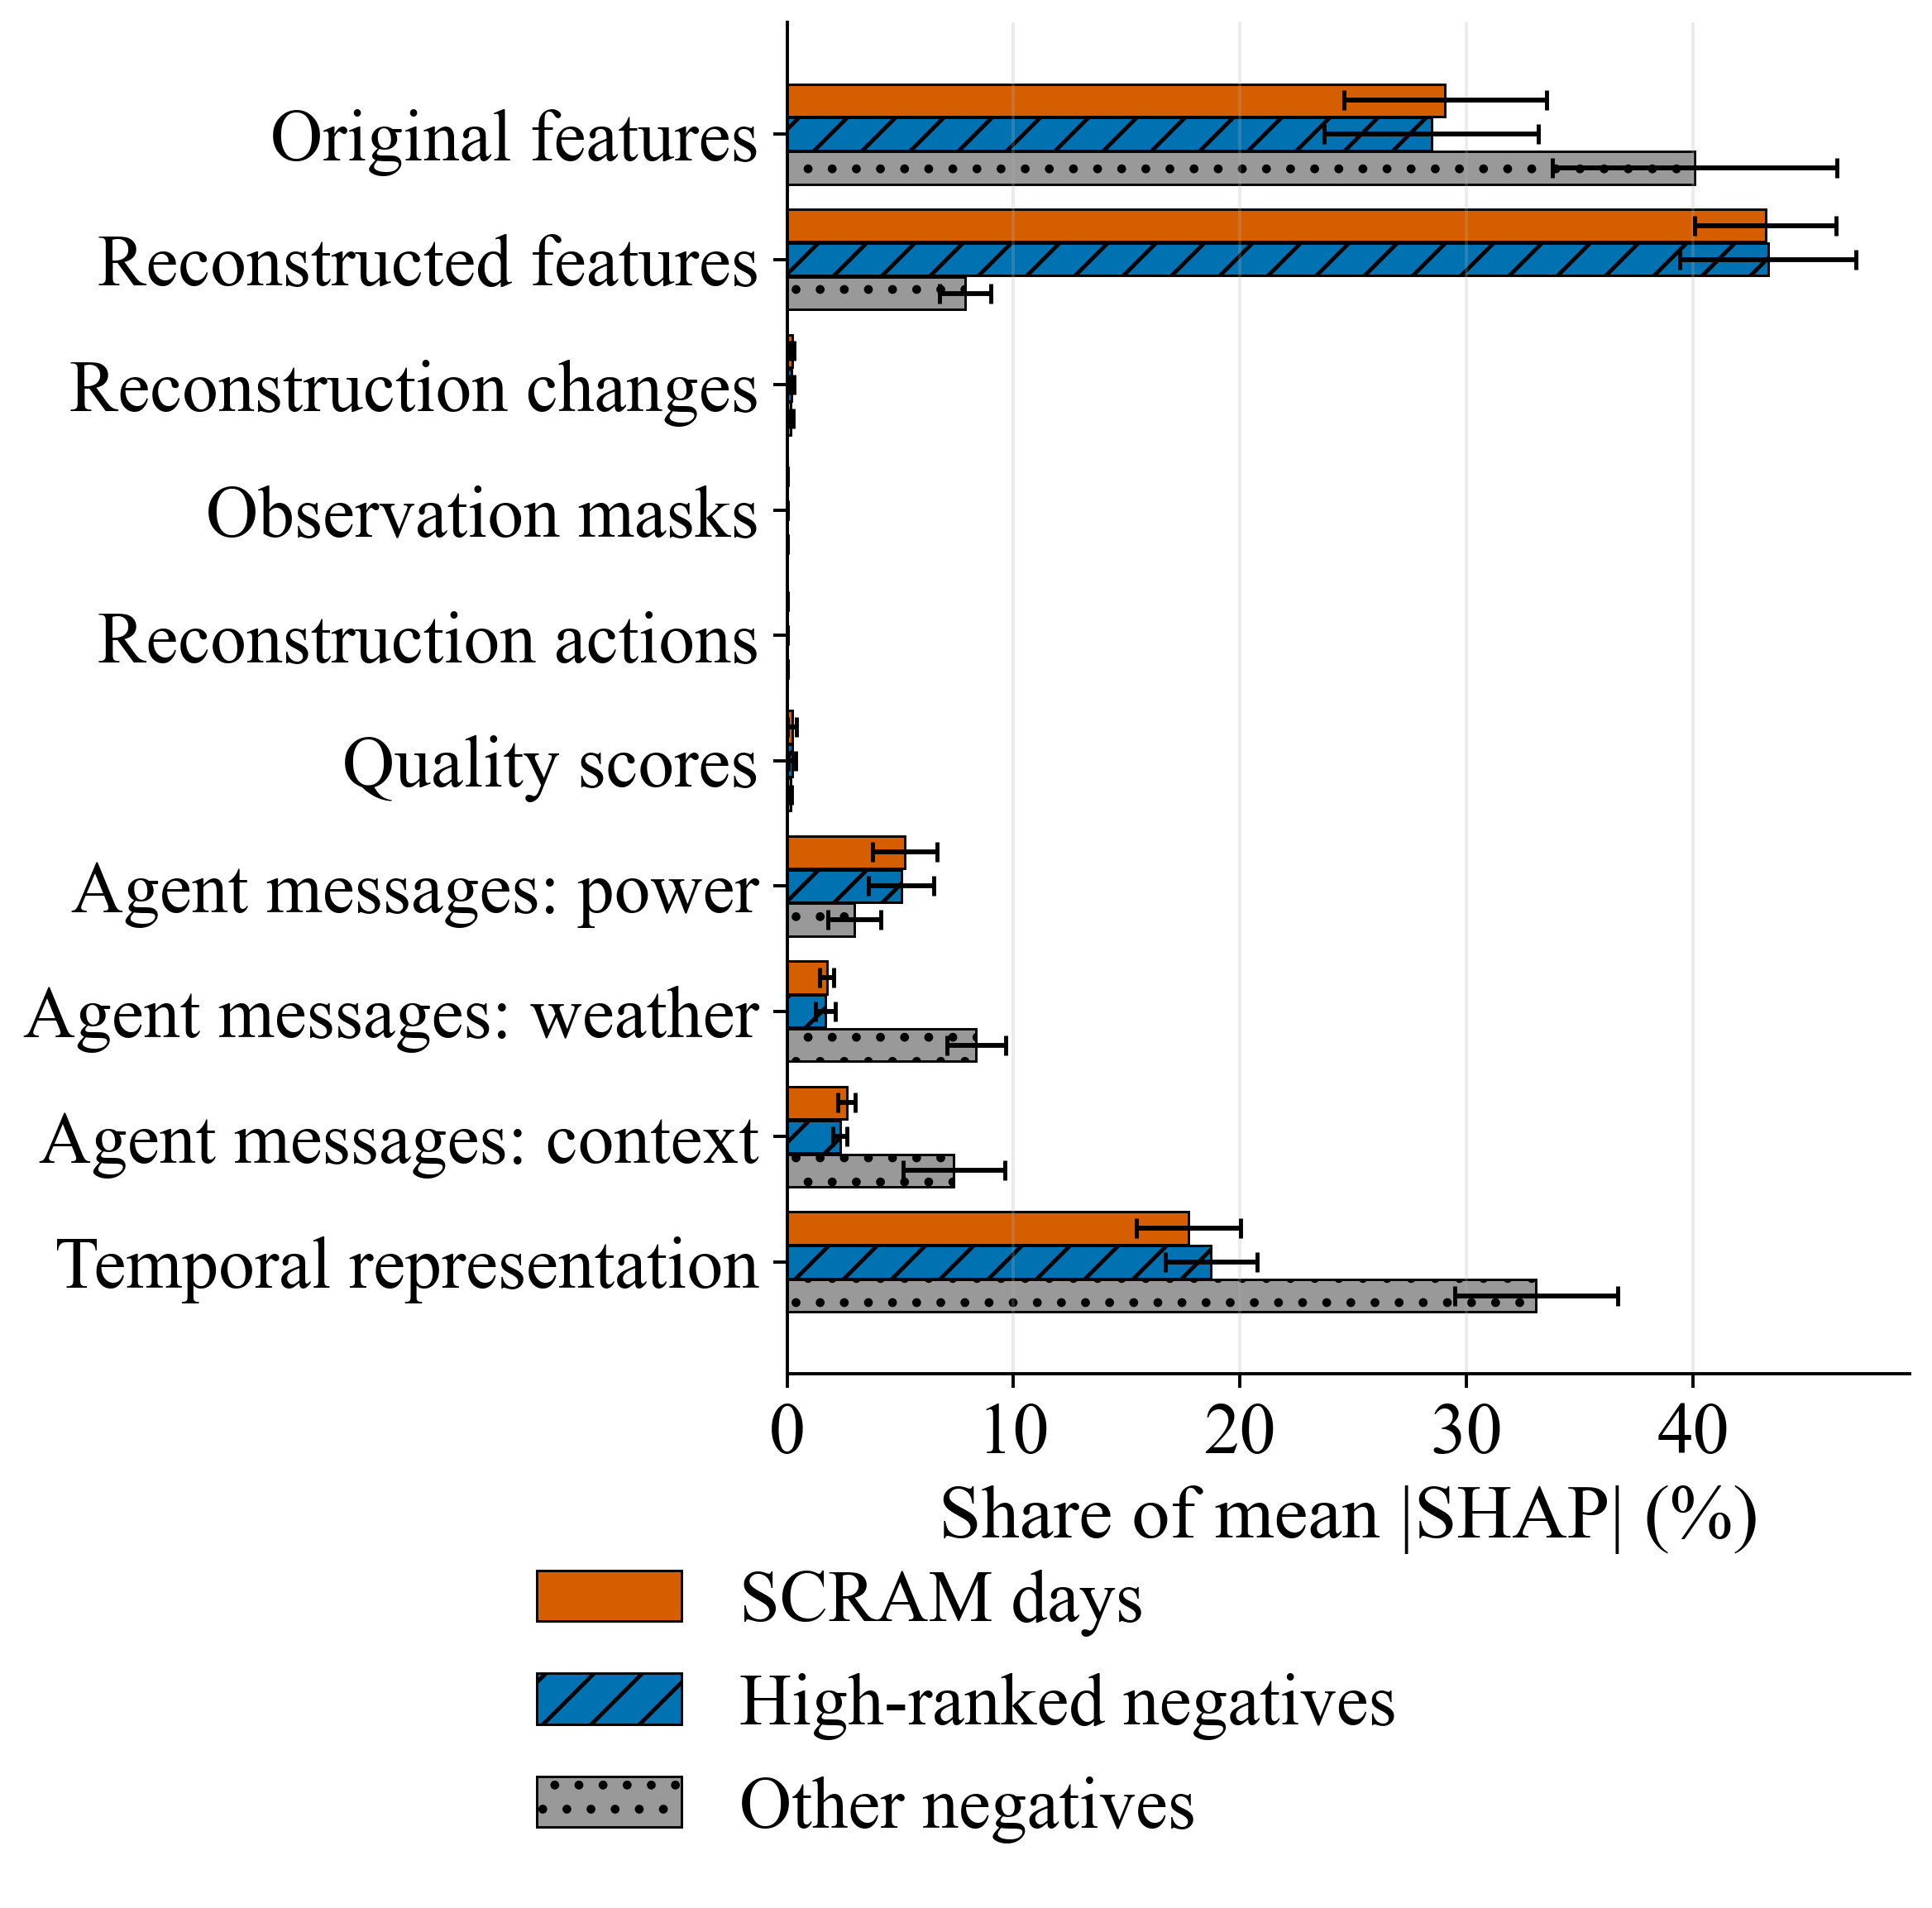

Share of the mean absolute TreeSHAP contribution of each input block of the RACF-Net expert on clean 2023, separately for SCRAM days, high-ranked negative days (at or above the 90%-recall cut-off) and the other negative days; bars are means over three training seeds and whiskers are SDs.

In [8]:
counterfactuals = pd.concat([mechanism[seed][0] for seed in SEEDS], ignore_index=True)
attribution = pd.concat([mechanism[seed][1] for seed in SEEDS], ignore_index=True)

# Agent sets: AP change with the paired site-bootstrap interval (shared replicates, averaged over seeds).
set_rows = []
full_frames = []
for seed in SEEDS:
    scores = mechanism[seed][2]
    assert scores.observation_id.tolist() == test_meta.observation_id.tolist()
    full_frames.append(test_meta[["observation_id", "target", "plant_id"]].assign(raw_score=scores["RACF-Net"].to_numpy(), decision_f1=False))
full_draws = bootstrap_metric_draws(full_frames)
for label in ["All agents", "Power agents", "Weather agents", "Context agents", "All messages removed"]:
    frames = [test_meta[["observation_id", "target", "plant_id"]].assign(raw_score=mechanism[seed][2][label].to_numpy(), decision_f1=False)
              for seed in SEEDS]
    contrast = paired_contrast(full_draws, bootstrap_metric_draws(frames), "AP")
    part = counterfactuals.loc[counterfactuals.Counterfactual.eq(label)]
    set_rows.append({"Counterfactual": label, "AP change, full minus counterfactual": contrast["Difference"],
        "95% CI lower": contrast["95% CI lower"], "95% CI upper": contrast["95% CI upper"], "Bootstrap p": contrast["Bootstrap p"],
        "Seed SD of AP change": part["AP change, full minus counterfactual"].std(ddof=1),
        "Mean |Δ log-odds|, SCRAM days": part["Mean |Δ log-odds|, SCRAM days"].mean(),
        "Mean |Δ log-odds|, high-ranked negatives": part["Mean |Δ log-odds|, high-ranked negatives"].mean(),
        "Mean |Δ log-odds|, other negatives": part["Mean |Δ log-odds|, other negatives"].mean(),
        "TP change per seed": part["TP change"].mean(), "FP change per seed": part["FP change"].mean()})
set_table = pd.DataFrame(set_rows)
shown = pd.DataFrame({"Counterfactual": set_table.Counterfactual,
    "AP change [95% CI]": [signed(d, 4) + " " + interval(l, u, 4) for d, l, u in
                           zip(set_table.iloc[:, 1], set_table["95% CI lower"], set_table["95% CI upper"])],
    "Bootstrap p": [p_text(v) for v in set_table["Bootstrap p"]],
    "Seed SD": [typographic(v, 4) for v in set_table["Seed SD of AP change"]],
    "|Δ log-odds|, SCRAM days": [typographic(v, 3) for v in set_table["Mean |Δ log-odds|, SCRAM days"]],
    "|Δ log-odds|, high-ranked negatives": [typographic(v, 3) for v in set_table["Mean |Δ log-odds|, high-ranked negatives"]],
    "|Δ log-odds|, other negatives": [typographic(v, 3) for v in set_table["Mean |Δ log-odds|, other negatives"]],
    "TP change": [signed(v, 2) for v in set_table["TP change per seed"]],
    "FP change": [signed(v, 2) for v in set_table["FP change per seed"]]})
rv2_table(set_table, "agent_set_counterfactuals",
          "Inference-time counterfactuals of the agent team on clean 2023 (no refit): AP change = full RACF-Net minus "
          "counterfactual, mean over three training seeds with the paired site-bootstrap 95% CI; a negative value means "
          "that the exchange-derived messages lower AP; TP and FP changes at the fixed 2022 F1 threshold, per seed", shown=shown)

single = counterfactuals.loc[counterfactuals.Kind.eq("Single agent")]
agent_table = single.groupby(["Counterfactual", "Group"], as_index=False, sort=False).agg(
    mean_change=("AP change, full minus counterfactual", "mean"), sd_change=("AP change, full minus counterfactual", "std"),
    lowered=("AP change, full minus counterfactual", lambda v: int((v < 0).sum())),
    scram=("Mean |Δ log-odds|, SCRAM days", "mean"), high=("Mean |Δ log-odds|, high-ranked negatives", "mean"),
    fp=("FP change", "mean"))
agent_table = agent_table.sort_values(["Group", "mean_change"]).reset_index(drop=True)
agent_table.columns = ["Agent (predictor)", "Group", "AP change, mean over seeds", "AP change, SD over seeds",
                       "Seeds in which the exchange lowers AP", "Mean |Δ log-odds|, SCRAM days",
                       "Mean |Δ log-odds|, high-ranked negatives", "FP change per seed"]
shown = agent_table.copy()
shown["AP change, mean over seeds"] = [signed(v, 4) for v in shown["AP change, mean over seeds"]]
shown["AP change, SD over seeds"] = [typographic(v, 4) for v in shown["AP change, SD over seeds"]]
shown["Seeds in which the exchange lowers AP"] = [f"{v}/3" for v in shown["Seeds in which the exchange lowers AP"]]
for column in ["Mean |Δ log-odds|, SCRAM days", "Mean |Δ log-odds|, high-ranked negatives"]:
    shown[column] = [typographic(v, 3) for v in shown[column]]
shown["FP change per seed"] = [signed(v, 2) for v in shown["FP change per seed"]]
half = (len(shown) + 1) // 2
caption = ("Per-agent decomposition (inference only): the exchange-derived state of one agent is replaced by its state "
           "without exchange; AP change = full minus counterfactual over three training seeds")
rv2_table(agent_table, "agent_counterfactuals_by_agent", caption, shown=shown,
          parts=[(caption + f" (agents 1–{half})", slice(0, half)), (caption + f" (agents {half + 1}–{len(shown)})", slice(half, None))])

block_mean = attribution.groupby(["Rows", "Block"], sort=False).agg(
    share=("Share of mean |SHAP| (%)", "mean"), share_sd=("Share of mean |SHAP| (%)", "std"),
    signed=("Mean signed SHAP (log-odds)", "mean"), signed_sd=("Mean signed SHAP (log-odds)", "std")).reset_index()
signed_table = block_mean.pivot(index="Block", columns="Rows", values="signed").loc[BLOCK_ORDER]
signed_sd = block_mean.pivot(index="Block", columns="Rows", values="signed_sd").loc[BLOCK_ORDER]
row_groups = ["SCRAM days", "High-ranked negatives", "Other negatives"]
numeric = signed_table[row_groups].reset_index()
shown = pd.DataFrame({"Input block": BLOCK_ORDER,
    **{group: [signed(m, 3) + " ± " + typographic(s, 3) for m, s in zip(signed_table[group], signed_sd[group])] for group in row_groups}})
rv2_table(numeric, "expert_attribution_signed",
          "Mean signed TreeSHAP contribution of each input block to the expert log-odds, clean 2023 (mean ± SD over three "
          "training seeds); positive values raise the SCRAM score", shown=shown)
rv2_save_frame(attribution, RV2_TABLES / "expert_attribution_all_seeds.csv")

colors = {"SCRAM days": "#D55E00", "High-ranked negatives": "#0072B2", "Other negatives": "#999999"}
hatches = {"SCRAM days": "", "High-ranked negatives": "//", "Other negatives": ".."}
fig, ax = plt.subplots(figsize=(6.6, 6.6), layout="constrained")
positions = np.arange(len(BLOCK_ORDER))
for offset, group in zip([-0.27, 0.0, 0.27], row_groups):
    part = block_mean.loc[block_mean.Rows.eq(group)].set_index("Block").loc[BLOCK_ORDER]
    ax.barh(positions + offset, part.share, height=0.26, xerr=part.share_sd, color=colors[group], hatch=hatches[group],
            edgecolor="black", linewidth=0.6, error_kw={"elinewidth": 1.2, "capsize": 2.5}, label=group)
ax.set_yticks(positions)
ax.set_yticklabels(BLOCK_ORDER)
ax.invert_yaxis()
ax.set_xlabel("Share of mean |SHAP| (%)")
ax.set_xlim(0, None)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.legend(loc="outside lower center", ncol=1, frameon=False)
rv2_figure(fig, "expert_attribution_by_block", 6.6)
display(Markdown("Share of the mean absolute TreeSHAP contribution of each input block of the RACF-Net expert on clean 2023, "
                 "separately for SCRAM days, high-ranked negative days (at or above the 90%-recall cut-off) and the other "
                 "negative days; bars are means over three training seeds and whiskers are SDs."))

### 6. Statistical power of the 2023 assessment

In [9]:
contrasts_first = pd.read_csv(first_verified(FIRST_TABLES / "paired_site_bootstrap_contrasts.csv"))
model_order = list(dict.fromkeys(test_decisions.model))
model_draws = {}
for model in model_order:
    if model == "Majority":
        continue
    frames = [part for _, part in test_decisions.loc[test_decisions.model.eq(model)].groupby("seed", sort=True)]
    draws, observed = bootstrap_metric_draws(frames)
    model_draws[model] = {**draws, "observed": observed}
primary_comparators = ["Matched CatBoost", "Matched LightGBM", "Matched TCN"]
secondary_comparators = list(contrasts_first.loc[contrasts_first.Family.eq("Secondary"), "Comparator"].unique())
reproduced = pd.concat([contrasts(primary_comparators, "Primary"), contrasts(secondary_comparators, "Secondary")], ignore_index=True)
check_columns = ["Difference", "95% CI lower", "95% CI upper", "Bootstrap p", "Holm p"]
assert reproduced[["Comparator", "Metric"]].equals(contrasts_first[["Comparator", "Metric"]])
assert np.allclose(reproduced[check_columns].to_numpy(float), contrasts_first[check_columns].to_numpy(float), rtol=0, atol=1e-12)

z_power = stats.norm.ppf(0.80)
power_rows = []
for family, comparators, size in [("Primary", primary_comparators, 9), ("Secondary", secondary_comparators, 33)]:
    for comparator in comparators:
        for metric in ["AP", "F1", "MCC"]:
            delta = model_draws["RACF-Net"][metric] - model_draws[comparator][metric]
            se = float(delta[np.isfinite(delta)].std(ddof=1))
            observed = model_draws["RACF-Net"]["observed"][metric] - model_draws[comparator]["observed"][metric]
            mde = (stats.norm.ppf(0.975) + z_power) * se
            mde_holm = (stats.norm.ppf(1 - 0.05 / (2 * size)) + z_power) * se
            factor = (mde_holm / abs(observed)) ** 2 if abs(observed) >= 1e-3 else np.nan
            power_rows.append({"Family": family, "Comparator": comparator, "Metric": metric, "Difference": observed,
                "Bootstrap SE": se, "MDE, α = 0.05": mde, "MDE, first Holm step": mde_holm,
                "|Difference| / MDE, first Holm step": abs(observed) / mde_holm,
                "Approximate sites needed": 50 * factor, "Approximate SCRAM days needed": 42 * factor})
power = pd.DataFrame(power_rows)


def power_shown(frame):
    return pd.DataFrame({"Comparator": frame.Comparator, "Metric": frame.Metric,
        "Difference": [signed(v, 3) for v in frame.Difference], "Bootstrap SE": [typographic(v, 3) for v in frame["Bootstrap SE"]],
        "MDE, α = 0.05": [typographic(v, 3) for v in frame["MDE, α = 0.05"]],
        "MDE, first Holm step": [typographic(v, 3) for v in frame["MDE, first Holm step"]],
        "|Difference| / MDE": [typographic(v, 2) for v in frame["|Difference| / MDE, first Holm step"]],
        "Approximate sites needed": ["not estimable (|Δ| < 0.001)" if not np.isfinite(v) else f"≈ {v:,.0f}" for v in frame["Approximate sites needed"]],
        "Approximate SCRAM days needed": ["not estimable (|Δ| < 0.001)" if not np.isfinite(v) else f"≈ {v:,.0f}" for v in frame["Approximate SCRAM days needed"]]})


primary_power = power.loc[power.Family.eq("Primary")].reset_index(drop=True)
rv2_table(primary_power, "power_primary_family",
          "Minimum detectable effects for the primary contrasts (RACF-Net minus matched controls, clean 2023; 50 sites, "
          "42 SCRAM days; paired site bootstrap reproduced exactly; 80% power; first Holm step α = 0.05/9)",
          shown=power_shown(primary_power))
secondary_power = power.loc[power.Family.eq("Secondary")].copy()
secondary_power["metric_order"] = secondary_power.Metric.map({"AP": 0, "F1": 1, "MCC": 2})
secondary_power = secondary_power.sort_values("metric_order", kind="mergesort").drop(columns="metric_order").reset_index(drop=True)
assert secondary_power.Metric.tolist() == ["AP"] * 11 + ["F1"] * 11 + ["MCC"] * 11
caption = ("Minimum detectable effects for the secondary contrasts (RACF-Net minus reference and modern methods, clean "
           "2023; 80% power; first Holm step α = 0.05/33)")
rv2_table(secondary_power, "power_secondary_family", caption, shown=power_shown(secondary_power),
          parts=[(caption + f" — {metric}", slice(i * 11, (i + 1) * 11)) for i, metric in enumerate(["AP", "F1", "MCC"])])

component_2023 = pd.read_csv(OUTPUT_ROOT / "Tables/racf_components_20261014_002554/component_paired_contrasts.csv")
historical = pd.read_csv(OUTPUT_ROOT / "Tables/racf_targeted_20261014/Evaluation/secondary_components.csv")
historical = historical.loc[historical.Comparator.isin(["no_agents", "no_peer"])].copy()
component_rows = []
z_975 = stats.norm.ppf(0.975)
for cohort, frame, effect, lower, upper, size, rename in [
        ("2023", component_2023, "Full_minus_ablation", "Lower_95", "Upper_95", len(component_2023), {}),
        ("2025–2026", historical, "Effect", "Lower 95%", "Upper 95%", int(historical["Family size"].iloc[0]),
         {"no_agents": "No numerical agents", "no_peer": "No peer exchange"})]:
    for _, row in frame.iterrows():
        observed, low, high = float(row[effect]), float(row[lower]), float(row[upper])
        se = (high - low) / (2 * z_975)
        mde_holm = (stats.norm.ppf(1 - 0.05 / (2 * size)) + z_power) * se
        component_rows.append({"Cohort": cohort, "Removed component": rename.get(row.Comparator, row.Comparator),
            "Metric": row.Metric, "Difference (full minus ablation)": observed, "Approximate SE": se,
            "MDE, α = 0.05": (z_975 + z_power) * se, "MDE, first Holm step": mde_holm, "Family size": size,
            "|Difference| / MDE, first Holm step": abs(observed) / mde_holm})
component_power = pd.DataFrame(component_rows)
shown = pd.DataFrame({"Cohort": component_power.Cohort, "Removed component": component_power["Removed component"],
    "Metric": component_power.Metric, "Difference": [signed(v, 4) for v in component_power["Difference (full minus ablation)"]],
    "Approximate SE": [typographic(v, 4) for v in component_power["Approximate SE"]],
    "MDE, α = 0.05": [typographic(v, 4) for v in component_power["MDE, α = 0.05"]],
    "MDE, first Holm step": [typographic(v, 4) for v in component_power["MDE, first Holm step"]],
    "|Difference| / MDE": [typographic(v, 2) for v in component_power["|Difference| / MDE, first Holm step"]]})
rv2_table(component_power, "power_component_contrasts",
          "Minimum detectable effects for the component contrasts; SE approximated as the width of the reported 95% "
          "interval divided by 2 × 1.96; first Holm step uses the family size of the original analysis", shown=shown)

**Minimum detectable effects for the primary contrasts (RACF-Net minus matched controls, clean 2023; 50 sites, 42 SCRAM days; paired site bootstrap reproduced exactly; 80% power; first Holm step α = 0.05/9)**

,Comparator,Metric,Difference,Bootstrap SE,"MDE, α = 0.05","MDE, first Holm step",|Difference| / MDE,Approximate sites needed,Approximate SCRAM days needed
1,Matched CatBoost,AP,+0.053,0.040,0.112,0.145,0.36,≈ 377,≈ 317
2,Matched CatBoost,F1,+0.034,0.019,0.053,0.069,0.49,≈ 211,≈ 177
3,Matched CatBoost,MCC,+0.035,0.019,0.053,0.069,0.50,≈ 198,≈ 166
4,Matched LightGBM,AP,−0.018,0.024,0.067,0.086,0.20,"≈ 1,208","≈ 1,015"
5,Matched LightGBM,F1,+0.021,0.029,0.080,0.103,0.20,"≈ 1,227","≈ 1,031"
6,Matched LightGBM,MCC,+0.022,0.028,0.078,0.101,0.22,"≈ 1,056",≈ 887
7,Matched TCN,AP,−0.019,0.026,0.073,0.094,0.20,"≈ 1,196","≈ 1,004"
8,Matched TCN,F1,+0.050,0.018,0.049,0.063,0.79,≈ 80,≈ 67
9,Matched TCN,MCC,+0.050,0.017,0.048,0.062,0.80,≈ 78,≈ 66


**Minimum detectable effects for the secondary contrasts (RACF-Net minus reference and modern methods, clean 2023; 80% power; first Holm step α = 0.05/33) — AP**

,Comparator,Metric,Difference,Bootstrap SE,"MDE, α = 0.05","MDE, first Holm step",|Difference| / MDE,Approximate sites needed,Approximate SCRAM days needed
1,Power-drop rule,AP,+0.141,0.071,0.199,0.285,0.50,≈ 204,≈ 171
2,Recent-level deviation,AP,−0.003,0.039,0.108,0.155,0.02,"≈ 113,235","≈ 95,118"
3,Logistic Regression,AP,−0.020,0.030,0.083,0.119,0.16,"≈ 1,861","≈ 1,563"
4,Random Forest,AP,+0.018,0.023,0.064,0.092,0.20,"≈ 1,298","≈ 1,090"
5,CatBoost,AP,−0.016,0.016,0.046,0.066,0.24,≈ 888,≈ 746
6,LightGBM,AP,−0.046,0.031,0.088,0.126,0.37,≈ 369,≈ 310
7,MultiRocket + context,AP,+0.013,0.048,0.135,0.193,0.07,"≈ 11,506","≈ 9,665"
8,Hydra + context,AP,+0.133,0.062,0.174,0.250,0.53,≈ 176,≈ 148
9,Inception + context,AP,−0.033,0.036,0.102,0.146,0.23,≈ 963,≈ 809
10,TCN + context,AP,−0.040,0.027,0.075,0.107,0.37,≈ 362,≈ 304


**Minimum detectable effects for the secondary contrasts (RACF-Net minus reference and modern methods, clean 2023; 80% power; first Holm step α = 0.05/33) — F1**

,Comparator,Metric,Difference,Bootstrap SE,"MDE, α = 0.05","MDE, first Holm step",|Difference| / MDE,Approximate sites needed,Approximate SCRAM days needed
1,Power-drop rule,F1,+0.124,0.039,0.109,0.156,0.79,≈ 79,≈ 67
2,Recent-level deviation,F1,+0.109,0.061,0.170,0.244,0.45,≈ 249,≈ 209
3,Logistic Regression,F1,+0.056,0.023,0.066,0.094,0.60,≈ 140,≈ 118
4,Random Forest,F1,+0.009,0.018,0.050,0.072,0.13,"≈ 3,198","≈ 2,686"
5,CatBoost,F1,+0.025,0.027,0.076,0.109,0.23,≈ 963,≈ 809
6,LightGBM,F1,+0.015,0.035,0.098,0.140,0.11,"≈ 4,414","≈ 3,707"
7,MultiRocket + context,F1,+0.115,0.034,0.094,0.135,0.85,≈ 69,≈ 58
8,Hydra + context,F1,+0.137,0.038,0.108,0.154,0.88,≈ 64,≈ 54
9,Inception + context,F1,+0.043,0.026,0.072,0.103,0.42,≈ 283,≈ 238
10,TCN + context,F1,+0.029,0.028,0.077,0.111,0.26,≈ 717,≈ 602


**Minimum detectable effects for the secondary contrasts (RACF-Net minus reference and modern methods, clean 2023; 80% power; first Holm step α = 0.05/33) — MCC**

,Comparator,Metric,Difference,Bootstrap SE,"MDE, α = 0.05","MDE, first Holm step",|Difference| / MDE,Approximate sites needed,Approximate SCRAM days needed
1,Power-drop rule,MCC,+0.125,0.039,0.109,0.156,0.80,≈ 78,≈ 65
2,Recent-level deviation,MCC,+0.111,0.060,0.167,0.239,0.46,≈ 234,≈ 197
3,Logistic Regression,MCC,+0.052,0.021,0.060,0.086,0.61,≈ 134,≈ 113
4,Random Forest,MCC,+0.010,0.017,0.049,0.070,0.14,"≈ 2,656","≈ 2,231"
5,CatBoost,MCC,+0.026,0.026,0.074,0.106,0.24,≈ 852,≈ 716
6,LightGBM,MCC,+0.015,0.034,0.094,0.135,0.11,"≈ 3,793","≈ 3,186"
7,MultiRocket + context,MCC,+0.113,0.033,0.093,0.133,0.84,≈ 70,≈ 59
8,Hydra + context,MCC,+0.136,0.039,0.109,0.156,0.87,≈ 66,≈ 56
9,Inception + context,MCC,+0.044,0.026,0.072,0.103,0.43,≈ 269,≈ 226
10,TCN + context,MCC,+0.030,0.027,0.075,0.108,0.27,≈ 669,≈ 562


**Minimum detectable effects for the component contrasts; SE approximated as the width of the reported 95% interval divided by 2 × 1.96; first Holm step uses the family size of the original analysis**

,Cohort,Removed component,Metric,Difference,Approximate SE,"MDE, α = 0.05","MDE, first Holm step",|Difference| / MDE
1,2023,No numerical agents,AP,−0.0138,0.0110,0.0310,0.0424,0.33
2,2023,No peer exchange,AP,−0.0090,0.0095,0.0266,0.0364,0.25
3,2023,No restoration,AP,+0.0261,0.0145,0.0407,0.0557,0.47
4,2023,No temporal latent,AP,+0.0060,0.0177,0.0495,0.0677,0.09
5,2023,No direct quality inputs,AP,+0.0019,0.0017,0.0049,0.0067,0.29
6,2023,No direct action inputs,AP,+0.0015,0.0029,0.0082,0.0113,0.14
7,2023,No numerical agents,F1,+0.0218,0.0129,0.0362,0.0495,0.44
8,2023,No peer exchange,F1,+0.0248,0.0176,0.0493,0.0674,0.37
9,2023,No restoration,F1,+0.0408,0.0180,0.0504,0.0689,0.59
10,2023,No temporal latent,F1,+0.0134,0.0220,0.0616,0.0843,0.16


### 7. Graded reactor-power degradation

In [10]:
GRADED_LEVELS = {"Reactor-power MCAR": [0, 5, 10, 20, 30, 40, 50], "Reactor-power noise": [0, 0.5, 1, 2, 3, 5]}


def graded_name(family, level):
    if level == 0:
        return "clean"
    text = str(int(level)) if float(level).is_integer() else str(level)
    return ("power_mcar_" if family == "Reactor-power MCAR" else "power_noise_") + text


GRADED_SCENARIOS = sorted({graded_name(family, level) for family, levels in GRADED_LEVELS.items() for level in levels} - {"clean"})
_tree = ast.parse(_NB05_CELLS["v2-corruption-apply"])
_function = next(node for node in _tree.body if isinstance(node, ast.FunctionDef) and node.name == "racf_corrupt")
_function.name = "racf_corrupt_graded"
_registered = None
for node in ast.walk(_function):
    if isinstance(node, ast.Assign) and any(isinstance(target, ast.Name) and target.id == "permitted" for target in node.targets):
        _registered = ast.literal_eval(node.value)
        node.value = ast.parse(repr(sorted(_registered | set(GRADED_SCENARIOS)))).body[0].value
assert _registered is not None and {"power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"} <= _registered
exec(compile(ast.fix_missing_locations(ast.Module(body=[_function], type_ignores=[])), "<graded corruption>", "exec"), globals())
probe = TEST_IDX[:2048]
for scenario in ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"]:
    for stream in [2026, 42]:
        registered = racf_corrupt(sequences[probe], features.iloc[probe], metadata.iloc[probe], scenario, stream)
        graded = racf_corrupt_graded(sequences[probe], features.iloc[probe], metadata.iloc[probe], scenario, stream)
        assert np.array_equal(registered[0], graded[0], equal_nan=True)
        pd.testing.assert_frame_equal(registered[1], graded[1])

LIGHTGBM_SCORE_SOURCE = """
import sys, joblib, numpy as np, pandas as pd
from pathlib import Path
folder, template = Path(sys.argv[1]), sys.argv[2]
frame = pd.read_parquet(folder / "inputs.parquet")
for seed in (42, 137, 2026):
    model = joblib.load(template.format(seed=seed))
    np.save(folder / f"score_{seed}.npy", model.predict_proba(frame)[:, 1])
"""
for seed in SEEDS:
    first_verified(FIRST_ROOT / "Comparators" / f"lightgbm_temporal_seed{seed}.joblib")


def lightgbm_comparator_scores(frame):
    """Scores of the saved LightGBM comparators (three seeds) on a perturbed feature table, in an isolated process."""
    with tempfile.TemporaryDirectory(prefix="rv2_lightgbm_score_") as directory:
        folder = Path(directory)
        frame.to_parquet(folder / "inputs.parquet")
        template = str(FIRST_ROOT / "Comparators" / "lightgbm_temporal_seed{seed}.joblib")
        subprocess.run([sys.executable, "-c", LIGHTGBM_SCORE_SOURCE, str(folder), template],
                       check=True, capture_output=True, text=True, timeout=3600)
        return {seed: np.load(folder / f"score_{seed}.npy") for seed in SEEDS}


GRADED_FAMILIES = ["RACF-Net", "LightGBM", "TCN"]
first_matched = {}
for family in GRADED_FAMILIES:
    for seed in SEEDS:
        frame = pd.read_parquet(first_verified(FIRST_PREDICTIONS / "matched" / f"{slug(MATCHED_NAMES[family])}_s{seed}.parquet"))
        first_matched[(family, seed)] = frame.loc[frame.cohort.eq("Test 2023")]
saved_lightgbm = pd.read_parquet(first_verified(FIRST_PREDICTIONS / "comparators" / "lightgbm.parquet"))
saved_lightgbm = saved_lightgbm.loc[saved_lightgbm.cohort.eq("Test 2023")]
packages = {}


def graded_case(scenario, stream, progress):
    path = RV2_PREDICTIONS / "graded" / f"{scenario}_stream{stream}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    progress.update(Markdown(f"Graded degradation: {scenario}, stream {stream}: corrupting the 2023 cohort."))
    raw, frame, _ = racf_corrupt_graded(sequences[TEST_IDX], features.iloc[TEST_IDX], metadata.iloc[TEST_IDX], scenario, stream)
    parts = []
    for family in GRADED_FAMILIES:
        for seed in SEEDS:
            saved = first_matched[(family, seed)]
            saved = saved.loc[saved.scenario.eq(scenario) & saved.noise_seed.eq(stream)]
            if len(saved):
                assert saved.observation_id.tolist() == test_meta.observation_id.tolist()
                scores = saved.raw_score.to_numpy()
            else:
                progress.update(Markdown(f"Graded degradation: {scenario}, stream {stream}: scoring {MATCHED_NAMES[family]}, seed {seed}."))
                if (family, seed) not in packages:
                    packages[(family, seed)] = joblib.load(matched_checkpoints[(family, seed)])
                package = packages[(family, seed)]
                scores = np.concatenate([package.predict(raw[start:start + 2048], frame.iloc[start:start + 2048],
                                                         metadata.iloc[TEST_IDX[start:start + 2048]])
                                         for start in range(0, len(TEST_IDX), 2048)])
            parts.append(pd.DataFrame({"observation_id": test_meta.observation_id, "raw_score": scores,
                                       "model": MATCHED_NAMES[family], "seed": seed}))
    for seed, scores in lightgbm_comparator_scores(frame).items():
        parts.append(pd.DataFrame({"observation_id": test_meta.observation_id, "raw_score": scores, "model": "LightGBM", "seed": seed}))
    result = pd.concat(parts, ignore_index=True).assign(scenario=scenario, stream=stream)
    rv2_save_frame(result, path)
    return result


progress = display(Markdown("Preparing graded degradation."), display_id=True)
graded_cases = {}
for family, levels in GRADED_LEVELS.items():
    for level in levels:
        scenario = graded_name(family, level)
        for stream in ([2026] if scenario == "clean" else STREAMS):
            if (scenario, stream) not in graded_cases:
                graded_cases[(scenario, stream)] = graded_case(scenario, stream, progress)
packages.clear()
gc.collect()
clean_case = graded_cases[("clean", 2026)]
for seed in SEEDS:
    ours = clean_case.loc[clean_case.model.eq("LightGBM") & clean_case.seed.eq(seed)]
    reference = saved_lightgbm.loc[saved_lightgbm.seed.eq(seed)]
    assert ours.observation_id.tolist() == reference.observation_id.tolist()
    assert np.max(np.abs(ours.raw_score.to_numpy() - reference.raw_score.to_numpy())) < 1e-12
progress.update(Markdown(f"Graded degradation completed: {len(graded_cases)} perturbation cases, 4 models, 3 training seeds."))

Graded degradation completed: 34 perturbation cases, 4 models, 3 training seeds.

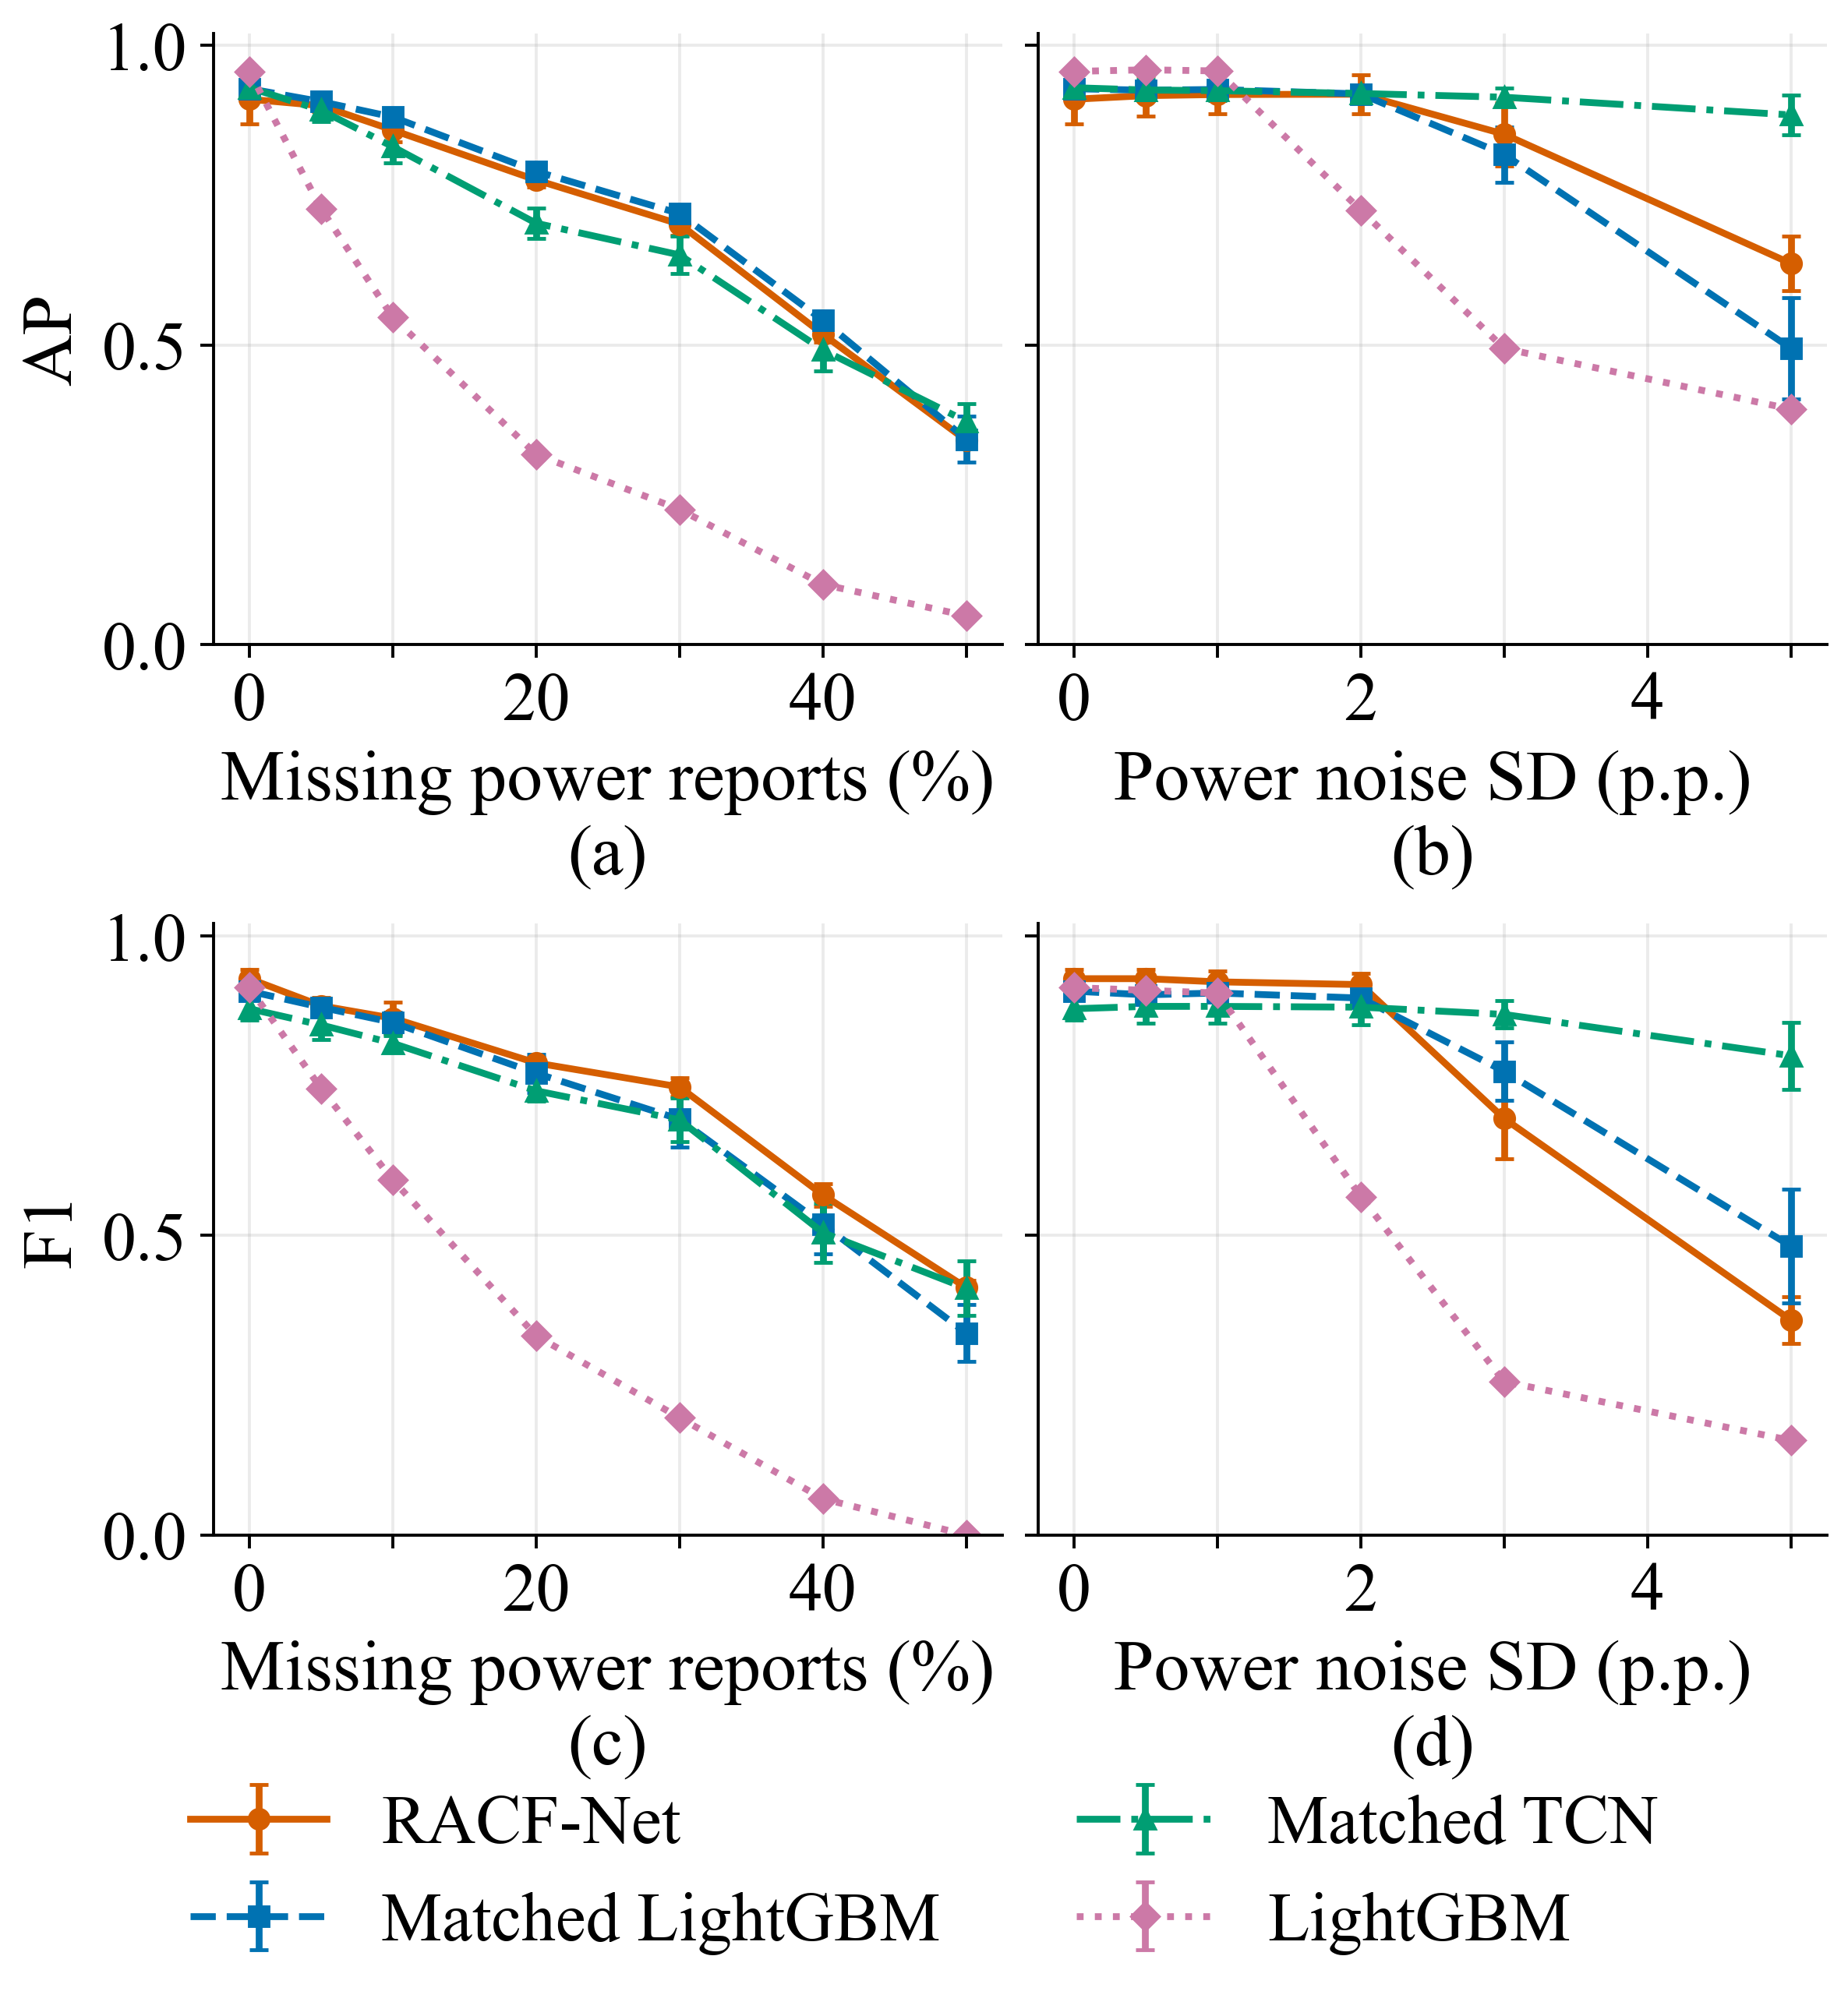

Performance on the 2023 cohort under graded reactor-power degradation with frozen models, calibrators and F1 thresholds: (a) AP and (c) F1 versus the share of power reports removed completely at random; (b) AP and (d) F1 versus the standard deviation of additive Gaussian power noise. Markers are means over three training seeds (each the mean of three corruption streams); whiskers are SDs over seeds.

**Reactor-power MCAR: SCRAM recall, missed SCRAM days (of 42) and false alarms per 1000 negative reactor-days at the fixed 2022 F1 threshold (mean ± SD over three training seeds)**

,Missing reports (%),Model,Recall,Missed SCRAM days,False alarms per 1000
1,0.0,RACF-Net,0.976 ± 0.000,1.00,0.263 ± 0.075
2,0.0,Matched LightGBM,0.897 ± 0.014,4.33,0.164 ± 0.028
3,0.0,Matched TCN,0.913 ± 0.050,3.67,0.345 ± 0.178
4,0.0,LightGBM,0.881 ± 0.000,5.00,0.099 ± 0.000
5,5.0,RACF-Net,0.931 ± 0.009,2.89,0.367 ± 0.068
6,5.0,Matched LightGBM,0.860 ± 0.030,5.89,0.192 ± 0.041
7,5.0,Matched TCN,0.865 ± 0.021,5.67,0.350 ± 0.173
8,5.0,LightGBM,0.643 ± 0.000,15.00,0.164 ± 0.000
9,10.0,RACF-Net,0.884 ± 0.009,4.89,0.345 ± 0.134
10,10.0,Matched LightGBM,0.810 ± 0.041,8.00,0.170 ± 0.058


**Reactor-power noise: SCRAM recall, missed SCRAM days (of 42) and false alarms per 1000 negative reactor-days at the fixed 2022 F1 threshold (mean ± SD over three training seeds)**

,Noise SD (p.p.),Model,Recall,Missed SCRAM days,False alarms per 1000
1,0.0,RACF-Net,0.976 ± 0.000,1.00,0.263 ± 0.075
2,0.0,Matched LightGBM,0.897 ± 0.014,4.33,0.164 ± 0.028
3,0.0,Matched TCN,0.913 ± 0.050,3.67,0.345 ± 0.178
4,0.0,LightGBM,0.881 ± 0.000,5.00,0.099 ± 0.000
5,0.5,RACF-Net,0.976 ± 0.000,1.00,0.263 ± 0.075
6,0.5,Matched LightGBM,0.886 ± 0.032,4.78,0.164 ± 0.028
7,0.5,Matched TCN,0.923 ± 0.032,3.22,0.356 ± 0.192
8,0.5,LightGBM,0.873 ± 0.000,5.33,0.099 ± 0.000
9,1.0,RACF-Net,0.968 ± 0.008,1.33,0.268 ± 0.066
10,1.0,Matched LightGBM,0.892 ± 0.024,4.56,0.164 ± 0.028


In [11]:
GRADED_MODELS = ["RACF-Net", "Matched LightGBM", "Matched TCN", "LightGBM"]
graded_calibrations = {(model, seed): joblib.load(first_verified(FIRST_ROOT / "Calibration" / f"{slug(model)}_s{seed}_2022.joblib"))
                       for model in GRADED_MODELS for seed in SEEDS}
outcome_columns = test_meta[["observation_id", "target", "plant_id", "event_episode_id", "event_id"]]
graded_rows = []
for family, levels in GRADED_LEVELS.items():
    for level in levels:
        scenario = graded_name(family, level)
        for stream in ([2026] if scenario == "clean" else STREAMS):
            case = graded_cases[(scenario, stream)]
            for (model, seed), part in case.groupby(["model", "seed"], sort=False):
                calibration = graded_calibrations[(model, seed)]
                raw = part.raw_score.to_numpy()
                prediction = outcome_columns.assign(raw_score=raw, probability=calibration.predict(raw),
                                                    decision_f1=calibration.decisions(raw)["f1"])
                metrics_case = racf_metrics(prediction, "f1")
                graded_rows.append({"Perturbation": family, "Level": level, "Model": model, "Seed": seed, "Stream": stream,
                    **{key: metrics_case[key] for key in ["AP", "F1", "Recall", "MCC", "False_alarms_per_1000", "FN"]}})
graded = pd.DataFrame(graded_rows)
rv2_save_frame(graded, RV2_TABLES / "graded_degradation_by_seed_stream.csv")
clean_check = graded.loc[graded.Level.eq(0) & graded.Perturbation.eq("Reactor-power MCAR")].set_index(["Model", "Seed"]).AP
reference = metrics_first.loc[metrics_first.Cohort.eq("Test 2023") & metrics_first.Scenario.eq("clean")].set_index(["Model", "Seed"]).AP
assert np.allclose(clean_check.to_numpy(), reference.loc[clean_check.index].to_numpy(), rtol=0, atol=1e-12)
by_seed = graded.groupby(["Perturbation", "Level", "Model", "Seed"], as_index=False, sort=False)[
    ["AP", "F1", "Recall", "MCC", "False_alarms_per_1000", "FN"]].mean()
summary = by_seed.groupby(["Perturbation", "Level", "Model"], as_index=False, sort=False).agg(
    **{f"{metric} mean": (metric, "mean") for metric in ["AP", "F1", "Recall", "False_alarms_per_1000", "FN"]},
    **{f"{metric} SD": (metric, "std") for metric in ["AP", "F1", "Recall", "False_alarms_per_1000"]})
rv2_save_frame(summary, RV2_TABLES / "graded_degradation_summary.csv")

palette = {"RACF-Net": ("#D55E00", "o", "-"), "Matched LightGBM": ("#0072B2", "s", "--"),
           "Matched TCN": ("#009E73", "^", "-."), "LightGBM": ("#CC79A7", "D", ":")}
fig, axes = plt.subplots(2, 2, figsize=(6.7, 7.4), layout="constrained")
for column, (family, xlabel) in enumerate([("Reactor-power MCAR", "Missing power reports (%)"),
                                           ("Reactor-power noise", "Power noise SD (p.p.)")]):
    for row, metric in enumerate(["AP", "F1"]):
        ax = axes[row, column]
        for model, (color, marker, line) in palette.items():
            part = summary.loc[summary.Perturbation.eq(family) & summary.Model.eq(model)]
            ax.errorbar(part.Level, part[f"{metric} mean"], yerr=part[f"{metric} SD"], color=color, marker=marker,
                        linestyle=line, linewidth=1.8, markersize=5, capsize=2.5, label=model)
        ax.set_ylim(0, 1.02)
        ax.set_xticks([0, 10, 20, 30, 40, 50] if column == 0 else [0, 1, 2, 3, 4, 5])
        ax.set_xticklabels(["0", "", "20", "", "40", ""] if column == 0 else ["0", "", "2", "", "4", ""])
        ax.set_ylabel(metric if column == 0 else "")
        if column == 1:
            ax.set_yticklabels([])
        ax.set_xlabel(xlabel + f"\n({'abcd'[row * 2 + column]})")
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside lower center", ncol=2, frameon=False)
rv2_figure(fig, "graded_power_degradation", 6.7)
display(Markdown("Performance on the 2023 cohort under graded reactor-power degradation with frozen models, calibrators and "
                 "F1 thresholds: (a) AP and (c) F1 versus the share of power reports removed completely at random; (b) AP "
                 "and (d) F1 versus the standard deviation of additive Gaussian power noise. Markers are means over three "
                 "training seeds (each the mean of three corruption streams); whiskers are SDs over seeds."))

for family, unit in [("Reactor-power MCAR", "Missing reports (%)"), ("Reactor-power noise", "Noise SD (p.p.)")]:
    part = summary.loc[summary.Perturbation.eq(family)].reset_index(drop=True)
    shown = pd.DataFrame({unit: [typographic(float(v), 1) for v in part.Level], "Model": part.Model,
        "Recall": [typographic(m, 3) + " ± " + typographic(s, 3) for m, s in zip(part["Recall mean"], part["Recall SD"])],
        "Missed SCRAM days": [typographic(v, 2) for v in part["FN mean"]],
        "False alarms per 1000": [typographic(m, 3) + " ± " + typographic(s, 3)
                                  for m, s in zip(part["False_alarms_per_1000 mean"], part["False_alarms_per_1000 SD"])]})
    rv2_table(part, f"graded_degradation_{slug(family)}_decisions",
              f"{family}: SCRAM recall, missed SCRAM days (of 42) and false alarms per 1000 negative reactor-days at the "
              "fixed 2022 F1 threshold (mean ± SD over three training seeds)", shown=shown)

### 8. Transfer to physical sites excluded from training

In [12]:
cohort_rows = np.r_[TRAIN_IDX, VALID_IDX, TEST_IDX]
all_sites = sorted(set(metadata.iloc[cohort_rows].plant_id))
development_events = metadata.iloc[np.r_[TRAIN_IDX, VALID_IDX]].groupby("plant_id").target.sum()
rng = np.random.default_rng(RV2_SEED)
fold_of, position = {}, 0
for stratum in [[s for s in all_sites if development_events.get(s, 0) > 0], [s for s in all_sites if development_events.get(s, 0) == 0]]:
    for site in np.asarray(stratum)[rng.permutation(len(stratum))]:
        fold_of[str(site)] = position % 5
        position += 1
FOLDS, fold_rows = [], []
for k in range(5):
    held = {site for site, fold in fold_of.items() if fold == k}
    inside = lambda idx: metadata.iloc[idx].plant_id.isin(held).to_numpy()
    train, calibration_rows, assessment = TRAIN_IDX[~inside(TRAIN_IDX)], VALID_IDX[~inside(VALID_IDX)], TEST_IDX[inside(TEST_IDX)]
    racf_validate_training(train, assessment)
    racf_validate_training(train, calibration_rows)
    assert set(metadata.iloc[train].plant_id).isdisjoint(held) and set(metadata.iloc[calibration_rows].plant_id).isdisjoint(held)
    FOLDS.append({"fold": k + 1, "held": held, "train": train, "calibration": calibration_rows, "assessment": assessment})
    fold_rows.append({"Fold": k + 1, "Held-out sites": len(held),
        "Training reactor-days": len(train), "Training SCRAM days": int(metadata.iloc[train].target.sum()),
        "Calibration reactor-days": len(calibration_rows), "Calibration SCRAM days": int(metadata.iloc[calibration_rows].target.sum()),
        "Assessment reactor-days": len(assessment), "Assessment SCRAM days": int(metadata.iloc[assessment].target.sum()),
        "Assessment sites with SCRAM": int(metadata.iloc[assessment].loc[lambda f: f.target.eq(1)].plant_id.nunique())})
assert np.array_equal(np.sort(np.concatenate([fold["assessment"] for fold in FOLDS])), np.sort(TEST_IDX))
fold_table = pd.DataFrame(fold_rows)
rv2_save_frame(pd.DataFrame({"plant_id": list(fold_of), "fold": [fold + 1 for fold in fold_of.values()]}),
               RV2_TABLES / "site_transfer_fold_assignment.csv")
rv2_table(fold_table, "site_transfer_folds",
          "Site-disjoint folds: training 2019–2021 and calibration 2022 on the remaining sites, assessment 2023 on the held-out sites")

_NB03_CELLS = saved_code_cells("03_baseline_models_and_error_diagnostics.ipynb")
_NB04_CELLS = saved_code_cells("04_modern_models_and_comparative_diagnostics.ipynb")
baseline_search = json.loads((OUTPUT_ROOT / "Configs/baseline_search.json").read_text())
NB03_NS = {"np": np, "pd": pd, "Pipeline": Pipeline, "SimpleImputer": SimpleImputer, "StandardScaler": StandardScaler,
           "LogisticRegression": LogisticRegression, "RandomForestClassifier": RandomForestClassifier,
           "CatBoostClassifier": CatBoostClassifier, "LGBMClassifier": lambda **params: LightGBMSpecification(params),
           "GRIDS": baseline_search["grids"], "BASE_SETTINGS": baseline_search["fixed"], "N_JOBS": N_JOBS}
load_saved_definitions(_NB03_CELLS["8cda1048"], NB03_NS, "NB03:8cda1048",
                       keep=lambda node: isinstance(node, ast.FunctionDef) and node.name == "make_model")
modern_search = json.loads((OUTPUT_ROOT / "Configs/modern_search.json").read_text())
tabm_extension = json.loads((OUTPUT_ROOT / "Configs/nb04_tabm_expansion.json").read_text())
_nb04_module = types.ModuleType("nb04_saved_definitions")
sys.modules["nb04_saved_definitions"] = _nb04_module
NB04_NS = _nb04_module.__dict__
NB04_NS.update({"np": np, "pd": pd, "torch": torch, "nn": nn, "F": F, "time": time, "gc": gc, "joblib": joblib, "json": json,
                "psutil": psutil, "threading": threading, "copy": copy, "os": os, "Pipeline": Pipeline,
                "SimpleImputer": SimpleImputer, "StandardScaler": StandardScaler, "RidgeClassifier": RidgeClassifier,
                "MultiRocket": MultiRocket, "HydraTransformer": HydraTransformer, "features": features,
                "metadata": metadata, "sequences": sequences, "DEVICE": DEVICE, "N_JOBS": N_JOBS,
                "MODERN_GRIDS": {**modern_search["grids"], "TabM": tabm_extension["configurations"]},
                "model_slugs": {"MultiRocket + context": "multirocket", "Hydra + context": "hydra",
                                "Inception + context": "inception", "TCN + context": "tcn", "TabM": "tabm"},
                "resource_rows": [], "learning_rows": [], "TABLES": rv2_path(RV2_TABLES / "site_transfer" / "x").parent,
                "MODEL_ROOT": rv2_path(RV2_ROOT / "SiteTransfer" / "x").parent, "register_result": rv2_register})
_definitions = lambda node: isinstance(node, (ast.FunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom))
for cell_id in ["e5be0966", "f129cee7", "a0e96c07", "b5019d0b", "7bbb248b", "e987098a", "5f83f624"]:
    load_saved_definitions(_NB04_CELLS[cell_id], NB04_NS, "NB04:" + cell_id, keep=_definitions)
load_saved_definitions(_NB04_CELLS["2f0b1fa3"], NB04_NS, "NB04:2f0b1fa3",
    keep=lambda node: _definitions(node) or (isinstance(node, ast.Assign) and
        [target.id for target in node.targets if isinstance(target, ast.Name)] == ["fit_reference_and_predict"]))
SELECTED_BASELINES = {r["model"]: r for r in json.loads((OUTPUT_ROOT / "Configs/selected_baselines.json").read_text()) if r["scope"] == "temporal"}
SELECTED_MODERN = {r["model"]: r for r in json.loads((OUTPUT_ROOT / "Configs/selected_modern.json").read_text()) if r["scope"] == "temporal"}

LIGHTGBM_FIT_SOURCE = """
import sys, json, joblib, numpy as np, pandas as pd
from pathlib import Path
from lightgbm import LGBMClassifier
folder, checkpoint = Path(sys.argv[1]), Path(sys.argv[2])
model = LGBMClassifier(**json.loads((folder / "params.json").read_text()))
model.fit(pd.read_parquet(folder / "train.parquet"), np.load(folder / "target.npy"))
joblib.dump(model, checkpoint, compress=3)
for path in sorted(folder.glob("score_*.parquet")):
    np.save(folder / (path.stem + ".npy"), model.predict_proba(pd.read_parquet(path))[:, 1])
"""


def lightgbm_fit_isolated(params, train_idx, score_sets, checkpoint):
    checkpoint = rv2_path(checkpoint)
    with tempfile.TemporaryDirectory(prefix="rv2_lightgbm_fit_") as directory:
        folder = Path(directory)
        (folder / "params.json").write_text(json.dumps(params))
        features.iloc[train_idx].to_parquet(folder / "train.parquet")
        np.save(folder / "target.npy", metadata.iloc[train_idx].target.to_numpy(int))
        keys = {name: f"set{i}" for i, name in enumerate(score_sets)}
        for name, idx in score_sets.items():
            features.iloc[idx].to_parquet(folder / f"score_{keys[name]}.parquet")
        subprocess.run([sys.executable, "-c", LIGHTGBM_FIT_SOURCE, str(folder), str(checkpoint)],
                       check=True, capture_output=True, text=True, timeout=3600)
        rv2_register(checkpoint)
        return {name: np.load(folder / f"score_{keys[name]}.npy") for name in score_sets}


SITE_MODELS = ["RACF-Net", "Matched CatBoost", "Matched LightGBM", "LightGBM", "TCN + context", "Power-drop rule"]
PIPELINE_FAMILY = {"RACF-Net": "RACF-Net", "Matched CatBoost": "CatBoost", "Matched LightGBM": "LightGBM"}


def site_scores(model, fold, progress):
    path = RV2_PREDICTIONS / "site_transfer" / f"{slug(model)}_fold{fold['fold']}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    progress.update(Markdown(f"Site transfer, fold {fold['fold']} of 5: fitting {model} on {len(fold['train']):,} reactor-days."))
    started = time.perf_counter()
    sets = {"Calibration 2022": fold["calibration"], "Assessment 2023": fold["assessment"]}
    if model in PIPELINE_FAMILY:
        with revision2_run(), contextlib.redirect_stdout(io.StringIO()):
            package, record, _ = racf_fit_pipeline(matched_configs[PIPELINE_FAMILY[model]], 42, fold["train"], "temporal",
                                                   f"site_fold_{fold['fold']}")
        scores = {name: np.concatenate([package.predict(sequences[idx[s:s + 2048]], features.iloc[idx[s:s + 2048]],
                                                        metadata.iloc[idx[s:s + 2048]]) for s in range(0, len(idx), 2048)])
                  for name, idx in sets.items()}
        del package
    elif model == "LightGBM":
        y = metadata.iloc[fold["train"]].target.to_numpy(int)
        specification = NB03_NS["make_model"]("LightGBM", SELECTED_BASELINES["LightGBM"]["parameters"], 42, y)
        scores = lightgbm_fit_isolated(dict(specification), fold["train"], sets,
                                       RV2_ROOT / "SiteTransfer" / f"fold{fold['fold']}" / "lightgbm_seed42.joblib")
    elif model == "TCN + context":
        NB04_NS["MODEL_ROOT"] = rv2_path(RV2_ROOT / "SiteTransfer" / f"fold{fold['fold']}" / "x").parent
        with contextlib.redirect_stdout(io.StringIO()):
            calibration_frame = NB04_NS["fit_and_predict"]("TCN + context", SELECTED_MODERN["TCN + context"]["configuration"], 42,
                "temporal", f"site_fold_{fold['fold']}", {"train": fold["train"], "evaluation": fold["calibration"]}, save_model=True)
        assert calibration_frame.observation_id.tolist() == metadata.iloc[fold["calibration"]].observation_id.tolist()
        checkpoint = NB04_NS["MODEL_ROOT"] / "tcn_temporal_seed42.joblib"
        rv2_register(checkpoint)
        package = joblib.load(checkpoint)
        scores = {"Calibration 2022": calibration_frame.raw_score.to_numpy(),
                  "Assessment 2023": NB04_NS["predict_package"](package, fold["assessment"])}
        del package
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
    else:
        scores = {name: rule_scores("Power-drop rule", idx) for name, idx in sets.items()}
    elapsed = time.perf_counter() - started
    frames = []
    for name, idx in sets.items():
        part = metadata.iloc[idx][["observation_id", "plant_id", "target", "event_episode_id", "event_id"]].reset_index(drop=True)
        frames.append(part.assign(raw_score=np.asarray(scores[name], dtype=float), set=name, model=model,
                                  fold=fold["fold"], fit_seconds=elapsed))
    result = pd.concat(frames, ignore_index=True)
    assert np.isfinite(result.raw_score).all()
    rv2_save_frame(result, path)
    gc.collect()
    return result


progress = display(Markdown("Preparing site-disjoint fits."), display_id=True)
RACF_TRAINING_PROGRESS = progress
site_frames = [site_scores(model, fold, progress) for fold in FOLDS for model in SITE_MODELS]
RACF_TRAINING_PROGRESS = None
site_predictions = pd.concat(site_frames, ignore_index=True)
fit_time = site_predictions.drop_duplicates(["model", "fold"]).groupby("model", sort=False).fit_seconds.sum() / 60
progress.update(Markdown("Site-disjoint fits completed: 5 folds × 6 models; total fitting time " +
                         ", ".join(f"{model} {minutes:.1f} min" for model, minutes in fit_time.items()) + "."))

**Site-disjoint folds: training 2019–2021 and calibration 2022 on the remaining sites, assessment 2023 on the held-out sites**

,Fold,Held-out sites,Training reactor-days,Training SCRAM days,Calibration reactor-days,Calibration SCRAM days,Assessment reactor-days,Assessment SCRAM days,Assessment sites with SCRAM
1,1,12,66133,107,15187,28,4631,7,5
2,2,12,70885,103,15699,33,4335,11,8
3,3,11,70692,107,14742,25,4128,10,4
4,4,11,72141,111,14992,28,3543,7,5
5,5,11,69849,104,15460,26,3696,7,5


Site-disjoint fits completed: 5 folds × 6 models; total fitting time RACF-Net 68.5 min, Matched CatBoost 3.0 min, Matched LightGBM 3.6 min, LightGBM 0.4 min, TCN + context 3.8 min, Power-drop rule 0.0 min.

In [13]:
pooled, fold_ap_rows = {}, []
for model in SITE_MODELS:
    parts = []
    for fold in FOLDS:
        case = site_predictions.loc[site_predictions.model.eq(model) & site_predictions.fold.eq(fold["fold"])]
        calibration_part, assessment_part = case.loc[case.set.eq("Calibration 2022")], case.loc[case.set.eq("Assessment 2023")].copy()
        calibration = RACFCalibration(RACF_CONFIG["alarm_budget_per_1000"]).fit(
            calibration_part.raw_score.to_numpy(), calibration_part.target.to_numpy(),
            {"run_id": RV2_RUN_ID, "model": model, "seed": 42, "fold": fold["fold"], "year": 2022})
        raw = assessment_part.raw_score.to_numpy()
        assessment_part["probability"] = calibration.predict(raw)
        assessment_part["decision_f1"] = calibration.decisions(raw)["f1"]
        if assessment_part.target.sum() > 0:
            fold_ap_rows.append({"Model": model, "Fold": fold["fold"], "AP": average_precision_score(assessment_part.target, raw)})
        parts.append(assessment_part)
    frame = pd.concat(parts, ignore_index=True)
    assert sorted(frame.observation_id) == sorted(test_meta.observation_id)
    pooled[model] = frame
fold_ap = pd.DataFrame(fold_ap_rows)
rv2_save_frame(pd.concat([frame.assign(model=model) for model, frame in pooled.items()], ignore_index=True),
               RV2_PREDICTIONS / "site_transfer_pooled_assessment.parquet")

in_site = {model: test_decisions.loc[test_decisions.model.eq(model) & test_decisions.seed.eq(42)].copy() for model in SITE_MODELS}
transfer_rows = []
for model in SITE_MODELS:
    unseen = pooled[model].assign(raw_score=pooled[model].probability)
    unseen_metrics = racf_metrics(unseen, "f1")
    reference = metrics_first.loc[metrics_first.Model.eq(model) & metrics_first.Seed.eq(42) & metrics_first.Cohort.eq("Test 2023")
                                  & metrics_first.Scenario.eq("clean")].iloc[0]
    folds = fold_ap.loc[fold_ap.Model.eq(model), "AP"]
    transfer_rows.append({"Model": model, "In-site AP": reference.AP, "Unseen-site AP": unseen_metrics["AP"],
        "Unseen-site AP per fold": folds.mean(), "Unseen-site AP per fold SD": folds.std(ddof=1),
        "In-site F1": reference.F1, "Unseen-site F1": unseen_metrics["F1"],
        "In-site MCC": reference.MCC, "Unseen-site MCC": unseen_metrics["MCC"],
        "Unseen-site missed SCRAM days": unseen_metrics["FN"], "Unseen-site false alarms per 1000": unseen_metrics["False_alarms_per_1000"]})
transfer = pd.DataFrame(transfer_rows)
shown = pd.DataFrame({"Model": transfer.Model,
    "AP, in-site": [typographic(v, 3) for v in transfer["In-site AP"]],
    "AP, unseen sites": [typographic(v, 3) for v in transfer["Unseen-site AP"]],
    "AP per fold, unseen": [typographic(m, 3) + " ± " + typographic(s, 3) for m, s in
                            zip(transfer["Unseen-site AP per fold"], transfer["Unseen-site AP per fold SD"])],
    "F1, in-site": [typographic(v, 3) for v in transfer["In-site F1"]], "F1, unseen sites": [typographic(v, 3) for v in transfer["Unseen-site F1"]],
    "MCC, in-site": [typographic(v, 3) for v in transfer["In-site MCC"]], "MCC, unseen sites": [typographic(v, 3) for v in transfer["Unseen-site MCC"]],
    "Missed SCRAM days, unseen": [str(int(v)) for v in transfer["Unseen-site missed SCRAM days"]],
    "False alarms per 1000, unseen": [typographic(v, 3) for v in transfer["Unseen-site false alarms per 1000"]]})
rv2_table(transfer, "site_transfer_summary",
          "Transfer to unseen sites, clean 2023 (seed 42): in-site models are trained on all sites (common protocol); "
          "unseen-site predictions come from five site-disjoint folds and are pooled; per-fold AP is mean ± SD over the "
          "folds with at least one SCRAM day", shown=shown)

frames_unseen = {model: [pooled[model].assign(raw_score=pooled[model].probability)[["observation_id", "target", "plant_id", "raw_score", "decision_f1"]]]
                 for model in SITE_MODELS}
frames_in_site = {model: [in_site[model][["observation_id", "target", "plant_id", "raw_score", "decision_f1"]]] for model in SITE_MODELS}
draws_unseen = {model: bootstrap_metric_draws(frames) for model, frames in frames_unseen.items()}
draws_in_site = {model: bootstrap_metric_draws(frames) for model, frames in frames_in_site.items()}
contrast_rows = []
for family, pairs in [("RACF-Net minus comparator, unseen sites", [(draws_unseen["RACF-Net"], draws_unseen[m], m) for m in SITE_MODELS[1:]]),
                      ("Unseen-site minus in-site, same model", [(draws_unseen[m], draws_in_site[m], m) for m in SITE_MODELS])]:
    rows = [{"Family": family, "Model": name, "Metric": metric, **paired_contrast(first, second, metric)}
            for first, second, name in pairs for metric in ["AP", "F1", "MCC"]]
    frame = pd.DataFrame(rows)
    frame["Holm p"] = holm(frame["Bootstrap p"])
    contrast_rows.append(frame)
site_contrasts = pd.concat(contrast_rows, ignore_index=True)
for family, frame in site_contrasts.groupby("Family", sort=False):
    frame = frame.reset_index(drop=True)
    shown = pd.DataFrame({"Model": frame.Model, "Metric": frame.Metric,
        "Difference [95% CI]": [signed(d, 3) + " " + interval(l, u, 3) for d, l, u in zip(frame.Difference, frame["95% CI lower"], frame["95% CI upper"])],
        "Bootstrap p": [p_text(v) for v in frame["Bootstrap p"]], "Holm p": [p_text(v) for v in frame["Holm p"]]})
    rv2_table(frame, "site_transfer_" + slug(family), f"{family}, clean 2023: paired site bootstrap (50 sites, 10,000 replicates), "
              f"Holm within this family of {len(frame)} contrasts", shown=shown)

**Transfer to unseen sites, clean 2023 (seed 42): in-site models are trained on all sites (common protocol); unseen-site predictions come from five site-disjoint folds and are pooled; per-fold AP is mean ± SD over the folds with at least one SCRAM day**

,Model,"AP, in-site","AP, unseen sites","AP per fold, unseen","F1, in-site","F1, unseen sites","MCC, in-site","MCC, unseen sites","Missed SCRAM days, unseen","False alarms per 1000, unseen"
1,RACF-Net,0.931,0.931,0.911 ± 0.071,0.932,0.874,0.933,0.874,4,0.345
2,Matched CatBoost,0.876,0.887,0.891 ± 0.110,0.907,0.892,0.907,0.891,5,0.197
3,Matched LightGBM,0.929,0.897,0.918 ± 0.059,0.905,0.892,0.905,0.891,5,0.197
4,LightGBM,0.957,0.948,0.950 ± 0.054,0.914,0.894,0.914,0.894,4,0.246
5,TCN + context,0.951,0.927,0.948 ± 0.042,0.901,0.884,0.904,0.884,4,0.296
6,Power-drop rule,0.769,0.774,0.785 ± 0.134,0.805,0.805,0.805,0.805,9,0.345


**RACF-Net minus comparator, unseen sites, clean 2023: paired site bootstrap (50 sites, 10,000 replicates), Holm within this family of 15 contrasts**

,Model,Metric,Difference [95% CI],Bootstrap p,Holm p
1,Matched CatBoost,AP,"+0.044 [−0.001, 0.111]",0.061,0.671
2,Matched CatBoost,F1,"−0.018 [−0.090, 0.042]",0.599,1.000
3,Matched CatBoost,MCC,"−0.018 [−0.087, 0.042]",0.604,1.000
4,Matched LightGBM,AP,"+0.034 [0.000, 0.096]",0.049,0.590
5,Matched LightGBM,F1,"−0.018 [−0.080, 0.037]",0.556,1.000
6,Matched LightGBM,MCC,"−0.018 [−0.077, 0.037]",0.566,1.000
7,LightGBM,AP,"−0.017 [−0.063, 0.012]",0.402,1.000
8,LightGBM,F1,"−0.021 [−0.088, 0.044]",0.588,1.000
9,LightGBM,MCC,"−0.020 [−0.087, 0.045]",0.593,1.000
10,TCN + context,AP,"+0.004 [−0.038, 0.046]",0.888,1.000


**Unseen-site minus in-site, same model, clean 2023: paired site bootstrap (50 sites, 10,000 replicates), Holm within this family of 18 contrasts**

,Model,Metric,Difference [95% CI],Bootstrap p,Holm p
1,RACF-Net,AP,"0.000 [−0.044, 0.060]",0.988,1.000
2,RACF-Net,F1,"−0.058 [−0.097, −0.015]",0.012,0.201
3,RACF-Net,MCC,"−0.059 [−0.097, −0.016]",0.012,0.201
4,Matched CatBoost,AP,"+0.011 [−0.037, 0.076]",0.710,1.000
5,Matched CatBoost,F1,"−0.015 [−0.061, 0.039]",0.545,1.000
6,Matched CatBoost,MCC,"−0.016 [−0.060, 0.038]",0.546,1.000
7,Matched LightGBM,AP,"−0.032 [−0.107, 0.012]",0.234,1.000
8,Matched LightGBM,F1,"−0.013 [−0.058, 0.024]",0.582,1.000
9,Matched LightGBM,MCC,"−0.013 [−0.058, 0.024]",0.581,1.000
10,LightGBM,AP,"−0.008 [−0.030, 0.007]",0.223,1.000


### 9. Label provenance and archive composition

In [14]:
events = pd.read_parquet(DATASET_PROCESSED / "nrc_confirmed_reactor_events.parquet")
events["label_day"] = events.event_date + pd.Timedelta(days=1)
assert events.date.eq(events.label_day).all()
power_lookup = power_archive.set_index(["reactor_id", "date"]).power_pct
for offset, name in [(-1, "Power, day before event (%)"), (0, "Power, event day (%)"), (1, "Power, label day (%)")]:
    keys = pd.MultiIndex.from_arrays([events.reactor_id, events.event_date + pd.Timedelta(days=offset)])
    events[name] = power_lookup.reindex(keys).to_numpy()
observation_link = metadata[["observation_id", "reactor_id", "plant_id", "date", "target", "model_eligible", "split"]].rename(columns={"date": "label_day"})
events = events.merge(observation_link, on=["reactor_id", "label_day"], how="left", validate="many_to_one")
events["In reactor-day archive"] = events.observation_id.notna()
events["Positive label"] = events.target.eq(1).fillna(False)
events["Modelling cohort"] = (events["Positive label"] & events.model_eligible.fillna(False).astype(bool))
events["Power drop of at least 20 p.p."] = (events["Power, day before event (%)"] - events["Power, label day (%)"]).ge(20)
provenance = events[["event_id", "reactor_id", "plant_id", "event_date", "label_day", "label_source", "scram_type", "retract_flag",
                     "event_episode_id", "observation_id", "split", "In reactor-day archive", "Positive label", "Modelling cohort",
                     "Power, day before event (%)", "Power, event day (%)", "Power, label day (%)", "Power drop of at least 20 p.p."]]
rv2_save_frame(provenance, RV2_TABLES / "label_provenance_events.csv")
summary_rows = []
for year, part in list(events.groupby(events.event_date.dt.year)) + [("2019–2025", events)]:
    with_power = part["Power, label day (%)"].notna() & part["Power, day before event (%)"].notna()
    summary_rows.append({"Year": str(year), "SCRAM events": len(part),
        "NRC curated registry": int(part.label_source.eq("NRC curated SCRAM").sum()),
        "Structured notification only": int(part.label_source.eq("NRC structured SCRAM").sum()),
        "Automatic": int(part.scram_type.astype(str).str.startswith("A").sum()), "Manual": int(part.scram_type.astype(str).str.startswith("M").sum()),
        "Retraction flag set": int(part.retract_flag.fillna(0).astype(float).eq(1).sum()),
        "Label day in archive": int(part["In reactor-day archive"].sum()),
        "Positive label days": int(part.drop_duplicates(["reactor_id", "label_day"])["Positive label"].sum()),
        "In modelling cohort": int(part.drop_duplicates(["reactor_id", "label_day"])["Modelling cohort"].sum()),
        "Power drop ≥ 20 p.p. (% of events with both reports)": 100 * part.loc[with_power, "Power drop of at least 20 p.p."].mean()})
label_summary = pd.DataFrame(summary_rows)
shown = label_summary.copy()
shown["Power drop ≥ 20 p.p. (% of events with both reports)"] = [typographic(v, 1) for v in shown.iloc[:, -1]]
rv2_table(label_summary, "label_provenance_summary",
          "Provenance of confirmed SCRAM labels, 2019–2025: source, type, retraction flag and link to the labelled "
          "reactor-day; the power drop compares the report of the day before the event with the label-day report", shown=shown)

composition_rows = []
power_known = features.power_pct.notna().to_numpy()
weather_absent = features.weather_missing_fraction.eq(1).to_numpy()
years = metadata.date.dt.year.to_numpy()
for year in list(range(2019, 2026)) + ["2019–2025"]:
    mask = np.ones(len(metadata), bool) if year == "2019–2025" else years == year
    part = metadata.loc[mask]
    composition_rows.append({"Year": str(year), "Reactor-day records": int(mask.sum()), "Reactors": int(part.reactor_id.nunique()),
        "Physical sites": int(part.plant_id.nunique()), "SCRAM days": int(part.target.eq(1).sum()),
        "Control days": int(part.target.eq(0).sum()), "Unlabelled days": int(part.target.isna().sum()),
        "Model-eligible labelled days": int((part.target.notna() & part.model_eligible.astype(bool)).sum()),
        "Power reported (%)": 100 * power_known[mask].mean(), "All weather unavailable (%)": 100 * weather_absent[mask].mean()})
composition = pd.DataFrame(composition_rows)
shown = composition.copy()
for column in ["Power reported (%)", "All weather unavailable (%)"]:
    shown[column] = [typographic(v, 1) for v in shown[column]]
rv2_table(composition, "archive_composition",
          "Composition of the reactor-day archive by year: records, reactors, sites, label classes, model-eligible "
          "labelled days and availability of power and weather inputs", shown=shown)

**Provenance of confirmed SCRAM labels, 2019–2025: source, type, retraction flag and link to the labelled reactor-day; the power drop compares the report of the day before the event with the label-day report**

,Year,SCRAM events,NRC curated registry,Structured notification only,Automatic,Manual,Retraction flag set,Label day in archive,Positive label days,In modelling cohort,Power drop ≥ 20 p.p. (% of events with both reports)
1,2019,52,50,2,28,24,2,52,51,49,84.6
2,2020,47,47,0,27,20,0,47,47,47,85.1
3,2021,38,37,1,24,14,0,38,37,37,86.8
4,2022,37,37,0,20,17,2,37,37,37,83.8
5,2023,44,43,1,32,12,0,44,43,43,88.6
6,2024,50,50,0,35,15,1,50,50,50,88.0
7,2025,38,8,30,21,17,0,38,38,38,97.4
8,2019–2025,306,272,34,187,119,5,306,303,301,87.6


**Composition of the reactor-day archive by year: records, reactors, sites, label classes, model-eligible labelled days and availability of power and weather inputs**

,Year,Reactor-day records,Reactors,Physical sites,SCRAM days,Control days,Unlabelled days,Model-eligible labelled days,Power reported (%),All weather unavailable (%)
1,2019,35720,99,58,51,30442,5227,28287,100.0,1.4
2,2020,35502,97,56,47,30150,5305,29457,100.0,0.9
3,2021,34649,97,56,37,30222,4390,29681,100.0,1.0
4,2022,33828,94,53,37,29465,4326,29479,100.0,0.5
5,2023,34078,94,52,43,29553,4482,29573,100.0,2.8
6,2024,34404,94,52,50,29823,4531,29873,100.0,2.9
7,2025,34424,95,53,38,30471,3915,30486,100.0,36.4
8,2019–2025,242605,101,58,303,210126,32176,206836,100.0,6.5


### 10. Records that separate the benchmark from the proposed architecture

In [15]:
summary_first = pd.read_csv(first_verified(FIRST_TABLES / "test_2023_clean_summary.csv"), keep_default_na=False)
benchmark_rows = []
for _, row in summary_first.iterrows():
    if row.Model in ("Majority", "RACF-Net"):
        continue
    entry = {"Method": row.Model, "Group": row.Group, "Training seeds": int(row.Seeds)}
    for metric in ["AP", "F1", "MCC"]:
        draws = model_draws[row.Model][metric]
        valid = draws[np.isfinite(draws)]
        entry[metric] = model_draws[row.Model]["observed"][metric]
        entry[f"{metric} 95% CI lower"] = float(np.quantile(valid, .025))
        entry[f"{metric} 95% CI upper"] = float(np.quantile(valid, .975))
    entry["False alarms per 1000 (mean ± SD)"] = row["False alarms per 1000"]
    entry["Missed SCRAM days of 42 (mean ± SD)"] = row["Missed SCRAM days"]
    benchmark_rows.append(entry)
benchmark = pd.DataFrame(benchmark_rows).sort_values("AP", ascending=False, kind="mergesort").reset_index(drop=True)
shown = pd.DataFrame({"Method": benchmark.Method, "Group": benchmark.Group, "Seeds": benchmark["Training seeds"].astype(str),
    **{f"{metric} [95% CI]": [typographic(v, 3) + " " + interval(l, u, 3) for v, l, u in
                              zip(benchmark[metric], benchmark[f"{metric} 95% CI lower"], benchmark[f"{metric} 95% CI upper"])]
       for metric in ["AP", "F1", "MCC"]},
    "False alarms per 1000": benchmark["False alarms per 1000 (mean ± SD)"],
    "Missed SCRAM days": benchmark["Missed SCRAM days of 42 (mean ± SD)"]})
rv2_table(benchmark, "benchmark_reference_results",
          "Reference results of established methods on the common protocol, clean 2023 (20,333 reactor-days, 42 SCRAM "
          "days, 50 sites): metrics averaged over training seeds with paired site-bootstrap 95% intervals (10,000 "
          "replicates); sorted by AP; the majority classifier (AP equal to the prevalence, no positive decision) and "
          "RACF-Net are reported separately", shown=shown)

**Reference results of established methods on the common protocol, clean 2023 (20,333 reactor-days, 42 SCRAM days, 50 sites): metrics averaged over training seeds with paired site-bootstrap 95% intervals (10,000 replicates); sorted by AP; the majority classifier (AP equal to the prevalence, no positive decision) and RACF-Net are reported separately**

,Method,Group,Seeds,AP [95% CI],F1 [95% CI],MCC [95% CI],False alarms per 1000,Missed SCRAM days
1,LightGBM,Reference,3,"0.957 [0.896, 0.996]","0.914 [0.848, 0.972]","0.914 [0.850, 0.973]",0.099 ± 0.000,5.00 ± 0.00
2,TCN + context,Modern,3,"0.950 [0.882, 0.992]","0.899 [0.836, 0.955]","0.900 [0.839, 0.956]",0.263 ± 0.124,3.33 ± 2.08
3,Inception + context,Modern,3,"0.943 [0.886, 0.988]","0.885 [0.813, 0.947]","0.885 [0.815, 0.947]",0.312 ± 0.114,3.67 ± 0.58
4,Logistic Regression,Reference,3,"0.930 [0.847, 0.983]","0.872 [0.788, 0.940]","0.877 [0.799, 0.941]",0.542 ± 0.000,1.00 ± 0.00
5,Matched TCN,Matched control,3,"0.930 [0.849, 0.984]","0.878 [0.807, 0.936]","0.880 [0.812, 0.937]",0.345 ± 0.178,3.67 ± 2.08
6,Matched LightGBM,Matched control,3,"0.928 [0.841, 0.989]","0.908 [0.848, 0.964]","0.908 [0.848, 0.964]",0.164 ± 0.028,4.33 ± 0.58
7,CatBoost,Reference,3,"0.926 [0.834, 0.988]","0.904 [0.839, 0.959]","0.904 [0.840, 0.959]",0.181 ± 0.028,4.33 ± 1.53
8,Recent-level deviation,Reference,1,"0.914 [0.837, 0.978]","0.819 [0.693, 0.930]","0.819 [0.698, 0.930]",0.345,8.00
9,TabM,Modern,3,"0.904 [0.775, 0.987]","0.897 [0.824, 0.955]","0.898 [0.827, 0.955]",0.312 ± 0.075,2.67 ± 1.15
10,MultiRocket + context,Modern,3,"0.898 [0.828, 0.974]","0.813 [0.728, 0.893]","0.817 [0.737, 0.895]",0.608 ± 0.373,5.00 ± 1.00


In [19]:
VARIANT_NAMES = {"no_agents": "Without numerical agents", "no_peer": "Without exchange between agents",
                 "no_repair": "Without conditional reconstruction", "no_latent": "Without shared temporal representation",
                 "no_quality_export": "Without direct quality inputs", "no_action_export": "Without direct action inputs"}
reference_package = joblib.load(matched_checkpoints[("RACF-Net", 42)])
reference_inputs = len(reference_package.expert_feature_names)
reference_config = dict(reference_package.config)
del reference_package
variant_rows = [{"Variant": "RACF-Net (reference)", "Retraining": "Frozen reference", "Changed setting": "No change (frozen reference)",
                 "Numerical agents": "Yes (51)", "Inter-agent exchange": "Yes (≤ 3 related predictors, 1 round)",
                 "Conditional reconstruction": "Yes", "Shared temporal representation": "Yes",
                 "Expert input columns": reference_inputs, "Training rows": len(TRAIN_IDX)}]
for variant, name in VARIANT_NAMES.items():
    record = json.loads((COMPONENT_DIR / "Models" / f"{variant}.json").read_text())
    assert racf_hash(COMPONENT_DIR / "Models" / f"{variant}.joblib") == record["checkpoint_sha256"]
    signature = record["signature"]["variant"]
    config = record["configuration"]
    for key, value in reference_config.items():
        if key not in signature["changes"] and key not in ("diagnostic_drop",):
            assert config.get(key) == value, (variant, key)
    changed = "; ".join(f"{key} = {value}" for key, value in signature["changes"].items()) or \
              "Expert inputs removed: " + ", ".join(signature["drop"])
    agents_on = bool(config.get("agents_enabled", True))
    variant_rows.append({"Variant": name, "Retraining": "Adapter, agents, encoder and expert refitted (40 epochs)"
                         if signature["kind"] == "full_refit" else "Expert refitted; encoder and agents fixed",
        "Changed setting": changed,
        "Numerical agents": "Yes (51)" if agents_on else "No (messages fixed at zero)",
        "Inter-agent exchange": "Yes" if agents_on and config.get("peer_exchange", True) else "No",
        "Conditional reconstruction": "Yes" if config.get("repair", True) else "No",
        "Shared temporal representation": "No (removed from expert inputs)" if "latent" in str(signature["drop"]) else "Yes",
        "Expert input columns": int(record["expert_features"]), "Training rows": int(record["training_rows"])})
variants = pd.DataFrame(variant_rows)
rv2_table(variants, "component_variant_definitions",
          "Definitions of the component variants (Tables 9, 13, 14, S23 and S25): every variant uses the 2019–2021 "
          "training cohort, seed 42 and the frozen RACF-Net configuration except the stated change")

**Definitions of the component variants (Tables 9, 13, 14, S23 and S25): every variant uses the 2019–2021 training cohort, seed 42 and the frozen RACF-Net configuration except the stated change**

,Variant,Retraining,Changed setting,Numerical agents,Inter-agent exchange,Conditional reconstruction,Shared temporal representation,Expert input columns,Training rows
1,RACF-Net (reference),Frozen reference,No change (frozen reference),Yes (51),"Yes (≤ 3 related predictors, 1 round)",Yes,Yes,365,87425
2,Without numerical agents,"Adapter, agents, encoder and expert refitted (40 epochs)",agents_enabled = False,No (messages fixed at zero),No,Yes,Yes,365,87425
3,Without exchange between agents,"Adapter, agents, encoder and expert refitted (40 epochs)",peer_exchange = False,Yes (51),No,Yes,Yes,365,87425
4,Without conditional reconstruction,"Adapter, agents, encoder and expert refitted (40 epochs)",repair = False,Yes (51),Yes,No,Yes,365,87425
5,Without shared temporal representation,Expert refitted; encoder and agents fixed,Expert inputs removed: latent__,Yes (51),Yes,Yes,No (removed from expert inputs),333,87425
6,Without direct quality inputs,Expert refitted; encoder and agents fixed,Expert inputs removed: quality__,Yes (51),Yes,Yes,Yes,311,87425
7,Without direct action inputs,Expert refitted; encoder and agents fixed,"Expert inputs removed: repair_action__, repair_change__",Yes (51),Yes,Yes,Yes,263,87425


In [20]:
def manifest(path):
    return json.loads((OUTPUT_ROOT / "Manifests" / path).read_text())


lock = manifest("racf_20261012/architecture_lock.json")
confirmation_freeze = manifest("racf_20261012/confirmation_freeze.json")
confirmation_open = manifest("racf_20261012_confirmation_started.json")
development = manifest("racf_20261013_102931/protected_inputs.json")
selection = manifest("racf_focus_20261013_170443/architecture_selection.json")
freeze = manifest("racf_focus_20261013_170443/model_freeze.json")
components = manifest("racf_components_20261014_002554/diagnostic_protocol.json")
utc = lambda value: pd.Timestamp(value).tz_convert("UTC").strftime("%Y-%m-%d %H:%M")
chronology = pd.DataFrame([
    {"UTC time": utc(lock["locked_utc"]), "Run": lock["run_id"], "Event": "Earlier RACF-Net architecture locked",
     "Selection data": lock["selection"], "Outcomes already inspected": f"2023 (used for selection); {lock['prior_test_disclosed']} test cohort"},
    {"UTC time": utc(confirmation_freeze["frozen_utc"]), "Run": confirmation_freeze["run_id"],
     "Event": "Thresholds frozen before the 2026 cohort", "Selection data": "None (frozen)",
     "Outcomes already inspected": f"2023; {confirmation_freeze['prior_test_disclosed']} test cohort"},
    {"UTC time": utc(confirmation_open["opened_utc"]), "Run": confirmation_open["run_id"],
     "Event": "2026 outcomes opened for evaluation only", "Selection data": "None (evaluation only)",
     "Outcomes already inspected": "2023; 2025; 2026 from this point"},
    {"UTC time": utc(development["created_utc"]), "Run": "racf_20261013_102931",
     "Event": "Development run of the final pipeline registered", "Selection data": "2019–2021 fit; 2022 forward fold",
     "Outcomes already inspected": "2023, 2025 and 2026 in earlier runs"},
    {"UTC time": utc(freeze["created_utc"]), "Run": freeze["run_id"],
     "Event": "Final RACF-Net and matched controls frozen", "Selection data": f"{selection['selection_year']} cohort only "
     f"({selection['status'].lower()})",
     "Outcomes already inspected": "2023, 2025 and 2026" if freeze["historical_outcomes_already_disclosed"] else "None"},
    {"UTC time": utc(components["registered_utc"]), "Run": "racf_components_20261014_002554",
     "Event": "Component diagnostics registered", "Selection data": "None (frozen architecture)",
     "Outcomes already inspected": "2023, 2025 and 2026"},
    {"UTC time": FIRST_RUN_ID.rsplit("_", 1)[-1][:4] + "-" + FIRST_RUN_ID.rsplit("_", 1)[-1][4:6] + "-" + FIRST_RUN_ID.rsplit("_", 1)[-1][6:],
     "Run": FIRST_RUN_ID, "Event": "First supplementary analysis (three seeds, common protocol)",
     "Selection data": "None (frozen configurations)", "Outcomes already inspected": "2023, 2025 and 2026"},
    {"UTC time": RV2_RUN_ID.rsplit("_", 1)[-1][:4] + "-" + RV2_RUN_ID.rsplit("_", 1)[-1][4:6] + "-" + RV2_RUN_ID.rsplit("_", 1)[-1][6:],
     "Run": RV2_RUN_ID, "Event": "Second supplementary analysis (this section)",
     "Selection data": "None (frozen configurations)", "Outcomes already inspected": "2023, 2025 and 2026"}])
assert selection["historical_outcomes_already_disclosed"] and not selection["confirmation_accessed"]
assert freeze["architecture_and_thresholds_frozen"] and not freeze["independent_future_evaluation_performed"]
rv2_table(chronology, "protocol_chronology",
          "Chronology of selection, freezing and outcome access read from the run manifests: the final configuration was "
          "selected on 2022 data only, but after the 2023, 2025 and 2026 outcomes had been inspected in earlier runs; none of "
          "these cohorts is therefore an independent confirmation")

**Chronology of selection, freezing and outcome access read from the run manifests: the final configuration was selected on 2022 data only, but after the 2023, 2025 and 2026 outcomes had been inspected in earlier runs; none of these cohorts is therefore an independent confirmation**

,UTC time,Run,Event,Selection data,Outcomes already inspected
1,2026-10-12 12:56,racf_20261012,Earlier RACF-Net architecture locked,Registered forward2022 screen plus mean AP across six development2023 scenarios; early-period losses retained.,2023 (used for selection); 2025 test cohort
2,2026-10-12 13:09,racf_20261012,Thresholds frozen before the 2026 cohort,None (frozen),2023; 2025 test cohort
3,2026-10-12 13:19,racf_20261012,2026 outcomes opened for evaluation only,None (evaluation only),2023; 2025; 2026 from this point
4,2026-10-13 11:01,racf_20261013_102931,Development run of the final pipeline registered,2019–2021 fit; 2022 forward fold,"2023, 2025 and 2026 in earlier runs"
5,2026-10-13 17:43,racf_focus_20261013_170443,Final RACF-Net and matched controls frozen,2022 cohort only (selected by the amended development-only rule),"2023, 2025 and 2026"
6,2026-10-13 19:26,racf_components_20261014_002554,Component diagnostics registered,None (frozen architecture),"2023, 2025 and 2026"
7,2026-11-12,racf_revision_20261112,"First supplementary analysis (three seeds, common protocol)",None (frozen configurations),"2023, 2025 and 2026"
8,2026-11-25,racf_revision2_20261125,Second supplementary analysis (this section),None (frozen configurations),"2023, 2025 and 2026"
